# Affordable housing and street safety in New York City

What the crash records show on the streets around city-financed affordable buildings, before
and after they are completed.

ICS 503 Data Engineering and Visualization, Winter Semester 2026, Project Milestone 1

## Abstract

When an affordable building is proposed, neighbours often worry that it will make the streets
around it less safe. We wanted to know whether the crash records support that worry. We
combined two NYC Open Data tables, one from each domain of the project: Affordable Housing
Production by Building, which lists every building the city has financed since 2014 with its
completion date, size and location, and Motor Vehicle Collisions - Crashes, which lists every
police-reported collision, here for the ten years 2016 to 2025. The tables share no key, so
we joined them in two ways: by ZIP code and year, after reducing both tables to that grain,
and by distance, counting the crashes within 250 m of each building. A large share of the
crashes arrive without a ZIP code, and most of those gaps were filled from the coordinates once
the tables met. The outcome throughout is the injury crash, because reports of crashes without
injuries fell sharply from 2020 for reasons that have nothing to do with housing. Our main
finding has two parts. New-construction sites already stood, before their project started, on
streets with more injury crashes than the typical street location of their borough. The
benchmark is a grid of street points and not other housing, so this shows where the buildings
are and not that the programme picks more dangerous streets than other housing would. After
completion we could not detect a change in injury crashes near the new buildings we could
isolate, once the same years at not-yet-completed sites are taken into account. Around
completed sites of either kind, new or preserved, we could also not detect a change in who was
hurt, at what hour or with which recorded contributing factor. The main limit is that sites are not placed
at random and only a small, less densely built part of the programme could be isolated for the
before and after comparison, so every result is an association and none can be read as an
effect of housing.

## Team

The team has five members, so the notebook has ten research questions and ten charts, two per
member. The label in the first column is the one used under each question heading in Section 8.

| Member | Name | Student ID | Research questions |
|---|---|---|---|
| M1 | Ahmed Atef | 16007032 | RQ1 Do housing completions improve a forecast of a ZIP code's injury crashes? RQ2 Do injury crashes in a ZIP code move as its stock of affordable units grows? |
| M2 | Nour Mostafa Aly | 16001618 | RQ3 Do injury crashes within 250 m of a new building change after completion? RQ4 Does that change grow with the size of the building? |
| M3 | Yahia Mohamed | 16004934 | RQ5 Is the change different for new construction than for preservation? RQ6 Does the pedestrian and cyclist share of injury crashes change after completion, by borough? |
| M4 | Moaz Ahmed | 16003110 | RQ7 Before the project starts, are the sites already on streets with more injury crashes than typical street locations of the borough? RQ8 Does the hour-of-day mix of injury crashes shift after completion? |
| M5 | Yassin Fady | 16005869 | RQ9 Is the share of deeply affordable units in a ZIP code associated with crash severity or the pedestrian and cyclist share of harm? RQ10 Which contributing-factor groups are over- or under-represented near completed housing? |

## The two datasets

| Domain | Dataset | Page | API |
|---|---|---|---|
| Housing & Development | Affordable Housing Production by Building (`hg8x-zxpr`) | https://data.cityofnewyork.us/d/hg8x-zxpr | https://data.cityofnewyork.us/resource/hg8x-zxpr.csv |
| Transportation | Motor Vehicle Collisions - Crashes (`h9gi-nx95`) | https://data.cityofnewyork.us/d/h9gi-nx95 | https://data.cityofnewyork.us/resource/h9gi-nx95.csv |

## Where each requirement of the milestone is met

| Requirement | Section |
|---|---|
| Loading through the Open Data API, with the column names checked | 2.1 |
| Dataset overview: rows, columns, geographic and temporal attributes | 2.2 |
| Reasoning behind the selection, with the alternatives | 2.3 |
| Feasibility check | 2.4 |
| Justification of the filtered crash copy | 2.5 |
| Known issues | 2.6, and 3.3 with their measured size |
| Exploratory data analysis with statistics and plots | 3.1 (housing), 3.2 (crashes) |
| Pre-integration cleaning: missing values, drop against impute | 4.1, 4.3, 4.4, 4.7, 4.8, 4.9 |
| Pre-integration cleaning: outliers (IQR and domain rules) | 4.6, 4.8, 4.10 |
| Pre-integration cleaning: inconsistent data | 4.4, 4.5, 4.8, 4.9 |
| Pre-integration cleaning: formats (dates, strings, categories, geographic identifiers) | 4.1, 4.3, 4.4, 4.7, 4.8, 4.11 |
| Pre-integration cleaning: duplicates | 4.2, 4.7 |
| Cleaning log and before/after summary | 4.13 |
| Integration: join key, granularity and aggregation, with the reasons | 5.1 to 5.6 |
| Post-integration cleaning: new missing values from the joins | 6.1 |
| Post-integration cleaning: inconsistent or redundant columns | 6.2 |
| Post-integration cleaning: data type mismatches | 6.3 |
| Conservation checks on the integrated tables | 6.4 |
| Statistics functions used by the questions, with a self-test | 7 |
| Ten research questions, one chart each, with the owner named | 8.1 to 8.10 |
| Robustness of the main comparison and of the ZIP-level results | 9 |
| The discovery: what we found and what surprised us | 10 |
| The limits | 11 |
| The impact: who can use this | 12 |
| Individual contributions | 13 |
| How to run the notebook, versions and data-as-of stamp | 14 |

## 1. Setup

Everything the notebook needs is defined in this section: the libraries, one block of named
constants, the plotting style and a few small helpers. Nothing is imported from a project
folder, so the notebook runs on its own next to the two data files (and downloads them from
NYC Open Data if they are not there).

### 1.1 Libraries

In [1]:
import difflib
import gc
import io
import math
import platform
import sys
import time
import warnings
from pathlib import Path
from urllib.parse import urlencode

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow  # noqa: F401  (backs the "string[pyarrow]" dtype used when the tables are loaded)
import requests
import scipy
import seaborn as sns
import sklearn
from IPython.display import Markdown, display
from matplotlib import patheffects
from scipy import stats
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import BallTree

# The RQ9 sentence in Section 8 writes an f-string that reuses its own quote character, which needs
# Python 3.12 or newer. Stopping here gives a clear message instead of a SyntaxError in the middle
# of the notebook.
MIN_PYTHON = (3, 12)
assert sys.version_info >= MIN_PYTHON, (
    f"One f-string in Section 8 reuses its own quote character, which only Python "
    f"{MIN_PYTHON[0]}.{MIN_PYTHON[1]} or newer accepts. Found {platform.python_version()}")

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")

### 1.2 Constants

Every threshold used later is named here once, with its unit and the reason for its value.
Changing a value in this cell and re-running the notebook re-does the whole analysis. The years
that depend on the study window (the break year, the base year of the index, the first test
year, the baseline years) are computed from it here and never typed again further down.

In [2]:
# --- The two datasets (NYC Open Data, one per domain) -----------------------------------------
HOUSING_ID = "hg8x-zxpr"   # Housing & Development: Affordable Housing Production by Building
CRASH_ID = "h9gi-nx95"     # Transportation: Motor Vehicle Collisions - Crashes
DATASET_PAGE = "https://data.cityofnewyork.us/d/{}"
API_URL = "https://data.cityofnewyork.us/resource/{}.csv"

# --- Local copies: the only two files this notebook reads or writes ---------------------------
DATA_DIR = Path(".")                                   # same folder as the notebook
HOUSING_FILE = DATA_DIR / f"housing_{HOUSING_ID}.csv"
CRASH_FILE = DATA_DIR / f"crashes_{CRASH_ID}.csv.gz"

# --- Study window --------------------------------------------------------------------------
YEAR_START, YEAR_END = 2016, 2025   # ten full calendar years; 2026 is still incomplete
STUDY_YEARS = list(range(YEAR_START, YEAR_END + 1))

# --- Crash extraction (a filtered, column-limited copy of a 2.2-million-row table) -------------
CRASH_COLUMNS = [
    "collision_id", "crash_date", "crash_time", "borough", "zip_code", "latitude", "longitude",
    "on_street_name", "number_of_persons_injured", "number_of_persons_killed",
    "number_of_pedestrians_injured", "number_of_pedestrians_killed",
    "number_of_cyclist_injured", "number_of_cyclist_killed",
    "number_of_motorist_injured", "number_of_motorist_killed",
    "contributing_factor_vehicle_1", "contributing_factor_vehicle_2", "vehicle_type_code1",
]
CRASH_WHERE = (f"crash_date between '{YEAR_START}-01-01T00:00:00' "
               f"and '{YEAR_END}-12-31T23:59:59'")
PAGE_SIZE = 50_000          # rows per API request
HOUSING_ROW_LIMIT = 50_000  # far above the table size, so one request returns every row
REQUEST_RETRIES = 6         # attempts per request, with exponential back-off
REQUEST_TIMEOUT_S = 240

# --- Geography -----------------------------------------------------------------------------
BOROUGHS = ["Bronx", "Brooklyn", "Manhattan", "Queens", "Staten Island"]
NYC_BOUNDS = {"lat": (40.45, 40.95), "lon": (-74.30, -73.65)}  # generous box around the five boroughs
EARTH_RADIUS_M = 6_371_000
METRES_PER_DEGREE = EARTH_RADIUS_M * math.pi / 180   # length of one degree of latitude on the sphere
BUFFER_M = 250              # "near a building" = within 250 m, roughly three short Manhattan blocks

# --- Analysis ---------------------------------------------------------------------------------
EVENT_WINDOW = 3            # years compared before and after a building's completion
N_BOOT = 1000               # bootstrap resamples behind every confidence interval
CI_LEVEL = 0.95
MIN_GROUP_N = 30            # no statistic is reported for a group smaller than this
SEED = 42                   # one seed, so every random step is repeatable

# --- Years derived from the study window -----------------------------------------------------
BREAK_YEAR = 2020                       # first year of the reporting change (Section 3)
INDEX_BASE_YEAR = BREAK_YEAR - 1        # last full year before the break; indices equal 100 here
N_TEST_YEARS = 3                        # study years held out of every forecast fit
FIRST_TEST_YEAR = YEAR_END - N_TEST_YEARS + 1   # first held-out year
BASELINE_YEARS = (YEAR_START, YEAR_START + EVENT_WINDOW - 1)   # first and last year of the pre-construction baseline

### 1.3 Plot style

Figures are static images, so they stay visible in any viewer (Jupyter, Colab, GitHub, a PDF
export) without an internet connection. The role colours (housing, crash, treated, control,
placebo) come from the Okabe-Ito palette, which remains distinguishable under the common forms
of colour blindness. The five boroughs use a separate set so that a borough is never mistaken
for a role.

In [3]:
PALETTE = {
    "housing": "#0072B2",    # blue: anything measured on the housing side
    "crash": "#D55E00",      # vermilion: anything measured on the crash side
    "treated": "#0072B2",
    "control": "#7F7F7F",
    "placebo": "#E69F00",
    "before": "#B0B0B0",
    "after": "#009E73",
    "accent": "#CC79A7",
    "neutral": "#4D4D4D",
}
# Boroughs get their own qualitative set (Paul Tol's "muted" scheme, chosen because its colours stay
# apart under the common forms of colour blindness), so none of them borrows the colour of a role
# above (blue = housing, vermilion = crash, orange = placebo). No grey is used, because grey reads as
# "no data". Borough figures also carry a label or a marker, so colour is never the only cue.
BOROUGH_COLORS = dict(zip(BOROUGHS, ["#DDCC77", "#44AA99", "#AA4499", "#88CCEE", "#332288"]))
SEQUENTIAL_CMAP = "viridis"   # ordered quantities
DIVERGING_CMAP = "RdBu_r"     # quantities with a meaningful zero

sns.set_theme(style="whitegrid", context="notebook")
mpl.rcParams.update({
    "figure.figsize": (9, 4.8), "figure.dpi": 110, "savefig.dpi": 110,
    "axes.titlesize": 12.5, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelsize": 10.5, "axes.spines.top": False, "axes.spines.right": False,
    "legend.frameon": False, "legend.fontsize": 9.5, "grid.alpha": 0.35,
    "font.family": "DejaVu Sans",
})


def finish(ax, title, xlabel, ylabel, note=None):
    """Label one axes consistently: title, axis labels with units, and an optional footnote."""
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    if note:
        ax.annotate(note, xy=(0, -0.2), xycoords="axes fraction", fontsize=8.5,
                    color=PALETTE["neutral"], va="top")
    return ax


def thousands(ax, axis="y"):
    """Show an axis in plain integers with thousands separators instead of 1e6 notation."""
    formatter = mpl.ticker.FuncFormatter(lambda value, _: f"{value:,.0f}")
    (ax.yaxis if axis == "y" else ax.xaxis).set_major_formatter(formatter)
    return ax

### 1.4 Small helpers

`say` prints a sentence whose numbers come from the data, so the commentary never goes stale.
`log_rule` records every cleaning decision in one audit table that Section 4 prints at the end.

In [4]:
CLEANING_LOG = []   # one dict per cleaning rule, filled in Sections 4 and 6


def full_window_years(window=EVENT_WINDOW):
    """Study years that have `window` whole years of crash history on both sides."""
    return [year for year in STUDY_YEARS if year - window >= YEAR_START and year + window <= YEAR_END]


def release(*names):
    """Delete large working objects by name; names that are already gone are skipped.

    A bare `del` fails with a NameError when a cell is run a second time. This version can be
    re-run, and it hands the memory back straight away.
    """
    for name in names:
        globals().pop(name, None)
    gc.collect()


def say(text):
    """Render a Markdown sentence built from computed values (used for data-driven commentary)."""
    display(Markdown(text))


def pct(part, whole):
    """Percentage of `part` in `whole`, safe against an empty denominator."""
    return 100 * part / whole if whole else float("nan")


def log_rule(dataset, rule, action, rows_before, rows_after, affected, reason):
    """Append one cleaning decision to the audit trail.

    action is one of 'drop', 'impute', 'flag' or 'standardise'; `affected` is the number of rows
    (or cells) the rule changed, which can be non-zero even when no row is dropped.
    """
    CLEANING_LOG.append({
        "dataset": dataset, "rule": rule, "action": action, "rows_before": int(rows_before),
        "rows_after": int(rows_after), "affected": int(affected), "reason": reason,
    })


def missing_table(frame):
    """Per-column missing count and share, sorted from most to least missing."""
    missing = frame.isna().sum()
    table = pd.DataFrame({"missing": missing, "missing_pct": 100 * missing / max(len(frame), 1),
                          "dtype": frame.dtypes.astype(str)})
    return table.sort_values("missing_pct", ascending=False)

## 2. The data

### 2.1 Loading the two datasets

Both tables come from the NYC Open Data API (Socrata), following the pattern in the assignment:
a dataset identifier, a `$where` filter, a `$limit` and a stable `$order`.

Housing is small, so it is downloaded whole in one request. Crashes is large, so the
notebook downloads a filtered copy: the ten full years 2016 to 2025 and a subset of the
columns. Section 2.5 explains that choice and prints the exact numbers. The download is paged
on `collision_id`, which is unique and never missing, so pages cannot overlap or skip rows
even if the table is updated mid-download. Each page is appended to a temporary file as it
arrives, so an interrupted download continues from the last page it saved.

The first run saves each table in the folder the notebook runs from (the working directory).
Later runs read those two files, which takes seconds and works offline. Delete a file to
download a fresh copy. A first run needs an internet connection and takes several minutes. On
Colab the storage is lost when the runtime recycles, so the download then repeats. The notebook
needs Python 3.12 or newer, which Section 1 checks.

In [5]:
# --- Constants shared by Sections 3 and 4 (defined once so the two sections cannot drift apart) --
# The break year comes from Section 1.2, where it is defined for the whole notebook.
DATE_FORMAT = "%Y-%m-%dT%H:%M:%S.%f"   # the single timestamp layout the API returns for both tables
BYTES_PER_MB = 1_000_000
CONFIDENTIAL_NAME = "CONFIDENTIAL"     # project_name the publisher uses for withheld records
WITHHELD_ADDRESS = "----"              # house number and street of a withheld record
ZIP_PLACEHOLDER = "10000"              # not a real ZIP: used in the crash table when the officer had no code
IQR_MULTIPLIER = 1.5                   # Tukey's fence: beyond 1.5 interquartile ranges from the quartiles
EXTREME_INJURED = 10                   # persons; more than this cannot fit in a few cars, so it marks bus-scale events
INTEGER_BIN_COUNT = 30                 # log-spaced bin edges for histograms of unit counts
TOO_MANY_REQUESTS = 429                # HTTP status that means "slow down", which is worth a retry

# Housing unit columns. A blank in any of them means zero units (shown in 3.1.3, applied in 4.1).
INCOME_UNIT_COLUMNS = ["extremely_low_income_units", "very_low_income_units", "low_income_units",
                       "moderate_income_units", "middle_income_units", "other_income_units"]
BEDROOM_UNIT_COLUMNS = ["studio_units", "_1_br_units", "_2_br_units", "_3_br_units", "_4_br_units",
                        "_5_br_units", "_6_br_units", "unknown_br_units"]
TENURE_UNIT_COLUMNS = ["counted_rental_units", "counted_homeownership_units"]
TOTAL_UNIT_COLUMNS = ["all_counted_units", "total_units"]
UNIT_COLUMNS = INCOME_UNIT_COLUMNS + BEDROOM_UNIT_COLUMNS + TENURE_UNIT_COLUMNS + TOTAL_UNIT_COLUMNS


def join_and(items):
    """Join words into a readable list: 'a', 'a and b', 'a, b and c'."""
    items = [str(item) for item in items]
    if len(items) <= 1:
        return "".join(items)
    return ", ".join(items[:-1]) + " and " + items[-1]


def integer_log_bins(maximum):
    """Histogram edges for a whole-number variable on a log axis.

    Counts are integers, so edges sit halfway between integers. Plain log-spaced edges would leave
    empty bins between 1, 2 and 3 units and draw gaps that are not in the data.
    """
    integer_steps = np.unique(np.round(np.logspace(0, np.log10(maximum), INTEGER_BIN_COUNT)))
    return np.append(integer_steps - 0.5, maximum + 0.5)


def fetch_csv(dataset_id, params):
    """Request one page from the Socrata API and return it as an all-text DataFrame.

    Retries with exponential back-off, because the public endpoint sometimes answers with a
    429 (rate limit) or a 5xx. Any other 4xx answer means the request itself is wrong, so it stops
    at once. Every column is read as text so that nothing is silently converted before the
    cleaning section decides how to treat it.
    """
    url = API_URL.format(dataset_id) + "?" + urlencode(params)
    last_problem = "no attempt made"
    for attempt in range(REQUEST_RETRIES):
        try:
            response = requests.get(url, timeout=REQUEST_TIMEOUT_S)
        except requests.RequestException as error:
            last_problem = f"network error: {error}"      # a network hiccup: wait and try again
        else:
            if response.status_code == 200:
                text = response.text
                return pd.read_csv(io.StringIO(text), dtype=str) if text.strip() else pd.DataFrame()
            last_problem = f"HTTP {response.status_code}"
            is_permanent = 400 <= response.status_code < 500 and response.status_code != TOO_MANY_REQUESTS
            if is_permanent:
                raise RuntimeError(f"NYC Open Data rejected the request ({last_problem}): {url}")
        time.sleep(2 ** attempt)
    raise RuntimeError(f"NYC Open Data did not answer after {REQUEST_RETRIES} attempts "
                       f"(last problem: {last_problem}): {url}")


def download_housing(path):
    """Download the whole housing table in one request and save it as CSV."""
    table = fetch_csv(HOUSING_ID, {"$limit": HOUSING_ROW_LIMIT, "$order": "building_id, project_id"})
    # If the table ever outgrows the limit the request would be cut short without an error.
    assert len(table) < HOUSING_ROW_LIMIT, "housing table reached the row limit: raise HOUSING_ROW_LIMIT"
    table.to_csv(path, index=False)


def last_saved_collision_id(partial_path):
    """Largest collision_id already written to an interrupted download (0 when there is none)."""
    if not partial_path.exists():
        return 0
    saved = pd.read_csv(partial_path, usecols=["collision_id"], compression="gzip")
    return int(saved["collision_id"].max()) if len(saved) else 0


def download_crashes(path):
    """Download the filtered crash table page by page (keyset paging) and save it compressed.

    Keyset paging asks for 'the next PAGE_SIZE rows whose collision_id is above the last one
    seen'. Unlike $offset paging it stays correct while the live table receives new rows.
    Each page is appended to a temporary file that is renamed only when the last page is in, so
    memory stays at one page and an interrupted run continues where it stopped.
    """
    partial_path = path.with_name(path.name + ".part")
    last_id = last_saved_collision_id(partial_path)
    rows_saved = 0
    while True:
        page = fetch_csv(CRASH_ID, {
            "$select": ",".join(CRASH_COLUMNS),
            "$where": f"{CRASH_WHERE} AND collision_id > {last_id}",
            "$order": "collision_id",
            "$limit": PAGE_SIZE,
        })
        if page.empty:
            break
        # The API leaves out a column when it is empty on a page, so restore the full layout.
        page = page.reindex(columns=CRASH_COLUMNS)
        is_first_page = not partial_path.exists()
        page.to_csv(partial_path, mode="a", header=is_first_page, index=False, compression="gzip")
        last_id = int(pd.to_numeric(page["collision_id"]).max())
        rows_saved += len(page)
        print(f"  downloaded {rows_saved:>9,} crash rows", end="\r")
    partial_path.replace(path)


def load_raw(path, download):
    """Read a local copy if it exists, otherwise download it first. Returns all-text columns."""
    # Arrow-backed strings need the pyarrow package. Creating one empty array fails at once with a
    # clear message if it is missing, instead of after a long download.
    pd.array([], dtype="string[pyarrow]")
    if not path.exists():
        print(f"{path.resolve()} not found: downloading from NYC Open Data ...")
        download(path)
    # Arrow-backed strings hold 1.5 million text rows in a fraction of the memory of Python objects.
    return pd.read_csv(path, dtype="string[pyarrow]")

In [6]:
raw_housing = load_raw(HOUSING_FILE, download_housing)
raw_crashes = load_raw(CRASH_FILE, download_crashes)

print("housing columns:", list(raw_housing.columns))
print("crash columns:  ", list(raw_crashes.columns))

housing columns: ['project_id', 'project_name', 'project_start_date', 'project_completion_date', 'building_id', 'house_number', 'street_name', 'borough', 'postcode', 'bbl', 'bin', 'community_board', 'council_district', 'census_tract', 'neighborhood_tabulation_area', 'latitude', 'longitude', 'latitude_internal', 'longitude_internal', 'building_completion_date', 'reporting_construction_type', 'extended_affordability_status', 'prevailing_wage_status', 'extremely_low_income_units', 'very_low_income_units', 'low_income_units', 'moderate_income_units', 'middle_income_units', 'other_income_units', 'studio_units', '_1_br_units', '_2_br_units', '_3_br_units', '_4_br_units', '_5_br_units', '_6_br_units', 'unknown_br_units', 'counted_rental_units', 'counted_homeownership_units', 'all_counted_units', 'total_units']
crash columns:   ['collision_id', 'crash_date', 'crash_time', 'borough', 'zip_code', 'latitude', 'longitude', 'on_street_name', 'number_of_persons_injured', 'number_of_persons_killed', 

Four small helpers are shared by Sections 3 and 4, so each rule exists once: a number parser
that can be strict or lenient, the upper outlier fence, the clock-time parser and the memory
measure. The map helper gives longitude/latitude plots the proportions of the ground.

In [7]:
CLOCK_PATTERN = r"^(\d{1,2}):(\d{2})$"   # crash_time is written H:MM or HH:MM
MID_LATITUDE_DEG = float(np.mean(NYC_BOUNDS["lat"]))   # latitude at the middle of the city box, for map proportions


def to_number(text, strict=True):
    """Convert a text column to float64.

    With `strict` a non-blank value that is not a number stops the notebook, which is what the
    cleaning section needs. Without it the value becomes NaN, which lets the exploration count
    the failures instead of stopping at the first one.
    """
    numbers = pd.to_numeric(text, errors="coerce")
    number = pd.Series(numbers.to_numpy(dtype="float64", na_value=np.nan), index=text.index, name=text.name)
    if strict:
        unparseable = int((text.notna() & number.isna()).sum())
        assert unparseable == 0, f"{unparseable} non-numeric values in column {text.name}"
    return number


def tukey_upper_fence(values):
    """Upper Tukey fence: third quartile plus IQR_MULTIPLIER interquartile ranges."""
    first_quartile, third_quartile = np.percentile(values, [25, 75])
    return third_quartile + IQR_MULTIPLIER * (third_quartile - first_quartile)


def parse_hour(time_text):
    """Hour of day (0-23) and minute from 'H:MM' text; anything else becomes missing.

    Returns the hour as nullable Int8 and the minute as float64.
    """
    parts = time_text.str.strip().str.extract(CLOCK_PATTERN).astype("float64")
    is_valid = parts[0].between(0, 23) & parts[1].between(0, 59)
    return parts[0].where(is_valid).astype("Int8"), parts[1].where(is_valid)


def memory_mb(frame):
    """Memory held by a frame, in megabytes, counting the text inside string columns."""
    return frame.memory_usage(deep=True).sum() / BYTES_PER_MB


def map_axes(ax):
    """Give a longitude/latitude axes the proportions of the ground and remove the grid."""
    ax.set_aspect(1 / math.cos(math.radians(MID_LATITUDE_DEG)))
    ax.grid(False)
    return ax

### 2.2 Dataset overview

The table below describes the copy of the data this notebook analyses.

In [8]:
def dataset_card(name, dataset_id, domain, frame, grain, time_columns, place_columns):
    """One overview row per dataset: size, grain and the attributes usable for integration."""
    return {
        "dataset": name, "domain": domain, "id": dataset_id,
        "page": DATASET_PAGE.format(dataset_id), "rows": f"{len(frame):,}", "columns": frame.shape[1],
        "one row is": grain,
        "time attributes": ", ".join(c for c in time_columns if c in frame.columns),
        "place attributes": ", ".join(c for c in place_columns if c in frame.columns),
    }


overview = pd.DataFrame([
    dataset_card("Affordable Housing Production by Building", HOUSING_ID, "Housing & Development",
                 raw_housing, "a building inside a city-financed affordable housing project",
                 ["project_start_date", "project_completion_date", "building_completion_date"],
                 ["borough", "postcode", "community_board", "census_tract", "latitude", "longitude"]),
    dataset_card("Motor Vehicle Collisions - Crashes", CRASH_ID, "Transportation",
                 raw_crashes, "a police-reported motor vehicle collision",
                 ["crash_date", "crash_time"],
                 ["borough", "zip_code", "on_street_name", "latitude", "longitude"]),
]).set_index("dataset").T
display(overview)

# The assignment requires at least 9 columns per dataset and at least one shared integration attribute.
assert raw_housing.shape[1] >= 9 and raw_crashes.shape[1] >= 9
assert {"borough", "latitude", "longitude"} <= set(raw_housing.columns) & set(raw_crashes.columns)

dataset,Affordable Housing Production by Building,Motor Vehicle Collisions - Crashes
domain,Housing & Development,Transportation
id,hg8x-zxpr,h9gi-nx95
page,https://data.cityofnewyork.us/d/hg8x-zxpr,https://data.cityofnewyork.us/d/h9gi-nx95
rows,"9,551","1,504,722"
columns,41,19
one row is,a building inside a city-financed affordable h...,a police-reported motor vehicle collision
time attributes,"project_start_date, project_completion_date, b...","crash_date, crash_time"
place attributes,"borough, postcode, community_board, census_tra...","borough, zip_code, on_street_name, latitude, l..."


### 2.3 Why these two datasets

The question is whether the streets around new affordable housing differ in their injury-crash
patterns from other streets, and whether those patterns move when a building is completed.
Answering it needs two things from each side: a place precise enough to talk about "the
streets around" something, and a date precise enough to talk about "before" and "after".

The housing table supplies the events. Each row is one building in a city-financed project,
with a start date, a completion date, the number of units by income band, whether the work was
new construction or preservation of existing homes, and a point location. Completion is the
moment a new building can be occupied, so it gives a natural before and after. Preservation
rows add no residents, which later makes them a useful comparison group.

The crash table supplies the outcome. Each row is one police-reported collision with its date,
time, point location, the number of people injured and killed split into pedestrians, cyclists
and motorists, and the contributing factor the officer recorded. The split matters here
because a residential building adds people on foot to a street before it adds anything else.

Other tables in the two catalogs were considered and set aside.

| Catalog | Alternative | Why it was weaker for this question |
|---|---|---|
| Housing | Department of Buildings (DOB) violations, Housing Preservation and Development (HPD) complaints | They describe the condition of buildings that already exist. They do not say when new homes open or how many households they hold. |
| Housing | DOB permits and job filings | They record the intention to build. A filing carries no count of affordable units and no dependable completion date, so there is no clear "after". |
| Transportation | Parking meters | An inventory of equipment with no time dimension and no outcome to measure. |
| Transportation | Traffic counts, bike counts | Measured at a limited set of counting locations, so most housing sites would have no observation nearby. |
| Transportation | Street permits | They describe work on the street, which is an activity and not a safety outcome. |
| Transportation | Bus delays | Recorded by route and operator, without a coordinate that could be tied to the surroundings of a building. |
| Transportation | Taxi trips | Located by taxi zone only, which is far coarser than a building, and too large to process in a notebook. |

The deciding point is the overlap of integration attributes. Both chosen tables carry
latitude and longitude, a ZIP code, a borough and an exact calendar date. That allows two
independent ways of joining them (by ZIP code and year, and by distance) and lets one check
the other. No other pair that was looked at offered all four on both sides.

### 2.4 Feasibility check

The course catalog lists the crash table under the label "SIRTA Data" (the catalog's name for
the collisions table) and not under its NYC Open Data title, so a reader could take it for a
dataset from outside the catalog. The assignment asks for a short feasibility check in that
case, so one is included here.

In [9]:
def non_missing_share(frame, columns):
    """Percentage of rows in which every one of `columns` holds a non-blank value."""
    filled = pd.Series(True, index=frame.index)
    for column in columns:
        filled &= (frame[column].notna() & frame[column].str.strip().ne("")).fillna(False).astype(bool)
    return pct(int(filled.sum()), len(frame))


def date_span(frame, column):
    """First and last calendar date in a raw ISO-formatted text column."""
    days = frame[column].dropna().str.slice(0, 10)
    return f"{days.min()} to {days.max()}"


COORDINATE_COLUMNS = ["latitude", "longitude"]
BOROUGH_COLUMN = ["borough"]


def feasibility_card(frame, date_column, zip_column):
    """Size and integration attributes of one raw table."""
    return {
        "rows": f"{len(frame):,}",
        "columns": frame.shape[1],
        "date range": f"{date_span(frame, date_column)} ({date_column})",
        "rows with coordinates (%)": f"{non_missing_share(frame, COORDINATE_COLUMNS):.1f}",
        "rows with a ZIP code (%)": f"{non_missing_share(frame, [zip_column]):.1f}",
        "rows with a borough (%)": f"{non_missing_share(frame, BOROUGH_COLUMN):.1f}",
        "distinct ZIP code values": frame[zip_column].nunique(),
    }


def feasibility_table(housing, crashes):
    """Feasibility cards of both tables side by side, plus the column names they share."""
    table = pd.DataFrame({
        "Affordable Housing Production by Building": feasibility_card(housing, "project_start_date", "postcode"),
        "Motor Vehicle Collisions - Crashes": feasibility_card(crashes, "crash_date", "zip_code"),
    })
    table.loc["column names shared by both"] = ", ".join(sorted(set(housing.columns) & set(crashes.columns)))
    return table


display(feasibility_table(raw_housing, raw_crashes))

,Affordable Housing Production by Building,Motor Vehicle Collisions - Crashes
rows,"9,551","1,504,722"
columns,41,19
date range,2014-01-03 to 2026-06-30 (project_start_date),2016-01-01 to 2025-12-31 (crash_date)
rows with coordinates (%),79.5,91.7
rows with a ZIP code (%),79.5,66.2
rows with a borough (%),100.0,66.2
distinct ZIP code values,158,233
column names shared by both,"borough, latitude, longitude","borough, latitude, longitude"


Reading the check against the four points the assignment lists:

* Size. Both tables clear the nine-column minimum, and the crash table is large enough for
  the surroundings of a single building to contain many collisions over ten years.
* Geographic and temporal attributes. Both have a borough, a ZIP code, point coordinates and
  a calendar date. The crash table also has the time of day.
* Expected level of integration. There is no shared row key, because a crash does not belong
  to a building. The tables meet at two levels: ZIP code by year, which is coarse but uses
  only published fields, and distance, where a crash counts as near a building when it lies
  within 250 m of it. Section 5 builds both.
* Why the pair supports the question. One side gives dated, located changes in where people
  live. The other gives dated, located harm on the street. Most rows on both sides have
  usable coordinates, which is what the distance join needs, and the crash dates cover years
  before and after most completions.

Coverage is incomplete on both sides, and Section 3 shows that the gaps are not random.

### 2.5 Why the crash table is a filtered copy

The assignment allows a filtered sample of a large table as long as the choice is justified.
The cell below prints the exact request the notebook sends, built from the constants in
Section 1.2, together with the columns the request leaves out.

In [10]:
CRASH_COLUMNS_NOT_LOADED = [
    "location",                       # latitude and longitude repeated as one text field
    "off_street_name", "cross_street_name",
    "contributing_factor_vehicle_3", "contributing_factor_vehicle_4", "contributing_factor_vehicle_5",
    "vehicle_type_code2", "vehicle_type_code_3", "vehicle_type_code_4", "vehicle_type_code_5",
]


def describe_crash_request():
    """Show the Socrata query parameters used for the crash download, one per row."""
    request = pd.DataFrame({
        "value": {
            "$select": ", ".join(CRASH_COLUMNS),
            "$where": CRASH_WHERE + " AND collision_id > (last collision_id of the previous page)",
            "$order": "collision_id",
            "$limit": f"{PAGE_SIZE:,} rows per request, repeated until a request returns no rows",
            "columns not requested": ", ".join(CRASH_COLUMNS_NOT_LOADED),
        }
    })
    with pd.option_context("display.max_colwidth", None):
        display(request)


def check_crash_copy(crashes):
    """Assert that the copy matches the request, then describe it in one sentence."""
    crash_years = crashes["crash_date"].str.slice(0, 4).astype(int)
    assert crash_years.between(YEAR_START, YEAR_END).all(), "a crash lies outside the study window"
    assert crashes["collision_id"].is_unique, "paging returned a collision twice"
    assert not set(CRASH_COLUMNS_NOT_LOADED) & set(crashes.columns)
    cohort_years = full_window_years()
    say(f"The copy holds **{len(crashes):,} crashes**, every one dated between {YEAR_START} and "
        f"{YEAR_END}, and no `collision_id` appears twice. As text it takes "
        f"**{memory_mb(crashes):,.0f} MB** of memory. With "
        f"{EVENT_WINDOW} whole years on each side, buildings completed from {cohort_years[0]} to "
        f"{cohort_years[-1]} have a complete crash history before and after.")


describe_crash_request()
check_crash_copy(raw_crashes)
say(f"The request keeps {len(CRASH_COLUMNS)} of the {len(CRASH_COLUMNS) + len(CRASH_COLUMNS_NOT_LOADED)} "
    f"columns of the source table and the {len(STUDY_YEARS)} calendar years {YEAR_START} to {YEAR_END}.")

,value
$select,"collision_id, crash_date, crash_time, borough, zip_code, latitude, longitude, on_street_name, number_of_persons_injured, number_of_persons_killed, number_of_pedestrians_injured, number_of_pedestrians_killed, number_of_cyclist_injured, number_of_cyclist_killed, number_of_motorist_injured, number_of_motorist_killed, contributing_factor_vehicle_1, contributing_factor_vehicle_2, vehicle_type_code1"
$where,crash_date between '2016-01-01T00:00:00' and '2025-12-31T23:59:59' AND collision_id > (last collision_id of the previous page)
$order,collision_id
$limit,"50,000 rows per request, repeated until a request returns no rows"
columns not requested,"location, off_street_name, cross_street_name, contributing_factor_vehicle_3, contributing_factor_vehicle_4, contributing_factor_vehicle_5, vehicle_type_code2, vehicle_type_code_3, vehicle_type_code_4, vehicle_type_code_5"


The copy holds **1,504,722 crashes**, every one dated between 2016 and 2025, and no `collision_id` appears twice. As text it takes **437 MB** of memory. With 3 whole years on each side, buildings completed from 2019 to 2022 have a complete crash history before and after.

The request keeps 19 of the 29 columns of the source table and the 10 calendar years 2016 to 2025.

The filter restricts rows by date and columns by name. It does not sample. Inside the
2016 to 2025 window every row of the source table is loaded, so no count in this notebook is
an estimate from a subset. Paging stops only when a request comes back empty.

The reasons for each restriction:

* Size and memory. The full table is much larger than the filtered copy. Read as text with
  every column it leaves little room in a free Colab session for the intermediate tables the
  spatial join needs.
* 2026 is left out because the year is still in progress. A partial year would look like a
  fall in crashes in every yearly chart.
* Years before 2016 are left out because no research question reads them. The comparison of
  before and after needs whole years on both sides of a completion, and the earliest window
  the analysis uses starts in 2016. Loading the earlier years would add rows that nothing
  reads.
* The columns not requested are the contributing factors of the third to fifth vehicle, the
  vehicle types of the second to fifth vehicle, and street and location text that repeats
  what `on_street_name`, `latitude` and `longitude` already hold. The first vehicle's type
  and the first two contributing factors are kept.

The alternative was a random sample across all years. It was rejected because sampling thins
out exactly the quantity being measured: the crashes within 250 m of one building in one year
are already a small count, and a sample would turn many of those counts into zeros.

### 2.6 Known issues at a glance

These are the problems the next section demonstrates on the raw tables, with the place in the
notebook where each one is handled.

| Dataset | Issue | Handled in |
|---|---|---|
| Housing | Unit columns are blank where the count is zero | Section 4 |
| Housing | Confidential rows have no address, ZIP code or coordinates | Section 4 (flagged, kept for borough totals) |
| Housing | Some rows have no completion date | Section 4 |
| Housing | The same building can appear under more than one project | Section 4 |
| Housing | Building size is strongly right-skewed | Section 4 (flagged, not removed) |
| Housing | Identifiers, dates and ZIP codes arrive as text | Section 4 |
| Crashes | ZIP code and borough are missing together for a large share of rows, and the share changes by year | Section 6 (ZIP code recovered from coordinates) |
| Crashes | Some coordinates are missing, sit at (0, 0) or fall outside the city | Section 4 |
| Crashes | Reports of crashes without injuries fall sharply from 2020 | Section 3, after which every analysis uses injury crashes |
| Crashes | Placeholder and malformed ZIP codes | Section 4 |
| Crashes | Contributing factors have spelling and case variants and a large "Unspecified" group | Section 4 |
| Crashes | Persons injured does not always equal pedestrians plus cyclists plus motorists | Section 4 |
| Crashes | A few crashes report an unusually high number of injuries | Section 4 (flagged) |
| Both | Borough names use different letter case in the two tables | Section 4 |
| Both | Rows of one table that find no partner in the other once the tables meet | Section 6 |

## 3. Exploratory data analysis

This section looks at the two tables exactly as they were loaded, before any cleaning. The
aim is to find out what is in them, what is wrong with them and what that means for joining
them, so that every cleaning rule in Section 4 answers a problem that was seen here first.

Both raw frames hold text only. Statistics and charts need numbers and dates, so each table
gets a temporary numeric view built inside a function. The raw frames are never modified,
the views are deleted at the end of the section, and nothing defined here is used later.
A value that cannot be converted becomes missing in the view and is counted, which is itself
a finding.

In [11]:
# --- Constants used only in this section (the ones shared with Section 4 are defined in 2.1) ----
DAYS_PER_YEAR = 365.25                     # converts a duration in days to years
DURATION_BIN_YEARS = 0.25                  # bar width (one quarter) in the construction-time histogram
DURATION_MAX_YEARS = 8                     # right edge of that histogram; longer projects are counted in the text
HEXBIN_GRIDSIZE = 140                      # hexagons across the crash map, about 400 m each
ZIP_PATTERN = r"^\d{5}$"                   # a US ZIP code is exactly five digits
TOP_FACTORS = 15                           # contributing factors shown in the bar chart
SPELLING_SIMILARITY = 0.88                 # difflib ratio above which two factor labels count as near-duplicates
LABEL_MARGIN = (0, 0, 0.86, 1)              # tight_layout rectangle that leaves room for end-of-line labels
WEEKDAY_NAMES = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
MONTH_NAMES = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
CONSTRUCTION_COLORS = {"New Construction": PALETTE["housing"], "Preservation": PALETTE["placebo"]}

HOUSING_DATE_COLUMNS = ["project_start_date", "project_completion_date", "building_completion_date"]
HOUSING_PLACE_COLUMNS = ["building_id", "postcode", "bbl", "bin", "census_tract",
                         "neighborhood_tabulation_area", "latitude", "longitude",
                         "latitude_internal", "longitude_internal"]
CRASH_CASUALTY_COLUMNS = [
    "number_of_persons_injured", "number_of_persons_killed",
    "number_of_pedestrians_injured", "number_of_pedestrians_killed",
    "number_of_cyclist_injured", "number_of_cyclist_killed",
    "number_of_motorist_injured", "number_of_motorist_killed",
]
CRASH_INJURY_PARTS = ["number_of_pedestrians_injured", "number_of_cyclist_injured",
                      "number_of_motorist_injured"]

EDA_FACTS = {}   # numbers collected along the way for the summary table in 3.3
EDA_RAW_SHAPES = (raw_housing.shape, raw_crashes.shape)   # checked again at the end of the section


# Section 2.1 defines `to_number`. Exploration calls it with strict=False, so that text which
# does not convert becomes NaN and is counted as a finding instead of stopping the notebook.


def to_date(text):
    """Parse a raw ISO timestamp column; anything that does not match the format becomes NaT."""
    return pd.to_datetime(text, format=DATE_FORMAT, errors="coerce")


def as_flags(condition):
    """Turn a nullable boolean Series into a plain numpy bool array, treating unknown as False."""
    return condition.fillna(False).to_numpy(dtype=bool)


def raw_profile(frame):
    """Profile every column of an all-text frame: completeness, cardinality and text hygiene."""
    rows = []
    for column in frame.columns:
        text = frame[column]
        present = text.dropna()
        lengths = present.str.len()
        padded = int((lengths != present.str.strip().str.len()).sum())
        rows.append({
            "column": column, "dtype as loaded": str(text.dtype),
            "missing": int(text.isna().sum()), "missing_pct": pct(int(text.isna().sum()), len(frame)),
            "distinct": int(present.nunique()),
            "min length": int(lengths.min()) if len(present) else 0,
            "max length": int(lengths.max()) if len(present) else 0,
            "padded with spaces": padded,
            "example": present.iloc[0] if len(present) else "",
        })
    return pd.DataFrame(rows).set_index("column")


def end_label(ax, x, y, text, shift_points=0):
    """Write a series name next to the last point of its line, in text colour, not series colour.

    `shift_points` moves the label up or down when two lines end close together.
    """
    ax.annotate(text, xy=(x, y), xytext=(7, shift_points), textcoords="offset points", va="center",
                fontsize=9, color=PALETTE["neutral"], annotation_clip=False)


def color_legend(ax, colors, **legend_options):
    """Legend built from a {label: colour} mapping, for charts whose bars are coloured one by one."""
    handles = [mpl.patches.Patch(color=color, label=label) for label, color in colors.items()]
    return ax.legend(handles=handles, **legend_options)


def describe_table(frame, percentiles):
    """describe() turned sideways, with the non-missing count shown as a whole number."""
    table = frame.describe(percentiles=percentiles).T.round(2)
    table.insert(0, "rows with a value", table.pop("count").astype(int))
    return table

### 3.1 Housing: Affordable Housing Production by Building

#### 3.1.1 Shape, types and a first look

The profile below lists every column as loaded: how many values are missing, how many distinct
values there are, the shortest and longest text and one example. Length and padding are
checked because identifiers of uneven length or values with stray spaces break joins without
raising an error.

In [12]:
def housing_view(raw):
    """Numeric and datetime view of the raw housing table for exploration only."""
    view = pd.DataFrame(index=raw.index)
    view["is_confidential"] = as_flags(raw["project_name"].str.strip().str.upper() == CONFIDENTIAL_NAME)
    view["borough"] = raw["borough"].astype(object)
    view["construction_type"] = raw["reporting_construction_type"].astype(object)
    for column in UNIT_COLUMNS + ["latitude", "longitude", "postcode"]:
        view[column] = to_number(raw[column], strict=False)
    for column in HOUSING_DATE_COLUMNS:
        view[column] = to_date(raw[column])
    # The building date is the precise one; the project date stands in when it is absent.
    view["completion_date"] = view["building_completion_date"].fillna(view["project_completion_date"])
    return view


eda_housing = housing_view(raw_housing)
eda_housing_profile = raw_profile(raw_housing)

say(f"The housing table has **{raw_housing.shape[0]:,} rows and {raw_housing.shape[1]} columns**, all "
    f"loaded as `{raw_housing.dtypes.astype(str).unique()[0]}`. "
    f"{int((eda_housing_profile['missing'] > 0).sum())} of the columns have at least one missing value.")
with pd.option_context("display.max_rows", 60, "display.max_colwidth", 38):
    display(eda_housing_profile.round(2))
display(raw_housing.head(3).T)

The housing table has **9,551 rows and 41 columns**, all loaded as `string`. 29 of the columns have at least one missing value.

,dtype as loaded,missing,missing_pct,distinct,min length,max length,padded with spaces,example
column,,,,,,,,
project_id,string,0,0.000,5928,5,5,0,48646
project_name,string,0,0.000,3979,2,59,0,SKA MARIN. 1918 FIRST AVE. DRAPER ...
project_start_date,string,0,0.000,2346,23,23,0,2014-12-24T00:00:00.000
project_completion_date,string,1819,19.050,2066,23,23,0,2017-11-28T00:00:00.000
building_id,string,1949,20.410,7478,3,7,0,375
house_number,string,0,0.000,3154,1,11,0,1918
street_name,string,0,0.000,1567,4,28,0,1 AVENUE
borough,string,0,0.000,5,5,13,0,Manhattan
postcode,string,1958,20.500,158,5,5,0,10029


,0,1,2
project_id,48646,68660,61875
project_name,SKA MARIN. 1918 FIRST AVE. DRAPER HALL,RIVER CROSSING OWNER HDFC.HPO.FY20,1199 HOUSING CORP.PLP.FY19
project_start_date,2014-12-24T00:00:00.000,2019-10-23T00:00:00.000,2019-06-28T00:00:00.000
project_completion_date,2017-11-28T00:00:00.000,2019-10-23T00:00:00.000,2024-05-10T00:00:00.000
building_id,375,382,413
house_number,1918,1952,2070
street_name,1 AVENUE,1 AVENUE,1 AVENUE
borough,Manhattan,Manhattan,Manhattan
postcode,10029,10029,10029
bbl,1016910002,1016940007,1017010001


In [13]:
def housing_text_checks(raw, view):
    """Count the format problems a silent type conversion would hide."""
    unparsed_dates = {column: int((raw[column].notna() & view[column].isna()).sum())
                      for column in HOUSING_DATE_COLUMNS}
    non_numeric_units = {column: int((raw[column].notna() & view[column].isna()).sum())
                         for column in UNIT_COLUMNS}
    has_time_of_day = int((view[HOUSING_DATE_COLUMNS].apply(lambda dates: dates.dt.normalize() != dates)
                           & view[HOUSING_DATE_COLUMNS].notna()).to_numpy().sum())
    postcode_ok = as_flags(raw["postcode"].str.match(ZIP_PATTERN))
    return {
        "unparsed_dates": sum(unparsed_dates.values()),
        "non_numeric_units": sum(non_numeric_units.values()),
        "dates_with_time": has_time_of_day,
        "postcode_present": int(raw["postcode"].notna().sum()),
        "postcode_five_digits": int(postcode_ok.sum()),
        "first_date": view[HOUSING_DATE_COLUMNS].min().min(),
        "last_date": view[HOUSING_DATE_COLUMNS].max().max(),
    }


eda_housing_text = housing_text_checks(raw_housing, eda_housing)
say(f"Text that fails to convert: **{eda_housing_text['unparsed_dates']}** date values and "
    f"**{eda_housing_text['non_numeric_units']}** unit values. {eda_housing_text['dates_with_time']} dates "
    f"carry a time of day. Of {eda_housing_text['postcode_present']:,} ZIP codes present, "
    f"{eda_housing_text['postcode_five_digits']:,} are exactly five digits. The dates run from "
    f"{eda_housing_text['first_date']:%d %B %Y} to {eda_housing_text['last_date']:%d %B %Y}.")

Text that fails to convert: **0** date values and **0** unit values. 0 dates carry a time of day. Of 7,593 ZIP codes present, 7,593 are exactly five digits. The dates run from 03 January 2014 to 21 August 2026.

The table is small and its text is clean: every date follows one format with no time part,
every unit count is a whole number and every ZIP code present is five digits. The last date
lies in the future relative to the study window, which means some completion dates are
planned or very recent and those buildings have no "after" period yet.

The profile also shows the cost of reading everything as text. Dates, coordinates and counts
all have to be converted explicitly in Section 4. The alternative, letting pandas guess the
types, was rejected because it turns ZIP codes and building identifiers into decimals as soon
as one value is missing, and a ZIP code stored as a decimal no longer matches the same ZIP
code stored as text in the crash table.

#### 3.1.2 Descriptive statistics

Summary statistics of the unit counts, taken over the values that are present. The count
column is the number of rows with a value, so it also shows how sparse each column is.

In [14]:
display(describe_table(eda_housing[UNIT_COLUMNS], [0.25, 0.5, 0.75, 0.95, 0.99]))

,rows with a value,mean,std,min,25%,50%,75%,95%,99%,max
extremely_low_income_units,2081,28.290,44.590,1.000,2.000,8.000,37.000,123.000,199.600,429.000
very_low_income_units,3400,25.500,49.300,1.000,3.000,7.000,21.000,121.050,263.010,453.000
low_income_units,5505,19.790,40.720,1.000,1.000,5.000,19.000,92.000,214.880,536.000
moderate_income_units,1694,11.570,30.340,1.000,1.000,3.000,8.000,49.350,149.070,454.000
middle_income_units,2691,16.870,34.550,1.000,3.000,6.000,15.000,70.000,172.400,448.000
other_income_units,1360,1.040,0.490,1.000,1.000,1.000,1.000,1.000,2.000,16.000
studio_units,3198,17.730,33.380,1.000,1.000,5.000,19.000,80.000,148.000,569.000
_1_br_units,6112,19.020,31.260,1.000,2.000,6.000,20.000,86.450,151.890,312.000
_2_br_units,6042,17.500,29.520,1.000,2.000,7.000,18.000,77.000,145.000,305.000
_3_br_units,3429,10.330,17.160,1.000,1.000,4.000,11.000,46.000,84.720,193.000


No unit column has a minimum of zero, although a building without, say, three-bedroom flats
must be common. The mean of `total_units` also sits far above its median, with a maximum
several times the 99th percentile, so the size distribution has a long right tail. Both points
are followed up below.

#### 3.1.3 Missing values, and why unit columns are blank and not zero

The chart shows the share of rows missing in every column that has any gap. Columns are
coloured by what they hold, because the three kinds of gap have different causes and will
need different treatment.

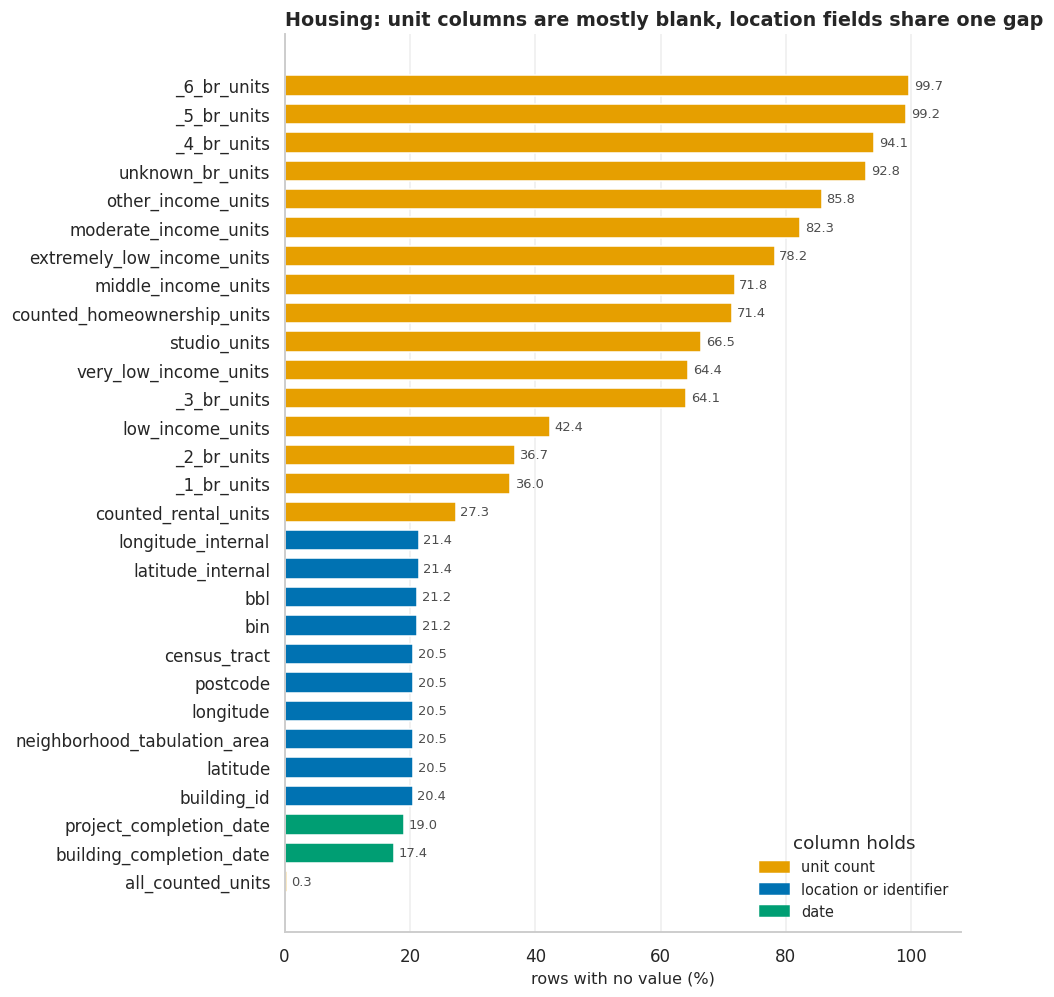

In [15]:
def housing_missing_groups(profile):
    """Label each column with a gap by the kind of information it holds."""
    gaps = profile.loc[profile["missing"] > 0, ["missing", "missing_pct"]].copy()
    gaps["kind"] = np.select(
        [gaps.index.isin(UNIT_COLUMNS), gaps.index.isin(HOUSING_DATE_COLUMNS)],
        ["unit count", "date"], default="location or identifier")
    return gaps.sort_values("missing_pct")


def plot_housing_missing(gaps):
    """Horizontal bars of missing share per housing column, coloured by kind of column."""
    kind_colors = {"unit count": PALETTE["placebo"], "location or identifier": PALETTE["housing"],
                   "date": PALETTE["after"]}
    fig, ax = plt.subplots(figsize=(9, 0.27 * len(gaps) + 1.4))
    bars = ax.barh(gaps.index, gaps["missing_pct"], color=gaps["kind"].map(kind_colors), height=0.72)
    ax.bar_label(bars, fmt="%.1f", padding=3, fontsize=8.5, color=PALETTE["neutral"])
    ax.set_xlim(0, 108)
    ax.grid(axis="y", visible=False)
    color_legend(ax, kind_colors, title="column holds", loc="lower right")
    finish(ax, "Housing: unit columns are mostly blank, location fields share one gap",
           "rows with no value (%)", "")
    plt.tight_layout()
    plt.show()


eda_housing_gaps = housing_missing_groups(eda_housing_profile)
plot_housing_missing(eda_housing_gaps)

In [16]:
def unit_blank_report(raw, view):
    """Check whether blank unit cells stand for zero: literal zeros, and totals after a zero fill."""
    filled = view[UNIT_COLUMNS].fillna(0)
    report = {
        "blank_cells": int(raw[UNIT_COLUMNS].isna().to_numpy().sum()),
        "literal_zeros": int((view[UNIT_COLUMNS] == 0).to_numpy().sum()),
        "cells": raw[UNIT_COLUMNS].size,
    }
    for name, columns in [("income", INCOME_UNIT_COLUMNS), ("bedroom", BEDROOM_UNIT_COLUMNS),
                          ("tenure", TENURE_UNIT_COLUMNS)]:
        report[f"{name}_sum_matches"] = int((filled[columns].sum(axis=1) == filled["all_counted_units"]).sum())
    report["counted_above_total"] = int((filled["all_counted_units"] > filled["total_units"]).sum())
    report["counted_below_total"] = int((filled["all_counted_units"] < filled["total_units"]).sum())
    report["counted_blank"] = int(view["all_counted_units"].isna().sum())
    return report


eda_units = unit_blank_report(raw_housing, eda_housing)
EDA_FACTS["unit_blank_cells"] = eda_units["blank_cells"]
say(f"Across the {len(UNIT_COLUMNS)} unit columns, **{eda_units['blank_cells']:,} of "
    f"{eda_units['cells']:,} cells are blank ({pct(eda_units['blank_cells'], eda_units['cells']):.1f}%) and "
    f"{eda_units['literal_zeros']} contain a written zero**. If each blank is read as zero, the six income "
    f"bands add up to `all_counted_units` in {eda_units['income_sum_matches']:,} of {len(raw_housing):,} rows, "
    f"the eight bedroom sizes in {eda_units['bedroom_sum_matches']:,} and rental plus homeownership in "
    f"{eda_units['tenure_sum_matches']:,}. `all_counted_units` is above `total_units` in "
    f"{eda_units['counted_above_total']} rows, below it in {eda_units['counted_below_total']:,} "
    f"(buildings that also hold units outside the programme) and blank in {eda_units['counted_blank']}.")

Across the 18 unit columns, **106,309 of 171,918 cells are blank (61.8%) and 0 contain a written zero**. If each blank is read as zero, the six income bands add up to `all_counted_units` in 9,551 of 9,551 rows, the eight bedroom sizes in 9,551 and rental plus homeownership in 9,551. `all_counted_units` is above `total_units` in 0 rows, below it in 2,781 (buildings that also hold units outside the programme) and blank in 29.

The unit columns are not missing in the usual sense. The source never writes a zero, so a
blank is the only way a zero can appear, and the totals confirm it: with blanks read as zero
the parts add up to the published total. Section 4 therefore fills these blanks with zero.
Treating them as unknown was the alternative, and it would be wrong twice over: it would
discard most rows from any analysis of income mix, and it would bias averages upward because
only non-zero values would be averaged.

The location columns are a different case. They show the same missing share, which suggests
one group of rows lacks all of them at once. The next chart checks that.

#### 3.1.4 The confidential rows

Some rows have the project name `CONFIDENTIAL` and a masked address. The heatmap compares
how often each location, identifier and date field is missing in those rows and in all the
others.

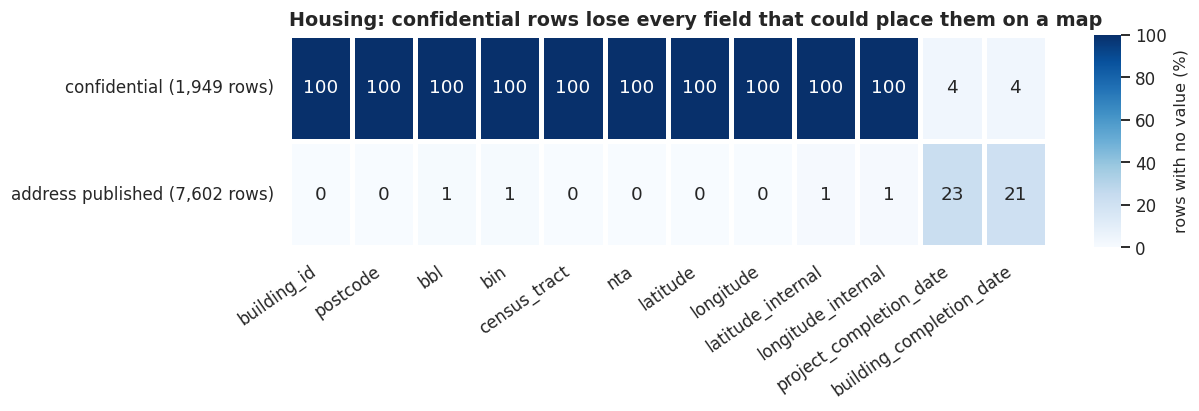

**1,949 rows (20.4%) are confidential.** 1,949 rows have the street name `----`. All 1,949 confidential rows still name a borough. They hold 2,806 of 445,588 units (**0.63%**), with a median of 1 unit per row against 20 elsewhere. By type, 1,203 are New Construction and 746 are Preservation. Outside this group, 9 rows with a published address have no coordinates.

In [17]:
def confidential_missing(raw, view):
    """Missing share (%) of each place and date column, split by confidential flag."""
    columns = HOUSING_PLACE_COLUMNS + ["project_completion_date", "building_completion_date"]
    missing = raw[columns].isna()
    table = missing.groupby(view["is_confidential"].to_numpy()).mean().mul(100)
    counts = view["is_confidential"].value_counts()
    table.index = [f"{'confidential' if flag else 'address published'} ({counts[flag]:,} rows)"
                   for flag in table.index]
    return table.sort_index(ascending=False)


def plot_confidential_missing(table):
    """Annotated heatmap: which fields disappear in the confidential rows."""
    fig, ax = plt.subplots(figsize=(11.5, 3.9))
    sns.heatmap(table, annot=True, fmt=".0f", cmap="Blues", vmin=0, vmax=100, linewidths=2,
                linecolor="white", cbar_kws={"label": "rows with no value (%)", "aspect": 8}, ax=ax)
    ax.set_xticklabels([label.get_text().replace("neighborhood_tabulation_area", "nta")
                        for label in ax.get_xticklabels()], rotation=35, ha="right")
    ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
    finish(ax, "Housing: confidential rows lose every field that could place them on a map", "", "")
    plt.tight_layout()
    plt.show()


def confidential_summary(raw, view):
    """Size of the confidential group in rows and in units, and how its address is masked."""
    hidden = view["is_confidential"]
    located = view["latitude"].notna() & view["longitude"].notna()
    return {
        "rows": int(hidden.sum()),
        "units": int(view.loc[hidden, "total_units"].sum()),
        "all_units": int(view["total_units"].sum()),
        "median_units": float(view.loc[hidden, "total_units"].median()),
        "median_units_other": float(view.loc[~hidden, "total_units"].median()),
        "masked_address": int(as_flags(raw["street_name"].str.strip() == WITHHELD_ADDRESS).sum()),
        "with_borough": int(raw.loc[hidden.to_numpy(), "borough"].notna().sum()),
        "other_unlocated": int((~hidden & ~located).sum()),
        "by_type": view.loc[hidden, "construction_type"].value_counts(),
    }


plot_confidential_missing(confidential_missing(raw_housing, eda_housing))
eda_confidential = confidential_summary(raw_housing, eda_housing)
EDA_FACTS["confidential_rows"] = eda_confidential["rows"]
EDA_FACTS["confidential_unit_pct"] = pct(eda_confidential["units"], eda_confidential["all_units"])
EDA_FACTS["other_unlocated"] = eda_confidential["other_unlocated"]
say(f"**{eda_confidential['rows']:,} rows ({pct(eda_confidential['rows'], len(raw_housing)):.1f}%) are "
    f"confidential.** {eda_confidential['masked_address']:,} rows have the street name `{WITHHELD_ADDRESS}`. "
    f"All {eda_confidential['with_borough']:,} confidential rows still name a borough. They hold "
    f"{eda_confidential['units']:,} of {eda_confidential['all_units']:,} units "
    f"(**{EDA_FACTS['confidential_unit_pct']:.2f}%**), with a median of "
    f"{eda_confidential['median_units']:.0f} unit per row against {eda_confidential['median_units_other']:.0f} "
    f"elsewhere. By type, "
    + join_and(f"{count:,} are {name}" for name, count in eda_confidential["by_type"].items())
    + f". Outside this group, "
    f"{eda_confidential['other_unlocated']} rows with a published address have no coordinates.")

The gap in the location columns is one block of rows, not scattered omissions. In a
confidential row the building identifier, ZIP code, tax lot, census tract and both pairs of
coordinates are all absent, while borough and the dates survive. The second pair of
coordinates (`latitude_internal`, `longitude_internal`) is missing in the same rows, so it
cannot serve as a fallback.

This matters for integration because both join levels need a place. A confidential row has
no ZIP code for the ZIP by year panel and no point for the distance join, and nothing else in
the row narrows its position below the borough. Imputing a location, for example the borough
centroid, was considered and rejected: it would stack all of these rows on five points and
invent crashes "near" buildings that are somewhere else. The rows are therefore flagged and
kept for borough totals only. The next chart shows how little housing that sets aside.

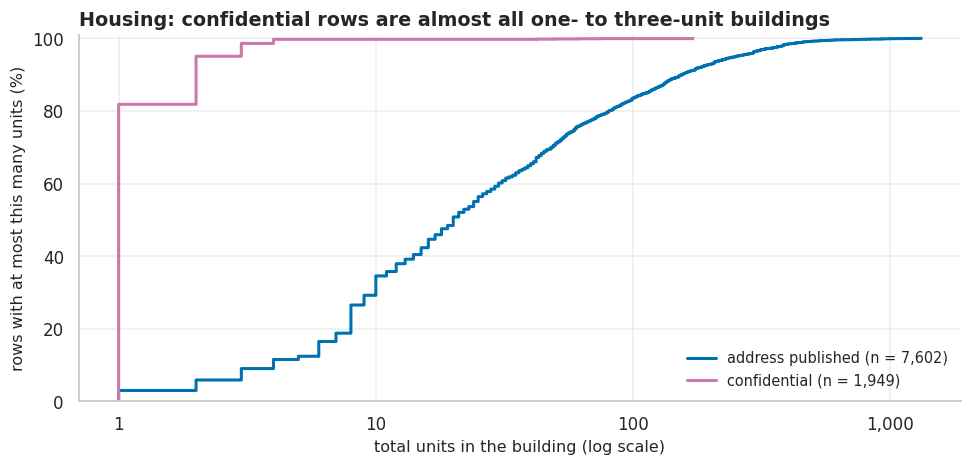

In [18]:
def plot_confidential_sizes(view):
    """Cumulative distribution of building size for confidential and published rows (log x)."""
    fig, ax = plt.subplots(figsize=(9, 4.4))
    groups = [("address published", ~view["is_confidential"], PALETTE["housing"]),
              ("confidential", view["is_confidential"], PALETTE["accent"])]
    for label, mask, color in groups:
        units = np.sort(view.loc[mask, "total_units"].dropna().to_numpy())
        share = 100 * np.arange(1, len(units) + 1) / len(units)
        ax.step(units, share, where="post", color=color, linewidth=2, label=f"{label} (n = {len(units):,})")
    ax.set_xscale("log")
    thousands(ax, axis="x")
    ax.set_ylim(0, 101)
    ax.legend(loc="lower right")
    finish(ax, "Housing: confidential rows are almost all one- to three-unit buildings",
           "total units in the building (log scale)", "rows with at most this many units (%)")
    plt.tight_layout()
    plt.show()


plot_confidential_sizes(eda_housing)

The confidential curve rises almost vertically at the left edge: most of these rows are a
single home, while buildings with a published address range from single homes to very large
towers. Setting the confidential rows aside from the location joins costs a large share of
the rows but a very small share of the units, so the located buildings still describe nearly
all of the housing the programme produced.

#### 3.1.5 Building size and its outliers

`total_units` is the housing variable several research questions rely on, so its shape
matters. On a plain axis almost every building would fall into the first bar and the tail
would be invisible, so the histogram uses a log axis. It marks the median and the usual upper
outlier fence (third quartile plus 1.5 times the interquartile range).

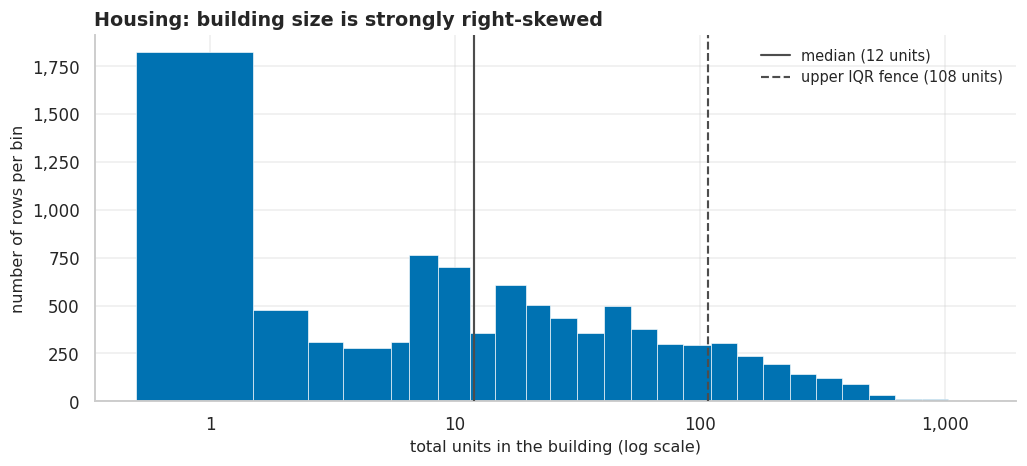

Half of the 9,551 rows have at most **12 units**, the mean is 46.7, the 99th percentile 430 and the maximum 1,320 (skewness 4.6). The IQR fence lies at 108 units and would flag **1,171 rows (12.3%)**. The largest tenth of the rows holds 58% of all units.

,project_name,borough,reporting_construction_type,total_units,all_counted_units
226,25 WATER STREET,Manhattan,New Construction,1320,330
4865,605 WEST 42ND ST,Manhattan,New Construction,1175,235
4866,605 WEST 42ND STREET PHASE II,Manhattan,New Construction,1175,59
5196,5 POINTZ LIC,Queens,New Construction,1122,337
6729,12 ROCKWELL PLACE,Brooklyn,New Construction,1046,227


In [19]:
def size_summary(view):
    """Quartiles, Tukey upper fence and tail counts of total_units."""
    units = view["total_units"].dropna()
    first_quartile, median, third_quartile = units.quantile([0.25, 0.5, 0.75])
    fence = tukey_upper_fence(units)
    return {"n": len(units), "median": median, "mean": units.mean(), "q1": first_quartile,
            "q3": third_quartile, "fence": fence, "above_fence": int((units > fence).sum()),
            "max": units.max(), "p99": units.quantile(0.99), "skew": stats.skew(units),
            "top_decile_unit_pct": pct(units[units >= units.quantile(0.9)].sum(), units.sum())}


def plot_building_sizes(view, summary):
    """Histogram of total_units on a log axis with the median and the outlier fence."""
    units = view["total_units"].dropna()
    fig, ax = plt.subplots(figsize=(9.5, 4.4))
    ax.hist(units, bins=integer_log_bins(summary["max"]), color=PALETTE["housing"], edgecolor="white",
            linewidth=0.4)
    ax.set_xscale("log")
    ax.axvline(summary["median"], color=PALETTE["neutral"], linestyle="-", linewidth=1.4, zorder=5,
               label=f"median ({summary['median']:.0f} units)")
    ax.axvline(summary["fence"], color=PALETTE["neutral"], linestyle="--", linewidth=1.4, zorder=5,
               label=f"upper IQR fence ({summary['fence']:.0f} units)")
    ax.legend(loc="upper right")
    thousands(ax, axis="x")
    thousands(ax)
    finish(ax, "Housing: building size is strongly right-skewed", "total units in the building (log scale)",
           "number of rows per bin")
    plt.tight_layout()
    plt.show()


eda_sizes = size_summary(eda_housing)
EDA_FACTS["size_above_fence"] = eda_sizes["above_fence"]
EDA_FACTS["size_above_fence_pct"] = pct(eda_sizes["above_fence"], eda_sizes["n"])
plot_building_sizes(eda_housing, eda_sizes)
say(f"Half of the {eda_sizes['n']:,} rows have at most **{eda_sizes['median']:.0f} units**, the mean is "
    f"{eda_sizes['mean']:.1f}, the 99th percentile {eda_sizes['p99']:.0f} and the maximum "
    f"{eda_sizes['max']:,.0f} (skewness {eda_sizes['skew']:.1f}). The IQR fence lies at "
    f"{eda_sizes['fence']:.0f} units and would flag **{eda_sizes['above_fence']:,} rows "
    f"({EDA_FACTS['size_above_fence_pct']:.1f}%)**. The largest tenth of the rows holds "
    f"{eda_sizes['top_decile_unit_pct']:.0f}% of all units.")
display(raw_housing.loc[eda_housing["total_units"].nlargest(5).index,
                        ["project_name", "borough", "reporting_construction_type", "total_units",
                         "all_counted_units"]])

The histogram shows two groups: a spike of single-unit rows, and a broad spread of apartment
buildings from small walk-ups to towers. The IQR fence falls inside the second group, so it
flags ordinary apartment buildings, not errors. The largest rows are real, named developments
in which only part of the building counts towards the programme.

Section 4 therefore keeps every row, uses medians, log scales or size bands, and flags the
very large buildings so an analysis can be repeated without them. Dropping rows above the
fence was rejected because it would remove exactly the buildings that add the most residents
to a street, and the large majority of units with them.

#### 3.1.6 Categories and their spellings

The table counts every value of the categorical columns exactly as spelled, including the
split by confidential flag for borough. Variants such as trailing spaces or mixed case would
appear as separate rows.

In [20]:
def housing_category_counts(raw, columns):
    """Value counts of several raw categorical columns stacked into one table."""
    parts = [raw[column].value_counts(dropna=False).rename("rows").rename_axis("value").reset_index()
             .assign(column=column) for column in columns]
    table = pd.concat(parts, ignore_index=True)
    table["share_pct"] = 100 * table["rows"] / len(raw)
    return table.set_index(["column", "value"])


display(housing_category_counts(raw_housing, ["reporting_construction_type", "extended_affordability_status",
                                               "prevailing_wage_status"]).round(1))
display(pd.crosstab(raw_housing["borough"].astype(object),
                    [eda_housing["construction_type"], eda_housing["is_confidential"].map(
                        {True: "confidential", False: "published"})], margins=True))
say(f"`community_board` has {raw_housing['community_board'].nunique()} distinct values in the form "
    f"`{raw_housing['community_board'].iloc[0]}`, and `borough` has {raw_housing['borough'].nunique()} "
    f"values: {join_and(sorted(raw_housing['borough'].dropna().unique()))}.")

rows  share_pct
column                        value                               
reporting_construction_type   Preservation         4785     50.100
                              New Construction     4766     49.900
extended_affordability_status No                   8125     85.100
                              Yes                  1426     14.900
prevailing_wage_status        Non Prevailing Wage  9392     98.300
                              Prevailing Wage       159      1.700

construction_type New Construction           Preservation             All
is_confidential       confidential published confidential published      
borough                                                                  
Bronx                          272      1005          168      1185  2630
Brooklyn                       268      1768          287      1326  3649
Manhattan                       77       287            9      1112  1485
Queens                         328       468          224       322  1342
Staten Island                  258        35           58        94   445
All                           1203      3563          746      4039  9551

`community_board` has 59 distinct values in the form `MN-11`, and `borough` has 5 values: Bronx, Brooklyn, Manhattan, Queens and Staten Island.

The categories are clean: every value has a single spelling and none is blank. New
construction and preservation are close to evenly split, which is convenient because several
research questions compare the two. The cross-tabulation also shows that the confidential
rows are not spread evenly over the boroughs, so borough totals that left them out would
understate some boroughs far more than others. Borough is written in title case here;
Section 3.2.7 shows that the crash table writes it differently.

#### 3.1.7 Time: when buildings were completed and how long they took

Completion is the event the before and after comparisons hang on, so its distribution over
the years decides how many buildings each comparison can use. The completion date used here
is the building date, with the project date standing in where the building date is blank.

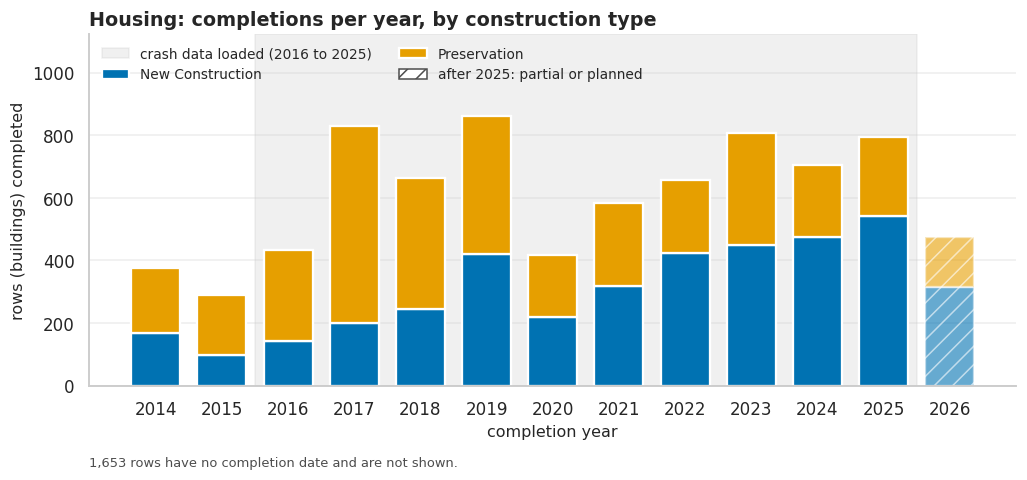

completion_year,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
construction_type,,,,,,,,,,,,,
New Construction,169,98,144,200,244,420,220,320,424,450,476,542,314
Preservation,207,192,288,630,421,443,199,264,233,356,230,252,162
total,376,290,432,830,665,863,419,584,657,806,706,794,476


**1,653 rows (17.3%) have no completion date at all.** The project date fills in for 13 rows whose building date is blank. 476 rows are completed after 2025, and 666 before 2016.

In [21]:
def completion_year_counts(view):
    """Rows per completion year and construction type; rows without any completion date apart."""
    years = view["completion_date"].dt.year
    table = (view.assign(completion_year=years).dropna(subset=["completion_year"])
             .groupby(["completion_year", "construction_type"]).size().unstack(fill_value=0))
    table.index = table.index.astype(int)
    return table, int(years.isna().sum())


def plot_completion_years(table, no_date_rows):
    """Stacked bars of completed rows per year by construction type."""
    fig, ax = plt.subplots(figsize=(9.5, 4.6))
    bottom = np.zeros(len(table))
    for construction_type in CONSTRUCTION_COLORS:
        bars = ax.bar(table.index, table[construction_type], bottom=bottom, width=0.74, edgecolor="white",
                      linewidth=1.5, color=CONSTRUCTION_COLORS[construction_type], label=construction_type)
        for bar, year in zip(bars, table.index):
            if year > YEAR_END:      # years after the crash window hold planned or very recent dates
                bar.set_hatch("//")
                bar.set_alpha(0.6)
        bottom += table[construction_type].to_numpy()
    ax.axvspan(YEAR_START - 0.5, YEAR_END + 0.5, color=PALETTE["before"], alpha=0.18, zorder=0,
               label=f"crash data loaded ({YEAR_START} to {YEAR_END})")
    ax.set_xticks(table.index)
    ax.grid(axis="x", visible=False)
    handles, _ = ax.get_legend_handles_labels()
    handles.append(mpl.patches.Patch(facecolor="white", edgecolor=PALETTE["neutral"], hatch="//",
                                     label=f"after {YEAR_END}: partial or planned"))
    ax.legend(handles=handles, loc="upper left", ncol=2, fontsize=9)
    ax.set_ylim(0, bottom.max() * 1.3)
    finish(ax, "Housing: completions per year, by construction type", "completion year",
           "rows (buildings) completed",
           note=f"{no_date_rows:,} rows have no completion date and are not shown.")
    plt.tight_layout()
    plt.show()


eda_completions, eda_no_completion = completion_year_counts(eda_housing)
EDA_FACTS["no_completion_rows"] = eda_no_completion
plot_completion_years(eda_completions, eda_no_completion)
display(eda_completions.assign(total=eda_completions.sum(axis=1)).T)
say(f"**{eda_no_completion:,} rows ({pct(eda_no_completion, len(eda_housing)):.1f}%) have no completion "
    f"date at all.** The project date fills in for "
    f"{int((eda_housing['building_completion_date'].isna() & eda_housing['project_completion_date'].notna()).sum())} "
    f"rows whose building date is blank. "
    f"{int(eda_completions.loc[eda_completions.index > YEAR_END].to_numpy().sum()):,} rows are completed after "
    f"{YEAR_END}, and {int(eda_completions.loc[eda_completions.index < YEAR_START].to_numpy().sum()):,} "
    f"before {YEAR_START}.")

Every year of the crash window has many completions, with both construction types present
in each, so before and after comparisons are not carried by one unusual cohort. The mix
shifts over time, from mostly preservation in the early years to mostly new construction in
the later ones, which is a reason to compare the two types within the same calendar years.
The dip in 2020 coincides with the pandemic. Rows without a completion date are projects still
under way. They are not errors, and Section 4 keeps them flagged as not yet completed. They
cannot enter a before and after comparison, and dropping them outright was rejected because
buildings that are not finished yet are useful as a comparison group.

Buildings completed in the first or last years of the window have little crash history on
one side, which limits the cohorts with complete windows to the middle years named in
Section 2.5.

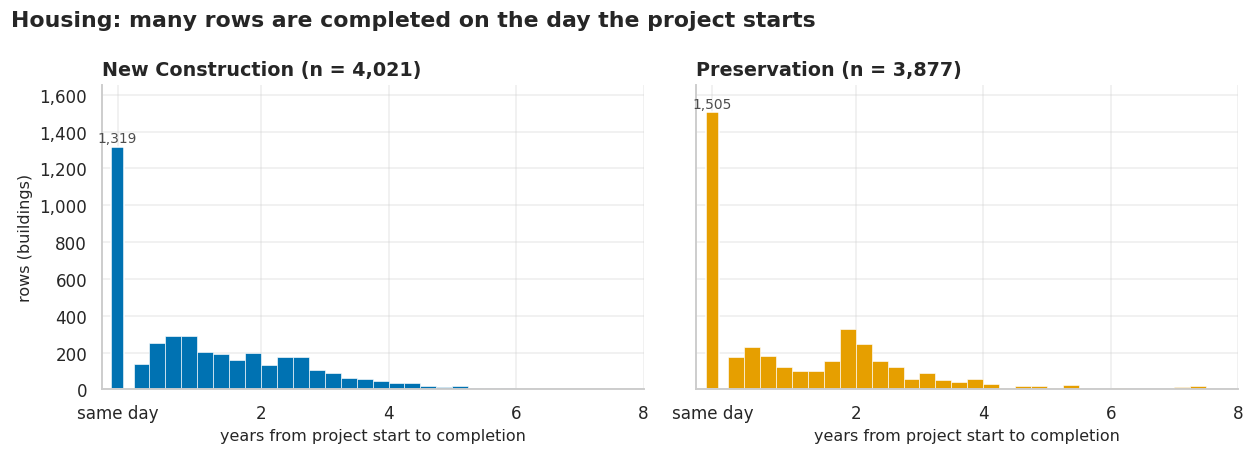

Of 7,898 completed rows, **2,824 (35.8%) have a completion date equal to the start date** and 21 have a completion date before the start date. 7 took longer than 8 years and fall outside the chart. Median duration when it is above zero: New Construction 1.5 years, Preservation 1.8 years.

In [22]:
def construction_durations(view):
    """Years between project start and completion, with counts of the odd cases."""
    done = view.dropna(subset=["completion_date", "project_start_date"])
    years = (done["completion_date"] - done["project_start_date"]).dt.days / DAYS_PER_YEAR
    return pd.DataFrame({"years": years, "construction_type": done["construction_type"]})


def plot_durations(durations):
    """Small multiples: time from project start to completion for each construction type.

    Rows completed on their start date get a bar of their own on the left, so that the height of
    that bar is exactly the count in the text. Rows that finish before they start are not drawn.
    """
    bins = np.arange(0, DURATION_MAX_YEARS + DURATION_BIN_YEARS, DURATION_BIN_YEARS)
    same_day_x = -DURATION_BIN_YEARS
    fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2), sharey=True)
    for ax, construction_type in zip(axes, CONSTRUCTION_COLORS):
        years = durations.loc[durations["construction_type"] == construction_type, "years"]
        color = CONSTRUCTION_COLORS[construction_type]
        ax.hist(years[years > 0], bins=bins, color=color, edgecolor="white", linewidth=0.4)
        same_day = int((years == 0).sum())
        ax.bar(same_day_x, same_day, width=DURATION_BIN_YEARS * 0.8, color=color, edgecolor="white")
        ax.annotate(f"{same_day:,}", xy=(same_day_x, same_day), xytext=(0, 3), textcoords="offset points",
                    ha="center", fontsize=9, color=PALETTE["neutral"])
        ticks = [same_day_x, *range(2, DURATION_MAX_YEARS + 1, 2)]
        ax.set_xticks(ticks)
        ax.set_xticklabels(["same day"] + [str(tick) for tick in ticks[1:]])
        ax.set_xlim(same_day_x - DURATION_BIN_YEARS, DURATION_MAX_YEARS)
        ax.margins(y=0.1)
        thousands(ax)
        finish(ax, f"{construction_type} (n = {len(years):,})", "years from project start to completion",
               "rows (buildings)" if ax is axes[0] else "")
    fig.suptitle("Housing: many rows are completed on the day the project starts", x=0.01, ha="left",
                 fontweight="bold")
    plt.tight_layout()
    plt.show()


eda_durations = construction_durations(eda_housing)
EDA_FACTS["completion_before_start"] = int((eda_durations["years"] < 0).sum())
EDA_FACTS["completion_on_start"] = int((eda_durations["years"] == 0).sum())
plot_durations(eda_durations)
say(f"Of {len(eda_durations):,} completed rows, **{EDA_FACTS['completion_on_start']:,} "
    f"({pct(EDA_FACTS['completion_on_start'], len(eda_durations)):.1f}%) have a completion date equal to "
    f"the start date** and {EDA_FACTS['completion_before_start']} have a completion date before the start "
    f"date. {int((eda_durations['years'] > DURATION_MAX_YEARS).sum())} took longer than {DURATION_MAX_YEARS} "
    f"years and fall outside the chart. Median duration when it is above zero: "
    + ", ".join(f"{name} {group.loc[group['years'] > 0, 'years'].median():.1f} years"
                for name, group in eda_durations.groupby("construction_type")) + ".")

The spike at zero is the most notable feature. For those rows the "project start" is the day the
financing closed on a building that was already standing or already finished, so the table
shows no construction period. It is common in both types, not only in preservation. Rows
where completion precedes the start are date-entry inconsistencies and are few.

For the analysis this means the start date is not a dependable marker of when building work
began, so the before and after comparisons use the completion date alone. Section 4 flags
rows whose completion precedes their start and leaves the dates as published. The two dates
are not swapped, because there is no way to know which of them is wrong.

#### 3.1.8 Duplicates and the grain of the table

Before any join the grain has to be known: what one row stands for and which columns identify
it. The check below looks for full-row duplicates and tests two candidate keys.

In [23]:
def housing_key_checks(raw, view):
    """Duplicate counts for the full row and for the candidate keys, among rows with a building id."""
    with_id = raw.loc[raw["building_id"].notna()]
    repeated_buildings = with_id["building_id"].value_counts()
    repeated_buildings = repeated_buildings[repeated_buildings > 1]
    extra_rows = with_id.loc[with_id["building_id"].isin(repeated_buildings.index)]
    return {
        "full_row_duplicates": int(raw.duplicated().sum()),
        "rows_with_id": len(with_id),
        "pair_duplicates": int(with_id.duplicated(["project_id", "building_id"]).sum()),
        "repeated_buildings": len(repeated_buildings),
        "extra_rows": int(repeated_buildings.sum() - len(repeated_buildings)),
        "distinct_start_dates_pct": pct(
            int((extra_rows.groupby("building_id")["project_start_date"].nunique() > 1).sum()),
            len(repeated_buildings)),
        "projects": raw["project_id"].nunique(),
        "max_buildings_per_project": int(raw["project_id"].value_counts().max()),
    }


eda_keys = housing_key_checks(raw_housing, eda_housing)
EDA_FACTS["repeated_building_rows"] = eda_keys["extra_rows"]
say(f"There are **{eda_keys['full_row_duplicates']} full-row duplicates**. Among the "
    f"{eda_keys['rows_with_id']:,} rows with a `building_id`, the pair (`project_id`, `building_id`) repeats "
    f"**{eda_keys['pair_duplicates']} times**, while `building_id` alone repeats on "
    f"{eda_keys['repeated_buildings']} buildings ({eda_keys['extra_rows']} extra rows). In "
    f"{eda_keys['distinct_start_dates_pct']:.0f}% of those buildings the repeated rows have different project "
    f"start dates. The table covers {eda_keys['projects']:,} projects, the largest with "
    f"{eda_keys['max_buildings_per_project']} buildings.")

There are **0 full-row duplicates**. Among the 7,602 rows with a `building_id`, the pair (`project_id`, `building_id`) repeats **0 times**, while `building_id` alone repeats on 123 buildings (124 extra rows). In 97% of those buildings the repeated rows have different project start dates. The table covers 5,928 projects, the largest with 114 buildings.

One row is one building within one project. A building that appears twice was financed twice,
usually years apart, for example built under one project and preserved under a later one.
Those are separate events, so the key for Section 4 is the pair of project and building, and
de-duplicating on the building alone would delete real events. The confidential rows have no
building identifier, so they can only be told apart by their row position and are counted,
not keyed.

#### 3.1.9 Where the buildings are

A plain scatter of longitude against latitude, coloured by the borough written in the row.
It checks two things at once: that the coordinates fall inside the city, and that the borough
label agrees with the position.

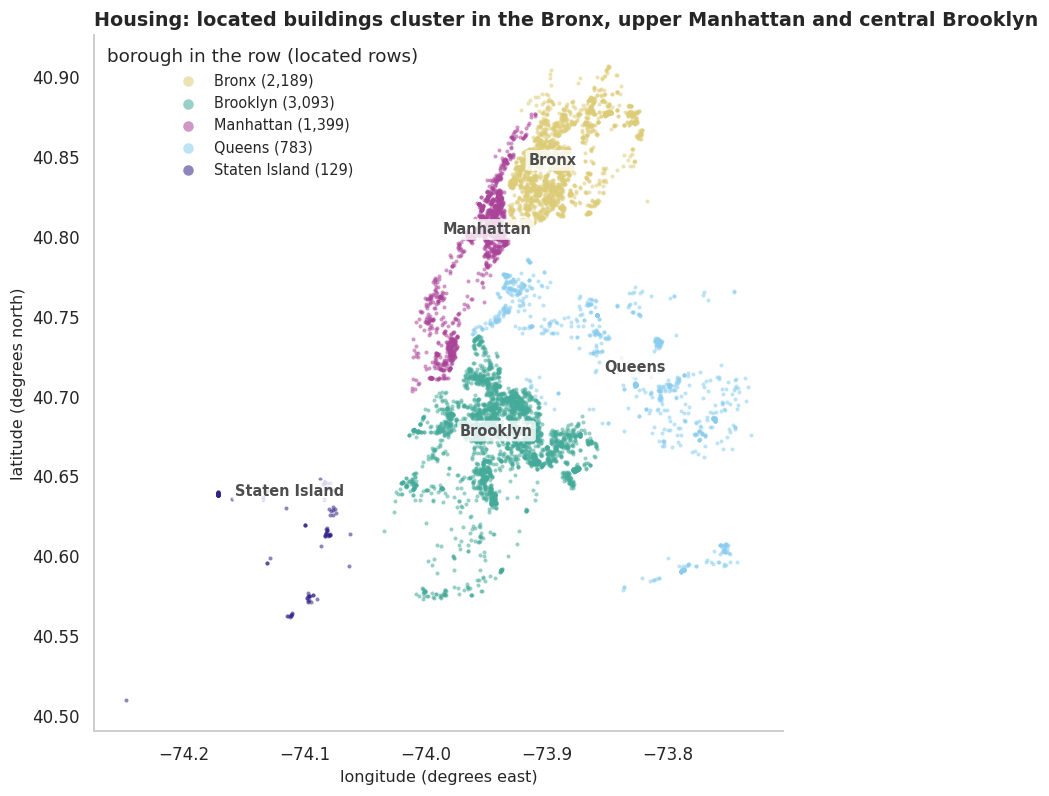

**7,593 of 9,551 rows have coordinates.** 0 fall outside the bounding box of the city and 0 sit at zero. The located rows cover 158 ZIP codes.

In [24]:
def housing_coordinate_checks(view):
    """Count located rows and rows whose coordinates fall outside the city's bounding box."""
    located = view.dropna(subset=["latitude", "longitude"])
    inside = (located["latitude"].between(*NYC_BOUNDS["lat"])
              & located["longitude"].between(*NYC_BOUNDS["lon"]))
    zero = (located["latitude"] == 0) | (located["longitude"] == 0)
    return located, int((~inside).sum()), int(zero.sum())


def plot_housing_map(located):
    """Scatter of building coordinates coloured by the borough named in the row."""
    fig, ax = plt.subplots(figsize=(8.2, 7.4))
    for borough in BOROUGHS:
        points = located.loc[located["borough"] == borough]
        ax.scatter(points["longitude"], points["latitude"], s=7, alpha=0.55, linewidths=0,
                   color=BOROUGH_COLORS[borough], label=f"{borough} ({len(points):,})")
        ax.annotate(borough, xy=(points["longitude"].median(), points["latitude"].median()),
                    ha="center", fontsize=9.5, fontweight="bold", color=PALETTE["neutral"],
                    bbox={"boxstyle": "round,pad=0.2", "facecolor": "white", "edgecolor": "none", "alpha": 0.8})
    map_axes(ax)
    ax.legend(title="borough in the row (located rows)", loc="upper left", markerscale=2.6)
    finish(ax, "Housing: located buildings cluster in the Bronx, upper Manhattan and central Brooklyn",
           "longitude (degrees east)", "latitude (degrees north)")
    plt.tight_layout()
    plt.show()


eda_housing_located, eda_housing_outside, eda_housing_zero = housing_coordinate_checks(eda_housing)
plot_housing_map(eda_housing_located)
say(f"**{len(eda_housing_located):,} of {len(eda_housing):,} rows have coordinates.** "
    f"{eda_housing_outside} fall outside the bounding box of the city and {eda_housing_zero} sit at zero. "
    f"The located rows cover {eda_housing_located['postcode'].nunique()} ZIP codes.")

The coordinates are trustworthy: none falls outside the city and the colours form five clean
regions with no stray points, so borough and position agree. The spatial pattern is far from
even. Buildings concentrate in the South Bronx, Harlem and East Harlem, and central and
eastern Brooklyn, with little in Staten Island and most of Queens. Any comparison of streets
near affordable housing with "other" streets therefore has to compare within a borough,
since the places where this housing is built are not a random sample of the city.

### 3.2 Crashes: Motor Vehicle Collisions

#### 3.2.1 Shape, types and a first look

The same profile for the crash table. With this many rows the padding and length checks matter
more than for housing, because these fields were typed by many different officers over ten
years.

In [25]:
def crash_view(raw):
    """Compact numeric and datetime view of the raw crash table for exploration only."""
    view = pd.DataFrame(index=raw.index)
    crash_date = to_date(raw["crash_date"])
    assert crash_date.notna().all(), "a crash date does not follow the API date format"
    view["crash_date"] = crash_date
    view["year"] = crash_date.dt.year.astype("int16")
    view["month"] = crash_date.dt.month.astype("int8")
    view["weekday"] = crash_date.dt.dayofweek.astype("int8")
    # crash_time is written H:MM without a leading zero, so the hour is whatever precedes the colon.
    view["hour"] = parse_hour(raw["crash_time"])[0].astype("float32")
    for column in CRASH_CASUALTY_COLUMNS:
        view[column] = to_number(raw[column], strict=False).astype("float32")
    view["latitude"] = to_number(raw["latitude"], strict=False)
    view["longitude"] = to_number(raw["longitude"], strict=False)
    view["zip_missing"] = raw["zip_code"].isna().to_numpy()
    view["borough_missing"] = raw["borough"].isna().to_numpy()
    view["coordinate_status"] = coordinate_status(view["latitude"], view["longitude"])
    # An injury crash has at least one person injured or killed in any of the eight casualty columns.
    view["is_injury_crash"] = view[CRASH_CASUALTY_COLUMNS].fillna(0).sum(axis=1).gt(0).to_numpy()
    return view


def coordinate_status(latitude, longitude):
    """Classify each coordinate pair as missing, at (0, 0), outside the city box or usable."""
    missing = latitude.isna() | longitude.isna()
    at_zero = (latitude == 0) & (longitude == 0)
    in_box = latitude.between(*NYC_BOUNDS["lat"]) & longitude.between(*NYC_BOUNDS["lon"])
    status = np.select([missing, at_zero, ~in_box], ["missing", "at (0, 0)", "outside the city box"],
                       default="usable")
    return pd.Categorical(status, categories=["usable", "missing", "at (0, 0)", "outside the city box"])


eda_crashes = crash_view(raw_crashes)
eda_crash_profile = raw_profile(raw_crashes)
say(f"The crash table has **{raw_crashes.shape[0]:,} rows and {raw_crashes.shape[1]} columns**, all loaded "
    f"as `{raw_crashes.dtypes.astype(str).unique()[0]}`. Crash dates run from "
    f"{eda_crashes['crash_date'].min():%d %B %Y} to {eda_crashes['crash_date'].max():%d %B %Y}, and "
    f"`collision_id` has {eda_crash_profile.loc['collision_id', 'distinct']:,} distinct values.")
with pd.option_context("display.max_colwidth", 34):
    display(eda_crash_profile.round(2))
display(raw_crashes.head(3).T)

The crash table has **1,504,722 rows and 19 columns**, all loaded as `string`. Crash dates run from 01 January 2016 to 31 December 2025, and `collision_id` has 1,504,722 distinct values.

,dtype as loaded,missing,missing_pct,distinct,min length,max length,padded with spaces,example
column,,,,,,,,
collision_id,string,0,0.000,1504722,7,7,0,3363355
crash_date,string,0,0.000,3653,23,23,0,2016-01-01T00:00:00.000
crash_time,string,0,0.000,1440,4,5,0,1:00
borough,string,508028,33.760,5,5,13,0,MANHATTAN
zip_code,string,508284,33.780,233,5,5,0,10013
latitude,string,125582,8.350,159500,4,10,0,40.7203179
longitude,string,125582,8.350,111767,3,12,0,-74.0121683
on_street_name,string,379864,25.240,21643,2,32,791601,WEST STREET
number_of_persons_injured,string,18,0.000,29,1,2,0,0


,0,1,2
collision_id,3363355,3363356,3363357
crash_date,2016-01-01T00:00:00.000,2016-01-01T00:00:00.000,2016-01-01T00:00:00.000
crash_time,1:00,5:09,11:30
borough,MANHATTAN,<NA>,MANHATTAN
zip_code,10013,<NA>,10013
latitude,40.7203179,<NA>,40.7256734
longitude,-74.0121683,<NA>,-74.0057798
on_street_name,WEST STREET,AVENUE OF THE AMERICAS,VARICK STREET
number_of_persons_injured,0,0,2
number_of_persons_killed,0,0,0


In [26]:
def crash_text_checks(raw, view):
    """Format findings in the raw crash text: time layout, padding, unconverted numbers."""
    time_lengths = raw["crash_time"].str.len().value_counts()
    non_numeric = {column: int((raw[column].notna() & view[column].isna()).sum())
                   for column in CRASH_CASUALTY_COLUMNS + ["latitude", "longitude"]}
    return {
        "time_unparsed": int(view["hour"].isna().sum()),
        "time_short": int(time_lengths.get(4, 0)),
        "time_midnight": int(as_flags(raw["crash_time"] == "0:00").sum()),
        "non_numeric": sum(non_numeric.values()),
        "casualty_missing": int(raw[CRASH_CASUALTY_COLUMNS].isna().to_numpy().sum()),
        "negative_counts": int((view[CRASH_CASUALTY_COLUMNS] < 0).to_numpy().sum()),
    }


eda_crash_text = crash_text_checks(raw_crashes, eda_crashes)
EDA_FACTS["street_padded"] = int(eda_crash_profile.loc["on_street_name", "padded with spaces"])
EDA_FACTS["time_short"] = eda_crash_text["time_short"]
say(f"`crash_time` has no leading zero in **{eda_crash_text['time_short']:,} rows "
    f"({pct(eda_crash_text['time_short'], len(raw_crashes)):.0f}%)**, for example `{raw_crashes['crash_time'].iloc[0]}`, "
    f"and {eda_crash_text['time_unparsed']} values do not fit the hour and minute layout. "
    f"{eda_crash_text['time_midnight']:,} crashes are timed at exactly midnight. `on_street_name` is padded with "
    f"spaces in **{EDA_FACTS['street_padded']:,} rows**. The casualty and coordinate columns contain "
    f"{eda_crash_text['non_numeric']} values that are not numbers, {eda_crash_text['casualty_missing']:,} "
    f"blank casualty cells and {eda_crash_text['negative_counts']} negative counts.")

`crash_time` has no leading zero in **417,263 rows (28%)**, for example `1:00`, and 0 values do not fit the hour and minute layout. 23,717 crashes are timed at exactly midnight. `on_street_name` is padded with spaces in **791,601 rows**. The casualty and coordinate columns contain 0 values that are not numbers, 54 blank casualty cells and 0 negative counts.

`collision_id` is unique, so one row is one collision and the table has a ready key. The
numeric fields convert without loss, apart from a handful of blank totals that Section 3.2.9
comes back to. The time is written without a leading zero, so it cannot be sorted or sliced
as text and Section 4 parses it into an hour. Street names carry trailing spaces, so the same
street could count as different values if compared as loaded.
The analysis locates crashes by coordinates and ZIP code and never by street name, so that
column is not carried forward.

#### 3.2.2 Descriptive statistics

Summary statistics of the eight casualty columns and the coordinates, over all loaded rows.

In [27]:
display(describe_table(eda_crashes[CRASH_CASUALTY_COLUMNS + ["latitude", "longitude"]], [0.5, 0.9, 0.99, 0.999]))

,rows with a value,mean,std,min,50%,90%,99%,99.9%,max
number_of_persons_injured,1504704,0.370,0.740,0.000,0.000,1.000,3.000,6.000,40.000
number_of_persons_killed,1504686,0.000,0.040,0.000,0.000,0.000,0.000,1.000,8.000
number_of_pedestrians_injured,1504722,0.060,0.260,0.000,0.000,0.000,1.000,2.000,27.000
number_of_pedestrians_killed,1504722,0.000,0.030,0.000,0.000,0.000,0.000,0.000,6.000
number_of_cyclist_injured,1504722,0.030,0.180,0.000,0.000,0.000,1.000,1.000,3.000
number_of_cyclist_killed,1504722,0.000,0.010,0.000,0.000,0.000,0.000,0.000,2.000
number_of_motorist_injured,1504722,0.260,0.700,0.000,0.000,1.000,3.000,6.000,40.000
number_of_motorist_killed,1504722,0.000,0.030,0.000,0.000,0.000,0.000,0.000,5.000
latitude,1379140,40.520,2.850,0.000,40.720,40.840,40.890,40.900,43.340
longitude,1379140,-73.560,5.290,-201.360,-73.920,-73.800,-73.730,0.000,0.000


The casualty counts are zero at the median and still small at the 99th percentile, with
maxima far above that, which is the shape of rare-event data. The coordinate rows give away
a problem before any map is drawn: the minimum latitude and the maximum longitude are zero,
values that lie on the equator off the coast of Africa and not in New York.

#### 3.2.3 Missing values that travel together

The table gives the missing share of every crash column. The second table counts the most
common combinations of four gaps (ZIP code, borough, usable coordinates and street name),
because whether a crash can be placed depends on the combination, not on any single column.

In [28]:
def crash_missing_patterns(raw, view):
    """Share of crashes in each combination of missing ZIP, borough, coordinates and street."""
    flags = pd.DataFrame({
        "ZIP code": np.where(view["zip_missing"], "missing", "present"),
        "borough": np.where(view["borough_missing"], "missing", "present"),
        "coordinates": np.where(view["coordinate_status"] == "usable", "usable", "not usable"),
        "on_street_name": np.where(raw["on_street_name"].isna().to_numpy(), "missing", "present"),
    })
    patterns = flags.value_counts().rename("crashes").reset_index()
    patterns["share_pct"] = 100 * patterns["crashes"] / len(view)
    return patterns


display(missing_table(raw_crashes).query("missing > 0").round(2))
eda_patterns = crash_missing_patterns(raw_crashes, eda_crashes)
display(eda_patterns.round(2))

eda_zip_only = int((eda_crashes["zip_missing"] & ~eda_crashes["borough_missing"]).sum())
eda_borough_only = int((~eda_crashes["zip_missing"] & eda_crashes["borough_missing"]).sum())
eda_zip_missing = int(eda_crashes["zip_missing"].sum())
eda_recoverable = int((eda_crashes["zip_missing"] & (eda_crashes["coordinate_status"] == "usable")).sum())
EDA_FACTS["zip_missing"] = eda_zip_missing
EDA_FACTS["zip_recoverable"] = eda_recoverable
say(f"**{eda_zip_missing:,} crashes ({pct(eda_zip_missing, len(eda_crashes)):.1f}%) have no ZIP code.** "
    f"Borough is missing in the same rows: only {eda_zip_only:,} crashes have a borough without a ZIP code "
    f"and {eda_borough_only:,} a ZIP code without a borough. Of the crashes without a ZIP code, "
    f"**{eda_recoverable:,} ({pct(eda_recoverable, eda_zip_missing):.1f}%) have usable coordinates**, and "
    f"{eda_zip_missing - eda_recoverable:,} have neither.")

,missing,missing_pct,dtype
zip_code,508284,33.780,string
borough,508028,33.760,string
on_street_name,379864,25.240,string
contributing_factor_vehicle_2,272828,18.130,string
longitude,125582,8.350,string
latitude,125582,8.350,string
vehicle_type_code1,15459,1.030,string
contributing_factor_vehicle_1,6442,0.430,string
number_of_persons_killed,36,0.000,string
number_of_persons_injured,18,0.000,string


,ZIP code,borough,coordinates,on_street_name,crashes,share_pct
0,present,present,usable,present,611564,40.640
1,missing,missing,usable,present,399175,26.530
2,present,present,usable,missing,341589,22.700
3,missing,missing,not usable,present,81010,5.380
4,present,present,not usable,present,32952,2.190
5,missing,missing,usable,missing,19668,1.310
6,present,present,not usable,missing,10333,0.690
7,missing,missing,not usable,missing,8175,0.540
8,missing,present,usable,present,150,0.010
9,missing,present,usable,missing,76,0.010


**508,284 crashes (33.8%) have no ZIP code.** Borough is missing in the same rows: only 256 crashes have a borough without a ZIP code and 0 a ZIP code without a borough. Of the crashes without a ZIP code, **419,069 (82.4%) have usable coordinates**, and 89,215 have neither.

ZIP code and borough are filled in together or not at all, which points to one geocoding
step (the step that assigns an address and ZIP code from the reported position) that either
succeeds or fails for a crash. The largest incomplete pattern is a crash
with no ZIP code and no borough but with good coordinates. That is the important case for
integration. A join on ZIP code and year would lose a large share of all crashes, and the
distance join would keep nearly all of them, so the two joins would describe different sets
of crashes. It also shows the way out: where the coordinates are good, the ZIP code can be
worked out from them. That recovery is done in Section 6, after the tables meet, because the
size of the loss only becomes visible there.

A constant loss would be a nuisance. The next chart checks whether it is constant.

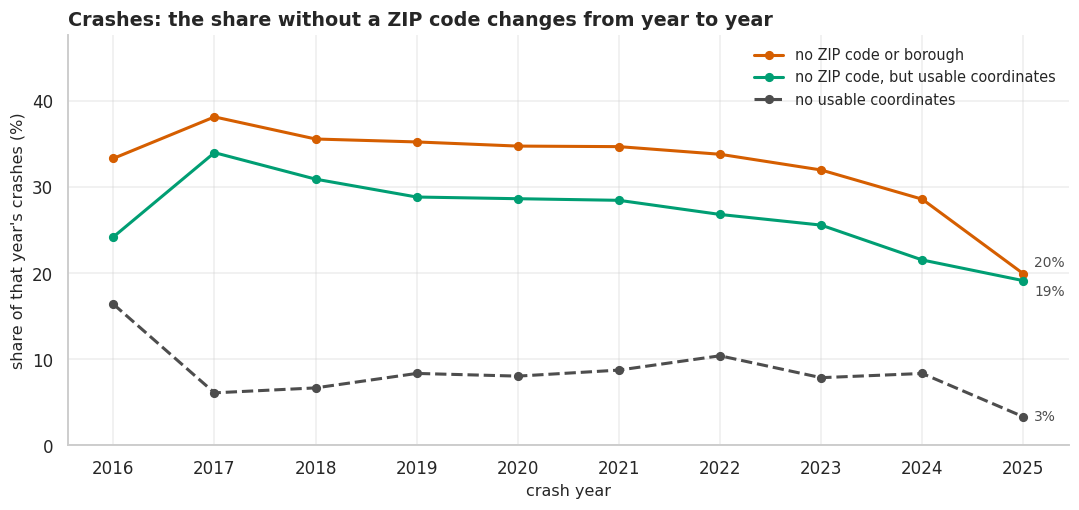

,crashes,no ZIP code (%),no borough (%),no usable coordinates (%),"no ZIP code, usable coordinates (%)","no ZIP code, no usable coordinates (%)","coordinates at (0, 0) (%)"
year,,,,,,,
2016,229833,33.320,33.300,16.390,24.200,9.110,0.190
2017,231007,38.140,38.120,6.100,33.990,4.150,0.040
2018,231564,35.570,35.550,6.670,30.910,4.660,0.130
2019,211486,35.230,35.210,8.350,28.830,6.400,0.140
2020,112918,34.750,34.740,8.040,28.640,6.110,0.140
2021,110558,34.690,34.670,8.740,28.450,6.230,0.790
2022,103887,33.800,33.790,10.400,26.810,6.990,1.800
2023,96607,31.970,31.960,7.860,25.570,6.400,0.320
2024,91316,28.580,28.570,8.350,21.530,7.050,0.580


The share of crashes without a ZIP code ranges from **19.9% (2025) to 38.1% (2017)**. The largest difference between the ZIP and borough shares in any year is 0.02 percentage points.

In [29]:
def crash_gaps_by_year(view):
    """Per crash year: share with no ZIP, with unusable coordinates, and the overlap of the two."""
    usable = view["coordinate_status"] == "usable"
    table = pd.DataFrame({
        "crashes": view.groupby("year").size(),
        "no ZIP code (%)": view.groupby("year")["zip_missing"].mean() * 100,
        "no borough (%)": view.groupby("year")["borough_missing"].mean() * 100,
        "no usable coordinates (%)": (~usable).groupby(view["year"]).mean() * 100,
        "no ZIP code, usable coordinates (%)": (view["zip_missing"] & usable).groupby(view["year"]).mean() * 100,
        "no ZIP code, no usable coordinates (%)": (view["zip_missing"] & ~usable).groupby(view["year"]).mean() * 100,
        "coordinates at (0, 0) (%)": (view["coordinate_status"] == "at (0, 0)").groupby(view["year"]).mean() * 100,
    })
    return table


def plot_crash_gaps(table):
    """Lines of the location gaps per year; borough is left out because it coincides with ZIP."""
    label_shift_points = 7   # the two upper lines end close together, so their labels are pushed apart
    series = [("no ZIP code (%)", "no ZIP code or borough", PALETTE["crash"], "-", label_shift_points),
              ("no ZIP code, usable coordinates (%)", "no ZIP code, but usable coordinates", PALETTE["after"],
               "-", -label_shift_points),
              ("no usable coordinates (%)", "no usable coordinates", PALETTE["neutral"], "--", 0)]
    fig, ax = plt.subplots(figsize=(10, 4.8))
    for column, label, color, style, shift in series:
        ax.plot(table.index, table[column], color=color, linestyle=style, linewidth=2, marker="o",
                markersize=5, label=label)
        end_label(ax, table.index[-1], table[column].iloc[-1], f"{table[column].iloc[-1]:.0f}%", shift)
    ax.set_xticks(table.index)
    ax.set_ylim(0, table["no ZIP code (%)"].max() * 1.25)
    ax.legend(loc="upper right", ncol=1)
    finish(ax, "Crashes: the share without a ZIP code changes from year to year",
           "crash year", "share of that year's crashes (%)")
    plt.tight_layout()
    plt.show()


eda_gaps_by_year = crash_gaps_by_year(eda_crashes)
EDA_FACTS["zip_missing_min_pct"] = eda_gaps_by_year["no ZIP code (%)"].min()
EDA_FACTS["zip_missing_max_pct"] = eda_gaps_by_year["no ZIP code (%)"].max()
plot_crash_gaps(eda_gaps_by_year)
display(eda_gaps_by_year.round(2))
say(f"The share of crashes without a ZIP code ranges from **{EDA_FACTS['zip_missing_min_pct']:.1f}% "
    f"({eda_gaps_by_year['no ZIP code (%)'].idxmin()}) to {EDA_FACTS['zip_missing_max_pct']:.1f}% "
    f"({eda_gaps_by_year['no ZIP code (%)'].idxmax()})**. The largest difference between the ZIP and borough "
    f"shares in any year is "
    f"{(eda_gaps_by_year['no ZIP code (%)'] - eda_gaps_by_year['no borough (%)']).abs().max():.2f} "
    f"percentage points.")

The gap is not constant. It moves by many percentage points across the ten years, so a count
of crashes per ZIP code taken from the raw column would rise and fall with the geocoding
rate and not only with what happened on the street. A ZIP by year panel built that way would
carry an artificial time trend into every model that uses it.

The green line is the part of the gap that coordinates can close, and it follows the red line
closely. What remains, crashes with neither a ZIP code nor a usable position, is a much
smaller group in every year. The first year stands apart: far more of its crashes lack
usable coordinates than in any later year, so both joins see that year less completely.
Dropping all crashes without a ZIP code was the simple alternative and is rejected for the
reason just given: the loss is large and its size depends on the year.

#### 3.2.4 The 2020 reporting break

The chart compares three yearly totals on one axis: all reported crashes, crashes in which at
least one person was injured or killed, and the number of people injured. If the streets had
simply become safer or emptier, the three lines would fall together.

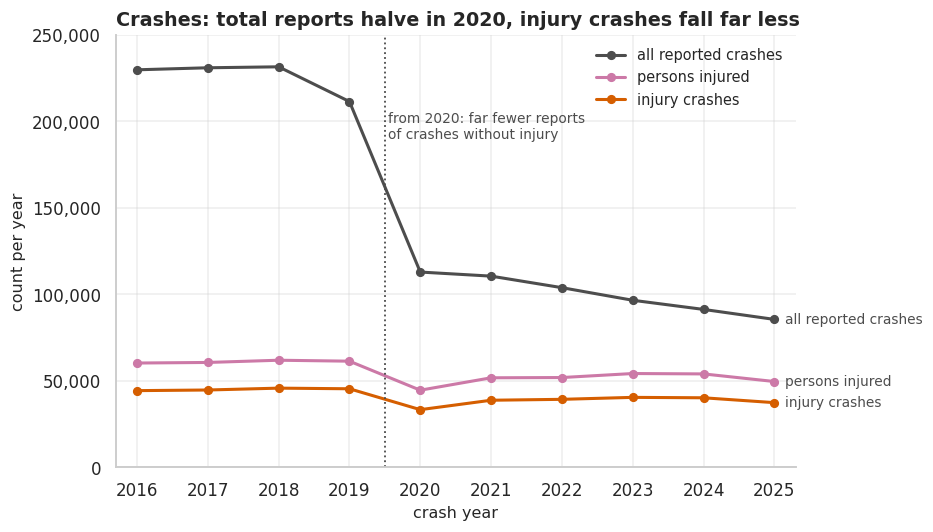

,all reported crashes,injury crashes,persons injured,persons killed,injury crashes (% of all)
year,,,,,
2016,229833,44362,60317,246,19.300
2017,231007,44733,60656,256,19.400
2018,231564,45804,61940,231,19.800
2019,211486,45439,61391,244,21.500
2020,112918,33362,44615,269,29.500
2021,110558,38810,51785,297,35.100
2022,103887,39336,51933,290,37.900
2023,96607,40472,54252,280,41.900
2024,91316,40229,54030,268,44.100


Between 2019 and 2025, all reported crashes change by **-60%** (211,486 to 85,546), injury crashes by **-18%** (45,439 to 37,420). The share of crashes with an injury or death goes from 21% to 44%.

In [30]:
def crashes_by_year(view):
    """Yearly totals of all crashes, injury crashes, persons injured and persons killed."""
    return pd.DataFrame({
        "all reported crashes": view.groupby("year").size(),
        "injury crashes": view.groupby("year")["is_injury_crash"].sum(),
        "persons injured": view.groupby("year")["number_of_persons_injured"].sum(),
        "persons killed": view.groupby("year")["number_of_persons_killed"].sum(),
    }).astype(int)


def plot_reporting_break(yearly):
    """Three yearly lines on one count axis, with the break year marked."""
    series = [("all reported crashes", PALETTE["neutral"]), ("persons injured", PALETTE["accent"]),
              ("injury crashes", PALETTE["crash"])]
    fig, ax = plt.subplots(figsize=(10, 5))
    for column, color in series:
        ax.plot(yearly.index, yearly[column], color=color, linewidth=2, marker="o", markersize=5, label=column)
        end_label(ax, yearly.index[-1], yearly[column].iloc[-1], column)
    ax.axvline(BREAK_YEAR - 0.5, color=PALETTE["neutral"], linestyle=":", linewidth=1.2)
    ax.annotate(f"from {BREAK_YEAR}: far fewer reports\nof crashes without injury",
                xy=(BREAK_YEAR - 0.45, yearly["all reported crashes"].max() * 0.82), fontsize=9,
                color=PALETTE["neutral"])
    ax.set_xticks(yearly.index)
    ax.set_xlim(yearly.index[0] - 0.3, yearly.index[-1] + 0.3)
    ax.set_ylim(0, yearly["all reported crashes"].max() * 1.08)
    thousands(ax)
    ax.legend(loc="upper right")
    finish(ax, "Crashes: total reports halve in 2020, injury crashes fall far less",
           "crash year", "count per year")
    plt.tight_layout(rect=LABEL_MARGIN)
    plt.show()


eda_yearly = crashes_by_year(eda_crashes)
eda_yearly["injury crashes (% of all)"] = 100 * eda_yearly["injury crashes"] / eda_yearly["all reported crashes"]
plot_reporting_break(eda_yearly)
display(eda_yearly.round(1))
EDA_FACTS["all_change_pct"] = 100 * (eda_yearly.loc[YEAR_END, "all reported crashes"]
                                     / eda_yearly.loc[BREAK_YEAR - 1, "all reported crashes"] - 1)
EDA_FACTS["injury_change_pct"] = 100 * (eda_yearly.loc[YEAR_END, "injury crashes"]
                                        / eda_yearly.loc[BREAK_YEAR - 1, "injury crashes"] - 1)
say(f"Between {BREAK_YEAR - 1} and {YEAR_END}, all reported crashes change by "
    f"**{EDA_FACTS['all_change_pct']:+.0f}%** "
    f"({eda_yearly.loc[BREAK_YEAR - 1, 'all reported crashes']:,} to {eda_yearly.loc[YEAR_END, 'all reported crashes']:,}), "
    f"injury crashes by **{EDA_FACTS['injury_change_pct']:+.0f}%** "
    f"({eda_yearly.loc[BREAK_YEAR - 1, 'injury crashes']:,} to {eda_yearly.loc[YEAR_END, 'injury crashes']:,}). "
    f"The share of crashes with an injury or death goes from "
    f"{eda_yearly.loc[BREAK_YEAR - 1, 'injury crashes (% of all)']:.0f}% to "
    f"{eda_yearly.loc[YEAR_END, 'injury crashes (% of all)']:.0f}%.")

The lines do not fall together. Total reports drop sharply in 2020 and keep sliding, while
injury crashes and persons injured dip in 2020, recover most of the way and then stay roughly
flat. As a result the share of crashes with an injury rises sharply. A city in which crashes
fell by far more than injuries is hard to believe. The simpler
reading is that crashes with property damage only stopped being recorded at the earlier rate
from 2020 on, so the total counts two different things before and after that year. The data
cannot prove that reading, but it is the one consistent with all three lines.

Any comparison of total crashes across 2020 would mostly measure the change in reporting, and
a building completed in 2019 would appear to be followed by a large fall in crashes that has
nothing to do with it. The decision is to use the injury crash as the outcome in every
research question, since a crash in which someone was hurt is far less affected by the change in reporting. Total
crashes appear again only as a robustness check. Restricting the study to 2016 to 2019 was the
alternative. It would avoid the break but leave too few years after most completions.

#### 3.2.5 Time patterns: months, weekdays and hours

The monthly series puts the break on a finer time scale and shows the seasonal rhythm that a
before and after comparison must not mistake for an effect.

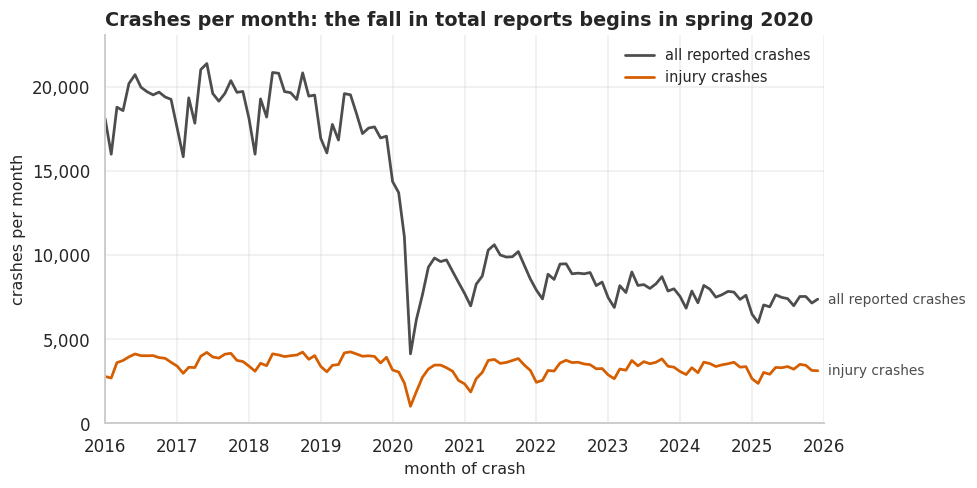

The lowest month of 2020 is April with 4,129 reported crashes, against 16,829 in the same month a year earlier. Injury crashes in those two months: 1,017 and 3,495.

In [31]:
def crashes_by_month(view):
    """Monthly counts of all crashes and injury crashes."""
    month_start = view["crash_date"].dt.to_period("M").dt.to_timestamp()
    return pd.DataFrame({
        "all reported crashes": view.groupby(month_start).size(),
        "injury crashes": view.groupby(month_start)["is_injury_crash"].sum(),
    })


def plot_monthly_series(monthly):
    """Two monthly lines on one axis."""
    fig, ax = plt.subplots(figsize=(10.5, 4.6))
    for column, color in [("all reported crashes", PALETTE["neutral"]), ("injury crashes", PALETTE["crash"])]:
        ax.plot(monthly.index, monthly[column], color=color, linewidth=1.8, label=column)
        end_label(ax, monthly.index[-1], monthly[column].iloc[-1], column)
    ax.set_ylim(0, monthly["all reported crashes"].max() * 1.08)
    ax.set_xlim(monthly.index[0], monthly.index[-1] + pd.DateOffset(months=1))
    thousands(ax)
    ax.legend(loc="upper right")
    finish(ax, "Crashes per month: the fall in total reports begins in spring 2020",
           "month of crash", "crashes per month")
    plt.tight_layout(rect=LABEL_MARGIN)
    plt.show()


eda_monthly = crashes_by_month(eda_crashes)
plot_monthly_series(eda_monthly)
eda_low_month = eda_monthly.loc[f"{BREAK_YEAR}", "all reported crashes"].idxmin()
say(f"The lowest month of {BREAK_YEAR} is {eda_low_month:%B} with "
    f"{eda_monthly.loc[eda_low_month, 'all reported crashes']:,} reported crashes, against "
    f"{eda_monthly.loc[eda_low_month - pd.DateOffset(years=1), 'all reported crashes']:,} in the same month a "
    f"year earlier. Injury crashes in those two months: "
    f"{eda_monthly.loc[eda_low_month, 'injury crashes']:,} and "
    f"{eda_monthly.loc[eda_low_month - pd.DateOffset(years=1), 'injury crashes']:,}.")

On the monthly scale the break is a cliff in spring 2020. Both series fall during the first
lockdown, which is a real drop in traffic. Injury crashes then climb back within months and
resume their yearly cycle, while total reports settle on a new, lower level and never return.
A temporary shock would be expected to affect both lines and then fade; here only the total
keeps its step.

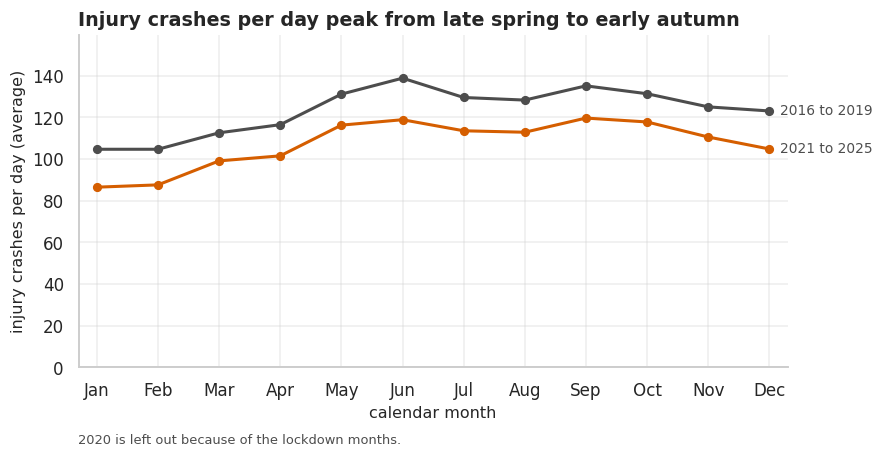

Lowest and highest month by period: 2016 to 2019: Jan 105 per day, Jun 139 per day (33% higher); 2021 to 2025: Jan 86 per day, Sep 120 per day (38% higher).

In [32]:
def month_profile(view):
    """Average injury crashes per day in each calendar month, before and after the break year."""
    injury = view.loc[view["is_injury_crash"] & (view["year"] != BREAK_YEAR)]
    period = np.where(injury["year"] < BREAK_YEAR, f"{YEAR_START} to {BREAK_YEAR - 1}",
                      f"{BREAK_YEAR + 1} to {YEAR_END}")
    crashes = injury.groupby([period, injury["month"]]).size()
    days = injury.groupby([period, injury["month"]])["crash_date"].nunique()
    return (crashes / days).unstack(level=0)


def plot_month_profile(profile):
    """Seasonal profile: injury crashes per day by calendar month, one line per period."""
    fig, ax = plt.subplots(figsize=(9.5, 4.4))
    for column, color in zip(profile.columns, [PALETTE["neutral"], PALETTE["crash"]]):
        ax.plot(profile.index, profile[column], color=color, linewidth=2, marker="o", markersize=5, label=column)
        end_label(ax, profile.index[-1], profile[column].iloc[-1], column)
    ax.set_xticks(profile.index)
    ax.set_xticklabels(MONTH_NAMES)
    ax.set_xlim(0.7, 12.3)
    ax.set_ylim(0, profile.to_numpy().max() * 1.15)
    finish(ax, "Injury crashes per day peak from late spring to early autumn",
           "calendar month", "injury crashes per day (average)",
           note=f"{BREAK_YEAR} is left out because of the lockdown months.")
    plt.tight_layout(rect=LABEL_MARGIN)
    plt.show()


eda_month_profile = month_profile(eda_crashes)
plot_month_profile(eda_month_profile)
say("Lowest and highest month by period: " + "; ".join(
    f"{period}: {MONTH_NAMES[column.idxmin() - 1]} {column.min():.0f} per day, "
    f"{MONTH_NAMES[column.idxmax() - 1]} {column.max():.0f} per day "
    f"({100 * (column.max() / column.min() - 1):.0f}% higher)"
    for period, column in eda_month_profile.items()) + ".")

Injury crashes follow the seasons in both periods: fewest in January and February, most from
late spring to early autumn, when more people walk and cycle. The swing between the quietest
and the busiest month is large enough to matter. A comparison of the six months before a completion with the six
months after it would mix in this cycle, which is why the research questions compare whole
years on each side.

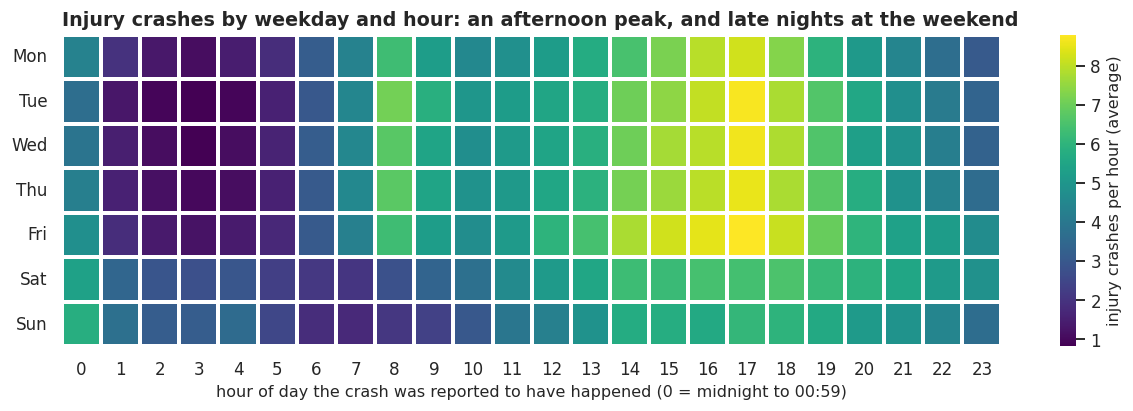

Across all days the busiest hour for injury crashes is **17:00** (7.1% of injury crashes) and the quietest 3:00 (1.4%). The busiest single slot is Fri at 17:00. The hour after midnight holds 4.1% of injury crashes, and 1.6% of all crashes are timed at exactly 0:00.

In [33]:
def weekday_hour_table(view):
    """Average injury crashes in each weekday and hour slot, per calendar day of that weekday."""
    injury = view.loc[view["is_injury_crash"] & view["hour"].notna()]
    counts = injury.groupby(["weekday", "hour"]).size().unstack(fill_value=0)
    days_per_weekday = view.groupby("weekday")["crash_date"].nunique()
    table = counts.div(days_per_weekday, axis=0)
    table.index = WEEKDAY_NAMES
    table.columns = table.columns.astype(int)
    return table


def plot_weekday_hour(table):
    """Heatmap of injury crashes per hour slot, weekday by hour of day."""
    fig, ax = plt.subplots(figsize=(11.5, 3.9))
    sns.heatmap(table, cmap=SEQUENTIAL_CMAP, linewidths=1.5, linecolor="white", ax=ax,
                cbar_kws={"label": "injury crashes per hour (average)"})
    ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
    finish(ax, "Injury crashes by weekday and hour: an afternoon peak, and late nights at the weekend",
           "hour of day the crash was reported to have happened (0 = midnight to 00:59)", "")
    plt.tight_layout()
    plt.show()


eda_weekday_hour = weekday_hour_table(eda_crashes)
plot_weekday_hour(eda_weekday_hour)
eda_hourly = eda_crashes.loc[eda_crashes["is_injury_crash"]].groupby("hour").size()
say(f"Across all days the busiest hour for injury crashes is **{int(eda_hourly.idxmax())}:00** "
    f"({pct(eda_hourly.max(), eda_hourly.sum()):.1f}% of injury crashes) and the quietest "
    f"{int(eda_hourly.idxmin())}:00 ({pct(eda_hourly.min(), eda_hourly.sum()):.1f}%). The busiest single slot "
    f"is {eda_weekday_hour.stack().idxmax()[0]} at {eda_weekday_hour.stack().idxmax()[1]}:00. The hour after "
    f"midnight holds {pct(eda_hourly.get(0.0, 0), eda_hourly.sum()):.1f}% of injury crashes, and "
    f"{pct(eda_crash_text['time_midnight'], len(eda_crashes)):.1f}% of all crashes are timed at exactly 0:00.")

Weekdays show a build-up through the day to a peak in the late afternoon and early evening,
with a smaller morning step. Weekends lack the morning step and carry more crashes after
midnight. The first column is slightly brighter than its neighbours, and part of that is an
artefact: a crash whose time was not known tends to be entered as midnight. Section 4 keeps
the hour as reported, and the research question on time of day works with broad bands of
hours so that this heap at midnight cannot drive a result.

#### 3.2.6 Where crashes are, and coordinates that are not in New York

The map is a hexbin density of the crashes inside the bounding box of the city, on a log
colour scale because a few Manhattan hexagons hold far more crashes than most of the city.
The coordinate pairs that fall outside the box cannot be drawn on a city map without
stretching it across half the globe, so they are counted in the table and sentence below the
map and drawn in Section 4.8, where they are removed.

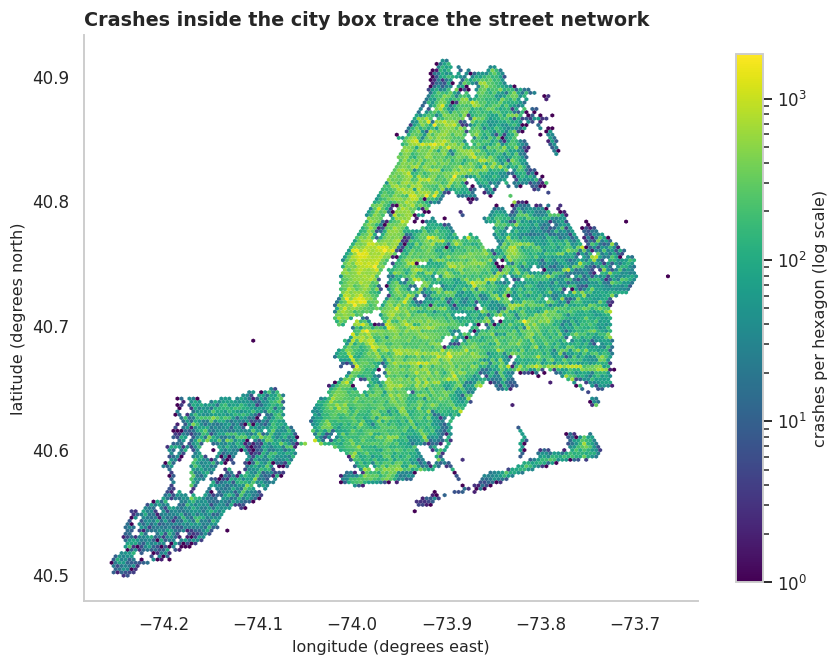

,crashes,share_pct
coordinate_status,,
usable,1372222,91.194
missing,125582,8.346
"at (0, 0)",6769,0.450
outside the city box,149,0.010


**125,582 crashes (8.3%) have no coordinates, 6,769 sit at exactly (0, 0)** and 149 more fall outside the city box. The share at (0, 0) is highest in 2025 (2.24% of that year's crashes) and lowest in 2017 (0.04%).

In [34]:
def plot_crash_coordinates(view):
    """Hexbin density of the usable coordinates; returns the count of each coordinate status."""
    status_counts = view["coordinate_status"].value_counts()
    usable = view.loc[view["coordinate_status"] == "usable"]
    fig, ax = plt.subplots(figsize=(8, 6.6))
    hexes = ax.hexbin(usable["longitude"], usable["latitude"], gridsize=HEXBIN_GRIDSIZE, bins="log",
                      cmap=SEQUENTIAL_CMAP, mincnt=1, linewidths=0)
    map_axes(ax)
    fig.colorbar(hexes, ax=ax, label="crashes per hexagon (log scale)", shrink=0.8)
    finish(ax, "Crashes inside the city box trace the street network", "longitude (degrees east)",
           "latitude (degrees north)")
    plt.tight_layout()
    plt.show()
    return status_counts


eda_coordinate_counts = plot_crash_coordinates(eda_crashes)
EDA_FACTS["coords_missing"] = int(eda_coordinate_counts["missing"])
EDA_FACTS["coords_zero"] = int(eda_coordinate_counts["at (0, 0)"])
EDA_FACTS["coords_outside"] = int(eda_coordinate_counts["outside the city box"])
display(pd.DataFrame({"crashes": eda_coordinate_counts,
                      "share_pct": 100 * eda_coordinate_counts / len(eda_crashes)}).round(3))
say(f"**{EDA_FACTS['coords_missing']:,} crashes ({pct(EDA_FACTS['coords_missing'], len(eda_crashes)):.1f}%) "
    f"have no coordinates, {EDA_FACTS['coords_zero']:,} sit at exactly (0, 0)** and "
    f"{EDA_FACTS['coords_outside']:,} more fall outside the city box. The share at (0, 0) is highest in "
    f"{eda_gaps_by_year['coordinates at (0, 0) (%)'].idxmax()} "
    f"({eda_gaps_by_year['coordinates at (0, 0) (%)'].max():.2f}% of that year's crashes) and lowest in "
    f"{eda_gaps_by_year['coordinates at (0, 0) (%)'].idxmin()} "
    f"({eda_gaps_by_year['coordinates at (0, 0) (%)'].min():.2f}%).")

The point at (0, 0) is a placeholder for "location unknown" written as a number. It is more
dangerous than a blank because it passes every check for missing values and would enter a
distance calculation as a real place several thousand kilometres from any building. The other
stray points are isolated typing or geocoding errors. Section 4 sets all of them to missing
and flags the row. The row itself is kept, since a crash with a bad position can still have a
valid ZIP code and still counts in the ZIP by year panel. Deleting such rows was rejected for
that reason.

Inside the box no cleaning is needed for the density map to draw the city: the bridges,
avenues and expressways are all recognisable, and density is highest in Manhattan below
Central Park, downtown Brooklyn and along the main arterial roads. The areas where the
housing map was dense (the South Bronx, upper Manhattan, central Brooklyn) are also areas of
high crash density. The overlap matters for the analysis. Affordable housing is built in
dense neighbourhoods and dense neighbourhoods have more crashes, so a raw count near
buildings says little without a comparison to similar streets.

#### 3.2.7 ZIP codes and boroughs as written

The crash ZIP code is checked for values that are present but not usable, and the borough
spellings of the two tables are put side by side, since ZIP code and borough are the keys of
the coarser join.

In [35]:
def zip_status_table(raw):
    """Classify every raw crash ZIP code by what is wrong with it, if anything."""
    text = raw["zip_code"]
    stripped = text.str.strip()
    status = np.select(
        [text.isna().to_numpy(), as_flags(stripped == ""), as_flags(stripped == ZIP_PLACEHOLDER),
         ~as_flags(stripped.str.match(ZIP_PATTERN))],
        ["missing", "blank spaces", f"placeholder {ZIP_PLACEHOLDER}", "not five digits"],
        default="five digits")
    table = pd.Series(status).value_counts().rename("crashes").to_frame()
    table["share_pct"] = 100 * table["crashes"] / len(raw)
    return table


def borough_spellings(housing, crashes):
    """Every distinct borough value of the two raw tables, with its row count in each."""
    counts = pd.DataFrame({
        "housing rows": housing["borough"].astype(object).fillna("(missing)").value_counts(),
        "crash rows": crashes["borough"].astype(object).fillna("(missing)").value_counts(),
    }).fillna(0).astype(int)
    return counts.rename_axis("borough as written").sort_index(key=lambda labels: labels.str.lower())


eda_zip_status = zip_status_table(raw_crashes)
EDA_FACTS["zip_junk"] = int(eda_zip_status["crashes"].drop(["missing", "five digits"], errors="ignore").sum())
display(eda_zip_status.round(3))
eda_zip_counts = raw_crashes["zip_code"].str.strip().value_counts()
eda_housing_zips = set(raw_housing["postcode"].dropna())
display(eda_zip_counts.tail(8).rename("crashes").rename_axis("rarest ZIP code values").reset_index()
        .assign(in_housing_table=lambda table: table["rarest ZIP code values"].isin(eda_housing_zips)))
display(borough_spellings(raw_housing, raw_crashes))
eda_shared_boroughs = set(raw_housing["borough"].dropna()) & set(raw_crashes["borough"].dropna())
eda_shared_zips = eda_housing_zips & set(eda_zip_counts.index)
EDA_FACTS["shared_borough_spellings"] = len(eda_shared_boroughs)
eda_zip_junk = eda_zip_status["crashes"].drop(["missing", "five digits"], errors="ignore")
eda_zip_junk_kinds = (f"all of them classed as {eda_zip_junk.index[0]}" if len(eda_zip_junk) == 1
                      else "namely " + join_and(f"{count:,} {kind}" for kind, count in eda_zip_junk.items()))
say(f"**{EDA_FACTS['zip_junk']:,} crash ZIP codes are present but unusable**, {eda_zip_junk_kinds}. "
    f"The crash table has {len(eda_zip_counts):,} distinct ZIP values; "
    f"{len(eda_shared_zips)} of the {len(eda_housing_zips)} housing ZIP codes also occur there. Compared as "
    f"written, **{len(eda_shared_boroughs)} borough names match** between the two tables.")

,crashes,share_pct
five digits,995801,66.178
missing,508284,33.779
placeholder 10000,637,0.042


,rarest ZIP code values,crashes,in_housing_table
0,10176,3,False
1,11242,2,False
2,10044,2,True
3,10166,1,False
4,11241,1,False
5,10162,1,False
6,11371,1,False
7,12345,1,False


,housing rows,crash rows
borough as written,,
(missing),0,508028
BRONX,0,159330
Bronx,2630,0
BROOKLYN,0,328165
Brooklyn,3649,0
MANHATTAN,0,197086
Manhattan,1485,0
QUEENS,0,273373
Queens,1342,0


**637 crash ZIP codes are present but unusable**, all of them classed as placeholder 10000. The crash table has 233 distinct ZIP values; 157 of the 158 housing ZIP codes also occur there. Compared as written, **0 borough names match** between the two tables.

A small number of ZIP codes are filled in with something that is not a ZIP code. In this copy
they are all one placeholder value. It is awkward because it has five digits and starts like a
Manhattan ZIP code, so a format check alone lets it through and it has to be named explicitly.
The rarest values are worth a glance as well, because a ZIP code with a handful of crashes in
ten years is either a border case outside the city or a typing error. Section 4 sets the unusable values to missing so that they
join the group whose ZIP code is recovered from coordinates in Section 6.

Borough needs no repair of content, only of form. The crash table writes it in capitals and
the housing table in title case, so not one borough name matches as written. Without
standardising the case a join on borough would return nothing and raise no error.

#### 3.2.8 Injuries per crash and the extreme values

Persons injured per crash is a count with most of its mass at zero, so each count is drawn as a
dot on a log axis. On a plain axis only the first two values would be visible and the long
tail, which is where the outliers are, would disappear. Dots are used instead of bars because
the length of a bar means nothing when the axis is logarithmic. The dotted line marks the
threshold at which Section 4.10 flags a crash as extreme.

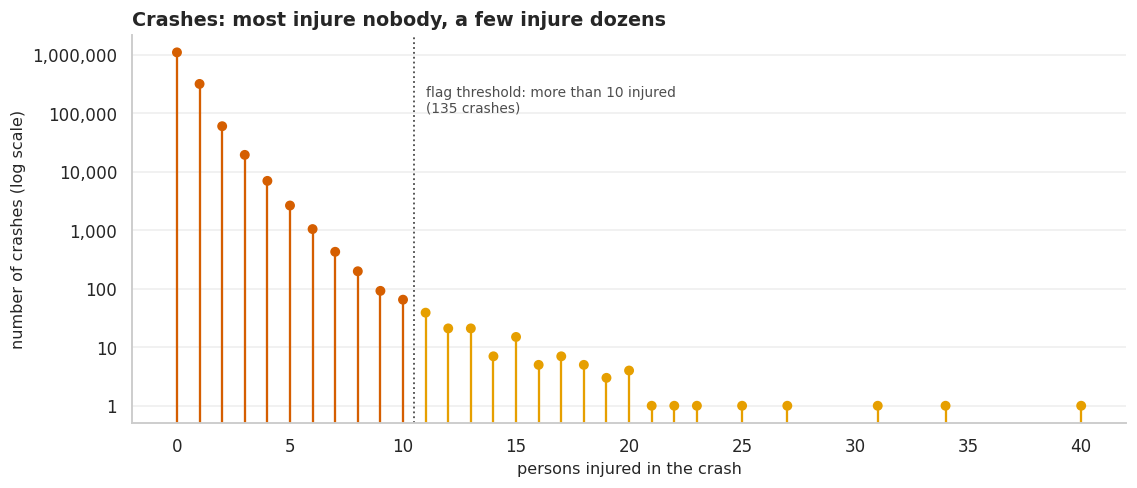

**72.9% of crashes injure nobody**, 21.1% injure one person and 6.0% two or more. The maximum is 40 injured in one crash, and 135 crashes have more than 10. 2,500 crashes involve a death, at most 8 in one crash. 409,967 crashes (27.2%) count as injury crashes.

,crash_date,borough,on_street_name,number_of_persons_injured,number_of_motorist_injured,vehicle_type_code1
1187622,2022-07-21T00:00:00.000,<NA>,HUTCHINSON RIVER PARKWAY RAMP,40,40,Bus
1254634,2023-04-07T00:00:00.000,QUEENS,BELL BOULEVARD,34,34,Bus
660588,2017-10-10T00:00:00.000,BRONX,EAST 149 STREET,31,31,Bus
309469,2017-05-18T00:00:00.000,MANHATTAN,7 AVENUE,27,0,Sedan
1326575,2023-12-28T00:00:00.000,STATEN ISLAND,BISHOP STREET,25,25,Box Truck


In [36]:
def plot_injuries_per_crash(view):
    """Dot per value of persons injured on a log count axis, with the extreme-crash threshold marked."""
    counts = view["number_of_persons_injured"].dropna().astype(int).value_counts().sort_index()
    log_baseline = 0.5    # a log axis needs a positive floor; stems start just below one crash
    colors = [PALETTE["placebo"] if value > EXTREME_INJURED else PALETTE["crash"] for value in counts.index]
    fig, ax = plt.subplots(figsize=(10.5, 4.6))
    ax.vlines(counts.index, log_baseline, counts.to_numpy(), color=colors, linewidth=1.5)
    ax.scatter(counts.index, counts.to_numpy(), s=30, color=colors, zorder=3)
    ax.set_yscale("log")
    ax.set_ylim(log_baseline, counts.max() * 2)
    thousands(ax)
    ax.axvline(EXTREME_INJURED + 0.5, color=PALETTE["neutral"], linestyle=":", linewidth=1.2)
    ax.annotate(f"flag threshold: more than {EXTREME_INJURED} injured\n"
                f"({int(counts[counts.index > EXTREME_INJURED].sum()):,} crashes)",
                xy=(EXTREME_INJURED + 1, 0.8), xycoords=("data", "axes fraction"), fontsize=9,
                color=PALETTE["neutral"])
    ax.grid(axis="x", visible=False)
    finish(ax, "Crashes: most injure nobody, a few injure dozens",
           "persons injured in the crash", "number of crashes (log scale)")
    plt.tight_layout()
    plt.show()
    return counts


eda_injury_counts = plot_injuries_per_crash(eda_crashes)
EDA_FACTS["many_injured"] = int(eda_injury_counts[eda_injury_counts.index > EXTREME_INJURED].sum())
eda_killed_counts = eda_crashes["number_of_persons_killed"].dropna().astype(int).value_counts().sort_index()
say(f"**{pct(eda_injury_counts.get(0, 0), eda_injury_counts.sum()):.1f}% of crashes injure nobody**, "
    f"{pct(eda_injury_counts.get(1, 0), eda_injury_counts.sum()):.1f}% injure one person and "
    f"{pct(eda_injury_counts[eda_injury_counts.index >= 2].sum(), eda_injury_counts.sum()):.1f}% two or more. "
    f"The maximum is {eda_injury_counts.index.max()} injured in one crash, and {EDA_FACTS['many_injured']:,} "
    f"crashes have more than {EXTREME_INJURED}. {int(eda_killed_counts[eda_killed_counts.index >= 1].sum()):,} "
    f"crashes involve a death, at most {eda_killed_counts.index.max()} in one crash. "
    f"{int(eda_crashes['is_injury_crash'].sum()):,} crashes "
    f"({pct(int(eda_crashes['is_injury_crash'].sum()), len(eda_crashes)):.1f}%) count as injury crashes.")
display(raw_crashes.loc[eda_crashes["number_of_persons_injured"].nlargest(5).index,
                        ["crash_date", "borough", "on_street_name", "number_of_persons_injured",
                         "number_of_motorist_injured", "vehicle_type_code1"]])

On the log axis the counts fall in a nearly straight line, the mark of a heavy-tailed count
with no natural cut-off. A rule based on the interquartile range cannot separate errors from
real events here. Most crashes injure nobody, so both quartiles sit at the bottom of the scale
and the fence falls between two and three injured people, so it would flag ordinary
multi-injury crashes, not errors (Section 4.10 gives the numbers). The extreme rows look like
genuine events, typically a bus or several vehicles with many injured occupants.

These crashes are kept. They barely affect the main outcome, because an injury crash counts
once however many people were hurt in it. They do matter for sums of persons injured, where a
single bus crash can change the total of a small area, so Section 4 flags crashes above a
domain threshold and the analyses of severity can be repeated without them. Capping the value
was the alternative, and it would replace a recorded number with an invented one.

#### 3.2.9 Does persons injured equal pedestrians plus cyclists plus motorists?

The table has a total and three parts. If the total always equalled the sum of the parts, one
of the four columns would be redundant and the pedestrian and cyclist share could be computed
from either. The check below tests that row by row and by year.

In [37]:
def injury_sum_check(view):
    """Compare persons injured with the sum of its three parts, row by row.

    A few totals are blank; those rows cannot be compared and are counted separately.
    """
    parts = view[CRASH_INJURY_PARTS].sum(axis=1)
    total_known = view["number_of_persons_injured"].notna()
    difference = (view["number_of_persons_injured"] - parts).where(total_known)
    by_year = pd.DataFrame({
        "injury crashes": view.groupby("year")["is_injury_crash"].sum(),
        "total above parts": (difference > 0).groupby(view["year"]).sum(),
        "total below parts": (difference < 0).groupby(view["year"]).sum(),
    })
    by_year["mismatch_pct_of_injury_crashes"] = (
        100 * (by_year["total above parts"] + by_year["total below parts"]) / by_year["injury crashes"])
    return difference, by_year, int((~total_known).sum())


def mismatch_vehicle_table(raw, is_mismatch, is_injury_crash):
    """First vehicle types most common among mismatched crashes, against their share of all injury crashes."""
    vehicle = raw["vehicle_type_code1"].str.strip().str.lower().astype(object).fillna("(missing)")
    among_mismatch = vehicle[is_mismatch.to_numpy()].value_counts(normalize=True).mul(100)
    among_injury = vehicle[is_injury_crash.to_numpy()].value_counts(normalize=True).mul(100)
    table = pd.DataFrame({"share of mismatched crashes (%)": among_mismatch.head(6)})
    table["share of all injury crashes (%)"] = among_injury.reindex(table.index).fillna(0)
    return table.rename_axis("first vehicle type (lower-cased)")


eda_injury_difference, eda_mismatch_by_year, eda_blank_totals = injury_sum_check(eda_crashes)
eda_is_mismatch = eda_injury_difference.fillna(0).ne(0)
EDA_FACTS["injury_mismatch"] = int(eda_is_mismatch.sum())
EDA_FACTS["casualty_blank_cells"] = eda_crash_text["casualty_missing"]
display(eda_mismatch_by_year.round(2))
display(eda_injury_difference.dropna().astype(int).value_counts().sort_index().rename("crashes")
        .rename_axis("persons injured minus (pedestrians + cyclists + motorists)").to_frame().T)
display(mismatch_vehicle_table(raw_crashes, eda_is_mismatch, eda_crashes["is_injury_crash"]).round(1))
say(f"The total differs from the sum of its parts in **{EDA_FACTS['injury_mismatch']:,} crashes**: higher in "
    f"{int((eda_injury_difference > 0).sum()):,} and lower in {int((eda_injury_difference < 0).sum()):,}. "
    f"The yearly share among injury crashes runs from "
    f"{eda_mismatch_by_year['mismatch_pct_of_injury_crashes'].min():.2f}% "
    f"({eda_mismatch_by_year['mismatch_pct_of_injury_crashes'].idxmin()}) to "
    f"{eda_mismatch_by_year['mismatch_pct_of_injury_crashes'].max():.2f}% "
    f"({eda_mismatch_by_year['mismatch_pct_of_injury_crashes'].idxmax()}). The total is blank in "
    f"{eda_blank_totals} crashes, which are left out of this comparison.")

,injury crashes,total above parts,total below parts,mismatch_pct_of_injury_crashes
year,,,,
2016,44362,330,139,1.060
2017,44733,64,56,0.270
2018,45804,51,32,0.180
2019,45439,1,0,0.000
2020,33362,0,0,0.000
2021,38810,2041,0,5.260
2022,39336,2288,0,5.820
2023,40472,2282,0,5.640
2024,40229,1766,0,4.390


persons injured minus (pedestrians + cyclists + motorists),-14,-7,-6,-5,-4,-3,-2,-1,0,1,2,3,4,5,6,7,8,19
crashes,1,1,1,3,12,27,78,104,1494299,9604,503,47,17,1,3,1,1,1


,share of mismatched crashes (%),share of all injury crashes (%)
first vehicle type (lower-cased),,
sedan,30.700,42.000
station wagon/sport utility vehicle,25.800,32.300
e-scooter,15.400,0.600
e-bike,13.700,0.900
(missing),3.300,2.700
taxi,2.900,4.200


The total differs from the sum of its parts in **10,405 crashes**: higher in 10,178 and lower in 227. The yearly share among injury crashes runs from 0.00% (2020) to 5.82% (2022). The total is blank in 18 crashes, which are left out of this comparison.

The identity does not hold, and the pattern has two parts (Section 4.9 charts the yearly
counts). In the first years of the window there is a small number of mismatches in both
directions, which look like entry errors. After two years with almost none, the mismatches
return at a much higher rate and in one direction only: the total is above the parts, usually by one. E-scooters and e-bikes are the
first vehicle in a far larger share of these crashes than of injury crashes in general. That
is consistent with riders of those devices being counted as injured persons without fitting
any of the three older categories, although the table does not say so directly.

For cleaning this rules out the obvious repair. Overwriting the total with the sum of the
parts would delete injured people from the recent years only, which would add a second
artificial break to the one found in 3.2.4. Section 4 keeps a total that is above its parts
and flags the row, raises the few totals that are below their parts, and defines an injury
crash from all casualty columns together. The pedestrian and cyclist share in the research
questions is computed from the parts, so it leaves these riders out. That is a stated limit of
the analysis, because the data gives no way to assign them to a group.

#### 3.2.10 Contributing factors and their spellings

The first contributing factor is free of typing variation only if it comes from a fixed list.
The chart shows the most frequent values as shares of all crashes, with the values that carry
no information in grey. The table after it lists labels that differ only by case, spacing or
a letter or two, and labels that are bare numbers.

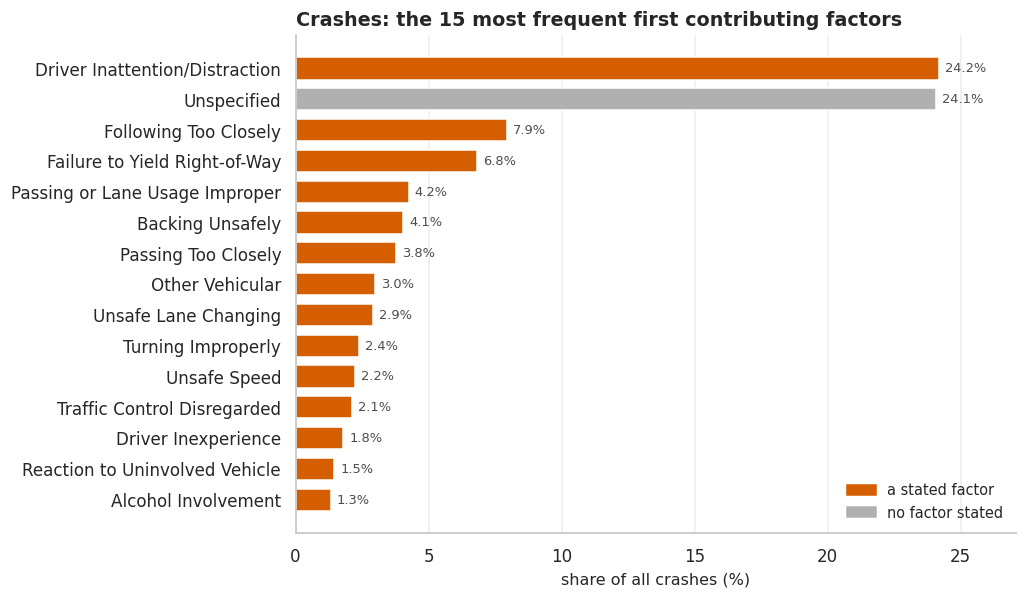

,label,crashes,near-duplicate,its crashes,similarity
0,Reaction to Uninvolved Vehicle,21820,Reaction to Other Uninvolved Vehicle,79,0.910
1,Illnes,1963,Illness,147,0.920
2,Drugs (illegal),969,Drugs (Illegal),28,1.000
3,Cell Phone (hand-Held),601,Cell Phone (hand-held),4,1.000


,factor label that is only digits,crashes
0,80,101
1,1,10


The column has **61 distinct labels**. **"Unspecified" accounts for 24.1% of all crashes** and 20.0% of injury crashes, and 6,442 crashes have no value. The five most frequent stated factors cover 47.2% of crashes. 4 pairs of labels are near-duplicates and 2 labels are bare numbers (111 crashes).

In [38]:
def factor_counts(raw):
    """Share of crashes for each raw value of the first contributing factor (missing included)."""
    counts = raw["contributing_factor_vehicle_1"].astype(object).fillna("(missing)").value_counts()
    return pd.DataFrame({"crashes": counts, "share_pct": 100 * counts / len(raw)})


def plot_top_factors(factors):
    """Horizontal bars of the most frequent contributing factors, uninformative ones in grey."""
    top = factors.head(TOP_FACTORS).iloc[::-1]
    uninformative = top.index.isin(["Unspecified", "(missing)"])
    fig, ax = plt.subplots(figsize=(9.5, 5.6))
    ax.barh(top.index, top["share_pct"], height=0.72,
            color=np.where(uninformative, PALETTE["before"], PALETTE["crash"]))
    for label, value in top["share_pct"].items():
        ax.annotate(f"{value:.1f}%", xy=(value, label), xytext=(4, 0), textcoords="offset points",
                    va="center", fontsize=8.5, color=PALETTE["neutral"])
    color_legend(ax, {"a stated factor": PALETTE["crash"], "no factor stated": PALETTE["before"]},
                 loc="lower right")
    ax.grid(axis="y", visible=False)
    ax.set_xlim(0, top["share_pct"].max() * 1.12)
    finish(ax, f"Crashes: the {TOP_FACTORS} most frequent first contributing factors",
           "share of all crashes (%)", "")
    plt.tight_layout()
    plt.show()


def factor_spelling_variants(factors):
    """Pairs of factor labels that are near-duplicates, and labels that are only digits."""
    labels = [label for label in factors.index if label != "(missing)"]
    rows = []
    for position, label in enumerate(labels):
        for other in labels[position + 1:]:
            similarity = difflib.SequenceMatcher(None, label.lower().strip(), other.lower().strip()).ratio()
            if similarity >= SPELLING_SIMILARITY:
                rows.append({"label": label, "crashes": int(factors.loc[label, "crashes"]),
                             "near-duplicate": other, "its crashes": int(factors.loc[other, "crashes"]),
                             "similarity": round(similarity, 2)})
    numeric = factors.loc[[label for label in labels if label.strip().isdigit()], "crashes"]
    return pd.DataFrame(rows), numeric


eda_factors = factor_counts(raw_crashes)
EDA_FACTS["factor_unspecified_pct"] = float(eda_factors["share_pct"].get("Unspecified", 0.0))
EDA_FACTS["factor_missing"] = int(eda_factors["crashes"].get("(missing)", 0))
plot_top_factors(eda_factors)
eda_factor_variants, eda_numeric_factors = factor_spelling_variants(eda_factors)
EDA_FACTS["factor_variant_pairs"] = len(eda_factor_variants)
display(eda_factor_variants)
display(eda_numeric_factors.rename("crashes").rename_axis("factor label that is only digits").reset_index())
eda_injury_unspecified = pct(
    int(as_flags(raw_crashes["contributing_factor_vehicle_1"] == "Unspecified")[eda_crashes["is_injury_crash"].to_numpy()].sum()),
    int(eda_crashes["is_injury_crash"].sum()))
say(f"The column has **{len(eda_factors) - int('(missing)' in eda_factors.index)} distinct labels**. "
    f"**\"Unspecified\" accounts for {EDA_FACTS['factor_unspecified_pct']:.1f}% of all crashes** and "
    f"{eda_injury_unspecified:.1f}% of injury crashes, and {EDA_FACTS['factor_missing']:,} crashes have no "
    f"value. The five most frequent stated factors cover "
    f"{eda_factors.drop(['Unspecified', '(missing)'], errors='ignore')['share_pct'].head(5).sum():.1f}% of "
    f"crashes. {len(eda_factor_variants)} pairs of labels are near-duplicates and "
    f"{len(eda_numeric_factors)} labels are bare numbers "
    f"({int(eda_numeric_factors.sum())} crashes).")

"Unspecified" is as frequent as the most common stated factor, so it is kept as a category of
its own. Guessing a factor for those crashes from the other columns was considered and
rejected, because whether an officer names a factor is likely related to how serious the
crash was, so the guesses would be biased in an unknown direction. "Unspecified" therefore
stays as its own group, and the research question on contributing factors works with shares
among crashes that do state one.

The stated factors come from a list, yet the same factor
appears with different capitalisation, one label has a typing error, and a few crashes carry
a numeric code where the label should be. Each variant is rare, yet left alone it would split
one factor across two rows of every table. Section 4 standardises the spellings and folds the
long tail of rare factors into a small number of groups, since the full list of labels is too
long to compare around individual buildings.

#### 3.2.11 Duplicates

`collision_id` is unique, but the same collision could still have been entered twice under two
identifiers. The check counts rows that agree on date, time, position, street and every
casualty count.

In [39]:
def crash_duplicate_checks(raw):
    """Count repeated collision ids and rows identical in everything that describes the event."""
    event_columns = ["crash_date", "crash_time", "latitude", "longitude", "on_street_name",
                     "contributing_factor_vehicle_1", "vehicle_type_code1"] + CRASH_CASUALTY_COLUMNS
    located = raw.loc[raw["latitude"].notna().to_numpy()]
    return {
        "repeated_ids": int(raw["collision_id"].duplicated().sum()),
        "located_rows": len(located),
        "same_event_rows": int(located.duplicated(event_columns).sum()),
    }


eda_crash_duplicates = crash_duplicate_checks(raw_crashes)
EDA_FACTS["crash_same_event"] = eda_crash_duplicates["same_event_rows"]
say(f"`collision_id` repeats **{eda_crash_duplicates['repeated_ids']} times**. Among the "
    f"{eda_crash_duplicates['located_rows']:,} crashes with coordinates, "
    f"**{eda_crash_duplicates['same_event_rows']:,} rows "
    f"({pct(eda_crash_duplicates['same_event_rows'], eda_crash_duplicates['located_rows']):.3f}%)** repeat an "
    f"earlier row in date, time, position, street, factor, vehicle type and all casualty counts.")

`collision_id` repeats **0 times**. Among the 1,379,140 crashes with coordinates, **1,213 rows (0.088%)** repeat an earlier row in date, time, position, street, factor, vehicle type and all casualty counts.

No identifier repeats, so there are no exact duplicates to remove. The rows that match on
everything else are a tiny fraction and cannot be told apart from two separate minor crashes
at a busy junction within the same minute, which is not unusual in ten years of data.
Removing them would mean deleting records on a guess, so Section 4 flags them as possible
duplicates and leaves them in.

### 3.3 What the exploration tells us to do

The table collects the problems found above, with their size as measured in this section, and
names the cleaning action each one leads to. Sections 4 and 6 carry the actions out and
record them in the cleaning log.

In [40]:
def exploration_summary(facts, housing_rows, crash_rows):
    """One row per observed problem: its measured size and the cleaning action it leads to."""
    rows = [
        ("Housing", "Unit columns are blank where the count is zero",
         f"{facts['unit_blank_cells']:,} blank cells, no written zero",
         "Impute: fill with 0 and check that the parts add up to the total", "Section 4"),
        ("Housing", "Confidential rows have no address, ZIP code or coordinates",
         f"{facts['confidential_rows']:,} rows ({pct(facts['confidential_rows'], housing_rows):.1f}%), "
         f"{facts['confidential_unit_pct']:.2f}% of units",
         "Flag: keep for borough totals, leave out of both joins, no location imputed", "Section 4"),
        ("Housing", "Published address but no coordinates",
         f"{facts['other_unlocated']} rows", "Flag: cannot enter the distance join", "Section 4"),
        ("Housing", "No completion date",
         f"{facts['no_completion_rows']:,} rows ({pct(facts['no_completion_rows'], housing_rows):.1f}%)",
         "Flag as not yet completed; not used in before and after comparisons", "Section 4"),
        ("Housing", "Completion date before the start date",
         f"{facts['completion_before_start']} rows", "Flag; dates left as published", "Section 4"),
        ("Housing", "Completion date equal to the start date",
         f"{facts['completion_on_start']:,} rows",
         "Flag; the completion date alone marks the event", "Section 4"),
        ("Housing", "Same building under more than one project",
         f"{facts['repeated_building_rows']} extra rows",
         "Keep; the key is (project_id, building_id), not building_id", "Section 4"),
        ("Housing", "Building size is right-skewed",
         f"{facts['size_above_fence']:,} rows ({facts['size_above_fence_pct']:.1f}%) above the IQR fence",
         "Keep all rows; flag very large buildings, use size bands and medians", "Section 4"),
        ("Both", "Borough written in different letter case",
         f"{facts['shared_borough_spellings']} names match as written", "Standardise to one spelling", "Section 4"),
        ("Both", "Dates, numbers and ZIP codes loaded as text",
         "every column", "Standardise: explicit types, ZIP code kept as five-character text", "Section 4"),
        ("Crashes", "ZIP code and borough missing together",
         f"{facts['zip_missing']:,} crashes ({pct(facts['zip_missing'], crash_rows):.1f}%), "
         f"{facts['zip_missing_min_pct']:.0f}% to {facts['zip_missing_max_pct']:.0f}% by year",
         f"Impute from coordinates where usable ({pct(facts['zip_recoverable'], facts['zip_missing']):.0f}% "
         f"of these rows), validated on a holdout", "Section 6"),
        ("Crashes", "ZIP code present but not a ZIP code",
         f"{facts['zip_junk']:,} crashes", "Set to missing, then treated like the rows above", "Section 4"),
        ("Crashes", "Coordinates missing",
         f"{facts['coords_missing']:,} crashes ({pct(facts['coords_missing'], crash_rows):.1f}%)",
         "Flag: kept for the ZIP level if a ZIP code exists, left out of the distance join", "Section 4"),
        ("Crashes", "Coordinates at (0, 0) or outside the city",
         f"{facts['coords_zero']:,} at (0, 0), {facts['coords_outside']:,} outside the box",
         "Set coordinates to missing and flag; the row is kept", "Section 4"),
        ("Crashes", f"Reports of crashes without injury fall from {BREAK_YEAR}",
         f"all crashes {facts['all_change_pct']:+.0f}%, injury crashes {facts['injury_change_pct']:+.0f}% "
         f"({BREAK_YEAR - 1} to {YEAR_END})",
         "Use the injury crash as the outcome; all crashes only as a robustness check", "Sections 4 to 9"),
        ("Crashes", "crash_time without a leading zero",
         f"{facts['time_short']:,} rows", "Standardise: parse to an hour of day", "Section 4"),
        ("Crashes", "Street names padded with spaces",
         f"{facts['street_padded']:,} rows",
         "Column not carried forward; crashes are located by coordinates and ZIP code", "Section 4"),
        ("Crashes", "Contributing factor not stated",
         f"\"Unspecified\" in {facts['factor_unspecified_pct']:.1f}% of crashes, {facts['factor_missing']:,} blank",
         "Keep \"Unspecified\" as its own group, blanks join it; no factor is guessed", "Section 4"),
        ("Crashes", "Contributing factor spelled in several ways",
         f"{facts['factor_variant_pairs']} near-duplicate pairs",
         "Standardise spelling and group the rare factors", "Section 4"),
        ("Crashes", "Persons injured differs from the sum of its parts",
         f"{facts['injury_mismatch']:,} crashes",
         "Flag; a total above its parts is kept, a total below them is raised to their sum", "Section 4"),
        ("Crashes", "Persons injured or persons killed blank",
         f"{facts['casualty_blank_cells']} cells; the six part columns are never blank",
         "Impute the total from its parts", "Section 4"),
        ("Crashes", f"More than {EXTREME_INJURED} persons injured in one crash",
         f"{facts['many_injured']:,} crashes", "Flag as extreme; keep the recorded value", "Section 4"),
        ("Crashes", "Rows identical except for the identifier",
         f"{facts['crash_same_event']:,} crashes", "Flag as possible duplicates; not removed", "Section 4"),
    ]
    return pd.DataFrame(rows, columns=["dataset", "problem observed", "size in the raw data",
                                       "cleaning action", "handled in"])


with pd.option_context("display.max_colwidth", None, "display.max_rows", 40):
    display(exploration_summary(EDA_FACTS, len(raw_housing), len(raw_crashes)))

,dataset,problem observed,size in the raw data,cleaning action,handled in
0,Housing,Unit columns are blank where the count is zero,"106,309 blank cells, no written zero",Impute: fill with 0 and check that the parts add up to the total,Section 4
1,Housing,"Confidential rows have no address, ZIP code or coordinates","1,949 rows (20.4%), 0.63% of units","Flag: keep for borough totals, leave out of both joins, no location imputed",Section 4
2,Housing,Published address but no coordinates,9 rows,Flag: cannot enter the distance join,Section 4
3,Housing,No completion date,"1,653 rows (17.3%)",Flag as not yet completed; not used in before and after comparisons,Section 4
4,Housing,Completion date before the start date,21 rows,Flag; dates left as published,Section 4
5,Housing,Completion date equal to the start date,"2,824 rows",Flag; the completion date alone marks the event,Section 4
6,Housing,Same building under more than one project,124 extra rows,"Keep; the key is (project_id, building_id), not building_id",Section 4
7,Housing,Building size is right-skewed,"1,171 rows (12.3%) above the IQR fence","Keep all rows; flag very large buildings, use size bands and medians",Section 4
8,Both,Borough written in different letter case,0 names match as written,Standardise to one spelling,Section 4
9,Both,"Dates, numbers and ZIP codes loaded as text",every column,"Standardise: explicit types, ZIP code kept as five-character text",Section 4


Most of the later design follows from three of these rows. The outcome is the injury crash,
because total crash counts stop being comparable in 2020. The ZIP code of a
crash has to be recovered from its coordinates, because the share without one is large and
changes from year to year. And the confidential housing rows can only be used at borough
level, although they hold very little of the housing.

In [41]:
# The exploration views are temporary: free them so that no later section can depend on them.
# Names are found by their prefix, so renaming a view cannot break this cell and running it twice is safe.
release(*[name for name in list(globals()) if name.startswith("eda_")])
assert (raw_housing.shape, raw_crashes.shape) == EDA_RAW_SHAPES, "a raw frame was modified during exploration"

## 4. Pre-integration cleaning

### 4.0 Policy, and how each decision is recorded

Both raw tables were loaded as text, so nothing has been converted yet. This section turns them
into two typed frames, `housing` and `crashes`, and every change follows one of four actions.

A row is **dropped** only when it cannot be used for anything: it has no key, it repeats another
row, or it lies outside the study window. Dropping is the last choice because a crash row that
lacks a ZIP code still counts toward a borough total and may still have coordinates.

A value is **imputed** only when the correct value follows from other fields of the same row
with no guessing. Two cases qualify: a blank unit count that the publisher uses to mean zero,
and a missing casualty total that equals the sum of its parts. Statistical imputation (a mean, a
model) is not used anywhere in this section. A missing coordinate or a missing completion date
has no deterministic answer, so it stays missing.

A value or row is **flagged** when it is unusual but plausible, or wrong in a way that cannot be
repaired. The row is kept and a boolean column lets a later section include or exclude it. Large
buildings, crashes with many injured people, confidential housing records and completion dates
that precede the start date are all handled this way.

A value is **standardised** when only its form changes: text to dates, upper case to title case,
free text to a fixed list of categories, a placeholder code to a missing value.

Every rule calls `log_rule(dataset, rule, action, rows_before, rows_after, affected, reason)`.
`rows_before` and `rows_after` show whether rows were lost, and `affected` counts the rows or
cells the rule touched. Rules that find nothing to fix are logged too, with zero affected, so the
log also shows what was checked. The full log is printed in 4.13.

The five cleaning tasks of the assignment map to the subsections like this.

| Task | Housing | Crashes |
|---|---|---|
| Missing values (drop against impute) | 4.1, 4.3, 4.4 | 4.7, 4.8, 4.9 |
| Outliers (IQR and domain rules) | 4.6 | 4.8 (coordinates), 4.10 |
| Inconsistent data | 4.4, 4.5 | 4.8, 4.9 |
| Format standardisation | 4.1, 4.3, 4.4 | 4.7, 4.8, 4.11 |
| Duplicates | 4.2 | 4.7 |

The constants below are used only in this section. The ones shared with Section 3 (date layout,
placeholder values, the unit-column lists, the outlier multiplier and the parsing helpers) are
defined once in 2.1.

In [42]:
# --- Constants for Section 4 ------------------------------------------------------------------
# ZIP code ranges the Postal Service assigns to each borough (inclusive, as integers). A code is
# accepted as a New York City ZIP only if it falls in one of them. 11001 (Floral Park) and 11040
# (New Hyde Park) straddle the Queens / Nassau County line, so they are listed under Queens.
NYC_ZIP_RANGES = {
    "Manhattan": [(10001, 10282)],
    "Staten Island": [(10301, 10314)],
    "Bronx": [(10451, 10475)],
    "Queens": [(11001, 11001), (11004, 11005), (11040, 11040), (11101, 11120), (11351, 11697)],
    "Brooklyn": [(11201, 11256)],
}
DEEP_AFFORDABLE_COLUMNS = ["extremely_low_income_units", "very_low_income_units"]

# Housing columns that are not carried into the clean frame: finer geographic identifiers that the
# crash table has no counterpart for, and a second coordinate pair that is missing in the same rows.
HOUSING_COLUMNS_NOT_KEPT = ["bbl", "bin", "council_district", "census_tract",
                            "neighborhood_tabulation_area", "latitude_internal", "longitude_internal"]

SIZE_BAND_EDGES = [0, 4, 19, 49, 149, np.inf]              # total units, upper edge inclusive
SIZE_BAND_LABELS = ["1-4", "5-19", "20-49", "50-149", "150+"]   # from row houses to towers

# Crash columns: raw name -> short name used from here on.
CASUALTY_COLUMNS = {
    "number_of_persons_injured": "injured", "number_of_persons_killed": "killed",
    "number_of_pedestrians_injured": "ped_injured", "number_of_pedestrians_killed": "ped_killed",
    "number_of_cyclist_injured": "cyc_injured", "number_of_cyclist_killed": "cyc_killed",
    "number_of_motorist_injured": "mot_injured", "number_of_motorist_killed": "mot_killed",
}
ROAD_USER_PREFIXES = ["ped", "cyc", "mot"]   # the three road-user roles the table breaks out

# Time-of-day bands as (first hour, last hour), inclusive, in 24-hour clock.
HOUR_BANDS = {"Night": (0, 5), "Morning": (6, 11), "Afternoon": (12, 17), "Evening": (18, 23)}

# Contributing-factor groups. Each raw value is lower-cased and trimmed, then given the group of
# the FIRST pattern it matches, so the order below matters and is explained line by line.
FACTOR_RULES = [
    # the explicit "no factor recorded" label and bare numeric codes ("80", "1") carry no information
    ("Unspecified", r"^unspecified$|^\d+$"),
    # the one factor that blames a person outside a vehicle; kept apart because RQ6 looks at them
    ("Pedestrian or cyclist error", r"pedestrian|bicyclist"),
    # before "Vehicle defect" (pavement / shoulders "defective") and before "Improper manoeuvre"
    # ("lane marking"), and before "Failure to yield or obey" ("traffic control device")
    ("Road or environment", r"pavement|shoulders|lane marking|traffic control device|obstruct|debris"
                            r"|glare|animals"),
    # named parts, so that "tire failure" is not caught by "failure to yield" further down
    ("Vehicle defect", r"defective|defects|steering|tire|windshield|tinted"),
    # "illnes" absorbs the misspelling "Illnes"; "drugs" absorbs "(illegal)" and "(Illegal)"
    ("Impairment or medical", r"alcohol|drugs|medication|asleep|fatigued|drowsy|consciousness"
                              r"|illnes|disability"),
    # "cell phone" absorbs "(hand-held)", "(hand-Held)" and "(hands-free)"
    ("Distraction", r"distraction|inattention|cell phone|electronic|texting|headphones|eating"
                    r"|navigation"),
    ("Speed or aggressive driving", r"speed|aggressive|following too closely"),
    ("Failure to yield or obey", r"yield|disregarded|keep right"),
    # after "Road or environment", so that "lane" here means lane use, not lane markings
    ("Improper manoeuvre", r"passing|lane|turning|backing|inexperience"),
    ("Other", r"other vehicular|uninvolved|vandalism|driverless|oversized"),
]
FACTOR_GROUPS = [group for group, _ in FACTOR_RULES]
FACTOR_FALLBACK = "Other"   # group for a value that no pattern recognises

MAP_SAMPLE_ROWS = 60_000    # crashes drawn in the coordinate figure; enough to show the street grid
MINUTES_PER_HOUR = 60       # a crash minute recorded evenly would be on the hour in 1 of these
ROUNDING_STEP_MIN = 5       # people round minutes to multiples of five; 1 in 5 minutes is one anyway

Two small helpers are shared by both tables: the ZIP validator and the coordinate validator.
Using the same functions on both sides guarantees that a ZIP or a point accepted in one table
would also be accepted in the other, which the integration step relies on. Numbers are parsed
with the strict `to_number` from 2.1, which stops the notebook on a value that is not a number.

In [43]:
def standardise_zip(zip_text):
    """Return (zip, implied_borough): a 5-character NYC ZIP or missing, and the borough of its range.

    The text is trimmed and a trailing '.0' is removed (the form a ZIP takes when a file is read
    with default types). Anything that is not five digits inside NYC_ZIP_RANGES becomes missing;
    this removes blanks, the 10000 placeholder and codes from outside the city in one test.
    """
    text = zip_text.str.strip().str.replace(r"\.0$", "", regex=True)
    is_five_digits = text.str.fullmatch(r"\d{5}").fillna(False).astype(bool)
    number = pd.to_numeric(text.where(is_five_digits), errors="coerce").astype("float64")
    implied_borough = pd.Series(np.nan, index=zip_text.index, dtype=object)
    for borough_name, ranges in NYC_ZIP_RANGES.items():
        for low, high in ranges:
            implied_borough[number.between(low, high)] = borough_name
    clean_zip = text.where(implied_borough.notna()).astype("string[pyarrow]")
    return clean_zip, implied_borough


def validate_coordinates(latitude_text, longitude_text):
    """Return (lat, lon, n_zero, n_outside): float64 coordinates, missing unless inside NYC_BOUNDS.

    (0, 0) is the placeholder an automatic address lookup (geocoder) writes when it fails. It is counted apart
    from other out-of-box points because the two have different causes.
    """
    lat, lon = to_number(latitude_text), to_number(longitude_text)
    is_zero = (lat == 0) & (lon == 0)
    in_box = lat.between(*NYC_BOUNDS["lat"]) & lon.between(*NYC_BOUNDS["lon"])
    is_outside = lat.notna() & lon.notna() & ~in_box & ~is_zero
    keep = in_box & ~is_zero
    return lat.where(keep), lon.where(keep), int(is_zero.sum()), int(is_outside.sum())

### 4.1 Housing: types, and blank unit counts as structural zeros

The housing table counts units in many columns (by income band, by bedroom count, by tenure,
and two totals). The raw profile shows these columns are mostly blank, and that no cell
in any of them contains a zero. A count column with no zeros and many blanks means the blank is
how the publisher writes zero. The decision is to impute zero. Dropping rows with blanks would
remove almost the whole table, and leaving them missing would make every sum over income bands
missing too. The claim is tested rather than assumed: if blank means zero, then after the fill
the income bands, the bedroom counts and the two tenure counts must each add up to
`all_counted_units` in every row. Section 4.5 asserts exactly that.

Identifiers become integers (`building_id` is a nullable integer because withheld records have
none), and the two yes/no status columns become booleans.

In [44]:
def type_housing(raw):
    """Build the typed housing frame: keys, names, status flags and zero-filled unit counts."""
    frame = pd.DataFrame(index=raw.index)
    frame["housing_id"] = np.arange(len(raw), dtype="int32")       # surrogate row key for later joins
    frame["project_id"] = to_number(raw["project_id"]).astype("int64")
    frame["building_id"] = to_number(raw["building_id"]).astype("Int64")
    frame["project_name"] = raw["project_name"].str.strip()

    status_values = {"extended_affordability_status": {"Yes", "No"},
                     "prevailing_wage_status": {"Prevailing Wage", "Non Prevailing Wage"}}
    for column, allowed in status_values.items():
        assert set(raw[column].dropna().unique()) <= allowed, f"unexpected value in {column}"
        assert raw[column].notna().all(), f"missing value in {column}"
    frame["extended_affordability"] = (raw["extended_affordability_status"] == "Yes").astype(bool)
    frame["prevailing_wage"] = (raw["prevailing_wage_status"] == "Prevailing Wage").astype(bool)

    for column in UNIT_COLUMNS:
        units = to_number(raw[column])
        assert ((units.dropna() % 1) == 0).all() and (units.dropna() >= 0).all(), column
        frame[column] = units.fillna(0).astype("int16")
    return frame


raw_unit_numbers = raw_housing[UNIT_COLUMNS].apply(to_number)
unit_blank_cells = int(raw_unit_numbers.isna().sum().sum())
unit_zero_cells_before = int((raw_unit_numbers == 0).sum().sum())

housing = type_housing(raw_housing)
log_rule("housing", f"blank unit counts set to 0 ({len(UNIT_COLUMNS)} unit columns)", "impute", len(raw_housing),
         len(housing), unit_blank_cells,
         "The publisher writes zero as blank; sums over bands need a number. Cells, not rows.")

unit_fill_table = pd.DataFrame({
    "blank before (%)": 100 * raw_unit_numbers.isna().mean(),
    "zero before (%)": 100 * (raw_unit_numbers == 0).mean(),
    "zero after (%)": 100 * (housing[UNIT_COLUMNS] == 0).mean(),
}).round(1)
display(unit_fill_table)
# The fill must not change any total: total_units is never blank, so its sum is the same before and after.
assert housing["total_units"].sum() == to_number(raw_housing["total_units"]).sum()
assert (housing[UNIT_COLUMNS] >= 0).all().all()
say(f"Before the fill the {len(UNIT_COLUMNS)} unit columns held {unit_blank_cells:,} blank cells and "
    f"{unit_zero_cells_before:,} cells equal to zero. Afterwards no cell is blank and the share of "
    f"zeros in each column equals the share that was blank, so nothing else changed.")

,blank before (%),zero before (%),zero after (%)
extremely_low_income_units,78.200,0.000,78.200
very_low_income_units,64.400,0.000,64.400
low_income_units,42.400,0.000,42.400
moderate_income_units,82.300,0.000,82.300
middle_income_units,71.800,0.000,71.800
other_income_units,85.800,0.000,85.800
studio_units,66.500,0.000,66.500
_1_br_units,36.000,0.000,36.000
_2_br_units,36.700,0.000,36.700
_3_br_units,64.100,0.000,64.100


Before the fill the 18 unit columns held 106,309 blank cells and 0 cells equal to zero. Afterwards no cell is blank and the share of zeros in each column equals the share that was blank, so nothing else changed.

The blank share and the zero share swap places column by column, which is the expected result of
a pure relabelling. `total_units` was never blank, so it is the one column the rule leaves alone.

### 4.2 Housing: duplicates on the true key

A building can appear in more than one project, for example when it is financed once for
construction and again years later for preservation. Those are separate public investments with
their own dates and unit counts, so one `building_id` on several rows is not a duplicate. The
grain of the table is the pair (`project_id`, `building_id`), and that pair is what the
duplicate check uses, together with a check for rows that are identical in every column.

The alternative, keeping one row per `building_id`, was rejected after measuring what it would
remove: the code below counts those rows and the units they carry. Withheld records have no
`building_id` at all, so for them the check is that `project_id` alone is unique.

In [45]:
def repeats_key(frame):
    """True for rows that repeat an earlier (project_id, building_id) pair.

    Pandas treats two missing values as equal, so two withheld rows of one project (both without a
    building_id) would look like a repeat. Only rows that have a building_id are compared.
    """
    return (frame["building_id"].notna() & frame.duplicated(["project_id", "building_id"])).to_numpy()


def housing_duplicate_report(frame, raw):
    """Count duplicates under three definitions: full row, true key, and building_id alone."""
    has_building = frame["building_id"].notna()
    repeated_building = has_building & frame["building_id"].duplicated(keep="first")
    return {
        "full_row": int(raw.duplicated().sum()),
        "true_key": int(repeats_key(frame).sum()),
        "no_building_project_repeat": int(frame.loc[~has_building, "project_id"].duplicated().sum()),
        "building_only": int(repeated_building.sum()),
        "building_only_units": int(frame.loc[repeated_building, "total_units"].sum()),
        "building_only_distinct_start": int(
            raw.loc[has_building & frame["building_id"].duplicated(keep=False)]
            .groupby("building_id")["project_start_date"].nunique().gt(1).sum()),
        "buildings_repeated": int(frame.loc[repeated_building, "building_id"].nunique()),
    }


duplicate_counts = housing_duplicate_report(housing, raw_housing)
rows_before_dedup = len(housing)
is_duplicate_row = pd.Series(repeats_key(housing), index=housing.index) | raw_housing.duplicated()
# Withheld rows have no building_id, so only a row identical in every column could be dropped
# among them. Nothing is expected to be, and a refreshed download that did would stop here.
dropped_withheld_rows = int((is_duplicate_row & housing["building_id"].isna()).sum())
assert dropped_withheld_rows == 0, "a withheld (confidential) row would be dropped as a duplicate"
housing = housing.loc[~is_duplicate_row].reset_index(drop=True)
housing_source = raw_housing.loc[~is_duplicate_row.to_numpy()].reset_index(drop=True)
housing["housing_id"] = np.arange(len(housing), dtype="int32")
log_rule("housing", "duplicate rows on (project_id, building_id) or on every column", "drop",
         rows_before_dedup, len(housing), rows_before_dedup - len(housing),
         "A repeated key would double count units. building_id alone is not the key.")

assert not repeats_key(housing).any()
assert housing["housing_id"].is_unique
say(f"Full-row duplicates: {duplicate_counts['full_row']}. Duplicates on (project_id, building_id): "
    f"{duplicate_counts['true_key']}. Repeated project_id among rows without a building_id: "
    f"{duplicate_counts['no_building_project_repeat']}. Rows dropped: "
    f"{rows_before_dedup - len(housing)}, leaving {len(housing):,}.")
say(f"Deduplicating on building_id alone would have removed {duplicate_counts['building_only']} rows "
    f"on {duplicate_counts['buildings_repeated']} buildings, carrying "
    f"{duplicate_counts['building_only_units']:,} units. "
    f"{duplicate_counts['building_only_distinct_start']} of those {duplicate_counts['buildings_repeated']} "
    f"buildings have different project start dates on their rows, which marks them as separate "
    f"projects and not as repeated reports.")

Full-row duplicates: 0. Duplicates on (project_id, building_id): 0. Repeated project_id among rows without a building_id: 0. Rows dropped: 0, leaving 9,551.

Deduplicating on building_id alone would have removed 124 rows on 123 buildings, carrying 13,136 units. 119 of those 123 buildings have different project start dates on their rows, which marks them as separate projects and not as repeated reports.

The table is already unique on its true key, so the rule removes nothing and stays in place as a
guard for a future download. The rows that share a building are kept. Any later step that counts
places and not investments has to group by `building_id` or by coordinates, which is why the
integration section works with sites.

### 4.3 Housing: geographic identifiers, and records that cannot be located

Three geographic fields are used for integration: borough, ZIP code and the coordinate pair.
Borough is turned into a category with the fixed spelling of `BOROUGHS`. The ZIP code is kept as
a five-character string, because it is a label and not a quantity, and is checked against the
borough ZIP ranges. Coordinates become numbers and must fall inside `NYC_BOUNDS`.

Part of the table is withheld by the publisher: the project name reads CONFIDENTIAL and the
address, building identifier, ZIP and coordinates are all blank. These rows cannot be imputed,
because nothing in the row narrows the location below the borough, and assigning a random ZIP
inside the borough would invent a relationship with crashes. Dropping them would lose their
units from borough totals. They are kept and flagged with `is_confidential`. A second flag,
`is_located`, marks every row that has usable coordinates, and it is the filter the spatial
analyses use.

In [46]:
def clean_housing_geography(frame, raw):
    """Add borough, zip, lat, lon, address and the two location flags; return (frame, report)."""
    frame = frame.copy()
    borough_text = raw["borough"].str.strip().str.title()
    frame["borough"] = pd.Categorical(borough_text, categories=BOROUGHS)
    frame["community_board"] = raw["community_board"].str.strip().astype("category")

    frame["zip"], implied_borough = standardise_zip(raw["postcode"])
    lat, lon, n_zero, n_outside = validate_coordinates(raw["latitude"], raw["longitude"])
    frame["lat"], frame["lon"] = lat, lon

    frame["is_confidential"] = (raw["project_name"].str.strip().str.upper() == CONFIDENTIAL_NAME).to_numpy()
    frame["is_located"] = frame["lat"].notna() & frame["lon"].notna()
    is_withheld_address = raw["house_number"].str.strip() == WITHHELD_ADDRESS
    address = raw["house_number"].str.strip() + " " + raw["street_name"].str.strip()
    frame["address"] = address.where(~is_withheld_address)

    stated = frame["borough"].astype(object)
    report = {
        "borough_unrecognised": int(frame["borough"].isna().sum()),
        "zip_raw_present": int(raw["postcode"].notna().sum()),
        "zip_rejected": int(raw["postcode"].notna().sum() - frame["zip"].notna().sum()),
        "coordinates_zero": n_zero, "coordinates_outside": n_outside,
        "zip_borough_disagree": int((implied_borough.notna() & (implied_borough != stated)).sum()),
        "disagree_zips": sorted(frame.loc[implied_borough.notna() & (implied_borough != stated), "zip"].unique()),
    }
    return frame, report


housing, housing_geo_report = clean_housing_geography(housing, housing_source)
confidential = housing["is_confidential"]
unlocated_not_confidential = int((~housing["is_located"] & ~confidential).sum())

log_rule("housing", "borough to category with the BOROUGHS spelling", "standardise", len(housing),
         len(housing), housing_geo_report["borough_unrecognised"],
         "One spelling on both tables; affected counts values outside the five boroughs.")
log_rule("housing", "postcode to 5-character string, checked against NYC ZIP ranges", "standardise",
         len(housing), len(housing), housing_geo_report["zip_rejected"],
         "ZIP is a label and a join key; affected counts codes rejected as not NYC.")
log_rule("housing", "coordinates at (0,0) or outside NYC_BOUNDS set to missing", "standardise",
         len(housing), len(housing),
         housing_geo_report["coordinates_zero"] + housing_geo_report["coordinates_outside"],
         "A point outside the city would corrupt distance joins.")
log_rule("housing", "confidential records kept and flagged (is_confidential)", "flag", len(housing),
         len(housing), int(confidential.sum()),
         "No address, ZIP or coordinates, so not imputable; still valid for borough totals.")
log_rule("housing", "rows without usable coordinates flagged (is_located = False)", "flag",
         len(housing), len(housing), int((~housing["is_located"]).sum()),
         "Spatial analyses need a point; ZIP and borough analyses do not.")
log_rule("housing", "ZIP range borough differs from stated borough (stated borough kept)", "flag",
         len(housing), len(housing), housing_geo_report["zip_borough_disagree"],
         "Checked only; a few ZIPs legitimately cross a borough line.")

location_table = (housing.groupby(["is_confidential", "is_located"], observed=True)
                  .agg(rows=("housing_id", "size"), total_units=("total_units", "sum"),
                       with_zip=("zip", "count"), with_building_id=("building_id", "count"))
                  .reset_index())
location_table["share_of_rows_pct"] = (100 * location_table["rows"] / len(housing)).round(2)
location_table["share_of_units_pct"] = (100 * location_table["total_units"]
                                        / housing["total_units"].sum()).round(2)
display(location_table)

assert housing["borough"].notna().all()
assert not housing.loc[confidential, ["zip", "lat", "lon", "building_id", "address"]].notna().any().any()
assert housing.loc[housing["is_located"], "lat"].between(*NYC_BOUNDS["lat"]).all()
assert housing.loc[housing["is_located"], "lon"].between(*NYC_BOUNDS["lon"]).all()
assert housing["zip"].dropna().str.len().eq(5).all()

say(f"Borough values outside the five boroughs: {housing_geo_report['borough_unrecognised']}. "
    f"ZIP codes rejected: {housing_geo_report['zip_rejected']} of "
    f"{housing_geo_report['zip_raw_present']:,} present; {housing['zip'].nunique()} distinct ZIPs remain. "
    f"Coordinates at (0,0): {housing_geo_report['coordinates_zero']}; outside the city box: "
    f"{housing_geo_report['coordinates_outside']}.")
say(f"Confidential records: {int(confidential.sum()):,} rows "
    f"({pct(confidential.sum(), len(housing)):.1f}% of rows) holding "
    f"{int(housing.loc[confidential, 'total_units'].sum()):,} units "
    f"({pct(housing.loc[confidential, 'total_units'].sum(), housing['total_units'].sum()):.2f}% of all units). "
    f"A further {unlocated_not_confidential} named records also lack coordinates and a ZIP. "
    f"Located rows: {int(housing['is_located'].sum()):,}.")
say(f"The ZIP range and the stated borough disagree in {housing_geo_report['zip_borough_disagree']} rows, "
    f"all in ZIP {', '.join(housing_geo_report['disagree_zips'])}.")

,is_confidential,is_located,rows,total_units,with_zip,with_building_id,share_of_rows_pct,share_of_units_pct
0,False,False,9,797,0,9,0.090,0.180
1,False,True,7593,441985,7593,7593,79.500,99.190
2,True,False,1949,2806,0,0,20.410,0.630


Borough values outside the five boroughs: 0. ZIP codes rejected: 0 of 7,593 present; 158 distinct ZIPs remain. Coordinates at (0,0): 0; outside the city box: 0.

Confidential records: 1,949 rows (20.4% of rows) holding 2,806 units (0.63% of all units). A further 9 named records also lack coordinates and a ZIP. Located rows: 7,593.

The ZIP range and the stated borough disagree in 5 rows, all in ZIP 10463.

The geographic fields of this table were already clean: no borough, ZIP or coordinate had to be
rejected. The work in this step is therefore the typing and the two flags. The confidential
records are a large share of the rows but a very small share of the units, because most of them
are single homes. The handful of named records without coordinates also lack a ZIP and a tax
lot number, so there is nothing in the row to look up an address from. Sending the addresses of
the others to an outside geocoding service (a web service that turns an address into coordinates)
was considered and rejected, because the notebook would then depend on a third source and a
network call. The one ZIP where the range and the stated borough disagree
is Marble Hill, which belongs to Manhattan but gets its mail through the Bronx, so the stated
borough is right and is kept.

### 4.4 Housing: dates, completion and date consistency

The three date columns arrive as text in one fixed timestamp layout. They are parsed with that
exact layout and without tolerance, so a value in any other form would stop the notebook instead
of turning silently into a missing date.

The analysis needs one completion date per row. The building's own completion date is the best
measure of when residents could move in. Where it is blank, the project completion date is used,
which is an imputation from the same row. Where both are blank the building is not finished:
the date stays missing and `is_completed` is false. Filling those with a typical construction
time was rejected because the completion year is the treatment date of the event study, and an
invented date would assign crashes to the wrong side of it.

Two consistency checks follow. A completion date earlier than the project start date is
impossible for construction, but the start date in this table is the date the financing closed,
which can come after the work for some programmes. These rows are flagged, not corrected,
because there is no way to tell which of the two dates is wrong. Rows where completion and start
fall on the same day are flagged too: they have no observable construction period.

In [47]:
def clean_housing_dates(frame, raw):
    """Parse the three dates and derive completion_date, completion_year and the date flags."""
    frame = frame.copy()
    for column in ["project_start_date", "project_completion_date", "building_completion_date"]:
        frame[column] = pd.to_datetime(raw[column], format=DATE_FORMAT, errors="raise")
        assert frame[column].notna().sum() == raw[column].notna().sum(), f"{column}: values lost in parsing"
        assert (frame[column].dropna().dt.normalize() == frame[column].dropna()).all(), "unexpected time of day"

    frame["completion_date"] = frame["building_completion_date"].fillna(frame["project_completion_date"])
    frame["completion_year"] = frame["completion_date"].dt.year.astype("Int16")
    frame["start_year"] = frame["project_start_date"].dt.year.astype("int16")
    frame["is_completed"] = frame["completion_date"].notna()
    frame["completion_before_start"] = (frame["completion_date"] < frame["project_start_date"]).fillna(False)
    frame["same_day_completion"] = (frame["completion_date"] == frame["project_start_date"]).fillna(False)
    return frame


housing = clean_housing_dates(housing, housing_source)
building_date_missing = housing["building_completion_date"].isna()
filled_from_project = int((building_date_missing & housing["is_completed"]).sum())
days_early = (housing["project_start_date"] - housing["completion_date"]).dt.days[housing["completion_before_start"]]

log_rule("housing", "three date columns parsed from text with one exact layout", "standardise",
         len(housing), len(housing), 0, "Dates must be comparable; affected counts unparseable values.")
log_rule("housing", "completion_date = building date, else project date", "impute", len(housing),
         len(housing), filled_from_project,
         "Deterministic fill from the same row; rows with neither date stay missing.")
log_rule("housing", "no completion date: is_completed = False, date left missing", "flag",
         len(housing), len(housing), int((~housing["is_completed"]).sum()),
         "Unfinished buildings have no treatment date; an invented one would misplace crashes.")
log_rule("housing", "completion before project start flagged (completion_before_start)", "flag",
         len(housing), len(housing), int(housing["completion_before_start"].sum()),
         "Impossible order, but which date is wrong is unknown, so neither is changed.")
log_rule("housing", "completion on the start date flagged (same_day_completion)", "flag",
         len(housing), len(housing), int(housing["same_day_completion"].sum()),
         "No observable construction period; relevant to before/after designs.")

assert housing["project_start_date"].notna().all()
assert housing.loc[housing["is_completed"], "completion_year"].notna().all()

say(f"Building completion date missing in {int(building_date_missing.sum()):,} rows; the project date "
    f"fills {filled_from_project} of them and {int((~housing['is_completed']).sum()):,} rows have neither "
    f"and count as not completed. Dates run from {housing['project_start_date'].min():%Y-%m-%d} to "
    f"{housing['completion_date'].max():%Y-%m-%d}.")
say(f"Completion precedes the start date in {int(housing['completion_before_start'].sum())} rows "
    f"(median gap {days_early.median():.0f} days, largest {days_early.max():.0f} days). Completion equals "
    f"the start date in {int(housing['same_day_completion'].sum()):,} rows, of which "
    f"{int((housing['same_day_completion'] & (housing_source['reporting_construction_type'] == 'New Construction').to_numpy()).sum()):,} "
    f"are new construction.")

Building completion date missing in 1,666 rows; the project date fills 13 of them and 1,653 rows have neither and count as not completed. Dates run from 2014-01-03 to 2026-08-21.

Completion precedes the start date in 21 rows (median gap 6 days, largest 357 days). Completion equals the start date in 2,824 rows, of which 1,319 are new construction.

The figure below checks the completion year that the rest of the notebook depends on, and shows
how many completed buildings per year have a point on the map.

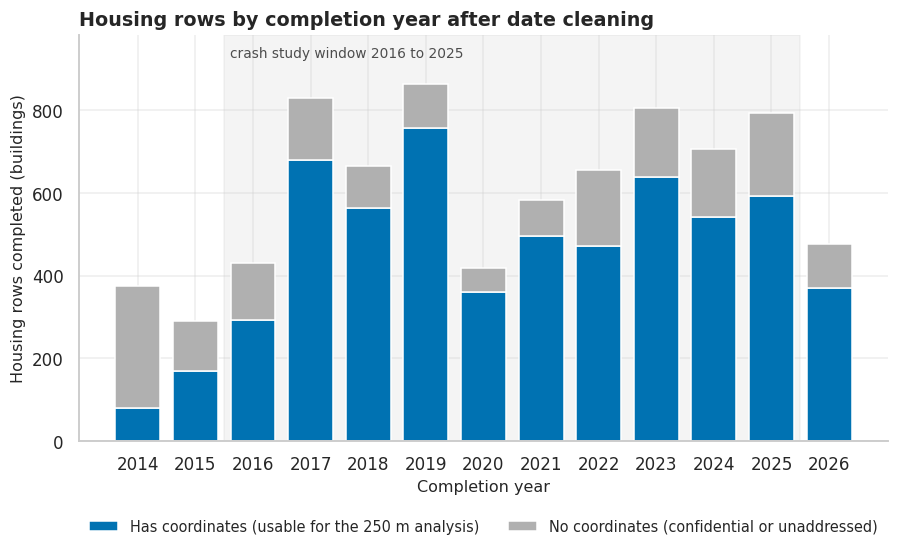

In [48]:
def plot_completions_by_year(completions):
    """Stacked bars of completed housing rows per year, split by whether the row has coordinates."""
    fig, ax = plt.subplots(figsize=(9.5, 4.8))
    ax.bar(completions.index, completions["located"], color=PALETTE["housing"],
           width=0.78, label="Has coordinates (usable for the 250 m analysis)")
    ax.bar(completions.index, completions["not located"],
           bottom=completions["located"], color=PALETTE["before"], width=0.78,
           label="No coordinates (confidential or unaddressed)")
    ax.set_ylim(0, completions.sum(axis=1).max() * 1.14)   # headroom for the window label
    ax.axvspan(YEAR_START - 0.5, YEAR_END + 0.5, color=PALETTE["neutral"], alpha=0.06, zorder=0)
    ax.text(YEAR_START - 0.4, ax.get_ylim()[1] * 0.97, f"crash study window {YEAR_START} to {YEAR_END}",
            fontsize=9, color=PALETTE["neutral"], va="top")
    ax.set_xticks(completions.index)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2)
    finish(ax, "Housing rows by completion year after date cleaning", "Completion year",
           "Housing rows completed (buildings)")
    plt.show()


completed_housing = housing[housing["is_completed"]]
completions_by_year = (completed_housing.groupby(["completion_year", "is_located"]).size()
                       .unstack(fill_value=0).rename(columns={True: "located", False: "not located"}))
plot_completions_by_year(completions_by_year)

In [49]:
located_share_by_year = 100 * completions_by_year["located"] / completions_by_year.sum(axis=1)
in_window = completed_housing["completion_year"].between(YEAR_START, YEAR_END)
say(f"{int(housing['is_completed'].sum()):,} rows have a completion year, from "
    f"{int(completions_by_year.index.min())} to {int(completions_by_year.index.max())}. "
    f"{int(in_window.sum()):,} of them fall inside the crash window, and "
    f"{int((in_window & completed_housing['is_located']).sum()):,} of those are located. The located share "
    f"is lowest in {int(located_share_by_year.idxmin())} ({located_share_by_year.min():.0f}%) and highest in "
    f"{int(located_share_by_year.idxmax())} ({located_share_by_year.max():.0f}%).")

7,898 rows have a completion year, from 2014 to 2026. 6,756 of them fall inside the crash window, and 5,399 of those are located. The located share is lowest in 2014 (21%) and highest in 2019 (88%).

Completions are spread over every year of the crash window, so before/after comparisons are
possible for many cohorts. The unlocated share is not constant: it is larger in the earliest
years, when more records were withheld. The last year on the axis lies after the crash window
and is incomplete, so those buildings can only serve as not-yet-completed comparison sites.

### 4.5 Housing: unit consistency and derived unit measures

The same units are counted three ways in each row (by income band, by bedroom count and by
tenure), and each of the three should add up to `all_counted_units`. That total in turn cannot
exceed `total_units`, which also includes market-rate units in the building. These identities
test the zero fill of 4.1: if a blank had meant unknown, the sums would fall short.

Two measures are derived for the research questions. `deep_affordable_units` is the number of
extremely low and very low income units. `deep_affordable_share` divides it by the counted
units. Where a row has no counted units the share is undefined and is left missing; writing zero
there would claim that a building has no deeply affordable units when the truth is that it has
no income-restricted units of any kind on record. The construction type becomes a two-level
category.

In [50]:
def check_and_derive_units(frame, raw):
    """Verify the unit identities, then add construction_type and the deep-affordability measures."""
    frame = frame.copy()
    counted = frame["all_counted_units"]
    checks = {
        "income bands sum to counted units": int((frame[INCOME_UNIT_COLUMNS].sum(axis=1) != counted).sum()),
        "bedroom counts sum to counted units": int((frame[BEDROOM_UNIT_COLUMNS].sum(axis=1) != counted).sum()),
        "rental + homeownership = counted units": int((frame[TENURE_UNIT_COLUMNS].sum(axis=1) != counted).sum()),
        "counted units exceed total units": int((counted > frame["total_units"]).sum()),
        "total units below 1": int((frame["total_units"] < 1).sum()),
    }
    construction = raw["reporting_construction_type"].str.strip().str.title()
    frame["construction_type"] = pd.Categorical(construction, categories=["New Construction", "Preservation"])
    frame["deep_affordable_units"] = frame[DEEP_AFFORDABLE_COLUMNS].sum(axis=1).astype("int16")
    # A share needs a denominator: rows with zero counted units get NaN, not 0.
    frame["deep_affordable_share"] = (frame["deep_affordable_units"] / counted.where(counted > 0)).astype("float64")
    return frame, checks


housing, unit_checks = check_and_derive_units(housing, housing_source)
display(pd.DataFrame({"rows violating": unit_checks}))
for check_name, violations in unit_checks.items():
    log_rule("housing", f"unit consistency check: {check_name}", "flag", len(housing), len(housing),
             violations, "Identity that must hold if blank means zero; affected counts violations.")
    assert violations == 0, f"unit identity broken: {check_name}"

no_counted_units = int((housing["all_counted_units"] == 0).sum())
log_rule("housing", "deep_affordable_share left missing where counted units = 0", "flag",
         len(housing), len(housing), no_counted_units, "A share with a zero denominator is undefined.")
assert housing["construction_type"].notna().all()
assert housing["deep_affordable_share"].dropna().between(0, 1).all()
assert housing["deep_affordable_share"].isna().sum() == no_counted_units

construction_table = (housing.groupby("construction_type", observed=True)
                      .agg(rows=("housing_id", "size"), total_units=("total_units", "sum"),
                           counted_units=("all_counted_units", "sum"),
                           deep_affordable_units=("deep_affordable_units", "sum")))
display(construction_table)
say(f"All five identities hold in every one of the {len(housing):,} rows. Counted units are below total "
    f"units in {int((housing['all_counted_units'] < housing['total_units']).sum()):,} rows (buildings that "
    f"mix affordable and market-rate units), and {no_counted_units} rows have no counted units, so their "
    f"deep-affordable share is missing. Across the table "
    f"{pct(housing['deep_affordable_units'].sum(), housing['all_counted_units'].sum()):.1f}% of counted units "
    f"are deeply affordable.")

,rows violating
income bands sum to counted units,0
bedroom counts sum to counted units,0
rental + homeownership = counted units,0
counted units exceed total units,0
total units below 1,0


,rows,total_units,counted_units,deep_affordable_units
construction_type,,,,
New Construction,4766,245921,131448,43811
Preservation,4785,199667,189498,101738


All five identities hold in every one of the 9,551 rows. Counted units are below total units in 2,781 rows (buildings that mix affordable and market-rate units), and 29 rows have no counted units, so their deep-affordable share is missing. Across the table 45.3% of counted units are deeply affordable.

No row breaks an identity, which confirms that blank means zero and that the table is internally
consistent. A repair rule for totals below their parts would have nothing to act on, so none is
written. The two construction types have nearly the same number of rows, which matters for RQ5,
where preservation serves as the comparison group.

### 4.6 Housing: size outliers

Building size is the explanatory variable of RQ4, which asks whether a larger building changes
the street more, so extreme values need a decision. Tukey's rule marks
a value as an outlier when it lies more than 1.5 interquartile ranges above the upper quartile.
The rule assumes a roughly symmetric distribution. Building sizes are strongly right-skewed
(many small houses, a few towers), so the rule is applied twice: on the unit count as it is, and
on its base-10 logarithm, where the distribution is closer to symmetric.

The decision is to flag and keep. The largest records were checked by name in the output below
and are real, well-known developments, and removing or capping them would delete exactly the
buildings where a change in street activity is most likely to be visible. Analyses that are
sensitive to a long tail can use the flag or the `size_band` category, which cuts the size into
five ordered bands.

In [51]:
def flag_size_outliers(frame):
    """Add is_size_outlier (raw-scale Tukey fence) and size_band; return (frame, fences)."""
    frame = frame.copy()
    units = frame["total_units"].astype("float64")
    raw_fence = tukey_upper_fence(units)
    # On the log scale the fence is computed in log units and converted back to a unit count.
    log_fence = 10 ** tukey_upper_fence(np.log10(units))
    frame["is_size_outlier"] = (units > raw_fence).to_numpy()
    frame["size_band"] = pd.cut(units, bins=SIZE_BAND_EDGES, labels=SIZE_BAND_LABELS, ordered=True)
    return frame, {"raw": raw_fence, "log": log_fence, "above_log": int((units > log_fence).sum())}


housing, size_fences = flag_size_outliers(housing)
log_rule("housing", "total_units above the Tukey fence flagged (is_size_outlier), not removed", "flag",
         len(housing), len(housing), int(housing["is_size_outlier"].sum()),
         "Large buildings are real and are the cases RQ4 needs; the fence marks the skewed tail.")
assert housing["size_band"].notna().all()

display(housing.nlargest(5, "total_units")[["project_name", "borough", "total_units", "all_counted_units",
                                             "construction_type", "completion_year"]])
display(housing.groupby("size_band", observed=True)
        .agg(rows=("housing_id", "size"), total_units=("total_units", "sum"),
             flagged=("is_size_outlier", "sum")))

,project_name,borough,total_units,all_counted_units,construction_type,completion_year
226,25 WATER STREET,Manhattan,1320,330,New Construction,2026
4865,605 WEST 42ND ST,Manhattan,1175,235,New Construction,2016
4866,605 WEST 42ND STREET PHASE II,Manhattan,1175,59,New Construction,2017
5196,5 POINTZ LIC,Queens,1122,337,New Construction,2023
6729,12 ROCKWELL PLACE,Brooklyn,1046,227,New Construction,<NA>


,rows,total_units,flagged
size_band,,,
1-4,2821,4551,0
5-19,2806,29723,0
20-49,1682,52942,0
50-149,1427,123171,356
150+,815,235201,815


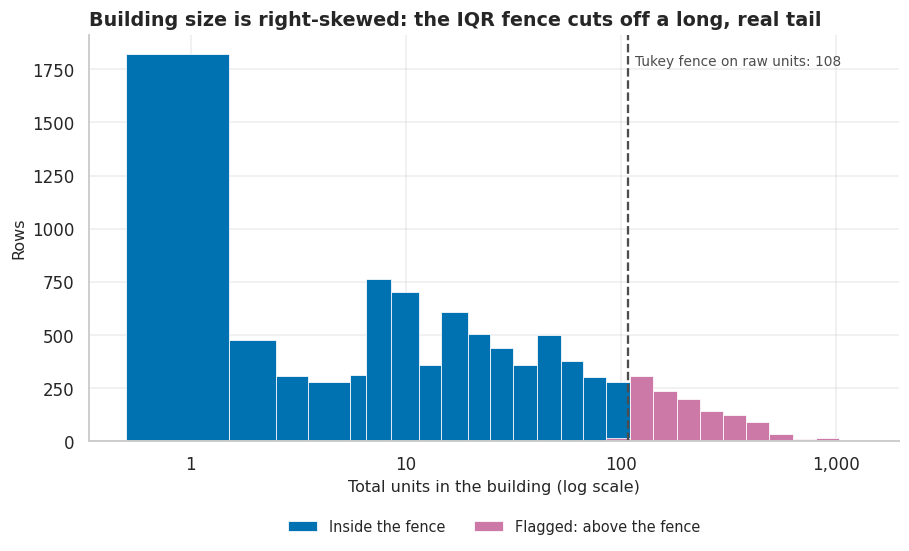

In [52]:
def plot_size_outliers(frame, fences):
    """Log-binned histogram of total_units with the rows above the Tukey fence drawn in a flag colour."""
    size_bins = integer_log_bins(frame["total_units"].max())
    fig, ax = plt.subplots(figsize=(9.5, 4.8))
    ax.hist(frame.loc[~frame["is_size_outlier"], "total_units"], bins=size_bins,
            color=PALETTE["housing"], edgecolor="white", linewidth=0.5, label="Inside the fence")
    # A data-quality flag gets its own colour (not the amber of Preservation and the placebo).
    ax.hist(frame.loc[frame["is_size_outlier"], "total_units"], bins=size_bins,
            color=PALETTE["accent"], edgecolor="white", linewidth=0.5, label="Flagged: above the fence")
    ax.axvline(fences["raw"], color=PALETTE["neutral"], linestyle="--", linewidth=1.5)
    ax.text(fences["raw"] * 1.08, ax.get_ylim()[1] * 0.95,
            f"Tukey fence on raw units: {fences['raw']:.0f}", fontsize=9, color=PALETTE["neutral"], va="top")
    ax.set_xscale("log")
    thousands(ax, axis="x")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2)
    finish(ax, "Building size is right-skewed: the IQR fence cuts off a long, real tail",
           "Total units in the building (log scale)", "Rows")
    plt.show()


plot_size_outliers(housing, size_fences)

In [53]:
say(f"The raw-scale fence is {size_fences['raw']:.0f} units and flags "
    f"{int(housing['is_size_outlier'].sum()):,} rows ({pct(housing['is_size_outlier'].sum(), len(housing)):.1f}% "
    f"of the table), which together hold "
    f"{pct(housing.loc[housing['is_size_outlier'], 'total_units'].sum(), housing['total_units'].sum()):.0f}% of "
    f"all units. On the log scale the fence moves to {size_fences['log']:,.0f} units and flags "
    f"{size_fences['above_log']} rows; the largest building has {int(housing['total_units'].max()):,} units. "
    f"The median is {housing['total_units'].median():.0f} units.")

The raw-scale fence is 108 units and flags 1,171 rows (12.3% of the table), which together hold 63% of all units. On the log scale the fence moves to 2,614 units and flags 0 rows; the largest building has 1,320 units. The median is 12 units.

A rule that flags this large a share of a table is not finding errors. On the raw scale the IQR
fence only measures how skewed building sizes are, and on the log scale, where the rule's
assumption is closer to true, no building is extreme at all. The histogram shows a continuous
tail with no isolated values beyond it. The flag is therefore read as "large building", and it
is kept because those rows hold most of the units even though they are a small share of the rows.
The histogram is the one drawn in 3.1.5 with the decision applied: the flagged rows are coloured.

### 4.7 Crashes: key, duplicates, dates and time of day

Rows are dropped from the crash table for three reasons only: no `collision_id`, a repeated
`collision_id`, or a crash date that cannot be parsed or lies outside the study window. Each
test is applied and logged even though the extraction already filtered on the date, so a changed
download cannot slip through. A unique key also rules out full-row duplicates, since two
identical rows would share their key.

A weaker kind of duplicate has to be considered as well: the same crash filed twice under two
identifiers. Such pairs would agree on date, time, coordinates, first vehicle type and number of
injured. These are counted and flagged with `is_possible_duplicate`, but kept, because two
separate crashes at a busy junction within the same reported minute would look exactly the same
and the table has no field that tells the two cases apart.

The crash time is text in hours and minutes without a leading zero. The hour is extracted as a
nullable small integer and grouped into four named six-hour bands for the time-of-day question.

In [54]:
def select_crash_rows(raw):
    """Apply the three row-dropping rules; return (kept raw rows, collision_id, crash_date)."""
    collision_id = pd.to_numeric(raw["collision_id"], errors="coerce").astype("float64")
    has_id = collision_id.notna()
    log_rule("crashes", "missing or non-numeric collision_id", "drop", len(raw), int(has_id.sum()),
             int((~has_id).sum()), "A crash without a key cannot be counted once and only once.")

    is_repeat = has_id & collision_id.duplicated(keep="first")
    log_rule("crashes", "duplicate collision_id (first kept)", "drop", int(has_id.sum()),
             int((has_id & ~is_repeat).sum()), int(is_repeat.sum()),
             "One row per collision; a repeat would double count its casualties.")

    crash_date = pd.to_datetime(raw["crash_date"], format=DATE_FORMAT, errors="coerce")
    in_window = crash_date.dt.year.between(YEAR_START, YEAR_END)
    keep = has_id & ~is_repeat & in_window
    log_rule("crashes", f"crash_date unparseable or outside {YEAR_START}-{YEAR_END}", "drop",
             int((has_id & ~is_repeat).sum()), int(keep.sum()), int((has_id & ~is_repeat & ~in_window).sum()),
             "Only full calendar years are comparable.")

    if keep.all():      # the usual case: avoid copying 1.5 million text rows
        return raw, collision_id.astype("int64"), crash_date
    kept = raw.loc[keep].reset_index(drop=True)
    return kept, collision_id[keep].astype("int64").reset_index(drop=True), crash_date[keep].reset_index(drop=True)


def hour_to_band(hour):
    """Map an hour to its named band from HOUR_BANDS as an ordered category (missing stays missing)."""
    band = pd.Series(np.nan, index=hour.index, dtype=object)
    for band_name, (first_hour, last_hour) in HOUR_BANDS.items():
        band[hour.between(first_hour, last_hour).fillna(False).to_numpy()] = band_name
    return pd.Categorical(band, categories=list(HOUR_BANDS), ordered=True)


crash_rows_raw = len(raw_crashes)
crash_columns_raw = raw_crashes.shape[1]
crash_memory_raw = memory_mb(raw_crashes)

crash_source, crash_ids, crash_dates = select_crash_rows(raw_crashes)
crash_hour, crash_minute = parse_hour(crash_source["crash_time"])

crashes = pd.DataFrame({
    "collision_id": crash_ids.to_numpy(),
    "crash_date": crash_dates.to_numpy(),
    "year": crash_dates.dt.year.astype("int16").to_numpy(),
    "month": crash_dates.dt.month.astype("int8").to_numpy(),
})
crashes["hour"] = crash_hour
crashes["hour_band"] = hour_to_band(crashes["hour"])

log_rule("crashes", "crash_date parsed to datetime; year and month derived", "standardise",
         len(crashes), len(crashes), 0, "Text dates cannot be grouped by year.")
log_rule("crashes", "crash_time to hour (Int8) and four named hour bands; invalid time left missing",
         "standardise", len(crashes), len(crashes), int(crashes["hour"].isna().sum()),
         "Time of day is analysed in bands; affected counts invalid times.")

assert crashes["collision_id"].is_unique
assert crashes["year"].between(YEAR_START, YEAR_END).all()
assert crashes["hour"].dropna().between(0, 23).all()
assert crashes["hour_band"].isna().sum() == crashes["hour"].isna().sum()

say(f"Rows in: {crash_rows_raw:,}. Rows out: {len(crashes):,}. The three dropping rules removed "
    f"{crash_rows_raw - len(crashes)} rows: collision_id is present and unique in every row and every date "
    f"parses and lies between {crashes['crash_date'].min():%Y-%m-%d} and {crashes['crash_date'].max():%Y-%m-%d}.")
say(f"Invalid crash times: {int(crashes['hour'].isna().sum())}. Times are rounded by the people who record "
    f"them: {pct((crash_minute == 0).sum(), len(crashes)):.1f}% of crashes are logged exactly on the hour and "
    f"{pct((crash_minute % ROUNDING_STEP_MIN == 0).sum(), len(crashes)):.1f}% on a multiple of "
    f"{ROUNDING_STEP_MIN} minutes, against {100 / MINUTES_PER_HOUR:.1f}% and {100 / ROUNDING_STEP_MIN:.1f}% "
    f"if minutes were recorded evenly.")
display(crashes["hour_band"].value_counts(sort=False).rename("crashes").to_frame()
        .assign(share_pct=lambda table: (100 * table["crashes"] / len(crashes)).round(1)))

Rows in: 1,504,722. Rows out: 1,504,722. The three dropping rules removed 0 rows: collision_id is present and unique in every row and every date parses and lies between 2016-01-01 and 2025-12-31.

Invalid crash times: 0. Times are rounded by the people who record them: 19.6% of crashes are logged exactly on the hour and 73.5% on a multiple of 5 minutes, against 1.7% and 20.0% if minutes were recorded evenly.

,crashes,share_pct
hour_band,,
Night,173558,11.500
Morning,390790,26.000
Afternoon,562757,37.400
Evening,377617,25.100


The crash table needs no row removed: the key is complete and unique, and the dates and times
are all valid. The minute of the crash is clearly rounded, which is a reason to analyse time of
day in six-hour bands (and at most by hour) and never by minute. The next cell runs the check for
crashes that may have been filed twice.

In [55]:
def flag_possible_duplicates(raw):
    """Mark later copies of rows that agree on date, time, exact coordinates, vehicle and injuries.

    Only rows with a usable point (both coordinates inside the city, not at (0, 0)) are compared.
    Without a location, two different crashes in the same minute would match on almost nothing
    but the clock.
    """
    signature = ["crash_date", "crash_time", "latitude", "longitude", "vehicle_type_code1",
                 "number_of_persons_injured"]
    latitude, _, _, _ = validate_coordinates(raw["latitude"], raw["longitude"])
    has_point = latitude.notna().to_numpy()
    is_copy = np.zeros(len(raw), dtype=bool)
    is_copy[has_point] = raw.loc[has_point, signature].duplicated(keep="first").to_numpy()
    return is_copy


crashes["is_possible_duplicate"] = flag_possible_duplicates(crash_source)
log_rule("crashes", "same date, time, coordinates, vehicle type and injuries under another id "
         "(is_possible_duplicate)", "flag", len(crashes), len(crashes),
         int(crashes["is_possible_duplicate"].sum()),
         "May be a double filing or two real crashes at one junction; kept because they cannot be told apart.")
say(f"{int(crashes['is_possible_duplicate'].sum()):,} rows "
    f"({pct(crashes['is_possible_duplicate'].sum(), len(crashes)):.2f}%) repeat the date, time, coordinates, "
    f"first vehicle type and injury count of an earlier row under a different collision_id.")

1,916 rows (0.13%) repeat the date, time, coordinates, first vehicle type and injury count of an earlier row under a different collision_id.

The share is small enough that the choice between keeping and dropping these rows cannot move a
result, so they stay in and the flag is available for a sensitivity check.

### 4.8 Crashes: borough, ZIP code and coordinates

Location is where the crash table is weakest, and it is the part that integration depends on.

Borough is written in upper case here and in title case in the housing table. It is converted to
the same category, so the two tables agree letter for letter.

The ZIP code goes through the same validator as the housing postcode. Three kinds of value are
set to missing: blanks, the placeholder 10000 (which is not a real ZIP and would otherwise form
a fake neighbourhood of its own), and codes outside the city. The crash row itself is kept in
every case: it still has a date, casualties and usually coordinates.

Coordinates are checked against `NYC_BOUNDS`. A pair at exactly (0, 0) is what a failed geocode
(an automatic address lookup) leaves behind, and a point outside the box cannot be a New York crash. Both are set to missing, not
clipped to the box edge, since clipping would pile crashes onto streets at the boundary. The
flag `is_located` marks rows with usable coordinates.

Missing ZIP codes are not filled at this stage. Most rows without a ZIP still have coordinates,
so the ZIP can be recovered from the surrounding crashes, but that is an integration problem and
is solved in Section 6, where its accuracy is measured on held-out rows.

In [56]:
def clean_crash_geography(raw, frame):
    """Add borough, zip, lat, lon and is_located to a copy of the crash frame; return (frame, report)."""
    frame = frame.copy()
    borough_text = raw["borough"].str.strip().str.title()
    frame["borough"] = pd.Categorical(borough_text, categories=BOROUGHS)

    zip_text = raw["zip_code"].str.strip()
    clean_zip, implied_borough = standardise_zip(raw["zip_code"])
    frame["zip"] = clean_zip
    rejected = (zip_text.notna() & clean_zip.isna()).to_numpy()

    lat, lon, n_zero, n_outside = validate_coordinates(raw["latitude"], raw["longitude"])
    frame["lat"], frame["lon"] = lat.to_numpy(), lon.to_numpy()
    frame["is_located"] = frame["lat"].notna().to_numpy()

    stated = frame["borough"].astype(object)
    disagree = (implied_borough.notna().to_numpy() & stated.notna().to_numpy()
                & (implied_borough.to_numpy() != stated.to_numpy()))
    report = {
        "borough_raw_present": int(raw["borough"].notna().sum()),
        "borough_unrecognised": int(raw["borough"].notna().sum() - frame["borough"].notna().sum()),
        "zip_raw_missing": int(raw["zip_code"].isna().sum()),
        "zip_blank": int((zip_text == "").sum()),
        "zip_placeholder": int((zip_text == ZIP_PLACEHOLDER).sum()),
        "zip_rejected": int(rejected.sum()),
        "zip_rejected_values": zip_text[rejected].value_counts().head(6),
        "coordinates_raw_missing": int(raw["latitude"].isna().sum()),
        "coordinates_zero": n_zero, "coordinates_outside": n_outside,
        "zip_borough_disagree": int(disagree.sum()),
        "disagree_zips": frame.loc[disagree, "zip"].value_counts().head(5),
        "border_zip_boroughs": frame.loc[frame["zip"].isin(["11001", "11040"]), "borough"]
                               .value_counts().loc[lambda counts: counts > 0],
    }
    return frame, report


raw_coordinate_sample = crash_source[["latitude", "longitude"]].apply(to_number)
crashes, crash_geo_report = clean_crash_geography(crash_source, crashes)

log_rule("crashes", "borough to title case, category with the BOROUGHS spelling", "standardise",
         len(crashes), len(crashes), crash_geo_report["borough_raw_present"],
         "Upper case here, title case in housing; one spelling is needed to compare boroughs.")
log_rule("crashes", "zip_code blank, placeholder 10000 or outside NYC ranges set to missing",
         "standardise", len(crashes), len(crashes), crash_geo_report["zip_rejected"],
         "Junk codes would form fake neighbourhoods in the ZIP panel; the crash row is kept.")
log_rule("crashes", "coordinates at (0,0) set to missing", "standardise", len(crashes), len(crashes),
         crash_geo_report["coordinates_zero"], "A failed geocode leaves this placeholder; it marks no place.")
log_rule("crashes", "coordinates outside NYC_BOUNDS set to missing", "standardise", len(crashes),
         len(crashes), crash_geo_report["coordinates_outside"],
         "Domain rule: a crash in this table cannot lie outside the city; clipping would misplace it.")
log_rule("crashes", "rows without usable coordinates flagged (is_located = False)", "flag",
         len(crashes), len(crashes), int((~crashes["is_located"]).sum()),
         "Kept for borough and ZIP totals; excluded from distance-based analyses.")
log_rule("crashes", "missing zip left missing at this stage", "flag", len(crashes), len(crashes),
         int(crashes["zip"].isna().sum()),
         "Recovered from coordinates after integration (Section 6), where accuracy can be tested.")
log_rule("crashes", "ZIP range borough differs from stated borough (stated borough kept)", "flag",
         len(crashes), len(crashes), crash_geo_report["zip_borough_disagree"],
         "Checked only; ZIPs on the Brooklyn / Queens line cross the borough boundary.")

assert crashes.loc[crashes["is_located"], "lat"].between(*NYC_BOUNDS["lat"]).all()
assert crashes.loc[crashes["is_located"], "lon"].between(*NYC_BOUNDS["lon"]).all()
assert crashes["zip"].dropna().str.len().eq(5).all()
assert ZIP_PLACEHOLDER not in set(crashes["zip"].dropna().unique())

borough_before_after = pd.DataFrame({
    "raw spelling": crash_source["borough"].value_counts(dropna=False).rename(lambda v: v if pd.notna(v) else "(missing)"),
})
borough_before_after["clean spelling"] = [value.title() if value != "(missing)" else "(missing)"
                                          for value in borough_before_after.index]
borough_before_after["rows after"] = [
    int(crashes["borough"].isna().sum()) if value == "(missing)" else int((crashes["borough"] == value).sum())
    for value in borough_before_after["clean spelling"]]
display(borough_before_after.rename(columns={"raw spelling": "rows before"}))
display(crash_geo_report["zip_rejected_values"].rename("rows").to_frame().rename_axis("rejected zip_code"))

say(f"ZIP: {crash_geo_report['zip_raw_missing']:,} rows had none to begin with. Of the rest, "
    f"{crash_geo_report['zip_rejected']:,} were rejected ({crash_geo_report['zip_placeholder']} of them the "
    f"10000 placeholder, {crash_geo_report['zip_blank']} blank strings). After cleaning "
    f"{int(crashes['zip'].isna().sum()):,} rows ({pct(crashes['zip'].isna().sum(), len(crashes)):.1f}%) have no "
    f"ZIP and {crashes['zip'].nunique()} distinct ZIPs remain.")
say(f"Coordinates: {crash_geo_report['coordinates_raw_missing']:,} rows had none, "
    f"{crash_geo_report['coordinates_zero']:,} were at (0,0) and {crash_geo_report['coordinates_outside']} lay "
    f"outside the city box. After cleaning {int(crashes['is_located'].sum()):,} rows "
    f"({pct(crashes['is_located'].sum(), len(crashes)):.1f}%) are located.")
say(f"Borough is missing in {int(crashes['borough'].isna().sum()):,} rows "
    f"({pct(crashes['borough'].isna().sum(), len(crashes)):.1f}%); "
    f"{int((crashes['borough'].notna() & crashes['zip'].isna()).sum()):,} rows have a borough but no valid ZIP "
    f"and {int((crashes['borough'].isna() & crashes['zip'].notna()).sum())} the reverse, so the two fields are "
    f"missing together. The ZIP range and the stated borough disagree in "
    f"{crash_geo_report['zip_borough_disagree']} rows, mostly in ZIP "
    f"{join_and(crash_geo_report['disagree_zips'].index[:3])}. The two ZIPs shared with Nassau County carry "
    f"{int(crash_geo_report['border_zip_boroughs'].sum())} crashes, "
    f"{'all ' if len(crash_geo_report['border_zip_boroughs']) == 1 else ''}recorded in "
    f"{join_and(crash_geo_report['border_zip_boroughs'].index.astype(str))}.")

,rows before,clean spelling,rows after
borough,,,
(missing),508028,(missing),508028
BROOKLYN,328165,Brooklyn,328165
QUEENS,273373,Queens,273373
MANHATTAN,197086,Manhattan,197086
BRONX,159330,Bronx,159330
STATEN ISLAND,38740,Staten Island,38740


,rows
rejected zip_code,
10000,637
12345,1


ZIP: 508,284 rows had none to begin with. Of the rest, 638 were rejected (637 of them the 10000 placeholder, 0 blank strings). After cleaning 508,922 rows (33.8%) have no ZIP and 231 distinct ZIPs remain.

Coordinates: 125,582 rows had none, 6,769 were at (0,0) and 149 lay outside the city box. After cleaning 1,372,222 rows (91.2%) are located.

Borough is missing in 508,028 rows (33.8%); 894 rows have a borough but no valid ZIP and 0 the reverse, so the two fields are missing together. The ZIP range and the stated borough disagree in 322 rows, mostly in ZIP 11237, 11208 and 11385. The two ZIPs shared with Nassau County carry 817 crashes, all recorded in Queens.

Borough and ZIP are missing in the same rows, which fits a record where the officer gave a
location on a highway or bridge without a postal address. The disagreements between ZIP range
and stated borough sit in ZIPs that lie across the Brooklyn and Queens boundary, so they are
real places and the stated borough is left as it is. The two ZIPs shared with Nassau County are
kept because every crash that carries them is recorded in Queens.

The first figure validates the coordinate rule. The left panel counts what happened to every raw
coordinate pair. The right panel draws a sample of the cleaned points, coloured and labelled by
borough, with the points that have no borough drawn as hollow black rings.

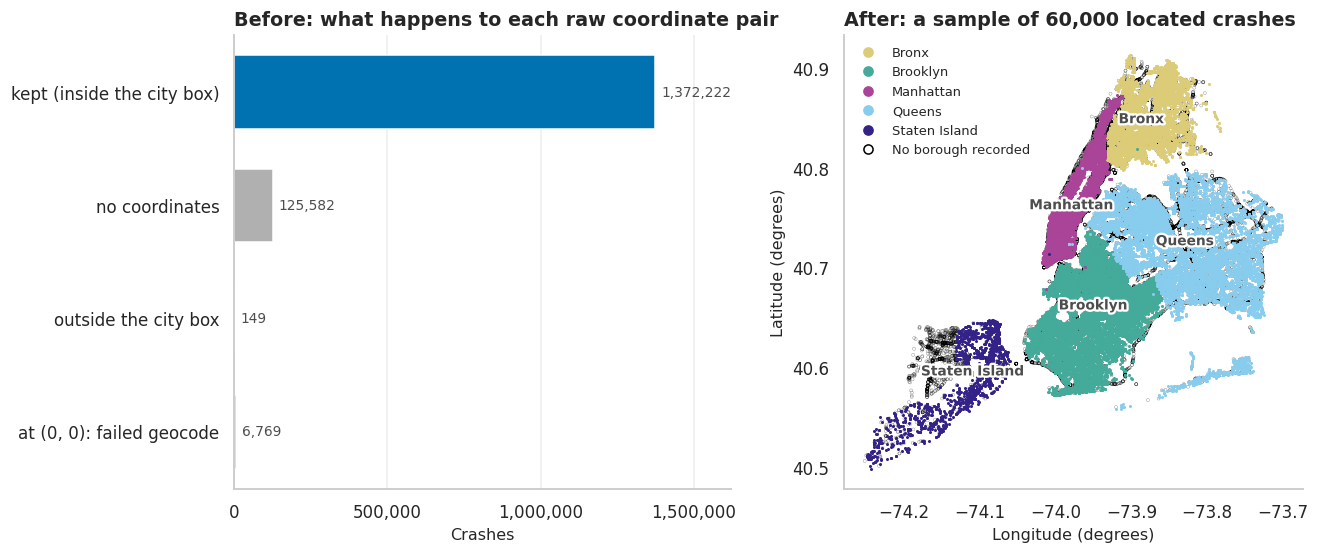

In [57]:
raw_lat, raw_lon = raw_coordinate_sample["latitude"], raw_coordinate_sample["longitude"]
coordinate_outcomes = pd.Series({
    "kept (inside the city box)": int(crashes["is_located"].sum()),
    "no coordinates": crash_geo_report["coordinates_raw_missing"],
    "outside the city box": crash_geo_report["coordinates_outside"],
    "at (0, 0): failed geocode": crash_geo_report["coordinates_zero"],
})
assert coordinate_outcomes.sum() == len(crashes), "every raw coordinate pair has exactly one outcome"
map_sample = crashes[crashes["is_located"]].sample(MAP_SAMPLE_ROWS, random_state=SEED)


def plot_coordinate_cleaning(outcomes, sample):
    """Left: what happened to every raw coordinate pair. Right: a sample of the cleaned points.

    Boroughs carry a name on the map as well as a colour. Points with coordinates but no borough
    are hollow black rings, so they cannot be mistaken for the grey of Staten Island.
    """
    fig, (ax_outcome, ax_clean) = plt.subplots(1, 2, figsize=(12.5, 5.2), gridspec_kw={"width_ratios": [1, 1.1]})
    outcome_colors = [PALETTE["housing"], PALETTE["before"], PALETTE["accent"], PALETTE["crash"]]
    outcome_bars = ax_outcome.barh(outcomes.index[::-1], outcomes.to_numpy()[::-1],
                                   color=outcome_colors[::-1], height=0.65)
    ax_outcome.bar_label(outcome_bars, labels=[f"{value:,}" for value in outcomes.to_numpy()[::-1]],
                         padding=4, fontsize=9, color=PALETTE["neutral"])
    ax_outcome.set_xlim(0, outcomes.max() * 1.18)
    thousands(ax_outcome, axis="x")
    ax_outcome.xaxis.set_major_locator(mpl.ticker.MaxNLocator(nbins=4))
    ax_outcome.grid(axis="y", visible=False)
    finish(ax_outcome, "Before: what happens to each raw coordinate pair", "Crashes", "")

    legend_handles = []
    for borough_name in BOROUGHS:
        points = sample.loc[sample["borough"] == borough_name]
        ax_clean.scatter(points["lon"], points["lat"], s=1, color=BOROUGH_COLORS[borough_name],
                         rasterized=True, zorder=2)
        ax_clean.text(points["lon"].median(), points["lat"].median(), borough_name, ha="center",
                      fontsize=9, fontweight="bold", color=PALETTE["neutral"], zorder=5,
                      path_effects=[patheffects.withStroke(linewidth=3, foreground="white")])
        legend_handles.append(mpl.lines.Line2D([], [], marker="o", linestyle="", markersize=6,
                                               color=BOROUGH_COLORS[borough_name], label=borough_name))
    no_borough = sample.loc[sample["borough"].isna()]
    ax_clean.scatter(no_borough["lon"], no_borough["lat"], s=4, facecolors="none", edgecolors="black",
                     linewidths=0.25, alpha=0.5, rasterized=True, zorder=1)
    legend_handles.append(mpl.lines.Line2D([], [], marker="o", linestyle="", markersize=6,
                                           markerfacecolor="none", markeredgecolor="black",
                                           label="No borough recorded"))
    map_axes(ax_clean)
    ax_clean.legend(handles=legend_handles, loc="upper left", fontsize=8.5)
    finish(ax_clean, f"After: a sample of {MAP_SAMPLE_ROWS:,} located crashes", "Longitude (degrees)",
           "Latitude (degrees)")
    plt.tight_layout()
    plt.show()


plot_coordinate_cleaning(coordinate_outcomes, map_sample)

In [58]:
raw_rejected_count = coordinate_outcomes["outside the city box"] + coordinate_outcomes["at (0, 0): failed geocode"]
say(f"{raw_rejected_count:,} coordinate pairs are rejected. Raw longitudes run from {raw_lon.min():.1f} to {raw_lon.max():.1f} degrees and raw latitudes from "
    f"{raw_lat.min():.1f} to {raw_lat.max():.1f}; after cleaning they run from {crashes['lon'].min():.3f} to "
    f"{crashes['lon'].max():.3f} and from {crashes['lat'].min():.3f} to {crashes['lat'].max():.3f}.")

6,918 coordinate pairs are rejected. Raw longitudes run from -201.4 to 0.0 degrees and raw latitudes from 0.0 to 43.3; after cleaning they run from -74.255 to -73.663 and from 40.499 to 40.913.

The few rejected pairs would have stretched any map or bounding box across half the globe, as
the raw ranges above show, and a distance calculation on them would have been meaningless. After
cleaning, the sample draws the outline
of the five boroughs and their street grid, and the borough colours sit where the boroughs are,
which checks the borough labels and the coordinates against each other. The hollow rings have
coordinates but no borough or ZIP, and they are the group whose ZIP Section 6 recovers.

The second figure shows which location fields each crash has left, by year.

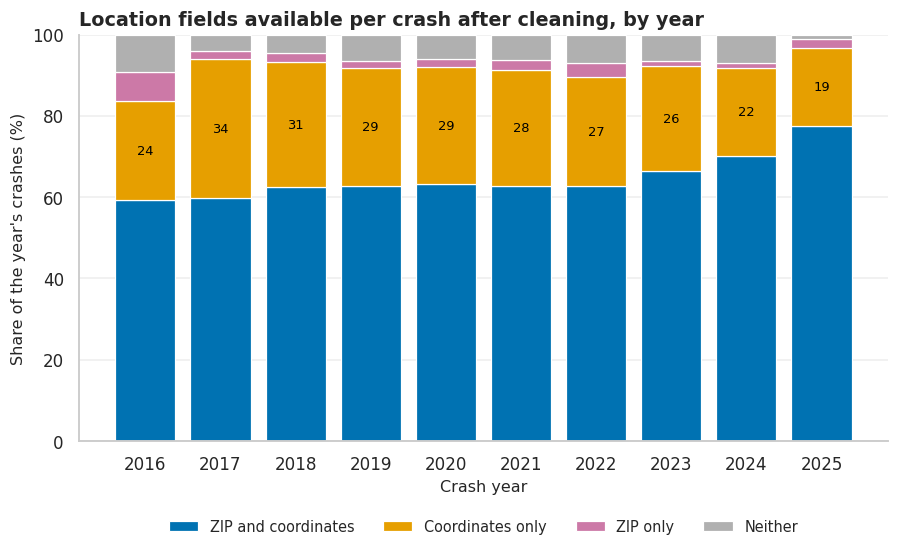

In [59]:
LOCATION_STATES = ["ZIP and coordinates", "Coordinates only", "ZIP only", "Neither"]
location_state = np.select(
    [crashes["zip"].notna() & crashes["is_located"], crashes["zip"].isna() & crashes["is_located"],
     crashes["zip"].notna() & ~crashes["is_located"]], LOCATION_STATES[:3], default=LOCATION_STATES[3])
location_by_year = (pd.crosstab(crashes["year"], location_state, normalize="index")
                    .reindex(columns=LOCATION_STATES, fill_value=0) * 100)
location_colors = [PALETTE["housing"], PALETTE["placebo"], PALETTE["accent"], PALETTE["before"]]


def plot_location_states(shares):
    """Stacked bars of the share of each year's crashes by which location fields survive cleaning."""
    fig, ax = plt.subplots(figsize=(9.5, 4.8))
    bar_bottom = np.zeros(len(shares))
    for state, color in zip(LOCATION_STATES, location_colors):
        ax.bar(shares.index, shares[state], bottom=bar_bottom, color=color,
               edgecolor="white", linewidth=0.8, width=0.8, label=state)
        bar_bottom += shares[state].to_numpy()
    for year, share in shares["Coordinates only"].items():
        label_height = shares.loc[year, "ZIP and coordinates"] + share / 2
        ax.text(year, label_height, f"{share:.0f}", ha="center", va="center", fontsize=8.5, color="black")
    ax.set_xticks(shares.index)
    ax.set_ylim(0, 100)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=4)
    finish(ax, "Location fields available per crash after cleaning, by year", "Crash year",
           "Share of the year's crashes (%)")
    plt.show()


plot_location_states(location_by_year)

In [60]:
location_counts = pd.Series(location_state).value_counts().reindex(LOCATION_STATES)
coordinates_only = location_by_year["Coordinates only"]
say(f"Across all years {pct(location_counts['ZIP and coordinates'], len(crashes)):.1f}% of crashes have both "
    f"fields, {pct(location_counts['Coordinates only'], len(crashes)):.1f}% have coordinates only "
    f"({location_counts['Coordinates only']:,} rows), {pct(location_counts['ZIP only'], len(crashes)):.1f}% "
    f"have a ZIP only and {pct(location_counts['Neither'], len(crashes)):.1f}% have neither. The "
    f"coordinates-only share ranges from {coordinates_only.min():.0f}% in {int(coordinates_only.idxmin())} to "
    f"{coordinates_only.max():.0f}% in {int(coordinates_only.idxmax())}.")

Across all years 63.3% of crashes have both fields, 27.9% have coordinates only (419,495 rows), 2.9% have a ZIP only and 5.9% have neither. The coordinates-only share ranges from 19% in 2025 to 34% in 2017.

The orange band is the reason ZIP recovery is worth doing: a large block of crashes has no ZIP
but does have a point, and its size changes from year to year. A ZIP-level count built from the
blue band alone would rise and fall with reporting practice and not only with crashes. The
decision taken here is to leave these ZIPs missing and to keep the rows, so that Section 6 can
fill them from coordinates and test the fill. Dropping them now would remove a share of crashes
that differs by year, which is worse than either alternative. Only the grey band is lost to
every geographic analysis below the city level.

### 4.9 Crashes: casualty counts, and totals that do not match their parts

Each crash has a total number of persons injured and killed, and the same two numbers broken
out for pedestrians, cyclists and motorists. The columns are first checked for the basic
properties of a count (whole, not negative) and converted to small integers.

A few totals are blank while the parts are present. The total is then imputed as the sum of
the parts, which is the definition of the field and not an estimate.

The total and the parts also disagree in a number of rows, in both directions.

Where the total is below the sum of the parts, the total is raised to that sum. The parts name
specific people, so they are the more detailed record, and a total cannot be smaller than what
it contains.

Where the total is above the sum of the parts, nothing is overwritten. The three roles do not
cover everyone who can be hurt: a rider of an e-scooter or e-bike is none of pedestrian, cyclist
or motorist in this table. Lowering the total to the sum of the parts would delete injured
people from the data, and adding the surplus to one of the three roles would be a guess. The
surplus is kept in its own columns, `other_injured` and `other_killed`, so that the eight
published counts stay as reported and the identity "total = pedestrians + cyclists + motorists
+ other" holds in every row. `casualty_mismatch` flags the rows involved.

In [61]:
def clean_casualties(raw):
    """Typed casualty counts with imputed totals, repaired deficits and the unclassified surplus.

    Returns (counts frame, report). The total is never lowered; see the text for the reasoning.
    """
    counts = pd.DataFrame({short: to_number(raw[column]) for column, short in CASUALTY_COLUMNS.items()})
    present = counts.stack()
    report = {"negative": int((present < 0).sum()), "fractional": int((present % 1 != 0).sum()),
              "above_fence": {}}
    assert report["negative"] == 0 and report["fractional"] == 0, "casualty counts must be whole and >= 0"

    for outcome in ["injured", "killed"]:
        part_columns = [f"{prefix}_{outcome}" for prefix in ROAD_USER_PREFIXES]
        assert counts[part_columns].notna().all().all(), "role counts are expected to be complete"
        parts_sum = counts[part_columns].sum(axis=1)
        reported = counts[outcome]
        report[f"{outcome}_missing"] = int(reported.isna().sum())
        report[f"{outcome}_deficit"] = int((reported < parts_sum).sum())
        report[f"{outcome}_surplus"] = int((reported > parts_sum).sum())
        report[f"{outcome}_surplus_people"] = int((reported - parts_sum).clip(lower=0).sum())
        # Missing total -> sum of parts (comparison with NaN is False, so fillna comes first);
        # total below its parts -> raised to the parts; total above its parts -> left as reported.
        counts[outcome] = np.maximum(reported.fillna(parts_sum), parts_sum)
        counts[f"other_{outcome}"] = counts[outcome] - parts_sum
        report[f"{outcome}_mismatch_mask"] = ((reported != parts_sum) & reported.notna()).to_numpy()
        report[f"{outcome}_surplus_mask"] = (reported > parts_sum).to_numpy()
        report[f"{outcome}_deficit_mask"] = (reported < parts_sum).to_numpy()

    # The narrow integer type is only safe while every count fits in it; a wrap would be silent.
    assert counts.max().max() <= np.iinfo(np.int8).max, "a casualty count no longer fits in int8"
    counts = counts.astype("int8")
    counts["casualty_mismatch"] = report["injured_mismatch_mask"] | report["killed_mismatch_mask"]
    return counts, report


casualties, casualty_report = clean_casualties(crash_source)
casualty_columns_clean = list(casualties.columns)
for column in casualty_columns_clean:
    crashes[column] = casualties[column].to_numpy()
crashes["is_injury_crash"] = ((crashes["injured"].astype("int16") + crashes["killed"]) > 0).to_numpy()
crashes["ped_cyc_harm"] = ((crashes[["ped_injured", "ped_killed", "cyc_injured", "cyc_killed"]]
                            .sum(axis=1)) > 0).to_numpy()

log_rule("crashes", "eight casualty columns to small integers; checked whole and non-negative",
         "standardise", len(crashes), len(crashes), casualty_report["negative"] + casualty_report["fractional"],
         "Counts were text; affected counts negative or fractional values.")
log_rule("crashes", "missing persons injured / killed total = sum of pedestrians, cyclists, motorists",
         "impute", len(crashes), len(crashes),
         casualty_report["injured_missing"] + casualty_report["killed_missing"],
         "The total is defined as the sum of its parts, so the fill is exact.")
log_rule("crashes", "persons total below the sum of its parts raised to the sum", "impute",
         len(crashes), len(crashes), casualty_report["injured_deficit"] + casualty_report["killed_deficit"],
         "A total cannot be smaller than the people it contains.")
log_rule("crashes", "persons total above the sum of its parts kept; surplus stored in other_injured / "
         "other_killed and flagged (casualty_mismatch)", "flag", len(crashes), len(crashes),
         casualty_report["injured_surplus"] + casualty_report["killed_surplus"],
         "The surplus is people outside the three roles (for example e-scooter riders); lowering "
         "the total would delete them.")

# Checks against the raw columns, so they can fail: the people counted after cleaning must equal the
# reported totals plus the imputed totals plus the deficits that were raised, and a row that was
# not flagged as a mismatch must have no unclassified people.
for outcome, raw_column in [("injured", "number_of_persons_injured"), ("killed", "number_of_persons_killed")]:
    reported_total = to_number(crash_source[raw_column]).to_numpy()
    parts_total = crashes[[f"{prefix}_{outcome}" for prefix in ROAD_USER_PREFIXES]].sum(axis=1).to_numpy()
    is_reported = ~np.isnan(reported_total)
    imputed_people = int(parts_total[~is_reported].sum())
    raised_people = int(np.clip(parts_total[is_reported] - reported_total[is_reported], 0, None).sum())
    assert int(crashes[outcome].sum()) == int(reported_total[is_reported].sum()) + imputed_people + raised_people
    assert (crashes.loc[~crashes["casualty_mismatch"], f"other_{outcome}"] == 0).all()
assert (crashes[[c for c in casualty_columns_clean if c != "casualty_mismatch"]] >= 0).all().all()
# The cleaned totals must line up row by row with the raw reported totals: a total is never lowered.
assert (crashes["injured"].to_numpy() >= to_number(crash_source["number_of_persons_injured"]).fillna(0).to_numpy()).all()

casualty_table = pd.DataFrame({
    "total missing (imputed)": [casualty_report["injured_missing"], casualty_report["killed_missing"]],
    "total below parts (raised)": [casualty_report["injured_deficit"], casualty_report["killed_deficit"]],
    "total above parts (kept)": [casualty_report["injured_surplus"], casualty_report["killed_surplus"]],
    "people in the surplus": [casualty_report["injured_surplus_people"], casualty_report["killed_surplus_people"]],
    "people after cleaning": [int(crashes["injured"].sum()), int(crashes["killed"].sum())],
}, index=["injured", "killed"])
display(casualty_table)

,total missing (imputed),total below parts (raised),total above parts (kept),people in the surplus,people after cleaning
injured,18,227,10178,10876,550991
killed,36,6,74,75,2617


The explanation given for the surplus can be checked against the data. If the extra injured
people are riders of vehicles outside the three roles, then the first vehicle type in those rows
should look different from the first vehicle type in crashes generally, and the rows should be
concentrated in the years after such vehicles became common.

In [62]:
surplus_mask = casualty_report["injured_surplus_mask"]
vehicle_type = crash_source["vehicle_type_code1"].str.strip().str.title().fillna("(missing)")
vehicle_comparison = pd.DataFrame({
    "share of surplus rows (%)": 100 * vehicle_type[surplus_mask].value_counts(normalize=True),
    "share of all crashes (%)": 100 * vehicle_type.value_counts(normalize=True),
}).dropna().sort_values("share of surplus rows (%)", ascending=False).head(6).round(2)
display(vehicle_comparison)

,share of surplus rows (%),share of all crashes (%)
vehicle_type_code1,,
Sedan,30.920,43.020
Station Wagon/Sport Utility Vehicle,25.810,33.670
E-Scooter,15.700,0.180
E-Bike,13.990,0.280
(missing),3.270,1.030
Taxi,2.790,3.850


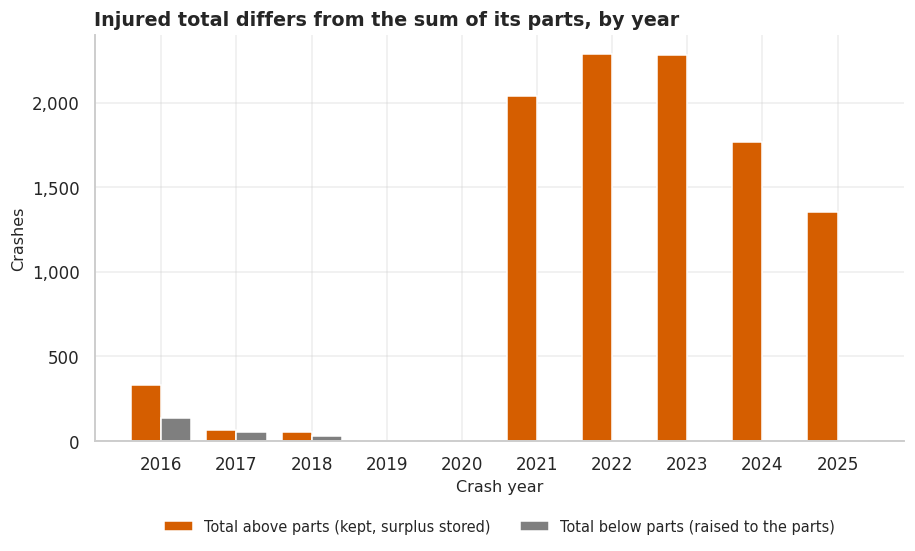

In [63]:
mismatch_by_year = pd.DataFrame({
    "Total above parts (kept, surplus stored)": pd.Series(surplus_mask).groupby(crashes["year"]).sum(),
    "Total below parts (raised to the parts)": pd.Series(casualty_report["injured_deficit_mask"])
                                               .groupby(crashes["year"]).sum(),
})


def plot_casualty_mismatch(by_year):
    """Paired bars per year: totals above their parts (kept) and totals below them (raised)."""
    fig, ax = plt.subplots(figsize=(9.5, 4.8))
    bar_width = 0.4
    ax.bar(by_year.index - bar_width / 2, by_year.iloc[:, 0], width=bar_width,
           color=PALETTE["crash"], label=by_year.columns[0])
    ax.bar(by_year.index + bar_width / 2, by_year.iloc[:, 1], width=bar_width,
           color=PALETTE["control"], label=by_year.columns[1])
    ax.set_xticks(by_year.index)
    thousands(ax)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2)
    finish(ax, "Injured total differs from the sum of its parts, by year", "Crash year",
           "Crashes")
    plt.show()


plot_casualty_mismatch(mismatch_by_year)

In [64]:
is_scooter_or_ebike = vehicle_type.isin(["E-Scooter", "E-Bike"]).to_numpy()
first_surplus_year = BREAK_YEAR + 1      # the surplus appears from here on, as the table above shows
last_error_year = BREAK_YEAR - 2         # the deficits cluster up to here
surplus_from_first_year = int(mismatch_by_year.loc[first_surplus_year:, mismatch_by_year.columns[0]].sum())
deficit_before_cutoff = int(mismatch_by_year.loc[:last_error_year, mismatch_by_year.columns[1]].sum())
say(f"The injured total exceeds its parts in {casualty_report['injured_surplus']:,} crashes "
    f"({pct(casualty_report['injured_surplus'], len(crashes)):.2f}% of all crashes), and "
    f"{pct(surplus_from_first_year, casualty_report['injured_surplus']):.0f}% of them fall in "
    f"{first_surplus_year} or later. An "
    f"e-scooter or e-bike is the first vehicle in {pct((is_scooter_or_ebike & surplus_mask).sum(), surplus_mask.sum()):.1f}% "
    f"of these rows against {pct(is_scooter_or_ebike.sum(), len(crashes)):.2f}% of all crashes. The opposite "
    f"case, a total below its parts, occurs in {casualty_report['injured_deficit']} crashes, "
    + ("all of them" if deficit_before_cutoff == casualty_report["injured_deficit"]
       else f"{deficit_before_cutoff} of them")
    + f" before {last_error_year + 1}. Keeping the "
    f"surplus preserves {casualty_report['injured_surplus_people']:,} injured people that a strict "
    f"\"parts only\" rule would have removed.")
say(f"After cleaning: {int(crashes['is_injury_crash'].sum()):,} injury crashes "
    f"({pct(crashes['is_injury_crash'].sum(), len(crashes)):.1f}% of crashes), "
    f"{int(crashes['ped_cyc_harm'].sum()):,} crashes in which a pedestrian or cyclist was injured or killed, "
    f"{int(crashes['injured'].sum()):,} people injured and {int(crashes['killed'].sum()):,} killed.")

The injured total exceeds its parts in 10,178 crashes (0.68% of all crashes), and 96% of them fall in 2021 or later. An e-scooter or e-bike is the first vehicle in 29.7% of these rows against 0.47% of all crashes. The opposite case, a total below its parts, occurs in 227 crashes, all of them before 2019. Keeping the surplus preserves 10,876 injured people that a strict "parts only" rule would have removed.

After cleaning: 409,967 injury crashes (27.2% of crashes), 142,014 crashes in which a pedestrian or cyclist was injured or killed, 550,991 people injured and 2,617 killed.

The two kinds of mismatch have different histories. Totals below their parts are few and belong
to the first years of the window, which points to occasional entry errors that later stopped.
Totals above their parts barely exist before 2021 and then appear every year, and e-scooters and
e-bikes are far more common in those rows than in crashes overall. That pattern fits a change in
who is counted as a person involved, and it does not fit random error, so the surplus is treated
as real people. Cars are still the most frequent first vehicle in these rows, so the surplus is
not only riders of e-scooters and e-bikes, and the columns are named `other_` to avoid claiming more than
the data shows.

One consequence for later sections: `ped_cyc_harm` uses the pedestrian and cyclist columns only.
Injured e-scooter and e-bike riders sit in `other_injured` and are not part of it.

### 4.10 Crashes: extreme injury counts

A crash with dozens of injured people could be a typing error or a bus crash. The IQR rule is
tried first. The decision is again to flag and not to cap. Capping at a fixed number would turn
a real mass-casualty event into an ordinary crash, and it would also break the agreement between
the total and its parts that 4.9 established. A domain rule is used for the flag: more than
`EXTREME_INJURED` people injured in one crash. The distribution itself was drawn in 3.2.8, with the
same threshold marked.

In [65]:
def flag_extreme_injuries(frame):
    """Add is_extreme_injury (domain rule) to a copy of the frame and return it with the IQR fences."""
    frame = frame.copy()
    all_fence = tukey_upper_fence(frame["injured"])
    injury_fence = tukey_upper_fence(frame.loc[frame["injured"] > 0, "injured"])
    frame["is_extreme_injury"] = (frame["injured"] > EXTREME_INJURED).to_numpy()
    return frame, {"all": all_fence, "injury_only": injury_fence,
                   "above_all": int((frame["injured"] > all_fence).sum()),
                   "above_injury_only": int((frame["injured"] > injury_fence).sum())}


crashes, injury_fences = flag_extreme_injuries(crashes)
log_rule("crashes", f"more than {EXTREME_INJURED} injured in one crash flagged (is_extreme_injury), not capped",
         "flag", len(crashes), len(crashes), int(crashes["is_extreme_injury"].sum()),
         "Bus-scale events are real; capping would erase them and break total = sum of parts.")

extreme_rows = crashes["is_extreme_injury"].to_numpy()
extreme_table = crashes.loc[extreme_rows, ["crash_date", "borough", "injured", "ped_injured", "mot_injured",
                                           "killed"]].copy()
extreme_table["first_vehicle"] = vehicle_type[extreme_rows].to_numpy()
display(extreme_table.nlargest(8, "injured"))

,crash_date,borough,injured,ped_injured,mot_injured,killed,first_vehicle
1187622,2022-07-21,NaN,40,0,40,0,Bus
1254634,2023-04-07,Queens,34,0,34,0,Bus
660588,2017-10-10,Bronx,31,0,31,0,Bus
309469,2017-05-18,Manhattan,27,27,0,1,Sedan
1326575,2023-12-28,Staten Island,25,0,25,0,Box Truck
1252135,2023-03-17,Queens,23,0,23,0,Station Wagon/Sport Utility Vehicle
511944,2018-04-06,Brooklyn,22,0,21,0,Sedan
1232114,2023-01-02,NaN,21,19,2,0,Station Wagon/Sport Utility Vehicle


In [66]:
bus_share = pct(vehicle_type[extreme_rows].eq("Bus").sum(), extreme_rows.sum())
injured_q1, injured_q3 = np.percentile(crashes["injured"], [25, 75])
say(f"The quartiles of injured persons per crash are {injured_q1:.0f} and {injured_q3:.0f}, so the "
    f"Tukey fence is {injury_fences['all']:.1f} and would call {injury_fences['above_all']:,} crashes outliers "
    f"({pct(injury_fences['above_all'], len(crashes)):.1f}% of the table). Restricted to injury crashes the "
    f"fence is {injury_fences['injury_only']:.1f} and would flag {injury_fences['above_injury_only']:,} rows, "
    f"that is every crash with more than one injured person. The domain rule flags "
    f"{int(crashes['is_extreme_injury'].sum())} crashes with more than {EXTREME_INJURED} injured, holding "
    f"{int(crashes.loc[extreme_rows, 'injured'].sum()):,} of the {int(crashes['injured'].sum()):,} injured "
    f"people; the maximum is {int(crashes['injured'].max())}. A bus is the first vehicle in {bus_share:.0f}% of "
    f"the flagged crashes against {pct(vehicle_type.eq('Bus').sum(), len(crashes)):.1f}% of all crashes.")

The quartiles of injured persons per crash are 0 and 1, so the Tukey fence is 2.5 and would call 31,065 crashes outliers (2.1% of the table). Restricted to injury crashes the fence is 1.0 and would flag 91,152 rows, that is every crash with more than one injured person. The domain rule flags 136 crashes with more than 10 injured, holding 1,940 of the 550,991 injured people; the maximum is 40. A bus is the first vehicle in 36% of the flagged crashes against 1.7% of all crashes.

The IQR rule is not informative for this variable. Most crashes injure nobody, so both quartiles
sit at the bottom of the scale and the fence lands between two and three people. What it flags
is ordinary multi-injury crashes, which says the variable is a skewed count and nothing about
errors. The distribution drawn in 3.2.8 shows the counts falling steadily with no gap before the
largest values, and the table above shows that the largest events involve buses and other large
vehicles far more often than crashes in general. They are kept at their reported values. The
main outcome of this notebook is whether a crash injured anyone, which is not affected by how
many people a single crash injured, and the flag lets the analyses that sum injured people check
their sensitivity to these few rows.

### 4.11 Crashes: contributing factors grouped into categories

The first contributing factor is a free-form label with many distinct values. Some
differ only in spelling or capitalisation, a few are bare numbers left over from an older coding
scheme, and many are too rare to analyse on their own. For RQ10 they are reduced to ten groups.

The mapping is an ordered list of keyword patterns (`FACTOR_RULES` at the top of this section).
Each value is trimmed and lower-cased, which merges the case variants, and receives the group of
the first pattern it matches. Keywords were chosen over a hand-written dictionary of every label
because a keyword also catches a spelling variant that appears in a future download, and the
order of the rules is commented where it matters. Missing values, the label "Unspecified" and
numeric codes all mean that no factor was recorded, so they share one group. They are not
dropped: the crash still happened, and the size of this group is itself a data-quality finding.
A label that no pattern recognises goes to "Other" and is listed, so the mapping can be audited.

In [67]:
def group_factors(factor_text):
    """Map raw contributing-factor labels to FACTOR_GROUPS; return (category Series, mapping table).

    The patterns run on the distinct labels only (a few dozen), and the result is mapped back to
    the 1.5 million rows, which keeps the step fast.
    """
    label_counts = factor_text.value_counts(dropna=True)
    labels = pd.Series(label_counts.index.astype(str), index=label_counts.index)
    normalised = labels.str.strip().str.lower()
    group = pd.Series(np.nan, index=labels.index, dtype=object)
    for group_name, pattern in FACTOR_RULES:
        # only labels that no earlier rule claimed can be assigned: this is "first match wins"
        is_match = normalised.str.contains(pattern, regex=True) & group.isna()
        group[is_match] = group_name
    is_unrecognised = group.isna()
    group = group.fillna(FACTOR_FALLBACK)
    mapping = pd.DataFrame({"raw_label": labels.to_numpy(), "normalised": normalised.to_numpy(),
                            "factor_group": group.to_numpy(), "rows": label_counts.to_numpy(),
                            "unrecognised": is_unrecognised.to_numpy()})
    row_groups = factor_text.astype(object).map(dict(zip(mapping["raw_label"], mapping["factor_group"])))
    row_groups = row_groups.fillna("Unspecified")          # a missing factor is an unrecorded factor
    return pd.Categorical(row_groups, categories=FACTOR_GROUPS), mapping


crashes["factor_group"], factor_mapping = group_factors(crash_source["contributing_factor_vehicle_1"])
factor_missing = int(crash_source["contributing_factor_vehicle_1"].isna().sum())
numeric_codes = factor_mapping[factor_mapping["normalised"].str.fullmatch(r"\d+")]
log_rule("crashes", "contributing_factor_vehicle_1 mapped to ten factor groups by ordered keywords",
         "standardise", len(crashes), len(crashes), len(crashes) - factor_missing,
         "Dozens of labels with spelling variants and junk codes are too fragmented to compare.")
log_rule("crashes", "missing factor and numeric junk codes assigned to 'Unspecified'", "standardise",
         len(crashes), len(crashes), factor_missing + int(numeric_codes["rows"].sum()),
         "No factor was recorded; the crash is kept and the gap stays visible as its own group.")

assert crashes["factor_group"].notna().all()
assert set(crashes["factor_group"].unique()) == set(FACTOR_GROUPS), "a factor group is empty"

with pd.option_context("display.max_rows", 80):
    display(factor_mapping.groupby("factor_group")
            .agg(labels=("raw_label", "size"), rows=("rows", "sum"),
                 raw_labels=("raw_label", lambda values: "; ".join(values)))
            .reindex(FACTOR_GROUPS))

,labels,rows,raw_labels
factor_group,,,
Unspecified,3,362221,Unspecified; 80; 1
Pedestrian or cyclist error,1,11655,Pedestrian/Bicyclist/Other Pedestrian Error/Co...
Road or environment,9,36377,Pavement Slippery; View Obstructed/Limited; Ob...
Vehicle defect,9,11844,Brakes Defective; Steering Failure; Tire Failu...
Impairment or medical,10,38458,Alcohol Involvement; Fell Asleep; Fatigued/Dro...
Distraction,11,374088,Driver Inattention/Distraction; Passenger Dist...
Speed or aggressive driving,3,162035,Following Too Closely; Unsafe Speed; Aggressiv...
Failure to yield or obey,3,136139,Failure to Yield Right-of-Way; Traffic Control...
Improper manoeuvre,6,288487,Passing or Lane Usage Improper; Backing Unsafe...


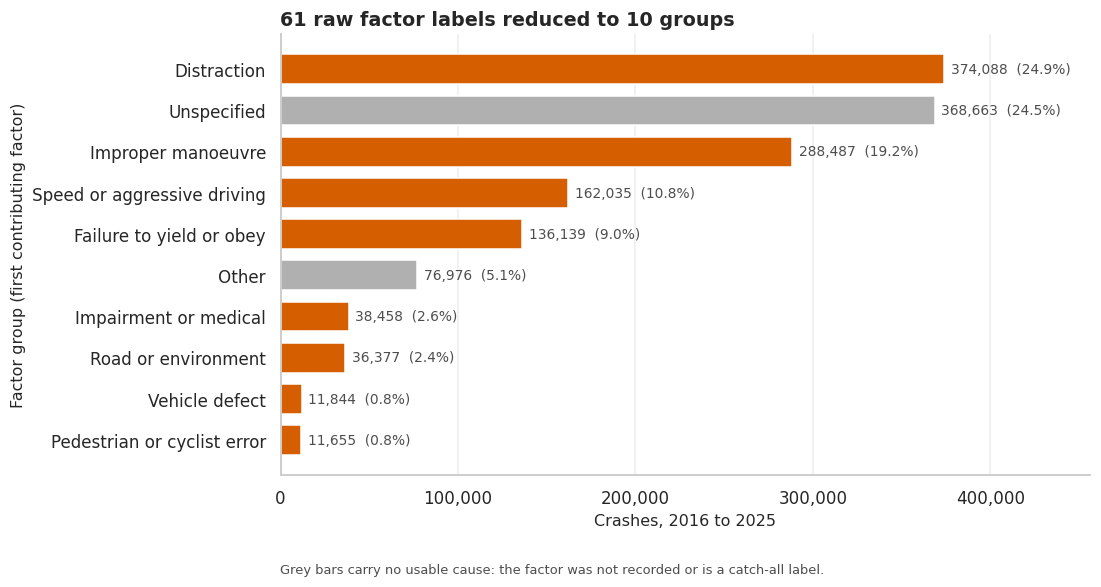

In [68]:
def plot_factor_groups(group_counts, raw_label_count):
    """Horizontal bars of crashes per factor group; groups without a usable cause are grey."""
    fig, ax = plt.subplots(figsize=(9.5, 5.2))
    bar_colors = [PALETTE["before"] if group in ("Unspecified", "Other") else PALETTE["crash"]
                  for group in group_counts.index]
    ax.barh(group_counts.index.astype(str), group_counts.to_numpy(), color=bar_colors, height=0.72)
    for position, (group, count) in enumerate(group_counts.items()):
        ax.text(count + group_counts.max() * 0.01, position,
                f"{count:,}  ({pct(count, len(crashes)):.1f}%)", va="center", fontsize=9,
                color=PALETTE["neutral"])
    ax.set_xlim(0, group_counts.max() * 1.22)
    thousands(ax, axis="x")
    ax.grid(axis="y", visible=False)
    finish(ax, f"{raw_label_count} raw factor labels reduced to {len(FACTOR_GROUPS)} groups",
           f"Crashes, {YEAR_START} to {YEAR_END}", "Factor group (first contributing factor)",
           note="Grey bars carry no usable cause: the factor was not recorded or is a catch-all label.")
    plt.show()


factor_group_counts = crashes["factor_group"].value_counts().sort_values()
factor_injury_share = (crashes.groupby("factor_group", observed=True)["is_injury_crash"].mean() * 100)
plot_factor_groups(factor_group_counts, len(factor_mapping))

In [69]:
unrecognised_labels = factor_mapping.loc[factor_mapping["unrecognised"], "raw_label"].tolist()
informative = ~crashes["factor_group"].isin(["Unspecified", "Other"])
top_group = factor_group_counts.drop(["Unspecified", "Other"]).idxmax()
say(f"{len(factor_mapping)} distinct labels ({factor_mapping['normalised'].nunique()} after trimming and "
    f"lower-casing) plus {factor_missing:,} missing values become {len(FACTOR_GROUPS)} groups. Numeric codes "
    f"({', '.join(numeric_codes['raw_label'])}) account for {int(numeric_codes['rows'].sum())} rows. Labels "
    f"that no pattern recognised: {len(unrecognised_labels)}.")
say(f"'Unspecified' holds {pct(factor_group_counts['Unspecified'], len(crashes)):.1f}% of crashes, so "
    f"{pct(informative.sum(), len(crashes)):.1f}% have an informative factor group. The largest informative "
    f"group is {top_group} ({pct(factor_group_counts[top_group], len(crashes)):.1f}%). The share of crashes with an "
    f"injury or death ranges from {factor_injury_share.min():.0f}% ({factor_injury_share.idxmin()}) to "
    f"{factor_injury_share.max():.0f}% ({factor_injury_share.idxmax()}) across groups.")

61 distinct labels (59 after trimming and lower-casing) plus 6,442 missing values become 10 groups. Numeric codes (80, 1) account for 111 rows. Labels that no pattern recognised: 0.

'Unspecified' holds 24.5% of crashes, so 70.4% have an informative factor group. The largest informative group is Distraction (24.9%). The share of crashes with an injury or death ranges from 16% (Improper manoeuvre) to 77% (Pedestrian or cyclist error) across groups.

Every raw label is claimed by a pattern, so the fallback is unused in this download. A large
share of crashes has no recorded factor, which limits RQ10 to the crashes that do and has to
be stated with its results. The groups differ widely in how often they involve an injury, so
the grouping keeps real information.

### 4.12 Final shape of the two frames

The last step puts the columns in a fixed order, leaves out the raw columns that no later
section uses, and checks the invariants of each frame once more. For housing, the finer
geographic identifiers (tax lot, building number, census tract, neighbourhood area, council
district) have no counterpart in the crash table, and the second coordinate pair is missing in
the same rows as the first, so none of them can help integration. For crashes, the street name,
the second contributing factor and the vehicle type were used above for checks and are not
carried forward; the raw factor label is replaced by its group.

In [70]:
HOUSING_COLUMN_ORDER = [
    "housing_id", "project_id", "building_id", "project_name", "address",
    "borough", "zip", "lat", "lon", "community_board", "is_confidential", "is_located",
    "project_start_date", "project_completion_date", "building_completion_date", "completion_date",
    "start_year", "completion_year", "is_completed", "completion_before_start", "same_day_completion",
    "construction_type", "extended_affordability", "prevailing_wage",
    *INCOME_UNIT_COLUMNS, *BEDROOM_UNIT_COLUMNS, *TENURE_UNIT_COLUMNS, *TOTAL_UNIT_COLUMNS,
    "deep_affordable_units", "deep_affordable_share", "is_size_outlier", "size_band",
]
CRASH_COLUMN_ORDER = [
    "collision_id", "crash_date", "year", "month", "hour", "hour_band",
    "borough", "zip", "lat", "lon", "is_located",
    "injured", "killed", "ped_injured", "ped_killed", "cyc_injured", "cyc_killed",
    "mot_injured", "mot_killed", "other_injured", "other_killed",
    "is_injury_crash", "ped_cyc_harm", "factor_group",
    "casualty_mismatch", "is_extreme_injury", "is_possible_duplicate",
]
assert set(HOUSING_COLUMN_ORDER) == set(housing.columns), set(HOUSING_COLUMN_ORDER) ^ set(housing.columns)
assert set(CRASH_COLUMN_ORDER) == set(crashes.columns), set(CRASH_COLUMN_ORDER) ^ set(crashes.columns)
housing = housing[HOUSING_COLUMN_ORDER]
crashes = crashes[CRASH_COLUMN_ORDER]

# Raw columns that reach the clean frame under another name. Whatever is neither kept by name nor
# renamed is not carried forward, so the dropped set is derived and then compared with the lists.
HOUSING_RENAMED = {"postcode": "zip", "latitude": "lat", "longitude": "lon", "house_number": "address",
                   "street_name": "address", "reporting_construction_type": "construction_type",
                   "extended_affordability_status": "extended_affordability",
                   "prevailing_wage_status": "prevailing_wage"}
CRASH_RENAMED = {"zip_code": "zip", "latitude": "lat", "longitude": "lon", **CASUALTY_COLUMNS}
housing_dropped = sorted(set(raw_housing.columns) - set(housing.columns) - set(HOUSING_RENAMED))
crash_columns_not_kept = sorted(set(raw_crashes.columns) - set(crashes.columns) - set(CRASH_RENAMED))
assert housing_dropped == sorted(HOUSING_COLUMNS_NOT_KEPT), housing_dropped
assert set(HOUSING_RENAMED.values()) <= set(housing.columns)
assert set(CRASH_RENAMED.values()) <= set(crashes.columns)

log_rule("housing", f"{len(housing_dropped)} raw columns not carried forward "
         "(finer geographic ids, second coordinate pair)", "drop", len(housing), len(housing),
         len(housing_dropped), "No counterpart in the crash table. Affected counts columns, not rows.")
log_rule("crashes", f"{len(crash_columns_not_kept)} raw text columns not carried forward "
         "(replaced by typed columns or used only for checks)", "drop", len(crashes), len(crashes),
         len(crash_columns_not_kept), "Keeps the frame compact. Affected counts columns, not rows.")

# Invariants of the two frames that later sections rely on.
assert len(housing) == len(raw_housing), "housing rows are conserved (no rule dropped any)"
assert not repeats_key(housing).any()
assert len(crashes) == crash_rows_raw, "crash rows are conserved (no rule dropped any)"
assert crashes["collision_id"].is_unique
assert list(housing["borough"].cat.categories) == BOROUGHS == list(crashes["borough"].cat.categories)
assert housing["zip"].dtype == crashes["zip"].dtype

display(pd.DataFrame({"dtype": housing.dtypes.astype(str), "missing": housing.isna().sum()}).T)
display(pd.DataFrame({"dtype": crashes.dtypes.astype(str), "missing": crashes.isna().sum()}).T)

,housing_id,project_id,building_id,project_name,address,borough,zip,lat,lon,community_board,is_confidential,is_located,project_start_date,project_completion_date,building_completion_date,completion_date,start_year,completion_year,is_completed,completion_before_start,same_day_completion,construction_type,extended_affordability,prevailing_wage,extremely_low_income_units,very_low_income_units,low_income_units,moderate_income_units,middle_income_units,other_income_units,studio_units,_1_br_units,_2_br_units,_3_br_units,_4_br_units,_5_br_units,_6_br_units,unknown_br_units,counted_rental_units,counted_homeownership_units,all_counted_units,total_units,deep_affordable_units,deep_affordable_share,is_size_outlier,size_band
dtype,int32,int64,Int64,string,string,category,string,float64,float64,category,bool,bool,datetime64[ns],datetime64[ns],datetime64[ns],datetime64[ns],int16,Int16,bool,bool,bool,category,bool,bool,int16,int16,int16,int16,int16,int16,int16,int16,int16,int16,int16,int16,int16,int16,int16,int16,int16,int16,int16,float64,bool,category
missing,0,0,1949,0,1949,0,1958,1958,1958,0,0,0,0,1819,1666,1653,0,1653,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,29,0,0


,collision_id,crash_date,year,month,hour,hour_band,borough,zip,lat,lon,is_located,injured,killed,ped_injured,ped_killed,cyc_injured,cyc_killed,mot_injured,mot_killed,other_injured,other_killed,is_injury_crash,ped_cyc_harm,factor_group,casualty_mismatch,is_extreme_injury,is_possible_duplicate
dtype,int64,datetime64[ns],int16,int8,Int8,category,category,string,float64,float64,bool,int8,int8,int8,int8,int8,int8,int8,int8,int8,int8,bool,bool,category,bool,bool,bool
missing,0,0,0,0,0,0,508028,508922,132500,132500,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


Missing values now remain only where the information does not exist: location fields of
withheld or unaddressed housing records, completion dates of unfinished buildings, the share
with a zero denominator, and the borough, ZIP and coordinates that the crash reports never had.

### 4.13 Cleaning log and before/after summary

The table lists every rule in the order it ran. `affected` is a number of rows, except where
the rule says cells or columns.

In [71]:
cleaning_log_table = pd.DataFrame(CLEANING_LOG)
with pd.option_context("display.max_colwidth", None, "display.max_rows", 100):
    display(cleaning_log_table)
assert (cleaning_log_table["rows_after"] <= cleaning_log_table["rows_before"]).all()
cleaning_log_table["rows_dropped"] = cleaning_log_table["rows_before"] - cleaning_log_table["rows_after"]
display(cleaning_log_table.groupby(["dataset", "action"])
        .agg(rules=("rule", "size"), rows_dropped=("rows_dropped", "sum")))
assert set(cleaning_log_table["action"]) <= {"drop", "impute", "flag", "standardise"}

,dataset,rule,action,rows_before,rows_after,affected,reason
0,housing,blank unit counts set to 0 (18 unit columns),impute,9551,9551,106309,"The publisher writes zero as blank; sums over bands need a number. Cells, not rows."
1,housing,"duplicate rows on (project_id, building_id) or on every column",drop,9551,9551,0,A repeated key would double count units. building_id alone is not the key.
2,housing,borough to category with the BOROUGHS spelling,standardise,9551,9551,0,One spelling on both tables; affected counts values outside the five boroughs.
3,housing,"postcode to 5-character string, checked against NYC ZIP ranges",standardise,9551,9551,0,ZIP is a label and a join key; affected counts codes rejected as not NYC.
4,housing,"coordinates at (0,0) or outside NYC_BOUNDS set to missing",standardise,9551,9551,0,A point outside the city would corrupt distance joins.
5,housing,confidential records kept and flagged (is_confidential),flag,9551,9551,1949,"No address, ZIP or coordinates, so not imputable; still valid for borough totals."
6,housing,rows without usable coordinates flagged (is_located = False),flag,9551,9551,1958,Spatial analyses need a point; ZIP and borough analyses do not.
7,housing,ZIP range borough differs from stated borough (stated borough kept),flag,9551,9551,5,Checked only; a few ZIPs legitimately cross a borough line.
8,housing,three date columns parsed from text with one exact layout,standardise,9551,9551,0,Dates must be comparable; affected counts unparseable values.
9,housing,"completion_date = building date, else project date",impute,9551,9551,13,Deterministic fill from the same row; rows with neither date stay missing.


rules  rows_dropped
dataset action                          
crashes drop             4             0
        flag             6             0
        impute           2             0
        standardise      9             0
housing drop             2             0
        flag            13             0
        impute           2             0
        standardise      4             0

In [72]:
before_after = pd.DataFrame({
    "rows before": [len(raw_housing), crash_rows_raw],
    "rows after": [len(housing), len(crashes)],
    "columns before": [raw_housing.shape[1], crash_columns_raw],
    "columns after": [housing.shape[1], crashes.shape[1]],
    "memory before (MB)": [memory_mb(raw_housing), crash_memory_raw],
    "memory after (MB)": [memory_mb(housing), memory_mb(crashes)],
}, index=["housing", "crashes"]).round(1)
display(before_after)
say(f"{len(cleaning_log_table)} rules were logged: "
    f"{int((cleaning_log_table['dataset'] == 'housing').sum())} for housing and "
    f"{int((cleaning_log_table['dataset'] == 'crashes').sum())} for crashes. No rule removed a row, so both "
    f"tables keep their full length ({len(housing):,} and {len(crashes):,} rows). The typed crash frame takes "
    f"{before_after.loc['crashes', 'memory after (MB)']:.0f} MB against "
    f"{before_after.loc['crashes', 'memory before (MB)']:.0f} MB for the raw text.")

,rows before,rows after,columns before,columns after,memory before (MB),memory after (MB)
housing,9551,9551,41,46,5.300,1.900
crashes,1504722,1504722,19,27,436.800,101.500


42 rules were logged: 21 for housing and 21 for crashes. No rule removed a row, so both tables keep their full length (9,551 and 1,504,722 rows). The typed crash frame takes 102 MB against 437 MB for the raw text.

Neither table lost a row. That is a result of the policy and of the data: the keys were sound,
and every other problem could be handled by standardising a format or by adding a flag. The
crash frame is several times smaller than the raw text because counts are stored as one-byte
integers and labels as categories.

The raw crash table and the working copies made in this section are no longer needed and are
released. The raw housing table is small and is kept for reference. Section 4 consumes
`raw_crashes`, so running it a second time needs Section 2.1 to be run again first.

In [73]:
RELEASED_NAMES = [
    "raw_crashes", "crash_source", "crash_ids", "crash_dates", "crash_hour", "crash_minute", "casualties",
    "raw_coordinate_sample", "raw_lat", "raw_lon", "map_sample", "vehicle_type",
    "location_state", "surplus_mask", "is_scooter_or_ebike", "extreme_rows", "casualty_report",
]
release(*RELEASED_NAMES)

## 5. Integration

The two cleaned tables describe different things. A housing row is a building in a subsidised
project and a crash row is one collision. This section builds the tables that let a housing
variable and a crash variable be read side by side. It does so at two levels: a ZIP by year
panel, where both tables are first reduced to the same grain, and a spatial level, where a crash
is linked to the buildings within `BUFFER_M` metres of it.

### 5.1 The problem: no shared key

`collision_id` identifies a crash and (`project_id`, `building_id`) identifies a housing row.
Neither identifier appears in the other table, so there is nothing to join row to row. What the
tables do share is where and when. Four bridges are available, and each gives a different grain.

| Bridge | Grain it gives | What it can answer | What it cannot answer |
|---|---|---|---|
| Time (year) | city by year | whether the two series move together over ten years | anything about place: ten points, and both series follow the city as a whole |
| Borough | borough by year | broad contrasts between five areas; the only level that includes confidential housing rows | neighbourhood differences: a borough holds hundreds of thousands of crashes and hundreds of buildings |
| ZIP code | ZIP by year | change within a neighbourhood over time, comparison across neighbourhoods | what happens on the streets next to one building; needs a ZIP on both sides |
| Coordinates | building by year, and crash by nearest building | crashes on the streets around a building before and after it is completed | anything for records without coordinates; neighbouring buildings overlap |

Time and borough are too coarse to carry the analysis alone, so they are used as controls and
for reference totals. The ZIP and the coordinates are the two working bridges. The cell below
measures how much of each table every bridge can reach.

In [74]:
# --- Constants for Section 5 ------------------------------------------------------------------
N_STUDY_YEARS = len(STUDY_YEARS)
BYTES_PER_GB = 1_000_000_000
BYTES_PER_FLOAT = 8                 # one float64 distance
SQUARE_METRES_PER_HECTARE = 10_000
# The merge demo counts rows per (ZIP, year) with one integer key, zip * scale + year. A year is
# always below the scale, so every (ZIP, year) pair gets its own number, and counting integers is
# much cheaper than counting 1.5 million joined text keys.
YEAR_KEY_SCALE = 10_000
NO_YEAR_KEY = 0                     # stands for "no completion year" in that key

# Radii (metres) compared when judging the 250 m buffer; the same list is reused in Section 9.
RADIUS_CANDIDATES_M = [100, 150, 250, 400, 500]

# The many-to-many merge is run for real on one ZIP; it needs enough housing rows to show the effect.
DEMO_MIN_HOUSING_ROWS = 10

# Brute-force check of the spatial index: sample sizes small enough for a full distance matrix.
CHECK_SITE_SAMPLE = 300             # buildings
CHECK_CRASH_SAMPLE = 20_000         # crashes

# Alternative resampling unit for Section 9: buildings grouped by a fixed square of this side.
# One kilometre is four buffer radii, so two buildings in non-adjacent squares never share a crash.
BLOCK_SIDE_M = 1000

CLUSTER_SIZE_EDGES = [0, 1, 5, 20, 100, np.inf]          # buildings per cluster, upper edge inclusive
CLUSTER_SIZE_LABELS = ["1", "2-5", "6-20", "21-100", "101+"]

ROW_MERGE_AXIS_START = 1_000        # rows; left end of the log axis of the merge chart
ROW_MERGE_AXIS_HEADROOM = 20        # the log axis of the merge chart extends this factor past the largest value
ROW_MERGE_LABEL_GAP = 1.3           # a value label sits this factor to the right of its dot (log axis)
AXIS_HEADROOM = 1.15                # linear axes extend this factor past the largest bar so its label fits
LINE_HEADROOM = 1.18                # same, for the line charts of the radius comparison
LABEL_GAP = 0.015                   # gap between a bar and its value label, as a share of the largest bar

EVENT_GROUPS = ["treated", "comparison"]
# Relation of a crash to its nearest housing site, in the order used by every later table.
HOUSING_RELATIONS = ["No coordinates", "Not near a site", "Before completion", "Completion year",
                     "After completion"]
RELATION_COLORS = {"Not near a site": PALETTE["neutral"], "Before completion": PALETTE["control"],
                   "Completion year": PALETTE["accent"], "After completion": PALETTE["after"]}

SITE_ATTRIBUTES = ["housing_id", "project_id", "building_id", "project_name", "borough", "zip", "lat", "lon",
                   "start_year", "completion_year", "is_completed", "same_day_completion",
                   "completion_before_start", "construction_type", "total_units", "all_counted_units",
                   "deep_affordable_units", "deep_affordable_share", "size_band", "is_size_outlier"]
SITE_COUNT_COLUMNS = ["crashes", "injury_crashes", "ped_cyc_crashes", "persons_injured"]
HOUSING_PANEL_MEASURES = ["buildings_completed", "units_completed", "affordable_units_completed",
                          "deep_affordable_units", "new_construction_units", "preservation_units"]
CRASH_PANEL_MEASURES = ["crashes", "injury_crashes", "persons_injured", "persons_killed", "ped_cyc_crashes"]

In [75]:
bridge_coverage = pd.DataFrame({
    "housing rows with the key": [
        int(housing["completion_year"].notna().sum()), int(housing["borough"].notna().sum()),
        int(housing["zip"].notna().sum()), int(housing["is_located"].sum())],
    "crash rows with the key": [
        int(crashes["year"].notna().sum()), int(crashes["borough"].notna().sum()),
        int(crashes["zip"].notna().sum()), int(crashes["is_located"].sum())],
    "distinct values in housing": [
        housing["completion_year"].nunique(), housing["borough"].nunique(), housing["zip"].nunique(),
        int(housing.loc[housing["is_located"], ["lat", "lon"]].drop_duplicates().shape[0])],
    "distinct values in crashes": [
        crashes["year"].nunique(), crashes["borough"].nunique(), crashes["zip"].nunique(),
        int(crashes.loc[crashes["is_located"], ["lat", "lon"]].drop_duplicates().shape[0])],
}, index=["Time (completion year / crash year)", "Borough", "ZIP code", "Coordinates"])
bridge_coverage.insert(1, "% of housing", (100 * bridge_coverage["housing rows with the key"] / len(housing)).round(1))
bridge_coverage.insert(3, "% of crashes", (100 * bridge_coverage["crash rows with the key"] / len(crashes)).round(1))
display(bridge_coverage)

,housing rows with the key,% of housing,crash rows with the key,% of crashes,distinct values in housing,distinct values in crashes
Time (completion year / crash year),7898,82.700,1504722,100.000,13,10
Borough,9551,100.000,996694,66.200,5,5
ZIP code,7593,79.500,995800,66.200,158,231
Coordinates,7593,79.500,1372222,91.200,7429,308739


Every bridge loses something. The housing rows without a ZIP or coordinates are the confidential
records. The crash rows without a ZIP are the larger gap, and most of them still have
coordinates, which is why the spatial level reaches more crashes than the ZIP level does before
any repair.

#### 5.1.1 Why the tables are not merged row to row on ZIP

A ZIP code is a key in neither table: one ZIP holds many buildings and thousands of crashes. A
row-level merge on ZIP therefore pairs every building with every crash of the same ZIP. The
result is not a list of crashes and not a list of buildings, and any sum taken over it counts
each crash once per building in its ZIP. The size of that merge can be computed without running
it, by multiplying the two row counts ZIP by ZIP. To show that the arithmetic matches what
pandas would do, the merge is run for real on one ZIP, the one with the smallest product among
ZIPs that have at least `DEMO_MIN_HOUSING_ROWS` housing rows.

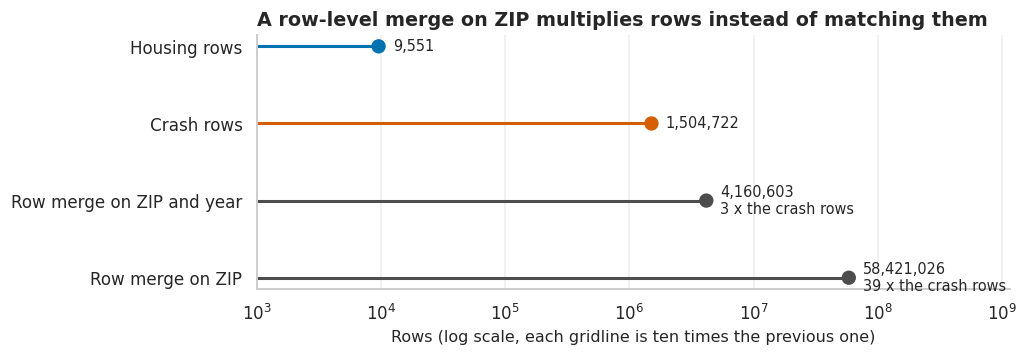

In [76]:
def zip_year_key(zip_codes, years):
    """One integer per (ZIP, year); see YEAR_KEY_SCALE."""
    return zip_codes.astype("int64") * YEAR_KEY_SCALE + years.astype("int64")


def row_merge_size(housing_keys, crash_keys):
    """Rows a many-to-many merge would return: per key, housing rows times crash rows, summed."""
    housing_rows = housing_keys.value_counts()
    crash_rows = crash_keys.value_counts()
    paired = pd.concat([housing_rows.rename("housing_rows"), crash_rows.rename("crash_rows")],
                       axis=1, join="inner")
    paired["merged_rows"] = paired["housing_rows"].astype("int64") * paired["crash_rows"].astype("int64")
    return paired


housing_with_zip = housing[housing["zip"].notna()]
crashes_with_zip = crashes.loc[crashes["zip"].notna(), ["collision_id", "zip", "year", "injured"]]

zip_merge = row_merge_size(housing_with_zip["zip"], crashes_with_zip["zip"])
zip_merge["persons_injured"] = crashes_with_zip.groupby("zip")["injured"].sum().reindex(zip_merge.index)
zip_year_merge = row_merge_size(
    zip_year_key(housing_with_zip["zip"], housing_with_zip["completion_year"].fillna(NO_YEAR_KEY)),
    zip_year_key(crashes_with_zip["zip"], crashes_with_zip["year"]))

# The real merge, on one ZIP where it is small, to confirm the arithmetic.
smallest_zip = zip_merge.loc[zip_merge["housing_rows"] >= DEMO_MIN_HOUSING_ROWS, "merged_rows"].idxmin()
real_merge = housing_with_zip.loc[housing_with_zip["zip"] == smallest_zip, ["housing_id", "zip"]].merge(
    crashes_with_zip[crashes_with_zip["zip"] == smallest_zip], on="zip")
assert len(real_merge) == zip_merge.loc[smallest_zip, "merged_rows"]
assert real_merge["injured"].sum() == (zip_merge.loc[smallest_zip, "housing_rows"]
                                       * zip_merge.loc[smallest_zip, "persons_injured"])

merged_rows_total = int(zip_merge["merged_rows"].sum())
injured_true = int(zip_merge["persons_injured"].sum())
injured_after_merge = int((zip_merge["housing_rows"] * zip_merge["persons_injured"]).sum())
row_counts = pd.Series({
    "Housing rows": len(housing),
    "Crash rows": len(crashes),
    "Row merge on ZIP and year": int(zip_year_merge["merged_rows"].sum()),
    "Row merge on ZIP": merged_rows_total,
})

def plot_row_merge_sizes(row_counts):
    """Lollipop chart of the row counts of the two tables and of the two row-level merges (log axis)."""
    # Lollipops instead of bars: on a log axis the length of a bar depends on where the axis starts,
    # so only the position of the dot carries the value.
    fig, ax = plt.subplots(figsize=(9.5, 3.4))
    dot_colors = [PALETTE["housing"], PALETTE["crash"], PALETTE["neutral"], PALETTE["neutral"]]
    ax.set_xscale("log")
    ax.set_xlim(ROW_MERGE_AXIS_START, row_counts.max() * ROW_MERGE_AXIS_HEADROOM)
    ax.hlines(row_counts.index, ROW_MERGE_AXIS_START, row_counts.to_numpy(), color=dot_colors, linewidth=2)
    ax.scatter(row_counts.to_numpy(), row_counts.index, color=dot_colors, s=70, zorder=3)
    for position, value in enumerate(row_counts.to_numpy()):
        is_merge = position >= 2
        label = f"{value:,}" + (f"\n{value / len(crashes):,.0f} x the crash rows" if is_merge else "")
        ax.text(value * ROW_MERGE_LABEL_GAP, position, label, va="center", fontsize=9.5)
    ax.invert_yaxis()
    ax.grid(axis="y", visible=False)
    finish(ax, "A row-level merge on ZIP multiplies rows instead of matching them",
           "Rows (log scale, each gridline is ten times the previous one)", "")
    plt.tight_layout()
    plt.show()


plot_row_merge_sizes(row_counts)

In [77]:
say(f"A row merge on ZIP would return {merged_rows_total:,} rows, {merged_rows_total / len(crashes):,.0f} times "
    f"the crash table, because the median ZIP with both pairs {zip_merge['housing_rows'].median():.0f} housing "
    f"rows with {zip_merge['crash_rows'].median():,.0f} crashes. Adding the year to the key still returns "
    f"{int(zip_year_merge['merged_rows'].sum()):,} rows. The crashes that have a ZIP shared with housing "
    f"injured {injured_true:,} people; summed over the merged table the same column gives "
    f"{injured_after_merge:,}, an overcount by a factor of {injured_after_merge / injured_true:.0f}. In ZIP "
    f"{smallest_zip}, where the merge was run, pandas returns {len(real_merge):,} rows from "
    f"{int(zip_merge.loc[smallest_zip, 'housing_rows'])} housing rows and "
    f"{int(zip_merge.loc[smallest_zip, 'crash_rows']):,} crashes, exactly the product, and the "
    f"{int(zip_merge.loc[smallest_zip, 'persons_injured']):,} people injured there become "
    f"{int(real_merge['injured'].sum()):,}.")

A row merge on ZIP would return 58,421,026 rows, 39 times the crash table, because the median ZIP with both pairs 22 housing rows with 5,794 crashes. Adding the year to the key still returns 4,160,603 rows. The crashes that have a ZIP shared with housing injured 331,113 people; summed over the merged table the same column gives 22,152,790, an overcount by a factor of 67. In ZIP 10040, where the merge was run, pandas returns 22,200 rows from 12 housing rows and 1,850 crashes, exactly the product, and the 619 people injured there become 7,428.

The merge would run without an error and look like a joined table, but each crash would be
repeated once for every building in its ZIP, so ZIPs with many buildings would appear to have
many more injuries. The rule used from here on is to aggregate
each table to a common grain first and merge second, so that the merge is one row to one row.

### 5.2 Level A: a ZIP by year panel

The common grain for the first level is one row per ZIP code and calendar year. For crashes the
year is the crash year. For housing it is the completion year, because a building can only add
residents and street activity once it is finished. Buildings without a completion date
contribute nothing at this level, and neither do confidential rows, which have no ZIP.

Each table is aggregated separately, and only then are the two aggregates merged on
(`zip`, `year`). Both aggregates are unique on that key, so the merge cannot multiply rows. The
panel built in this subsection is deliberately naive: it uses the ZIP codes exactly as reported
and an outer merge, and its purpose is to expose what does not match. Section 6 repairs those
gaps and builds the final panel with the same two functions.

Two unit totals are kept for housing. `units_completed` is every unit in the building,
including market-rate units, and measures how many households the building adds.
`affordable_units_completed` counts only the units that the programme counts as affordable.

In [78]:
def aggregate_housing_to_zip_year(housing_frame):
    """Completed housing rows with a ZIP, summed to one row per (zip, completion year).

    The year column keeps the nullable dtype of `completion_year`; fixing that is part of the
    post-integration cleaning, so it is not hidden here.
    """
    completed = housing_frame[housing_frame["is_completed"] & housing_frame["zip"].notna()]
    is_new = completed["construction_type"] == "New Construction"
    is_preservation = completed["construction_type"] == "Preservation"
    measures = pd.DataFrame({
        "zip": completed["zip"], "year": completed["completion_year"],
        "buildings_completed": 1,
        "units_completed": completed["total_units"].astype("int32"),
        "affordable_units_completed": completed["all_counted_units"].astype("int32"),
        "deep_affordable_units": completed["deep_affordable_units"].astype("int32"),
        "new_construction_units": completed["total_units"].where(is_new, 0).astype("int32"),
        "preservation_units": completed["total_units"].where(is_preservation, 0).astype("int32"),
    })
    return measures.groupby(["zip", "year"], as_index=False)[HOUSING_PANEL_MEASURES].sum()


def aggregate_crashes_to_zip_year(crash_frame, zip_column="zip"):
    """Crashes that have a value in `zip_column`, summed to one row per (zip, crash year)."""
    with_zip = crash_frame[crash_frame[zip_column].notna()]
    measures = pd.DataFrame({
        "zip": with_zip[zip_column], "year": with_zip["year"],
        "crashes": 1,
        "injury_crashes": with_zip["is_injury_crash"].astype("int32"),
        "persons_injured": with_zip["injured"].astype("int32"),
        "persons_killed": with_zip["killed"].astype("int32"),
        "ped_cyc_crashes": with_zip["ped_cyc_harm"].astype("int32"),
    })
    return measures.groupby(["zip", "year"], as_index=False)[CRASH_PANEL_MEASURES].sum()


housing_by_zip_year = aggregate_housing_to_zip_year(housing)
crashes_by_zip_year_reported = aggregate_crashes_to_zip_year(crashes)
assert not housing_by_zip_year.duplicated(["zip", "year"]).any()
assert not crashes_by_zip_year_reported.duplicated(["zip", "year"]).any()

housing_in_study_years = housing_by_zip_year[housing_by_zip_year["year"].between(YEAR_START, YEAR_END)]
naive_panel = housing_in_study_years.merge(crashes_by_zip_year_reported, on=["zip", "year"], how="outer",
                                           indicator="match")
# One row to one row: the merged table can be no longer than the two aggregates together.
assert len(naive_panel) <= len(housing_in_study_years) + len(crashes_by_zip_year_reported)
assert not naive_panel.duplicated(["zip", "year"]).any()

match_labels = {"both": "ZIP-year in both tables", "left_only": "housing only (no crash row)",
                "right_only": "crashes only (no housing row)"}
naive_match = (naive_panel["match"].astype(str).map(match_labels).value_counts()
               .reindex(list(match_labels.values()), fill_value=0).rename("ZIP-years").to_frame())
naive_match["% of naive panel"] = (100 * naive_match["ZIP-years"] / len(naive_panel)).round(1)
display(naive_match)

housing_zips = set(housing_by_zip_year["zip"])
crash_zips_reported = set(crashes_by_zip_year_reported["zip"])
housing_zips_without_crashes = sorted(housing_zips - crash_zips_reported)
naive_missing_cells = int(naive_panel[HOUSING_PANEL_MEASURES + CRASH_PANEL_MEASURES].isna().sum().sum())
naive_balanced_rows = naive_panel["zip"].nunique() * N_STUDY_YEARS

crashes_without_zip = int(crashes["zip"].isna().sum())
completed_rows = housing[housing["is_completed"]]
completed_without_zip = completed_rows[completed_rows["zip"].isna()]
completed_outside_years = completed_rows[completed_rows["zip"].notna()
                                         & ~completed_rows["completion_year"].between(YEAR_START, YEAR_END)]
not_completed = housing[~housing["is_completed"]]

left_out = pd.DataFrame({
    "rows": [crashes_without_zip, len(completed_without_zip), len(completed_outside_years), len(not_completed)],
    "% of its table": [pct(crashes_without_zip, len(crashes)), pct(len(completed_without_zip), len(housing)),
                       pct(len(completed_outside_years), len(housing)), pct(len(not_completed), len(housing))],
    "units": [np.nan, completed_without_zip["total_units"].sum(), completed_outside_years["total_units"].sum(),
              not_completed["total_units"].sum()],
}, index=["Crashes with no ZIP (never reach the panel)", "Completed housing rows with no ZIP (confidential)",
          f"Housing rows completed outside {YEAR_START}-{YEAR_END}", "Housing rows with no completion date"])
display(left_out.round(1))

,ZIP-years,% of naive panel
match,,
ZIP-year in both tables,854,40.400
housing only (no crash row),2,0.100
crashes only (no housing row),1256,59.500


,rows,% of its table,units
Crashes with no ZIP (never reach the panel),508922,33.800,NaN
Completed housing rows with no ZIP (confidential),1880,19.700,"2,693.000"
Housing rows completed outside 2016-2025,619,6.500,"38,354.000"
Housing rows with no completion date,1653,17.300,"111,125.000"


In [79]:
say(f"The naive panel has {len(naive_panel):,} rows for {naive_panel['zip'].nunique()} ZIP codes. A balanced "
    f"panel of those ZIPs over {N_STUDY_YEARS} years would have {naive_balanced_rows:,} rows, so "
    f"{naive_balanced_rows - len(naive_panel):,} ZIP-years are absent altogether. Only "
    f"{int(naive_match.loc[match_labels['both'], 'ZIP-years']):,} rows "
    f"({naive_match.loc[match_labels['both'], '% of naive panel']:.1f}%) matched on both sides; "
    f"{int(naive_match.loc[match_labels['right_only'], 'ZIP-years']):,} have crashes and no housing row, and "
    f"{int(naive_match.loc[match_labels['left_only'], 'ZIP-years'])} have housing and no crash row. The merge created {naive_missing_cells:,} missing cells that neither input "
    f"had. Housing ZIP codes that never appear in the crash table: {len(housing_zips_without_crashes)} "
    f"({', '.join(housing_zips_without_crashes)}). Outside the panel, {crashes_without_zip:,} crashes "
    f"({pct(crashes_without_zip, len(crashes)):.1f}%) have no ZIP and could not be placed in any row.")

The naive panel has 2,112 rows for 232 ZIP codes. A balanced panel of those ZIPs over 10 years would have 2,320 rows, so 208 ZIP-years are absent altogether. Only 854 rows (40.4%) matched on both sides; 1,256 have crashes and no housing row, and 2 have housing and no crash row. The merge created 7,546 missing cells that neither input had. Housing ZIP codes that never appear in the crash table: 1 (10303). Outside the panel, 508,922 crashes (33.8%) have no ZIP and could not be placed in any row.

Three different things are hiding behind those numbers, and they need different treatment.

A ZIP-year with crashes and no housing row is the normal case: most neighbourhoods complete no
subsidised building in a given year. The missing housing values are zeros that the merge wrote
as missing.

A housing ZIP with no crash row at all is not a neighbourhood without crashes. Ten years with
no reported collision is not believable for a residential ZIP, so the crash table simply does
not use that code, and a zero there would be false.

The crashes without a ZIP are the largest problem and they are invisible in the panel itself,
because a row that has no key drops out of a grouped table without leaving a missing value
behind. Their share also changes from year to year (Section 4.8), so the panel as built here
would show a trend that comes from record keeping. Section 6.1 deals with all three.

### 5.3 Level B: spatial proximity

The second level ignores administrative areas and asks which crashes happened within `BUFFER_M`
metres of each building. It needs a distance between two points given as latitude and longitude,
and a way to find all pairs closer than the radius without comparing everything to everything.

For distance, degrees are not a unit of length: at New York's latitude one degree of longitude
is about three quarters of the length of one degree of latitude, so a circle drawn in degrees
would be an ellipse on the ground. The haversine formula gives the great-circle distance on a
sphere. With latitude $\varphi$ and longitude $\lambda$ in radians,

$$d = 2R \arcsin\sqrt{\sin^2\frac{\varphi_2-\varphi_1}{2} + \cos\varphi_1\cos\varphi_2\sin^2\frac{\lambda_2-\lambda_1}{2}}$$

where $R$ is `EARTH_RADIUS_M`. The formula works on the unit sphere, so coordinates are converted
to radians on the way in, and a radius in metres is divided by $R$ before a query and distances
are multiplied by $R$ on the way out. Treating the Earth as a sphere is wrong by a fraction of
a percent, which is about a metre at this radius and smaller than the error in the geocoding.

For the index, a ball tree groups the points into nested spheres. A radius query skips every sphere
that lies entirely outside the search radius, so it looks at a small part of the points instead
of all of them. The tree is built over the crashes, the larger table, and queried once per
building; the result is the same set of pairs as querying the other way round, and it is much
faster because there are far fewer buildings than crashes.

In [80]:
def to_radians(lat, lon):
    """Stack latitude and longitude (degrees) into the (n, 2) radian array the haversine tree expects."""
    return np.radians(np.column_stack([np.asarray(lat, dtype="float64"), np.asarray(lon, dtype="float64")]))


def haversine_m(lat_a, lon_a, lat_b, lon_b):
    """Great-circle distance in metres between points given in degrees (arrays broadcast)."""
    phi_a, phi_b = np.radians(lat_a), np.radians(lat_b)
    half_dphi = (phi_b - phi_a) / 2
    half_dlambda = np.radians(np.asarray(lon_b) - np.asarray(lon_a)) / 2
    inside = np.sin(half_dphi) ** 2 + np.cos(phi_a) * np.cos(phi_b) * np.sin(half_dlambda) ** 2
    return 2 * EARTH_RADIUS_M * np.arcsin(np.sqrt(inside))


def build_haversine_tree(lat, lon):
    """Ball tree over points given in degrees; point i of the tree is row i of the inputs."""
    return BallTree(to_radians(lat, lon), metric="haversine")


def pairs_within_radius(tree, lat, lon, radius_m):
    """All (query point, tree point) pairs no farther apart than `radius_m` metres.

    Returns three flat arrays of equal length: the position of the query point in `lat`/`lon`,
    the position of the tree point, and their distance in metres. The tree answers with one
    ragged list per query point; flattening it into pair arrays lets everything downstream
    (counting, taking the nearest, linking clusters) be done with vectorised numpy.
    """
    neighbours, distances = tree.query_radius(to_radians(lat, lon), radius_m / EARTH_RADIUS_M,
                                              return_distance=True)
    sizes = np.fromiter((len(found) for found in neighbours), dtype=np.int64, count=len(neighbours))
    query_index = np.repeat(np.arange(len(neighbours)), sizes)
    if sizes.sum() == 0:
        return query_index, np.empty(0, dtype=np.int64), np.empty(0, dtype="float64")
    return query_index, np.concatenate(neighbours), np.concatenate(distances) * EARTH_RADIUS_M


def brute_force_pairs(query_lat, query_lon, point_lat, point_lon, radius_m):
    """The same pairs as `pairs_within_radius`, found by computing every distance (small inputs only)."""
    all_distances = haversine_m(np.asarray(query_lat)[:, None], np.asarray(query_lon)[:, None],
                                np.asarray(point_lat)[None, :], np.asarray(point_lon)[None, :])
    query_index, point_index = np.nonzero(all_distances <= radius_m)
    return query_index, point_index, all_distances[query_index, point_index]

A toy example that can be checked by hand comes first. Four points are placed around a centre in
Midtown: one on the centre, one 100 m north, one 200 m east and one 300 m north. A query from
the centre with a 250 m radius must return the first three and leave out the fourth. The
offsets are converted to degrees with the fact that an arc of length $s$ on a sphere spans
$s/R$ radians, and for the eastward point that angle is divided by the cosine of the latitude.

In [81]:
toy_centre_lat, toy_centre_lon = 40.7500, -73.9900
toy_offsets_m = {"On the centre": (0, 0), "100 m north": (100, 0), "200 m east": (0, 200),
                 "300 m north": (300, 0)}
toy_points = pd.DataFrame([
    {"point": name,
     "lat": toy_centre_lat + math.degrees(north_m / EARTH_RADIUS_M),
     "lon": toy_centre_lon + math.degrees(east_m / EARTH_RADIUS_M) / math.cos(math.radians(toy_centre_lat))}
    for name, (north_m, east_m) in toy_offsets_m.items()])
toy_points["haversine distance to centre (m)"] = haversine_m(
    toy_centre_lat, toy_centre_lon, toy_points["lat"].to_numpy(), toy_points["lon"].to_numpy()).round(2)

toy_tree = build_haversine_tree(toy_points["lat"], toy_points["lon"])
_, toy_found, toy_distance = pairs_within_radius(toy_tree, [toy_centre_lat], [toy_centre_lon], BUFFER_M)
toy_points[f"returned by the {BUFFER_M} m query"] = toy_points.index.isin(toy_found)
display(toy_points)

assert set(toy_points.loc[toy_found, "point"]) == {"On the centre", "100 m north", "200 m east"}
assert np.allclose(np.sort(toy_distance), [0, 100, 200], atol=0.01)

,point,lat,lon,haversine distance to centre (m),returned by the 250 m query
0,On the centre,40.750,-73.990,0.000,True
1,100 m north,40.751,-73.990,100.000,True
2,200 m east,40.750,-73.988,200.000,True
3,300 m north,40.753,-73.990,300.000,False


The distances come back as placed and the query keeps exactly the three points inside the
radius. The next check uses real data. The tree over all located crashes is built, and for a
random sample of buildings and crashes every distance is also computed directly. The two sets of
pairs have to be identical.

In [82]:
def build_crash_tree(crash_frame):
    """Ball tree over the located crashes, plus the row position in `crash_frame` of each tree point."""
    crash_rows = np.flatnonzero(crash_frame["is_located"].to_numpy())
    tree = build_haversine_tree(crash_frame["lat"].to_numpy()[crash_rows],
                                crash_frame["lon"].to_numpy()[crash_rows])
    return tree, crash_rows


# Row positions are used as crash identifiers in this section, so the index must be 0..n-1.
crashes = crashes.reset_index(drop=True)
located_housing = housing[housing["is_located"]]
crash_tree, crash_tree_rows = build_crash_tree(crashes)

check_rng = np.random.default_rng(SEED)
check_sites = located_housing.sample(CHECK_SITE_SAMPLE, random_state=SEED)
check_crash_rows = check_rng.choice(crash_tree_rows, size=CHECK_CRASH_SAMPLE, replace=False)
check_crash_lat = crashes["lat"].to_numpy()[check_crash_rows]
check_crash_lon = crashes["lon"].to_numpy()[check_crash_rows]

check_tree = build_haversine_tree(check_crash_lat, check_crash_lon)
tree_query, tree_point, tree_distance = pairs_within_radius(
    check_tree, check_sites["lat"].to_numpy(), check_sites["lon"].to_numpy(), BUFFER_M)
brute_query, brute_point, brute_distance = brute_force_pairs(
    check_sites["lat"].to_numpy(), check_sites["lon"].to_numpy(), check_crash_lat, check_crash_lon, BUFFER_M)

tree_pairs = pd.DataFrame({"query": tree_query, "point": tree_point, "distance": tree_distance}
                          ).sort_values(["query", "point"]).reset_index(drop=True)
brute_pairs = pd.DataFrame({"query": brute_query, "point": brute_point, "distance": brute_distance}
                           ).sort_values(["query", "point"]).reset_index(drop=True)
assert len(tree_pairs) == len(brute_pairs)
assert (tree_pairs[["query", "point"]].to_numpy() == brute_pairs[["query", "point"]].to_numpy()).all()
assert np.allclose(tree_pairs["distance"], brute_pairs["distance"], atol=1e-6)

full_matrix_cells = len(crash_tree_rows) * len(located_housing)
say(f"The tree and the brute-force calculation return the same {len(tree_pairs):,} pairs out of "
    f"{CHECK_SITE_SAMPLE * CHECK_CRASH_SAMPLE:,} candidate pairs, and the largest difference between the two "
    f"distances is {np.abs(tree_pairs['distance'] - brute_pairs['distance']).max():.1e} m. For the full data a "
    f"distance matrix would need {len(crash_tree_rows):,} x {len(located_housing):,} = {full_matrix_cells:,} "
    f"values, about {full_matrix_cells * BYTES_PER_FLOAT / BYTES_PER_GB:.0f} GB as 8-byte numbers, which does "
    f"not fit in memory. The tree avoids ever forming it.")

The tree and the brute-force calculation return the same 3,157 pairs out of 6,000,000 candidate pairs, and the largest difference between the two distances is 1.0e-09 m. For the full data a distance matrix would need 1,372,222 x 7,593 = 10,419,281,646 values, about 83 GB as 8-byte numbers, which does not fit in memory. The tree avoids ever forming it.

#### 5.3.1 Why a 250 m buffer, and why not tracts or grid cells

The buffer has to be large enough to catch the crashes that a building's residents could be
part of on their way in and out, and to tolerate the way crash locations are recorded: most are
snapped to the nearest intersection, so a radius shorter than a block would miss crashes that
happened in front of the building. It has to be small enough that the area still belongs to the
building, since every extra metre adds streets that it shares with its neighbours. The table
below puts numbers on that trade-off for five radii.

In [83]:
def site_crash_pairs(site_frame, tree, tree_rows, radius_m=BUFFER_M):
    """One row per (site, crash) with the crash within `radius_m` of the site.

    `crash_row` is the row position of the crash in `crashes`. A crash near several sites appears
    once for each of them and never twice for the same site.
    """
    site_position, tree_position, distance_m = pairs_within_radius(
        tree, site_frame["lat"].to_numpy(), site_frame["lon"].to_numpy(), radius_m)
    return pd.DataFrame({
        "site_id": site_frame["site_id"].to_numpy()[site_position].astype("int32"),
        "crash_row": tree_rows[tree_position].astype("int32"),
        "distance_m": distance_m.astype("float32"),
    })


def radius_profile(site_frame, crash_frame, tree, tree_rows, radius_m):
    """Summary of what one buffer radius implies: reach, overlap and counts per site."""
    pairs = site_crash_pairs(site_frame, tree, tree_rows, radius_m)
    is_injury = crash_frame["is_injury_crash"].to_numpy()
    injury_pairs = pairs[is_injury[pairs["crash_row"].to_numpy()]]
    sites_per_crash = injury_pairs.groupby("crash_row").size()
    per_site_year = (np.bincount(injury_pairs["site_id"], minlength=len(site_frame)) / N_STUDY_YEARS)
    located_injury_crashes = int(is_injury[tree_rows].sum())
    return {
        "radius (m)": radius_m,
        "area of the buffer (hectares)": math.pi * radius_m ** 2 / SQUARE_METRES_PER_HECTARE,
        "% of located injury crashes near a site": pct(len(sites_per_crash), located_injury_crashes),
        "sites sharing each near crash (mean)": sites_per_crash.mean(),
        "injury crashes per site and year (median)": float(np.median(per_site_year)),
        "% of sites below one injury crash a year": 100 * float((per_site_year < 1).mean()),
    }


# A provisional site table (the full one is built in 5.4) is enough to profile the radii.
provisional_sites = located_housing[["lat", "lon"]].reset_index(drop=True)
provisional_sites["site_id"] = np.arange(len(provisional_sites), dtype="int32")
radius_table = pd.DataFrame([radius_profile(provisional_sites, crashes, crash_tree, crash_tree_rows, radius)
                             for radius in RADIUS_CANDIDATES_M]).set_index("radius (m)")
display(radius_table.round(1))

,area of the buffer (hectares),% of located injury crashes near a site,sites sharing each near crash (mean),injury crashes per site and year (median),% of sites below one injury crash a year
radius (m),,,,,
100,3.100,27.100,2.400,2.500,21.800
150,7.100,40.300,3.700,6.500,4.900
250,19.600,57.700,7.200,19.200,0.500
400,50.300,72.400,14.400,50.900,0.000
500,78.500,78.300,20.600,80.300,0.000


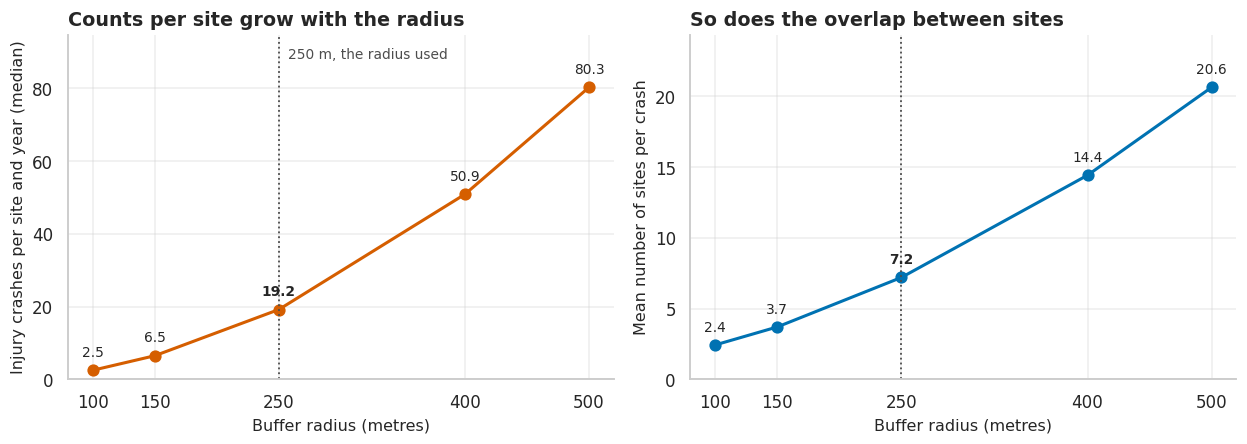

In [84]:
def plot_radius_profile(radius_table):
    """Two panels over the candidate radii: injury crashes per site and the overlap between sites."""
    fig, (ax_signal, ax_overlap) = plt.subplots(1, 2, figsize=(11.5, 4.2))
    panel_specs = [
        (ax_signal, "injury crashes per site and year (median)", PALETTE["crash"],
         "Counts per site grow with the radius", "Injury crashes per site and year (median)"),
        (ax_overlap, "sites sharing each near crash (mean)", PALETTE["housing"],
         "So does the overlap between sites", "Mean number of sites per crash"),
    ]
    for ax, column, color, title, ylabel in panel_specs:
        ax.plot(radius_table.index, radius_table[column], color=color, linewidth=2, marker="o", markersize=7)
        for radius, value in radius_table[column].items():
            ax.annotate(f"{value:.1f}", (radius, value), textcoords="offset points", xytext=(0, 9), ha="center",
                        fontsize=9, fontweight="bold" if radius == BUFFER_M else "normal")
        ax.axvline(BUFFER_M, color=PALETTE["neutral"], linestyle=":", linewidth=1.2)
        ax.set_xticks(RADIUS_CANDIDATES_M)
        ax.set_ylim(0, radius_table[column].max() * LINE_HEADROOM)
        finish(ax, title, "Buffer radius (metres)", ylabel)
    ax_signal.annotate(f"{BUFFER_M} m, the radius used", xy=(BUFFER_M, ax_signal.get_ylim()[1] * 0.93),
                       xytext=(6, 0), textcoords="offset points", fontsize=9, color=PALETTE["neutral"])
    plt.tight_layout()
    plt.show()


plot_radius_profile(radius_table)

In [85]:
chosen = radius_table.loc[BUFFER_M]
smallest_radius, largest_radius = RADIUS_CANDIDATES_M[0], RADIUS_CANDIDATES_M[-1]
say(f"At {smallest_radius} m the median site sees {radius_table.loc[smallest_radius, 'injury crashes per site and year (median)']:.1f} "
    f"injury crashes a year and {radius_table.loc[smallest_radius, '% of sites below one injury crash a year']:.0f}% "
    f"of sites see fewer than one, so a before and after comparison at one site would mostly compare small "
    f"counts. At {BUFFER_M} m the median is {chosen['injury crashes per site and year (median)']:.1f} and "
    f"{chosen['% of sites below one injury crash a year']:.1f}% of sites are below one a year. At "
    f"{largest_radius} m a crash near housing lies within the radius of "
    f"{radius_table.loc[largest_radius, 'sites sharing each near crash (mean)']:.0f} sites on average and "
    f"{radius_table.loc[largest_radius, '% of located injury crashes near a site']:.0f}% of all located injury "
    f"crashes count as near housing, against {chosen['sites sharing each near crash (mean)']:.1f} sites and "
    f"{chosen['% of located injury crashes near a site']:.0f}% at {BUFFER_M} m.")

At 100 m the median site sees 2.5 injury crashes a year and 22% of sites see fewer than one, so a before and after comparison at one site would mostly compare small counts. At 250 m the median is 19.2 and 0.5% of sites are below one a year. At 500 m a crash near housing lies within the radius of 21 sites on average and 78% of all located injury crashes count as near housing, against 7.2 sites and 58% at 250 m.

No radius is free of both problems. A small one gives counts too low to compare, and a large
one turns "near a building" into "anywhere in the built-up city". The 250 m radius is the
smallest of the five at which nearly every site has at least one injury crash a year, and it
corresponds to a walk of about three minutes. The overlap at 250 m is already large, and 5.4
handles it explicitly instead of assuming that sites are independent. Section 9 repeats the
main results at other radii with the functions defined here.

Two alternatives were considered. Census tracts would give fixed, non-overlapping areas, and
the raw housing table carries a tract code. The crash table does not, so assigning crashes to
tracts would need a boundary file, and this notebook reads only its two data files. A fixed
grid of square cells needs no outside file, and Section 6 uses one for a different purpose, but
a grid is not centred on the buildings: a building at the edge of its cell would be compared
with crashes up to a cell width away on one side and none on the other. A buffer is centred on
each building by construction. Its cost is the overlap, which the next subsection measures.

### 5.4 Sites, clusters and the site by year table

A **site** is one located housing row, that is, one building in one project. Every located row
becomes a site whether or not it is completed, because buildings that are not finished yet are
the comparison group later on.

Buildings in this programme stand close together, often as several addresses of one project.
Two sites less than `BUFFER_M` apart have overlapping buffers and count many of the same
crashes, so their counts are not independent observations. A confidence interval that treated
each site as a separate draw would be too narrow. The sites are therefore grouped into
**clusters**: two sites belong to the same cluster if they are within `BUFFER_M` of each other,
directly or through a chain of other sites (the connected components of the graph that links
every such pair). A bootstrap builds an interval by drawing, many times, a new sample of the
same size from the data at hand, recomputing the estimate on each draw, and reading the spread
of those estimates. Intervals at the spatial level resample whole clusters of linked sites, so
sites that share crashes stay together in every draw. The exception is RQ7, which resamples
one-kilometre blocks for the reason given there.

Linking at one radius does not remove all sharing, since two sites up to twice the radius apart
can both reach a crash that lies between them. The cell after the next one measures how much
sharing is left between clusters. As a second, finer grouping for sensitivity checks, each site
also gets a `block_id`, the one-kilometre square it falls in.

,clusters,sites,% of sites
sites in the cluster,,,
1,276,276,3.600
2-5,197,543,7.200
6-20,58,584,7.700
21-100,24,927,12.200
101+,7,5263,69.300


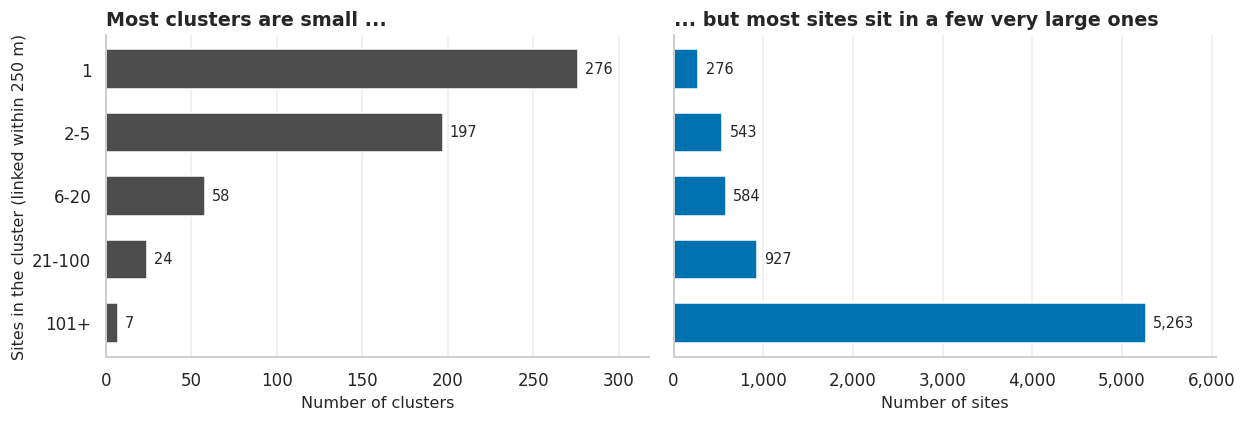

In [86]:
def connected_clusters(first, second, n_points):
    """Label the connected components of an undirected graph given as two arrays of linked points."""
    links = coo_matrix((np.ones(len(first), dtype=np.int8), (first, second)), shape=(n_points, n_points))
    _, labels = connected_components(links, directed=False)
    return labels.astype("int32")


def site_neighbour_pairs(site_frame, radius_m):
    """Pairs of sites within `radius_m` of each other, both directions, including each site with itself."""
    site_tree = build_haversine_tree(site_frame["lat"].to_numpy(), site_frame["lon"].to_numpy())
    first, second, _ = pairs_within_radius(site_tree, site_frame["lat"].to_numpy(),
                                           site_frame["lon"].to_numpy(), radius_m)
    return first, second


def build_sites(housing_frame, link_m=BUFFER_M):
    """One row per located housing row, with `site_id`, `cluster_id` and `block_id`.

    `site_id` is the row position (0..n-1), so it can index numpy arrays directly. `cluster_id`
    labels the connected components of sites within `link_m` metres of one another.
    """
    site_frame = housing_frame.loc[housing_frame["is_located"], SITE_ATTRIBUTES].reset_index(drop=True)
    site_frame.insert(0, "site_id", np.arange(len(site_frame), dtype="int32"))
    first, second = site_neighbour_pairs(site_frame, link_m)
    site_frame.insert(1, "cluster_id", connected_clusters(first, second, len(site_frame)))
    site_frame["cluster_size"] = site_frame.groupby("cluster_id")["site_id"].transform("size").astype("int32")
    # Other sites within the link distance (the pair list includes each site with itself).
    site_frame["n_sites_within_buffer"] = (np.bincount(first, minlength=len(site_frame)) - 1).astype("int32")

    # Square blocks: metres are converted to degrees separately for the two directions.
    block_lat_degrees = BLOCK_SIDE_M / METRES_PER_DEGREE
    block_lon_degrees = block_lat_degrees / math.cos(math.radians(MID_LATITUDE_DEG))
    block_keys = pd.DataFrame({"row": np.floor(site_frame["lat"] / block_lat_degrees).astype("int64"),
                               "column": np.floor(site_frame["lon"] / block_lon_degrees).astype("int64")})
    site_frame.insert(2, "block_id", block_keys.groupby(["row", "column"]).ngroup().astype("int32"))
    return site_frame


sites = build_sites(housing)
assert len(sites) == int(housing["is_located"].sum())
assert sites["site_id"].is_unique and not sites.duplicated(["project_id", "building_id"]).any()
assert (sites["site_id"].to_numpy() == np.arange(len(sites))).all()

cluster_sizes = sites.groupby("cluster_id").size()
cluster_bands = pd.cut(cluster_sizes, CLUSTER_SIZE_EDGES, labels=CLUSTER_SIZE_LABELS)
cluster_summary = pd.DataFrame({"clusters": cluster_bands.value_counts().reindex(CLUSTER_SIZE_LABELS),
                                "sites": cluster_sizes.groupby(cluster_bands, observed=False).sum()})
cluster_summary["% of sites"] = (100 * cluster_summary["sites"] / len(sites)).round(1)
display(cluster_summary.rename_axis("sites in the cluster"))


def plot_cluster_sizes(cluster_summary):
    """Number of clusters and number of sites by cluster-size band, side by side."""
    fig, (ax_clusters, ax_sites) = plt.subplots(1, 2, figsize=(11.5, 4.0), sharey=True)
    for ax, column, color, title in [
            (ax_clusters, "clusters", PALETTE["neutral"], "Most clusters are small ..."),
            (ax_sites, "sites", PALETTE["housing"], "... but most sites sit in a few very large ones")]:
        ax.barh(cluster_summary.index.astype(str), cluster_summary[column], color=color, height=0.62)
        for position, value in enumerate(cluster_summary[column]):
            ax.text(value + cluster_summary[column].max() * LABEL_GAP, position, f"{value:,}", va="center",
                    fontsize=9.5)
        ax.set_xlim(0, cluster_summary[column].max() * AXIS_HEADROOM)
        ax.grid(axis="y", visible=False)
        thousands(ax, "x")
        finish(ax, title, f"Number of {column}", "")
    ax_clusters.set_ylabel(f"Sites in the cluster (linked within {BUFFER_M} m)")
    ax_clusters.invert_yaxis()
    plt.tight_layout()
    plt.show()


plot_cluster_sizes(cluster_summary)

In [87]:
largest_clusters = cluster_sizes.sort_values(ascending=False)
largest_cluster_boroughs = sites.loc[sites["cluster_id"] == largest_clusters.index[0], "borough"].value_counts()
say(f"The {len(sites):,} sites form {len(cluster_sizes):,} clusters. {int((cluster_sizes == 1).sum())} clusters "
    f"are a single site with no other site within {BUFFER_M} m, but they hold only "
    f"{pct((cluster_sizes == 1).sum(), len(sites)):.1f}% of the sites. The three largest clusters contain "
    f"{', '.join(f'{size:,}' for size in largest_clusters.head(3))} sites, together "
    f"{pct(largest_clusters.head(3).sum(), len(sites)):.0f}% of all sites; the largest lies mostly in "
    f"{largest_cluster_boroughs.index[0]}. The median site has {sites['n_sites_within_buffer'].median():.0f} "
    f"other sites within {BUFFER_M} m. The finer grouping has {sites['block_id'].nunique():,} one-kilometre "
    f"blocks, the largest with {int(sites.groupby('block_id').size().max())} sites.")

The 7,593 sites form 562 clusters. 276 clusters are a single site with no other site within 250 m, but they hold only 3.6% of the sites. The three largest clusters contain 2,000, 1,508, 935 sites, together 59% of all sites; the largest lies mostly in Brooklyn. The median site has 12 other sites within 250 m. The finer grouping has 432 one-kilometre blocks, the largest with 161 sites.

Subsidised housing in New York is concentrated: in the neighbourhoods where most of it stands,
nearly every building has another one within the buffer, and the chain of neighbours does not
break for kilometres. The clusters are therefore very unequal. Resampling clusters is the
appropriate way to measure uncertainty here, because sites in one chain share crashes. It also
means that the effective number of independent units is far below the number of sites, so
intervals built on clusters will be wide.

#### 5.4.1 Counting crashes per site and calendar year

For every site and every study year the next cell counts the crashes within the buffer, the
injury crashes (the primary outcome, see Section 3), the injury crashes in which a pedestrian or
cyclist was hurt, and the persons injured. Each (site, crash) pair exists once, so a crash is
counted once per site.

In [88]:
def build_site_year(pairs, crash_frame, n_sites):
    """Balanced site x study-year table of crash counts from a (site, crash) pair list.

    One flat position per (site, year) lets a single `bincount` per measure do the counting,
    with no loop over sites.
    """
    crash_rows = pairs["crash_row"].to_numpy()
    year_offset = crash_frame["year"].to_numpy()[crash_rows].astype("int64") - YEAR_START
    flat_position = pairs["site_id"].to_numpy().astype("int64") * N_STUDY_YEARS + year_offset
    n_cells = n_sites * N_STUDY_YEARS
    weights = {
        "crashes": None,
        "injury_crashes": crash_frame["is_injury_crash"].to_numpy()[crash_rows].astype("float64"),
        "ped_cyc_crashes": crash_frame["ped_cyc_harm"].to_numpy()[crash_rows].astype("float64"),
        "persons_injured": crash_frame["injured"].to_numpy()[crash_rows].astype("float64"),
    }
    table = pd.DataFrame({
        "site_id": np.repeat(np.arange(n_sites, dtype="int32"), N_STUDY_YEARS),
        "year": np.tile(np.asarray(STUDY_YEARS, dtype="int16"), n_sites),
    })
    for column in SITE_COUNT_COLUMNS:
        table[column] = np.bincount(flat_position, weights=weights[column], minlength=n_cells).astype("int32")
    return table


site_pairs = site_crash_pairs(sites, crash_tree, crash_tree_rows, BUFFER_M)
site_year = build_site_year(site_pairs, crashes, len(sites))

# Each crash is counted once per site, and the table is balanced.
assert not site_pairs.duplicated(["site_id", "crash_row"]).any()
assert site_year["crashes"].sum() == len(site_pairs)
assert len(site_year) == len(sites) * N_STUDY_YEARS and not site_year.duplicated(["site_id", "year"]).any()
assert (site_year[SITE_COUNT_COLUMNS] >= 0).all().all()
assert (site_year["ped_cyc_crashes"] <= site_year["injury_crashes"]).all()
assert (site_year["injury_crashes"] <= site_year["crashes"]).all()

pair_is_injury = crashes["is_injury_crash"].to_numpy()[site_pairs["crash_row"].to_numpy()]
injury_pairs = site_pairs[pair_is_injury]
distinct_injury_crashes_near = injury_pairs["crash_row"].nunique()
clusters_per_crash = (injury_pairs.assign(cluster_id=sites["cluster_id"].to_numpy()[injury_pairs["site_id"]])
                      .groupby("crash_row")["cluster_id"].nunique())
say(f"There are {len(site_pairs):,} (site, crash) pairs within {BUFFER_M} m. The site counts of injury crashes "
    f"add up to {len(injury_pairs):,}, but only {distinct_injury_crashes_near:,} different injury crashes are "
    f"involved, so adding counts across sites would count the average crash "
    f"{len(injury_pairs) / distinct_injury_crashes_near:.1f} times. Counted by cluster instead, "
    f"{pct((clusters_per_crash == 1).sum(), len(clusters_per_crash)):.1f}% of those crashes belong to exactly "
    f"one cluster and {pct((clusters_per_crash > 1).sum(), len(clusters_per_crash)):.1f}% are still shared "
    f"between two or more clusters.")

There are 5,410,285 (site, crash) pairs within 250 m. The site counts of injury crashes add up to 1,557,791, but only 216,203 different injury crashes are involved, so adding counts across sites would count the average crash 7.2 times. Counted by cluster instead, 90.8% of those crashes belong to exactly one cluster and 9.2% are still shared between two or more clusters.

Site counts are therefore never summed across sites to get a total. They are used as repeated
measurements of the streets around each building, compared with the same site in other years,
and uncertainty comes from resampling clusters. The small share of crashes still shared between
clusters is the remaining dependence that the cluster bootstrap does not remove.

#### 5.4.2 The event-time table

To compare the years before and after a completion, calendar years are re-expressed relative to
the completion year: `rel_year` runs from minus `EVENT_WINDOW` to plus `EVENT_WINDOW`, with zero
for the completion year itself. A completion **cohort** is the set of sites completed in one
calendar year. Only cohorts whose whole window lies inside the study years are used, so that
every treated site is observed for the same number of years on both sides.

Crash reporting changed during these years (Section 3), so a site's own before and after
difference would mix the building with the citywide change. Each cohort therefore gets
**comparison** sites observed over the same calendar years: located sites that are not completed
by the end of the cohort's window, either because they are completed later or because they have
no completion date yet. These are places chosen for the same programme, which makes them more
similar to the treated sites than arbitrary street corners would be. A comparison site serves
every cohort for which it qualifies, so it can appear under several cohorts; the cluster
bootstrap accounts for that repetition because all copies of a site are resampled together.

A comparison site is only a comparison if nothing was completed next to it. Because the sites
are so densely packed, two screens are applied and recorded as flags.

For a comparison site, `near_completion_in_window` marks another site within the buffer whose
completion falls inside the cohort's window, and `near_earlier_completion` marks one completed
before the window opens. Either one makes the site `contaminated`: its streets already received
a completed building, so it is not an untreated place.

For a treated site, `near_completion_in_window` marks another site within the buffer that is
completed in a different year of the same window, which would blur the before and after
periods. Neighbours completed in the same year are treated as part of the same event and are
not flagged, since projects often finish several adjacent buildings together. A treated site is
`contaminated` when that flag is set. `near_earlier_completion` is recorded for treated sites
too, for information, but an earlier neighbour is present both before and after and does not
blur the comparison.

The rows stay in the table with their flags, so the cost of the screen is visible and Section 9
can relax it.

In [89]:
def event_cohorts(completion_year, window=EVENT_WINDOW):
    """Completion years present in the data whose full window of `window` years on each side lies inside the study years."""
    years_in_data = set(np.unique(completion_year[~np.isnan(completion_year)]).astype(int).tolist())
    return [year for year in full_window_years(window) if year in years_in_data]


def cohort_members(site_frame, first, second, cohort, window):
    """Treated and comparison sites of one cohort, with their contamination flags (one row per site)."""
    completion = site_frame["completion_year"].astype("float64").to_numpy()
    n_sites = len(site_frame)
    is_treated = completion == cohort
    # Not completed by the end of the window: completed later, or no completion date at all.
    is_comparison = np.isnan(completion) | (completion > cohort + window)

    neighbour_completion = completion[second]
    is_other_site = first != second
    in_window = is_other_site & (neighbour_completion >= cohort - window) & (neighbour_completion <= cohort + window)
    # A neighbour completed in the site's own completion year is the same event, not a second one.
    # For comparison sites the own year is missing or later than the window, so every neighbour counts.
    separate_event = in_window & (neighbour_completion != completion[first])
    earlier = is_other_site & (neighbour_completion < cohort - window)

    near_in_window = np.bincount(first[separate_event], minlength=n_sites) > 0
    near_earlier = np.bincount(first[earlier], minlength=n_sites) > 0
    member = is_treated | is_comparison
    return pd.DataFrame({
        "site_id": site_frame["site_id"].to_numpy()[member],
        "cohort": np.int16(cohort),
        "group": pd.Categorical(np.where(is_treated[member], "treated", "comparison"), categories=EVENT_GROUPS),
        "near_completion_in_window": near_in_window[member],
        "near_earlier_completion": near_earlier[member],
        "contaminated": np.where(is_treated[member], near_in_window[member],
                                 near_in_window[member] | near_earlier[member]),
    })


def build_event_panel(site_frame, site_year_frame, radius_m=BUFFER_M, window=EVENT_WINDOW, neighbour_pairs=None):
    """Site x cohort x relative-year table with crash counts, group and contamination flags.

    `radius_m` is the distance within which another completion contaminates a site; it should be
    the radius that was used to count the crashes in `site_year_frame`. `neighbour_pairs` is the
    output of `site_neighbour_pairs(site_frame, radius_m)` when the caller already has it, which
    saves building the same tree again.
    """
    first, second = neighbour_pairs if neighbour_pairs is not None else site_neighbour_pairs(site_frame, radius_m)
    cohorts = event_cohorts(site_frame["completion_year"].astype("float64").to_numpy(), window)
    members = pd.concat([cohort_members(site_frame, first, second, cohort, window) for cohort in cohorts],
                        ignore_index=True)
    relative_years = np.arange(-window, window + 1, dtype="int8")
    panel = members.loc[members.index.repeat(len(relative_years))].reset_index(drop=True)
    panel["rel_year"] = np.tile(relative_years, len(members))
    panel["year"] = (panel["cohort"] + panel["rel_year"]).astype("int16")
    panel = panel.merge(site_year_frame, on=["site_id", "year"], how="left", validate="many_to_one")
    attributes = site_frame[["site_id", "cluster_id", "block_id", "completion_year", "construction_type",
                             "borough", "size_band", "total_units"]]
    panel = panel.merge(attributes, on="site_id", how="left", validate="many_to_one")
    ordered = ["site_id", "cluster_id", "block_id", "cohort", "group", "rel_year", "year", *SITE_COUNT_COLUMNS,
               "contaminated", "near_completion_in_window", "near_earlier_completion", "completion_year",
               "construction_type", "borough", "size_band", "total_units"]
    return panel[ordered]


# The 250 m neighbour pairs are needed again by the independent check below, so they are built once.
site_first, site_second = site_neighbour_pairs(sites, BUFFER_M)
event_panel = build_event_panel(sites, site_year, neighbour_pairs=(site_first, site_second))

assert not event_panel.duplicated(["site_id", "cohort", "rel_year"]).any()
assert event_panel["year"].between(YEAR_START, YEAR_END).all()
assert event_panel[SITE_COUNT_COLUMNS].notna().all().all()
assert (event_panel.groupby(["site_id", "cohort"]).size() == 2 * EVENT_WINDOW + 1).all()
treated_rows = event_panel[event_panel["group"] == "treated"]
comparison_rows = event_panel[event_panel["group"] == "comparison"]
assert (treated_rows["completion_year"] == treated_rows["cohort"]).all()
assert (comparison_rows["completion_year"].isna()
        | (comparison_rows["completion_year"] > comparison_rows["cohort"] + EVENT_WINDOW)).all()
assert treated_rows.groupby("site_id")["cohort"].nunique().eq(1).all(), "a treated site has one cohort"

# No completed site within one buffer radius, checked independently of the flags: no clean
# comparison site may have any other site within the buffer that is completed by the end of its
# cohort's window.
site_completion = sites["completion_year"].astype("float64").to_numpy()
earliest_neighbour = pd.Series(site_completion[site_second][site_first != site_second]).groupby(
    site_first[site_first != site_second]).min().reindex(range(len(sites)))
clean_comparison = comparison_rows[~comparison_rows["contaminated"]]
neighbour_year_of_clean = earliest_neighbour.reindex(clean_comparison["site_id"]).to_numpy()
assert not (neighbour_year_of_clean <= clean_comparison["cohort"].to_numpy() + EVENT_WINDOW).any()

event_site_table = event_panel[event_panel["rel_year"] == 0]
cohort_counts = (event_site_table.assign(clean=~event_site_table["contaminated"])
                 .groupby(["cohort", "group"], observed=True)
                 .agg(candidates=("site_id", "size"), clean=("clean", "sum")).unstack("group"))
cohort_counts.columns = [f"{group}: {kind}" for kind, group in cohort_counts.columns]
cohort_counts = cohort_counts[[f"{group}: {kind}" for group in EVENT_GROUPS for kind in ["candidates", "clean"]]]
clean_event_site_table = event_site_table[~event_site_table["contaminated"]]
cohort_counts["treated clean: new construction"] = (
    clean_event_site_table[(clean_event_site_table["group"] == "treated")
                      & (clean_event_site_table["construction_type"] == "New Construction")]
    .groupby("cohort").size().reindex(cohort_counts.index, fill_value=0))
cohort_counts["treated clean: clusters"] = (clean_event_site_table[clean_event_site_table["group"] == "treated"]
                                            .groupby("cohort")["cluster_id"].nunique())
cohort_counts["comparison clean: clusters"] = (clean_event_site_table[clean_event_site_table["group"] == "comparison"]
                                               .groupby("cohort")["cluster_id"].nunique())
display(cohort_counts)

,treated: candidates,treated: clean,comparison: candidates,comparison: clean,treated clean: new construction,treated clean: clusters,comparison clean: clusters
cohort,,,,,,,
2019,757,157,3721,696,33,69,287
2020,360,44,3082,538,27,28,231
2021,497,59,2539,422,32,30,190
2022,472,46,1946,213,36,34,135


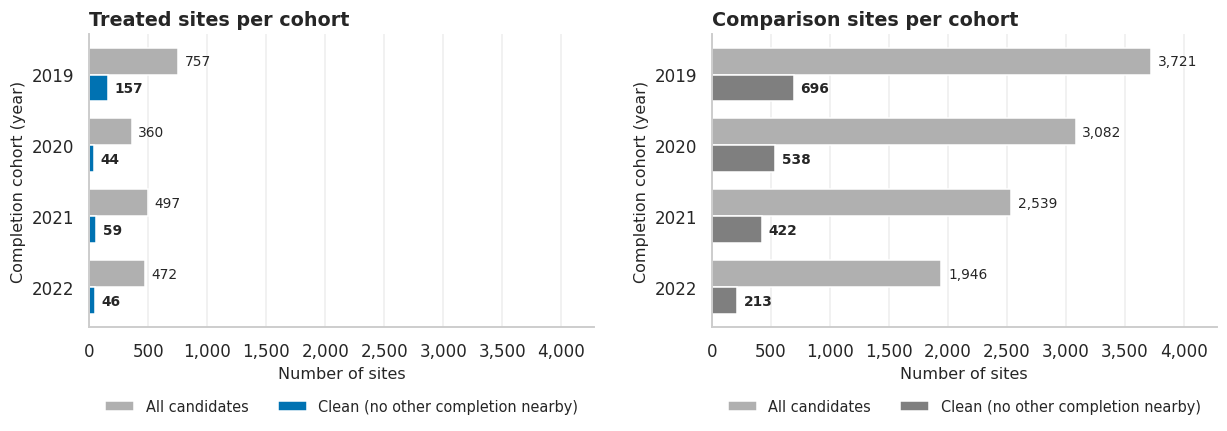

In [90]:
def plot_cohort_counts(cohort_counts):
    """Candidate and clean site counts per completion cohort, one panel per group."""
    fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2), sharex=True)
    bar_height = 0.38
    cohort_positions = np.arange(len(cohort_counts))
    largest_candidate_count = max(cohort_counts[f"{group}: candidates"].max() for group in EVENT_GROUPS)
    for ax, group, color in zip(axes, EVENT_GROUPS, [PALETTE["treated"], PALETTE["control"]]):
        candidates = cohort_counts[f"{group}: candidates"].to_numpy()
        clean = cohort_counts[f"{group}: clean"].to_numpy()
        ax.barh(cohort_positions - bar_height / 2, candidates, height=bar_height, color=PALETTE["before"],
                label="All candidates")
        ax.barh(cohort_positions + bar_height / 2, clean, height=bar_height, color=color,
                label="Clean (no other completion nearby)")
        for position, (n_candidates, n_clean) in enumerate(zip(candidates, clean)):
            ax.text(n_candidates + largest_candidate_count * LABEL_GAP, position - bar_height / 2,
                    f"{n_candidates:,}", va="center", fontsize=9)
            ax.text(n_clean + largest_candidate_count * LABEL_GAP, position + bar_height / 2, f"{n_clean:,}",
                    va="center", fontsize=9, fontweight="bold")
        ax.set_yticks(cohort_positions)
        ax.set_yticklabels(cohort_counts.index)
        ax.set_xlim(0, largest_candidate_count * AXIS_HEADROOM)
        ax.invert_yaxis()
        ax.grid(axis="y", visible=False)
        thousands(ax, "x")
        ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2)
        finish(ax, f"{group.capitalize()} sites per cohort", "Number of sites", "Completion cohort (year)")
    plt.tight_layout()
    plt.show()


plot_cohort_counts(cohort_counts)

In [91]:
treated_total = int(cohort_counts["treated: candidates"].sum())
treated_clean_total = int(cohort_counts["treated: clean"].sum())
comparison_distinct = event_site_table.loc[event_site_table["group"] == "comparison", "site_id"].nunique()
comparison_clean_distinct = clean_event_site_table.loc[clean_event_site_table["group"] == "comparison", "site_id"].nunique()
thinnest_cohort = cohort_counts["comparison: clean"].idxmin()
say(f"The cohorts with a full window are {', '.join(str(cohort) for cohort in cohort_counts.index)}. They hold "
    f"{treated_total:,} treated sites, of which {treated_clean_total:,} "
    f"({pct(treated_clean_total, treated_total):.0f}%) have no other completion nearby in a different year of "
    f"their window; {int(cohort_counts['treated clean: new construction'].sum())} of those are new "
    f"construction. Of {comparison_distinct:,} different comparison candidates, {comparison_clean_distinct:,} "
    f"are clean for at least one cohort. The thinnest comparison group is cohort {thinnest_cohort} with "
    f"{int(cohort_counts.loc[thinnest_cohort, 'comparison: clean'])} clean sites in "
    f"{int(cohort_counts.loc[thinnest_cohort, 'comparison clean: clusters'])} clusters. The event table has "
    f"{len(event_panel):,} rows.")

The cohorts with a full window are 2019, 2020, 2021, 2022. They hold 2,086 treated sites, of which 306 (15%) have no other completion nearby in a different year of their window; 128 of those are new construction. Of 3,721 different comparison candidates, 696 are clean for at least one cohort. The thinnest comparison group is cohort 2022 with 213 clean sites in 135 clusters. The event table has 93,618 rows.

The screen removes most candidates on both sides. Without it, the large majority of comparison
sites would have had a completed building within their buffer during or before the window, and
the comparison would have been between treated streets and other treated streets. What is left
is a much smaller sample, and the later cohorts have fewer comparison sites because fewer
buildings remain unfinished that late. The clean sites are also not a random subset: a site
with no completed neighbour lies, by definition, in a less dense part of the programme. Results
from the event table describe those places and are stated with their sample sizes.

The alternative of keeping contaminated sites and adding the number of nearby completions as a
control was rejected for the main analysis, because it replaces a clear rule with a modelling
assumption about how effects add up.

#### 5.4.3 What the screen does not rule out

The screen looks for completed sites within one buffer radius of a comparison site. Two
buffers of that radius still overlap while their centres are up to twice the radius apart, so a
comparison site that passes the screen can have a completed building 250 to 500 metres away,
and a crash between the two lies in both buffers. Such a crash is counted for the comparison
site and for the treated one. Crashes shared this way make the comparison sites partly
resemble the treated ones, which would pull a difference between the two toward zero. The next
cell measures how many clean comparison sites have such a neighbour, and how many of their
injury crashes are shared with it.

In [92]:
def other_site_completion_per_pair(pairs, site_frame):
    """For each (site, crash) pair, the earliest completion year of any other site that reaches the same crash.

    Sites that are not completed count as infinitely late. Sorting the pairs by crash and then
    by completion year puts the earliest site first in each crash's group, so a pair takes the
    group's first completion, or the second one when the pair is itself the first.
    """
    completion = site_frame["completion_year"].astype("float64").to_numpy()
    pair_completion = np.where(np.isnan(completion), np.inf, completion)[pairs["site_id"].to_numpy()]
    crash_rows = pairs["crash_row"].to_numpy()
    order = np.lexsort((pair_completion, crash_rows))
    sorted_rows = crash_rows[order]
    sorted_completion = pair_completion[order]
    is_first = np.r_[True, sorted_rows[1:] != sorted_rows[:-1]]
    group_start = np.flatnonzero(is_first)
    group_size = np.diff(np.r_[group_start, len(order)])
    group_id = np.cumsum(is_first) - 1
    start, size = group_start[group_id], group_size[group_id]
    second_completion = np.where(size > 1, sorted_completion[np.minimum(start + 1, len(order) - 1)], np.inf)
    other_sorted = np.where(np.arange(len(order)) == start, second_completion, sorted_completion[start])
    other_completion = np.empty(len(order))
    other_completion[order] = other_sorted
    return other_completion


clean_comparison_units = clean_event_site_table.loc[clean_event_site_table["group"] == "comparison", ["site_id", "cohort"]]
wide_first, wide_second = site_neighbour_pairs(sites, 2 * BUFFER_M)
is_other_wide = wide_first != wide_second
earliest_wide_neighbour = pd.Series(site_completion[wide_second][is_other_wide]).groupby(
    wide_first[is_other_wide]).min().reindex(range(len(sites)))
window_end = clean_comparison_units["cohort"].to_numpy() + EVENT_WINDOW
has_wide_neighbour = earliest_wide_neighbour.reindex(clean_comparison_units["site_id"]).to_numpy() <= window_end

injury_pair_context = injury_pairs.assign(
    other_completion=other_site_completion_per_pair(injury_pairs, sites),
    crash_year=crashes["year"].to_numpy()[injury_pairs["crash_row"].to_numpy()])
comparison_injury_pairs = clean_comparison_units.merge(
    injury_pair_context[["site_id", "crash_year", "other_completion"]], on="site_id")
in_cohort_window = comparison_injury_pairs["crash_year"].between(
    comparison_injury_pairs["cohort"] - EVENT_WINDOW, comparison_injury_pairs["cohort"] + EVENT_WINDOW)
comparison_injury_pairs = comparison_injury_pairs[in_cohort_window]
is_shared_with_completed = (comparison_injury_pairs["other_completion"]
                            <= comparison_injury_pairs["cohort"] + EVENT_WINDOW)
say(f"Of {len(clean_comparison_units):,} clean comparison units (a site in one cohort), "
    f"{has_wide_neighbour.sum():,} ({100 * has_wide_neighbour.mean():.1f}%) have another site within "
    f"{2 * BUFFER_M} m that is completed by the end of the cohort's window. Of the "
    f"{len(comparison_injury_pairs):,} injury crashes in their windows, {is_shared_with_completed.sum():,} "
    f"({100 * is_shared_with_completed.mean():.1f}%) also lie within {BUFFER_M} m of such a site, so they are "
    f"counted for the comparison site and for a completed site.")

# The same overlap on the treated side: another site within twice the radius that is completed in a
# different year of the treated site's own window, so that its buffer can share crashes with
# the treated one. Neighbours completed in the same year are one event and are not counted.
own_completion = site_completion[wide_first]
neighbour_completion_wide = site_completion[wide_second]
shares_window_with_other_event = (is_other_wide
                                  & (neighbour_completion_wide >= own_completion - EVENT_WINDOW)
                                  & (neighbour_completion_wide <= own_completion + EVENT_WINDOW)
                                  & (neighbour_completion_wide != own_completion))
overlaps_other_completion = np.bincount(wide_first[shares_window_with_other_event], minlength=len(sites)) > 0
clean_treated_units = clean_event_site_table[clean_event_site_table["group"] == "treated"]
clean_treated_overlap = overlaps_other_completion[clean_treated_units["site_id"].to_numpy()]
is_new_construction = (clean_treated_units["construction_type"] == "New Construction").to_numpy()
say(f"On the treated side, {clean_treated_overlap.sum():,} of {len(clean_treated_units):,} clean treated sites "
    f"({100 * clean_treated_overlap.mean():.0f}%) have another site within {2 * BUFFER_M} m that is completed "
    f"in a different year of their own window; among the {is_new_construction.sum():,} clean new-construction "
    f"sites it is {clean_treated_overlap[is_new_construction].sum():,} "
    f"({100 * clean_treated_overlap[is_new_construction].mean():.0f}%). Most treated sites that pass the "
    f"screen therefore still share part of their buffer with another completion.")

Of 1,869 clean comparison units (a site in one cohort), 1,020 (54.6%) have another site within 500 m that is completed by the end of the cohort's window. Of the 173,425 injury crashes in their windows, 44,998 (25.9%) also lie within 250 m of such a site, so they are counted for the comparison site and for a completed site.

On the treated side, 183 of 306 clean treated sites (60%) have another site within 500 m that is completed in a different year of their own window; among the 128 clean new-construction sites it is 89 (70%). Most treated sites that pass the screen therefore still share part of their buffer with another completion.

The share is large on both sides, so Section 9.5 repeats the comparison with only those sites,
on either side, whose buffer does not overlap the buffer of another completion. Its size is
stated here so that a contrast between treated and comparison sites is read with it in mind.

### 5.5 Tagging every crash with its relation to housing

This table describes how the crashes relate to housing and is used for the overview below. The
composition questions (RQ6, RQ8, RQ10) work from the pair list and the clean sites of 5.4,
where a crash near two clean sites counts for both. The pair list holds every crash within the
buffer of every site, and this subsection reduces it to one answer per crash.

A crash near several sites is assigned to the **nearest** one. That makes the assignment a
partition: each crash belongs to at most one site, the same place always belongs to the same
site whatever the year, and comparing the crashes of one site before and after its completion
compares the same streets. When two sites are at the same distance, which happens when one
building appears in two projects, the earlier completion is taken, then the lower `site_id`, so
the rule is deterministic.

The relation is defined on calendar years, as in the event table. A crash in a year before the
nearest site's completion year, or near a site with no completion date, is "Before completion".
A crash in a later year is "After completion". A crash in the completion year itself gets its
own label, "Completion year", and belongs to neither side: the building was finished for part
of that year only, and many completion dates in this table are administrative (Section 4.4
found many buildings completed on their start date), so splitting the year at the recorded day
would claim a precision that the dates do not have.

Because the nearest site can be unfinished while another site inside the buffer is already
completed, a second column, `near_completed_site`, records whether any site within the buffer
was completed in an earlier year than the crash.

,all crashes,injury crashes,% of injury crashes
housing_relation,,,
No coordinates,132500,35107,8.600
Not near a site,589253,158657,38.700
Before completion,547596,136420,33.300
Completion year,52217,15157,3.700
After completion,183156,64626,15.800


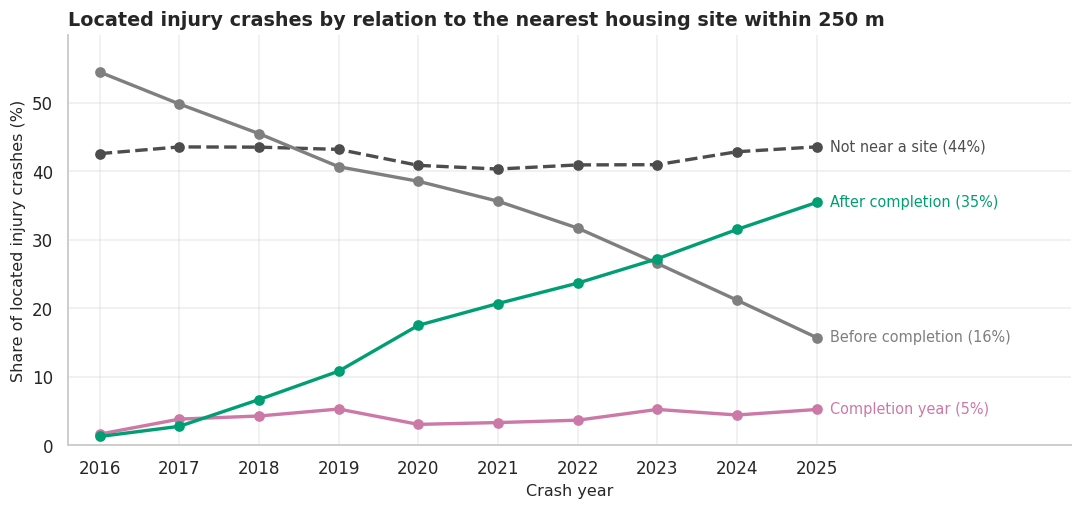

In [93]:
def tag_crashes_with_housing(crash_frame, site_frame, pairs):
    """Add the housing-relation columns to the crash frame (one nearest site per crash) and return it."""
    n_crashes = len(crash_frame)
    crash_rows = pairs["crash_row"].to_numpy()
    site_ids = pairs["site_id"].to_numpy()
    completion = site_frame["completion_year"].astype("float64").to_numpy()
    pair_completion = completion[site_ids]
    crash_year = crash_frame["year"].to_numpy()

    # Sort the pairs by crash, then distance, then completion year (missing last), then site id.
    # The first pair of each crash is then its nearest site under the tie-break described above.
    completion_sort_key = np.where(np.isnan(pair_completion), np.inf, pair_completion)
    order = np.lexsort((site_ids, completion_sort_key, pairs["distance_m"].to_numpy(), crash_rows))
    sorted_rows = crash_rows[order]
    is_first = np.r_[True, sorted_rows[1:] != sorted_rows[:-1]]
    nearest_pairs = order[is_first]
    near_rows = crash_rows[nearest_pairs]

    near_site = pd.array(np.full(n_crashes, pd.NA), dtype="Int32")
    near_site[near_rows] = site_ids[nearest_pairs]
    near_cluster = pd.array(np.full(n_crashes, pd.NA), dtype="Int32")
    near_cluster[near_rows] = site_frame["cluster_id"].to_numpy()[site_ids[nearest_pairs]]
    near_distance = np.full(n_crashes, np.nan, dtype="float32")
    near_distance[near_rows] = pairs["distance_m"].to_numpy()[nearest_pairs]
    near_completion = np.full(n_crashes, np.nan)
    near_completion[near_rows] = pair_completion[nearest_pairs]
    relative_year = crash_year - near_completion

    is_located = crash_frame["is_located"].to_numpy()
    has_site = np.zeros(n_crashes, dtype=bool)
    has_site[near_rows] = True
    relation = np.select(
        [~is_located, ~has_site, relative_year > 0, relative_year == 0],
        ["No coordinates", "Not near a site", "After completion", "Completion year"],
        default="Before completion")

    completed_earlier = pair_completion < crash_year[crash_rows]
    crash_frame["housing_relation"] = pd.Categorical(relation, categories=HOUSING_RELATIONS)
    crash_frame["near_site_id"] = near_site
    crash_frame["near_cluster_id"] = near_cluster
    crash_frame["near_site_distance_m"] = near_distance
    crash_frame["near_completion_year"] = pd.array(near_completion, dtype="Int16")
    crash_frame["rel_year"] = pd.array(relative_year, dtype="Int16")
    crash_frame["n_sites_near"] = np.bincount(crash_rows, minlength=n_crashes).astype("int16")
    crash_frame["near_completed_site"] = np.bincount(crash_rows[completed_earlier], minlength=n_crashes) > 0
    return crash_frame


crashes = tag_crashes_with_housing(crashes, sites, site_pairs)

assert crashes["housing_relation"].notna().all(), "every crash gets exactly one relation to housing"
assert crashes["near_site_id"].notna().sum() == site_pairs["crash_row"].nunique()
assert (crashes["near_site_id"].notna() == (crashes["n_sites_near"] > 0)).all()
assert crashes.loc[crashes["near_site_id"].notna(), "near_site_distance_m"].le(BUFFER_M).all()
assert (crashes["housing_relation"] == "No coordinates").sum() == (~crashes["is_located"]).sum()
assert crashes.loc[crashes["housing_relation"] == "After completion", "near_completed_site"].all()

injury_crash_rows = crashes[crashes["is_injury_crash"]]
relation_table = pd.DataFrame({
    "all crashes": crashes["housing_relation"].value_counts().reindex(HOUSING_RELATIONS),
    "injury crashes": injury_crash_rows["housing_relation"].value_counts().reindex(HOUSING_RELATIONS),
})
relation_table["% of injury crashes"] = (100 * relation_table["injury crashes"] / len(injury_crash_rows)).round(1)
display(relation_table)

before_rows = injury_crash_rows[injury_crash_rows["housing_relation"] == "Before completion"]
relation_by_year = (pd.crosstab(injury_crash_rows["year"], injury_crash_rows["housing_relation"])
                    .reindex(columns=HOUSING_RELATIONS, fill_value=0).drop(columns="No coordinates"))
relation_share_by_year = 100 * relation_by_year.div(relation_by_year.sum(axis=1), axis=0)


def plot_relation_shares(relation_share_by_year):
    """One line per housing relation: share of located injury crashes by crash year."""
    # One line per state with its name at the right end: in a stacked bar the middle bands float,
    # so their changes over the years could not be compared.
    fig, ax = plt.subplots(figsize=(10, 4.8))
    for relation_name in relation_share_by_year.columns:
        shares = relation_share_by_year[relation_name]
        color = RELATION_COLORS[relation_name]
        ax.plot(shares.index, shares.to_numpy(), color=color, linewidth=2.2, marker="o", markersize=6,
                linestyle="--" if relation_name == "Not near a site" else "-")
        ax.annotate(f"{relation_name} ({shares.iloc[-1]:.0f}%)", (YEAR_END, shares.iloc[-1]), xytext=(9, 0),
                    textcoords="offset points", va="center", fontsize=9.5, color=color)
    ax.set_xticks(relation_share_by_year.index)
    ax.set_xlim(YEAR_START - 0.4, YEAR_END + 3.2)
    ax.set_ylim(0, relation_share_by_year.to_numpy().max() * 1.1)
    finish(ax, f"Located injury crashes by relation to the nearest housing site within {BUFFER_M} m",
           "Crash year", "Share of located injury crashes (%)")
    plt.tight_layout()
    plt.show()


plot_relation_shares(relation_share_by_year)

In [94]:
first_year_share = relation_share_by_year.loc[YEAR_START]
last_year_share = relation_share_by_year.loc[YEAR_END]
say(f"Of {len(injury_crash_rows):,} injury crashes, {relation_table.loc['No coordinates', '% of injury crashes']:.1f}% "
    f"have no coordinates and cannot be tagged, and "
    f"{relation_table.loc['Not near a site', '% of injury crashes']:.1f}% are located but not within {BUFFER_M} m "
    f"of any site. The rest are near a site: {int(relation_table.loc['Before completion', 'injury crashes']):,} "
    f"before its completion, {int(relation_table.loc['Completion year', 'injury crashes']):,} in the completion "
    f"year and {int(relation_table.loc['After completion', 'injury crashes']):,} after. Among located injury "
    f"crashes the share that falls after the nearest site's completion rises from "
    f"{first_year_share['After completion']:.0f}% in {YEAR_START} to {last_year_share['After completion']:.0f}% "
    f"in {YEAR_END}, while the share not near any site is {first_year_share['Not near a site']:.0f}% in "
    f"{YEAR_START}, {last_year_share['Not near a site']:.0f}% in {YEAR_END} and between "
    f"{relation_share_by_year['Not near a site'].min():.0f}% and "
    f"{relation_share_by_year['Not near a site'].max():.0f}% in every year. "
    f"Of the crashes tagged as before completion, {100 * before_rows['near_completed_site'].mean():.0f}% have "
    f"another, already completed site within the buffer.")

Of 409,967 injury crashes, 8.6% have no coordinates and cannot be tagged, and 38.7% are located but not within 250 m of any site. The rest are near a site: 136,420 before its completion, 15,157 in the completion year and 64,626 after. Among located injury crashes the share that falls after the nearest site's completion rises from 1% in 2016 to 35% in 2025, while the share not near any site is 43% in 2016, 44% in 2025 and between 40% and 44% in every year. Of the crashes tagged as before completion, 33% have another, already completed site within the buffer.

The share of crashes near any site hardly moves over the ten years, which is expected because
the set of sites is fixed: it contains every located building of the programme whatever its
completion year. What changes is the split between before and after, simply because more
buildings are finished as time passes. A comparison of "after" crashes with "before" crashes
is therefore also a comparison of later years with earlier years, and any crash-level question
has to compare shares within the same sites or the same years, not raw counts. The last number
above shows why `near_completed_site` is kept: many crashes that precede their nearest site's
completion already had a finished building within the buffer, so "before completion" does not
mean that no housing was nearby.

### 5.6 What the integrated tables look like

Four tables now exist besides the two cleaned ones. The ZIP by year panel is still the naive
version and is replaced in Section 6; the three spatial tables are final.

In [95]:
integrated_overview = pd.DataFrame([
    {"table": "sites", "grain": "one located building in one project",
     "rows": len(sites), "columns": sites.shape[1], "unique key": "site_id"},
    {"table": "site_year", "grain": "site x calendar year",
     "rows": len(site_year), "columns": site_year.shape[1], "unique key": "site_id, year"},
    {"table": "event_panel", "grain": "site x cohort x relative year",
     "rows": len(event_panel), "columns": event_panel.shape[1], "unique key": "site_id, cohort, rel_year"},
    {"table": "crashes (tagged)", "grain": "one collision",
     "rows": len(crashes), "columns": crashes.shape[1], "unique key": "collision_id"},
    {"table": "naive_panel (replaced in 6.1)", "grain": "ZIP x year, unbalanced",
     "rows": len(naive_panel), "columns": naive_panel.shape[1], "unique key": "zip, year"},
]).set_index("table")
display(integrated_overview)

,grain,rows,columns,unique key
table,,,,
sites,one located building in one project,7593,25,site_id
site_year,site x calendar year,75930,6,"site_id, year"
event_panel,site x cohort x relative year,93618,19,"site_id, cohort, rel_year"
crashes (tagged),one collision,1504722,35,collision_id
naive_panel (replaced in 6.1),"ZIP x year, unbalanced",2112,14,"zip, year"


In [96]:
display(sites.head(4))
display(site_year.head(4))
display(event_panel[event_panel["rel_year"].isin([-1, 0, 1])].head(6))
display(crashes.loc[crashes["near_site_id"].notna(),
                    ["collision_id", "crash_date", "year", "is_injury_crash", "housing_relation", "near_site_id",
                     "near_cluster_id", "near_site_distance_m", "near_completion_year", "rel_year",
                     "n_sites_near", "near_completed_site"]].head(5))

,site_id,cluster_id,block_id,housing_id,project_id,building_id,project_name,borough,zip,lat,lon,start_year,completion_year,is_completed,same_day_completion,completion_before_start,construction_type,total_units,all_counted_units,deep_affordable_units,deep_affordable_share,size_band,is_size_outlier,cluster_size,n_sites_within_buffer
0,0,0,326,0,48646,375,SKA MARIN. 1918 FIRST AVE. DRAPER HALL,Manhattan,10029,40.785,-73.943,2014,2017,True,False,False,Preservation,203,203,202,0.995,150+,True,935,3
1,1,0,326,1,68660,382,RIVER CROSSING OWNER HDFC.HPO.FY20,Manhattan,10029,40.786,-73.943,2019,2019,True,True,False,Preservation,306,202,0,0.000,150+,True,935,7
2,2,0,326,2,61875,413,1199 HOUSING CORP.PLP.FY19,Manhattan,10029,40.790,-73.940,2019,2024,True,False,False,Preservation,426,426,426,1.000,150+,True,935,13
3,3,0,332,3,66805,452,TRIPLE HDFC.HPO.FY19,Manhattan,10029,40.795,-73.936,2018,2019,True,False,False,Preservation,8,8,0,0.000,5-19,False,935,21


,site_id,year,crashes,injury_crashes,ped_cyc_crashes,persons_injured
0,0,2016,223,25,5,43
1,0,2017,292,50,15,60
2,0,2018,324,47,17,58
3,0,2019,277,68,19,103


,site_id,cluster_id,block_id,cohort,group,rel_year,year,crashes,injury_crashes,ped_cyc_crashes,persons_injured,contaminated,near_completion_in_window,near_earlier_completion,completion_year,construction_type,borough,size_band,total_units
2,1,0,326,2019,treated,-1,2018,172,37,6,45,True,True,False,2019,Preservation,Manhattan,150+,306
3,1,0,326,2019,treated,0,2019,150,36,9,65,True,True,False,2019,Preservation,Manhattan,150+,306
4,1,0,326,2019,treated,1,2020,127,35,12,52,True,True,False,2019,Preservation,Manhattan,150+,306
9,2,0,326,2019,comparison,-1,2018,140,24,6,31,True,True,False,2024,Preservation,Manhattan,150+,426
10,2,0,326,2019,comparison,0,2019,147,37,15,44,True,True,False,2024,Preservation,Manhattan,150+,426
11,2,0,326,2019,comparison,1,2020,128,33,8,57,True,True,False,2024,Preservation,Manhattan,150+,426


,collision_id,crash_date,year,is_injury_crash,housing_relation,near_site_id,near_cluster_id,near_site_distance_m,near_completion_year,rel_year,n_sites_near,near_completed_site
2,3363357,2016-01-01,2016,True,Before completion,5872,411,136.663,2022,-6,3,False
4,3363361,2016-01-01,2016,False,Before completion,5445,1,84.306,2018,-2,8,True
5,3363366,2016-01-01,2016,False,Before completion,253,1,68.967,2022,-6,20,False
6,3363367,2016-01-01,2016,True,Before completion,5175,1,116.162,2018,-2,9,False
7,3363368,2016-01-01,2016,False,Before completion,254,1,125.731,2017,-1,7,False


Each table is unique on its key, and none of them was produced by a row-level key join between
housing and crashes. The spatial tables were built by counting crashes inside buffers, and the
ZIP panel by aggregating first. The working objects that are no longer needed are released; the
crash tree, the pair list and the functions stay, because Section 9 re-runs this section's steps
at other radii.

In [97]:
release("real_merge", "crashes_with_zip", "housing_with_zip", "zip_year_merge", "tree_pairs", "brute_pairs",
        "check_tree", "provisional_sites", "injury_pairs", "pair_is_injury", "clusters_per_crash",
        "injury_crash_rows", "before_rows", "treated_rows", "comparison_rows", "clean_comparison",
        "event_site_table", "clean_event_site_table", "injury_pair_context", "comparison_injury_pairs",
        "earliest_wide_neighbour", "wide_first", "wide_second", "own_completion",
        "neighbour_completion_wide", "shares_window_with_other_event", "clean_treated_units")

## 6. Post-integration cleaning

Section 4 cleaned each table by itself. Some problems only exist once the two tables meet, and
the naive panel of 5.2 showed them: cells that became missing because one side had no row, a
housing ZIP the crash table never uses, and a large group of crashes absent because they carry
no ZIP. This section repairs what can be repaired, counts what cannot, and fixes the form of the
integrated tables. It follows the same policy as Section 4 and records each rule in the same
log with `log_rule`.

| Problem created by integration | Where it is handled |
|---|---|
| New missing values from the joins | 6.1 |
| Inconsistent or redundant columns | 6.2 |
| Data type mismatches between the tables | 6.3 |
| Conservation of rows and totals | 6.4 |
| A citywide reference series | 6.5 |
| The rules logged and the final tables | 6.6 |

In [98]:
# --- Constants for Section 6 ------------------------------------------------------------------
# Side of the grid cells used to recover a ZIP from coordinates, in degrees, tried in this order.
# The fine cell is about one short block; the coarse cell is the fallback when no crash with a
# reported ZIP falls in the fine cell. Both values are justified with a comparison in 6.1.
ZIP_CELL_DEGREES = (0.001, 0.004)
THREE_LEVEL_CASCADE = (0.001, 0.004, 0.016)   # the chosen pair plus a still coarser level
# Cell sizes and cascades compared before settling on the pair above.
ZIP_CELL_ALTERNATIVES = [(0.0005,), (0.001,), (0.002,), (0.004,), ZIP_CELL_DEGREES, THREE_LEVEL_CASCADE]
ZIP_HOLDOUT_SHARE = 0.10       # share of crashes with a known ZIP hidden from the lookup to test it

# A ZIP needs this many crashes over the ten study years (50 a year) to enter the panel. Smaller
# codes are single office towers or post-office codes, not neighbourhoods.
MIN_ZIP_CRASHES = 500

INDEX_BASE = 100               # the index equals this value in INDEX_BASE_YEAR (Section 1)
PER_THOUSAND = 1000            # deaths are expressed per 1,000 injury crashes

LABEL_OFFSET_POINTS = 9        # distance between a marker and its value label in the line charts
ACCURACY_AXIS_MAX = 100.8      # right edge of the accuracy chart: a little past 100 so the labels fit
ACCURACY_TICK_STEP = 2         # percentage points between ticks on that axis

POST_LOG_START = len(CLEANING_LOG)   # rules logged from here on belong to this section

### 6.1 New missing values created by the joins

#### 6.1.1 Three kinds of gap

The cell below restates the gaps of the naive panel as counts, so that the same table can be
shown again after the repair.

In [99]:
def panel_gap_report(panel, crash_frame, zip_column):
    """Counts that describe how complete a ZIP x year table is against the crash table."""
    measure_columns = [column for column in HOUSING_PANEL_MEASURES + CRASH_PANEL_MEASURES if column in panel]
    n_zips = panel["zip"].nunique()
    crashes_placed = int(panel["crashes"].sum())
    return {
        "rows": len(panel),
        "ZIP codes": n_zips,
        "rows missing from a balanced panel": n_zips * N_STUDY_YEARS - len(panel),
        "missing cells": int(panel[measure_columns].isna().sum().sum()),
        "ZIP-years with crashes but missing housing values": int(panel["units_completed"].isna().sum()),
        "ZIP-years with housing but missing crash values": int(panel["crashes"].isna().sum()),
        "crashes placed in a row": crashes_placed,
        "% of all crashes placed": round(pct(crashes_placed, len(crash_frame)), 1),
        "crashes with no ZIP": int(crash_frame[zip_column].isna().sum()),
    }


gaps_before = panel_gap_report(naive_panel, crashes, "zip")
# dtype=object keeps the counts as whole numbers; a mixed Series would turn them into decimals.
display(pd.Series(gaps_before, name="naive panel (5.2)", dtype=object).to_frame())
naive_no_zip_count = gaps_before["crashes with no ZIP"]
naive_crash_count = len(crashes)
say(f"The naive panel leaves out {pct(naive_no_zip_count, naive_crash_count):.1f}% of all crashes ({naive_no_zip_count:,} of {naive_crash_count:,}) "
    f"because they have no ZIP.")

,naive panel (5.2)
rows,2112
ZIP codes,232
rows missing from a balanced panel,208
missing cells,7546
ZIP-years with crashes but missing housing values,1256
ZIP-years with housing but missing crash values,2
crashes placed in a row,995800
% of all crashes placed,66.200
crashes with no ZIP,508922


The naive panel leaves out 33.8% of all crashes (508,922 of 1,504,722) because they have no ZIP.

Most ZIP-years with crashes have no housing row. No completion in that ZIP and year means zero
buildings and zero units, so the value is known and is filled with 0. Leaving it missing would
drop most of the panel from any calculation, and filling with a mean would invent completions.

A housing ZIP with no crash row at all gets no zero, as argued in 5.2. Such a ZIP cannot be
compared with anything, so it is left out of the panel and its units are counted.

The third case is crashes with no ZIP. The naive panel dropped them without saying so. The
sentence above gives the size of the loss, and the loss differs from year to year. Most of
these crashes have coordinates, and a coordinate determines a ZIP, so the ZIP is recovered from
the location.

#### 6.1.2 Recovering the ZIP of a crash from its coordinates

No boundary file is used in this notebook, but the crash table can teach the boundaries by
itself, because most crashes report both a ZIP and coordinates. The city is divided
into small square cells, and each cell is given the ZIP reported most often by the crashes
inside it. A crash without a ZIP then takes the ZIP of the cell it falls in. If its fine cell
contains no crash with a known ZIP, a coarser cell around it is tried. If that is empty as
well, the ZIP stays missing.

The method is deterministic and its accuracy can be measured: a random tenth of the crashes
that do have a ZIP is hidden, the lookup is learned from the other nine tenths, and the
prediction for the hidden rows is compared with what was reported.

One alternative is to assign the ZIP of the single nearest crash. It would look better on a
random holdout, because crashes are recorded at intersections and a hidden crash almost always
has a twin at exactly the same point, and one mislabelled crash would decide the ZIP of
everything around it. A cell vote uses all the crashes in the cell. Another alternative was to
leave the ZIP missing and work only at the spatial level. That was rejected because half of the
research questions are about neighbourhoods.

In [100]:
def grid_cells(lat, lon, cell_degrees):
    """Integer row and column of the square cell of side `cell_degrees` that each point falls in."""
    cell_row = np.floor(np.asarray(lat, dtype="float64") / cell_degrees).astype("int64")
    cell_column = np.floor(np.asarray(lon, dtype="float64") / cell_degrees).astype("int64")
    return cell_row, cell_column


def learn_cell_zips(lat, lon, zip_codes, cell_degrees):
    """Most frequent ZIP of every grid cell: one row per cell with its ZIP and the votes behind it.

    Ties are broken by the lower ZIP code so that the lookup does not depend on row order.
    """
    cell_row, cell_column = grid_cells(lat, lon, cell_degrees)
    votes = (pd.DataFrame({"cell_row": cell_row, "cell_column": cell_column,
                           "zip": np.asarray(zip_codes, dtype=object)})
             .groupby(["cell_row", "cell_column", "zip"]).size().rename("votes").reset_index())
    votes = votes.sort_values(["cell_row", "cell_column", "votes", "zip"], ascending=[True, True, False, True])
    return votes.drop_duplicates(["cell_row", "cell_column"]).reset_index(drop=True)


def learn_zip_lookups(lat, lon, zip_codes, cell_sizes=ZIP_CELL_DEGREES):
    """One cell-to-ZIP lookup per cell size, finest first."""
    return [(cell_degrees, learn_cell_zips(lat, lon, zip_codes, cell_degrees)) for cell_degrees in cell_sizes]


def zip_from_cells(lat, lon, lookups):
    """ZIP for each point from the first lookup that covers it.

    Returns the ZIP (None where no lookup has the cell) and the level that supplied it
    (1 = finest cell, 2 = next, 0 = none).
    """
    recovered = np.full(len(lat), None, dtype=object)
    level = np.zeros(len(lat), dtype="int8")
    for level_number, (cell_degrees, cell_zips) in enumerate(lookups, start=1):
        cell_row, cell_column = grid_cells(lat, lon, cell_degrees)
        # A left merge keeps the points in their original order, so the result lines up by position.
        matched = pd.DataFrame({"cell_row": cell_row, "cell_column": cell_column}).merge(
            cell_zips[["cell_row", "cell_column", "zip"]], on=["cell_row", "cell_column"], how="left")["zip"]
        fill = (level == 0) & matched.notna().to_numpy()
        recovered[fill] = matched.to_numpy(dtype=object)[fill]
        level[fill] = level_number
    return recovered, level


def predict_hidden_zips(train, test, cell_sizes):
    """Learn the cell lookups from `train` and predict the ZIP of every `test` row.

    Returns the lookups, the predicted ZIPs (None where no cell covers a point) and the level
    that supplied each one (0 = none). The caller scores them against the reported ZIPs.
    """
    lookups = learn_zip_lookups(train["lat"].to_numpy(), train["lon"].to_numpy(), train["zip"], cell_sizes)
    predicted, level = zip_from_cells(test["lat"].to_numpy(), test["lon"].to_numpy(), lookups)
    return lookups, predicted, level


def cascade_label(cell_sizes):
    """Row label of a cell-size cascade in the comparison table, for example '0.001 then 0.004'."""
    return " then ".join(f"{size:g}" for size in cell_sizes)


# The recovery overwrites `zip`, so a second run would treat the recovered values as reported ones and
# find nothing left to recover. Stop with a clear message instead.
assert "zip_imputed" not in crashes.columns, "6.1 has already run on this `crashes`; restart the kernel and run all"
labelled = crashes.loc[crashes["is_located"] & crashes["zip"].notna(), ["lat", "lon", "zip", "borough"]]

# A few reports carry a borough and ZIP that their own coordinates contradict, for example a
# Brooklyn ZIP on a point in the west of Staten Island. On a highway where almost no other crash
# reports a ZIP, one such report would teach the lookup a wrong ZIP for every crash around it.
# They are found by comparing each report with its wider area and are not used as evidence.
CONFLICT_CELL_DEGREES = 0.05     # about 5 km: wide enough to hold many reports even along highways
CONFLICT_MIN_REPORTS = 200       # an area needs this many reports before it can contradict one
CONFLICT_MIN_SHARE = 0.99        # and this share of them in one borough (areas on a border never reach it)


def reports_contradicting_location(reports):
    """True for reports whose borough differs from the one nearly every report in their area gives."""
    with_borough = reports[reports["borough"].notna()]
    area = (np.floor(with_borough["lat"] / CONFLICT_CELL_DEGREES).astype(int).astype(str) + "_"
            + np.floor(with_borough["lon"] / CONFLICT_CELL_DEGREES).astype(int).astype(str))
    counts = pd.crosstab(area.to_numpy(), with_borough["borough"].astype(str).to_numpy())
    settled = (counts.sum(axis=1) >= CONFLICT_MIN_REPORTS) & (counts.max(axis=1) / counts.sum(axis=1) >= CONFLICT_MIN_SHARE)
    area_borough = counts.idxmax(axis=1).where(settled)
    expected = area.map(area_borough)
    contradicts = expected.notna() & (expected != with_borough["borough"].astype(str))
    return contradicts.reindex(reports.index, fill_value=False)


# Kept as a Series on the crash index: later steps must not use these reports as evidence either.
location_conflict = pd.Series(False, index=crashes.index)
location_conflict.loc[labelled.index] = reports_contradicting_location(labelled).to_numpy()
labelled = labelled[~location_conflict.loc[labelled.index].to_numpy()]
log_rule("crashes", "reports whose borough and ZIP contradict their coordinates are not used to teach the ZIP lookup",
         "flag", len(crashes), len(crashes), int(location_conflict.sum()),
         "Their area has many reports and nearly all give another borough. The reported values are kept.")
say(f"{int(location_conflict.sum()):,} reports give a borough that at least {100 * CONFLICT_MIN_SHARE:.0f}% of the "
    f"reports in their area contradict. They keep what was reported and are left out of the evidence.")

zip_targets = crashes["is_located"].to_numpy() & crashes["zip"].isna().to_numpy()
target_lat = crashes["lat"].to_numpy()[zip_targets]
target_lon = crashes["lon"].to_numpy()[zip_targets]

holdout_rng = np.random.default_rng(SEED)
is_hidden = holdout_rng.random(len(labelled)) < ZIP_HOLDOUT_SHARE
train_rows, hidden_rows = labelled[~is_hidden], labelled[is_hidden]
hidden_truth = hidden_rows["zip"].to_numpy(dtype=object)

cell_trial_rows = []
for cell_sizes in ZIP_CELL_ALTERNATIVES:
    trial_lookups, trial_predicted, trial_level = predict_hidden_zips(train_rows, hidden_rows, cell_sizes)
    _, target_level = zip_from_cells(target_lat, target_lon, trial_lookups)
    covered = trial_level > 0
    cell_trial_rows.append({
        "cell sizes (degrees)": cascade_label(cell_sizes),
        "hidden rows covered (%)": 100 * covered.mean(),
        "accuracy where covered (%)": 100 * (trial_predicted[covered] == hidden_truth[covered]).mean(),
        "accuracy of the last level alone (%)": 100 * (
            trial_predicted[trial_level == len(cell_sizes)] == hidden_truth[trial_level == len(cell_sizes)]).mean(),
        "crashes without ZIP covered (%)": 100 * (target_level > 0).mean(),
    })
cell_comparison = pd.DataFrame(cell_trial_rows).set_index("cell sizes (degrees)")
display(cell_comparison.round(1))

# The commentary below reads rows of this table by name, so the rows it needs must exist.
fine_cell_label = cascade_label(ZIP_CELL_DEGREES[:1])
chosen_label = cascade_label(ZIP_CELL_DEGREES)
three_level_label = cascade_label(THREE_LEVEL_CASCADE)
assert {fine_cell_label, chosen_label, three_level_label} <= set(cell_comparison.index)

fine_cell_m = (ZIP_CELL_DEGREES[0] * METRES_PER_DEGREE,
               ZIP_CELL_DEGREES[0] * METRES_PER_DEGREE * math.cos(math.radians(MID_LATITUDE_DEG)))
say(f"A cell of {ZIP_CELL_DEGREES[0]:g} degrees measures about {fine_cell_m[0]:.0f} m north to south and "
    f"{fine_cell_m[1]:.0f} m east to west. The table shows the trade-off: the smaller the cell, the more "
    f"often its vote is right and the fewer crashes it covers. The cascade '{chosen_label}' keeps the accuracy "
    f"of the fine cell ({cell_comparison.loc[chosen_label, 'accuracy where covered (%)']:.1f}%) and covers "
    f"{cell_comparison.loc[chosen_label, 'crashes without ZIP covered (%)']:.1f}% of the crashes that need a "
    f"ZIP, against {cell_comparison.loc[fine_cell_label, 'crashes without ZIP covered (%)']:.1f}% "
    f"for the fine cell alone. A third, still coarser level would cover a little more, but its own votes are "
    f"right only {cell_comparison.loc[three_level_label, 'accuracy of the last level alone (%)']:.0f}% of the "
    f"time, so it is not used.")

441 reports give a borough that at least 99% of the reports in their area contradict. They keep what was reported and are left out of the evidence.

,hidden rows covered (%),accuracy where covered (%),accuracy of the last level alone (%),crashes without ZIP covered (%)
cell sizes (degrees),,,,
0.0005,96.600,99.100,99.100,67.000
0.001,99.300,97.800,97.800,79.600
0.002,99.900,94.900,94.900,89.000
0.004,100.000,90.200,90.200,93.200
0.001 then 0.004,100.000,97.700,92.000,93.200
0.001 then 0.004 then 0.016,100.000,97.700,72.200,97.800


A cell of 0.001 degrees measures about 111 m north to south and 84 m east to west. The table shows the trade-off: the smaller the cell, the more often its vote is right and the fewer crashes it covers. The cascade '0.001 then 0.004' keeps the accuracy of the fine cell (97.7%) and covers 93.2% of the crashes that need a ZIP, against 79.6% for the fine cell alone. A third, still coarser level would cover a little more, but its own votes are right only 72% of the time, so it is not used.

The chosen cascade is now examined on the hidden rows in more detail: overall, by the level
that supplied the answer, and by borough.

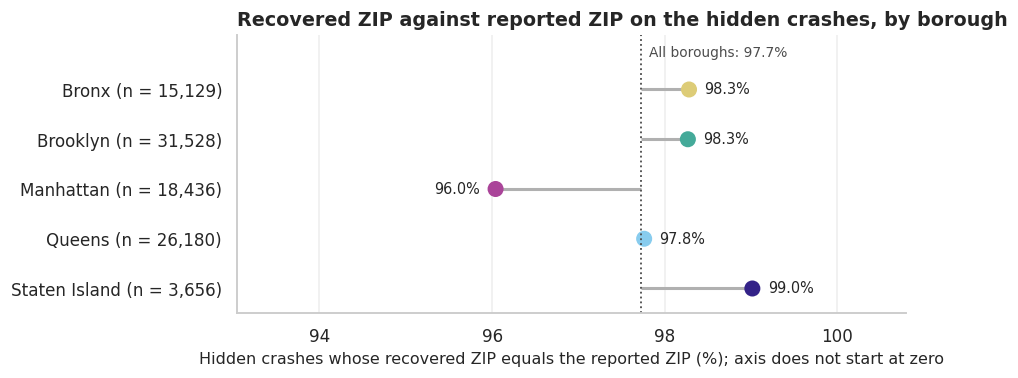

In [101]:
validation_lookups, hidden_predicted, hidden_level = predict_hidden_zips(train_rows, hidden_rows, ZIP_CELL_DEGREES)
hidden_result = pd.DataFrame({
    "borough": hidden_rows["borough"].to_numpy(),
    "level": hidden_level,
    "covered": hidden_level > 0,
    "correct": hidden_predicted == hidden_truth,
})
hidden_covered = hidden_result[hidden_result["covered"]]
holdout_accuracy = 100 * hidden_covered["correct"].mean()
accuracy_by_level = hidden_covered.groupby("level")["correct"].agg(["size", "mean"])
accuracy_by_borough = (hidden_covered.groupby("borough", observed=True)["correct"].agg(["size", "mean"])
                       .rename(columns={"size": "hidden rows", "mean": "accuracy"}))
accuracy_by_borough["accuracy"] *= 100

def plot_accuracy_by_borough(accuracy_by_borough, overall_accuracy):
    """Lollipop chart of the hold-out accuracy per borough against the overall accuracy."""
    fig, ax = plt.subplots(figsize=(8.5, 3.6))
    borough_positions = np.arange(len(accuracy_by_borough))
    ax.hlines(borough_positions, overall_accuracy, accuracy_by_borough["accuracy"], color=PALETTE["before"],
              linewidth=2, zorder=1)
    ax.scatter(accuracy_by_borough["accuracy"], borough_positions, s=90, zorder=2,
               color=[BOROUGH_COLORS[name] for name in accuracy_by_borough.index])
    for position, (borough_name, row) in enumerate(accuracy_by_borough.iterrows()):
        label_side = 1 if row["accuracy"] >= overall_accuracy else -1
        ax.annotate(f"{row['accuracy']:.1f}%", (row["accuracy"], position),
                    xytext=(10 * label_side, 0), textcoords="offset points", va="center",
                    ha="left" if label_side == 1 else "right", fontsize=9.5)
    ax.axvline(overall_accuracy, color=PALETTE["neutral"], linestyle=":", linewidth=1.2)
    ax.annotate(f"All boroughs: {overall_accuracy:.1f}%", (overall_accuracy, -0.75), xytext=(5, 0),
                textcoords="offset points", fontsize=9, color=PALETTE["neutral"], va="center")
    ax.set_yticks(borough_positions)
    ax.set_yticklabels([f"{name} (n = {int(row['hidden rows']):,})" for name, row in accuracy_by_borough.iterrows()])
    ax.set_ylim(len(accuracy_by_borough) - 0.5, -1.1)
    ax.set_xlim(accuracy_by_borough["accuracy"].min() - 3, ACCURACY_AXIS_MAX)
    ax.xaxis.set_major_locator(mpl.ticker.MultipleLocator(ACCURACY_TICK_STEP))
    ax.grid(axis="y", visible=False)
    finish(ax, "Recovered ZIP against reported ZIP on the hidden crashes, by borough",
           "Hidden crashes whose recovered ZIP equals the reported ZIP (%); axis does not start at zero", "")
    plt.tight_layout()
    plt.show()


plot_accuracy_by_borough(accuracy_by_borough, holdout_accuracy)

In [102]:
weakest_borough = accuracy_by_borough["accuracy"].idxmin()
say(f"{int(is_hidden.sum()):,} crashes with a known ZIP were hidden. The lookup learned from the other "
    f"{int((~is_hidden).sum()):,} covers {100 * hidden_result['covered'].mean():.2f}% of them and gives the "
    f"reported ZIP for {holdout_accuracy:.1f}% of those. The fine cell answers "
    f"{pct(accuracy_by_level.loc[1, 'size'], len(hidden_covered)):.1f}% of the covered rows with "
    f"{100 * accuracy_by_level.loc[1, 'mean']:.1f}% accuracy, and the coarse cell the rest with "
    f"{100 * accuracy_by_level.loc[2, 'mean']:.1f}%. By borough the accuracy runs from "
    f"{accuracy_by_borough['accuracy'].min():.1f}% in {weakest_borough} to "
    f"{accuracy_by_borough['accuracy'].max():.1f}% in {accuracy_by_borough['accuracy'].idxmax()}.")

94,947 crashes with a known ZIP were hidden. The lookup learned from the other 857,339 covers 99.98% of them and gives the reported ZIP for 97.7% of those. The fine cell answers 99.3% of the covered rows with 97.8% accuracy, and the coarse cell the rest with 92.0%. By borough the accuracy runs from 96.0% in Manhattan to 99.0% in Staten Island.

The errors that remain are mostly not errors of location. A crash at an intersection on a ZIP
boundary can be reported with either code, so two crashes at the same corner can disagree and
no rule based on position can match both. That also explains the borough ranking: accuracy is
lowest where ZIP areas are smallest and boundaries are closest together.

The holdout has one limit that should be stated. The hidden rows are crashes that had a ZIP,
and the rows that need one may differ from them, for example by lying more often on highways
and bridges where few crashes report a ZIP. More of them are answered by the coarse cell, whose
accuracy is lower. The expected accuracy on the rows actually filled is therefore computed
below from the mix of levels, and it is somewhat below the holdout figure.

The lookup is now learned again from all crashes with a known ZIP, including the hidden ones,
and applied. The reported value is kept in a temporary column, and `zip_imputed` marks every
filled row so that any later result can be recomputed without them.

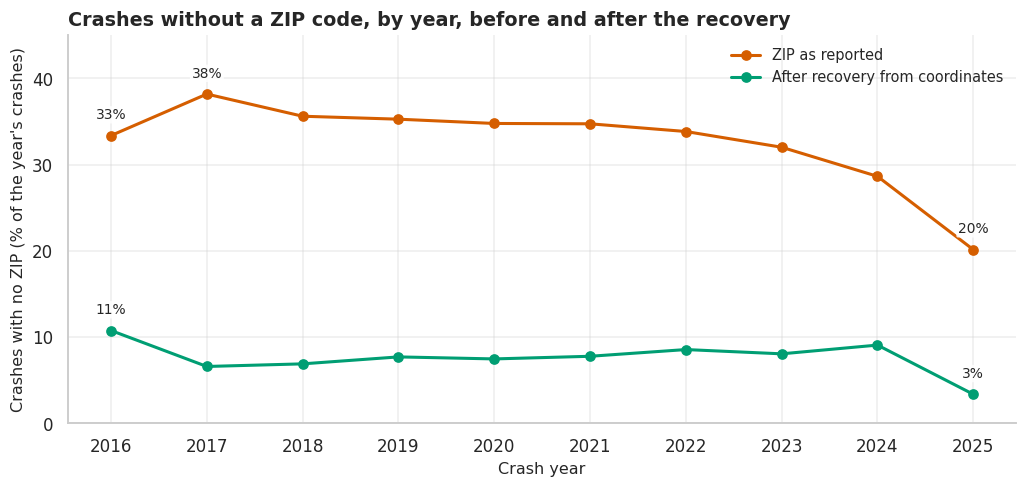

In [103]:
zip_lookups = learn_zip_lookups(labelled["lat"].to_numpy(), labelled["lon"].to_numpy(), labelled["zip"])
recovered_zip, recovered_level = zip_from_cells(target_lat, target_lon, zip_lookups)

zip_missing_before = crashes["zip"].isna().to_numpy()
missing_by_year_before = 100 * pd.Series(zip_missing_before).groupby(crashes["year"].to_numpy()).mean()

crashes["zip_reported"] = crashes["zip"]
filled_zip = crashes["zip"].to_numpy(dtype=object)
filled_zip[np.flatnonzero(zip_targets)] = recovered_zip
filled_zip = pd.Series(filled_zip, index=crashes.index)
crashes["zip"] = filled_zip.where(filled_zip.notna(), pd.NA).astype(crashes["zip_reported"].dtype)
crashes["zip_imputed"] = crashes["zip_reported"].isna() & crashes["zip"].notna()

zip_missing_after = crashes["zip"].isna().to_numpy()
missing_by_year_after = 100 * pd.Series(zip_missing_after).groupby(crashes["year"].to_numpy()).mean()
n_imputed = int(crashes["zip_imputed"].sum())
n_no_cell = int((zip_targets & zip_missing_after).sum())
n_no_location = int((~crashes["is_located"].to_numpy() & zip_missing_after).sum())
# Share of the crashes that needed a ZIP, by the level that supplied it (1 = fine cell, 2 = coarse cell).
level_counts = np.bincount(recovered_level, minlength=len(ZIP_CELL_DEGREES) + 1)
level_share_on_targets = {level: level_counts[level] / len(recovered_level)
                          for level in range(1, len(ZIP_CELL_DEGREES) + 1)}
expected_accuracy = 100 * sum(level_share_on_targets[level] * accuracy_by_level.loc[level, "mean"]
                              for level in accuracy_by_level.index) / sum(level_share_on_targets.values())
# The commentary below names the fine and the coarse level, so a third level would need new wording.
assert set(level_share_on_targets) == {1, 2}, "the commentary describes exactly two recovery levels"

# Reported ZIPs are untouched, every filled value is a ZIP the crash table already uses, and the
# flag marks exactly the rows that changed.
assert (crashes.loc[~crashes["zip_imputed"], "zip"].isna()
        == crashes.loc[~crashes["zip_imputed"], "zip_reported"].isna()).all()
assert crashes.loc[crashes["zip_reported"].notna(), "zip"].eq(
    crashes.loc[crashes["zip_reported"].notna(), "zip_reported"]).all()
assert set(crashes.loc[crashes["zip_imputed"], "zip"].unique()) <= set(labelled["zip"].unique())
assert n_imputed + n_no_cell + n_no_location == int(zip_missing_before.sum())
assert crashes["zip"].dtype == housing["zip"].dtype

log_rule("crashes", f"missing zip recovered from coordinates (modal ZIP of a {ZIP_CELL_DEGREES[0]:g} degree "
         f"cell, else of a {ZIP_CELL_DEGREES[1]:g} degree cell); flagged zip_imputed", "impute",
         len(crashes), len(crashes), n_imputed,
         f"A coordinate determines a ZIP; holdout accuracy {holdout_accuracy:.1f}%. Dropping the rows would "
         f"lose {100 * zip_missing_before.mean():.0f}% of the crashes, unevenly by year.")
log_rule("crashes", "zip still missing after recovery (no coordinates, or no labelled crash in either cell)",
         "flag", len(crashes), len(crashes), n_no_cell + n_no_location,
         "No deterministic value exists; kept for city totals and spatial work, excluded from the ZIP panel.")

def plot_missing_zip_by_year(missing_before, missing_after):
    """Share of each year's crashes without a ZIP, before and after the recovery."""
    fig, ax = plt.subplots(figsize=(9.5, 4.6))
    # Labels sit above their markers on a white backing, so a label never covers a marker. The two
    # lines are far apart at every labelled year, so the labels do not meet.
    series_specs = [(missing_before, "ZIP as reported", PALETTE["crash"]),
                    (missing_after, "After recovery from coordinates", PALETTE["after"])]
    for series, label, color in series_specs:
        ax.plot(series.index, series.to_numpy(), color=color, linewidth=2, marker="o", markersize=6, label=label)
        for year in sorted({series.index[0], series.idxmax(), series.index[-1]}):
            ax.annotate(f"{series.loc[year]:.0f}%", (year, series.loc[year]), xytext=(0, LABEL_OFFSET_POINTS),
                        textcoords="offset points", ha="center", va="bottom", fontsize=9,
                        bbox={"boxstyle": "round,pad=0.12", "facecolor": "white", "edgecolor": "none", "alpha": 0.85})
    ax.set_xticks(missing_before.index)
    ax.set_ylim(0, missing_before.max() * LINE_HEADROOM)
    ax.legend(loc="upper right")
    finish(ax, "Crashes without a ZIP code, by year, before and after the recovery",
           "Crash year", "Crashes with no ZIP (% of the year's crashes)")
    plt.tight_layout()
    plt.show()


plot_missing_zip_by_year(missing_by_year_before, missing_by_year_after)

In [104]:
say(f"{n_imputed:,} crashes received a ZIP ({pct(n_imputed, int(zip_missing_before.sum())):.1f}% of those "
    f"that had none): {100 * level_share_on_targets[1]:.1f}% of the candidates from the fine cell and "
    f"{100 * level_share_on_targets[2]:.1f}% from the coarse cell, which puts the expected accuracy of the "
    f"filled values near {expected_accuracy:.1f}%. The share of crashes without a ZIP falls from "
    f"{100 * zip_missing_before.mean():.1f}% to {100 * zip_missing_after.mean():.1f}%. Before the recovery it "
    f"ranged from {missing_by_year_before.min():.1f}% ({missing_by_year_before.idxmin()}) to "
    f"{missing_by_year_before.max():.1f}% ({missing_by_year_before.idxmax()}), a spread of "
    f"{missing_by_year_before.max() - missing_by_year_before.min():.1f} points; afterwards from "
    f"{missing_by_year_after.min():.1f}% ({missing_by_year_after.idxmin()}) to "
    f"{missing_by_year_after.max():.1f}% ({missing_by_year_after.idxmax()}), a spread of "
    f"{missing_by_year_after.max() - missing_by_year_after.min():.1f} points. {n_no_location:,} crashes have "
    f"neither a ZIP nor coordinates and {n_no_cell:,} have coordinates in a cell where no crash reports a "
    f"ZIP; these {n_no_location + n_no_cell:,} crashes ({pct(n_no_location + n_no_cell, len(crashes)):.1f}%) "
    f"stay without a ZIP and are excluded from the ZIP panel.")

391,799 crashes received a ZIP (77.0% of those that had none): 80.0% of the candidates from the fine cell and 13.4% from the coarse cell, which puts the expected accuracy of the filled values near 96.9%. The share of crashes without a ZIP falls from 33.8% to 7.8%. Before the recovery it ranged from 20.1% (2025) to 38.2% (2017), a spread of 18.0 points; afterwards from 3.4% (2025) to 10.8% (2016), a spread of 7.4 points. 89,427 crashes have neither a ZIP nor coordinates and 27,696 have coordinates in a cell where no crash reports a ZIP; these 117,123 crashes (7.8%) stay without a ZIP and are excluded from the ZIP panel.

The upper line is the artificial trend that the naive panel would have carried: the share of
crashes missing from it moved by many points between years for reasons that have nothing to do
with safety, so ZIP counts built on reported ZIPs alone would rise and fall with record
keeping. After the recovery the gap is much smaller in every year. It is not flat, though. What
remains comes mainly from crashes that have no coordinates at all, and that share was higher in
the first study year than later. A ZIP-level comparison that includes the first year should be
read with that in mind, and the panel carries the number of imputed crashes per row so that a
result can be checked against reported ZIPs only.

#### 6.1.3 The final ZIP by year panel

The panel is rebuilt with the two aggregation functions of 5.2, now on the recovered ZIPs. Three
choices make it complete. Its ZIP codes are those with at least `MIN_ZIP_CRASHES` crashes over
the study years; the codes below that are single buildings and post-office codes, and a housing
ZIP that the crash table does not use falls below it too. Every such ZIP is crossed with every
study year, so the panel is balanced. Cells without a source row are zeros on both sides: no
completion that year, or no crash that year in a ZIP that otherwise has hundreds.

In [105]:
def build_zip_year_panel(housing_aggregate, crash_aggregate, panel_zips):
    """Balanced ZIP x study-year table: every ZIP in `panel_zips` in every study year, zeros filled in.

    Both aggregates are unique on (zip, year), so aligning them on the full grid is one row to
    one row. The key columns are converted to plain text and integers first, because the two
    aggregates arrive with different key dtypes (6.3).
    """
    grid = pd.MultiIndex.from_product([sorted(panel_zips), STUDY_YEARS], names=["zip", "year"])

    def on_grid(aggregate, measures):
        keyed = aggregate.assign(zip=aggregate["zip"].astype(object), year=aggregate["year"].astype("int64"))
        return keyed.set_index(["zip", "year"])[measures].reindex(grid, fill_value=0)

    return pd.concat([on_grid(housing_aggregate, HOUSING_PANEL_MEASURES),
                      on_grid(crash_aggregate, CRASH_PANEL_MEASURES)], axis=1).reset_index()


crashes_by_zip_year = aggregate_crashes_to_zip_year(crashes)
crashes_per_zip = crashes_by_zip_year.groupby("zip")["crashes"].sum()
panel_zips = sorted(crashes_per_zip.index[crashes_per_zip >= MIN_ZIP_CRASHES])
small_zips = crashes_per_zip.index[crashes_per_zip < MIN_ZIP_CRASHES]

zip_year = build_zip_year_panel(housing_by_zip_year, crashes_by_zip_year, panel_zips)

# How many of each row's crashes rest on a recovered ZIP (for sensitivity checks on reported ZIPs).
imputed_counts = (crashes[crashes["zip_imputed"]].groupby(["zip", "year"])
                  .agg(crashes_zip_imputed=("collision_id", "size"),
                       injury_crashes_zip_imputed=("is_injury_crash", "sum")).reset_index())
imputed_counts = imputed_counts.assign(zip=imputed_counts["zip"].astype(object),
                                       year=imputed_counts["year"].astype("int64"))
zip_year = zip_year.merge(imputed_counts, on=["zip", "year"], how="left", validate="one_to_one")
zip_year[["crashes_zip_imputed", "injury_crashes_zip_imputed"]] = (
    zip_year[["crashes_zip_imputed", "injury_crashes_zip_imputed"]].fillna(0))

crashes["in_zip_panel"] = crashes["zip"].isin(panel_zips).to_numpy()

structural_zero_rows = int((zip_year["buildings_completed"] == 0).sum())
housing_zips_all = set(housing.loc[housing["zip"].notna(), "zip"])
housing_zips_excluded = sorted(housing_zips_all - set(panel_zips))
completed_in_window = housing[housing["is_completed"] & housing["zip"].notna()
                              & housing["completion_year"].between(YEAR_START, YEAR_END)]
excluded_housing = completed_in_window[completed_in_window["zip"].isin(housing_zips_excluded)]
crashes_in_small_zips = int((crashes["zip"].notna() & ~crashes["in_zip_panel"]).sum())

log_rule("zip panel", "ZIP-years with crashes and no completion: housing measures set to 0", "impute",
         len(zip_year), len(zip_year), structural_zero_rows,
         "Structural zero: no row in the housing aggregate means nothing was completed there that year.")
log_rule("zip panel", f"ZIP codes with fewer than {MIN_ZIP_CRASHES} crashes in {N_STUDY_YEARS} years left out",
         "drop", (len(panel_zips) + len(small_zips)) * N_STUDY_YEARS, len(zip_year), len(small_zips),
         "Single-building and post-office codes, and one housing ZIP the crash table never uses; a zero "
         "crash count there would be false. Rows are ZIP-years, affected counts ZIP codes.")

gaps_after = panel_gap_report(zip_year, crashes, "zip")
gap_comparison = pd.DataFrame({"naive panel (5.2)": gaps_before, "final panel": gaps_after}, dtype=object)
display(gap_comparison)

,naive panel (5.2),final panel
rows,"2,112.000","1,710.000"
ZIP codes,232.000,171.000
rows missing from a balanced panel,208.000,0.000
missing cells,"7,546.000",0.000
ZIP-years with crashes but missing housing values,"1,256.000",0.000
ZIP-years with housing but missing crash values,2.000,0.000
crashes placed in a row,"995,800.000","1,383,134.000"
% of all crashes placed,66.200,91.900
crashes with no ZIP,"508,922.000","117,123.000"


In [106]:
say(f"The final panel has {len(zip_year):,} rows: {len(panel_zips)} ZIP codes in each of {N_STUDY_YEARS} "
    f"years. It places {gaps_after['crashes placed in a row']:,} crashes "
    f"({gaps_after['% of all crashes placed']:.1f}% of all), against "
    f"{gaps_before['crashes placed in a row']:,} ({gaps_before['% of all crashes placed']:.1f}%) for the naive "
    f"panel, and has no missing cell. {structural_zero_rows:,} ZIP-years "
    f"({pct(structural_zero_rows, len(zip_year)):.0f}%) had no completion and carry zeros on the housing side. "
    f"{len(small_zips)} low-volume ZIP codes with {crashes_in_small_zips:,} crashes between them were left "
    f"out. On the housing side, {len(housing_zips_excluded)} housing ZIP codes are not in the panel "
    f"({', '.join(housing_zips_excluded)}); they hold {len(excluded_housing)} completed rows and "
    f"{int(excluded_housing['total_units'].sum()):,} units "
    f"({pct(excluded_housing['total_units'].sum(), completed_in_window['total_units'].sum()):.1f}% of the "
    f"units completed in the study years in rows that have a ZIP).")

The final panel has 1,710 rows: 171 ZIP codes in each of 10 years. It places 1,383,134 crashes (91.9% of all), against 995,800 (66.2%) for the naive panel, and has no missing cell. 860 ZIP-years (50%) had no completion and carry zeros on the housing side. 60 low-volume ZIP codes with 4,465 crashes between them were left out. On the housing side, 5 housing ZIP codes are not in the panel (10044, 10069, 10158, 10302, 10303); they hold 6 completed rows and 1,607 units (0.5% of the units completed in the study years in rows that have a ZIP).

The panel now covers nearly all crashes that can be given a ZIP, every ZIP has all ten years,
and the only housing left out of it sits in codes that the crash table barely uses. Whether a
value of zero is correct was decided case by case: zero completions is a fact, while zero
crashes in a ZIP that never appears in the crash table would have been an artefact, which is
why that ZIP was removed instead of filled.

### 6.2 Inconsistent or redundant columns

#### 6.2.1 Borough: one attribute, two sources

Both tables carry a borough. After integration a ZIP therefore has two candidate boroughs, the
one its crashes report and the one its housing rows report, and a crash with a recovered ZIP
has a ZIP but no borough at all, because borough and ZIP are missing together in the crash
table (Section 4.8). A ZIP can also cross a borough line. The next cell measures the
disagreement and builds a single ZIP-to-borough lookup.

In [107]:
def modal_borough_by_zip(frame, zip_column):
    """Per ZIP: the most frequent borough, its row count and its share of the ZIP's rows with a borough."""
    counted = (frame[frame[zip_column].notna() & frame["borough"].notna()]
               .groupby([zip_column, "borough"], observed=True).size().rename("rows").reset_index()
               .rename(columns={zip_column: "zip"}))
    counted["zip"] = counted["zip"].astype(object)
    counted["share"] = counted["rows"] / counted.groupby("zip")["rows"].transform("sum")
    counted["borough"] = counted["borough"].astype(object)
    top = counted.sort_values(["zip", "rows", "borough"], ascending=[True, False, True]).drop_duplicates("zip")
    return top.set_index("zip")[["borough", "share"]]


borough_from_crashes = modal_borough_by_zip(crashes, "zip_reported")
borough_from_housing = modal_borough_by_zip(housing, "zip")
zip_geography = borough_from_crashes.rename(columns={"borough": "borough_crashes", "share": "share_crashes"}).join(
    borough_from_housing.rename(columns={"borough": "borough_housing", "share": "share_housing"}), how="outer")

in_both = zip_geography["borough_crashes"].notna() & zip_geography["borough_housing"].notna()
sources_disagree = in_both & (zip_geography["borough_crashes"] != zip_geography["borough_housing"])
split_zips = zip_geography[(zip_geography["share_crashes"] < 1) | (zip_geography["share_housing"] < 1)]
reported_both = crashes["zip_reported"].notna() & crashes["borough"].notna()
crash_zip_borough = crashes.loc[reported_both, "zip_reported"].astype(object).map(zip_geography["borough_crashes"])
crashes_off_modal = int((crash_zip_borough.to_numpy() != crashes.loc[reported_both, "borough"].astype(object).to_numpy()).sum())

# Resolution: the crash table decides (it has thousands of rows per ZIP), housing fills the rest.
zip_geography["borough"] = zip_geography["borough_crashes"].fillna(zip_geography["borough_housing"])
zip_borough = zip_geography["borough"]
assert zip_borough.notna().all() and set(panel_zips) <= set(zip_borough.index)

display(split_zips.sort_values("share_crashes").head(6).round(3))
say(f"{int(in_both.sum())} ZIP codes have a borough from both tables and the two sources name a different "
    f"borough for {int(sources_disagree.sum())} of them. {len(split_zips)} ZIP codes have rows in more than "
    f"one borough in at least one table; the table above lists those with the lowest share in their main "
    f"borough. Across all crashes with a reported ZIP and borough, {crashes_off_modal:,} "
    f"({pct(crashes_off_modal, int(reported_both.sum())):.2f}%) are recorded in a different borough from the "
    f"main borough of their ZIP. {int(zip_geography['borough_crashes'].isna().sum())} ZIP code gets its "
    f"borough from housing because no crash reports it.")

,borough_crashes,share_crashes,borough_housing,share_housing
zip,,,,
11237,Brooklyn,0.973,Brooklyn,1.000
11208,Brooklyn,0.992,Brooklyn,1.000
11421,Queens,0.998,Queens,1.000
11385,Queens,0.998,Queens,1.000
11414,Queens,1.000,NaN,NaN
10463,Bronx,1.000,Bronx,0.884


157 ZIP codes have a borough from both tables and the two sources name a different borough for 0 of them. 6 ZIP codes have rows in more than one borough in at least one table; the table above lists those with the lowest share in their main borough. Across all crashes with a reported ZIP and borough, 322 (0.03%) are recorded in a different borough from the main borough of their ZIP. 1 ZIP code gets its borough from housing because no crash reports it.

The two tables agree on the borough of every ZIP they share, and the ZIPs that cross a borough
line do so for a very small share of their crashes. One borough per ZIP is therefore a sound
simplification for the panel. The decisions are these.

The panel takes the ZIP's main borough from the lookup. A crash keeps the borough it reported,
even in the few cases where that differs from the main borough of its ZIP, because the report
is the observation and the lookup is a summary. A crash with no reported borough and a ZIP,
reported or recovered, takes the borough of its ZIP and is flagged `borough_imputed`. Giving
every crash the borough of its ZIP was the alternative; it would have overwritten reported
values to gain tidiness.

The crashes that reported a borough but had no usable ZIP give a second, independent check of
the ZIP recovery, this time on rows that really lacked a ZIP: the borough of the recovered ZIP
should match the borough the officer wrote down.

In [108]:
borough_missing_before = int(crashes["borough"].isna().sum())
borough_of_zip = crashes["zip"].astype(object).map(zip_borough)

zip_check_rows = (crashes["zip_imputed"] & crashes["borough"].notna()).to_numpy()
recovery_agrees = (borough_of_zip.to_numpy()[zip_check_rows]
                   == crashes["borough"].astype(object).to_numpy()[zip_check_rows])

fill_borough = crashes["borough"].isna().to_numpy() & borough_of_zip.notna().to_numpy()
filled_borough = crashes["borough"].astype(object).to_numpy()
filled_borough[fill_borough] = borough_of_zip.to_numpy()[fill_borough]
crashes["borough"] = pd.Categorical(filled_borough, categories=BOROUGHS)
crashes["borough_imputed"] = fill_borough
borough_missing_after = int(crashes["borough"].isna().sum())

zip_year["borough"] = zip_year["zip"].map(zip_borough)
assert zip_year["borough"].notna().all()
assert zip_year.groupby("zip")["borough"].nunique().eq(1).all(), "one borough per ZIP"
assert crashes["borough"].isna().sum() == (crashes["zip"].isna() & crashes["borough"].isna()).sum()

log_rule("crashes", "missing borough filled from the main borough of the crash's ZIP; flagged borough_imputed",
         "impute", len(crashes), len(crashes), int(fill_borough.sum()),
         "Borough and ZIP are missing together; once the ZIP is recovered the borough follows from it.")
log_rule("zip panel", "two borough sources (crash reports, housing rows) resolved into one borough per ZIP",
         "standardise", len(zip_year), len(zip_year), int(sources_disagree.sum()),
         "Crash-modal borough, housing as fallback. Affected counts ZIPs where the two sources disagreed.")

say(f"Borough was missing in {borough_missing_before:,} crashes before and is missing in "
    f"{borough_missing_after:,} after ({pct(borough_missing_after, len(crashes)):.1f}%); "
    f"{int(fill_borough.sum()):,} values were filled. In the {int(zip_check_rows.sum())} crashes that reported a "
    f"borough and received a recovered ZIP, the recovered ZIP lies in the reported borough "
    f"{100 * recovery_agrees.mean():.1f}% of the time.")

Borough was missing in 508,028 crashes before and is missing in 116,784 after (7.8%); 391,244 values were filled. In the 555 crashes that reported a borough and received a recovered ZIP, the recovered ZIP lies in the reported borough 99.1% of the time.

One gap is left. A crash can have coordinates and still sit in a grid cell where no crash
reported a ZIP code, so the ZIP recovery never reaches it and its borough stays empty. The
cell below counts these crashes by where they are, because a gap that falls mostly on one
borough would understate that borough in every borough comparison.

For these crashes the borough alone is decided by a vote of the nearest crashes that reported
one, within `BOROUGH_NEIGHBOUR_MAX_M`. A borough is a large area, so the neighbours of a crash
are nearly always in the same one. Taking only the single nearest crash was tried first and
rejected: a few reports carry the wrong borough, and on a highway where almost nothing else
is labelled one wrong report was copied to thousands of crashes around it. The cell checks
the vote by hiding the borough of a sample of reported crashes. The ZIP code is
left empty: ZIP areas are small, the nearest crash is often across a ZIP boundary, and the
ZIP panel is meant to hold only ZIP codes that were reported or recovered from a cell with
evidence. Dropping these crashes from borough comparisons was the alternative and would have
kept the uneven gap.

In [109]:
BOROUGH_NEIGHBOUR_MAX_M = 5_000     # farthest reported crash that may vote on a borough (metres)
BOROUGH_VOTERS = 25                 # nearest reported crashes that vote; a few wrong reports cannot win
BOROUGH_CHECK_SAMPLE = 20_000       # reported crashes whose borough is hidden to test the rule


def majority_borough(tree, voter_codes, lat, lon, skip_self=False):
    """Most common borough among the nearest reported crashes within the distance limit.

    Returns one borough code per query point, or -1 where no reported crash is close enough.
    A single nearest neighbour is not used because a handful of reports carry the wrong borough,
    and on a highway where almost nothing else is labelled one wrong report would be copied to
    every crash around it. A vote among BOROUGH_VOTERS neighbours outnumbers such reports.
    """
    extra = 1 if skip_self else 0          # a point queried against its own tree finds itself first
    distance, neighbour = tree.query(to_radians(lat, lon), k=BOROUGH_VOTERS + extra)
    distance, neighbour = distance[:, extra:], neighbour[:, extra:]
    votes_allowed = distance * EARTH_RADIUS_M <= BOROUGH_NEIGHBOUR_MAX_M
    neighbour_codes = voter_codes[neighbour]
    tallies = np.stack([((neighbour_codes == code) & votes_allowed).sum(axis=1)
                        for code in range(len(BOROUGHS))], axis=1)
    return np.where(tallies.sum(axis=1) > 0, tallies.argmax(axis=1), -1)


def borough_from_nearby_reports(crash_frame):
    """Borough by neighbour vote for located crashes that still lack one.

    Returns the positions of the crashes that receive a borough, the boroughs they receive, and
    the share of a hidden sample of reported boroughs that the same vote predicts correctly.
    """
    lat = crash_frame["lat"].to_numpy()
    lon = crash_frame["lon"].to_numpy()
    located = crash_frame["is_located"].to_numpy()
    # Only boroughs written on the police report vote, never filled ones, and never a report that
    # its own coordinates contradict (found in 6.1.2).
    assert location_conflict.index.equals(crash_frame.index)
    reported = np.flatnonzero(located & crash_frame["borough"].notna().to_numpy()
                              & ~crash_frame["borough_imputed"].to_numpy() & ~location_conflict.to_numpy())
    lacking = np.flatnonzero(located & crash_frame["borough"].isna().to_numpy())
    voter_codes = crash_frame["borough"].cat.codes.to_numpy()[reported]
    tree = build_haversine_tree(lat[reported], lon[reported])

    voted = majority_borough(tree, voter_codes, lat[lacking], lon[lacking])
    receives = lacking[voted >= 0]
    received = np.asarray(BOROUGHS, dtype=object)[voted[voted >= 0]]

    # Check: hide the borough of a sample of reported crashes and let their neighbours vote.
    sample = np.random.default_rng(SEED).choice(len(reported), size=min(BOROUGH_CHECK_SAMPLE, len(reported)),
                                                replace=False)
    predicted = majority_borough(tree, voter_codes, lat[reported[sample]], lon[reported[sample]], skip_self=True)
    agreement = float((predicted == voter_codes[sample]).mean())
    return receives, received, agreement


located_without_borough = int((crashes["is_located"] & crashes["borough"].isna()).sum())
neighbour_rows, neighbour_boroughs, neighbour_agreement = borough_from_nearby_reports(crashes)

filled_borough = crashes["borough"].astype(object).to_numpy()
filled_borough[neighbour_rows] = neighbour_boroughs
crashes["borough"] = pd.Categorical(filled_borough, categories=BOROUGHS)
borough_from_neighbour = np.zeros(len(crashes), dtype=bool)
borough_from_neighbour[neighbour_rows] = True
crashes["borough_imputed"] = crashes["borough_imputed"].to_numpy() | borough_from_neighbour
borough_missing_final = int(crashes["borough"].isna().sum())

# Every remaining gap is a crash with no coordinates or with no reported crash within the limit.
assert borough_missing_final == borough_missing_after - len(neighbour_rows)

log_rule("crashes", "borough of located crashes with no ZIP voted by the nearest reported crashes; flagged borough_imputed",
         "impute", len(crashes), len(crashes), len(neighbour_rows),
         f"Cells with no reported ZIP left an uneven gap by borough. Vote of the {BOROUGH_VOTERS} nearest "
         f"reported crashes within {BOROUGH_NEIGHBOUR_MAX_M:,} m; the ZIP stays empty.")

neighbour_share = (pd.Series(neighbour_boroughs).value_counts(normalize=True).mul(100).round(1)
                   .reindex(BOROUGHS).fillna(0))
display(neighbour_share.rename("% of the crashes filled from a neighbour").to_frame().T)
say(f"{located_without_borough:,} located crashes still had no borough after the ZIP step. "
    f"{len(neighbour_rows):,} of them take the borough that most of the {BOROUGH_VOTERS} nearest reported "
    f"crashes within {BOROUGH_NEIGHBOUR_MAX_M:,} m carry, and {borough_missing_final:,} crashes "
    f"({pct(borough_missing_final, len(crashes)):.1f}%) stay without one. On {BOROUGH_CHECK_SAMPLE:,} reported "
    f"crashes with the borough hidden, the same vote gives the reported borough "
    f"{100 * neighbour_agreement:.1f}% of the time.")

,Bronx,Brooklyn,Manhattan,Queens,Staten Island
% of the crashes filled from a neighbour,7.500,11.500,6.700,7.900,66.400


27,599 located crashes still had no borough after the ZIP step. 27,599 of them take the borough that most of the 25 nearest reported crashes within 5,000 m carry, and 89,185 crashes (5.9%) stay without one. On 20,000 reported crashes with the borough hidden, the same vote gives the reported borough 99.9% of the time.

#### 6.2.2 Duplicate and leftover columns

Integration left several columns that say the same thing twice or that only served a step
above. Each was reviewed; the table lists what is dropped and what is knowingly kept.

In [110]:
# Every claim of redundancy is checked before the column goes.
restored = crashes["zip"].where(~crashes["zip_imputed"])
assert (restored.isna() == crashes["zip_reported"].isna()).all()
assert restored.dropna().eq(crashes["zip_reported"].dropna()).all(), "zip_reported = zip where not imputed"
assert (sites["is_completed"] == sites["completion_year"].notna()).all()
assert (crashes["is_located"] == crashes["lat"].notna()).all()
assert (zip_year["new_construction_units"] + zip_year["preservation_units"] == zip_year["units_completed"]).all()

column_review = pd.DataFrame([
    ("crashes", "zip_reported", "drop", "Equal to zip wherever zip_imputed is False, and missing elsewhere."),
    ("zip_geography", "borough_crashes, borough_housing, share_crashes, share_housing", "drop",
     "Resolved into one borough per ZIP (zip_borough)."),
    ("naive_panel", "whole table, with its match indicator", "drop", "Replaced by zip_year."),
    ("crashes_by_zip_year_reported", "whole table", "drop", "Crash counts on reported ZIPs only; replaced."),
    ("crashes", "is_located", "keep", "Same as lat not missing, but used as a filter in every spatial step."),
    ("crashes", "near_cluster_id", "keep", "Derivable from near_site_id; saves a join in every bootstrap."),
    ("sites", "is_completed", "keep", "Same as completion_year not missing; kept for readable filters."),
    ("sites / zip_year", "borough and zip in both", "keep",
     "Not duplicates: one is the building's own borough and ZIP, the other the panel key."),
    ("zip_year", "new_construction_units, preservation_units", "keep",
     "They add up to units_completed, but each is a variable of its own in Section 8."),
], columns=["table", "column", "decision", "reason"])
with pd.option_context("display.max_colwidth", None):
    display(column_review)

crash_columns_before = crashes.shape[1]
crashes = crashes.drop(columns=["zip_reported"])
log_rule("crashes", "zip_reported dropped after the recovery was verified", "drop", len(crashes), len(crashes),
         crash_columns_before - crashes.shape[1],
         "Redundant with zip and zip_imputed. Affected counts columns, not rows.")
release("naive_panel", "crashes_by_zip_year_reported", "restored", "zip_geography")

,table,column,decision,reason
0,crashes,zip_reported,drop,"Equal to zip wherever zip_imputed is False, and missing elsewhere."
1,zip_geography,"borough_crashes, borough_housing, share_crashes, share_housing",drop,Resolved into one borough per ZIP (zip_borough).
2,naive_panel,"whole table, with its match indicator",drop,Replaced by zip_year.
3,crashes_by_zip_year_reported,whole table,drop,Crash counts on reported ZIPs only; replaced.
4,crashes,is_located,keep,"Same as lat not missing, but used as a filter in every spatial step."
5,crashes,near_cluster_id,keep,Derivable from near_site_id; saves a join in every bootstrap.
6,sites,is_completed,keep,Same as completion_year not missing; kept for readable filters.
7,sites / zip_year,borough and zip in both,keep,"Not duplicates: one is the building's own borough and ZIP, the other the panel key."
8,zip_year,"new_construction_units, preservation_units",keep,"They add up to units_completed, but each is a variable of its own in Section 8."


#### 6.2.3 Cumulative units

The panel records what was completed in each year. Several questions need the stock instead:
how many subsidised units stand in the ZIP by a given year. Summing by hand over the unbalanced
housing aggregate would be inconsistent in two ways. Years without a completion have no row
there, so a running sum would skip them, and completions before the first study year would be
lost although those buildings are standing throughout the study.

The cumulative columns are therefore computed on a complete grid that starts at the first
completion year in the housing table and ends at the last study year, and only then cut to the
study years. The stock is counted from the start of the housing table. Subsidised housing built
before that is not in the data, so `cum_units` is the stock added since then and not the total
stock. Completions after the last study year are not counted.

In [111]:
CUMULATIVE_COLUMNS = {"cum_units": "units_completed", "cum_affordable_units": "affordable_units_completed",
                      "cum_deep_affordable_units": "deep_affordable_units",
                      "cum_new_construction_units": "new_construction_units",
                      "cum_preservation_units": "preservation_units"}


def cumulative_housing(housing_aggregate, panel_zips):
    """Running totals of the unit measures per ZIP, from the first year in the housing table."""
    first_year = int(housing_aggregate["year"].min())
    history = pd.MultiIndex.from_product([sorted(panel_zips), range(first_year, YEAR_END + 1)],
                                         names=["zip", "year"])
    keyed = housing_aggregate.assign(zip=housing_aggregate["zip"].astype(object),
                                     year=housing_aggregate["year"].astype("int64"))
    yearly = keyed.set_index(["zip", "year"])[list(CUMULATIVE_COLUMNS.values())].reindex(history, fill_value=0)
    running = yearly.groupby(level="zip").cumsum()
    running.columns = list(CUMULATIVE_COLUMNS)
    return running.reset_index()


housing_first_year = int(housing_by_zip_year["year"].min())
cumulative = cumulative_housing(housing_by_zip_year, panel_zips)
zip_year = zip_year.merge(cumulative, on=["zip", "year"], how="left", validate="one_to_one")

# Consistency between the yearly and the cumulative columns.
previous_stock = zip_year.groupby("zip")["cum_units"].shift(1)
after_first_year = zip_year["year"] > YEAR_START
assert (zip_year.loc[after_first_year, "cum_units"] - previous_stock[after_first_year]
        == zip_year.loc[after_first_year, "units_completed"]).all(), "stock change = completions of the year"
assert (zip_year["cum_units"] >= zip_year["units_completed"]).all()
assert (zip_year["cum_new_construction_units"] + zip_year["cum_preservation_units"] == zip_year["cum_units"]).all()
in_panel_history = housing_by_zip_year[housing_by_zip_year["zip"].isin(panel_zips)
                                       & (housing_by_zip_year["year"] <= YEAR_END)]
assert zip_year.loc[zip_year["year"] == YEAR_END, "cum_units"].sum() == in_panel_history["units_completed"].sum()

stock_before_study = int(zip_year.loc[zip_year["year"] == YEAR_START, "cum_units"].sum()
                         - zip_year.loc[zip_year["year"] == YEAR_START, "units_completed"].sum())
stock_end = int(zip_year.loc[zip_year["year"] == YEAR_END, "cum_units"].sum())
log_rule("zip panel", "cumulative unit columns computed on a complete grid from the first housing year",
         "standardise", len(zip_year), len(zip_year), len(CUMULATIVE_COLUMNS),
         "A running sum over the unbalanced aggregate would skip empty years and lose earlier completions. "
         "Affected counts columns.")
say(f"The housing table starts in {housing_first_year}. The panel's ZIP codes enter {YEAR_START} with "
    f"{stock_before_study:,} units completed in {housing_first_year} to {YEAR_START - 1} and end {YEAR_END} "
    f"with a stock of {stock_end:,} units. In every ZIP and year the change in `cum_units` equals "
    f"`units_completed`, and the new-construction and preservation stocks add up to the total.")

The housing table starts in 2014. The panel's ZIP codes enter 2016 with 12,758 units completed in 2014 to 2015 and end 2025 with a stock of 304,567 units. In every ZIP and year the change in `cum_units` equals `units_completed`, and the new-construction and preservation stocks add up to the total.

### 6.3 Data type mismatches

A join compares key values exactly, so two keys that look the same and are stored differently
do not match. Three mismatches arose, or would have arisen, between these tables.

The first is the ZIP code. Section 2 loaded every column as text for this reason. With a
default load, pandas reads the housing postcode as a decimal number, because the column has
blanks, while crash ZIP codes are text. The cell below reads the housing file once more with
default types to show what a join on those keys would have found.

The second is the year. The housing completion year is a nullable integer, since unfinished
buildings have none, and the crash year is a plain integer. The panel builder converts both.

The third is what merges and grids do to counts and labels: an outer merge turns integer
counts into decimals as soon as one cell is missing, a grid built from Python values comes back
as generic objects and 64-bit integers, and a category is lost when a label passes through a
lookup. The final tables are cast to one declared schema and the schema is asserted.

In [112]:
default_housing_keys = pd.read_csv(HOUSING_FILE, usecols=["postcode"])
default_zip_text = set(default_housing_keys["postcode"].dropna().astype(str))
crash_zip_text = set(crashes["zip"].dropna().astype(object))
clean_housing_zip_text = set(housing["zip"].dropna().astype(object))
key_match = pd.DataFrame({
    "dtype of the housing key": [str(default_housing_keys["postcode"].dtype), str(housing["zip"].dtype)],
    "example value": [sorted(default_zip_text)[0], sorted(clean_housing_zip_text)[0]],
    "distinct housing ZIPs": [len(default_zip_text), len(clean_housing_zip_text)],
    "found among crash ZIPs": [len(default_zip_text & crash_zip_text), len(clean_housing_zip_text & crash_zip_text)],
}, index=["default load (number)", "as cleaned (text)"])
display(key_match)

year_types = pd.DataFrame({
    "dtype": [str(housing["completion_year"].dtype), str(housing_by_zip_year["year"].dtype),
              str(crashes["year"].dtype), str(crashes_by_zip_year["year"].dtype)],
    "can hold a missing value": [True, True, False, False],
}, index=["housing.completion_year", "housing aggregate: year", "crashes.year", "crash aggregate: year"])
display(year_types)

,dtype of the housing key,example value,distinct housing ZIPs,found among crash ZIPs
default load (number),float64,10001.0,158,0
as cleaned (text),string,10001,158,157


,dtype,can hold a missing value
housing.completion_year,Int16,True
housing aggregate: year,Int16,True
crashes.year,int16,False
crash aggregate: year,int16,False


In [113]:
COUNT_DTYPE = "int32"
ZIP_DTYPE = housing["zip"].dtype     # the text dtype both cleaned tables use for ZIP codes
CATEGORY_LEVELS = {"borough": BOROUGHS}   # levels for a label column that arrives as plain text
ZIP_YEAR_SCHEMA = {
    "zip": ZIP_DTYPE, "year": "int16", "borough": "category",
    **{column: COUNT_DTYPE for column in HOUSING_PANEL_MEASURES},
    **{column: COUNT_DTYPE for column in CUMULATIVE_COLUMNS},
    **{column: COUNT_DTYPE for column in CRASH_PANEL_MEASURES},
    "crashes_zip_imputed": COUNT_DTYPE, "injury_crashes_zip_imputed": COUNT_DTYPE,
}
SITES_SCHEMA = {
    "site_id": "int32", "cluster_id": "int32", "block_id": "int32", "housing_id": "int32",
    "project_id": "int64", "building_id": "int64", "project_name": housing["project_name"].dtype,
    "borough": "category", "zip": ZIP_DTYPE, "lat": "float64", "lon": "float64",
    "start_year": "int16", "completion_year": "Int16", "is_completed": "bool", "same_day_completion": "bool",
    "completion_before_start": "bool", "construction_type": "category", "total_units": "int16",
    "all_counted_units": "int16", "deep_affordable_units": "int16", "deep_affordable_share": "float64",
    "size_band": "category", "is_size_outlier": "bool", "cluster_size": "int32",
    "n_sites_within_buffer": "int32",
}
SITE_YEAR_SCHEMA = {"site_id": "int32", "year": "int16", **{column: COUNT_DTYPE for column in SITE_COUNT_COLUMNS}}
EVENT_PANEL_SCHEMA = {
    "site_id": "int32", "cluster_id": "int32", "block_id": "int32", "cohort": "int16", "group": "category",
    "rel_year": "int8", "year": "int16", **{column: COUNT_DTYPE for column in SITE_COUNT_COLUMNS},
    "contaminated": "bool", "near_completion_in_window": "bool", "near_earlier_completion": "bool",
    "completion_year": "Int16", "construction_type": "category", "borough": "category",
    "size_band": "category", "total_units": "int16",
}
CRASH_NEW_COLUMNS_SCHEMA = {
    "zip": ZIP_DTYPE, "zip_imputed": "bool", "borough": "category", "borough_imputed": "bool",
    "in_zip_panel": "bool", "housing_relation": "category", "near_site_id": "Int32", "near_cluster_id": "Int32",
    "near_site_distance_m": "float32", "near_completion_year": "Int16", "rel_year": "Int16",
    "n_sites_near": "int16", "near_completed_site": "bool",
}


def cast_to_schema(frame, schema):
    """Return the frame with exactly the schema's columns, in its order and with its dtypes.

    Count columns must already hold whole numbers and no missing value, so a cast that would
    silently truncate or fail on a gap is caught by the checks instead.
    """
    assert set(schema) == set(frame.columns), set(schema) ^ set(frame.columns)
    result = frame[list(schema)].copy()
    for column, dtype in schema.items():
        if dtype == "category":
            if result[column].dtype != "category":
                result[column] = pd.Categorical(result[column], categories=CATEGORY_LEVELS[column])
                assert result[column].notna().all(), f"{column}: label outside the declared levels"
            continue
        if dtype == COUNT_DTYPE:
            assert result[column].notna().all(), f"{column}: missing value in a count column"
            assert (result[column] == np.floor(result[column].astype("float64"))).all(), f"{column}: not whole"
        result[column] = result[column].astype(dtype)
    return result


def dtype_changes(before, after):
    """Side-by-side dtypes of the columns whose dtype changed."""
    changed = [column for column in after.columns if before[column].dtype != after[column].dtype]
    return pd.DataFrame({"before": [repr(before[column].dtype) for column in changed],
                         "after": [repr(after[column].dtype) for column in changed]}, index=changed)


# sites: building_id is nullable in housing because confidential rows have none; every site has one.
assert sites["building_id"].notna().all()
typed = {"zip_year": cast_to_schema(zip_year, ZIP_YEAR_SCHEMA), "sites": cast_to_schema(sites, SITES_SCHEMA),
         "site_year": cast_to_schema(site_year, SITE_YEAR_SCHEMA),
         "event_panel": cast_to_schema(event_panel, EVENT_PANEL_SCHEMA)}
untyped = {"zip_year": zip_year, "sites": sites, "site_year": site_year, "event_panel": event_panel}
all_changes = pd.concat({name: dtype_changes(untyped[name], typed[name]) for name in typed})
n_dtype_changes = len(all_changes)
display(all_changes.rename_axis(["table", "column"]))

zip_year, sites, site_year, event_panel = (typed["zip_year"], typed["sites"], typed["site_year"],
                                           typed["event_panel"])
release("typed", "untyped")

# The final schema, asserted.
for name, frame, schema in [("zip_year", zip_year, ZIP_YEAR_SCHEMA), ("sites", sites, SITES_SCHEMA),
                            ("site_year", site_year, SITE_YEAR_SCHEMA),
                            ("event_panel", event_panel, EVENT_PANEL_SCHEMA)]:
    assert list(frame.columns) == list(schema), name
    for column, dtype in schema.items():
        assert frame[column].dtype == dtype, (name, column, str(frame[column].dtype))
for column, dtype in CRASH_NEW_COLUMNS_SCHEMA.items():
    assert crashes[column].dtype == dtype, (column, str(crashes[column].dtype))

# Join keys have one dtype everywhere, and category columns share their categories.
assert zip_year["zip"].dtype == crashes["zip"].dtype == housing["zip"].dtype == sites["zip"].dtype
assert zip_year["year"].dtype == crashes["year"].dtype == site_year["year"].dtype == event_panel["year"].dtype
assert sites["site_id"].dtype == site_year["site_id"].dtype == event_panel["site_id"].dtype
for frame in (zip_year, sites, event_panel, crashes, housing):
    assert list(frame["borough"].cat.categories) == BOROUGHS
assert list(event_panel["group"].cat.categories) == EVENT_GROUPS
assert list(crashes["housing_relation"].cat.categories) == HOUSING_RELATIONS
# The keys really join: every tagged crash finds its site, every panel ZIP its crashes.
assert crashes["near_site_id"].dropna().isin(sites["site_id"]).all()
assert set(zip_year["zip"]) <= set(crashes["zip"].dropna())

log_rule("zip panel", "integrated tables cast to a declared schema (keys, counts, categories)", "standardise",
         len(zip_year), len(zip_year), n_dtype_changes,
         "Merges and grids returned object keys, 64-bit and decimal counts and plain-text labels. "
         "Affected counts columns across the four tables.")
# The sentence below says that none of the default-load values matches; this is what makes it true.
assert key_match.loc["default load (number)", "found among crash ZIPs"] == 0
say(f"Read with default types, the housing postcode is a decimal number and none of its "
    f"{key_match.loc['default load (number)', 'distinct housing ZIPs']} values equals a crash ZIP as text; as cleaned, "
    f"{key_match.loc['as cleaned (text)', 'found among crash ZIPs']} of "
    f"{key_match.loc['as cleaned (text)', 'distinct housing ZIPs']} do. {n_dtype_changes} columns across the four "
    f"integrated tables changed dtype in the cast. The panel is {memory_mb(zip_year):.2f} "
    f"MB and the tagged crash table {memory_mb(crashes):.0f} MB.")

before                                              after
table    column                                                                                         
zip_year zip                               dtype('O')                                    string[pyarrow]
         year                          dtype('int64')                                     dtype('int16')
         borough                           dtype('O')  CategoricalDtype(categories=['Bronx', 'Brookly...
         buildings_completed           dtype('int64')                                     dtype('int32')
         crashes                       dtype('int64')                                     dtype('int32')
         crashes_zip_imputed         dtype('float64')                                     dtype('int32')
         injury_crashes_zip_imputed  dtype('float64')                                     dtype('int32')
sites    building_id                     Int64Dtype()                                     dtype('int64')

Read with default types, the housing postcode is a decimal number and none of its 158 values equals a crash ZIP as text; as cleaned, 157 of 158 do. 8 columns across the four integrated tables changed dtype in the cast. The panel is 0.15 MB and the tagged crash table 144 MB.

The first table is the reason the loading step read everything as text: with default types the
two ZIP columns would have had no value in common, and a merge would have returned an empty
match without raising an error. The second table shows the year stored in two ways on the two
sides. The third lists what the cast changed. The identifiers that can be missing keep a
nullable integer type on purpose: a crash that is not near any site has no `near_site_id`, and
a site that is not finished has no `completion_year`. A zero or a minus one in those cells
would be a value that looks real.

### 6.4 Conservation checks

Integration should not create or lose anything without it being counted. The checks below
are assertions, so the notebook stops if one of them fails. The first table accounts for every
crash: it is either in a row of the panel or in one of the excluded groups.

In [114]:
crash_measure_sources = {"crashes": None, "injury_crashes": "is_injury_crash", "persons_injured": "injured",
                         "persons_killed": "killed", "ped_cyc_crashes": "ped_cyc_harm"}
exclusion_groups = {
    "In the ZIP panel": crashes["in_zip_panel"].to_numpy(),
    f"Excluded: ZIP with fewer than {MIN_ZIP_CRASHES} crashes": (crashes["zip"].notna() & ~crashes["in_zip_panel"]).to_numpy(),
    "Excluded: no ZIP, coordinates in an unlabelled cell": (crashes["zip"].isna() & crashes["is_located"]).to_numpy(),
    "Excluded: no ZIP and no coordinates": (crashes["zip"].isna() & ~crashes["is_located"]).to_numpy(),
}
conservation = pd.DataFrame({
    measure: {group: int(mask.sum()) if source is None else int(crashes[source].to_numpy()[mask].sum())
              for group, mask in exclusion_groups.items()}
    for measure, source in crash_measure_sources.items()})
conservation.loc["Total"] = conservation.sum()
conservation["% of crashes"] = (100 * conservation["crashes"] / len(crashes)).round(2)
display(conservation)

# Crashes: the panel plus the excluded groups equal the cleaned table, measure by measure.
group_masks = np.column_stack(list(exclusion_groups.values()))
assert (group_masks.sum(axis=1) == 1).all(), "every crash is in exactly one group"
assert conservation.loc["Total", "crashes"] == len(crashes) == crashes["collision_id"].nunique()
for measure, source in crash_measure_sources.items():
    cleaned_total = len(crashes) if source is None else int(crashes[source].sum())
    assert conservation.loc["Total", measure] == cleaned_total, measure
    assert zip_year[measure].sum() == conservation.loc["In the ZIP panel", measure], measure

# Panel: unique on its key, balanced, and no negative count.
panel_count_columns = [column for column, dtype in ZIP_YEAR_SCHEMA.items() if dtype == COUNT_DTYPE]
assert not zip_year.duplicated(["zip", "year"]).any()
assert len(zip_year) == zip_year["zip"].nunique() * N_STUDY_YEARS
assert zip_year.groupby("zip")["year"].apply(list).map(lambda years: years == STUDY_YEARS).all()
assert zip_year.notna().all().all()
assert (zip_year[panel_count_columns] >= 0).all().all()
assert (zip_year["injury_crashes"] <= zip_year["crashes"]).all()
assert (zip_year["ped_cyc_crashes"] <= zip_year["injury_crashes"]).all()
assert (zip_year["crashes_zip_imputed"] <= zip_year["crashes"]).all()
assert (zip_year["deep_affordable_units"] <= zip_year["affordable_units_completed"]).all()
assert (zip_year["affordable_units_completed"] <= zip_year["units_completed"]).all()

# Housing: every unit of the cleaned table is either in the panel or in a counted exclusion.
housing_groups = {
    "In the ZIP panel": (housing["is_completed"] & housing["zip"].isin(panel_zips)
                         & housing["completion_year"].between(YEAR_START, YEAR_END)),
    f"Completed before {YEAR_START} (in cum_units only)": (
        housing["is_completed"] & housing["zip"].isin(panel_zips) & (housing["completion_year"] < YEAR_START)),
    f"Completed after {YEAR_END}": (housing["is_completed"] & housing["zip"].isin(panel_zips)
                                    & (housing["completion_year"] > YEAR_END)),
    "Completed, ZIP not in the panel": (housing["is_completed"] & housing["zip"].notna()
                                        & ~housing["zip"].isin(panel_zips)),
    "Completed, no ZIP (confidential)": housing["is_completed"] & housing["zip"].isna(),
    "No completion date": ~housing["is_completed"],
}
housing_conservation = pd.DataFrame({
    "rows": {group: int(mask.sum()) for group, mask in housing_groups.items()},
    "total_units": {group: int(housing.loc[mask, "total_units"].sum()) for group, mask in housing_groups.items()},
})
housing_conservation.loc["Total"] = housing_conservation.sum()
housing_conservation["% of units"] = (100 * housing_conservation["total_units"] / housing["total_units"].sum()).round(1)
display(housing_conservation)
assert housing_conservation.loc["Total", "rows"] == len(housing)
assert housing_conservation.loc["Total", "total_units"] == housing["total_units"].sum()
assert zip_year["units_completed"].sum() == housing_conservation.loc["In the ZIP panel", "total_units"]
assert zip_year["buildings_completed"].sum() == housing_conservation.loc["In the ZIP panel", "rows"]

# Spatial tables: each crash once per site, the tables balanced, no negative count.
assert not site_pairs.duplicated(["site_id", "crash_row"]).any(), "each crash is counted once per site"
assert site_year["crashes"].sum() == len(site_pairs)
assert len(site_year) == len(sites) * N_STUDY_YEARS and not site_year.duplicated(["site_id", "year"]).any()
assert (site_year[SITE_COUNT_COLUMNS] >= 0).all().all() and (event_panel[SITE_COUNT_COLUMNS] >= 0).all().all()
assert not event_panel.duplicated(["site_id", "cohort", "rel_year"]).any()
assert len(sites) == int(housing["is_located"].sum()) and sites["site_id"].is_unique
# The nearest-site tag is a partition: a crash has at most one site, and the per-site totals of
# tagged crashes add up to the number of distinct crashes near any site.
assert crashes["near_site_id"].notna().sum() == site_pairs["crash_row"].nunique()
assert crashes.groupby("near_site_id").size().sum() == site_pairs["crash_row"].nunique()

say(f"All checks pass. Of {len(crashes):,} crashes, {int(conservation.loc['In the ZIP panel', 'crashes']):,} "
    f"({conservation.loc['In the ZIP panel', '% of crashes']:.1f}%) are in the panel and "
    f"{len(crashes) - int(conservation.loc['In the ZIP panel', 'crashes']):,} are excluded in three counted "
    f"groups. For injury crashes the panel holds "
    f"{pct(conservation.loc['In the ZIP panel', 'injury_crashes'], conservation.loc['Total', 'injury_crashes']):.1f}%. "
    f"On the housing side the panel's yearly columns hold "
    f"{housing_conservation.loc['In the ZIP panel', '% of units']:.1f}% of all units in the cleaned table; the "
    f"largest group outside it is the buildings with no completion date "
    f"({housing_conservation.loc['No completion date', '% of units']:.1f}% of units).")

,crashes,injury_crashes,persons_injured,persons_killed,ped_cyc_crashes,% of crashes
In the ZIP panel,1383134,376722,502905,2337,135508,91.920
Excluded: ZIP with fewer than 500 crashes,4465,951,1171,6,444,0.300
"Excluded: no ZIP, coordinates in an unlabelled cell",27696,7431,10887,55,1248,1.840
Excluded: no ZIP and no coordinates,89427,24863,36028,219,4814,5.940
Total,1504722,409967,550991,2617,142014,100.000


,rows,total_units,% of units
In the ZIP panel,5393,291809,65.500
Completed before 2016 (in cum_units only),247,12758,2.900
Completed after 2025,371,25595,5.700
"Completed, ZIP not in the panel",7,1608,0.400
"Completed, no ZIP (confidential)",1880,2693,0.600
No completion date,1653,111125,24.900
Total,9551,445588,100.000


All checks pass. Of 1,504,722 crashes, 1,383,134 (91.9%) are in the panel and 121,588 are excluded in three counted groups. For injury crashes the panel holds 91.9%. On the housing side the panel's yearly columns hold 65.5% of all units in the cleaned table; the largest group outside it is the buildings with no completion date (24.9% of units).

Nothing was lost without a count. The crashes outside the panel remain in `crashes`, flagged
by `in_zip_panel`, and still take part in the spatial tables when they have coordinates and in
the citywide series below. The housing rows outside the panel's yearly columns are mostly
buildings that are not finished, which the ZIP level cannot use by design and the spatial level
uses as comparison sites.

### 6.5 A citywide yearly index for reference

Every comparison over time in this notebook has to be read against what happened in the city as
a whole. The last table of this section gives that reference: yearly totals over all cleaned
crashes, with or without a ZIP or coordinates, and an index that sets `INDEX_BASE_YEAR` to 100.
The two series are drawn on one axis as indices, since their levels differ several times over.

,year,crashes,injury_crashes,persons_injured,persons_killed,ped_cyc_crashes,injury_share,deaths_per_1000_injury_crashes,crash_index,injury_crash_index
0,2016,229833,44362,60614,247,15681,0.193,5.568,108.675,97.630
1,2017,231007,44733,60751,261,15554,0.194,5.835,109.230,98.446
2,2018,231564,45804,61985,232,15460,0.198,5.065,109.494,100.803
3,2019,211486,45439,61391,244,15218,0.215,5.370,100.000,100.000
4,2020,112918,33362,44615,269,11968,0.295,8.063,53.393,73.422
5,2021,110558,38810,51786,297,12184,0.351,7.653,52.277,85.411
6,2022,103887,39336,51933,290,13639,0.379,7.372,49.122,86.569
7,2023,96607,40472,54252,280,13833,0.419,6.918,45.680,89.069
8,2024,91316,40229,54030,268,14366,0.441,6.662,43.178,88.534
9,2025,85546,37420,49634,229,14111,0.437,6.120,40.450,82.352


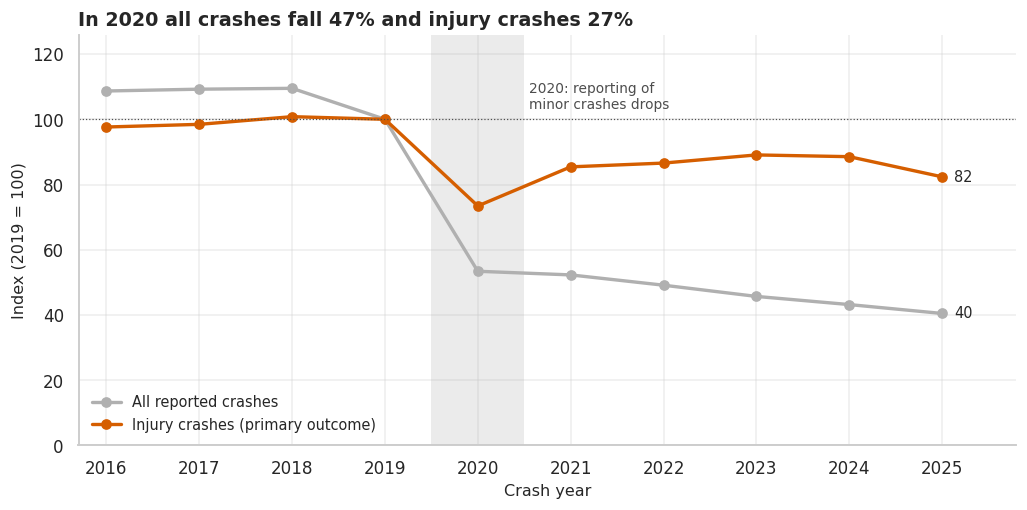

In [115]:
city_year = (crashes.groupby("year")
             .agg(crashes=("collision_id", "size"), injury_crashes=("is_injury_crash", "sum"),
                  persons_injured=("injured", "sum"), persons_killed=("killed", "sum"),
                  ped_cyc_crashes=("ped_cyc_harm", "sum"))
             .astype(COUNT_DTYPE).reset_index())
city_year["year"] = city_year["year"].astype("int16")
city_year["injury_share"] = city_year["injury_crashes"] / city_year["crashes"]
# Deaths are recorded whatever the severity of the crash, so this ratio shows whether the injury
# crashes that remain after the break are more severe, or whether minor ones went missing.
city_year["deaths_per_1000_injury_crashes"] = PER_THOUSAND * city_year["persons_killed"] / city_year["injury_crashes"]
base_row = city_year.set_index("year").loc[INDEX_BASE_YEAR]
city_year["crash_index"] = INDEX_BASE * city_year["crashes"] / base_row["crashes"]
city_year["injury_crash_index"] = INDEX_BASE * city_year["injury_crashes"] / base_row["injury_crashes"]
break_row = city_year.set_index("year").loc[BREAK_YEAR]
assert list(city_year["year"]) == STUDY_YEARS
assert city_year["crashes"].sum() == len(crashes)
display(city_year.round(3))

def plot_city_index(city_year, break_row):
    """Index of all crashes and of injury crashes against the base year, with the break year marked."""
    fig, ax = plt.subplots(figsize=(9.5, 4.8))
    index_specs = [("crash_index", "All reported crashes", PALETTE["before"]),
                   ("injury_crash_index", "Injury crashes (primary outcome)", PALETTE["crash"])]
    for column, label, color in index_specs:
        ax.plot(city_year["year"], city_year[column], color=color, linewidth=2.2, marker="o", markersize=6,
                label=label)
        ax.annotate(f"{city_year[column].iloc[-1]:.0f}", (YEAR_END, city_year[column].iloc[-1]), xytext=(8, 0),
                    textcoords="offset points", va="center", fontsize=9.5)
    ax.axhline(INDEX_BASE, color=PALETTE["neutral"], linewidth=0.8, linestyle=":")
    ax.axvspan(BREAK_YEAR - 0.5, BREAK_YEAR + 0.5, color=PALETTE["before"], alpha=0.25, linewidth=0)
    ax.annotate(f"{BREAK_YEAR}: reporting of\nminor crashes drops", (BREAK_YEAR + 0.55, INDEX_BASE * 1.07),
                fontsize=9, color=PALETTE["neutral"], va="center")
    ax.set_xticks(STUDY_YEARS)
    ax.set_xlim(YEAR_START - 0.3, YEAR_END + 0.8)
    ax.set_ylim(0, city_year[["crash_index", "injury_crash_index"]].max().max() * AXIS_HEADROOM)
    ax.legend(loc="lower left")
    finish(ax, f"In {BREAK_YEAR} all crashes fall {INDEX_BASE - break_row['crash_index']:.0f}% and injury crashes "
               f"{INDEX_BASE - break_row['injury_crash_index']:.0f}%",
           "Crash year", f"Index ({INDEX_BASE_YEAR} = {INDEX_BASE})")
    plt.tight_layout()
    plt.show()


plot_city_index(city_year, break_row)

In [116]:
city_by_year = city_year.set_index("year")
after_break = city_by_year.loc[BREAK_YEAR + 1:YEAR_END - 1, "injury_crash_index"]
deaths_rate = city_by_year["deaths_per_1000_injury_crashes"]
deaths_before = deaths_rate.loc[:INDEX_BASE_YEAR]
deaths_after = deaths_rate.loc[BREAK_YEAR:]
say(f"Between {INDEX_BASE_YEAR} and {BREAK_YEAR} all reported crashes fall from "
    f"{int(city_by_year.loc[INDEX_BASE_YEAR, 'crashes']):,} to {int(city_by_year.loc[BREAK_YEAR, 'crashes']):,} "
    f"(index {city_by_year.loc[BREAK_YEAR, 'crash_index']:.0f}) and reach index "
    f"{city_by_year.loc[YEAR_END, 'crash_index']:.0f} in {YEAR_END}. Injury crashes go from "
    f"{int(city_by_year.loc[INDEX_BASE_YEAR, 'injury_crashes']):,} to "
    f"{int(city_by_year.loc[BREAK_YEAR, 'injury_crashes']):,} (index "
    f"{city_by_year.loc[BREAK_YEAR, 'injury_crash_index']:.0f}), stand between index {after_break.min():.0f} and "
    f"{after_break.max():.0f} in {BREAK_YEAR + 1} to {YEAR_END - 1} and at index "
    f"{city_by_year.loc[YEAR_END, 'injury_crash_index']:.0f} in {YEAR_END}. The share of crashes with an injury "
    f"or death rises from {100 * city_by_year.loc[INDEX_BASE_YEAR, 'injury_share']:.0f}% to "
    f"{100 * city_by_year.loc[YEAR_END, 'injury_share']:.0f}%. Deaths per 1,000 injury crashes run from "
    f"{deaths_before.min():.1f} to {deaths_before.max():.1f} in {YEAR_START} to {INDEX_BASE_YEAR} and from "
    f"{deaths_after.min():.1f} to {deaths_after.max():.1f} in {BREAK_YEAR} to {YEAR_END}.")

Between 2019 and 2020 all reported crashes fall from 211,486 to 112,918 (index 53) and reach index 40 in 2025. Injury crashes go from 45,439 to 33,362 (index 73), stand between index 85 and 89 in 2021 to 2024 and at index 82 in 2025. The share of crashes with an injury or death rises from 21% to 44%. Deaths per 1,000 injury crashes run from 5.1 to 5.8 in 2016 to 2019 and from 6.1 to 8.1 in 2020 to 2025.

The two lines part in the year after the base year and never rejoin. A count of all crashes
would show a large drop at every site and in every ZIP after that year, whatever was built
there, because fewer minor collisions were written up. Injury crashes dip in the same year,
recover part of the way and stay below the base level, so the break reaches them too, only
less. They are the outcome used in Section 8 because they were far less affected than the
count of all crashes. Deaths are recorded whatever the severity of the crash, and the deaths
per 1,000 injury crashes are higher after the break than before. That fits more severe crashes
among those that remain, but it also fits some minor-injury crashes having gone unreported, and
the data cannot tell the two apart. This is another reason that every before and after
comparison in Section 8 is made against comparison sites or within the same calendar years.
`city_year` is kept so that later sections can express a local count relative to the citywide
level of its year.

### 6.6 Rules logged in this section and final outputs

The log below lists every rule recorded in Section 6, and the table after it lists the six
tables that the analysis sections use.

In [117]:
post_integration_log = pd.DataFrame(CLEANING_LOG[POST_LOG_START:])
with pd.option_context("display.max_colwidth", None):
    display(post_integration_log)
assert set(post_integration_log["action"]) <= {"drop", "impute", "flag", "standardise"}

final_outputs = pd.DataFrame([
    {"table": "zip_year", "grain": "ZIP x year (balanced)", "rows": len(zip_year), "columns": zip_year.shape[1]},
    {"table": "sites", "grain": "located building in a project", "rows": len(sites), "columns": sites.shape[1]},
    {"table": "site_year", "grain": "site x year (balanced)", "rows": len(site_year), "columns": site_year.shape[1]},
    {"table": "event_panel", "grain": "site x cohort x relative year", "rows": len(event_panel),
     "columns": event_panel.shape[1]},
    {"table": "crashes", "grain": "collision, with ZIP and housing relation", "rows": len(crashes),
     "columns": crashes.shape[1]},
    {"table": "city_year", "grain": "year", "rows": len(city_year), "columns": city_year.shape[1]},
]).set_index("table")
display(final_outputs)
display(zip_year[zip_year["units_completed"] > 0].head(5))

,dataset,rule,action,rows_before,rows_after,affected,reason
0,crashes,reports whose borough and ZIP contradict their coordinates are not used to teach the ZIP lookup,flag,1504722,1504722,441,Their area has many reports and nearly all give another borough. The reported values are kept.
1,crashes,"missing zip recovered from coordinates (modal ZIP of a 0.001 degree cell, else of a 0.004 degree cell); flagged zip_imputed",impute,1504722,1504722,391799,"A coordinate determines a ZIP; holdout accuracy 97.7%. Dropping the rows would lose 34% of the crashes, unevenly by year."
2,crashes,"zip still missing after recovery (no coordinates, or no labelled crash in either cell)",flag,1504722,1504722,117123,"No deterministic value exists; kept for city totals and spatial work, excluded from the ZIP panel."
3,zip panel,ZIP-years with crashes and no completion: housing measures set to 0,impute,1710,1710,860,Structural zero: no row in the housing aggregate means nothing was completed there that year.
4,zip panel,ZIP codes with fewer than 500 crashes in 10 years left out,drop,2310,1710,60,"Single-building and post-office codes, and one housing ZIP the crash table never uses; a zero crash count there would be false. Rows are ZIP-years, affected counts ZIP codes."
5,crashes,missing borough filled from the main borough of the crash's ZIP; flagged borough_imputed,impute,1504722,1504722,391244,Borough and ZIP are missing together; once the ZIP is recovered the borough follows from it.
6,zip panel,"two borough sources (crash reports, housing rows) resolved into one borough per ZIP",standardise,1710,1710,0,"Crash-modal borough, housing as fallback. Affected counts ZIPs where the two sources disagreed."
7,crashes,borough of located crashes with no ZIP voted by the nearest reported crashes; flagged borough_imputed,impute,1504722,1504722,27599,"Cells with no reported ZIP left an uneven gap by borough. Vote of the 25 nearest reported crashes within 5,000 m; the ZIP stays empty."
8,crashes,zip_reported dropped after the recovery was verified,drop,1504722,1504722,1,"Redundant with zip and zip_imputed. Affected counts columns, not rows."
9,zip panel,cumulative unit columns computed on a complete grid from the first housing year,standardise,1710,1710,5,A running sum over the unbalanced aggregate would skip empty years and lose earlier completions. Affected counts columns.


,grain,rows,columns
table,,,
zip_year,ZIP x year (balanced),1710,21
sites,located building in a project,7593,25
site_year,site x year (balanced),75930,6
event_panel,site x cohort x relative year,93618,19
crashes,"collision, with ZIP and housing relation",1504722,38
city_year,year,10,10


,zip,year,borough,buildings_completed,units_completed,affordable_units_completed,deep_affordable_units,new_construction_units,preservation_units,cum_units,cum_affordable_units,cum_deep_affordable_units,cum_new_construction_units,cum_preservation_units,crashes,injury_crashes,persons_injured,persons_killed,ped_cyc_crashes,crashes_zip_imputed,injury_crashes_zip_imputed
0,10001,2016,Manhattan,1,174,174,151,0,174,174,174,151,0,174,2097,253,281,1,159,232,33
1,10001,2017,Manhattan,7,1878,1460,552,0,1878,2052,1634,703,0,2052,2042,240,256,4,142,209,33
2,10001,2018,Manhattan,2,939,194,6,939,0,2991,1828,709,939,2052,1914,215,236,1,127,199,27
3,10001,2019,Manhattan,1,223,45,0,223,0,3214,1873,709,1162,2052,1683,205,228,1,123,282,35
4,10001,2020,Manhattan,2,92,54,0,92,0,3306,1927,709,1254,2052,514,145,168,2,95,91,26


These six tables are what the analysis sections use. The functions of Sections 5 and 6 stay
defined, together with the crash tree and the ZIP lookup, so that Section 9 can rebuild the
spatial tables at another radius or the panel on reported ZIPs only.

In [118]:
release("labelled", "train_rows", "hidden_rows", "hidden_result", "hidden_covered", "filled_zip",
        "recovered_zip", "borough_of_zip", "filled_borough", "crash_zip_borough", "cumulative",
        "imputed_counts", "group_masks", "default_housing_keys", "completed_in_window", "excluded_housing",
        "in_panel_history")

## 7. Analysis toolkit

The research questions in Section 8 reuse the same few statistical steps, so they are written
once here as small functions that take numpy arrays or pandas objects and return plain
dictionaries or tables. Nothing in this section touches the housing or crash data. Each
function is introduced by a short paragraph that says what it measures and when it is the
right tool, and Section 7.9 checks every one of them on tiny made-up inputs whose answer is
known in advance.

Three ideas shape the whole section. First, crashes near the same building or in the same ZIP
are not independent observations, so intervals are built by resampling whole clusters (sites
or ZIPs, or one-kilometre blocks of sites where the text says so) and never single crashes.
Treating every crash as an independent draw would make every interval so narrow that any
difference at all would look real. Second, every function reports
how many units it actually used, because a result on a handful of sites should not read like a
result on thousands. Third, the data are observational, so the wording helper at the end only
ever describes associations.

### 7.1 Constants for this section

These thresholds are used only by the toolkit. The resampling settings (`N_BOOT`, `CI_LEVEL`,
`SEED`, `MIN_GROUP_N`) come from Section 1.

In [119]:
LOG_RATIO_OFFSET = 0.5        # crashes; added to both counts so a site with zero crashes in one
                              # period still has a finite log ratio. Half a crash is the usual
                              # half-count correction: smaller than any real count, so sites with
                              # ordinary counts are barely moved, but large enough that a change from
                              # 0 to 1 crash is not an infinite ratio
MAX_FAILED_SHARE = 0.10       # share of bootstrap replicates; if more than this fail to produce
                              # a number, no interval is reported at all
FALSE_DISCOVERY_RATE = 0.05   # share of flagged results allowed to be false alarms when several
                              # tests are read together (Benjamini-Hochberg)
PERCENT = 100                 # converts a proportion to a percentage

### 7.2 Intervals from resampling

`percentile_ci` turns a set of bootstrap replicates into an interval by reading off the lower
and upper percentiles that leave `CI_LEVEL` of the replicates in the middle. A replicate can
fail, for example when a resample happens to contain no control site, and it then comes back
as NaN. Dropping those quietly would make an unstable estimate look stable, so the function
counts the failures, returns the count, and gives no interval when more than
`MAX_FAILED_SHARE` of the replicates failed.

`bootstrap_p_value` answers a narrower question: how often do the replicates fall on the far
side of a reference value such as zero. It is computed from the same replicates as the
percentile interval, with one added to the count so that it is never zero. The two are
different calculations on the same replicates, so for a result close to the threshold the
interval can touch zero while the p-value is just under the limit, or the other way round. The
p-value is the one used where several results have to be corrected together in Section 7.6. With `N_BOOT` replicates it cannot go below about two divided by `N_BOOT`, so very small
p-values are reported as that floor and not as zero.

`bootstrap_ci` is the general tool behind everything else. It takes any statistic written as a
function of row-aligned arrays, recomputes it on `N_BOOT` resamples of the rows, and returns
the estimate with its percentile interval. When `clusters` is given, whole clusters are drawn
with replacement and all their rows travel together, which is the right choice whenever rows
share a site, a ZIP or any other common source of noise. Each call builds its own random
generator from `SEED`, so a result does not depend on which cells were run before it.

In [120]:
def percentile_ci(samples, level=CI_LEVEL):
    """Percentile interval of bootstrap replicates that reports failed (NaN) replicates.

    samples: array of shape (n_replicates,) or (n_replicates, k). Returns a dict with `low`,
    `high`, `n_valid` and `n_failed` (floats and ints for 1-D input, arrays of length k for
    2-D input). `low` and `high` are NaN when more than MAX_FAILED_SHARE of replicates failed.
    """
    values = np.asarray(samples, dtype=float)
    n_replicates = values.shape[0]
    n_failed = np.isnan(values).sum(axis=0)
    tail_pct = PERCENT * (1 - level) / 2
    with warnings.catch_warnings():
        # A column whose replicates all failed makes numpy warn; the NaN it returns is the
        # answer wanted here, and the failure is reported through n_failed.
        warnings.simplefilter("ignore", category=RuntimeWarning)
        low = np.nanpercentile(values, tail_pct, axis=0)
        high = np.nanpercentile(values, PERCENT - tail_pct, axis=0)
    too_many_failed = n_failed > MAX_FAILED_SHARE * n_replicates
    low = np.where(too_many_failed, np.nan, low)
    high = np.where(too_many_failed, np.nan, high)
    if values.ndim == 1:
        return {"low": float(low), "high": float(high),
                "n_valid": int(n_replicates - n_failed), "n_failed": int(n_failed)}
    return {"low": low, "high": high, "n_valid": n_replicates - n_failed, "n_failed": n_failed}


def bootstrap_p_value(replicates, null_value=0.0):
    """Two-sided bootstrap p-value: twice the smaller share of replicates on either side of null_value.

    One is added to the count and to the total so the p-value is never exactly zero. NaN
    replicates are ignored; the result is NaN when no replicate is valid.
    """
    values = np.asarray(replicates, dtype=float)
    values = values[~np.isnan(values)]
    if values.size == 0:
        return float("nan")
    at_or_below = int((values <= null_value).sum())
    at_or_above = int((values >= null_value).sum())
    return float(min(1.0, 2 * (min(at_or_below, at_or_above) + 1) / (values.size + 1)))


def cluster_layout(clusters, n_rows):
    """Describe where each cluster's rows sit, so whole clusters can be drawn quickly.

    Returns (order, starts, sizes): `order` lists row numbers sorted by cluster, and cluster j
    owns order[starts[j] : starts[j] + sizes[j]]. With clusters=None every row is its own cluster.
    """
    if clusters is None:
        return np.arange(n_rows), np.arange(n_rows), np.ones(n_rows, dtype=np.int64)
    codes, _ = pd.factorize(np.asarray(clusters))
    assert len(codes) == n_rows, "clusters must have one label per row"
    assert (codes >= 0).all(), "a missing cluster label cannot be resampled"
    order = np.argsort(codes, kind="stable")
    sizes = np.bincount(codes)
    starts = np.cumsum(sizes) - sizes
    return order, starts, sizes


def draw_rows(generator, layout):
    """Row numbers of one bootstrap resample: clusters drawn with replacement, rows kept together."""
    order, starts, sizes = layout
    picked = generator.integers(0, len(sizes), len(sizes))
    picked_sizes = sizes[picked]
    # Build the row list without a Python loop: each picked cluster contributes the positions
    # start, start + 1, ... start + size - 1 of the sorted order.
    block_ends = np.cumsum(picked_sizes)
    position_in_block = np.arange(block_ends[-1]) - np.repeat(block_ends - picked_sizes, picked_sizes)
    return order[np.repeat(starts[picked], picked_sizes) + position_in_block]


def bootstrap_ci(statistic, *arrays, clusters=None, n_boot=N_BOOT, seed=SEED, level=CI_LEVEL):
    """Percentile bootstrap of `statistic(*arrays)`, resampling rows or whole clusters.

    arrays: one or more arrays aligned on their first axis. statistic returns a float or a 1-D
    array and should return NaN when it cannot be computed. Returns a dict: `estimate`, `low`,
    `high`, `p_value` (against zero), `n` (rows), `n_clusters`, `n_failed`, `replicates`.
    """
    arrays = [np.asarray(array) for array in arrays]
    n_rows = len(arrays[0])
    assert n_rows > 0, "nothing to resample"
    assert all(len(array) == n_rows for array in arrays), "arrays must have the same number of rows"
    layout = cluster_layout(clusters, n_rows)
    generator = np.random.default_rng(seed)   # a fresh generator: the result ignores cell order
    with np.errstate(invalid="ignore", divide="ignore"):
        estimate = np.asarray(statistic(*arrays), dtype=float)
        replicates = np.full((n_boot,) + estimate.shape, np.nan)
        for replicate in range(n_boot):
            rows = draw_rows(generator, layout)
            replicates[replicate] = statistic(*[array[rows] for array in arrays])
    interval = percentile_ci(replicates, level)
    if estimate.ndim == 0:
        estimate, p_value = float(estimate), bootstrap_p_value(replicates)
    else:
        p_value = np.array([bootstrap_p_value(column) for column in replicates.T])
    return {"estimate": estimate, "low": interval["low"], "high": interval["high"],
            "p_value": p_value, "n": int(n_rows), "n_clusters": int(len(layout[2])),
            "n_failed": interval["n_failed"], "replicates": replicates}

### 7.3 Rank correlation

Spearman's rho measures whether two quantities rise and fall together in rank order. It is
used here in place of the ordinary correlation because counts of units and crashes are
heavily right-skewed, and a rank correlation is not driven by the few largest ZIPs.
`spearman_ci` returns rho with a bootstrap interval, drops pairs with a missing value, and
refuses to report anything for fewer than `MIN_GROUP_N` pairs, since a rank correlation on a
handful of points is mostly noise.

A correlation across ZIPs can come entirely from the boroughs being different from each
other: Manhattan ZIPs may have more of both quantities without any relationship inside
Manhattan. `group_adjusted_spearman_ci` subtracts each group's mean from both variables
before ranking, so only the variation inside groups is left. The group means are recomputed
inside every resample, which keeps the interval honest about that extra estimation step.
Groups with a single member carry no within-group information and are left out.

In [121]:
def pearson_r(first, second):
    """Pearson correlation of two 1-D arrays; NaN when either is constant."""
    first_centred = first - first.mean()
    second_centred = second - second.mean()
    denominator = np.sqrt((first_centred ** 2).sum() * (second_centred ** 2).sum())
    return float((first_centred * second_centred).sum() / denominator) if denominator > 0 else float("nan")


def spearman_rho(x, y):
    """Spearman rank correlation (Pearson correlation of average ranks); NaN for fewer than 3 pairs."""
    if len(x) < 3:
        return float("nan")
    return pearson_r(stats.rankdata(x), stats.rankdata(y))


def demean_by_group(values, group_codes, n_groups):
    """Subtract from each value the mean of its group (group_codes are integers 0..n_groups-1)."""
    group_sums = np.bincount(group_codes, weights=values, minlength=n_groups)
    group_sizes = np.bincount(group_codes, minlength=n_groups)
    # A resample can leave a group empty; dividing by 1 there is harmless because no row uses it.
    return values - (group_sums / np.maximum(group_sizes, 1))[group_codes]


def empty_result(n, **extra):
    """Result dict used when there are too few units to estimate anything."""
    return {"estimate": float("nan"), "low": float("nan"), "high": float("nan"),
            "p_value": float("nan"), "n": int(n), "n_clusters": 0, "n_failed": 0, **extra}


def spearman_ci(x, y, clusters=None, min_n=MIN_GROUP_N, n_boot=N_BOOT, seed=SEED, level=CI_LEVEL):
    """Spearman's rho with a (cluster) bootstrap interval.

    Returns a dict: `estimate` (rho), `low`, `high`, `p_value`, `n` (complete pairs used),
    `n_clusters`, `n_failed`. All four statistics are NaN when n < min_n.
    """
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    complete = ~(np.isnan(x) | np.isnan(y))
    if complete.sum() < min_n:
        return empty_result(complete.sum())
    kept_clusters = None if clusters is None else np.asarray(clusters)[complete]
    result = bootstrap_ci(spearman_rho, x[complete], y[complete], clusters=kept_clusters,
                          n_boot=n_boot, seed=seed, level=level)
    del result["replicates"]
    return result


def group_adjusted_spearman_ci(x, y, groups, clusters=None, min_n=MIN_GROUP_N,
                               n_boot=N_BOOT, seed=SEED, level=CI_LEVEL):
    """Spearman's rho after removing group means from x and y (within-group association).

    Returns the same dict as spearman_ci plus `n_groups`. Rows with a missing x, y or group and
    groups with a single row are not used; `n` counts the rows that are.
    """
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    group_codes, group_labels = pd.factorize(np.asarray(groups))
    usable = ~(np.isnan(x) | np.isnan(y)) & (group_codes >= 0)
    # Group sizes are counted after the incomplete rows are removed: a group of two rows of which
    # one is missing has one usable row, and demeaning that row would give exactly 0.
    usable_sizes = np.bincount(group_codes[usable], minlength=len(group_labels))
    usable &= usable_sizes[np.maximum(group_codes, 0)] >= 2
    n_groups = int(len(np.unique(group_codes[usable])))
    if usable.sum() < min_n:
        return empty_result(usable.sum(), n_groups=n_groups)

    def within_group_rho(x_rows, y_rows, code_rows):
        """Demean inside the resample, then rank: the group means are part of the estimate."""
        x_within = demean_by_group(x_rows, code_rows, len(group_labels))
        y_within = demean_by_group(y_rows, code_rows, len(group_labels))
        return spearman_rho(x_within, y_within)

    kept_clusters = None if clusters is None else np.asarray(clusters)[usable]
    result = bootstrap_ci(within_group_rho, x[usable], y[usable], group_codes[usable],
                          clusters=kept_clusters, n_boot=n_boot, seed=seed, level=level)
    del result["replicates"]
    result["n_groups"] = n_groups
    return result

### 7.4 Within-unit slopes in a panel

A balanced panel is a table with one row per unit (a ZIP) and one column per year, with no
gaps. `two_way_demean` subtracts each row's mean and each column's mean and adds the overall
mean back once. What remains is how far a ZIP in a given year sits from its own usual level
and from the citywide level of that year. Anything fixed for a ZIP (its size, its street
layout) and anything shared by a year (the drop in reported crashes after 2020) is removed.

`within_slope` regresses the demeaned outcome on one or several demeaned regressors, which is
the two-way fixed-effects estimate. Its interval comes from resampling whole ZIPs, so the
year-to-year dependence inside a ZIP stays intact, and the demeaning is redone in every
resample because the resampled panel has different means. Several regressors can be entered
together, which is how leads and lags are estimated: `lead_lag_panel` builds them from one
regressor matrix. A lead is the regressor's value in a later year. Future housing cannot
influence present crashes, so a lead coefficient away from zero is a warning that ZIPs were
already on different paths, and the lag coefficients should then not be read as a response.
The slope is still only an association: it assumes that ZIPs with and without new housing
would otherwise have moved in parallel, which the leads can question but never prove.

In [122]:
def two_way_demean(matrix):
    """Remove row means and column means from a balanced unit-by-period matrix.

    Returns matrix - row mean - column mean + grand mean (the grand mean is added back because
    the two subtractions each removed it once).
    """
    values = np.asarray(matrix, dtype=float)
    assert values.ndim == 2, "expected a unit-by-period matrix"
    assert not np.isnan(values).any(), "the panel must be balanced: no missing cells"
    return values - values.mean(axis=1, keepdims=True) - values.mean(axis=0, keepdims=True) + values.mean()


def within_coefficients(outcome, regressor_stack):
    """Least-squares coefficients of the demeaned outcome on the demeaned regressors.

    outcome: (units, periods). regressor_stack: (units, k, periods). Returns k coefficients, all
    NaN when the regressors are collinear after demeaning (no unique answer exists then).
    """
    n_regressors = regressor_stack.shape[1]
    target = two_way_demean(outcome).ravel()
    design = np.column_stack([two_way_demean(regressor_stack[:, position, :]).ravel()
                              for position in range(n_regressors)])
    coefficients, _, rank, _ = np.linalg.lstsq(design, target, rcond=None)
    return coefficients if rank == n_regressors else np.full(n_regressors, np.nan)


def within_slope(outcome, regressors, n_boot=N_BOOT, seed=SEED, level=CI_LEVEL):
    """Two-way fixed-effects slopes for a balanced panel with a unit-cluster bootstrap.

    outcome: (units, periods) matrix. regressors: one matrix of the same shape, or a dict
    {name: matrix} to estimate several slopes jointly. Returns a DataFrame indexed by regressor
    name with columns `estimate`, `low`, `high`, `p_value`, `n_units`, `n_periods`, `n_failed`.
    """
    named = regressors if isinstance(regressors, dict) else {"regressor": regressors}
    outcome = np.asarray(outcome, dtype=float)
    stack = np.stack([np.asarray(matrix, dtype=float) for matrix in named.values()], axis=1)
    assert stack.shape[0] == outcome.shape[0] and stack.shape[2] == outcome.shape[1], \
        "every regressor must have the shape of the outcome"
    # Rows are units, so resampling rows resamples whole units with all their years.
    result = bootstrap_ci(within_coefficients, outcome, stack, n_boot=n_boot, seed=seed, level=level)
    table = pd.DataFrame({"estimate": result["estimate"], "low": result["low"], "high": result["high"],
                          "p_value": result["p_value"], "n_units": outcome.shape[0],
                          "n_periods": outcome.shape[1], "n_failed": result["n_failed"]},
                         index=pd.Index(list(named), name="regressor"))
    return table


def shift_name(shift):
    """Label of a shifted regressor: negative shifts are leads, positive shifts are lags."""
    if shift < 0:
        return f"lead {-shift}"
    return "same year" if shift == 0 else f"lag {shift}"


def lead_lag_panel(outcome, regressor, shifts):
    """Build lead and lag versions of a regressor and trim the panel to the periods all of them cover.

    shift s > 0 pairs the outcome in period t with the regressor in t - s (a lag); s < 0 pairs
    it with t + |s| (a lead). Returns (outcome_trimmed, {name: matrix}, kept_columns), where
    kept_columns are the positions of the retained periods in the original matrices and the
    dict is ordered from the furthest lead to the furthest lag.
    """
    outcome = np.asarray(outcome, dtype=float)
    regressor = np.asarray(regressor, dtype=float)
    assert outcome.shape == regressor.shape, "outcome and regressor must have the same shape"
    longest_lag = max(max(shifts), 0)
    longest_lead = max(-min(shifts), 0)
    kept_columns = np.arange(longest_lag, outcome.shape[1] - longest_lead)
    assert len(kept_columns) >= 2, "the leads and lags leave fewer than two usable periods"
    shifted = {shift_name(shift): regressor[:, kept_columns - shift] for shift in sorted(shifts)}
    return outcome[:, kept_columns], shifted, kept_columns

### 7.5 Before and after at the same places

`log_ratio` expresses a site's change as the logarithm of after over before. A site with no
crashes in one period would make the logarithm undefined, so `LOG_RATIO_OFFSET` is added to
both counts; the constant is small enough that sites with ordinary counts are almost
unaffected. Dropping sites with a zero count was the alternative, and it would remove exactly
the quiet sites. A change in levels would let a few busy intersections decide the answer,
while a log ratio treats a site going from 4 to 2 crashes the same as one going from 40 to 20.
Small values read almost as proportional changes.

`did_log_ratio` is the difference-in-differences. Crashes near a completed building may fall
simply because reported crashes fell everywhere, so the change at treated sites is compared
with the change at control sites over the same calendar years, and the estimate is the
treated mean log ratio minus the control mean log ratio. With `strata` (for example
completion year by borough) the comparison is made inside each stratum and the strata are
averaged with the number of treated sites as weights, so the controls are made to resemble
the treated group in when and where they are. A stratum that lacks either treated or control
sites cannot be compared and is left out of both sides; the returned counts are the sites
actually used, with the dropped ones listed separately. Treated and control rows go in one
table and whole clusters are resampled from it, which stays valid when the same site serves
as a control for one cohort and is treated in another. The estimate is an association under
the assumption that the two groups would otherwise have changed alike.

`share_change` is for questions about composition, such as the pedestrian and cyclist share
of injury crashes. It pools the events of all clusters in each period, takes the difference
of the two shares, and resamples clusters. Pooling avoids averaging shares from sites that
have only one or two crashes, where a share can only be zero, a half or one.

`linear_slope` is a plain least-squares slope, provided so that a dose relationship (change
against building size) can be passed to `bootstrap_ci` with site clusters.

In [123]:
def log_ratio(before, after):
    """log((after + LOG_RATIO_OFFSET) / (before + LOG_RATIO_OFFSET)) for counts, element by element."""
    before = np.asarray(before, dtype=float)
    after = np.asarray(after, dtype=float)
    assert (before >= 0).all() and (after >= 0).all(), "counts cannot be negative"
    return np.log((after + LOG_RATIO_OFFSET) / (before + LOG_RATIO_OFFSET))


def log_points_to_percent(log_points):
    """Percent change that a difference in log points stands for: 100 * (exp(x) - 1).

    Works on a single number or an array, so every section converts in the same way.
    """
    return PERCENT * np.expm1(log_points)


def stratified_difference(change, treated, strata_codes, n_strata):
    """Treated-minus-control mean of `change`, compared inside strata and weighted by treated counts.

    Returns a dict with `estimate`, `treated_change`, `control_change`, `n_treated`, `n_control`
    (units in strata that have both arms) and `n_strata` (such strata). The estimates are NaN
    when no stratum has both arms.
    """
    treated_n = np.bincount(strata_codes[treated], minlength=n_strata)
    control_n = np.bincount(strata_codes[~treated], minlength=n_strata)
    treated_sum = np.bincount(strata_codes[treated], weights=change[treated], minlength=n_strata)
    control_sum = np.bincount(strata_codes[~treated], weights=change[~treated], minlength=n_strata)
    # Only strata with both arms can be compared. Dropping them from both sides keeps the two
    # means describing the same mix of strata.
    comparable = (treated_n > 0) & (control_n > 0)
    if not comparable.any():
        return {"estimate": float("nan"), "treated_change": float("nan"),
                "control_change": float("nan"), "n_treated": 0, "n_control": 0, "n_strata": 0}
    weights = treated_n[comparable] / treated_n[comparable].sum()
    treated_change = float((weights * treated_sum[comparable] / treated_n[comparable]).sum())
    control_change = float((weights * control_sum[comparable] / control_n[comparable]).sum())
    return {"estimate": treated_change - control_change, "treated_change": treated_change,
            "control_change": control_change, "n_treated": int(treated_n[comparable].sum()),
            "n_control": int(control_n[comparable].sum()), "n_strata": int(comparable.sum())}


def did_log_ratio(before, after, treated, strata=None, clusters=None,
                  n_boot=N_BOOT, seed=SEED, level=CI_LEVEL):
    """Difference-in-differences on log((after + offset) / (before + offset)), treated against control.

    before, after: counts per row; offset is LOG_RATIO_OFFSET. treated: boolean per row. strata: optional labels; the
    comparison is made inside strata and weighted by treated counts. clusters: optional labels
    of the units resampled together (rows are resampled singly when omitted).
    Returns a dict: `estimate`, `low`, `high` (log points), `p_value`, `percent_change`,
    `percent_low`, `percent_high` (100 * (exp(.) - 1)), `treated_change`, `control_change`,
    `n_treated`, `n_control`, `n_strata` (all three count what was actually used),
    `n_treated_dropped`, `n_control_dropped`, `n_clusters`, `n_failed`, `replicates`.
    """
    change = log_ratio(before, after)
    treated = np.asarray(treated, dtype=bool)
    if strata is None:
        strata_codes, n_strata = np.zeros(len(change), dtype=np.int64), 1
    else:
        strata_codes, strata_labels = pd.factorize(np.asarray(strata))
        assert (strata_codes >= 0).all(), "every row needs a stratum label"
        n_strata = len(strata_labels)
    point = stratified_difference(change, treated, strata_codes, n_strata)

    def did_estimate(change_rows, treated_rows, strata_rows):
        """The weighted difference recomputed on a resample, including its changed stratum mix."""
        return stratified_difference(change_rows, treated_rows, strata_rows, n_strata)["estimate"]

    boot = bootstrap_ci(did_estimate, change, treated, strata_codes, clusters=clusters,
                        n_boot=n_boot, seed=seed, level=level)
    as_percent = {name: float(log_points_to_percent(boot[key]))
                  for name, key in (("percent_change", "estimate"), ("percent_low", "low"),
                                    ("percent_high", "high"))}
    return {**point, "low": boot["low"], "high": boot["high"], "p_value": boot["p_value"],
            **as_percent,
            "n_treated_dropped": int(treated.sum()) - point["n_treated"],
            "n_control_dropped": int((~treated).sum()) - point["n_control"],
            "n_clusters": boot["n_clusters"], "n_failed": boot["n_failed"],
            "replicates": boot["replicates"]}


def pooled_share_difference(hits_before, total_before, hits_after, total_after):
    """Share after minus share before, each pooled over all rows; NaN if a period has no events."""
    events_before = total_before.sum()
    events_after = total_after.sum()
    if events_before == 0 or events_after == 0:
        return float("nan")
    return float(hits_after.sum() / events_after - hits_before.sum() / events_before)


def share_change(hits_before, total_before, hits_after, total_after, clusters=None,
                 n_boot=N_BOOT, seed=SEED, level=CI_LEVEL):
    """Change in a pooled proportion between two periods for the same clusters.

    One row per cluster (or several rows sharing a label in `clusters`): `hits_*` counts the
    events of interest and `total_*` all events in each period. Returns a dict: `estimate`
    (share after minus share before, as a proportion), `low`, `high`, `p_value`,
    `share_before`, `share_after`, `n_before`, `n_after` (events), `n_clusters`, `n_failed`,
    `replicates`.
    """
    counts = [np.asarray(values, dtype=float)
              for values in (hits_before, total_before, hits_after, total_after)]
    assert all((values >= 0).all() for values in counts), "counts cannot be negative"
    assert (counts[0] <= counts[1]).all() and (counts[2] <= counts[3]).all(), \
        "hits cannot exceed the total"
    boot = bootstrap_ci(pooled_share_difference, *counts, clusters=clusters,
                        n_boot=n_boot, seed=seed, level=level)
    events_before = counts[1].sum()
    events_after = counts[3].sum()
    return {"estimate": boot["estimate"], "low": boot["low"], "high": boot["high"],
            "p_value": boot["p_value"],
            "share_before": float(counts[0].sum() / events_before) if events_before else float("nan"),
            "share_after": float(counts[2].sum() / events_after) if events_after else float("nan"),
            "n_before": int(events_before), "n_after": int(events_after),
            "n_clusters": boot["n_clusters"], "n_failed": boot["n_failed"],
            "replicates": boot["replicates"]}


def linear_slope(x, y):
    """Least-squares slope of y on x; NaN when x does not vary."""
    x_centred = x - x.mean()
    spread = (x_centred ** 2).sum()
    return float((x_centred * (y - y.mean())).sum() / spread) if spread > 0 else float("nan")

### 7.6 Several tests at once

When several groups are tested side by side (the contributing-factor groups, the five
boroughs), some will look unusual by chance alone. `benjamini_hochberg` adjusts a set of
p-values so that, among the results whose adjusted value is below `FALSE_DISCOVERY_RATE`, at
most that share is expected to be false alarms. It is less strict than dividing the
threshold by the number of tests, which suits a handful of related comparisons where missing
a real pattern is also a cost. The adjusted values are returned in the order they were given.

In [124]:
def benjamini_hochberg(p_values):
    """Benjamini-Hochberg adjusted p-values, in the input order (NaN stays NaN and is not counted).

    Compare the result with FALSE_DISCOVERY_RATE to decide which tests to flag.
    """
    p_values = np.asarray(p_values, dtype=float)
    adjusted = np.full(p_values.shape, np.nan)
    valid = ~np.isnan(p_values)
    n_tests = int(valid.sum())
    if n_tests == 0:
        return adjusted
    assert ((p_values[valid] >= 0) & (p_values[valid] <= 1)).all(), "p-values must lie in [0, 1]"
    order = np.argsort(p_values[valid])
    scaled = p_values[valid][order] * n_tests / np.arange(1, n_tests + 1)
    # A larger p-value may not end up with a smaller adjusted value than a smaller one, so
    # each value takes the minimum of itself and everything ranked after it.
    monotone = np.minimum.accumulate(scaled[::-1])[::-1]
    in_input_order = np.empty(n_tests)
    in_input_order[order] = np.minimum(monotone, 1.0)
    adjusted[valid] = in_input_order
    return adjusted

### 7.7 Forecast evaluation

A forecast is judged on years the model never saw. `mean_absolute_error` is the average size
of the miss in the units of the outcome (crashes per ZIP and year), which is easier to read
than a squared error and less dominated by the largest ZIPs.

`time_split_evaluation` fits one model per named list of features on all periods before a
cut-off year and scores each on the periods from the cut-off onwards. Splitting by time and
not at random matters: a random split would let the model learn from the future of the same
ZIP. The first feature list is the baseline, and for every other list the function reports
the difference in mean absolute error against it. That difference gets a bootstrap interval
from resampling the test units (ZIPs), using the same resample for both models so the
comparison is paired. The interval describes how much the gain would vary over a different
set of ZIPs with the fitted models held fixed; it does not include the uncertainty of
fitting. A negative difference means the extra features are associated with smaller errors.

In [125]:
def mean_absolute_error(actual, predicted):
    """Mean absolute difference between actual and predicted values."""
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)
    assert actual.shape == predicted.shape, "actual and predicted must align"
    return float(np.abs(actual - predicted).mean())


def mean_gap(first, second):
    """Difference of two means (used for the paired difference in absolute errors)."""
    return float(first.mean() - second.mean())


def time_split_evaluation(frame, target, feature_sets, time_column, first_test_period,
                          cluster_column=None, make_model=LinearRegression,
                          n_boot=N_BOOT, seed=SEED, level=CI_LEVEL):
    """Fit on periods before `first_test_period`, score on the rest, and compare feature sets.

    frame: one row per unit and period. feature_sets: dict {name: list of columns}; the first
    entry is the baseline. make_model: a callable returning an unfitted scikit-learn regressor.
    Returns (summary, predictions). summary is a DataFrame indexed by feature-set name with
    columns `mae`, `mae_minus_baseline`, `low`, `high`, `p_value` (the last four refer to the
    paired difference and are 0 / NaN for the baseline), `n_features`, `n_train`, `n_test`,
    `n_test_clusters`. predictions is the test part of `frame` (time, cluster and target
    columns) with one prediction column per feature set.
    """
    used_columns = sorted({column for columns in feature_sets.values() for column in columns})
    assert not frame[used_columns + [target]].isna().any().any(), "features and target must be complete"
    is_test = (frame[time_column] >= first_test_period).to_numpy()
    train, test = frame[~is_test], frame[is_test]
    assert len(train) > 0 and len(test) > 0, "the cut-off leaves an empty training or test set"
    kept = [time_column, target] + ([cluster_column] if cluster_column else [])
    predictions = test[kept].copy()
    for name, columns in feature_sets.items():
        model = make_model().fit(train[columns].to_numpy(dtype=float), train[target].to_numpy(dtype=float))
        predictions[name] = model.predict(test[columns].to_numpy(dtype=float))

    actual = test[target].to_numpy(dtype=float)
    test_clusters = test[cluster_column].to_numpy() if cluster_column else None
    baseline_name = next(iter(feature_sets))
    baseline_errors = np.abs(actual - predictions[baseline_name].to_numpy())
    rows = []
    for name, columns in feature_sets.items():
        errors = np.abs(actual - predictions[name].to_numpy())
        row = {"feature_set": name, "mae": float(errors.mean()), "mae_minus_baseline": 0.0,
               "low": float("nan"), "high": float("nan"), "p_value": float("nan"),
               "n_features": len(columns), "n_train": len(train), "n_test": len(test),
               "n_test_clusters": len(test) if test_clusters is None else len(pd.unique(test_clusters))}
        if name != baseline_name:
            # Both error vectors are indexed by the same resampled rows, so each replicate
            # compares the two models on exactly the same ZIPs.
            gap = bootstrap_ci(mean_gap, errors, baseline_errors, clusters=test_clusters,
                               n_boot=n_boot, seed=seed, level=level)
            row.update(mae_minus_baseline=gap["estimate"], low=gap["low"], high=gap["high"],
                       p_value=gap["p_value"])
        rows.append(row)
    return pd.DataFrame(rows).set_index("feature_set"), predictions

### 7.8 Wording a result

Every research question ends in a sentence that states the estimate, its interval, how many
units it rests on, and whether the interval includes the reference value. `describe_effect`
writes that sentence from the numbers, so the text under a chart cannot drift away from the
result above it. It never uses causal words. When the interval includes the reference value it
says so and stops; when the interval lies on one side it names the side and what that side
fits; when the estimate could not be computed it says so and concludes nothing. That every
result is an association is stated once, in the introduction to Section 8, and not repeated in
each sentence.

In [126]:
def describe_effect(estimate, low, high, unit, n, subject="The estimate", n_unit="observations",
                    above=None, below=None, null_value=0.0, digits=2, level=CI_LEVEL):
    """One sentence stating an estimate, its interval and n in associational wording.

    unit: text placed after the estimate ("log points", "percentage points", ""). subject: the
    sentence opening that names what was estimated. above / below: what an interval entirely
    above / below null_value fits, as a clause after "which fits" (for example
    above="more injury crashes near the site"). null_value: the value meaning "no
    difference" (0 for differences and correlations, 1 for ratios). Returns a str.
    """
    sample = f"n = {n:,} {n_unit}"
    if any(np.isnan(value) for value in (estimate, low, high)):
        return f"{subject} could not be estimated reliably ({sample}), so nothing is concluded from it."
    reference = "zero" if null_value == 0 else f"{null_value:g}"
    unit_text = f" {unit}" if unit else ""
    opening = (f"{subject} is {estimate:+.{digits}f}{unit_text} ({PERCENT * level:.0f}% interval "
               f"{low:+.{digits}f} to {high:+.{digits}f}, {sample})")
    if low <= null_value <= high:
        return f"{opening}. The interval includes {reference}."
    is_above = low > null_value
    side = "above" if is_above else "below"
    default_meaning = f"a value {side} {reference}"
    meaning = (above if is_above else below) or default_meaning
    return f"{opening}. The interval lies {side} {reference}, which fits {meaning}."

### 7.9 Self-test

Each function is run on a tiny made-up input for which the right answer can be worked out by
hand, and an `assert` stops the notebook if the answer is wrong. The inputs are built so the
answer is exact: a panel made of a unit effect, a year effect and known slopes, sites whose
crashes exactly double, clusters whose rows are copies of each other. A smaller number of
resamples is used here because only correctness is being checked, not precision.

In [127]:
SELF_TEST_BOOT = 200      # resamples per check; enough to exercise the code path
SELF_TEST_TOLERANCE = 1e-9
SELF_TEST_MIN_N = 5       # lets the tiny synthetic inputs pass the minimum-n guard


def check(description, condition):
    """Stop on a failed self-test, otherwise print one line."""
    assert condition, f"self-test failed: {description}"
    print(f"ok  {description}")


def close(value, expected):
    """True when value equals expected up to floating-point noise."""
    return bool(np.allclose(value, expected, atol=SELF_TEST_TOLERANCE, equal_nan=True))


def run_self_tests():
    """Run every check on its tiny input; the temporaries stay local so no later cell can pick one up."""
    test_rng = np.random.default_rng(SEED)

    # percentile_ci and bootstrap_p_value
    ladder = np.arange(1001, dtype=float)
    interval = percentile_ci(ladder)
    check("percentile_ci: 0..1000 gives the 2.5th and 97.5th percentiles (25 and 975)",
          close([interval["low"], interval["high"]], [25, 975]) and interval["n_failed"] == 0)
    few_failed = percentile_ci(np.r_[ladder, [np.nan] * 5])
    check("percentile_ci: a few NaN replicates are counted and the interval is kept",
          few_failed["n_failed"] == 5 and few_failed["n_valid"] == 1001 and close(few_failed["low"], 25))
    many_failed = percentile_ci(np.r_[ladder, [np.nan] * 500])
    check("percentile_ci: too many NaN replicates give no interval",
          many_failed["n_failed"] == 500 and np.isnan(many_failed["low"]) and np.isnan(many_failed["high"]))
    check("bootstrap_p_value: 999 positive replicates give 2 / 1000",
          close(bootstrap_p_value(np.ones(999)), 0.002))
    check("bootstrap_p_value: replicates centred on zero give 1",
          close(bootstrap_p_value(np.r_[-np.ones(50), np.ones(50)]), 1.0))

    # bootstrap_ci
    constant = bootstrap_ci(np.mean, np.full(40, 5.0), n_boot=SELF_TEST_BOOT)
    check("bootstrap_ci: the mean of a constant is that constant with a zero-width interval",
          close([constant["estimate"], constant["low"], constant["high"]], [5, 5, 5]) and constant["n"] == 40)
    cluster_values = np.repeat(test_rng.normal(size=20), 50)      # 20 clusters of 50 identical rows
    cluster_labels = np.repeat(np.arange(20), 50)
    by_row = bootstrap_ci(np.mean, cluster_values, n_boot=SELF_TEST_BOOT)
    by_cluster = bootstrap_ci(np.mean, cluster_values, clusters=cluster_labels, n_boot=SELF_TEST_BOOT)
    check("bootstrap_ci: copies inside clusters add no information, so the cluster interval is far wider",
          (by_cluster["high"] - by_cluster["low"]) > 3 * (by_row["high"] - by_row["low"])
          and by_cluster["n_clusters"] == 20 and by_row["n_clusters"] == 1000)
    repeat_run = bootstrap_ci(np.mean, cluster_values, clusters=cluster_labels, n_boot=SELF_TEST_BOOT)
    check("bootstrap_ci: the same seed gives the same interval",
          close([repeat_run["low"], repeat_run["high"]], [by_cluster["low"], by_cluster["high"]]))

    # spearman_ci and group_adjusted_spearman_ci
    steps = np.arange(1.0, 13.0)
    rising = spearman_ci(steps, steps ** 3, min_n=SELF_TEST_MIN_N, n_boot=SELF_TEST_BOOT)
    falling = spearman_ci(steps, -np.exp(steps), min_n=SELF_TEST_MIN_N, n_boot=SELF_TEST_BOOT)
    check("spearman_ci: any increasing relation gives +1 and any decreasing relation gives -1",
          close([rising["estimate"], rising["low"], falling["estimate"], falling["high"]], [1, 1, -1, -1]))
    noisy_x = test_rng.normal(size=60)
    noisy_y = noisy_x + test_rng.normal(size=60)
    check("spearman_ci: the estimate equals scipy.stats.spearmanr",
          close(spearman_ci(noisy_x, noisy_y, n_boot=SELF_TEST_BOOT)["estimate"],
                stats.spearmanr(noisy_x, noisy_y)[0]))
    too_small = spearman_ci(steps, steps, n_boot=SELF_TEST_BOOT)
    check("spearman_ci: fewer pairs than MIN_GROUP_N gives NaN with n reported",
          np.isnan(too_small["estimate"]) and too_small["n"] == 12)
    group_shift = np.repeat([0.0, 100.0], 6)                      # two groups far apart on both axes
    inside = np.tile(np.arange(6.0), 2)
    grouped_x = group_shift + inside
    grouped_y = group_shift - inside                               # falls with x inside each group
    raw = spearman_ci(grouped_x, grouped_y, min_n=SELF_TEST_MIN_N, n_boot=SELF_TEST_BOOT)
    adjusted = group_adjusted_spearman_ci(grouped_x, grouped_y, np.repeat(["a", "b"], 6),
                                          min_n=SELF_TEST_MIN_N, n_boot=SELF_TEST_BOOT)
    check("group_adjusted_spearman_ci: a positive between-group correlation hides a within-group -1",
          raw["estimate"] > 0 and close(adjusted["estimate"], -1) and adjusted["n_groups"] == 2)
    incomplete_x = np.r_[grouped_x, [5.0, np.nan]]                 # a third group of two rows, one incomplete
    incomplete_y = np.r_[grouped_y, [5.0, 7.0]]
    incomplete = group_adjusted_spearman_ci(incomplete_x, incomplete_y, np.r_[np.repeat(["a", "b"], 6), ["c", "c"]],
                                            min_n=SELF_TEST_MIN_N, n_boot=SELF_TEST_BOOT)
    check("group_adjusted_spearman_ci: a group left with one complete row is not used",
          incomplete["n"] == 12 and incomplete["n_groups"] == 2 and close(incomplete["estimate"], -1))

    # two_way_demean, within_slope, lead_lag_panel
    unit_effect = test_rng.normal(size=(15, 1))
    year_effect = test_rng.normal(size=(1, 8))
    check("two_way_demean: a panel made only of unit and year effects becomes all zeros",
          close(two_way_demean(unit_effect + year_effect), 0))
    first_regressor = test_rng.normal(size=(15, 8))
    second_regressor = test_rng.normal(size=(15, 8))
    panel_outcome = unit_effect + year_effect + 2 * first_regressor - 3 * second_regressor
    slopes = within_slope(panel_outcome, {"first": first_regressor, "second": second_regressor},
                          n_boot=SELF_TEST_BOOT)
    check("within_slope: recovers the slopes 2 and -3 through unit and year effects, jointly",
          close(slopes["estimate"], [2, -3]) and close(slopes["low"], [2, -3]) and close(slopes["high"], [2, -3])
          and list(slopes.index) == ["first", "second"] and (slopes["n_units"] == 15).all())
    single = within_slope(unit_effect + year_effect + 0.5 * first_regressor, first_regressor, n_boot=SELF_TEST_BOOT)
    check("within_slope: a single regressor matrix works and gives 0.5", close(single["estimate"], [0.5]))
    lagged_outcome = np.zeros((15, 8))
    lagged_outcome[:, 1:] = 4 * first_regressor[:, :-1]            # outcome follows last year's regressor
    trimmed_outcome, shifted, kept_columns = lead_lag_panel(lagged_outcome, first_regressor, [-1, 0, 1])
    lag_slopes = within_slope(trimmed_outcome, shifted, n_boot=SELF_TEST_BOOT)
    check("lead_lag_panel: an outcome that follows last year's regressor loads on 'lag 1' only",
          list(shifted) == ["lead 1", "same year", "lag 1"] and list(kept_columns) == [1, 2, 3, 4, 5, 6]
          and close(lag_slopes["estimate"], [0, 0, 4]))

    # log_ratio, did_log_ratio, share_change, linear_slope
    check("log_ratio: zero crashes before and after is a change of zero, not an error",
          close(log_ratio([0, 1], [0, 2.5]), [0, np.log(2)]))
    check("log_points_to_percent: log 2 is +100%, minus log 2 is -50%, and arrays work",
          close(log_points_to_percent(np.array([np.log(2), -np.log(2), 0.0])), [100, -50, 0]))
    is_treated = np.r_[np.ones(8, dtype=bool), np.zeros(8, dtype=bool)]
    crashes_before = np.ones(16)
    crashes_after = np.r_[np.full(8, 2.5), np.ones(8)]             # (2.5 + 0.5) / (1 + 0.5) = 2 for treated
    doubled = did_log_ratio(crashes_before, crashes_after, is_treated, n_boot=SELF_TEST_BOOT)
    check("did_log_ratio: treated sites double and controls do not move, so the estimate is log 2 (+100%)",
          close([doubled["estimate"], doubled["low"], doubled["high"]], [np.log(2)] * 3)
          and close(doubled["percent_change"], 100) and doubled["n_treated"] == 8 and doubled["n_control"] == 8)
    shared_trend = did_log_ratio(crashes_before, np.full(16, 2.5), is_treated, n_boot=SELF_TEST_BOOT)
    check("did_log_ratio: when both groups double, the difference-in-differences is zero",
          close(shared_trend["estimate"], 0) and close(shared_trend["treated_change"], np.log(2)))
    # Stratum A: 2 treated (x2) and 3 controls; stratum B: 6 treated (x4) and 2 controls;
    # stratum C: 3 treated and no control, so it cannot be compared and must be left out.
    strata_labels = np.array(["A"] * 5 + ["B"] * 8 + ["C"] * 3)
    strata_treated = np.array([True, True, False, False, False] + [True] * 6 + [False] * 2 + [True] * 3)
    strata_before = np.ones(16)
    strata_after = np.where(strata_treated, np.where(strata_labels == "A", 2.5, 5.5), 1.0)
    weighted = did_log_ratio(strata_before, strata_after, strata_treated, strata=strata_labels,
                             clusters=np.arange(16), n_boot=SELF_TEST_BOOT)
    check("did_log_ratio: strata are weighted by treated counts and a stratum with no control is dropped",
          close(weighted["estimate"], (2 * np.log(2) + 6 * np.log(4)) / 8)
          and (weighted["n_treated"], weighted["n_control"], weighted["n_strata"]) == (8, 5, 2)
          and (weighted["n_treated_dropped"], weighted["n_control_dropped"]) == (3, 0))
    no_control = did_log_ratio(np.ones(4), np.ones(4), np.ones(4, dtype=bool), n_boot=SELF_TEST_BOOT)
    check("did_log_ratio: with no control units the estimate is NaN and n used is zero",
          np.isnan(no_control["estimate"]) and no_control["n_treated"] == 0
          and no_control["n_failed"] == SELF_TEST_BOOT and np.isnan(no_control["low"]))
    shares = share_change(np.full(10, 10), np.full(10, 100), np.full(10, 30), np.full(10, 100),
                          n_boot=SELF_TEST_BOOT)
    check("share_change: 10 of 100 before and 30 of 100 after in every cluster is +0.20 exactly",
          close([shares["estimate"], shares["low"], shares["high"]], [0.2, 0.2, 0.2])
          and close([shares["share_before"], shares["share_after"]], [0.1, 0.3])
          and (shares["n_before"], shares["n_after"], shares["n_clusters"]) == (1000, 1000, 10))
    check("linear_slope: y = 3x + 1 has slope 3", close(linear_slope(steps, 3 * steps + 1), 3))

    # benjamini_hochberg
    check("benjamini_hochberg: [0.005, 0.5, 0.02] becomes [0.015, 0.5, 0.03]",
          close(benjamini_hochberg([0.005, 0.5, 0.02]), [0.015, 0.5, 0.03]))
    check("benjamini_hochberg: evenly spaced p-values 0.01..0.05 all become 0.05, and NaN is passed through",
          close(benjamini_hochberg([0.01, 0.02, np.nan, 0.03, 0.04, 0.05]), [0.05, 0.05, np.nan, 0.05, 0.05, 0.05]))

    # mean_absolute_error and time_split_evaluation
    check("mean_absolute_error: misses of 1, 0 and 2 average to 1",
          close(mean_absolute_error([1, 2, 3], [2, 2, 5]), 1.0))
    forecast_frame = pd.DataFrame({
        "unit": np.repeat(np.arange(12), 6), "year": np.tile(np.arange(2000, 2006), 12),
        "history": test_rng.normal(size=72), "housing": test_rng.normal(size=72)})
    forecast_frame["target"] = 2 * forecast_frame["history"] + 3 * forecast_frame["housing"]
    summary, predictions = time_split_evaluation(
        forecast_frame, "target", {"history only": ["history"], "history + housing": ["history", "housing"]},
        time_column="year", first_test_period=2004, cluster_column="unit", n_boot=SELF_TEST_BOOT)
    check("time_split_evaluation: the feature that truly drives the target removes the error",
          close(summary.loc["history + housing", "mae"], 0) and summary.loc["history only", "mae"] > 1
          and summary.loc["history + housing", "high"] < 0)
    check("time_split_evaluation: training uses only earlier years (48 rows) and testing the later ones (24 rows)",
          (summary["n_train"] == 48).all() and (summary["n_test"] == 24).all()
          and (summary["n_test_clusters"] == 12).all() and predictions["year"].min() == 2004)

    # describe_effect
    includes_zero = describe_effect(-0.03, -0.08, 0.02, "log points", 412, subject="The change", n_unit="sites")
    excludes_zero = describe_effect(0.12, 0.05, 0.2, "log points", 150, subject="The change at treated sites",
                                    n_unit="sites", above="more injury crashes", below="fewer injury crashes")
    not_estimated = describe_effect(float("nan"), float("nan"), float("nan"), "log points", 4)
    causal_words = ("cause", "causes", "caused", "leads to", "effect of", "because of", "due to")
    check("describe_effect: an interval across zero says so and draws no further conclusion",
          "includes zero" in includes_zero and "which fits" not in includes_zero
          and "n = 412 sites" in includes_zero)
    check("describe_effect: an interval away from zero names its side and the reading it fits",
          "which fits more injury crashes" in excludes_zero and "above zero" in excludes_zero
          and not any(word in excludes_zero for word in causal_words))
    check("describe_effect: a NaN estimate concludes nothing",
          "could not be estimated" in not_estimated and "n = 4 observations" in not_estimated)
    check("describe_effect: no causal phrasing in the neutral sentences",
          not any(word in includes_zero or word in not_estimated for word in causal_words))
    print(includes_zero)
    print(excludes_zero)
    print(not_estimated)


run_self_tests()

ok  percentile_ci: 0..1000 gives the 2.5th and 97.5th percentiles (25 and 975)
ok  percentile_ci: a few NaN replicates are counted and the interval is kept
ok  percentile_ci: too many NaN replicates give no interval
ok  bootstrap_p_value: 999 positive replicates give 2 / 1000
ok  bootstrap_p_value: replicates centred on zero give 1
ok  bootstrap_ci: the mean of a constant is that constant with a zero-width interval
ok  bootstrap_ci: copies inside clusters add no information, so the cluster interval is far wider
ok  bootstrap_ci: the same seed gives the same interval
ok  spearman_ci: any increasing relation gives +1 and any decreasing relation gives -1
ok  spearman_ci: the estimate equals scipy.stats.spearmanr
ok  spearman_ci: fewer pairs than MIN_GROUP_N gives NaN with n reported


ok  group_adjusted_spearman_ci: a positive between-group correlation hides a within-group -1
ok  group_adjusted_spearman_ci: a group left with one complete row is not used
ok  two_way_demean: a panel made only of unit and year effects becomes all zeros
ok  within_slope: recovers the slopes 2 and -3 through unit and year effects, jointly
ok  within_slope: a single regressor matrix works and gives 0.5
ok  lead_lag_panel: an outcome that follows last year's regressor loads on 'lag 1' only
ok  log_ratio: zero crashes before and after is a change of zero, not an error
ok  log_points_to_percent: log 2 is +100%, minus log 2 is -50%, and arrays work
ok  did_log_ratio: treated sites double and controls do not move, so the estimate is log 2 (+100%)
ok  did_log_ratio: when both groups double, the difference-in-differences is zero
ok  did_log_ratio: strata are weighted by treated counts and a stratum with no control is dropped
ok  did_log_ratio: with no control units the estimate is NaN and n used

ok  time_split_evaluation: the feature that truly drives the target removes the error
ok  time_split_evaluation: training uses only earlier years (48 rows) and testing the later ones (24 rows)
ok  describe_effect: an interval across zero says so and draws no further conclusion
ok  describe_effect: an interval away from zero names its side and the reading it fits
ok  describe_effect: a NaN estimate concludes nothing
ok  describe_effect: no causal phrasing in the neutral sentences
The change is -0.03 log points (95% interval -0.08 to +0.02, n = 412 sites). The interval includes zero.
The change at treated sites is +0.12 log points (95% interval +0.05 to +0.20, n = 150 sites). The interval lies above zero, which fits more injury crashes.
The estimate could not be estimated reliably (n = 4 observations), so nothing is concluded from it.


## 8. Research questions

The ten questions below all relate a housing variable to a crash variable. They share an
outcome, a way of computing intervals and a way of reading them.

The outcome is the **injury crash**, a crash in which at least one person was injured or killed.
Reports of crashes with property damage only collapsed in 2020 (Section 3), so a count of all
crashes is not comparable across that year and is not used here.

Every interval is a bootstrap interval at the level `CI_LEVEL`, and the bootstrap resamples whole
groups of observations that belong together: a ZIP code with all its years, or a cluster of
neighbouring sites with all its buildings. Each result is printed with the number of units it
rests on.

The data are observational. Nobody assigned buildings to streets at random, so a difference
reported here is an association. When an interval includes zero the reading is that the data
cannot tell a difference from no difference, which is not the same as showing that there is none.

Each question keeps its headline numbers in `RESULTS`, which Section 10 turns into the summary
table.

The next cell holds the constants of questions 1 to 5 and two small helpers that the questions
of this section and Section 9 share: the function that stores a headline in `RESULTS`, and the
function that turns the event table of Section 5 into one row per site and cohort.

In [128]:
RESULTS = {}                 # one entry per research question, filled as the questions are answered

# --- Forecast (RQ1) ----------------------------------------------------------------------------
FORECAST_LAGS = 2            # years of history used as features; a third lag would cost one more
                             # of only ten years of training data
# --- Panel regression (RQ2) --------------------------------------------------------------------
UNITS_PER_STEP = 100         # affordable units; slopes are reported per 100 units, about one
                             # mid-sized apartment building
LEAD_LAG_SHIFTS = [-2, -1, 0, 1, 2]   # years; negative = completions that have not happened yet
                                      # (placebo), positive = completions that many years ago
LARGEST_COMPLETION_ZIPS = 5  # ZIP codes with the largest single-year completions, left out in a check
# --- Event study (RQ3 to RQ5) ------------------------------------------------------------------
PRE_YEARS = list(range(-EVENT_WINDOW, 0))        # years before the completion year
POST_YEARS = list(range(1, EVENT_WINDOW + 1))    # years after it; the completion year itself is
                                                 # left out because the building opens part-way through
REL_YEARS = PRE_YEARS + [0] + POST_YEARS
PRE_PERIOD_INDEX = INDEX_BASE    # the mean of the pre-completion years is set to the base of the
                                 # citywide index (Section 6.5) in the event chart
NEW_CONSTRUCTION = "New Construction"
PRESERVATION = "Preservation"
DOSE_GRID_POINTS = 40        # points at which the fitted dose line and its band are drawn
SMALL_BUILDING_UNITS = 20    # units; below this a building is in the two lowest size bands of
                             # Section 4 (a house or a small walk-up)
RATIO_TICKS = [0.125, 0.25, 0.5, 1, 2, 4, 8]     # after / before ratios labelled on the log axis


def store_result(key, question, estimate, low, high, n, sentence, unit, level=CI_LEVEL, adjusted_p=None):
    """Keep the headline of one research question for the summary table in Section 10.

    level: coverage of the stored interval, when it is not CI_LEVEL. adjusted_p: the p-value of
    the headline after adjustment for the tests made together with it, when there are several.
    """
    RESULTS[key] = {"question": question, "estimate": float(estimate), "ci_low": float(low),
                    "ci_high": float(high), "n": int(n), "unit": unit, "sentence": sentence,
                    "level": float(level), "adjusted_p": None if adjusted_p is None else float(adjusted_p)}


def cohort_unit_table(panel, columns, keep_contaminated=False):
    """One row per (site, cohort) of an event table: `site_id`, `cohort`, `group`, `treated` and `columns`.

    The completion-year row of each site and cohort carries its attributes. Unless
    `keep_contaminated` is set, rows that fail the screen of Section 5.4 (another completion
    inside the buffer) are left out. A comparison site appears once for every cohort it serves.
    """
    is_unit = (panel["rel_year"] == 0).to_numpy()
    if not keep_contaminated:
        is_unit &= ~panel["contaminated"].to_numpy()
    units = panel.loc[is_unit, ["site_id", "cohort", "group", *columns]].reset_index(drop=True)
    units["treated"] = (units["group"] == "treated").to_numpy()
    assert not units.duplicated(["site_id", "cohort"]).any()
    return units

### 8.1 RQ1. Does knowing a ZIP code's affordable-housing completions improve a forecast of its injury crashes?

Owner: M1

Planners who allocate street-safety money start from last year's injury crashes, and housing
completions are published by the city in advance. If new buildings changed how dangerous the
surrounding streets are, adding them to the forecast should make it more accurate. The result
is the change in forecast error, in injury crashes per ZIP and year, when housing is added.

The test is out of time. Each model is a linear regression fitted on the years before
`FIRST_TEST_YEAR` and scored on the years from then on, which it has never seen. A linear
regression is used because only a few hundred ZIP-years are available for fitting, which
leaves little room to tune a more flexible model without overfitting, and because its housing
coefficients can be read directly. A tree-based model was the alternative. It was left out
because the question is whether housing adds information, and a linear baseline makes that
comparison plain. `FORECAST_LAGS` is two because every further lag costs one more of the ten
study years. The lags cost the first two years of the window, so the training years start
two years after `YEAR_START` and straddle the reporting break. `FIRST_TEST_YEAR` holds out the
last three study years, which all come after the break. The
baseline uses only the ZIP's own injury crashes in the previous `FORECAST_LAGS` years. Three
richer models add housing information that would have been known at the end of the previous
year: the affordable units completed in each of the previous two years, the stock of
affordable units completed since the housing table begins, or both. The score is the mean
absolute error (MAE), in injury crashes per ZIP and year. Because all models are scored on the
same ZIP-years, the difference in MAE is a paired difference, and its interval comes from
resampling whole ZIP codes.

A correlation between completions and crashes across ZIPs would be simpler, but it would mostly
show that large, busy ZIPs have more of both. A forecast that already knows the ZIP's crash
history asks the narrower question of whether housing adds anything on top of it. A random
split of ZIP-years was rejected because it would let the model learn from the last year to
predict an earlier one.

The training years contain the citywide drop of the break year and the test years do not. To
see whether the answer depends on that, the comparison is run a second time with every count
divided by the citywide level of its own year (the injury-crash index of Section 6.5), so the
models only have to predict where a ZIP stands relative to the city. That second version is a
check and not a usable forecast, because the citywide level of a future year is not known in
advance.

In [129]:
HISTORY_FEATURES = [f"injury_crashes_lag{lag}" for lag in range(1, FORECAST_LAGS + 1)]
COMPLETION_FEATURES = [f"affordable_units_lag{lag}" for lag in range(1, FORECAST_LAGS + 1)]
STOCK_FEATURES = ["affordable_stock_lag1"]
FORECAST_FEATURE_SETS = {
    "Crash history only": HISTORY_FEATURES,
    "History + completions": HISTORY_FEATURES + COMPLETION_FEATURES,
    "History + stock": HISTORY_FEATURES + STOCK_FEATURES,
    "History + completions + stock": HISTORY_FEATURES + COMPLETION_FEATURES + STOCK_FEATURES,
}
FORECAST_BASELINE = next(iter(FORECAST_FEATURE_SETS))
FORECAST_FULL = list(FORECAST_FEATURE_SETS)[-1]
PERSISTENCE_NAME = "Same as last year (no model)"


def build_forecast_frame(panel, n_lags=FORECAST_LAGS):
    """One row per ZIP and year with the target and features that use only earlier years.

    Every feature is shifted inside its ZIP, so the row for year t holds values from t - 1 and
    t - 2. The first `n_lags` years of each ZIP have no history and are dropped.
    """
    ordered = panel.sort_values(["zip", "year"]).reset_index(drop=True)
    by_zip = ordered.groupby("zip", sort=False)
    frame = ordered[["zip", "year", "borough", "injury_crashes"]].copy()
    for lag in range(1, n_lags + 1):
        frame[f"injury_crashes_lag{lag}"] = by_zip["injury_crashes"].shift(lag)
        frame[f"affordable_units_lag{lag}"] = by_zip["affordable_units_completed"].shift(lag)
    frame["affordable_stock_lag1"] = by_zip["cum_affordable_units"].shift(1)
    frame = frame.dropna().reset_index(drop=True)
    assert len(frame) == panel["zip"].nunique() * (panel["year"].nunique() - n_lags)
    return frame


def citywide_adjusted_frame(frame, city):
    """The forecast frame with every injury-crash count divided by the citywide level of its own year.

    The citywide level is the injury-crash index of Section 6.5 divided by INDEX_BASE, so a
    count becomes "injury crashes at the citywide level of the base year". Lagged counts are
    divided by the level of the year they come from.
    """
    level = city.set_index("year")["injury_crash_index"] / INDEX_BASE
    years = frame["year"].astype(int)
    adjusted = frame.copy()
    adjusted["injury_crashes"] = frame["injury_crashes"] / years.map(level).to_numpy()
    for lag in range(1, FORECAST_LAGS + 1):
        column = f"injury_crashes_lag{lag}"
        adjusted[column] = frame[column] / (years - lag).map(level).to_numpy()
    assert adjusted[HISTORY_FEATURES + ["injury_crashes"]].notna().all().all()
    return adjusted


def forecast_comparison(frame):
    """Out-of-time MAE of each feature set, the paired difference from the baseline, and a no-model benchmark.

    Returns (summary, predictions, persistence). `persistence` describes the benchmark that needs
    no fitting, next year equals last year: its `mae` and the paired difference `gap` from the
    baseline model with the interval `low` to `high`. It shows how much of the accuracy comes
    from repeating the last count.
    """
    summary, predictions = time_split_evaluation(
        frame, "injury_crashes", FORECAST_FEATURE_SETS, time_column="year",
        first_test_period=FIRST_TEST_YEAR, cluster_column="zip")
    test = frame[frame["year"] >= FIRST_TEST_YEAR]
    actual = test["injury_crashes"].to_numpy(dtype=float)
    persistence_errors = np.abs(actual - test["injury_crashes_lag1"].to_numpy(dtype=float))
    baseline_errors = np.abs(actual - predictions[FORECAST_BASELINE].to_numpy())
    gap = bootstrap_ci(mean_gap, persistence_errors, baseline_errors, clusters=test["zip"].to_numpy())
    persistence = {"mae": float(persistence_errors.mean()), "gap": gap["estimate"], "low": gap["low"],
                   "high": gap["high"]}
    summary["difference_pct"] = PERCENT * summary["mae_minus_baseline"] / summary.loc[FORECAST_BASELINE, "mae"]
    return summary, predictions, persistence


def plot_forecast_comparison(summary, persistence):
    """Left: test MAE of every forecast. Right: its difference from crash history only, with the interval.

    The two panels share their rows, so each model name on the left labels the dot and the
    interval on the same line of both panels.
    """
    names = [PERSISTENCE_NAME] + list(summary.index)
    mae = np.array([persistence["mae"]] + list(summary["mae"]))
    gaps = pd.DataFrame({"gap": [persistence["gap"], *summary["mae_minus_baseline"]],
                         "low": [persistence["low"], *summary["low"]],
                         "high": [persistence["high"], *summary["high"]]}, index=names)
    positions = np.arange(len(names))
    colors = [PALETTE["control"], PALETTE["crash"]] + [PALETTE["housing"]] * (len(names) - 2)
    fig, (ax_level, ax_gap) = plt.subplots(1, 2, figsize=(12.5, 4.4), sharey=True,
                                           gridspec_kw={"width_ratios": [1, 1.6], "wspace": 0.05})
    ax_level.scatter(mae, positions, s=60, color=colors, zorder=3, edgecolor="white", linewidth=1.2)
    for position, value in zip(positions, mae):
        ax_level.annotate(f"{value:.2f}", (value, position), xytext=(9, 0), textcoords="offset points",
                          va="center", fontsize=9.5, color=PALETTE["neutral"])
    spread = mae.max() - mae.min()
    ax_level.set_xlim(mae.min() - 0.4 * spread, mae.max() + 0.7 * spread)
    ax_level.set_yticks(positions)
    ax_level.set_yticklabels(names)
    ax_level.set_ylim(positions[-1] + 0.6, positions[0] - 0.6)
    ax_level.grid(axis="x", visible=False)
    finish(ax_level, f"Forecast error in {FIRST_TEST_YEAR}-{YEAR_END}",
           "Mean absolute error (injury crashes per ZIP\nper year); the axis does not start at zero", "")

    ax_gap.axvline(0, color=PALETTE["neutral"], linewidth=1)
    reach = float(np.nanmax(np.abs(gaps[["low", "high"]].to_numpy())))
    for position, color, (name, row) in zip(positions, colors, gaps.iterrows()):
        if name == FORECAST_BASELINE:
            ax_gap.scatter([0], [position], s=50, color=color, zorder=3, marker="D")
            label, label_x = "reference: crash history only", 0
        else:
            ax_gap.hlines(position, row["low"], row["high"], color=color, linewidth=2)
            ax_gap.scatter([row["gap"]], [position], s=55, color=color, zorder=3, edgecolor="white", linewidth=1.2)
            label, label_x = f"{row['gap']:+.2f}  [{row['low']:+.2f}, {row['high']:+.2f}]", row["high"]
        # The label starts to the right of the interval, so it never crosses the zero line.
        ax_gap.annotate(label, (label_x, position), xytext=(9, 0), textcoords="offset points", ha="left",
                        va="center", fontsize=9, color=PALETTE["neutral"],
                        bbox={"facecolor": "white", "edgecolor": "none", "pad": 1})
    ax_gap.set_xlim(-1.15 * reach, 2.2 * reach)     # the right half holds the value labels
    ax_gap.grid(axis="x", visible=False)
    finish(ax_gap, "Difference from the error of crash history only",
           f"Difference in mean absolute error ({CI_LEVEL:.0%} interval, ZIPs resampled)\n"
           f"right of zero = less accurate than crash history only", "")
    fig.suptitle("RQ1: out-of-time forecast of injury crashes per ZIP, with and without housing features",
                 x=0.01, ha="left", fontsize=12.5, fontweight="bold")
    fig.subplots_adjust(top=0.84, left=0.22, bottom=0.2)
    plt.show()


forecast_frame = build_forecast_frame(zip_year)
forecast_summary, forecast_predictions, forecast_persistence = forecast_comparison(forecast_frame)
persistence_mae = forecast_persistence["mae"]
assert (forecast_predictions["year"] >= FIRST_TEST_YEAR).all(), "no test row may come from a training year"
display(forecast_summary[["mae", "mae_minus_baseline", "low", "high", "p_value", "difference_pct",
                          "n_features", "n_train", "n_test", "n_test_clusters"]].round(3))

,mae,mae_minus_baseline,low,high,p_value,difference_pct,n_features,n_train,n_test,n_test_clusters
feature_set,,,,,,,,,,
Crash history only,20.000,0.000,NaN,NaN,NaN,0.000,2,855,513,171
History + completions,20.383,0.383,0.054,0.853,0.014,1.913,4,855,513,171
History + stock,20.621,0.621,0.194,1.081,0.002,3.103,3,855,513,171
History + completions + stock,20.597,0.597,0.171,1.104,0.002,2.984,5,855,513,171


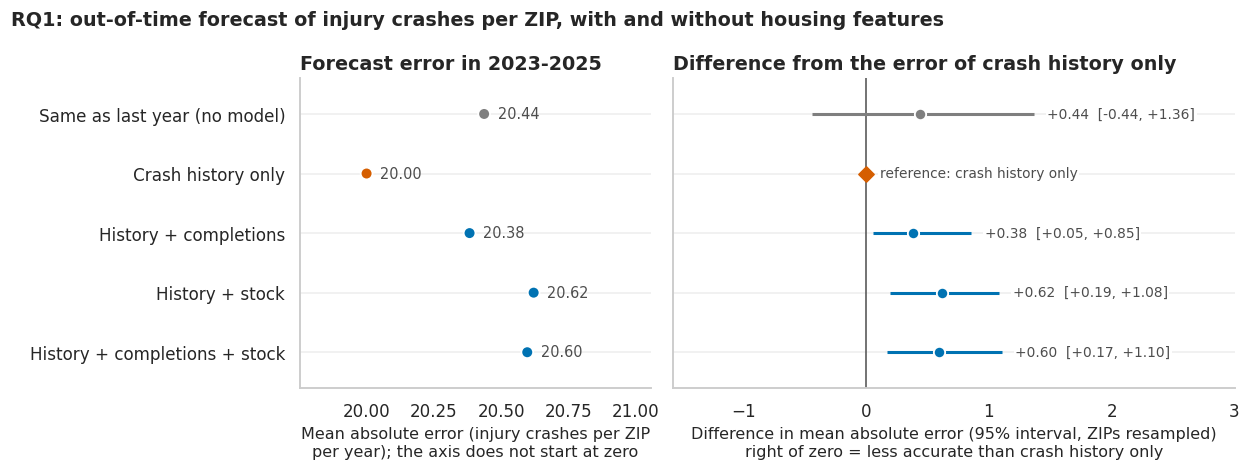

In [130]:
plot_forecast_comparison(forecast_summary, forecast_persistence)

In [131]:
rq1 = forecast_summary.loc[FORECAST_FULL]
rq1_sentence = describe_effect(
    rq1["mae_minus_baseline"], rq1["low"], rq1["high"], "injury crashes per ZIP per year",
    int(rq1["n_test_clusters"]), n_unit="ZIP codes",
    subject="The change in out-of-time forecast error from adding affordable-housing completions and stock",
    above="a less accurate forecast", below="a more accurate forecast")
store_result("RQ1", "Does knowing a ZIP's affordable-housing completions improve an out-of-time forecast "
             "of its injury crashes?", rq1["mae_minus_baseline"], rq1["low"], rq1["high"],
             rq1["n_test_clusters"], rq1_sentence, "MAE difference (injury crashes per ZIP per year)")
mean_test_target = forecast_predictions["injury_crashes"].mean()
first_stock_year = int(housing.loc[housing["is_completed"], "completion_year"].min())
say(f"The models are fitted on {int(rq1['n_train']):,} ZIP-years ({forecast_frame['year'].min()} to "
    f"{FIRST_TEST_YEAR - 1}) and scored on {int(rq1['n_test']):,} ZIP-years ({FIRST_TEST_YEAR} to {YEAR_END}) "
    f"in {int(rq1['n_test_clusters'])} ZIP codes, where the average ZIP has {mean_test_target:.0f} injury "
    f"crashes a year. The stock counts the affordable units completed from {first_stock_year} on. Crash "
    f"history alone misses by {forecast_summary.loc[FORECAST_BASELINE, 'mae']:.2f} injury crashes on average, "
    f"against {persistence_mae:.2f} for repeating last year (difference {forecast_persistence['gap']:+.2f}, "
    f"interval {forecast_persistence['low']:+.2f} to {forecast_persistence['high']:+.2f}). "
    f"{rq1_sentence} In relative terms the change is {rq1['difference_pct']:+.1f}% of the baseline error.")

The models are fitted on 855 ZIP-years (2018 to 2022) and scored on 513 ZIP-years (2023 to 2025) in 171 ZIP codes, where the average ZIP has 213 injury crashes a year. The stock counts the affordable units completed from 2014 on. Crash history alone misses by 20.00 injury crashes on average, against 20.44 for repeating last year (difference +0.44, interval -0.44 to +1.36). The change in out-of-time forecast error from adding affordable-housing completions and stock is +0.60 injury crashes per ZIP per year (95% interval +0.17 to +1.10, n = 171 ZIP codes). The interval lies above zero, which fits a less accurate forecast. In relative terms the change is +3.0% of the baseline error.

In [132]:
# The same comparison with the citywide level of each year divided out of every count.
adjusted_summary, _, adjusted_persistence = forecast_comparison(citywide_adjusted_frame(forecast_frame, city_year))
rq1_adjusted = adjusted_summary.loc[FORECAST_FULL]
display(adjusted_summary[["mae", "mae_minus_baseline", "low", "high", "p_value", "difference_pct"]].round(3))
say(f"With the citywide level divided out, crash history alone misses by "
    f"{adjusted_summary.loc[FORECAST_BASELINE, 'mae']:.2f} injury crashes (at the citywide level of "
    f"{INDEX_BASE_YEAR}) and repeating last year by {adjusted_persistence['mae']:.2f}. Adding completions and "
    f"stock changes the error by {rq1_adjusted['mae_minus_baseline']:+.2f} (interval "
    f"{rq1_adjusted['low']:+.2f} to {rq1_adjusted['high']:+.2f}, {rq1_adjusted['difference_pct']:+.1f}% of the "
    f"baseline error, n = {int(rq1_adjusted['n_test_clusters'])} ZIP codes), against "
    f"{rq1['mae_minus_baseline']:+.2f} ({rq1['low']:+.2f} to {rq1['high']:+.2f}) in the main version.")

,mae,mae_minus_baseline,low,high,p_value,difference_pct
feature_set,,,,,,
Crash history only,22.728,0.000,NaN,NaN,NaN,0.000
History + completions,23.528,0.800,0.212,1.761,0.002,3.518
History + stock,23.314,0.586,0.244,0.958,0.004,2.577
History + completions + stock,23.469,0.741,0.142,1.694,0.004,3.259


With the citywide level divided out, crash history alone misses by 22.73 injury crashes (at the citywide level of 2019) and repeating last year by 23.57. Adding completions and stock changes the error by +0.74 (interval +0.14 to +1.69, +3.3% of the baseline error, n = 171 ZIP codes), against +0.60 (+0.17 to +1.10) in the main version.

Housing does not help the forecast. Each of the three models that know about completions or
the housing stock has a slightly larger error on the held-out years than the model that knows
only the ZIP's crash history, and the intervals of all three differences lie to the right of
zero. The size of the loss is small next to the error itself. The fitted history model in turn
cannot be told from repeating last year's count, since the interval of that difference
includes zero.

The second version shows that the loss does not come from the citywide drop inside the
training years. With the citywide level divided out of every count, the models with housing
features are still less accurate than crash history alone, by a similar margin. Why the
housing features hurt is not tested here. One possible reason, not checked, is that with a few
hundred ZIP-years the extra coefficients are fitted to noise.

The interval resamples the test ZIPs but keeps the fitted models fixed, so it understates the
uncertainty that comes from fitting on a few hundred ZIP-years. The result also rests on one
train and test split and on a linear model, and Section 9.10 shows that the loss is absent
when only crashes with a reported ZIP code are counted. The supported reading is that housing
features did not improve the forecast in this split. It does not show that they make
forecasts worse. A ZIP is a large area, and a forecast that does not improve at that scale says little about the
blocks next to a building, which RQ3 looks at directly.

### 8.2 RQ2. Within a ZIP code over time, do injury crashes move as its stock of completed affordable units grows?

Owner: M1

The forecast above compares ZIP codes with one another. This question follows each ZIP against
itself: it compares a ZIP's injury crashes in the years when its stock of affordable units is
above its own average with the years when the stock is below it. The result is reported as a
percentage change in injury crashes for every `UNITS_PER_STEP` additional units, with an
interval.

The method is a two-way fixed-effects regression of the log of injury crashes on the
cumulative number of affordable units completed since the housing table begins. The ZIP effect
removes everything about a ZIP that does not change (its size and its road network), and the
year effect removes whatever hit all ZIPs in the same year, which includes the drop of the
break year. What is left is the movement of a ZIP around its own level and around the citywide
year. The interval resamples whole ZIP codes, because the ten years of one ZIP are not ten
independent observations.

A single slope cannot show timing, so the figure uses a second regression in which the yearly
additions to the stock are entered at several distances in time: the units completed one and
two years ago, in the same year, and one and two years in the future. The stock itself is not
shifted, because the stock in neighbouring years is almost the same number and the separate
slopes could not be told apart. The future completions are a placebo. A building that does
not exist yet cannot affect crashes, so a slope on a future completion that differs from zero
would mean that crashes were already moving differently in the ZIPs that later received housing.

A slope on yearly completions can rest on a handful of ZIP codes that received a very large
project in one year. The timing regression is therefore repeated without the
`LARGEST_COMPLETION_ZIPS` ZIP codes that have the largest single-year completions.

The completions of a year mix two kinds of project. New construction brings new residents and
preservation brings none (RQ5 uses it as a placebo for that reason). The timing regression is
therefore also run on the units of each kind separately.

In [133]:
def panel_matrix(panel, column):
    """ZIP-by-year matrix of one panel column (rows are ZIP codes, columns are study years)."""
    matrix = panel.pivot(index="zip", columns="year", values=column)
    assert matrix.notna().all().all(), "the ZIP by year panel must be balanced"
    return matrix


def stock_regression(panel):
    """Two-way fixed-effects slopes of log injury crashes on affordable housing, per 100 units.

    Returns (stock_slope, timing): the single slope on the cumulative stock, and a table of
    jointly estimated slopes on the yearly completions at each lead and lag. Both are in
    percent change in injury crashes per UNITS_PER_STEP units.
    """
    injury = panel_matrix(panel, "injury_crashes").to_numpy(dtype=float)
    log_injury = np.log(injury + LOG_RATIO_OFFSET)
    stock = panel_matrix(panel, "cum_affordable_units").to_numpy(dtype=float) / UNITS_PER_STEP
    completions = panel_matrix(panel, "affordable_units_completed").to_numpy(dtype=float) / UNITS_PER_STEP

    stock_slope = within_slope(log_injury, {"cumulative stock": stock}).iloc[0]
    trimmed_outcome, shifted, kept_columns = lead_lag_panel(log_injury, completions, LEAD_LAG_SHIFTS)
    timing = within_slope(trimmed_outcome, shifted)
    timing["shift"] = sorted(LEAD_LAG_SHIFTS)
    timing["first_year"] = STUDY_YEARS[kept_columns[0]]
    timing["last_year"] = STUDY_YEARS[kept_columns[-1]]
    # Five slopes are read together, so their p-values are adjusted for multiple testing.
    timing["p_adjusted"] = benjamini_hochberg(timing["p_value"].to_numpy())
    for column in ["estimate", "low", "high"]:
        timing[f"{column}_pct"] = log_points_to_percent(timing[column])
    stock_slope = stock_slope.copy()
    for column in ["estimate", "low", "high"]:
        stock_slope[f"{column}_pct"] = log_points_to_percent(stock_slope[column])
    stock_slope["zips_with_growth"] = int((stock[:, -1] > stock[:, 0]).sum())
    return stock_slope, timing


def same_year_slope_by_kind(panel, unit_columns):
    """Completion-year slope of the timing regression, run separately on each column of completed units.

    unit_columns: {label: panel column}. Each column replaces the yearly completions in the lead
    and lag regression of `stock_regression`. Returns one row per label with the same-year slope
    in percent per UNITS_PER_STEP units, its interval and its unadjusted p-value.
    """
    log_injury = np.log(panel_matrix(panel, "injury_crashes").to_numpy(dtype=float) + LOG_RATIO_OFFSET)
    rows = {}
    for label, column in unit_columns.items():
        completions = panel_matrix(panel, column).to_numpy(dtype=float) / UNITS_PER_STEP
        trimmed_outcome, shifted, _ = lead_lag_panel(log_injury, completions, LEAD_LAG_SHIFTS)
        same_year = within_slope(trimmed_outcome, shifted).loc[shift_name(0)]
        rows[label] = {"estimate_pct": float(log_points_to_percent(same_year["estimate"])),
                       "low_pct": float(log_points_to_percent(same_year["low"])),
                       "high_pct": float(log_points_to_percent(same_year["high"])),
                       "p_value": float(same_year["p_value"]), "n_units": int(same_year["n_units"])}
    return pd.DataFrame(rows).T


def plot_timing_coefficients(timing):
    """Coefficient plot: slope on completions at each lead (placebo) and lag, with intervals."""
    fig, ax = plt.subplots(figsize=(9, 4.8))
    is_lead = (timing["shift"] < 0).to_numpy()
    ax.axhline(0, color=PALETTE["neutral"], linewidth=1)
    ax.axvspan(timing["shift"].min() - 0.5, -0.5, color=PALETTE["placebo"], alpha=0.08, linewidth=0)
    for mask, color, label in [(is_lead, PALETTE["placebo"], "Units not completed yet (placebo)"),
                               (~is_lead, PALETTE["housing"], "Units completed that year or earlier")]:
        rows = timing[mask]
        ax.vlines(rows["shift"], rows["low_pct"], rows["high_pct"], color=color, linewidth=2)
        ax.scatter(rows["shift"], rows["estimate_pct"], s=60, color=color, zorder=3, edgecolor="white",
                   linewidth=1.2, label=label)
    # The value sits above the upper end of its interval, clear of the marker and of the zero line.
    for _, row in timing.iterrows():
        ax.annotate(f"{row['estimate_pct']:+.2f}%", (row["shift"], row["high_pct"]), xytext=(0, 6),
                    textcoords="offset points", ha="center", va="bottom", fontsize=9, color=PALETTE["neutral"])
    ax.set_xticks(timing["shift"])
    ax.set_xticklabels([f"{-shift} yr before\ncompletion" if shift < 0 else
                        ("completion\nyear" if shift == 0 else f"{shift} yr after\ncompletion")
                        for shift in timing["shift"]])
    ax.set_xlim(timing["shift"].min() - 0.5, timing["shift"].max() + 0.5)
    low, high = timing["low_pct"].min(), timing["high_pct"].max()
    ax.set_ylim(low - 0.08 * (high - low), high + 0.22 * (high - low))     # headroom for the value labels
    ax.yaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda value, _: f"{value:+.2f}%"))
    ax.grid(axis="x", visible=False)
    handles, labels = ax.get_legend_handles_labels()
    handles.append(mpl.lines.Line2D([], [], color=PALETTE["neutral"], linewidth=2))
    labels.append(f"{CI_LEVEL:.0%} interval, ZIPs resampled")
    ax.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, -0.27), ncol=3)
    finish(ax, f"RQ2: injury crashes in a ZIP before and after affordable units are completed\n"
               f"{int(timing['n_units'].iloc[0])} ZIP codes, {int(timing['first_year'].iloc[0])}-"
               f"{int(timing['last_year'].iloc[0])}, ZIP and year effects removed",
           "Timing of the injury crashes relative to the completion of the units",
           f"Change in injury crashes per {UNITS_PER_STEP} units (%)")
    plt.tight_layout()
    plt.show()


stock_slope, timing_slopes = stock_regression(zip_year)
display(timing_slopes[["shift", "estimate_pct", "low_pct", "high_pct", "p_value", "p_adjusted",
                       "n_units", "n_periods"]].round(3))

,shift,estimate_pct,low_pct,high_pct,p_value,p_adjusted,n_units,n_periods
regressor,,,,,,,,
lead 2,-2,0.055,-0.059,0.482,0.308,0.385,171,6
lead 1,-1,0.020,-0.198,0.405,0.855,0.855,171,6
same year,0,-0.400,-0.818,-0.249,0.004,0.020,171,6
lag 1,1,-0.077,-0.467,0.038,0.138,0.345,171,6
lag 2,2,0.311,-0.238,0.524,0.208,0.346,171,6


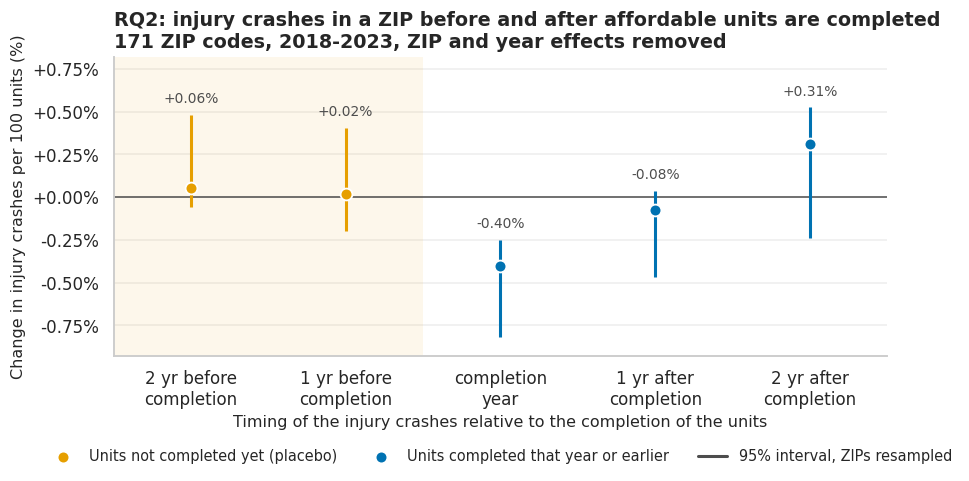

In [134]:
plot_timing_coefficients(timing_slopes)

In [135]:
rq2_sentence = describe_effect(
    stock_slope["estimate_pct"], stock_slope["low_pct"], stock_slope["high_pct"],
    f"percent per {UNITS_PER_STEP} units", int(stock_slope["n_units"]), n_unit="ZIP codes",
    subject="The within-ZIP change in injury crashes as the stock of completed affordable units grows",
    above="more injury crashes in the years with a larger stock",
    below="fewer injury crashes in the years with a larger stock")
store_result("RQ2", "Within a ZIP over time, do injury crashes move as the cumulative stock of completed "
             "affordable units grows?", stock_slope["estimate_pct"], stock_slope["low_pct"],
             stock_slope["high_pct"], stock_slope["n_units"], rq2_sentence,
             f"% change in injury crashes per {UNITS_PER_STEP} units")
lead_rows = timing_slopes[timing_slopes["shift"] < 0]
lag_rows = timing_slopes[timing_slopes["shift"] >= 0]
n_leads_flagged = int((lead_rows["p_adjusted"] < FALSE_DISCOVERY_RATE).sum())
n_lags_flagged = int((lag_rows["p_adjusted"] < FALSE_DISCOVERY_RATE).sum())
say(f"{rq2_sentence} The panel has {int(stock_slope['n_units'])} ZIP codes over "
    f"{int(stock_slope['n_periods'])} years, and the stock grew in {int(stock_slope['zips_with_growth'])} "
    f"of them. In the timing regression ({int(timing_slopes['first_year'].iloc[0])} to "
    f"{int(timing_slopes['last_year'].iloc[0])}), {n_leads_flagged} of {len(lead_rows)} placebo slopes and "
    f"{n_lags_flagged} of {len(lag_rows)} slopes on completed units differ from zero after the "
    f"Benjamini-Hochberg adjustment at {FALSE_DISCOVERY_RATE:.2f}. The slopes range from "
    f"{timing_slopes['estimate_pct'].min():+.2f}% to {timing_slopes['estimate_pct'].max():+.2f}% per "
    f"{UNITS_PER_STEP} units.")

The within-ZIP change in injury crashes as the stock of completed affordable units grows is +0.07 percent per 100 units (95% interval -0.06 to +0.41, n = 171 ZIP codes). The interval includes zero. The panel has 171 ZIP codes over 10 years, and the stock grew in 143 of them. In the timing regression (2018 to 2023), 0 of 2 placebo slopes and 1 of 3 slopes on completed units differ from zero after the Benjamini-Hochberg adjustment at 0.05. The slopes range from -0.40% to +0.31% per 100 units.

In [136]:
# The timing regression without the ZIP codes that received the largest completions in one year.
largest_completions = (zip_year.groupby("zip", observed=True)["affordable_units_completed"].max()
                       .nlargest(LARGEST_COMPLETION_ZIPS))
_, timing_without_largest = stock_regression(zip_year[~zip_year["zip"].isin(largest_completions.index)])
same_year = timing_slopes[timing_slopes["shift"] == 0].iloc[0]
same_year_without = timing_without_largest[timing_without_largest["shift"] == 0].iloc[0]
say(f"The completion-year slope is {same_year['estimate_pct']:+.2f}% per {UNITS_PER_STEP} units (interval "
    f"{same_year['low_pct']:+.2f}% to {same_year['high_pct']:+.2f}%, adjusted p = {same_year['p_adjusted']:.3f}, "
    f"n = {int(same_year['n_units'])} ZIP codes). Without the {LARGEST_COMPLETION_ZIPS} ZIP codes with the "
    f"largest single-year completions ({int(largest_completions.min()):,} to {int(largest_completions.max()):,} "
    f"affordable units in one year) it is {same_year_without['estimate_pct']:+.2f}% (interval "
    f"{same_year_without['low_pct']:+.2f}% to {same_year_without['high_pct']:+.2f}%, adjusted p = "
    f"{same_year_without['p_adjusted']:.3f}, n = {int(same_year_without['n_units'])} ZIP codes).")

The completion-year slope is -0.40% per 100 units (interval -0.82% to -0.25%, adjusted p = 0.020, n = 171 ZIP codes). Without the 5 ZIP codes with the largest single-year completions (2,023 to 7,895 affordable units in one year) it is -0.60% (interval -1.08% to -0.02%, adjusted p = 0.200, n = 166 ZIP codes).

In [137]:
# The same regression with the completed units of one kind of project at a time.
KIND_UNIT_COLUMNS = {"new construction": "new_construction_units", "preservation": "preservation_units"}
same_year_by_kind = same_year_slope_by_kind(zip_year, KIND_UNIT_COLUMNS)
display(same_year_by_kind.round(3))
say(f"Completion-year slope by kind of project, per {UNITS_PER_STEP} units completed in projects of that kind: "
    + "; ".join(f"{label} {row['estimate_pct']:+.2f}% (interval {row['low_pct']:+.2f}% to {row['high_pct']:+.2f}%, "
                f"p = {row['p_value']:.3f})" for label, row in same_year_by_kind.iterrows())
    + f". Both rest on {int(same_year_by_kind['n_units'].iloc[0])} ZIP codes, and the p-values are not adjusted.")

,estimate_pct,low_pct,high_pct,p_value,n_units
new construction,0.115,-0.440,0.780,0.665,171.000
preservation,-0.403,-1.057,-0.248,0.002,171.000


Completion-year slope by kind of project, per 100 units completed in projects of that kind: new construction +0.12% (interval -0.44% to +0.78%, p = 0.665); preservation -0.40% (interval -1.06% to -0.25%, p = 0.002). Both rest on 171 ZIP codes, and the p-values are not adjusted.

Within a ZIP, a growing stock of affordable units is not accompanied by a detectable movement
in injury crashes. The slope on the cumulative stock is close to zero and its interval
includes zero.

The timing figure agrees with that for four of its five points. The two placebo slopes, on
units that were not completed yet, sit on the zero line, so there is no sign that crashes were
already moving differently in ZIPs that were about to receive housing. The slopes one and two
years after completion have opposite signs and intervals that include zero.

The completion-year slope is the exception. It is negative with an interval that excludes zero,
here and without the ZIP codes with the largest single-year completions, where the interval
widens and the adjusted p-value rises above the threshold. Split by kind of project, it
belongs to preservation: the slope for units in new construction is close to zero with an
interval that includes it, and the slope for preserved units is negative. A preservation
completion is a financing date and brings no new residents, so by the reasoning of RQ5 this
dip is not a sign of what new housing does to a street. We do not know what produces it. It
does not carry into the following years, and the notebook runs many more tests than these
five without an adjustment across all of them, so it is reported and not counted as a finding.

A ZIP code is a coarse unit. A hundred units are a small change for an area in which
tens of thousands of people live, so only a very large association could show up here. The
stock also counts preserved units together with new ones, although preservation brings no new
residents (RQ5 separates the two). The timing regression loses two years at each end of the
window and does not estimate anything beyond two years after completion.

### 8.3 RQ3. Do injury crashes within 250 m of a new building change after it is completed?

Owner: M2

A ZIP code is large, and a building of a hundred apartments is a small part of it. If new
residents change anything on the street, the place to look is the few blocks around the front
door. This question compares injury crashes within `BUFFER_M` metres of new-construction
sites in the `EVENT_WINDOW` years before completion with the `EVENT_WINDOW` years after. The
estimate is the percentage by which that change differs from the change at similar places
where nothing was completed.

The second half of that sentence is the reason for the design. Injury crashes fell citywide
in the break year and only partly came back, so a plain before and after comparison at sites
completed around then would show a drop that has nothing to do with the buildings. Each
completion cohort is therefore compared with sites of the same programme that were not
completed until after the cohort's window ended, observed over the same calendar years.

The two groups pass different screens. A treated site is used only if no other site within
its buffer is completed in a different year of its window; neighbours finished in the same
year or before the window are allowed. A comparison site is used only if no site within its
buffer is completed by the end of the window (Section 5.4). Section 9.5 applies the stricter
rule to both groups.

The estimate is a difference-in-differences on the log scale: the log of the after to before
ratio at treated sites minus the same at comparison sites. Logs are used so that a busy avenue
and a quiet side street count equally; in levels the few busiest sites would decide the
result. The comparison is made inside each cohort and the cohorts are then averaged with the
treated counts as weights. Whole clusters of neighbouring sites are resampled for the interval.

Sites that pass the screen are few in each cohort, so the cohorts are pooled into one
estimate instead of several noisy ones.

In [138]:
REL_COLUMNS = [f"rel_{rel_year:+d}" for rel_year in REL_YEARS]
PRE_COLUMNS = [f"rel_{rel_year:+d}" for rel_year in PRE_YEARS]
POST_COLUMNS = [f"rel_{rel_year:+d}" for rel_year in POST_YEARS]
EVENT_SITE_COLUMNS = ["cluster_id", "block_id", "borough", "construction_type", "total_units"]


def build_event_sites(panel, count_column="injury_crashes"):
    """One row per clean site and cohort: yearly counts by relative year, and before/after totals.

    Contaminated rows (another completion inside the buffer) are left out. A comparison site
    appears once for every cohort it serves; its `cluster_id` keeps those copies together in
    the bootstrap.
    """
    clean = panel[~panel["contaminated"]]
    counts = clean.pivot(index=["site_id", "cohort"], columns="rel_year", values=count_column)
    counts.columns = [f"rel_{rel_year:+d}" for rel_year in counts.columns]
    attributes = cohort_unit_table(panel, EVENT_SITE_COLUMNS).set_index(["site_id", "cohort"])
    table = attributes.join(counts[REL_COLUMNS], validate="one_to_one").reset_index()
    table["before"] = table[PRE_COLUMNS].sum(axis=1)
    table["after"] = table[POST_COLUMNS].sum(axis=1)
    assert table[REL_COLUMNS].notna().all().all() and len(table) == len(counts)
    return table


def select_event_sample(event_table, treated_types):
    """Treated sites of the given construction types plus every clean comparison site."""
    is_wanted_treated = event_table["treated"] & event_table["construction_type"].isin(treated_types)
    return event_table[is_wanted_treated | ~event_table["treated"]].reset_index(drop=True)


def event_profile(sample):
    """Mean injury crashes per site by relative year, indexed to the pre-completion mean, per group.

    Both groups are averaged cohort by cohort and the cohorts are weighted by the treated
    counts, so the two lines describe the same mix of calendar years. Returns a tidy DataFrame
    with `group`, `rel_year`, `index`, `low`, `high`.
    """
    cohort_codes, cohort_labels = pd.factorize(sample["cohort"])
    treated = sample["treated"].to_numpy()
    cohort_weights = np.bincount(cohort_codes[treated], minlength=len(cohort_labels)).astype(float)
    n_pre = len(PRE_YEARS)

    def indexed_means(counts, codes):
        """Cohort-weighted yearly means of one resample, divided by their pre-period mean."""
        sizes = np.bincount(codes, minlength=len(cohort_labels))
        present = (sizes > 0) & (cohort_weights > 0)
        if not present.any():
            return np.full(counts.shape[1], np.nan)
        sums = np.column_stack([np.bincount(codes, weights=counts[:, column], minlength=len(cohort_labels))
                                for column in range(counts.shape[1])])
        cohort_means = sums[present] / sizes[present, None]
        yearly = (cohort_weights[present] / cohort_weights[present].sum()) @ cohort_means
        baseline = yearly[:n_pre].mean()
        # A resample with no crash before completion has no base for the index. NaN (and not
        # the infinity a division would give) lets the bootstrap count the replicate as failed.
        if baseline <= 0:
            return np.full(counts.shape[1], np.nan)
        return PRE_PERIOD_INDEX * yearly / baseline

    parts = []
    for is_treated, group in [(True, "treated"), (False, "comparison")]:
        rows = sample[sample["treated"] == is_treated]
        boot = bootstrap_ci(indexed_means, rows[REL_COLUMNS].to_numpy(dtype=float),
                            cohort_codes[(treated == is_treated)], clusters=rows["cluster_id"].to_numpy())
        parts.append(pd.DataFrame({"group": group, "rel_year": REL_YEARS, "index": boot["estimate"],
                                   "low": boot["low"], "high": boot["high"], "n_sites": len(rows)}))
    return pd.concat(parts, ignore_index=True)


def event_did(sample, before="before", after="after"):
    """Cohort-stratified difference-in-differences of the log after/before ratio, clusters resampled."""
    return did_log_ratio(sample[before].to_numpy(), sample[after].to_numpy(), sample["treated"].to_numpy(),
                         strata=sample["cohort"].to_numpy(), clusters=sample["cluster_id"].to_numpy())


def plot_event_profile(profile, did):
    """Two indexed lines with interval bands: treated new-construction sites and comparison sites."""
    fig, ax = plt.subplots(figsize=(9, 5))
    ax.axhline(PRE_PERIOD_INDEX, color=PALETTE["neutral"], linewidth=1)
    ax.axvspan(-0.5, 0.5, color=PALETTE["before"], alpha=0.25, linewidth=0)
    styles = {"treated": (PALETTE["treated"], "o", "New-construction sites, completed in year 0"),
              "comparison": (PALETTE["control"], "s", "Comparison sites, not completed in the window")}
    handles = []
    for group, (color, marker, label) in styles.items():
        rows = profile[profile["group"] == group]
        # The treated band is a light fill and the comparison band a hatched outline, so the
        # part where they overlap can still be read.
        if group == "treated":
            ax.fill_between(rows["rel_year"], rows["low"], rows["high"], color=color, alpha=0.15, linewidth=0)
        else:
            ax.fill_between(rows["rel_year"], rows["low"], rows["high"], facecolor="none", edgecolor=color,
                            hatch="///", linewidth=0.6, alpha=0.45)
        handles += ax.plot(rows["rel_year"], rows["index"], color=color, linewidth=2, marker=marker,
                           markersize=7, markeredgecolor="white",
                           label=f"{label} (n = {int(rows['n_sites'].iloc[0]):,})")
    handles.append(mpl.patches.Patch(facecolor=PALETTE["treated"], alpha=0.15, edgecolor=PALETTE["control"],
                                     hatch="///", label=f"Bands: {CI_LEVEL:.0%} interval, site clusters resampled"))
    # End labels: the higher line is labelled above its last point and the lower one below it,
    # so the two numbers cannot sit on top of each other.
    last_points = profile[profile["rel_year"] == REL_YEARS[-1]].sort_values("index")
    for (_, last), (offset, anchor) in zip(last_points.iterrows(), [(-7, "top"), (7, "bottom")]):
        ax.annotate(f"{last['index']:.0f}", (last["rel_year"], last["index"]), xytext=(8, offset),
                    textcoords="offset points", va=anchor, fontsize=9.5, color=PALETTE["neutral"])
    ax.text(0, 0.97, "completion\nyear", transform=ax.get_xaxis_transform(), ha="center", va="top", fontsize=9,
            color=PALETTE["neutral"])
    ax.set_xticks(REL_YEARS)
    ax.set_xticklabels([f"{rel_year:+d}" if rel_year else "0" for rel_year in REL_YEARS])
    ax.set_xlim(REL_YEARS[0] - 0.2, REL_YEARS[-1] + 0.45)
    ax.grid(axis="x", visible=False)
    ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=1)
    finish(ax, f"RQ3: injury crashes within {BUFFER_M} m of new buildings, before and after completion\n"
               f"Relative to comparison sites: {did['percent_change']:+.1f}% "
               f"[{did['percent_low']:+.1f}%, {did['percent_high']:+.1f}%], n = {did['n_treated']} sites in "
               f"{did['n_strata']} cohorts",
           "Years relative to the completion year (the vertical axis does not start at zero)",
           f"Injury crashes per site (index, years -{EVENT_WINDOW} to -1 = {PRE_PERIOD_INDEX})")
    plt.tight_layout()
    plt.show()


event_site_table = build_event_sites(event_panel)
new_build_sample = select_event_sample(event_site_table, [NEW_CONSTRUCTION])
new_build_did = event_did(new_build_sample)
new_build_profile = event_profile(new_build_sample)
# Placebo inside the pre-period: the change from the earliest pre-year to the last one. Nothing was
# completed between them, so a difference here would point to diverging trends before completion.
pretrend_did = event_did(new_build_sample, before=PRE_COLUMNS[0], after=PRE_COLUMNS[-1])
assert new_build_did["n_treated_dropped"] == 0 and new_build_did["n_control_dropped"] == 0, \
    "every cohort must have both treated and comparison sites"
display(new_build_sample.groupby(["cohort", "group"], observed=True)
        .agg(sites=("site_id", "size"), clusters=("cluster_id", "nunique"),
             injury_crashes_before=("before", "mean"), injury_crashes_after=("after", "mean"))
        .round(1).unstack("group"))

sites            clusters            injury_crashes_before            injury_crashes_after           
group  treated comparison  treated comparison               treated comparison              treated comparison
cohort                                                                                                        
2019        33        696       23        287                53.100     45.600               40.000     36.600
2020        27        538       21        231                54.600     45.900               44.800     38.900
2021        32        422       20        190                42.300     37.500               38.000     35.600
2022        36        213       29        135                46.800     37.500               49.000     38.300

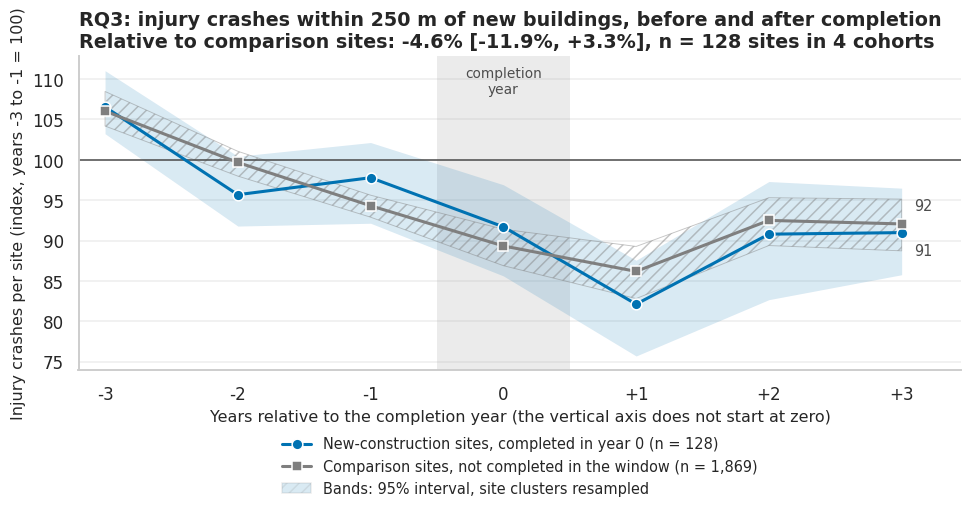

In [139]:
plot_event_profile(new_build_profile, new_build_did)

In [140]:
rq3_sentence = describe_effect(
    new_build_did["percent_change"], new_build_did["percent_low"], new_build_did["percent_high"], "percent",
    new_build_did["n_treated"], n_unit="new-construction sites", digits=1,
    subject=f"The after-against-before change in injury crashes within {BUFFER_M} m of new buildings, "
            f"relative to comparison sites,",
    above="more injury crashes after completion than the comparison sites would suggest",
    below="fewer injury crashes after completion than the comparison sites would suggest")
store_result("RQ3", f"Do injury crashes within {BUFFER_M} m of new-construction sites change after completion, "
             "relative to not-yet-completed sites?", new_build_did["percent_change"],
             new_build_did["percent_low"], new_build_did["percent_high"], new_build_did["n_treated"],
             rq3_sentence, "% change relative to comparison sites")
say(f"{rq3_sentence} The comparison group has {new_build_did['n_control']:,} site-cohort rows and the "
    f"bootstrap resamples {new_build_did['n_clusters']:,} clusters. On their own, treated sites changed by "
    f"{log_points_to_percent(new_build_did['treated_change']):+.1f}% and comparison sites by "
    f"{log_points_to_percent(new_build_did['control_change']):+.1f}% (means of site log ratios, converted to percent). "
    f"The placebo change inside the pre-period, from year {PRE_YEARS[0]} to year {PRE_YEARS[-1]}, is "
    f"{pretrend_did['percent_change']:+.1f}% (interval {pretrend_did['percent_low']:+.1f}% to "
    f"{pretrend_did['percent_high']:+.1f}%).")

The after-against-before change in injury crashes within 250 m of new buildings, relative to comparison sites, is -4.6 percent (95% interval -11.9 to +3.3, n = 128 new-construction sites). The interval includes zero. The comparison group has 1,869 site-cohort rows and the bootstrap resamples 356 clusters. On their own, treated sites changed by -13.8% and comparison sites by -9.7% (means of site log ratios, converted to percent). The placebo change inside the pre-period, from year -3 to year -1, is +6.6% (interval -6.9% to +21.0%).

The two lines move together. At treated and comparison sites alike, injury crashes are lower
at the end of the three years before completion than at the start, reach their lowest point in
the year after completion and recover part of the way. The fall at the new buildings is
therefore mostly the fall that happened at similar streets where nothing was completed, and a
plain before and after comparison would have credited it to the buildings. Once the comparison
sites are taken into account, the remaining difference is slightly negative and its interval
includes zero.

The placebo inside the pre-period also includes zero, but its interval is wider than the main
one (both are printed above). It cannot rule out a difference in earlier trends as large as
the main estimate, and Section 9.8 gives a narrower placebo.

The answer is that no change is detectable. The interval is wide enough to hold a moderate
decrease as well as a small increase, so this is not evidence that nothing changes.

For a new building, the years before completion are largely years of construction, with
fences and closed pavements, so "before" does not describe an undisturbed street. Some
comparison sites were themselves under construction during the window. The sites that pass
the screen are those with no other completion within the buffer in a different year of their
window, which are the less densely built parts of the programme. The result describes those
places, and Section 9.5 looks at the dense clusters where most buildings stand. The
comparison is stratified by cohort only, and the comparison sites are spread differently
across the boroughs than the treated sites. Section 9.9 repeats it inside boroughs.

### 8.4 RQ4. Does the change around a new building grow with the size of the building?

Owner: M2

The new-construction sites in this sample range from a single house to a tower with several
hundred apartments. If the people who move in are what changes the street, a tower should
leave a bigger mark than a house, and a relation of that kind would be more convincing than
one average over all sizes. The estimate is a slope: the change in the after to before ratio
of injury crashes for each doubling of the number of units.

Each treated site's log ratio is first compared with the mean log ratio of the comparison
sites of its cohort, which takes out the calendar years as in RQ3. The adjusted change is then
regressed on the base-2 logarithm of the size, so the slope reads per doubling. The size is
the number of units completed in that year within the buffer, the site's own building
included, because neighbouring buildings finished together are one event (Section 5.4). A row
of ten small houses is then entered as one event of ten households on the same streets, and
not as ten small ones. The slope on the building's own units is reported next to it. The
comparison means are recomputed inside every bootstrap resample, together with the slope, so
the interval carries the uncertainty of both steps.

One slope is used instead of size bins because it uses every site once, does not depend on
where the bin edges are put, and is a single test.

In [141]:
def cohort_adjusted_change(change, treated, cohort_codes, n_cohorts):
    """Each site's log ratio minus the mean log ratio of the comparison sites of its cohort."""
    comparison_n = np.bincount(cohort_codes[~treated], minlength=n_cohorts)
    comparison_sum = np.bincount(cohort_codes[~treated], weights=change[~treated], minlength=n_cohorts)
    # A resample can leave a cohort without comparison sites; its treated sites then get NaN
    # and are left out of the slope for that resample.
    comparison_mean = np.where(comparison_n > 0, comparison_sum / np.maximum(comparison_n, 1), np.nan)
    return change - comparison_mean[cohort_codes]


def add_event_units(sample, site_frame, radius_m=BUFFER_M):
    """Add `event_units` and `event_buildings` to the treated rows of an event sample.

    `event_units` is the sum of `total_units` over the sites within `radius_m` metres whose
    completion year equals the row's cohort, the site itself included; `event_buildings` counts
    those sites. Comparison rows have no completion and get NaN and zero.
    """
    first, second = site_neighbour_pairs(site_frame, radius_m)     # includes each site with itself
    neighbours = pd.DataFrame({
        "site_id": first,
        "cohort": site_frame["completion_year"].astype("float64").to_numpy()[second],
        "units": site_frame["total_units"].to_numpy(dtype=float)[second]})
    per_event = (neighbours.dropna(subset=["cohort"]).groupby(["site_id", "cohort"])["units"]
                 .agg(event_units="sum", event_buildings="size").reset_index())
    is_treated = sample["treated"].to_numpy()
    treated_keys = sample.loc[is_treated, ["site_id", "cohort"]].astype({"site_id": "int64", "cohort": "float64"})
    matched = treated_keys.merge(per_event.astype({"site_id": "int64"}), on=["site_id", "cohort"], how="left",
                                 validate="one_to_one")
    event_units = np.full(len(sample), np.nan)
    event_buildings = np.zeros(len(sample), dtype=np.int64)
    event_units[is_treated] = matched["event_units"].to_numpy()
    event_buildings[is_treated] = matched["event_buildings"].to_numpy(dtype=np.int64)
    with_events = sample.assign(event_units=event_units, event_buildings=event_buildings)
    treated_rows = with_events[is_treated]
    # A treated site is completed in its cohort year, so its own building is always in the sum.
    assert (treated_rows["event_units"] >= treated_rows["total_units"]).all()
    assert (treated_rows["event_buildings"] >= 1).all()
    return with_events


def dose_response(sample, n_grid=DOSE_GRID_POINTS, units_column="event_units"):
    """Slope of the comparison-adjusted log ratio on log2(units) among treated sites, with a fitted line.

    `units_column` names the size measure of the treated rows. Returns a dict with the slope per
    doubling (log points and percent), its interval, the treated points (`units`,
    `adjusted_change`, `cluster_id`) and the fitted line with its band on a grid.
    """
    change = log_ratio(sample["before"].to_numpy(), sample["after"].to_numpy())
    treated = sample["treated"].to_numpy()
    cohort_codes, cohort_labels = pd.factorize(sample["cohort"])
    # Comparison rows get a placeholder size of one unit; they never enter the slope.
    log_units = np.log2(np.where(treated, sample[units_column].to_numpy(dtype=float), 1.0))
    grid = np.linspace(log_units[treated].min(), log_units[treated].max(), n_grid)

    def slope_and_line(change_rows, treated_rows, cohort_rows, log_unit_rows):
        """[slope, fitted value at every grid point] for one resample."""
        adjusted = cohort_adjusted_change(change_rows, treated_rows, cohort_rows, len(cohort_labels))
        usable = treated_rows & ~np.isnan(adjusted)
        if usable.sum() < MIN_GROUP_N:
            return np.full(1 + n_grid, np.nan)
        slope = linear_slope(log_unit_rows[usable], adjusted[usable])
        intercept = adjusted[usable].mean() - slope * log_unit_rows[usable].mean()
        return np.r_[slope, intercept + slope * grid]

    boot = bootstrap_ci(slope_and_line, change, treated, cohort_codes, log_units,
                        clusters=sample["cluster_id"].to_numpy())
    adjusted = cohort_adjusted_change(change, treated, cohort_codes, len(cohort_labels))
    return {"estimate": float(boot["estimate"][0]), "low": float(boot["low"][0]), "high": float(boot["high"][0]),
            "p_value": float(boot["p_value"][0]), "n_treated": int(treated.sum()),
            "n_clusters": boot["n_clusters"],
            "points": pd.DataFrame({"units": sample.loc[treated, units_column].to_numpy(dtype=float),
                                    "adjusted_change": adjusted[treated],
                                    "cluster_id": sample.loc[treated, "cluster_id"].to_numpy()}),
            "line": pd.DataFrame({"units": 2.0 ** grid, "fit": boot["estimate"][1:],
                                  "low": boot["low"][1:], "high": boot["high"][1:]})}


def plot_dose_response(dose):
    """Scatter of treated sites (units against adjusted change) with the fitted line and its band."""
    fig, ax = plt.subplots(figsize=(9, 4.8))
    points, line = dose["points"], dose["line"]
    ax.axhline(0, color=PALETTE["neutral"], linewidth=1)
    ax.scatter(points["units"], points["adjusted_change"], s=34, color=PALETTE["treated"], alpha=0.5,
               edgecolor="white", linewidth=0.6, label=f"One new-construction site (n = {len(points)})")
    ax.fill_between(line["units"], line["low"], line["high"], color=PALETTE["crash"], alpha=0.18, linewidth=0,
                    label=f"{CI_LEVEL:.0%} interval of the line, site clusters resampled")
    ax.plot(line["units"], line["fit"], color=PALETTE["crash"], linewidth=2, label="Fitted line")
    ax.set_xscale("log")
    thousands(ax, axis="x")
    shown_ticks = [tick for tick in RATIO_TICKS
                   if points["adjusted_change"].min() - 0.3 <= np.log(tick) <= points["adjusted_change"].max() + 0.3]
    ax.set_yticks(np.log(shown_ticks))
    ax.set_yticklabels([f"x{tick:g}" for tick in shown_ticks])
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=3)
    finish(ax, f"RQ4: change in injury crashes around a new building against the units completed there\n"
               f"Per doubling of units: {log_points_to_percent(dose['estimate']):+.1f}% "
               f"[{log_points_to_percent(dose['low']):+.1f}%, {log_points_to_percent(dose['high']):+.1f}%]",
           f"Units completed in that year within {BUFFER_M} m of the site, own building included (log scale)",
           "Injury crashes after / before,\nrelative to comparison sites (ratio, log scale)")
    plt.tight_layout()
    plt.show()


dose_sample = add_event_units(new_build_sample, sites)
dose = dose_response(dose_sample)
dose_own_units = dose_response(dose_sample, units_column="total_units")
assert dose["points"]["adjusted_change"].notna().all()
# Rank version of the same relation, as a check that a few very large events do not decide it.
# Sites of one cluster share streets, so whole clusters are resampled here as well.
dose_rank = spearman_ci(np.log2(dose["points"]["units"]), dose["points"]["adjusted_change"],
                        clusters=dose["points"]["cluster_id"].to_numpy())
display(dose["points"].assign(units_completed_nearby=pd.cut(dose["points"]["units"], SIZE_BAND_EDGES,
                                                            labels=SIZE_BAND_LABELS))
        .groupby("units_completed_nearby", observed=True)["adjusted_change"]
        .agg(sites="size", mean_adjusted_log_ratio="mean", median_adjusted_log_ratio="median").round(3))

,sites,mean_adjusted_log_ratio,median_adjusted_log_ratio
units_completed_nearby,,,
1-4,1,-0.122,-0.122
5-19,45,-0.066,0.008
20-49,35,0.041,0.035
50-149,29,-0.075,-0.113
150+,18,-0.120,-0.098


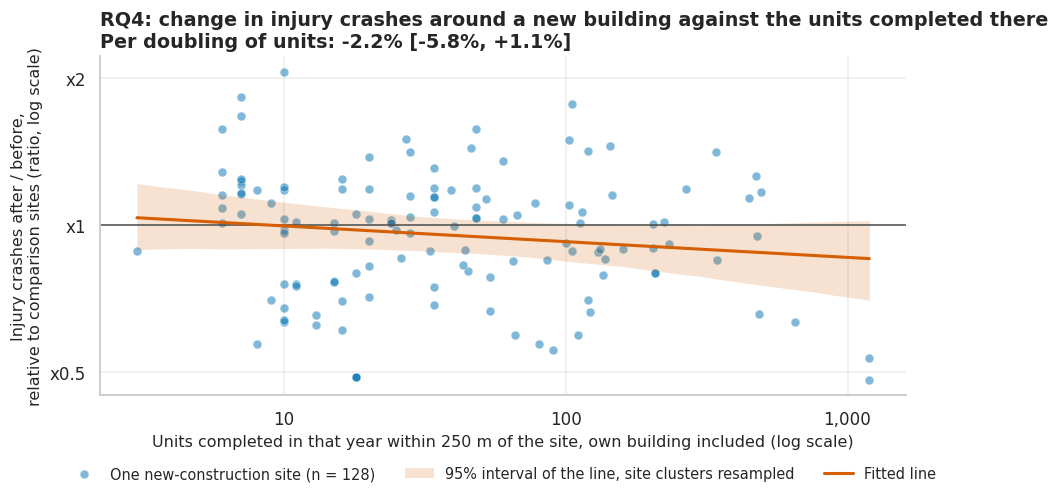

In [142]:
plot_dose_response(dose)

In [143]:
rq4_sentence = describe_effect(
    log_points_to_percent(dose["estimate"]), log_points_to_percent(dose["low"]), log_points_to_percent(dose["high"]), "percent per doubling of units",
    dose["n_treated"], n_unit="new-construction sites", digits=1,
    subject=f"The slope of the after-against-before change in injury crashes on the units completed in "
            f"that year within {BUFFER_M} m",
    above="a larger rise (or smaller fall) in injury crashes where more units were completed",
    below="a larger fall (or smaller rise) in injury crashes where more units were completed")
store_result("RQ4", "Does the before/after change in injury crashes at a new-construction site scale with "
             "the number of units?", log_points_to_percent(dose["estimate"]), log_points_to_percent(dose["low"]),
             log_points_to_percent(dose["high"]), dose["n_treated"], rq4_sentence, "% change per doubling of units")
dose_treated = dose_sample[dose_sample["treated"]]
n_dose_sites = len(dose_treated)
n_shared_events = int((dose_treated["event_buildings"] > 1).sum())
n_small_buildings = int((dose_treated["total_units"] < SMALL_BUILDING_UNITS).sum())
say(f"{rq4_sentence} The units completed nearby range from {int(dose['points']['units'].min())} to "
    f"{int(dose['points']['units'].max()):,} (median {dose['points']['units'].median():.0f}), and "
    f"{dose['n_clusters']:,} clusters are resampled. The rank correlation between size and adjusted change "
    f"is {dose_rank['estimate']:+.2f} (interval {dose_rank['low']:+.2f} to {dose_rank['high']:+.2f}, "
    f"n = {dose_rank['n']} sites in {dose_rank['n_clusters']} clusters, clusters resampled).")
say(f"{n_shared_events} of the {n_dose_sites} sites ({pct(n_shared_events, n_dose_sites):.0f}%) have at least one "
    f"other building completed in the same year within {BUFFER_M} m, up to "
    f"{int(dose_treated['event_buildings'].max())} buildings in one event. The median site has "
    f"{dose_treated['total_units'].median():.0f} units in its own building, and "
    f"{pct(n_small_buildings, n_dose_sites):.0f}% of the buildings have fewer than {SMALL_BUILDING_UNITS} units. "
    f"With the building's own units as the size, the slope is "
    f"{log_points_to_percent(dose_own_units['estimate']):+.1f}% per doubling (interval "
    f"{log_points_to_percent(dose_own_units['low']):+.1f}% to {log_points_to_percent(dose_own_units['high']):+.1f}%).")

The slope of the after-against-before change in injury crashes on the units completed in that year within 250 m is -2.2 percent per doubling of units (95% interval -5.8 to +1.1, n = 128 new-construction sites). The interval includes zero. The units completed nearby range from 3 to 1,194 (median 34), and 356 clusters are resampled. The rank correlation between size and adjusted change is -0.12 (interval -0.35 to +0.08, n = 128 sites in 85 clusters, clusters resampled).

44 of the 128 sites (34%) have at least one other building completed in the same year within 250 m, up to 12 buildings in one event. The median site has 16 units in its own building, and 55% of the buildings have fewer than 20 units. With the building's own units as the size, the slope is -1.1% per doubling (interval -4.7% to +2.2%).

No relation with size can be detected. The fitted line slopes down slightly and its interval
includes zero, and the rank correlation, which a few very large events cannot dominate, says
the same. The scatter shows why: at every size the sites are spread widely above and below
the line of no change, and that spread is far larger than any tilt of the line. Using the
building's own units instead of the units of the whole event gives a flatter slope with the
same reading.

An interval per doubling that looks narrow still leaves room for a sizeable difference between
the smallest and the largest events, which lie several doublings apart, so this is not
evidence that size makes no difference.

Two things limit this test: the sample is small and units only stand in for residents. Many of
the buildings are small (the median and the share of small buildings are printed above), where
the crash count within the buffer is decided by the street and not by a handful of new
households, so they add noise at the low end. The data have no count of residents, trips or
cars. The screen for nearby completions is also more likely to remove large projects, which
tend to be built in groups, so the large buildings that remain may not be typical of large
buildings in general.

### 8.5 RQ5. Is the change different for new construction than for preservation?

Owner: M3

The programme counts two very different things as a completed building. New construction puts
a building, and its residents, where there was none. Preservation refinances or renovates a
building whose tenants already live there, so the completion date marks paperwork and repairs
and nobody new arrives on the street. That makes preservation a placebo: a change in injury
crashes that comes with new residents should appear around new construction and not around
preservation. If both types show the same change, the change belongs to something else, such
as the kind of street the programme works on or the years in which it finished buildings.

Both types are compared with the same comparison sites, using the cohort-stratified
difference-in-differences of RQ3. The headline is the difference between the two estimates.
All three numbers come out of one bootstrap in which every resample draws the clusters once
and recomputes both estimates, so the comparison sites that the two estimates share are the
same in both and the interval of the difference accounts for that. Subtracting two separately
bootstrapped estimates would treat them as independent and give an interval that is too wide.

In [144]:
CONTRAST_NAMES = [NEW_CONSTRUCTION, PRESERVATION, "New construction relative to preservation"]


def construction_type_contrast(event_table):
    """DiD of the log ratio for each construction type against the shared comparison sites, and their difference.

    Returns a DataFrame indexed by CONTRAST_NAMES with the estimate and interval in log points
    and percent, the p-value and the number of treated sites behind each row.
    """
    change = log_ratio(event_table["before"].to_numpy(), event_table["after"].to_numpy())
    treated = event_table["treated"].to_numpy()
    construction = event_table["construction_type"].astype(str).to_numpy()
    # Arm 0 = comparison (any type, since nothing was completed there), 1 and 2 = the treated types.
    arm = np.where(~treated, 0, np.where(construction == NEW_CONSTRUCTION, 1, 2))
    assert set(construction[treated]) <= {NEW_CONSTRUCTION, PRESERVATION}
    cohort_codes, cohort_labels = pd.factorize(event_table["cohort"])

    def type_estimates(change_rows, arm_rows, cohort_rows):
        """[new construction, preservation, difference] recomputed on one resample."""
        by_type = []
        for treated_arm in (1, 2):
            rows = (arm_rows == 0) | (arm_rows == treated_arm)
            by_type.append(stratified_difference(change_rows[rows], arm_rows[rows] == treated_arm,
                                                 cohort_rows[rows], len(cohort_labels))["estimate"])
        return np.array([by_type[0], by_type[1], by_type[0] - by_type[1]])

    boot = bootstrap_ci(type_estimates, change, arm, cohort_codes, clusters=event_table["cluster_id"].to_numpy())
    n_new, n_preserved = int((arm == 1).sum()), int((arm == 2).sum())
    table = pd.DataFrame({"estimate": boot["estimate"], "low": boot["low"], "high": boot["high"],
                          "p_value": boot["p_value"], "n_treated": [n_new, n_preserved, n_new + n_preserved],
                          "n_comparison": int((arm == 0).sum()), "n_clusters": boot["n_clusters"],
                          "n_failed": boot["n_failed"]},
                         index=pd.Index(CONTRAST_NAMES, name="contrast"))
    for column in ["estimate", "low", "high"]:
        table[f"{column}_pct"] = log_points_to_percent(table[column])
    return table


def plot_type_contrast(contrast, note):
    """Dot and interval for each construction type and for their difference; `note` goes under the chart."""
    fig, ax = plt.subplots(figsize=(10, 4.3))
    colors = [PALETTE["treated"], PALETTE["placebo"], PALETTE["neutral"]]
    positions = np.array([0, 1, 2.4])
    ax.axvline(0, color=PALETTE["neutral"], linewidth=1)
    ax.axhline(1.7, color=PALETTE["before"], linewidth=0.8, linestyle=":")
    ax.hlines(positions, contrast["low_pct"], contrast["high_pct"], color=colors, linewidth=2)
    ax.scatter(contrast["estimate_pct"], positions, s=70, color=colors, zorder=3, edgecolor="white",
               linewidth=1.2)
    reach = float(np.abs(contrast[["low_pct", "high_pct"]].to_numpy()).max())
    ax.set_xlim(-1.15 * reach, 1.15 * reach)
    # Every value label starts at the left edge of the plot, above its row, so none of them
    # is written across the zero line.
    for position, (_, row) in zip(positions, contrast.iterrows()):
        ax.text(0.01, position - 0.33,
                f"{row['estimate_pct']:+.1f}%  [{row['low_pct']:+.1f}%, {row['high_pct']:+.1f}%]",
                transform=ax.get_yaxis_transform(), ha="left", va="center", fontsize=9.5, color=PALETTE["neutral"])
    labels = [f"New construction\n(n = {contrast['n_treated'].iloc[0]} sites)",
              f"Preservation, the placebo\n(n = {contrast['n_treated'].iloc[1]} sites)",
              "New construction relative\nto preservation"]
    ax.set_yticks(positions)
    ax.set_yticklabels(labels)
    ax.set_ylim(positions[-1] + 0.5, positions[0] - 0.7)
    ax.xaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda value, _: f"{value:+.0f}%"))
    ax.grid(axis="y", visible=False)
    finish(ax, "RQ5: change in injury crashes near a site after completion, by project type",
           f"Injury crashes within {BUFFER_M} m, after against before, relative to comparison sites\n"
           f"({CI_LEVEL:.0%} interval, site clusters resampled); right of zero = more after completion", "")
    ax.annotate(note, xy=(0, -0.36), xycoords="axes fraction", fontsize=8.5, color=PALETTE["neutral"], va="top")
    plt.tight_layout()
    plt.show()


type_contrast = construction_type_contrast(event_site_table)
assert np.isclose(type_contrast.loc[NEW_CONSTRUCTION, "estimate"], new_build_did["estimate"]), \
    "the new-construction row must reproduce RQ3"
display(type_contrast[["estimate_pct", "low_pct", "high_pct", "p_value", "n_treated", "n_comparison",
                       "n_clusters"]].round(3))

,estimate_pct,low_pct,high_pct,p_value,n_treated,n_comparison,n_clusters
contrast,,,,,,,
New Construction,-4.561,-12.137,3.292,0.266,128,1869,409
Preservation,3.848,-7.000,16.223,0.490,178,1869,409
New construction relative to preservation,-8.098,-19.576,4.856,0.226,306,1869,409


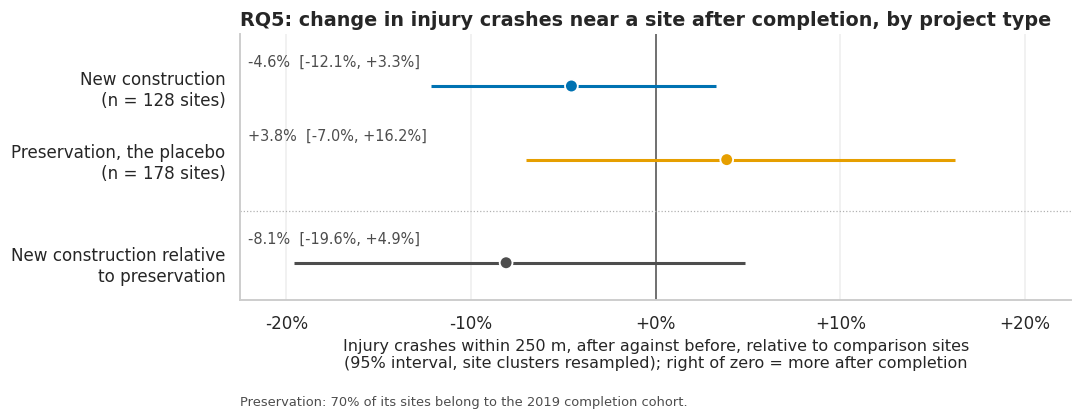

In [145]:
preserved_by_cohort = event_site_table[event_site_table["treated"]
                                       & (event_site_table["construction_type"] == PRESERVATION)].groupby("cohort").size()
preservation_cohort_share = pct(preserved_by_cohort.max(), preserved_by_cohort.sum())
plot_type_contrast(type_contrast, f"Preservation: {preservation_cohort_share:.0f}% of its sites belong to the "
                                  f"{preserved_by_cohort.idxmax()} completion cohort.")

In [146]:
rq5 = type_contrast.loc[CONTRAST_NAMES[2]]
rq5_sentence = describe_effect(
    rq5["estimate_pct"], rq5["low_pct"], rq5["high_pct"], "percent", int(rq5["n_treated"]),
    n_unit="completed sites", digits=1,
    subject="The after-to-before ratio of injury crashes around new construction, relative to the same "
            "ratio around preservation,",
    above="a more positive change around new construction than around preservation",
    below="a more negative change around new construction than around preservation")
store_result("RQ5", "Is the before/after change in injury crashes different near New Construction than near "
             "Preservation (the placebo)?", rq5["estimate_pct"], rq5["low_pct"], rq5["high_pct"],
             rq5["n_treated"], rq5_sentence, "% difference between the two after/before ratios")
preserved = type_contrast.loc[PRESERVATION]
new_built = type_contrast.loc[NEW_CONSTRUCTION]
say(f"{rq5_sentence} Taken separately, the change relative to comparison sites is "
    f"{new_built['estimate_pct']:+.1f}% (interval {new_built['low_pct']:+.1f}% to {new_built['high_pct']:+.1f}%, "
    f"n = {int(new_built['n_treated'])} sites) for new construction and {preserved['estimate_pct']:+.1f}% "
    f"(interval {preserved['low_pct']:+.1f}% to {preserved['high_pct']:+.1f}%, n = {int(preserved['n_treated'])} "
    f"sites) for preservation, both against {int(rq5['n_comparison']):,} comparison rows and with "
    f"{int(rq5['n_clusters']):,} clusters resampled. Of the preservation sites, "
    f"{preservation_cohort_share:.0f}% belong to the {preserved_by_cohort.idxmax()} cohort.")
say(f"The new-construction estimate is the one of RQ3, whose interval was {new_build_did['percent_low']:+.1f}% to "
    f"{new_build_did['percent_high']:+.1f}% with {new_build_did['n_clusters']:,} clusters. The interval of the "
    f"same estimate inside this joint bootstrap is slightly different because the {int(rq5['n_clusters']):,} "
    f"clusters drawn here include those that contain only preservation sites.")

The after-to-before ratio of injury crashes around new construction, relative to the same ratio around preservation, is -8.1 percent (95% interval -19.6 to +4.9, n = 306 completed sites). The interval includes zero. Taken separately, the change relative to comparison sites is -4.6% (interval -12.1% to +3.3%, n = 128 sites) for new construction and +3.8% (interval -7.0% to +16.2%, n = 178 sites) for preservation, both against 1,869 comparison rows and with 409 clusters resampled. Of the preservation sites, 70% belong to the 2019 cohort.

The new-construction estimate is the one of RQ3, whose interval was -11.9% to +3.3% with 356 clusters. The interval of the same estimate inside this joint bootstrap is slightly different because the 409 clusters drawn here include those that contain only preservation sites.

New construction and preservation cannot be told apart. The estimate for new construction is
below zero and the one for preservation above it, but each interval includes zero and so does
the interval of the contrast between them. The preservation estimate is wide (its interval is
printed above) and most of its sites belong to one cohort, so it is too imprecise to confirm
that a completion without new residents leaves crashes unchanged. New construction does not
differ from it by more than the noise.

The placebo has its own weaknesses. For many preservation projects the recorded completion
date equals the start date (Section 4.4), so the line between before and after is an
administrative date and not the end of any work on the street. Most preservation sites in the
sample come from one cohort, so their estimate depends heavily on the calendar years of that
cohort. Preserved buildings are also older buildings on established streets, which differ
from the streets where new buildings go up, and the two estimates share one pool of
comparison sites. The contrast is the least precise number in this group of questions.

### 8.6 RQ6. Does the pedestrian and cyclist share of injury crashes near affordable-housing sites change after completion, by borough?

Owner: M3

A finished building puts more people on the pavement around it. This question looks at
whether the people hurt on those streets are, more often than before, the ones outside a
vehicle. We report the change in the share of injury crashes that hurt a pedestrian or
cyclist, in percentage points, with an interval, for the city and for each borough that has
enough sites.

The share is compared at the same places, in the `EVENT_WINDOW` years before and after the
completion year, using the clean sites of the event table from Section 5. A plain before and
after comparison is not enough here, because the mix of victims moved across the whole city in
these years (the pandemic emptied the roads of cars, and cycling and e-bikes grew). The same
change is therefore measured at comparison sites that were not yet completed, over the same
calendar years, and the estimate is the gap between the two changes. Each cohort is compared
with its own comparison sites and the cohorts are averaged with the treated crash counts as
weights, so that the comparison group has the same calendar mix as the treated group. Shares
are pooled over sites, since a share computed at one site with two or three crashes can only be
zero, a half or one. Sites of the same cluster share streets and crashes, so whole clusters are
resampled in the bootstrap.

Completed sites of both kinds are pooled to keep the sample usable, although only new
construction brings new residents and preservation is the placebo of RQ5. The pooled gap is
therefore a statement about completed sites of either kind. It is also estimated with the
treated group limited to new construction, and printed next to the pooled one together with
the number of sites of each kind.

The three composition questions of this section (who is hurt here, the hour of day in RQ8 and
the contributing factor in RQ10) use the same design, so the functions are written once for
any set of categories.

In [147]:
# --- Constants used only in Sections 8.6 to 8.10 --------------------------------------------
PEDESTRIAN_CYCLIST_LABELS = ["Pedestrian or cyclist hurt", "Only vehicle occupants hurt"]
ALL_BOROUGHS_LABEL = "All boroughs"
COMPOSITION_UNIT_COLUMNS = ["cluster_id", "borough", "construction_type"]   # carried by every (site, cohort) unit
REFERENCE_SPACING_M = BUFFER_M     # metres between reference points; one buffer radius, so the
                                   # buffers of neighbouring points overlap and no street is skipped
STREET_SNAP_M = 100                # metres; a reference point counts as "on a street" if any crash
                                   # was ever reported this close (about one short block)
NEUTRAL_PERCENTILE = 50            # mean percentile that sites would have if they were typical streets
PERCENTILE_BIN_WIDTH = 10          # percentile points per bar in the RQ7 distribution
MAP_REFERENCE_COLOR = "#D9D9D9"    # light grey for the street grid behind the sites on the map
MAP_MARKER_EDGE = "#333333"        # thin dark outline, so the light end of the colour scale stays visible
HOURS_PER_DAY = 24
UNRECORDED_FACTOR = "Unspecified"  # RQ10: factor group meaning that the report names no factor
UNRECORDED_LABELS = [UNRECORDED_FACTOR, "Recorded factor"]   # the two categories of the RQ10 check
UNRECORDED_ROW = "No factor recorded (check)"   # label of that group in the RQ10 figure
MIN_ZIP_AFFORDABLE_UNITS = 50      # RQ9: units; below this a ZIP's deep-affordable share rests on
                                   # one or two small buildings and jumps between 0 and 100 percent
BOROUGH_MARKERS = dict(zip(BOROUGHS, ["o", "s", "^", "D", "v"]))   # RQ9: a shape per borough next to its colour

The clean sites, one row per site and cohort, come from `cohort_unit_table` (Section 8). The
function below counts the injury crashes near each of them by period and category, from the
site and crash pairs of Section 5. A comparison site can serve several cohorts, so it
contributes one row per cohort and all its rows are resampled together.

In [148]:
def period_category_counts(units, pairs, crash_frame, category_codes, n_categories, window=EVENT_WINDOW):
    """Injury crashes near each unit before and after its cohort year, split by category.

    category_codes: one integer per row of `crash_frame`; a negative code leaves the crash out.
    Returns (before, after), two integer arrays of shape (number of units, n_categories). The
    cohort year itself is in neither period, because the building opens part-way through it.
    """
    is_counted = crash_frame["is_injury_crash"].to_numpy() & (category_codes >= 0)
    near = pairs.loc[is_counted[pairs["crash_row"].to_numpy()], ["site_id", "crash_row"]]
    unit_keys = units[["site_id", "cohort"]].assign(unit=np.arange(len(units)))
    # A site in several cohorts matches several unit rows, so this merge is many to many on purpose.
    near = near.merge(unit_keys, on="site_id", how="inner")
    crash_rows = near["crash_row"].to_numpy()
    relative_year = crash_frame["year"].to_numpy()[crash_rows].astype(np.int64) - near["cohort"].to_numpy()
    cell = near["unit"].to_numpy() * n_categories + category_codes[crash_rows]
    shape = (len(units), n_categories)
    is_before = (relative_year >= -window) & (relative_year <= -1)
    is_after = (relative_year >= 1) & (relative_year <= window)
    before = np.bincount(cell[is_before], minlength=shape[0] * shape[1]).reshape(shape)
    after = np.bincount(cell[is_after], minlength=shape[0] * shape[1]).reshape(shape)
    return before, after

The statistic is a difference-in-differences on shares. For every cohort it computes the share
of each category before and after, at treated and at comparison sites, and takes the treated
change minus the comparison change. `composition_shift` wraps it in the cluster bootstrap of
Section 7 and adjusts the p-values for the number of categories tested together.

In [149]:
def cohort_weighted_shifts(before, after, treated, cohort_codes, n_cohorts):
    """Change in category shares at treated sites, at comparison sites, and the gap between them.

    before, after: (units, categories) counts. Returns an array of shape (3, categories) holding
    the treated change, the comparison change and their difference, as proportions. Each is an
    average over cohorts weighted by the treated crash count of the cohort. A cohort in which
    either arm has no crashes in either period cannot be compared and is left out of all three.
    """
    n_categories = before.shape[1]
    # Every count belongs to one (arm, cohort, category) cell; one bincount sums all cells at once.
    cell = ((treated.astype(np.int64) * n_cohorts + cohort_codes)[:, None] * n_categories
            + np.arange(n_categories)[None, :]).ravel()
    n_cells = 2 * n_cohorts * n_categories
    before_sums = np.bincount(cell, weights=before.ravel(), minlength=n_cells).reshape(2, n_cohorts, n_categories)
    after_sums = np.bincount(cell, weights=after.ravel(), minlength=n_cells).reshape(2, n_cohorts, n_categories)
    before_totals = before_sums.sum(axis=2)
    after_totals = after_sums.sum(axis=2)
    comparable = ((before_totals > 0) & (after_totals > 0)).all(axis=0)
    if not comparable.any():
        return np.full((3, n_categories), np.nan)
    before_sums, after_sums = before_sums[:, comparable], after_sums[:, comparable]
    before_totals, after_totals = before_totals[:, comparable], after_totals[:, comparable]
    change = after_sums / after_totals[:, :, None] - before_sums / before_totals[:, :, None]
    treated_events = before_totals[1] + after_totals[1]          # arm 1 is the treated arm
    weights = treated_events / treated_events.sum()
    treated_change = (weights[:, None] * change[1]).sum(axis=0)
    comparison_change = (weights[:, None] * change[0]).sum(axis=0)
    return np.vstack([treated_change, comparison_change, treated_change - comparison_change])


def pooled_shares(counts, is_member):
    """Category shares in percent, pooled over the units selected by `is_member`."""
    totals = counts[is_member].sum(axis=0)
    return PERCENT * totals / totals.sum() if totals.sum() > 0 else np.full(counts.shape[1], np.nan)


def composition_shift(units, before, after, labels, n_boot=N_BOOT, seed=SEED):
    """Difference-in-differences of category shares with a cluster bootstrap, in percentage points.

    Returns (table, summary). `table` has one row per category: pooled shares before and after in
    each arm, the cohort-weighted change in each arm, their `gap`, its interval `low` to `high`,
    `p_value`, the Benjamini-Hochberg `p_adjusted` across the categories and `flagged`. The
    columns `low_joint` and `high_joint` hold a wider interval at the level `joint_level` of the
    summary, which is CI_LEVEL with its error share divided by the number of categories
    (Bonferroni). It is the interval to quote for a category that was picked after looking at
    all of them. `summary` also holds the sample sizes: sites, clusters and injury crashes.
    """
    treated = units["treated"].to_numpy()
    cohort_codes, cohort_labels = pd.factorize(units["cohort"].to_numpy(), sort=True)
    n_cohorts, n_categories = len(cohort_labels), len(labels)
    assert before.shape == after.shape == (len(units), n_categories)

    def stacked_shifts(before_rows, after_rows, treated_rows, cohort_rows):
        """The (3, categories) result flattened, because the bootstrap expects a 1-D statistic."""
        return cohort_weighted_shifts(before_rows, after_rows, treated_rows, cohort_rows, n_cohorts).ravel()

    boot = bootstrap_ci(stacked_shifts, before, after, treated, cohort_codes,
                        clusters=units["cluster_id"].to_numpy(), n_boot=n_boot, seed=seed)
    joint_level = 1 - (1 - CI_LEVEL) / n_categories
    joint = percentile_ci(boot["replicates"], level=joint_level)
    in_points = {key: PERCENT * np.asarray(values).reshape(3, n_categories)
                 for key, values in (("estimate", boot["estimate"]), ("low", boot["low"]), ("high", boot["high"]),
                                     ("low_joint", joint["low"]), ("high_joint", joint["high"]))}
    gap_p_values = np.asarray(boot["p_value"]).reshape(3, n_categories)[2]
    table = pd.DataFrame({
        "treated_before": pooled_shares(before, treated), "treated_after": pooled_shares(after, treated),
        "comparison_before": pooled_shares(before, ~treated), "comparison_after": pooled_shares(after, ~treated),
        "treated_change": in_points["estimate"][0], "comparison_change": in_points["estimate"][1],
        "gap": in_points["estimate"][2], "low": in_points["low"][2], "high": in_points["high"][2],
        "low_joint": in_points["low_joint"][2], "high_joint": in_points["high_joint"][2],
        "p_value": gap_p_values, "p_adjusted": benjamini_hochberg(gap_p_values),
    }, index=pd.Index(labels, name="category"))
    table["flagged"] = table["p_adjusted"] < FALSE_DISCOVERY_RATE
    summary = {
        "n_treated_sites": int(units.loc[treated, "site_id"].nunique()),
        "n_comparison_sites": int(units.loc[~treated, "site_id"].nunique()),
        "n_clusters": boot["n_clusters"],
        "treated_crashes": int(before[treated].sum() + after[treated].sum()),
        "comparison_crashes": int(before[~treated].sum() + after[~treated].sum()),
        "joint_level": joint_level,
    }
    return table, summary


def units_of_kind(units, construction_type):
    """Mask of the units left when the treated group is limited to one kind of project.

    Comparison units of any construction type stay, because nothing was completed there.
    """
    return (~units["treated"] | (units["construction_type"] == construction_type)).to_numpy()

For RQ6 the two categories are an injury crash that hurt at least one pedestrian or cyclist and
an injury crash that hurt vehicle occupants only. The counts are rebuilt from the pairs and
checked against the event table, which holds the same totals from an independent aggregation.
A borough is estimated only if it has at least `MIN_GROUP_N` clean completed sites and as many
comparison sites. The borough p-values are adjusted together, because looking at several
boroughs gives chance several tries.

In [150]:
def pedestrian_cyclist_counts(units, pairs, crash_frame, panel):
    """Injury crashes near each unit before and after, split by PEDESTRIAN_CYCLIST_LABELS.

    The counts are rebuilt from the pairs and must equal the event table, which holds the same
    totals from an independent aggregation by site and year.
    """
    codes = np.where(crash_frame["ped_cyc_harm"].to_numpy(), 0, 1)
    before, after = period_category_counts(units, pairs, crash_frame, codes, len(PEDESTRIAN_CYCLIST_LABELS))
    in_event_window = ~panel["contaminated"] & (panel["rel_year"] != 0)
    expected = (panel[in_event_window].assign(after=lambda rows: rows["rel_year"] > 0)
                .groupby(["site_id", "cohort", "after"])[["injury_crashes", "ped_cyc_crashes"]].sum())
    for is_after, counts in ((False, before), (True, after)):
        from_panel = expected.xs(is_after, level="after").reindex(
            pd.MultiIndex.from_frame(units[["site_id", "cohort"]]))
        assert (from_panel["injury_crashes"].to_numpy() == counts.sum(axis=1)).all()
        assert (from_panel["ped_cyc_crashes"].to_numpy() == counts[:, 0]).all()
    return before, after


def pedestrian_cyclist_share_shift(units, before, after):
    """RQ6 statistic: gap in the pedestrian and cyclist share, citywide and for each borough.

    Returns (table, summaries): one row per area with the shares, the gap in percentage points
    and its interval, and a dict of the sample sizes per area.
    """
    rows, summaries = {}, {}
    for area in [ALL_BOROUGHS_LABEL, *BOROUGHS]:
        in_area = np.ones(len(units), dtype=bool) if area == ALL_BOROUGHS_LABEL else (units["borough"] == area).to_numpy()
        area_units = units[in_area]
        n_treated = int(area_units["treated"].sum())
        n_comparison = int(area_units.loc[~area_units["treated"], "site_id"].nunique())
        if min(n_treated, n_comparison) < MIN_GROUP_N:
            summaries[area] = {"n_treated_sites": n_treated, "n_comparison_sites": n_comparison, "estimated": False}
            continue
        table, summary = composition_shift(area_units, before[in_area], after[in_area], PEDESTRIAN_CYCLIST_LABELS)
        # With two complementary categories there is one test per area, so the joint columns are not needed.
        rows[area] = table.loc[PEDESTRIAN_CYCLIST_LABELS[0]].drop(["p_adjusted", "flagged", "low_joint", "high_joint"])
        summaries[area] = {**summary, "estimated": True}
    result = pd.DataFrame(rows).T.astype(float)
    result.index.name = "area"
    is_borough = result.index != ALL_BOROUGHS_LABEL
    result.loc[is_borough, "p_adjusted"] = benjamini_hochberg(result.loc[is_borough, "p_value"].to_numpy())
    result["flagged"] = result["p_adjusted"] < FALSE_DISCOVERY_RATE
    return result, summaries


event_units = cohort_unit_table(event_panel, COMPOSITION_UNIT_COLUMNS)
is_new_construction_unit = units_of_kind(event_units, NEW_CONSTRUCTION)
is_preservation_unit = units_of_kind(event_units, PRESERVATION)
rq6_before, rq6_after = pedestrian_cyclist_counts(event_units, site_pairs, crashes, event_panel)
rq6_table, rq6_samples = pedestrian_cyclist_share_shift(event_units, rq6_before, rq6_after)
rq6_new_table, rq6_new_sample = composition_shift(
    event_units[is_new_construction_unit], rq6_before[is_new_construction_unit],
    rq6_after[is_new_construction_unit], PEDESTRIAN_CYCLIST_LABELS)
rq6_new = rq6_new_table.loc[PEDESTRIAN_CYCLIST_LABELS[0]]
display(rq6_table.drop(columns=["flagged"]).round(2))

,treated_before,treated_after,comparison_before,comparison_after,treated_change,comparison_change,gap,low,high,p_value,p_adjusted
area,,,,,,,,,,,
All boroughs,37.630,37.810,43.860,42.240,-0.210,-1.430,1.220,-1.080,3.390,0.330,NaN
Bronx,30.600,29.710,29.480,27.470,-1.010,-2.100,1.080,-3.490,5.610,0.660,0.780
Brooklyn,41.100,41.930,40.320,38.790,0.930,-0.940,1.870,-0.890,7.050,0.190,0.750
Manhattan,49.850,48.160,57.760,55.810,-2.500,-1.770,-0.720,-4.350,3.430,0.780,0.780
Queens,36.580,36.360,42.530,41.850,-0.310,0.350,-0.660,-5.460,3.820,0.740,0.780


The figure shows the gap for each area as a dot with its interval. A dot to the right of zero
means that the pedestrian and cyclist share rose more around completed buildings than around
sites still waiting to be completed.

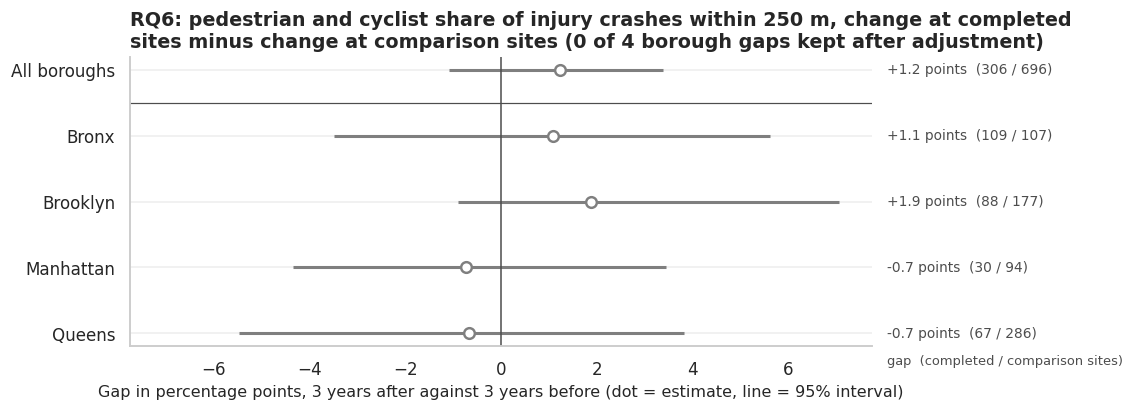

In [151]:
def draw_gap_rows(ax, table, value_labels, label_header, is_check=None, check_label=""):
    """Draw one dot and interval per row of `table` (columns gap, low, high, flagged), top to bottom.

    A filled blue dot marks a gap that is kept after the adjustment for several tests, a hollow
    grey one a gap that is not. Rows selected by `is_check` are drawn as orange diamonds and
    named `check_label` in the legend: they are shown for reference and are not part of the
    adjusted set. `value_labels` are written to the right of the plot under `label_header`.
    Returns True when more than one kind of marker was drawn, so the caller knows whether a
    legend has anything to explain.
    """
    positions = np.arange(len(table))
    is_check = np.zeros(len(table), dtype=bool) if is_check is None else np.asarray(is_check, dtype=bool)
    flagged = table["flagged"].to_numpy(dtype=bool)
    kinds = [(~flagged & ~is_check, PALETTE["control"], "white", "o", "Not kept after adjustment for several tests"),
             (flagged & ~is_check, PALETTE["treated"], PALETTE["treated"], "o", "Kept after adjustment for several tests"),
             (is_check, PALETTE["placebo"], PALETTE["placebo"], "D", check_label)]
    n_kinds_drawn = 0
    for chosen, color, face, marker, label in kinds:
        if not chosen.any():
            continue
        n_kinds_drawn += 1
        ax.errorbar(table["gap"].to_numpy()[chosen], positions[chosen],
                    xerr=[(table["gap"] - table["low"]).to_numpy()[chosen],
                          (table["high"] - table["gap"]).to_numpy()[chosen]],
                    fmt=marker, color=color, markerfacecolor=face, markersize=7, markeredgewidth=1.6,
                    elinewidth=2, capsize=0, label=label)
    ax.axvline(0, color=PALETTE["neutral"], linewidth=1)
    reach = float(np.abs(table[["low", "high"]].to_numpy()).max())
    ax.set_xlim(-1.1 * reach, 1.1 * reach)
    # The labels sit outside the plot area: x in axes fractions, y in row positions. The light
    # row lines lead the eye from a dot to its label.
    for position, text in zip(positions, value_labels):
        ax.text(1.02, position, text, transform=ax.get_yaxis_transform(), va="center", fontsize=9,
                color=PALETTE["neutral"])
    ax.text(1.02, -0.03, label_header, transform=ax.transAxes, va="top", fontsize=8.5, color=PALETTE["neutral"])
    ax.set_yticks(positions)
    ax.set_yticklabels(table.index)
    ax.invert_yaxis()
    ax.grid(axis="x", visible=False)
    return n_kinds_drawn > 1


def plot_pedestrian_cyclist_gap(table, samples):
    """RQ6 figure: gap in the pedestrian and cyclist share by area, with intervals at CI_LEVEL."""
    fig, ax = plt.subplots(figsize=(10.5, 3.9))
    value_labels = [f"{row.gap:+.1f} points  ({samples[area]['n_treated_sites']} / "
                    f"{samples[area]['n_comparison_sites']})" for area, row in table.iterrows()]
    shown = table.assign(flagged=table["flagged"].fillna(False).astype(bool))
    has_two_kinds = draw_gap_rows(ax, shown, value_labels, "gap  (completed / comparison sites)")
    ax.axhline(0.5, color=PALETTE["neutral"], linewidth=0.8)   # separates the citywide row from the boroughs
    if has_two_kinds:
        ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.24), ncol=2)
    n_boroughs = int((table.index != ALL_BOROUGHS_LABEL).sum())
    finish(ax, f"RQ6: pedestrian and cyclist share of injury crashes within {BUFFER_M} m, change at completed\n"
               f"sites minus change at comparison sites ({int(shown['flagged'].sum())} of {n_boroughs} borough "
               f"gaps kept after adjustment)",
           f"Gap in percentage points, {EVENT_WINDOW} years after against {EVENT_WINDOW} years before "
           f"(dot = estimate, line = {CI_LEVEL:.0%} interval)", "")
    plt.tight_layout()
    plt.show()


plot_pedestrian_cyclist_gap(rq6_table, rq6_samples)

In [152]:
rq6_city = rq6_table.loc[ALL_BOROUGHS_LABEL]
rq6_sample = rq6_samples[ALL_BOROUGHS_LABEL]
rq6_sentence = describe_effect(
    rq6_city["gap"], rq6_city["low"], rq6_city["high"], "percentage points",
    rq6_sample["n_treated_sites"], n_unit=f"completed sites, against {rq6_sample['n_comparison_sites']:,} "
    f"comparison sites, in {rq6_sample['n_clusters']:,} clusters",
    subject="The gap in the pedestrian and cyclist share of injury crashes (completed minus comparison sites)",
    above="a larger rise in the pedestrian and cyclist share around completed buildings",
    below="a smaller rise in the pedestrian and cyclist share around completed buildings")
say(rq6_sentence)
say(f"Weighted over cohorts, the share changed by {rq6_city['treated_change']:+.2f} points around completed "
    f"sites and by {rq6_city['comparison_change']:+.2f} points around comparison sites over the same calendar "
    f"years; the gap is the difference between the two. Before completion the share was about "
    f"{rq6_city['treated_before']:.0f}% around completed sites and {rq6_city['comparison_before']:.0f}% around "
    f"comparison sites (pooled over {rq6_sample['treated_crashes']:,} and {rq6_sample['comparison_crashes']:,} "
    f"site-level injury crash counts).")
n_completed_sites = rq6_sample["n_treated_sites"]
n_new_construction_sites = rq6_new_sample["n_treated_sites"]
say(f"Of the {n_completed_sites:,} completed sites, {n_new_construction_sites:,} are new construction and "
    f"{n_completed_sites - n_new_construction_sites:,} are preservation. With the treated group limited to new "
    f"construction the gap is {rq6_new['gap']:+.2f} points ({CI_LEVEL:.0%} interval {rq6_new['low']:+.2f} to "
    f"{rq6_new['high']:+.2f}).")
rq6_boroughs = rq6_table.drop(index=ALL_BOROUGHS_LABEL)
rq6_skipped = [f"{area} ({sample['n_treated_sites']} completed sites)"
               for area, sample in rq6_samples.items() if not sample["estimated"]]
say(f"By borough the gaps run from {rq6_boroughs['gap'].min():+.1f} ({rq6_boroughs['gap'].idxmin()}) to "
    f"{rq6_boroughs['gap'].max():+.1f} points ({rq6_boroughs['gap'].idxmax()}). After adjustment for "
    f"{len(rq6_boroughs)} boroughs, {int(rq6_boroughs['flagged'].sum())} of them keep an interval away from zero "
    f"(smallest adjusted p = {rq6_boroughs['p_adjusted'].min():.2f}). Not estimated, because fewer than "
    f"{MIN_GROUP_N} clean sites: {', '.join(rq6_skipped) if rq6_skipped else 'none'}.")
store_result("RQ6", "Does the pedestrian and cyclist share of injury crashes near sites change after completion?",
             rq6_city["gap"], rq6_city["low"], rq6_city["high"], rq6_sample["n_treated_sites"], rq6_sentence,
             "percentage points, completed minus comparison sites")

The gap in the pedestrian and cyclist share of injury crashes (completed minus comparison sites) is +1.22 percentage points (95% interval -1.08 to +3.39, n = 306 completed sites, against 696 comparison sites, in 409 clusters). The interval includes zero.

Weighted over cohorts, the share changed by -0.21 points around completed sites and by -1.43 points around comparison sites over the same calendar years; the gap is the difference between the two. Before completion the share was about 38% around completed sites and 44% around comparison sites (pooled over 26,680 and 149,854 site-level injury crash counts).

Of the 306 completed sites, 128 are new construction and 178 are preservation. With the treated group limited to new construction the gap is +1.16 points (95% interval -1.35 to +3.71).

By borough the gaps run from -0.7 (Manhattan) to +1.9 points (Brooklyn). After adjustment for 4 boroughs, 0 of them keep an interval away from zero (smallest adjusted p = 0.75). Not estimated, because fewer than 30 clean sites: Staten Island (12 completed sites).

The pedestrian and cyclist share changed little around completed sites of either kind and fell
somewhat more around comparison sites over the same calendar years. The gap between the two is
positive, but its interval reaches well below zero, so these data do not show a change in who
is hurt after a completion. The boroughs do not point one way either: the estimates for the
Bronx and Brooklyn are positive, those for Manhattan and Queens negative, every interval is
several points wide, and none is kept after the adjustment. Staten Island has too few clean
sites to be estimated at all.

The two groups start from different levels: before completion the share is higher around
comparison sites than around completed ones. The design allows a difference in level and
assumes only that the two groups would have moved alike.

The interval is several percentage points wide, so a real shift smaller than that, in either
direction, would not be visible. More than half of the completed sites are preservation
projects, where nobody new moved in. With the treated group limited to new construction, the
only kind of project that brings new residents, the gap is almost the same and its interval a
little wider, so pooling the two kinds does not hide a shift at new buildings that these data
could detect. The clean sites are, by construction, those without another completion next to
them, which are the less densely built parts of the programme. A share can also stay flat
while crashes of both kinds rise or fall together, which is the subject of RQ3. The pedestrian
and cyclist flag follows the police categories, so riders of e-scooters and similar devices,
who are recorded outside those categories, are not in it.

### 8.7 RQ7. Before the project starts, are affordable-housing sites already on streets with more injury crashes than typical street locations of the same borough?

Owner: M4

The questions so far ask what happens after a building opens. This one looks at where the
buildings stand in the first place. If the sites are on blocks whose streets already injure
more people than usual, the families who move in inherit that exposure whatever the building
itself changes, and the city would know where street redesign should accompany new housing.
Each site is placed in the ranking of all street locations of its borough, measured before
the project starts.

The method needs a definition of a typical street location. There is no street map in the two
datasets, so the city is covered with a regular grid of reference points `REFERENCE_SPACING_M`
metres apart, and a point is kept if any crash of the ten years was reported within
`STREET_SNAP_M` metres of it. That keeps points on the street network and discards water,
parks and airports. Each reference point and each site then gets the same measure: the number
of injury crashes within `BUFFER_M` metres during the baseline years `BASELINE_YEARS`. Only
sites whose project started after the baseline are used. For new construction the count
cannot be affected by the building. Preservation buildings already stood in the baseline
years, with their tenants, so they are reported separately as the places where the programme
renovates, and the headline is the new-construction figure. Each site is expressed as a
percentile among the reference points of its own borough. If sites stood on typical street
locations, the percentiles would be spread evenly and their mean would be `NEUTRAL_PERCENTILE`.

The benchmark is a grid of street points and contains no other residential buildings. It gives
a highway, an industrial waterfront and a block of row houses the same weight, while apartment
buildings of any kind stand on dense blocks. A mean percentile above the neutral value
therefore shows where these buildings are. It does not show that the programme picks more
dangerous streets than other housing would. The two tables allow one comparison between kinds
of residential sites: new construction against preservation, which is existing multi-family
housing. That gap is the part of this question that is about the programme. The two kinds are
spread differently over the boroughs, so the gap is estimated three times: across the city,
inside boroughs (the gap of each borough, weighted by its new-construction sites), and with
every site ranked among the street points of its own ZIP code. The last version separates a
difference between neighbourhoods from a difference between streets of one neighbourhood.

A comparison of two medians would say less than the percentile, because it hides the shape of
the distribution. A correlation between housing units and crashes over grid cells, which is
the usual way to draw this map, mostly measures that both are absent from parks. The
percentile keeps the borough fixed and uses only places where a crash could be reported.

Sites of one project stand next to each other and share almost the same buffer, so they are
not independent. The interval resamples whole one-kilometre blocks (`block_id` from Section
5). The linked clusters of Section 5.4 are the more cautious unit, but a few of them chain
through entire neighbourhoods and hold most of the sites, which leaves few units to resample.
The interval from resampling clusters is given next to the block interval in every row.

In [153]:
def reference_street_points(crash_frame, tree, tree_rows, spacing_m=REFERENCE_SPACING_M, snap_m=STREET_SNAP_M):
    """Regular grid of points that lie on the street network, with borough and ZIP of the nearest crash.

    A grid point is kept when a located crash of any year lies within `snap_m` metres. The grid
    step in longitude is widened by 1 / cos(latitude) so the spacing is the same in metres both ways.
    """
    lat_low, lat_high = NYC_BOUNDS["lat"]
    lon_low, lon_high = NYC_BOUNDS["lon"]
    lat_step = spacing_m / METRES_PER_DEGREE
    lon_step = lat_step / math.cos(math.radians(MID_LATITUDE_DEG))
    grid_lat, grid_lon = np.meshgrid(np.arange(lat_low, lat_high, lat_step),
                                     np.arange(lon_low, lon_high, lon_step), indexing="ij")
    grid_lat, grid_lon = grid_lat.ravel(), grid_lon.ravel()
    distance, nearest = tree.query(to_radians(grid_lat, grid_lon), k=1)
    on_street = distance[:, 0] * EARTH_RADIUS_M <= snap_m
    nearest_crash = crash_frame.iloc[tree_rows[nearest[on_street, 0]]]
    points = pd.DataFrame({"lat": grid_lat[on_street], "lon": grid_lon[on_street],
                           "borough": nearest_crash["borough"].to_numpy(),
                           "zip": nearest_crash["zip"].astype(object).to_numpy()})
    return points.dropna(subset=["borough"]).reset_index(drop=True)


def baseline_crash_tree(crash_frame, years=BASELINE_YEARS):
    """Ball tree over the located injury crashes of the baseline years."""
    in_baseline = (crash_frame["is_injury_crash"] & crash_frame["is_located"]
                   & crash_frame["year"].between(*years)).to_numpy()
    return build_haversine_tree(crash_frame["lat"].to_numpy()[in_baseline],
                                crash_frame["lon"].to_numpy()[in_baseline])


def crashes_within_radius(tree, lat, lon, radius_m=BUFFER_M):
    """Number of the tree's crashes within `radius_m` metres of each given point."""
    return tree.query_radius(to_radians(lat, lon), radius_m / EARTH_RADIUS_M, count_only=True)


def midrank_percentile(values, reference_values):
    """Percentile of each value within `reference_values`, counting ties as half below.

    With ties counted as half, a value drawn from the reference itself has a mean percentile of
    exactly 50, which is the benchmark the site percentiles are compared with.
    """
    ordered = np.sort(np.asarray(reference_values))
    below = np.searchsorted(ordered, values, side="left")
    below_or_equal = np.searchsorted(ordered, values, side="right")
    return PERCENT * (below + below_or_equal) / (2 * len(ordered))


def percentile_within_groups(values, groups, reference_values, reference_groups, min_reference=MIN_GROUP_N):
    """Midrank percentile of each value among the reference values of its own group.

    Returns NaN where the group has fewer than `min_reference` reference values.
    """
    percentiles = np.full(len(values), np.nan)
    reference = pd.Series(np.asarray(reference_values)).groupby(np.asarray(reference_groups, dtype=object))
    for group, group_reference in reference:
        in_group = np.asarray(groups, dtype=object) == group
        if len(group_reference) >= min_reference and in_group.any():
            percentiles[in_group] = midrank_percentile(np.asarray(values)[in_group], group_reference.to_numpy())
    return percentiles


def mean_percentile_excess(percentiles):
    """Mean percentile minus NEUTRAL_PERCENTILE: zero when the places rank like typical street locations."""
    return float(percentiles.mean() - NEUTRAL_PERCENTILE)


def mean_percentile_gap(percentiles, in_first_group):
    """Mean percentile of the first group minus that of the rest; NaN when a resample lacks one of them."""
    if in_first_group.all() or not in_first_group.any():
        return float("nan")
    return float(percentiles[in_first_group].mean() - percentiles[~in_first_group].mean())


def site_selection_percentiles(site_frame, site_year_frame, crash_frame, tree, tree_rows):
    """RQ7 statistic inputs: baseline counts and percentiles of sites not yet started.

    Returns (future_sites, reference): sites that start after the baseline with `baseline_crashes`,
    `borough_percentile` and `zip_percentile`, and the reference points with `baseline_crashes`.
    """
    baseline_tree = baseline_crash_tree(crash_frame)     # built once, used for the grid and for the sites
    reference = reference_street_points(crash_frame, tree, tree_rows)
    reference["baseline_crashes"] = crashes_within_radius(baseline_tree, reference["lat"].to_numpy(),
                                                          reference["lon"].to_numpy())
    future_sites = site_frame[site_frame["start_year"] > BASELINE_YEARS[1]].copy()
    in_baseline = site_year_frame["year"].between(*BASELINE_YEARS)
    counted = site_year_frame[in_baseline].groupby("site_id")["injury_crashes"].sum()
    future_sites["baseline_crashes"] = counted.reindex(future_sites["site_id"]).to_numpy()
    # The reference points are counted with a new tree; it must reproduce the site table of Section 5.
    recount = crashes_within_radius(baseline_tree, future_sites["lat"].to_numpy(), future_sites["lon"].to_numpy())
    assert (recount == future_sites["baseline_crashes"].to_numpy()).all(), "the two counting routes disagree"
    future_sites["borough_percentile"] = percentile_within_groups(
        future_sites["baseline_crashes"], future_sites["borough"], reference["baseline_crashes"], reference["borough"])
    future_sites["zip_percentile"] = percentile_within_groups(
        future_sites["baseline_crashes"], future_sites["zip"], reference["baseline_crashes"], reference["zip"])
    assert future_sites["borough_percentile"].notna().all()
    assert set(future_sites["construction_type"].astype(str)) <= {NEW_CONSTRUCTION, PRESERVATION}
    return future_sites, reference


# Row names of the RQ7 estimates table.
RQ7_NEW = "New construction, ranked in the borough"
RQ7_PRESERVED = "Preservation, ranked in the borough"
RQ7_POOLED = "Both kinds pooled, ranked in the borough"
RQ7_GAP = "New construction minus preservation, ranked in the borough"
RQ7_GAP_IN_BOROUGH = "New construction minus preservation, compared inside boroughs"
RQ7_WITHIN_ZIP = "New construction, ranked in its own ZIP code"
RQ7_PRESERVED_WITHIN_ZIP = "Preservation, ranked in its own ZIP code"
RQ7_GAP_WITHIN_ZIP = "New construction minus preservation, ranked in their own ZIP code"


def site_selection_estimates(future_sites):
    """RQ7 estimates: mean percentile excess by kind of project and the gap between the kinds.

    Returns a DataFrame with `estimate`, `low`, `high` (percentile points, one-kilometre blocks
    resampled), `n_sites`, `units_resampled`, and `cluster_low`, `cluster_high`,
    `clusters_resampled` for the same estimate with the linked clusters resampled.
    """
    is_new = (future_sites["construction_type"].astype(str) == NEW_CONSTRUCTION).to_numpy()
    borough_percentiles = future_sites["borough_percentile"].to_numpy()
    zip_percentiles = future_sites["zip_percentile"].to_numpy()
    has_zip_rank = ~np.isnan(zip_percentiles)
    everywhere = np.ones(len(future_sites), dtype=bool)
    borough_codes, borough_labels = pd.factorize(future_sites["borough"].astype(str))

    def gap_inside_boroughs(percentiles, in_first_group, codes):
        """Gap computed borough by borough and averaged with the new-construction counts as weights."""
        return stratified_difference(percentiles, in_first_group, codes, len(borough_labels))["estimate"]

    # Row name -> (statistic, arrays it takes, rows it uses).
    specifications = {
        RQ7_NEW: (mean_percentile_excess, [borough_percentiles], is_new),
        RQ7_PRESERVED: (mean_percentile_excess, [borough_percentiles], ~is_new),
        RQ7_POOLED: (mean_percentile_excess, [borough_percentiles], everywhere),
        RQ7_GAP: (mean_percentile_gap, [borough_percentiles, is_new], everywhere),
        RQ7_GAP_IN_BOROUGH: (gap_inside_boroughs, [borough_percentiles, is_new, borough_codes], everywhere),
        RQ7_WITHIN_ZIP: (mean_percentile_excess, [zip_percentiles], is_new & has_zip_rank),
        RQ7_PRESERVED_WITHIN_ZIP: (mean_percentile_excess, [zip_percentiles], ~is_new & has_zip_rank),
        RQ7_GAP_WITHIN_ZIP: (mean_percentile_gap, [zip_percentiles, is_new], has_zip_rank),
    }
    rows = {}
    for name, (statistic, arrays, used) in specifications.items():
        used_arrays = [array[used] for array in arrays]
        by_block = bootstrap_ci(statistic, *used_arrays, clusters=future_sites["block_id"].to_numpy()[used])
        by_cluster = bootstrap_ci(statistic, *used_arrays, clusters=future_sites["cluster_id"].to_numpy()[used])
        rows[name] = {"estimate": by_block["estimate"], "low": by_block["low"], "high": by_block["high"],
                      "n_sites": by_block["n"], "units_resampled": by_block["n_clusters"],
                      "cluster_low": by_cluster["low"], "cluster_high": by_cluster["high"],
                      "clusters_resampled": by_cluster["n_clusters"]}
    return pd.DataFrame(rows).T


rq7_sites, rq7_reference = site_selection_percentiles(sites, site_year, crashes, crash_tree, crash_tree_rows)
rq7_estimates = site_selection_estimates(rq7_sites)
with pd.option_context("display.max_colwidth", None):
    display(rq7_estimates.astype({"n_sites": int, "units_resampled": int, "clusters_resampled": int}).round(2))

rq7_by_borough = pd.DataFrame({
    "reference_points": rq7_reference.groupby("borough", observed=True).size(),
    "median_crashes_reference": rq7_reference.groupby("borough", observed=True)["baseline_crashes"].median(),
    "sites": rq7_sites.groupby("borough", observed=True).size(),
    "median_crashes_sites": rq7_sites.groupby("borough", observed=True)["baseline_crashes"].median(),
    "mean_percentile_sites": rq7_sites.groupby("borough", observed=True)["borough_percentile"].mean(),
    "share_above_borough_median_pct": rq7_sites.groupby("borough", observed=True)["borough_percentile"]
                                               .apply(lambda values: PERCENT * (values > NEUTRAL_PERCENTILE).mean()),
})
display(rq7_by_borough.round(1))
# Where the sites of each kind are, and how each kind ranks inside each borough.
rq7_kind = rq7_sites["construction_type"].astype(str)
rq7_borough = rq7_sites["borough"].astype(str)
rq7_kind_by_borough = pd.concat(
    [(PERCENT * pd.crosstab(rq7_borough, rq7_kind, normalize="columns")).add_suffix(": share of its sites (%)"),
     rq7_sites.groupby([rq7_borough, rq7_kind])["borough_percentile"].mean().unstack()
     .add_suffix(": mean percentile")], axis=1)
display(rq7_kind_by_borough.round(1))

,estimate,low,high,n_sites,units_resampled,cluster_low,cluster_high,clusters_resampled
"New construction, ranked in the borough",19.900,16.560,22.990,2789,336,10.210,22.980,350
"Preservation, ranked in the borough",9.440,5.350,13.780,2090,243,-0.720,17.280,181
"Both kinds pooled, ranked in the borough",15.420,12.470,18.330,4879,397,5.550,20.440,458
"New construction minus preservation, ranked in the borough",10.460,5.170,14.980,4879,397,3.640,16.520,458
"New construction minus preservation, compared inside boroughs",8.190,2.560,12.770,4879,397,2.700,17.410,458
"New construction, ranked in its own ZIP code",8.430,5.230,11.160,2662,304,4.970,12.050,315
"Preservation, ranked in its own ZIP code",5.040,1.290,8.710,1591,211,1.250,9.570,150
"New construction minus preservation, ranked in their own ZIP code",3.390,-0.880,7.860,4253,359,-1.600,8.320,399


,reference_points,median_crashes_reference,sites,median_crashes_sites,mean_percentile_sites,share_above_borough_median_pct
borough,,,,,,
Bronx,1432,34.000,1569,55.000,67.800,78.400
Brooklyn,2519,41.000,1826,64.000,69.000,80.400
Manhattan,876,64.000,778,68.000,54.700,54.600
Queens,3615,22.000,598,38.000,64.300,68.900
Staten Island,1544,7.000,108,7.000,54.100,44.400


construction_type,New Construction: share of its sites (%),Preservation: share of its sites (%),New Construction: mean percentile,Preservation: mean percentile
borough,,,,
Bronx,30.400,34.500,70.000,65.200
Brooklyn,47.300,24.300,69.800,66.900
Manhattan,6.300,28.800,62.400,52.400
Queens,14.900,8.700,73.700,42.900
Staten Island,1.000,3.800,63.300,50.700


The map is drawn on plain longitude and latitude axes, without background tiles. One degree of
longitude is shorter than one degree of latitude at this latitude, so `map_axes` from Section
2 sets the aspect ratio to 1 / cos(latitude) to keep distances true in both directions. Grey points are the reference
street points, and each site is coloured by its percentile within its borough, with the
highest percentiles drawn last. The panel on the right shows the same percentiles as a
distribution, split by kind of project, next to the flat line that typical street locations
would give.

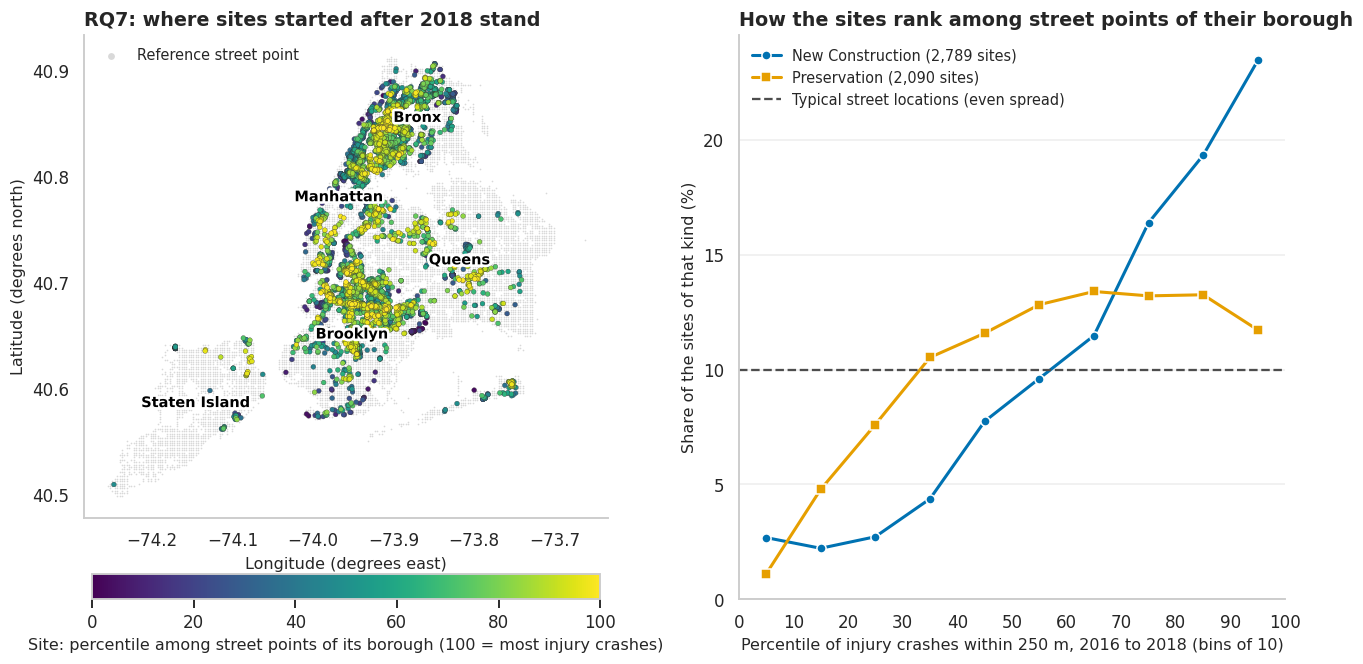

In [154]:
def plot_site_selection(future_sites, reference):
    """RQ7 figure: map of future sites by borough percentile, and the distribution of the percentiles."""
    fig, (ax_map, ax_bars) = plt.subplots(1, 2, figsize=(12.5, 6.2), gridspec_kw={"width_ratios": [1.2, 1]})

    ax_map.scatter(reference["lon"], reference["lat"], s=1.2, color=MAP_REFERENCE_COLOR, linewidths=0,
                   label="Reference street point", rasterized=True)
    # Sites are drawn from the lowest percentile to the highest, so the busy end stays on top.
    drawn = future_sites.sort_values("borough_percentile")
    points = ax_map.scatter(drawn["lon"], drawn["lat"], c=drawn["borough_percentile"], cmap=SEQUENTIAL_CMAP,
                            vmin=0, vmax=PERCENT, s=10, edgecolor=MAP_MARKER_EDGE, linewidths=0.2)
    map_axes(ax_map)     # ground proportions and no grid (Section 2)
    for borough, centre in reference.groupby("borough", observed=True)[["lon", "lat"]].mean().iterrows():
        label = ax_map.text(centre["lon"], centre["lat"], borough, fontsize=9.5, ha="center", color="black",
                            fontweight="bold")
        label.set_path_effects([patheffects.withStroke(linewidth=3.5, foreground="white")])
    colorbar = fig.colorbar(points, ax=ax_map, orientation="horizontal", fraction=0.045, pad=0.1)
    colorbar.set_label("Site: percentile among street points of its borough (100 = most injury crashes)")
    legend = ax_map.legend(loc="upper left", markerscale=3)
    legend.legend_handles[0].set_sizes([20])
    finish(ax_map, f"RQ7: where sites started after {BASELINE_YEARS[1]} stand", "Longitude (degrees east)",
           "Latitude (degrees north)")

    edges = np.arange(0, PERCENT + PERCENTILE_BIN_WIDTH, PERCENTILE_BIN_WIDTH)
    centres = edges[:-1] + PERCENTILE_BIN_WIDTH / 2
    kinds = [(NEW_CONSTRUCTION, PALETTE["housing"], "o"), (PRESERVATION, PALETTE["placebo"], "s")]
    for kind, color, marker in kinds:
        values = future_sites.loc[future_sites["construction_type"].astype(str) == kind, "borough_percentile"]
        shares = PERCENT * np.histogram(values, bins=edges)[0] / len(values)
        ax_bars.plot(centres, shares, color=color, marker=marker, linewidth=2, markersize=6,
                     markeredgecolor="white", label=f"{kind} ({len(values):,} sites)")
    ax_bars.axhline(PERCENTILE_BIN_WIDTH, color=PALETTE["neutral"], linewidth=1.5, linestyle="--",
                    label="Typical street locations (even spread)")
    ax_bars.set_xticks(edges)
    ax_bars.set_xlim(0, PERCENT)
    ax_bars.set_ylim(0, None)
    ax_bars.grid(axis="x", visible=False)
    ax_bars.legend(loc="upper left")
    finish(ax_bars, "How the sites rank among street points of their borough",
           f"Percentile of injury crashes within {BUFFER_M} m, {BASELINE_YEARS[0]} to {BASELINE_YEARS[1]} "
           f"(bins of {PERCENTILE_BIN_WIDTH})", "Share of the sites of that kind (%)")
    plt.tight_layout()
    plt.show()


plot_site_selection(rq7_sites, rq7_reference)

In [155]:
def rq7_text(row_name):
    """Estimate, interval and sample of one row of the RQ7 table as a phrase."""
    row = rq7_estimates.loc[row_name]
    return (f"{row['estimate']:+.1f} percentile points ({CI_LEVEL:.0%} interval {row['low']:+.1f} to "
            f"{row['high']:+.1f} with {int(row['units_resampled']):,} blocks resampled, {row['cluster_low']:+.1f} to "
            f"{row['cluster_high']:+.1f} with {int(row['clusters_resampled']):,} clusters; "
            f"{int(row['n_sites']):,} sites)")


rq7_new = rq7_estimates.loc[RQ7_NEW]
rq7_new_sites = rq7_sites[rq7_sites["construction_type"].astype(str) == NEW_CONSTRUCTION]
rq7_sentence = describe_effect(
    rq7_new["estimate"], rq7_new["low"], rq7_new["high"], "percentile points", int(rq7_new["n_sites"]),
    n_unit=f"new-construction sites in {int(rq7_new['units_resampled']):,} one-kilometre blocks",
    subject=f"The mean borough percentile of new-construction sites, before their project started, minus "
            f"{NEUTRAL_PERCENTILE}",
    above="sites standing where there were already more injury crashes than at the typical street point of the "
          "borough",
    below="sites standing where there were fewer injury crashes than at the typical street point of the borough")
say(rq7_sentence)
say(f"The mean percentile of the new-construction sites is {NEUTRAL_PERCENTILE + rq7_new['estimate']:.1f}, and "
    f"{PERCENT * (rq7_new_sites['borough_percentile'] > NEUTRAL_PERCENTILE).mean():.0f}% of them stand above the "
    f"median street point of their borough. The median new-construction site had "
    f"{rq7_new_sites['baseline_crashes'].median():.0f} injury crashes within {BUFFER_M} m in "
    f"{BASELINE_YEARS[0]} to {BASELINE_YEARS[1]}, against {rq7_reference['baseline_crashes'].median():.0f} at the "
    f"median of the {len(rq7_reference):,} reference points. With clusters resampled instead of blocks the same "
    f"estimate has an interval of {rq7_new['cluster_low']:+.1f} to {rq7_new['cluster_high']:+.1f} "
    f"({int(rq7_new['clusters_resampled']):,} clusters).")
say(f"Preservation sites, which already stood in the baseline years: {rq7_text(RQ7_PRESERVED)}. Both kinds "
    f"pooled: {rq7_text(RQ7_POOLED)}. Ranked inside their own ZIP code, for ZIP codes with at least "
    f"{MIN_GROUP_N} reference points, new-construction sites: {rq7_text(RQ7_WITHIN_ZIP)}; preservation sites: "
    f"{rq7_text(RQ7_PRESERVED_WITHIN_ZIP)}.")
say(f"New construction minus preservation, across the city: {rq7_text(RQ7_GAP)}. Inside boroughs: "
    f"{rq7_text(RQ7_GAP_IN_BOROUGH)}. With every site ranked in its own ZIP code: {rq7_text(RQ7_GAP_WITHIN_ZIP)}.")
store_result("RQ7", "Before the project starts, are new-construction sites on streets with more injury crashes "
             "than typical street locations of the borough?", rq7_new["estimate"], rq7_new["low"],
             rq7_new["high"], rq7_new["n_sites"], rq7_sentence,
             "percentile points above the typical street point of the borough")

The mean borough percentile of new-construction sites, before their project started, minus 50 is +19.90 percentile points (95% interval +16.56 to +22.99, n = 2,789 new-construction sites in 336 one-kilometre blocks). The interval lies above zero, which fits sites standing where there were already more injury crashes than at the typical street point of the borough.

The mean percentile of the new-construction sites is 69.9, and 80% of them stand above the median street point of their borough. The median new-construction site had 62 injury crashes within 250 m in 2016 to 2018, against 27 at the median of the 9,986 reference points. With clusters resampled instead of blocks the same estimate has an interval of +10.2 to +23.0 (350 clusters).

Preservation sites, which already stood in the baseline years: +9.4 percentile points (95% interval +5.4 to +13.8 with 243 blocks resampled, -0.7 to +17.3 with 181 clusters; 2,090 sites). Both kinds pooled: +15.4 percentile points (95% interval +12.5 to +18.3 with 397 blocks resampled, +5.5 to +20.4 with 458 clusters; 4,879 sites). Ranked inside their own ZIP code, for ZIP codes with at least 30 reference points, new-construction sites: +8.4 percentile points (95% interval +5.2 to +11.2 with 304 blocks resampled, +5.0 to +12.0 with 315 clusters; 2,662 sites); preservation sites: +5.0 percentile points (95% interval +1.3 to +8.7 with 211 blocks resampled, +1.3 to +9.6 with 150 clusters; 1,591 sites).

New construction minus preservation, across the city: +10.5 percentile points (95% interval +5.2 to +15.0 with 397 blocks resampled, +3.6 to +16.5 with 458 clusters; 4,879 sites). Inside boroughs: +8.2 percentile points (95% interval +2.6 to +12.8 with 397 blocks resampled, +2.7 to +17.4 with 458 clusters; 4,879 sites). With every site ranked in its own ZIP code: +3.4 percentile points (95% interval -0.9 to +7.9 with 359 blocks resampled, -1.6 to +8.3 with 399 clusters; 4,253 sites).

New-construction sites are not spread like typical street locations. Their line in the right
panel climbs from the quietest tenth of street points to the busiest, and their mean
percentile is well above the neutral value. The interval stays far from zero, also when
clusters are resampled instead of blocks, which widens it on the lower side. On the map the
high percentiles gather in the dense parts of the Bronx and Brooklyn. The borough table, which
pools both kinds of project, shows where the pattern is strong and where it is not: the excess
is large in Brooklyn, the Bronx and Queens, while in Manhattan and on Staten Island the sites
rank close to the typical street point. Part of the pattern is about neighbourhoods and part
is about streets within them: ranked inside their own ZIP code, new-construction sites still
stand above the middle, by a smaller margin.

Most of this is a statement about apartment buildings and dense blocks, for the reason given
with the method. The comparison of like with like is the gap between the two kinds of project.
Preservation sites, which are existing multi-family buildings, rank above the neutral value
too, although with clusters resampled the interval of their excess in the borough ranking
reaches zero. New-construction sites rank higher than preservation sites, across the city and
inside the same borough. The last table shows why the two versions differ: a much larger share
of the preservation sites is in Manhattan, where sites of both kinds rank lower than in the
Bronx and Brooklyn.
With every site ranked inside its own ZIP code the gap is small and its interval includes
zero. The difference between the two kinds is therefore mostly one of neighbourhood. New
buildings go up in parts of a borough with more injury crashes than the parts where the
programme renovates, and inside one ZIP code the streets of the two kinds cannot be told
apart. The two groups may differ in more than the kind of project, so this is an association
as well.

None of this says that these streets are more dangerous for each person who uses them. The
count is not divided by traffic or by the number of people walking, and affordable housing is
built on dense blocks near avenues and transit, where more people and vehicles meet. For the
people who move in, the practical meaning is the same either way: the streets outside the door
already had more injury crashes than most street points of the borough before the project
started.

Requiring a crash within `STREET_SNAP_M` metres leaves out the quietest streets, which raises
the benchmark, while points at the edge of the street network have part of their buffer over
water or parks, which lowers it. The net direction is unknown. Only sites that started after
the baseline years can be used, so the result speaks for the later part of the programme. The
block interval keeps buildings of the same project together but ignores any similarity between
neighbouring blocks, and the cluster interval printed above is the more cautious of the two.

### 8.8 RQ8. Does the hour-of-day mix of injury crashes near sites shift after completion?

Owner: M4

A block of offices and workshops is busy at the rush hours and empty at night, while a block
where several hundred people live has traffic, deliveries and people on foot in the evening
and at weekends. If completions are followed by a move of injury crashes towards the evening
or the night, lighting, crossings and enforcement at those hours matter near the building. We
measure the change in the share of injury crashes in each hour, against the change at
comparison sites, and test it on the four parts of the day defined in Section 4.

The design is the one of RQ6 with the hour of the crash as the category: shares before and
after at clean completed sites, the same at not-yet-completed sites over the same calendar
years, and the gap between the two changes with a cluster bootstrap. The comparison matters
even more here than for RQ6, because the pandemic removed commuting trips and changed the daily
profile of crashes everywhere. Twenty-four hourly shares are too many and too noisy to test
one by one with this sample, so the formal test is made on the four bands, with the p-values
adjusted for four tests, and the hourly values are shown for the pattern. As in RQ6, completed
sites of both kinds are pooled, and the gap is printed again for new construction alone.

The headline is the largest of the four band gaps. A gap that is picked because it is the
largest is biased away from zero, so it is stored with the wider interval that allows for four
tests (the joint interval of `composition_shift`) and is labelled as the largest of four.

In [156]:
def hour_mix_shift(units, pairs, crash_frame):
    """RQ8 statistic: gap in the share of injury crashes per hour and per part of the day.

    Returns (hour_table, band_table, hour_summary, band_summary) in the format of
    `composition_shift`, which is run once on the 24 hours and once on the bands.
    """
    hour_codes = crash_frame["hour"].fillna(-1).to_numpy(dtype=np.int64)   # a missing hour is left out
    before, after = period_category_counts(units, pairs, crash_frame, hour_codes, HOURS_PER_DAY)
    hour_table, hour_summary = composition_shift(units, before, after, list(range(HOURS_PER_DAY)))
    # The bands are sums of whole hours, so the hourly counts are added up instead of recounted.
    band_names = list(HOUR_BANDS)
    band_hours = [np.arange(first, last + 1) for first, last in HOUR_BANDS.values()]
    assert sorted(np.concatenate(band_hours)) == list(range(HOURS_PER_DAY)), "the bands must cover each hour once"
    band_before = np.column_stack([before[:, hours].sum(axis=1) for hours in band_hours])
    band_after = np.column_stack([after[:, hours].sum(axis=1) for hours in band_hours])
    band_table, band_summary = composition_shift(units, band_before, band_after, band_names)
    return hour_table, band_table, hour_summary, band_summary


rq8_hours, rq8_bands, rq8_sample, rq8_band_sample = hour_mix_shift(event_units, site_pairs, crashes)
_, rq8_new_bands, _, rq8_new_sample = hour_mix_shift(event_units[is_new_construction_unit].reset_index(drop=True),
                                                     site_pairs, crashes)
rq8_band_ranges = {name: f"{first:02d}:00 to {last:02d}:59" for name, (first, last) in HOUR_BANDS.items()}
display(rq8_bands.rename(index=lambda name: f"{name} ({rq8_band_ranges[name]})").drop(columns=["flagged"]).round(2))

,treated_before,treated_after,comparison_before,comparison_after,treated_change,comparison_change,gap,low,high,low_joint,high_joint,p_value,p_adjusted
category,,,,,,,,,,,,,
Night (00:00 to 05:59),12.100,12.250,11.410,12.360,0.110,0.900,-0.790,-2.300,0.920,-2.560,1.360,0.380,0.590
Morning (06:00 to 11:59),22.610,21.400,21.970,21.540,-1.200,-0.540,-0.660,-2.730,0.960,-3.070,1.450,0.450,0.590
Afternoon (12:00 to 17:59),34.970,35.820,37.310,36.660,0.880,-0.530,1.410,-0.990,3.640,-2.050,4.230,0.220,0.590
Evening (18:00 to 23:59),30.330,30.530,29.310,29.440,0.210,0.160,0.050,-1.670,1.950,-2.230,2.410,0.930,0.930


The heat map has one column per hour and three rows: the change at completed sites, the change
at comparison sites over the same calendar years, and the gap between them. The colour scale
is centred on zero, with red for a share that rose and blue for one that fell. Colour carries
the values. A number is printed only in the gap row, and only for an hour whose own interval
excludes zero, so that the eye is not drawn to cells that are within noise.

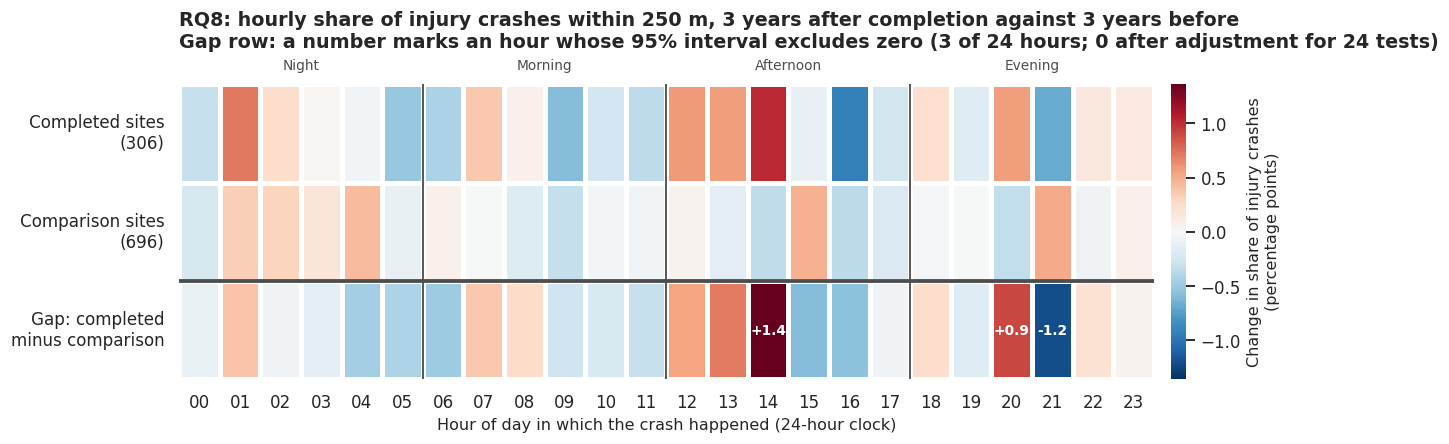

In [157]:
def plot_hour_shift_heatmap(hour_table, summary):
    """RQ8 figure: change in the hourly share of injury crashes at completed and comparison sites, and the gap."""
    rows = {
        f"Completed sites\n({summary['n_treated_sites']:,})": hour_table["treated_change"],
        f"Comparison sites\n({summary['n_comparison_sites']:,})": hour_table["comparison_change"],
        "Gap: completed\nminus comparison": hour_table["gap"],
    }
    values = np.vstack([series.to_numpy() for series in rows.values()])
    limit = float(np.abs(values).max())
    gap_excludes_zero = ((hour_table["low"] > 0) | (hour_table["high"] < 0)).to_numpy()
    annotations = np.full(values.shape, "", dtype=object)
    annotations[-1, gap_excludes_zero] = [f"{gap:+.1f}" for gap in hour_table["gap"].to_numpy()[gap_excludes_zero]]
    fig, ax = plt.subplots(figsize=(12.5, 4.2))
    sns.heatmap(values, ax=ax, cmap=DIVERGING_CMAP, center=0, vmin=-limit, vmax=limit, annot=annotations, fmt="",
                annot_kws={"fontsize": 9, "fontweight": "bold"}, linewidths=2, linecolor="white",
                cbar_kws={"label": "Change in share of injury crashes\n(percentage points)", "pad": 0.015})
    ax.set_xticklabels([f"{hour:02d}" for hour in hour_table.index], rotation=0)
    ax.set_yticklabels(rows.keys(), rotation=0)
    # A heavier line sets the gap row apart, and thin ticks mark where one part of the day ends.
    ax.axhline(2, color=PALETTE["neutral"], linewidth=2.5)
    for name, (first, last) in HOUR_BANDS.items():
        ax.text((first + last + 1) / 2, -0.12, name, ha="center", va="bottom", fontsize=9, color=PALETTE["neutral"])
        if first > 0:
            ax.axvline(first, color=PALETTE["neutral"], linewidth=1.2)
    ax.set_title(f"RQ8: hourly share of injury crashes within {BUFFER_M} m, {EVENT_WINDOW} years after completion "
                 f"against {EVENT_WINDOW} years before\nGap row: a number marks an hour whose {CI_LEVEL:.0%} "
                 f"interval excludes zero ({int(gap_excludes_zero.sum())} of {HOURS_PER_DAY} hours; "
                 f"{int(hour_table['flagged'].sum())} after adjustment for {HOURS_PER_DAY} tests)", pad=24)
    ax.set_xlabel("Hour of day in which the crash happened (24-hour clock)")
    ax.set_ylabel("")
    plt.tight_layout()
    plt.show()


plot_hour_shift_heatmap(rq8_hours, rq8_sample)

In [158]:
rq8_top_band = rq8_bands["gap"].abs().idxmax()
rq8_top = rq8_bands.loc[rq8_top_band]
rq8_sentence = describe_effect(
    rq8_top["gap"], rq8_top["low_joint"], rq8_top["high_joint"], "percentage points", rq8_sample["n_treated_sites"],
    n_unit=f"completed sites, against {rq8_sample['n_comparison_sites']:,} comparison sites, in "
    f"{rq8_sample['n_clusters']:,} clusters", level=rq8_band_sample["joint_level"],
    subject=f"The largest gap among the {len(rq8_bands)} parts of the day, the one for the share of injury "
            f"crashes in the {rq8_top_band.lower()} ({rq8_band_ranges[rq8_top_band]}), with its interval widened "
            f"for {len(rq8_bands)} tests,",
    above=f"relatively more injury crashes in the {rq8_top_band.lower()} around completed buildings",
    below=f"relatively fewer injury crashes in the {rq8_top_band.lower()} around completed buildings")
say(rq8_sentence)
rq8_widest_hour = rq8_hours["gap"].abs().idxmax()
rq8_hours_excluding = int(((rq8_hours["low"] > 0) | (rq8_hours["high"] < 0)).sum())
say(f"Taken alone, the {rq8_top_band.lower()} gap has a {CI_LEVEL:.0%} interval of {rq8_top['low']:+.2f} to "
    f"{rq8_top['high']:+.2f} points. After adjustment for {len(rq8_bands)} parts of the day, "
    f"{int(rq8_bands['flagged'].sum())} of them keep an interval away from zero (adjusted p for the "
    f"{rq8_top_band.lower()}: {rq8_top['p_adjusted']:.2f}). "
    f"The hourly gaps lie between {rq8_hours['gap'].min():+.1f} and {rq8_hours['gap'].max():+.1f} points; the "
    f"widest is at {rq8_widest_hour:02d}:00, with an interval of {rq8_hours.loc[rq8_widest_hour, 'low']:+.1f} to "
    f"{rq8_hours.loc[rq8_widest_hour, 'high']:+.1f}. {rq8_hours_excluding} of the {HOURS_PER_DAY} hourly intervals "
    f"exclude zero before adjustment and {int(rq8_hours['flagged'].sum())} remain after it. The comparison "
    f"sites themselves moved by up to {rq8_hours['comparison_change'].abs().max():.1f} points in a single hour. "
    f"The counts behind the shares are {rq8_sample['treated_crashes']:,} site-level injury crash counts around "
    f"completed sites and {rq8_sample['comparison_crashes']:,} around comparison sites.")
rq8_new = rq8_new_bands.loc[rq8_top_band]
say(f"With the treated group limited to new construction ({rq8_new_sample['n_treated_sites']:,} sites) the "
    f"{rq8_top_band.lower()} gap is {rq8_new['gap']:+.2f} points ({CI_LEVEL:.0%} interval {rq8_new['low']:+.2f} to "
    f"{rq8_new['high']:+.2f}).")
store_result("RQ8", "Does the hour-of-day mix of injury crashes near sites shift after completion?",
             rq8_top["gap"], rq8_top["low_joint"], rq8_top["high_joint"], rq8_sample["n_treated_sites"],
             rq8_sentence, f"percentage points; largest of {len(rq8_bands)} gaps, interval widened for "
                           f"{len(rq8_bands)} tests",
             level=rq8_band_sample["joint_level"], adjusted_p=rq8_top["p_adjusted"])

The largest gap among the 4 parts of the day, the one for the share of injury crashes in the afternoon (12:00 to 17:59), with its interval widened for 4 tests, is +1.41 percentage points (99% interval -2.05 to +4.23, n = 306 completed sites, against 696 comparison sites, in 409 clusters). The interval includes zero.

Taken alone, the afternoon gap has a 95% interval of -0.99 to +3.64 points. After adjustment for 4 parts of the day, 0 of them keep an interval away from zero (adjusted p for the afternoon: 0.59). The hourly gaps lie between -1.2 and +1.4 points; the widest is at 14:00, with an interval of +0.3 to +2.6. 3 of the 24 hourly intervals exclude zero before adjustment and 0 remain after it. The comparison sites themselves moved by up to 0.5 points in a single hour. The counts behind the shares are 26,680 site-level injury crash counts around completed sites and 149,854 around comparison sites.

With the treated group limited to new construction (128 sites) the afternoon gap is +0.40 points (95% interval -2.39 to +3.09).

No shift in the daily profile can be detected around completed sites of either kind. The
largest gap among the four parts of the day is a rise in the afternoon share, and its interval
includes zero, with or without the widening for four tests. The bottom row of the heat map shows why the bands move so little:
positive and negative cells alternate from one hour to the next (early afternoon up, late
afternoon down, one evening hour up and the next down). That is what noise looks like. A move
of crashes towards the evening or the night would show as a run of neighbouring hours with
the same sign. A few single hours have an interval that
excludes zero when taken alone, and they are the ones with a number in the figure. With
twenty-four hours examined, one or two such hours are expected by chance. Two of the hours
marked here are neighbouring evening hours with opposite signs, and none is kept after the
adjustment.

The comparison row is paler than the row for completed sites, because it rests on several
times more crashes, and it shows that the calendar years alone moved the hourly shares very
little.

Few crashes surround the completed sites, so the interval for a six-hour band is a few
percentage points wide and a smaller shift would go unseen, while single hours are far
noisier. Limiting the treated group to new construction gives a smaller afternoon gap with a
somewhat wider interval. The hour is the one the officer wrote down. Weekdays and weekends
are pooled, so a change that goes in opposite directions on the two would cancel.

### 8.9 RQ9. Across ZIP codes, is the share of deeply affordable units associated with the severity of injury crashes or with the pedestrian and cyclist share of harm?

Owner: M5

Affordable units are counted in income bands, and the two lowest (extremely low and very low
income) go to the tenants with the lowest incomes. If the neighbourhoods where the programme
concentrates those units are also the ones where crashes hit people outside vehicles, or kill
more often, the burden of unsafe streets falls on tenants with the fewest alternatives. We
estimate the correlation across ZIP codes, with an interval, between the deep-affordable share
of the units and each of two crash outcomes.

The unit is the ZIP code, taken from the panel of Section 6. The housing variable is the share
of deeply affordable units among all affordable units completed up to the last study year.
ZIP codes with fewer than `MIN_ZIP_AFFORDABLE_UNITS` such units are left out, because their
share depends on one or two small buildings. The two crash outcomes are computed over all ten
years: the share of injury crashes that hurt a pedestrian or cyclist, and deaths per
`PER_THOUSAND` injury crashes (the constant of Section 6) as a measure of severity. Both are ratios within injury
crashes, so the collapse of property-damage reports in the break year does not enter them.

Boroughs differ in everything at once: Manhattan has few drivers and many pedestrians, Staten
Island the reverse. A raw correlation across the city would mostly compare boroughs. The
borough means are therefore removed from both variables before ranking, so the coefficient
measures whether, inside a borough, ZIP codes with a deeper mix differ from their neighbours.
Spearman's rank correlation is used because neither relationship has to be a straight line and
a few ZIP codes have extreme values. Two outcomes are tested, so the two p-values are adjusted
together.

In [159]:
def zip_equity_table(panel, min_units=MIN_ZIP_AFFORDABLE_UNITS):
    """One row per ZIP code: deep-affordable share of the stock and the two crash outcomes.

    Shares are in percent and deaths are per PER_THOUSAND injury crashes. Only ZIP codes with at
    least `min_units` affordable units completed by the last study year are returned.
    """
    stock = panel[panel["year"] == YEAR_END].set_index("zip")
    totals = panel.groupby("zip")[["injury_crashes", "ped_cyc_crashes", "persons_killed"]].sum()
    table = pd.DataFrame({
        "borough": stock["borough"].astype(str),
        "affordable_units": stock["cum_affordable_units"],
        "deep_share_pct": PERCENT * stock["cum_deep_affordable_units"] / stock["cum_affordable_units"].where(
            stock["cum_affordable_units"] > 0),
        "injury_crashes": totals["injury_crashes"],
        "ped_cyc_share_pct": PERCENT * totals["ped_cyc_crashes"] / totals["injury_crashes"],
        "deaths_per_1000": PER_THOUSAND * totals["persons_killed"] / totals["injury_crashes"],
    })
    assert (table["injury_crashes"] > 0).all()
    return table[table["affordable_units"] >= min_units]


# Outcome column -> (panel title, unit of a difference in that outcome).
RQ9_OUTCOMES = {
    "ped_cyc_share_pct": ("Who is hurt: pedestrian and cyclist share of injury crashes", "percentage points"),
    "deaths_per_1000": (f"How severe: deaths per {PER_THOUSAND:,} injury crashes", "deaths"),
}


def deep_share_associations(zip_table):
    """RQ9 statistic: borough-adjusted Spearman correlation of the deep share with each outcome."""
    rows = {}
    for column in RQ9_OUTCOMES:
        adjusted = group_adjusted_spearman_ci(zip_table["deep_share_pct"].to_numpy(), zip_table[column].to_numpy(),
                                              zip_table["borough"].to_numpy())
        raw = spearman_ci(zip_table["deep_share_pct"].to_numpy(), zip_table[column].to_numpy())
        rows[column] = {"rho_within_borough": adjusted["estimate"], "low": adjusted["low"],
                        "high": adjusted["high"], "p_value": adjusted["p_value"], "n": adjusted["n"],
                        "n_boroughs": adjusted["n_groups"], "rho_unadjusted": raw["estimate"],
                        "unadjusted_low": raw["low"], "unadjusted_high": raw["high"]}
    result = pd.DataFrame(rows).T
    result["p_adjusted"] = benjamini_hochberg(result["p_value"].to_numpy(dtype=float))
    return result


rq9_zips = zip_equity_table(zip_year)
rq9_result = deep_share_associations(rq9_zips)
display(rq9_result.astype(float).round(3))

,rho_within_borough,low,high,p_value,n,n_boroughs,rho_unadjusted,unadjusted_low,unadjusted_high,p_adjusted
ped_cyc_share_pct,-0.215,-0.392,-0.000,0.052,123.000,5.000,-0.158,-0.345,0.047,0.104
deaths_per_1000,0.095,-0.110,0.271,0.412,123.000,5.000,0.108,-0.081,0.283,0.412


The figure shows what the coefficient ranks. Each point is a ZIP code, and both axes are
differences from the mean of the ZIP code's own borough, so the offsets between boroughs are
gone and a point to the right is a ZIP code with a deeper mix than its borough average. The
dashed line is a least-squares line through the points and only guides the eye, since the
test uses ranks. Colour and marker shape both give the borough.

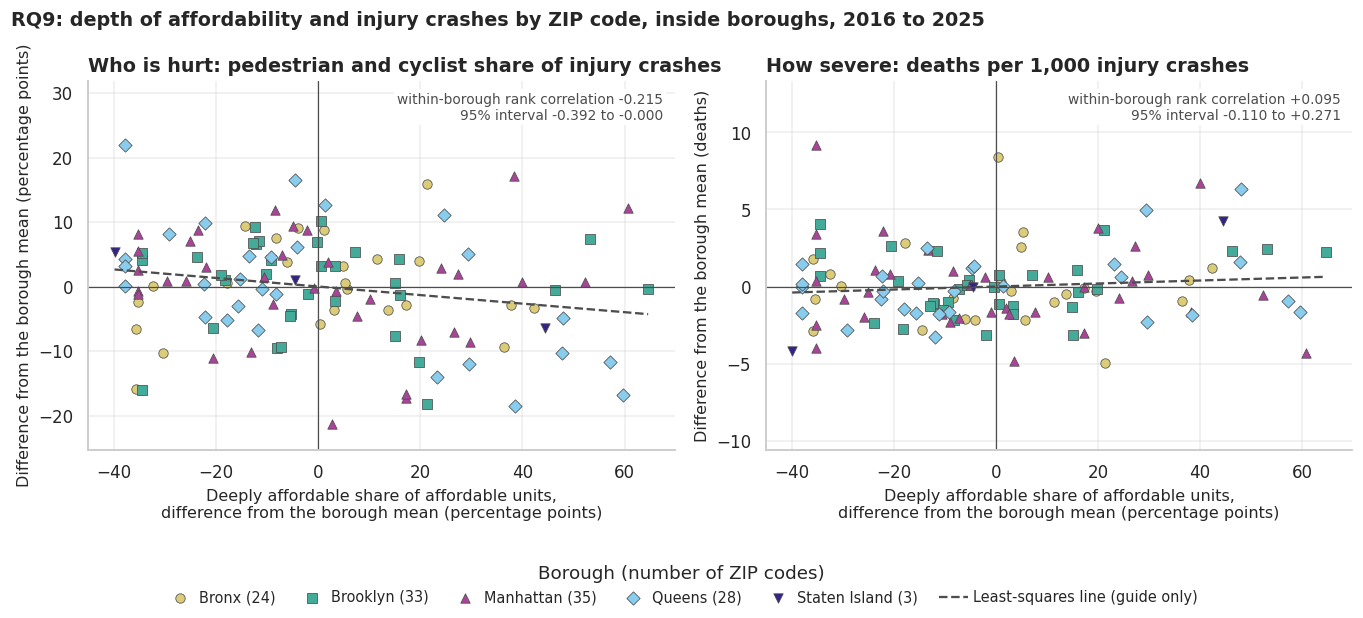

In [160]:
def plot_deep_share_scatter(zip_table, result):
    """RQ9 figure: deep-affordable share against each crash outcome, both as differences from the borough mean."""
    borough_size = zip_table.groupby("borough")["borough"].transform("size")
    shown = zip_table[borough_size >= 2]     # a borough with one ZIP code has no within-borough variation
    by_borough = shown.groupby("borough")
    deep_within = shown["deep_share_pct"] - by_borough["deep_share_pct"].transform("mean")
    fig, axes = plt.subplots(1, 2, figsize=(12.5, 5.6))
    for ax, (column, (title, unit)) in zip(axes, RQ9_OUTCOMES.items()):
        outcome_within = shown[column] - by_borough[column].transform("mean")
        row = result.loc[column]
        # The plotted values are the ones the coefficient is computed from.
        assert np.isclose(spearman_rho(deep_within.to_numpy(), outcome_within.to_numpy()), row["rho_within_borough"])
        ax.axhline(0, color=PALETTE["neutral"], linewidth=0.8)
        ax.axvline(0, color=PALETTE["neutral"], linewidth=0.8)
        for borough in BOROUGHS:
            in_borough = (shown["borough"] == borough).to_numpy()
            if not in_borough.any():
                continue
            ax.scatter(deep_within[in_borough], outcome_within[in_borough], s=38, color=BOROUGH_COLORS[borough],
                       marker=BOROUGH_MARKERS[borough], edgecolor=PALETTE["neutral"], linewidth=0.5,
                       label=f"{borough} ({int(in_borough.sum())})")
        slope = linear_slope(deep_within.to_numpy(), outcome_within.to_numpy())
        ends = np.array([deep_within.min(), deep_within.max()])
        ax.plot(ends, slope * ends, color=PALETTE["neutral"], linewidth=1.5, linestyle="--",
                label="Least-squares line (guide only)")
        ax.text(0.98, 0.97, f"within-borough rank correlation {row['rho_within_borough']:+.3f}\n"
                            f"{CI_LEVEL:.0%} interval {row['low']:+.3f} to {row['high']:+.3f}",
                transform=ax.transAxes, ha="right", va="top", fontsize=9, color=PALETTE["neutral"],
                bbox={"facecolor": "white", "edgecolor": "none", "pad": 2})
        reach = float(outcome_within.abs().max())
        ax.set_ylim(-1.15 * reach, 1.45 * reach)     # headroom for the text box
        finish(ax, title, "Deeply affordable share of affordable units,\ndifference from the borough mean "
                          "(percentage points)", f"Difference from the borough mean ({unit})")
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, title="Borough (number of ZIP codes)", loc="lower center", ncol=len(handles),
               columnspacing=1.5, handletextpad=0.3)
    fig.suptitle(f"RQ9: depth of affordability and injury crashes by ZIP code, inside boroughs, {YEAR_START} to "
                 f"{YEAR_END}", x=0.01, ha="left", fontsize=12.5, fontweight="bold")
    # Leave a strip at the bottom of the figure for the shared legend.
    plt.tight_layout(rect=(0, 0.12, 1, 1))
    plt.show()


plot_deep_share_scatter(rq9_zips, rq9_result)

In [161]:
rq9_ped = rq9_result.loc["ped_cyc_share_pct"]
rq9_deaths = rq9_result.loc["deaths_per_1000"]
# The sentence is written out here and not by describe_effect, because the interval ends so close
# to zero that the adjusted p-value has to be read with it.
rq9_excludes_zero = bool(rq9_ped["low"] > 0 or rq9_ped["high"] < 0)
rq9_kept = bool(rq9_ped["p_adjusted"] < FALSE_DISCOVERY_RATE)
rq9_sentence = (
    f"The within-borough rank correlation between the deep-affordable share and the pedestrian and cyclist "
    f"share of injury crashes is {rq9_ped['rho_within_borough']:+.3f} ({CI_LEVEL:.0%} interval "
    f"{rq9_ped['low']:+.3f} to {rq9_ped['high']:+.3f}, n = {int(rq9_ped['n'])} ZIP codes in "
    f"{int(rq9_ped['n_boroughs'])} boroughs). The interval {'excludes' if rq9_excludes_zero else 'includes'} zero"
    f"{f' by {min(abs(rq9_ped['low']), abs(rq9_ped['high'])):.3f}' if rq9_excludes_zero else ''}, the p-value is "
    f"{rq9_ped['p_value']:.3f} and {rq9_ped['p_adjusted']:.3f} after adjustment for the two outcomes, so this is "
    f"{'counted' if rq9_kept else 'not counted'} as a difference from zero.")
say(rq9_sentence)
say(describe_effect(
    rq9_deaths["rho_within_borough"], rq9_deaths["low"], rq9_deaths["high"], "", int(rq9_deaths["n"]),
    n_unit="ZIP codes", digits=3,
    subject=f"For deaths per {PER_THOUSAND:,} injury crashes the within-borough rank correlation",
    above="more deaths per injury crash where the affordable stock is deeper",
    below="fewer deaths per injury crash where the affordable stock is deeper"))
say(f"Adjusted for two outcomes, the p-values are {rq9_ped['p_adjusted']:.3f} (pedestrian and cyclist share) and "
    f"{rq9_deaths['p_adjusted']:.3f} (deaths). Without the borough adjustment the correlations would be "
    f"{rq9_ped['rho_unadjusted']:+.2f} ({rq9_ped['unadjusted_low']:+.2f} to {rq9_ped['unadjusted_high']:+.2f}) and "
    f"{rq9_deaths['rho_unadjusted']:+.2f} ({rq9_deaths['unadjusted_low']:+.2f} to "
    f"{rq9_deaths['unadjusted_high']:+.2f}). The {len(rq9_zips)} ZIP codes are those with at least "
    f"{MIN_ZIP_AFFORDABLE_UNITS} affordable units out of {zip_year['zip'].nunique()} in the panel; the median "
    f"ZIP has a deep share of {rq9_zips['deep_share_pct'].median():.0f}%, a pedestrian and cyclist share of "
    f"{rq9_zips['ped_cyc_share_pct'].median():.0f}% and {rq9_zips['deaths_per_1000'].median():.1f} deaths per "
    f"{PER_THOUSAND:,} injury crashes.")
store_result("RQ9", "Across ZIP codes, is the deep-affordable share associated with the pedestrian and cyclist "
             "share of harm?", rq9_ped["rho_within_borough"], rq9_ped["low"], rq9_ped["high"], rq9_ped["n"],
             rq9_sentence, "rank correlation within borough", adjusted_p=rq9_ped["p_adjusted"])

The within-borough rank correlation between the deep-affordable share and the pedestrian and cyclist share of injury crashes is -0.215 (95% interval -0.392 to -0.000, n = 123 ZIP codes in 5 boroughs). The interval excludes zero by 0.000, the p-value is 0.052 and 0.104 after adjustment for the two outcomes, so this is not counted as a difference from zero.

For deaths per 1,000 injury crashes the within-borough rank correlation is +0.095 (95% interval -0.110 to +0.271, n = 123 ZIP codes). The interval includes zero.

Adjusted for two outcomes, the p-values are 0.104 (pedestrian and cyclist share) and 0.412 (deaths). Without the borough adjustment the correlations would be -0.16 (-0.35 to +0.05) and +0.11 (-0.08 to +0.28). The 123 ZIP codes are those with at least 50 affordable units out of 171 in the panel; the median ZIP has a deep share of 33%, a pedestrian and cyclist share of 38% and 6.1 deaths per 1,000 injury crashes.

The estimate points against the concern that motivated the question: inside a borough, ZIP
codes whose affordable stock is deeper tend to have a slightly lower pedestrian and cyclist
share of injury crashes, where the concern would predict a higher one. It is not counted as a
difference. The upper end of
its interval lies a hair from zero, the p-value is just above the threshold, and after the two
outcomes are adjusted for together it is clearly above it. In the left panel the dashed line
slopes down gently through a wide cloud. One possible reading is geographic, but these data
cannot test it: the notebook has no variable for distance from the centre or for how people
travel. For deaths per injury crash there is no association in either direction, with or
without the borough adjustment.

These are area data. The housing variable describes the units this programme financed, not
the people who live in the ZIP code, and nothing here says who was in the crashes.
Neighbouring ZIP codes resemble each other, which the interval does not account for, so it is
probably too narrow. Deaths are few in most ZIP codes, which makes the severity measure noisy
and an absent correlation unsurprising. Staten Island contributes only a handful of ZIP codes
after the minimum-units rule.

### 8.10 RQ10. Which contributing-factor groups are over- or under-represented near completed housing, after against before?

Owner: M5

Every crash report names what the officer judged to be the main contributing factor:
distraction, failure to yield, speed and so on. The mix of factors says what kind of street
problem a place has, and each kind has a different remedy (signal timing for failure to yield,
street design for speed). If the mix shifts around buildings once people live in them, that
tells the transport department what to look for on those blocks. For each group of factors
from Section 4 we report the change in its share of injury crashes relative to comparison
sites, and keep the groups that survive a correction for testing several at once.

This is again the design of RQ6, with the factor group as the category. Two choices are
specific to it. Crashes whose factor is unrecorded are left out of the shares, because that
group is large, says nothing about the street, and its size depends on reporting habits; its
own shift is reported separately as a check and drawn as a separate row of the figure. And
several groups are tested side by side, so the p-values are adjusted with the
Benjamini-Hochberg procedure of Section 7. Without the adjustment, one group in twenty would
look unusual by chance alone. Comparing crashes near housing with crashes elsewhere in the
city would be simpler, but it would compare dense neighbourhoods with highways, which have a
different mix of factors for reasons unrelated to housing.

As in RQ8, the headline is the largest gap among the groups, stored with the interval widened
for the number of groups. Completed sites of both kinds are pooled again. The largest gap and
the check on unrecorded factors are therefore repeated with the treated group limited to one
kind of project at a time. Preservation brings no new residents (RQ5), so a shift that appears
around preservation sites only is not a sign of what new housing does.

In [162]:
def unrecorded_share_shift(units, pairs, crash_frame):
    """Gap in the share of injury crashes with no factor recorded, among all injury crashes.

    Returns (row, before): the UNRECORDED_FACTOR row in the format of `composition_shift`, with
    `n_treated_sites` added, and the (units, 2) counts before completion in the order of
    UNRECORDED_LABELS.
    """
    is_unrecorded = (crash_frame["factor_group"] == UNRECORDED_FACTOR).to_numpy()
    before, after = period_category_counts(units, pairs, crash_frame, np.where(is_unrecorded, 0, 1),
                                           len(UNRECORDED_LABELS))
    table, summary = composition_shift(units, before, after, UNRECORDED_LABELS)
    row = table.loc[UNRECORDED_FACTOR].copy()
    row["n_treated_sites"] = summary["n_treated_sites"]
    return row, before


def factor_mix_shift(units, pairs, crash_frame):
    """RQ10 statistic: gap in the share of each recorded factor group, and in the unrecorded share.

    Returns (factor_table, unrecorded_row, summary). The factor table follows `composition_shift`,
    with shares taken among injury crashes that have a recorded factor.
    """
    factor_names = [name for name in crash_frame["factor_group"].cat.categories if name != UNRECORDED_FACTOR]
    recorded_codes = pd.Categorical(crash_frame["factor_group"], categories=factor_names).codes.astype(np.int64)
    before, after = period_category_counts(units, pairs, crash_frame, recorded_codes, len(factor_names))
    factor_table, summary = composition_shift(units, before, after, factor_names)

    unrecorded_row, unrecorded_before = unrecorded_share_shift(units, pairs, crash_frame)
    assert (unrecorded_before[:, 1] == before.sum(axis=1)).all(), "recorded crashes must add up to the factor table"
    return factor_table.sort_values("gap", ascending=False), unrecorded_row, summary


rq10_factors, rq10_unrecorded, rq10_sample = factor_mix_shift(event_units, site_pairs, crashes)
rq10_new_factors, rq10_new_unrecorded, rq10_new_sample = factor_mix_shift(
    event_units[is_new_construction_unit].reset_index(drop=True), site_pairs, crashes)
rq10_preserved_unrecorded, _ = unrecorded_share_shift(
    event_units[is_preservation_unit].reset_index(drop=True), site_pairs, crashes)
display(rq10_factors.round(2))

,treated_before,treated_after,comparison_before,comparison_after,treated_change,comparison_change,gap,low,high,low_joint,high_joint,p_value,p_adjusted,flagged
category,,,,,,,,,,,,,,
Improper manoeuvre,13.330,13.950,14.700,14.520,0.560,-0.250,0.810,-0.930,2.510,-1.800,3.270,0.350,0.930,False
Failure to yield or obey,21.080,22.220,21.250,21.880,1.090,0.700,0.390,-1.530,2.540,-2.570,3.370,0.630,0.930,False
Vehicle defect,1.000,1.100,1.200,0.960,0.110,-0.210,0.320,-0.220,0.890,-0.460,1.110,0.260,0.930,False
Other,4.980,5.210,4.340,4.320,0.260,0.020,0.250,-0.960,1.980,-1.700,2.620,0.710,0.930,False
Road or environment,3.640,3.300,3.630,3.090,-0.330,-0.460,0.130,-0.870,1.190,-1.140,1.560,0.880,0.930,False
Pedestrian or cyclist error,2.720,2.710,3.130,3.140,-0.020,-0.050,0.030,-0.680,0.770,-1.070,1.010,0.930,0.930,False
Speed or aggressive driving,14.160,12.900,13.790,13.290,-1.220,-0.780,-0.440,-3.170,2.730,-3.850,3.710,0.810,0.930,False
Distraction,33.590,34.460,34.220,35.380,0.870,1.530,-0.650,-4.710,2.130,-5.980,3.310,0.680,0.930,False
Impairment or medical,5.510,4.150,3.740,3.410,-1.320,-0.490,-0.830,-1.930,0.160,-2.760,0.670,0.100,0.930,False


Each row of the figure is one factor group, ordered from the largest relative rise to the
largest relative fall. The label on the right gives the group's share of injury crashes around
completed sites before completion, so that a shift can be judged against the size of the group.
The last row, below the line, is the check on crashes with no factor recorded. Its share is
taken among all injury crashes and it is not one of the tested groups.

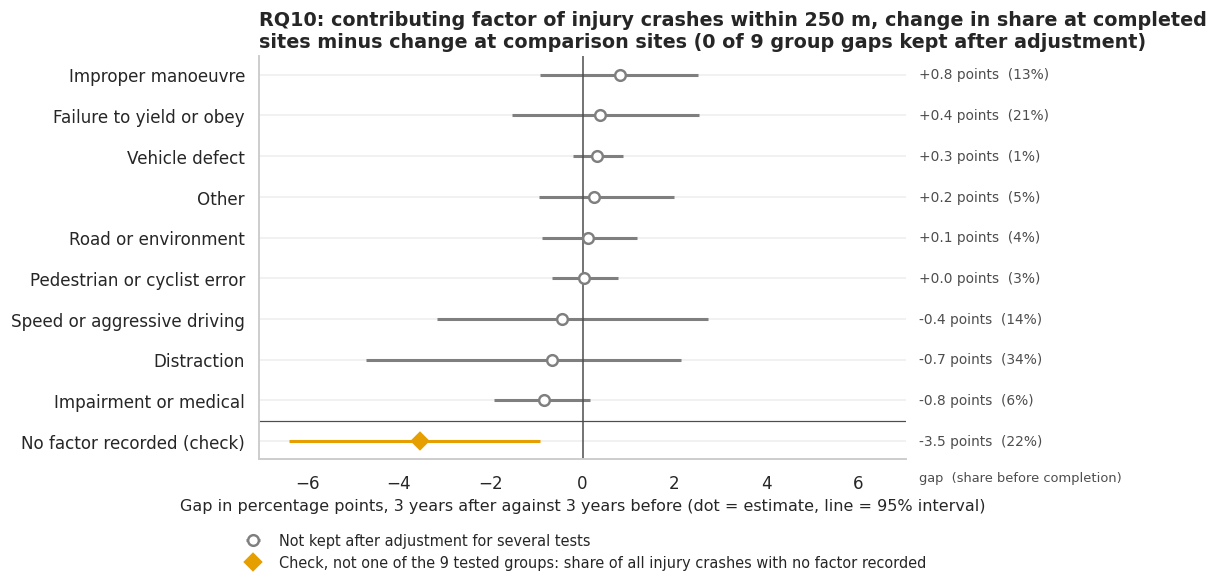

In [163]:
def plot_factor_gaps(factor_table, unrecorded_row):
    """RQ10 figure: gap in the share of each contributing-factor group, and the unrecorded share as a check."""
    plotted = ["gap", "low", "high", "treated_before"]
    table = pd.concat([factor_table[plotted], unrecorded_row[plotted].to_frame(UNRECORDED_ROW).T]).astype(float)
    table["flagged"] = [*factor_table["flagged"], False]
    is_check = table.index == UNRECORDED_ROW
    fig, ax = plt.subplots(figsize=(10.5, 5.6))
    value_labels = [f"{row.gap:+.1f} points  ({row.treated_before:.0f}%)" for row in table.itertuples()]
    draw_gap_rows(ax, table, value_labels, "gap  (share before completion)", is_check=is_check,
                  check_label=f"Check, not one of the {len(factor_table)} tested groups: share of all injury "
                              f"crashes with no factor recorded")
    ax.axhline(len(factor_table) - 0.5, color=PALETTE["neutral"], linewidth=0.8)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=1)
    finish(ax, f"RQ10: contributing factor of injury crashes within {BUFFER_M} m, change in share at completed\n"
               f"sites minus change at comparison sites ({int(factor_table['flagged'].sum())} of "
               f"{len(factor_table)} group gaps kept after adjustment)",
           f"Gap in percentage points, {EVENT_WINDOW} years after against {EVENT_WINDOW} years before "
           f"(dot = estimate, line = {CI_LEVEL:.0%} interval)", "")
    plt.tight_layout()
    plt.show()


plot_factor_gaps(rq10_factors, rq10_unrecorded)

In [164]:
rq10_top_name = rq10_factors["gap"].abs().idxmax()
rq10_top = rq10_factors.loc[rq10_top_name]
rq10_sentence = describe_effect(
    rq10_top["gap"], rq10_top["low_joint"], rq10_top["high_joint"], "percentage points",
    rq10_sample["n_treated_sites"],
    n_unit=f"completed sites, against {rq10_sample['n_comparison_sites']:,} comparison sites, in "
    f"{rq10_sample['n_clusters']:,} clusters", level=rq10_sample["joint_level"],
    subject=f"The largest gap among the {len(rq10_factors)} factor groups, the one for the share of "
            f"\"{rq10_top_name}\" among injury crashes with a recorded factor, with its interval widened for "
            f"{len(rq10_factors)} tests,",
    above=f"a growing share of \"{rq10_top_name}\" around completed buildings",
    below=f"a shrinking share of \"{rq10_top_name}\" around completed buildings")
say(rq10_sentence)
rq10_flagged = rq10_factors.index[rq10_factors["flagged"]].tolist()
rq10_unadjusted = rq10_factors.index[rq10_factors["p_value"] < FALSE_DISCOVERY_RATE].tolist()
say(f"Taken alone, that gap has a {CI_LEVEL:.0%} interval of {rq10_top['low']:+.2f} to {rq10_top['high']:+.2f} "
    f"points. Before adjustment, {len(rq10_unadjusted)} of the {len(rq10_factors)} groups have p below "
    f"{FALSE_DISCOVERY_RATE} ({', '.join(rq10_unadjusted) if rq10_unadjusted else 'none'}). After the "
    f"Benjamini-Hochberg adjustment {len(rq10_flagged)} remain "
    f"({', '.join(rq10_flagged) if rq10_flagged else 'none'}); the adjusted p of \"{rq10_top_name}\" is "
    f"{rq10_top['p_adjusted']:.2f}. The shares rest on {rq10_sample['treated_crashes']:,} site-level injury "
    f"crash counts with a recorded factor around completed sites and {rq10_sample['comparison_crashes']:,} around "
    f"comparison sites.")
say(f"The unrecorded share went from {rq10_unrecorded['treated_before']:.1f}% to "
    f"{rq10_unrecorded['treated_after']:.1f}% around completed sites and from "
    f"{rq10_unrecorded['comparison_before']:.1f}% to {rq10_unrecorded['comparison_after']:.1f}% around comparison "
    f"sites, a gap of {rq10_unrecorded['gap']:+.1f} points (interval {rq10_unrecorded['low']:+.1f} to "
    f"{rq10_unrecorded['high']:+.1f}).")
rq10_new = rq10_new_factors.loc[rq10_top_name]
say(f"With the treated group limited to new construction ({rq10_new_sample['n_treated_sites']:,} sites) the gap "
    f"for \"{rq10_top_name}\" is {rq10_new['gap']:+.2f} points ({CI_LEVEL:.0%} interval {rq10_new['low']:+.2f} "
    f"to {rq10_new['high']:+.2f}).")
say("The gap in the unrecorded share by kind of project, each against the same comparison sites: "
    + "; ".join(f"{label} {row['gap']:+.1f} points (interval {row['low']:+.1f} to {row['high']:+.1f}, "
                f"{int(row['n_treated_sites']):,} sites, share {row['treated_before']:.1f}% before and "
                f"{row['treated_after']:.1f}% after)"
                for label, row in (("new construction", rq10_new_unrecorded),
                                   ("preservation", rq10_preserved_unrecorded))) + ".")
store_result("RQ10", "Which contributing-factor groups are over- or under-represented near completed housing, "
             "after against before?", rq10_top["gap"], rq10_top["low_joint"], rq10_top["high_joint"],
             rq10_sample["n_treated_sites"], rq10_sentence,
             f"percentage points; largest of {len(rq10_factors)} gaps, interval widened for "
             f"{len(rq10_factors)} tests",
             level=rq10_sample["joint_level"], adjusted_p=rq10_top["p_adjusted"])

The largest gap among the 9 factor groups, the one for the share of "Impairment or medical" among injury crashes with a recorded factor, with its interval widened for 9 tests, is -0.83 percentage points (99% interval -2.76 to +0.67, n = 306 completed sites, against 696 comparison sites, in 409 clusters). The interval includes zero.

Taken alone, that gap has a 95% interval of -1.93 to +0.16 points. Before adjustment, 0 of the 9 groups have p below 0.05 (none). After the Benjamini-Hochberg adjustment 0 remain (none); the adjusted p of "Impairment or medical" is 0.93. The shares rest on 21,140 site-level injury crash counts with a recorded factor around completed sites and 117,197 around comparison sites.

The unrecorded share went from 22.4% to 18.9% around completed sites and from 21.9% to 21.7% around comparison sites, a gap of -3.5 points (interval -6.4 to -0.9).

With the treated group limited to new construction (128 sites) the gap for "Impairment or medical" is -0.09 points (95% interval -1.27 to +0.86).

The gap in the unrecorded share by kind of project, each against the same comparison sites: new construction -0.8 points (interval -3.4 to +1.6, 128 sites, share 22.3% before and 22.0% after); preservation -5.7 points (interval -9.5 to -2.2, 178 sites, share 22.4% before and 16.4% after).

No factor group is over- or under-represented around completed sites of either kind in a way
these data can separate from chance. The interval of every tested group crosses zero, and no group reaches
the threshold even before the adjustment for testing several of them. The two ends of the
figure, a rise in improper manoeuvres and a fall in impairment or medical causes, are both
small next to their intervals, and with the treated group limited to new construction the
largest gap moves close to zero. The widest intervals belong to the largest groups,
distraction and speed, where a shift of a few points in either direction cannot be excluded.

The check on unrecorded factors, the last row of the figure, does show a difference. The share
of injury crashes with no factor named fell around completed sites and hardly moved around
comparison sites, and the interval of that gap excludes zero. Split by kind of project, the
gap belongs to preservation. Around preservation sites it is large and its interval excludes
zero, and around new construction it is small with an interval that includes zero.
Preservation is the placebo of RQ5: nobody new moves in, so this gap is not a sign of anything
that new residents bring. It concerns how completely reports were filled in around the
preservation sites of these cohorts, and we do not know what produces it. It is one test
outside the adjusted set, so it is reported and not counted as a finding. It still matters for
the pooled result, because the shares above are taken among crashes with a recorded factor: if
the newly recorded crashes are of a particular kind, they can hide or imitate a shift in the
mix. With the treated group limited to new construction, where the unrecorded share moves
much as it does at comparison sites, the largest gap is close to zero.

The factor is the judgement of the reporting officer about the first vehicle only, the nine
groups come from the keyword rules of Section 4, and the smallest groups (vehicle defects,
pedestrian or cyclist error) hold only a few percent of crashes, so their shares rest on small
counts.

## 9. Robustness checks

The before and after comparison around new-construction sites rests on several choices made in
Sections 1 and 5: the 250 m buffer, the three-year window, the injury crash as the outcome, the
screen that removes sites with another completion nearby, and the way the 2020 reporting break
is handled. None of these values is given by the data. This section re-estimates the same
comparison with each choice changed, one at a time, and puts every estimate with its interval
in one table and one chart. A conclusion is only kept at the end if it does not depend on a
choice that could reasonably have been made differently.

The section uses only the tables of Sections 5 and 6 and the functions of Section 7, so the
central estimate is rebuilt here from the event table before anything is varied.

### 9.1 Constants and the central comparison

The central comparison is defined as follows. The treated sites are new-construction sites of
the completion cohorts whose full window lies inside the study years. The comparison sites are
located sites of any construction type that are still not completed at the end of the cohort's
window. Each group passes its own screen from Section 5.4: a treated site has no neighbour
completed in a different year of its window, and a comparison site has no completed neighbour
at all. For every site the injury crashes within
the buffer are summed over the `EVENT_WINDOW` years before the completion year and the
`EVENT_WINDOW` years after it; the completion year itself is left out because the building is
finished part of the way through it. The estimate is the mean log ratio of after to before at
treated sites minus the same mean at comparison sites, taken inside each cohort so that both
groups cover the same calendar years, and weighted by the number of treated sites per cohort.
Clusters of sites are resampled for the interval.

In [165]:
def assert_state(*names):
    """Stop with a clear message when an object that an earlier section should have left is missing."""
    missing = [name for name in names if name not in globals()]
    assert not missing, f"objects of earlier sections are missing: {', '.join(missing)}"


# Tables and results of Sections 5, 6 and 8 that this section reads.
assert_state("sites", "site_year", "site_pairs", "event_panel", "crashes", "zip_year", "crash_tree",
             "crash_tree_rows", "event_units", "rq6_before", "rq6_after", "rq6_table", "rq8_bands", "rq8_top_band",
             "rq10_factors", "rq10_top_name", "rq10_unrecorded", "rq1", "stock_slope", "timing_slopes",
             "rq9_result")
# Functions of Sections 5, 7 and 8 that it calls.
assert_state("build_site_year", "build_event_panel", "site_crash_pairs", "site_neighbour_pairs",
             "connected_clusters", "aggregate_crashes_to_zip_year", "did_log_ratio", "stratified_difference",
             "log_ratio", "log_points_to_percent", "cohort_unit_table", "period_category_counts",
             "composition_shift", "hour_mix_shift", "factor_mix_shift", "stock_regression", "zip_equity_table",
             "deep_share_associations", "build_forecast_frame", "forecast_comparison")

# --- Constants used only in this section -------------------------------------------------------
# Alternative buffer radii in metres, one clearly smaller and one clearly larger than BUFFER_M.
# Both are among the radii profiled in Section 5.3.
ALTERNATIVE_RADII_M = [150, 400]
NEAR_RADIUS_M = min(ALTERNATIVE_RADII_M)   # the smaller radius, also used for the share questions (RQ6, RQ8, RQ10)
SHORT_WINDOW = 2                 # years; the alternative to EVENT_WINDOW on each side of completion
PLACEBO_SHIFT = EVENT_WINDOW     # years by which the placebo moves the completion date earlier
CENTRAL_TYPE = NEW_CONSTRUCTION
CENTRAL_OUTCOME = "injury_crashes"
ALTERNATIVE_OUTCOME = "crashes"
CLUSTER_UNIT = "cluster_id"      # resampling unit of the central estimate
BLOCK_UNIT = "block_id"          # one-kilometre squares, the alternative resampling unit

# One row per (site, cohort) carries these columns from the event table, next to its keys.
COHORT_UNIT_COLUMNS = ["cluster_id", "block_id", "contaminated", "near_completion_in_window",
                       "near_earlier_completion", "construction_type", "borough"]
COHORT_STRATA = ("cohort",)                 # the central comparison is made inside completion cohorts
COHORT_BOROUGH_STRATA = ("cohort", "borough")   # 9.9: inside cohorts and boroughs

# Forest plot: intervals reaching beyond this many percent on either side are cut at the edge of
# the axis and marked with an arrow, so one very wide interval does not flatten all the others.
# The full interval is always printed next to the row and in the table.
FOREST_AXIS_LIMIT = 30
FOREST_PLOT_SHARE = 0.56         # share of the axes width used by the plot; the rest holds the text columns
LARGEST_CLUSTERS_SHOWN = 3       # clusters whose joint weight is reported when the screen is switched off

# Kinds of row in the table of checks, and the names of the checks that other cells look up.
KIND_CENTRAL, KIND_CHECK, KIND_PLACEBO = "central", "check", "placebo"
CHECK_OUTCOME = "Outcome"                  # the row that counts all crashes (9.4); Section 10 reads it
CHECK_SCREEN = "Nearby completions"        # the rows that change the screen of Section 5.4 (9.5)

# Marker colour of each kind of row in the forest plot.
ROW_KINDS = {KIND_CENTRAL: ("Central estimate", PALETTE["treated"]),
             KIND_CHECK: ("One choice changed", PALETTE["neutral"]),
             KIND_PLACEBO: ("Placebo (no completion in the window)", PALETTE["placebo"])}

assert all(radius in RADIUS_CANDIDATES_M for radius in ALTERNATIVE_RADII_M)
assert SHORT_WINDOW < EVENT_WINDOW <= PLACEBO_SHIFT

In [166]:
def yearly_counts(site_year_frame, outcome, n_sites):
    """Sites-by-years matrix of one count column; row i is site i, column j is YEAR_START + j."""
    expected_sites = np.repeat(np.arange(n_sites), N_STUDY_YEARS)
    assert (site_year_frame["site_id"].to_numpy() == expected_sites).all(), "site_year must be sorted"
    return site_year_frame[outcome].to_numpy().reshape(n_sites, N_STUDY_YEARS)


def before_after_counts(units, counts, window, drop_years=()):
    """Add `before` and `after`: the outcome summed over `window` years on each side of the cohort year.

    The cohort year itself is never counted. Calendar years in `drop_years` are left out of both
    sums. Treated and comparison sites of one cohort lose the same years, so their log ratios are
    shortened in the same way and the difference between them stays a like-for-like comparison.
    """
    relative_years = np.concatenate([np.arange(-window, 0), np.arange(1, window + 1)])
    years = units["cohort"].to_numpy()[:, None] + relative_years[None, :]
    assert years.min() >= YEAR_START and years.max() <= YEAR_END, "a window leaves the study years"
    values = counts[units["site_id"].to_numpy()[:, None], years - YEAR_START]
    kept = ~np.isin(years, list(drop_years))
    assert kept[:, :window].any(axis=1).all() and kept[:, window:].any(axis=1).all(), "a period lost all its years"
    values = np.where(kept, values, 0)
    return units.assign(before=values[:, :window].sum(axis=1), after=values[:, window:].sum(axis=1))


def central_sample(units, keep_contaminated=False, treated_without_earlier_neighbour=False):
    """Rows of the central comparison: new-construction treated sites and all comparison sites.

    By default only sites that pass the screen of Section 5.4 are kept. `keep_contaminated`
    switches the screen off. `treated_without_earlier_neighbour` tightens it for treated sites,
    which must then have no neighbour completed before their window either.
    """
    is_treated = (units["group"] == "treated").to_numpy()
    keep = ~is_treated | (units["construction_type"] == CENTRAL_TYPE).to_numpy()
    if not keep_contaminated:
        keep &= ~units["contaminated"].to_numpy()
    if treated_without_earlier_neighbour:
        keep &= ~(is_treated & units["near_earlier_completion"].to_numpy())
    return units[keep].reset_index(drop=True)


def estimate_check(units, check, variant, kind=KIND_CHECK, cluster_column=CLUSTER_UNIT,
                   strata_columns=COHORT_STRATA, keeps_screen=True):
    """Difference-in-differences on the log ratio for one specification, as one table row.

    `keeps_screen` records whether both groups pass the screen of Section 5.4 in this
    specification; the summary of 9.11 reads it.

    Treated and comparison sites are compared inside the strata named by `strata_columns`. The
    default is the cohort, so both arms cover the same calendar years. A stratum with sites on
    one side only cannot be compared; its sites are left out and counted in the `dropped`
    columns. Whole clusters are resampled because sites in one cluster share crashes, and a site
    that serves several cohorts as a comparison is resampled with all its copies. No estimate is
    reported when either arm has fewer than MIN_GROUP_N sites.
    """
    strata = units[list(strata_columns)].astype(str).agg("|".join, axis=1).to_numpy()
    result = did_log_ratio(units["before"].to_numpy(), units["after"].to_numpy(),
                           (units["group"] == "treated").to_numpy(), strata=strata,
                           clusters=units[cluster_column].to_numpy())
    row = {"check": check, "variant": variant, "kind": kind, "keeps_screen": keeps_screen,
           "n_treated": result["n_treated"], "n_comparison": result["n_control"],
           "n_treated_dropped": result["n_treated_dropped"], "n_comparison_dropped": result["n_control_dropped"],
           "n_resampled_units": result["n_clusters"], "n_strata": result["n_strata"],
           "treated_change": result["treated_change"], "comparison_change": result["control_change"]}
    large_enough = min(result["n_treated"], result["n_control"]) >= MIN_GROUP_N
    for column in ["estimate", "low", "high", "p_value", "percent_change", "percent_low", "percent_high"]:
        row[column] = result[column] if large_enough else float("nan")
    return row


def relinked_sites(site_frame, radius_m):
    """The site table with `cluster_id` recomputed for buffers of `radius_m` metres.

    Buffers of a different size overlap differently, so the groups of sites that share crashes,
    and are resampled together, have to be rebuilt at the same radius.
    """
    first, second = site_neighbour_pairs(site_frame, radius_m)
    return site_frame.assign(cluster_id=connected_clusters(first, second, len(site_frame)))


def leave_one_cluster_out(units, strata_columns=COHORT_STRATA):
    """Point estimate in log points with each cluster that holds a treated site left out in turn.

    Returns a Series indexed by cluster id. No interval is computed, because the purpose is only
    to see how far one group of neighbouring sites can move the estimate.
    """
    change = log_ratio(units["before"].to_numpy(), units["after"].to_numpy())
    treated = (units["group"] == "treated").to_numpy()
    strata_codes, strata_labels = pd.factorize(units[list(strata_columns)].astype(str).agg("|".join, axis=1))
    clusters = units[CLUSTER_UNIT].to_numpy()
    estimates = {}
    for cluster in np.unique(clusters[treated]):
        kept = clusters != cluster
        estimates[cluster] = stratified_difference(change[kept], treated[kept], strata_codes[kept],
                                                   len(strata_labels))["estimate"]
    return pd.Series(estimates, name="estimate_without_cluster")


def interval_text(estimate, low, high, digits=2):
    """Estimate and interval in one table cell."""
    return f"{estimate:+.{digits}f} ({low:+.{digits}f} to {high:+.{digits}f})"


def reading(row):
    """Estimate, interval and sample of one table row as a phrase for the commentary."""
    if np.isnan(row["estimate"]):
        return (f"not reported, because an arm has fewer than {MIN_GROUP_N} sites ({row['n_treated']:,} treated, "
                f"{row['n_comparison']:,} comparison)")
    return (f"{row['percent_change']:+.1f}% ({CI_LEVEL:.0%} interval {row['percent_low']:+.1f}% to "
            f"{row['percent_high']:+.1f}%; {row['n_treated']:,} treated and {row['n_comparison']:,} comparison "
            f"sites)")


# One list of rows per check, keyed by the name of the check. A cell that is run again replaces
# its own entry, so the table of 9.11 never holds a specification twice.
robustness_checks = {}

In [167]:
n_sites = len(sites)
base_units = cohort_unit_table(event_panel, COHORT_UNIT_COLUMNS, keep_contaminated=True)
injury_counts = yearly_counts(site_year, CENTRAL_OUTCOME, n_sites)
central_units = central_sample(before_after_counts(base_units, injury_counts, EVENT_WINDOW))

assert (central_units.loc[central_units["group"] == "treated", "construction_type"] == CENTRAL_TYPE).all()
assert not central_units["contaminated"].any()
assert (central_units[["before", "after"]] >= 0).all().all()

central = estimate_check(central_units, "Central estimate",
                         f"{BUFFER_M} m, {EVENT_WINDOW} years, injury crashes", kind=KIND_CENTRAL)
robustness_checks["Central estimate"] = [central]

central_cohort_sizes = (central_units.groupby(["cohort", "group"], observed=True).size().unstack("group"))
display(central_cohort_sizes.rename_axis("completion cohort").rename_axis("sites", axis=1))
say(f"Central estimate: the before-to-after change in injury crashes within {BUFFER_M} m is "
    f"{log_points_to_percent(central['treated_change']):+.1f}% at treated sites and "
    f"{log_points_to_percent(central['comparison_change']):+.1f}% at comparison sites (means of the log ratio, expressed as "
    f"percent). The difference between the two is {reading(central)}, with {central['n_resampled_units']} "
    f"clusters resampled and a bootstrap p-value of {central['p_value']:.2f}.")

sites,treated,comparison
completion cohort,,
2019,33,696
2020,27,538
2021,32,422
2022,36,213


Central estimate: the before-to-after change in injury crashes within 250 m is -13.8% at treated sites and -9.7% at comparison sites (means of the log ratio, expressed as percent). The difference between the two is -4.6% (95% interval -11.9% to +3.3%; 128 treated and 1,869 comparison sites), with 356 clusters resampled and a bootstrap p-value of 0.24.

Injury crashes fall at both groups of sites between the two periods, and they fall a little
more at the treated sites. The difference is small and its interval includes zero, so in the
central specification the data are compatible with no difference between the streets around a
newly completed building and the streets around a building that is not finished yet. The
treated group is small because few new-construction sites pass the screen. Every check below
is compared with this row.

### 9.2 Buffer radius

The 250 m radius was chosen in Section 5.3 as a compromise, and a different radius could give a
different answer: a smaller buffer keeps only the crashes closest to the building but leaves
small, noisy counts, and a larger one adds streets that have little to do with the building.
The comparison is repeated at 150 m and 400 m. A change of radius does two things at once,
because the screen for nearby completions uses the same distance, so a smaller buffer lets
more sites pass and a larger one fewer. Each radius is therefore run twice: once with the
screen and the clusters rebuilt at the new radius, and once with the sites of the central
estimate kept and only the counting distance changed.

In [168]:
def radius_units(site_frame, pairs, crash_frame, radius_m, screen_units=None):
    """Central sample with crashes counted within `radius_m` (pairs must hold that radius).

    Without `screen_units` the screen is rebuilt at the same radius: a neighbour contaminates a
    site if it lies within the new buffer. With `screen_units` the sites of that table are kept
    and only the counting radius changes.
    """
    site_year_at_radius = build_site_year(pairs, crash_frame, len(site_frame))
    counts = yearly_counts(site_year_at_radius, CENTRAL_OUTCOME, len(site_frame))
    if screen_units is not None:
        return before_after_counts(screen_units.drop(columns=["before", "after"]), counts, EVENT_WINDOW)
    sites_at_radius = relinked_sites(site_frame, radius_m)
    panel_at_radius = build_event_panel(sites_at_radius, site_year_at_radius, radius_m=radius_m)
    units_at_radius = cohort_unit_table(panel_at_radius, COHORT_UNIT_COLUMNS, keep_contaminated=True)
    return central_sample(before_after_counts(units_at_radius, counts, EVENT_WINDOW))


radius_results = {}
for radius in ALTERNATIVE_RADII_M:
    if radius < BUFFER_M:
        # A smaller buffer is a subset of the pairs already found, so no new tree query is needed.
        pairs_at_radius = site_pairs[site_pairs["distance_m"] <= radius]
    else:
        pairs_at_radius = site_crash_pairs(sites, crash_tree, crash_tree_rows, radius)
    assert not pairs_at_radius.duplicated(["site_id", "crash_row"]).any()
    rescreened = estimate_check(radius_units(sites, pairs_at_radius, crashes, radius), "Buffer radius",
                                f"{radius} m, screen rebuilt at {radius} m")
    same_sites = estimate_check(radius_units(sites, pairs_at_radius, crashes, radius, screen_units=central_units),
                                "Buffer radius", f"{radius} m, same sites as the central estimate")
    radius_results[radius] = (rescreened, same_sites)
release("pairs_at_radius")
robustness_checks["Buffer radius"] = [row for pair in radius_results.values() for row in pair]

for radius, (rescreened, same_sites) in radius_results.items():
    say(f"At {radius} m with the screen rebuilt the difference is {reading(rescreened)}. Counting within "
        f"{radius} m around the sites of the central estimate gives {reading(same_sites)}.")

At 150 m with the screen rebuilt the difference is +5.4% (95% interval -4.1% to +14.7%; 319 treated and 3,847 comparison sites). Counting within 150 m around the sites of the central estimate gives -3.0% (95% interval -15.3% to +9.1%; 128 treated and 1,869 comparison sites).

At 400 m with the screen rebuilt the difference is -7.2% (95% interval -18.5% to +5.4%; 56 treated and 1,090 comparison sites). Counting within 400 m around the sites of the central estimate gives -4.1% (95% interval -11.0% to +3.3%; 128 treated and 1,869 comparison sites).

When the sites are held fixed, the counting distance hardly moves the estimate; the interval
is wider at 150 m, where the counts per site are smaller. When the screen is rebuilt, the
sample changes a great deal and the point estimate changes sign at 150 m, although every one
of the four intervals includes zero. The radius therefore matters through which sites it
admits to the comparison and not through how far from the building crashes are counted.

The questions about shares (RQ6, RQ8 and RQ10) count injury crashes within the same buffer, so
they are repeated at the smaller radius as well. The sites stay those of Section 8 and only
the counting distance changes. For RQ8 and RQ10 the row is the part of the day and the factor
group that had the largest gap at the full radius.

In [169]:
near_pairs = site_pairs[site_pairs["distance_m"] <= NEAR_RADIUS_M]
near_before, near_after = period_category_counts(
    event_units, near_pairs, crashes, np.where(crashes["ped_cyc_harm"].to_numpy(), 0, 1),
    len(PEDESTRIAN_CYCLIST_LABELS))
rq6_near = composition_shift(event_units, near_before, near_after,
                             PEDESTRIAN_CYCLIST_LABELS)[0].loc[PEDESTRIAN_CYCLIST_LABELS[0]]
_, rq8_near_bands, _, _ = hour_mix_shift(event_units, near_pairs, crashes)
rq10_near_factors, rq10_near_unrecorded, rq10_near_sample = factor_mix_shift(event_units, near_pairs, crashes)
release("near_pairs")

share_rows = [
    ("RQ6: pedestrian and cyclist share", rq6_table.loc[ALL_BOROUGHS_LABEL], rq6_near),
    (f"RQ8: share in the {rq8_top_band.lower()}", rq8_bands.loc[rq8_top_band], rq8_near_bands.loc[rq8_top_band]),
    (f"RQ10: share of \"{rq10_top_name}\"", rq10_factors.loc[rq10_top_name], rq10_near_factors.loc[rq10_top_name]),
    ("RQ10 check: share with no factor recorded", rq10_unrecorded, rq10_near_unrecorded),
]
shares_at_radius = pd.DataFrame(
    [(name, interval_text(full["gap"], full["low"], full["high"]), interval_text(near["gap"], near["low"], near["high"]))
     for name, full, near in share_rows],
    columns=["gap, completed minus comparison sites (percentage points)", f"within {BUFFER_M} m",
             f"within {NEAR_RADIUS_M} m"]).set_index("gap, completed minus comparison sites (percentage points)")
with pd.option_context("display.max_colwidth", None):
    display(shares_at_radius)
say(f"Each cell gives the gap and its {CI_LEVEL:.0%} interval, not widened for several tests. Within "
    f"{NEAR_RADIUS_M} m the shares rest on {rq10_near_sample['treated_crashes']:,} site-level injury crash counts "
    f"with a recorded factor around completed sites. After adjustment, {int(rq8_near_bands['flagged'].sum())} of "
    f"the {len(rq8_near_bands)} parts of the day and {int(rq10_near_factors['flagged'].sum())} of the "
    f"{len(rq10_near_factors)} factor groups keep an interval away from zero at that radius.")

,within 250 m,within 150 m
"gap, completed minus comparison sites (percentage points)",,
RQ6: pedestrian and cyclist share,+1.22 (-1.08 to +3.39),+1.32 (-2.04 to +4.48)
RQ8: share in the afternoon,+1.41 (-0.99 to +3.64),+1.30 (-1.92 to +4.98)
"RQ10: share of ""Impairment or medical""",-0.83 (-1.93 to +0.16),-2.71 (-4.85 to -0.34)
RQ10 check: share with no factor recorded,-3.54 (-6.40 to -0.92),-4.98 (-8.05 to -1.99)


Each cell gives the gap and its 95% interval, not widened for several tests. Within 150 m the shares rest on 7,580 site-level injury crash counts with a recorded factor around completed sites. After adjustment, 0 of the 4 parts of the day and 0 of the 9 factor groups keep an interval away from zero at that radius.

The pedestrian and cyclist gap and the afternoon gap are almost the same at the smaller radius,
with wider intervals because fewer crashes are counted. The gap for the factor group is larger
at the smaller radius, and taken alone its interval excludes zero there. It is one of several
groups tested together, and after the adjustment no group is kept at either radius, so it is
reported and not counted. The check on unrecorded factors keeps its sign and an interval that
excludes zero, so the shares among recorded factors carry the caveat of RQ10 at both radii.

### 9.3 Length of the window

Three years on each side is long enough to average out single bad years, but a long window
reaches further from the completion date, where other changes to the street have had more time
to happen, and it limits the analysis to the few cohorts with three observed years on both
sides. A window of 2 years is tried in two ways. The first keeps the sites of the central
estimate and drops the outermost year on each side. The second rebuilds the event table for a
2-year window, which admits two more completion cohorts and applies the screen over the
shorter span.

In [170]:
short_same_sites = estimate_check(
    central_sample(before_after_counts(base_units, injury_counts, SHORT_WINDOW)),
    "Window", f"{SHORT_WINDOW} years, same sites as the central estimate")

# With a shorter window more completion years have a full window inside the study years, and
# the screen looks for neighbouring completions in a shorter span, so the table is rebuilt.
short_panel = build_event_panel(sites, site_year, window=SHORT_WINDOW)
short_units = central_sample(before_after_counts(
    cohort_unit_table(short_panel, COHORT_UNIT_COLUMNS, keep_contaminated=True), injury_counts, SHORT_WINDOW))
short_all_cohorts = estimate_check(short_units, "Window", f"{SHORT_WINDOW} years, every cohort with a full window")
robustness_checks["Window"] = [short_same_sites, short_all_cohorts]

short_cohorts = sorted(short_units["cohort"].unique())
say(f"With {SHORT_WINDOW} years on each side and the same sites, the difference is {reading(short_same_sites)}. "
    f"Rebuilding the table for a {SHORT_WINDOW}-year window admits the cohorts {short_cohorts[0]} to "
    f"{short_cohorts[-1]} and gives {reading(short_all_cohorts)}.")
release("short_panel")

With 2 years on each side and the same sites, the difference is -5.9% (95% interval -14.2% to +3.5%; 128 treated and 1,869 comparison sites). Rebuilding the table for a 2-year window admits the cohorts 2018 to 2023 and gives -6.3% (95% interval -13.0% to +0.8%; 291 treated and 4,112 comparison sites).

Both versions give a difference close to the central one, slightly further below zero. The
version with more cohorts has more than twice as many treated sites and a narrower interval,
whose upper end still lies above zero.

### 9.4 Outcome: all crashes against injury crashes

From 2020 the number of recorded crashes without injury drops sharply and stays low
(Section 3), which is a change in what gets reported and not in what happens on the street.
Every cohort's window contains years on both sides of that change, so a count of all crashes
compares a period recorded under the old practice with one recorded under the new practice.
This check replaces the injury crash by the count of all crashes and changes nothing else. It
shows how large the reporting break is in a before and after count, and whether the comparison
sites, which went through the same break in the same calendar years, remove it.

In [171]:
all_crash_counts = yearly_counts(site_year, ALTERNATIVE_OUTCOME, n_sites)
all_crash_units = central_sample(before_after_counts(base_units, all_crash_counts, EVENT_WINDOW))
all_crashes = estimate_check(all_crash_units, CHECK_OUTCOME, "All crashes, including property damage only")
robustness_checks[CHECK_OUTCOME] = [all_crashes]

outcome_changes = pd.DataFrame(
    {"treated sites (%)": [log_points_to_percent(central["treated_change"]), log_points_to_percent(all_crashes["treated_change"])],
     "comparison sites (%)": [log_points_to_percent(central["comparison_change"]), log_points_to_percent(all_crashes["comparison_change"])],
     "difference (%)": [central["percent_change"], all_crashes["percent_change"]],
     "interval low (%)": [central["percent_low"], all_crashes["percent_low"]],
     "interval high (%)": [central["percent_high"], all_crashes["percent_high"]]},
    index=pd.Index(["Injury crashes", "All crashes"], name="before-to-after change"))
display(outcome_changes.round(1))
say(f"Before any comparison, all crashes near treated sites change by "
    f"{log_points_to_percent(all_crashes['treated_change']):+.1f}% from the {EVENT_WINDOW} years before completion to the "
    f"{EVENT_WINDOW} years after, and injury crashes by {log_points_to_percent(central['treated_change']):+.1f}%. The "
    f"comparison sites change by {log_points_to_percent(all_crashes['comparison_change']):+.1f}% and "
    f"{log_points_to_percent(central['comparison_change']):+.1f}%. After differencing, the estimate for all crashes is "
    f"{reading(all_crashes)}.")

,treated sites (%),comparison sites (%),difference (%),interval low (%),interval high (%)
before-to-after change,,,,,
Injury crashes,-13.800,-9.700,-4.600,-11.900,3.300
All crashes,-47.200,-46.000,-2.200,-9.900,5.200


Before any comparison, all crashes near treated sites change by -47.2% from the 3 years before completion to the 3 years after, and injury crashes by -13.8%. The comparison sites change by -46.0% and -9.7%. After differencing, the estimate for all crashes is -2.2% (95% interval -9.9% to +5.2%; 128 treated and 1,869 comparison sites).

The break is plain in the undifferenced numbers. Counted as all crashes, the streets around a
new building appear to lose a large share of their crashes after completion, far more than
the fall in injury crashes at the same sites (both figures are printed above). A before and
after count without a comparison group would report this as a large improvement near new
housing. The comparison sites show almost the same fall, so the difference between the groups
is again small with an interval that includes zero, and it agrees with the injury-crash
estimate. Two things follow. The all-crash
count cannot be used in any comparison over time that lacks a comparison group observed in the
same years, and the central conclusion does not depend on which of the two outcomes is used
once such a group is present. The injury crash stays the primary outcome because it does not
need the comparison group to cancel a reporting change of this size exactly.

### 9.5 The screen for nearby completions

The central estimate drops every site with another completion nearby in its window, and every
comparison site with any completed neighbour. That screen removes most of the candidates, and
the sites that remain lie in the less dense parts of the programme, so the result may describe
an unusual subset. The first variant switches the screen off and uses every candidate site,
which brings back the problem the screen was built for: comparison streets that already have
a completed building. To see which side of the comparison then moves the estimate, the screen
is also applied to one group at a time. Without the screen, neighbouring buildings of one
development all enter as separate rows that count the same streets, so the estimate is
recomputed with each cluster of treated sites left out in turn, and once more without the
cluster that moves it most. The last variant makes the screen stricter for treated sites,
which must have no neighbour completed before their window either.

In [172]:
injury_units = before_after_counts(base_units, injury_counts, EVENT_WINDOW)
unscreened_units = central_sample(injury_units, keep_contaminated=True)
is_treated_unit = (unscreened_units["group"] == "treated").to_numpy()
is_clean_unit = ~unscreened_units["contaminated"].to_numpy()
unscreened = estimate_check(unscreened_units, CHECK_SCREEN, "Screen switched off: every candidate site",
                            keeps_screen=False)
only_comparison_screened = estimate_check(unscreened_units[is_treated_unit | is_clean_unit], CHECK_SCREEN,
                                          "Only comparison sites screened", keeps_screen=False)
only_treated_screened = estimate_check(unscreened_units[~is_treated_unit | is_clean_unit], CHECK_SCREEN,
                                       "Only treated sites screened", keeps_screen=False)

# How far one cluster can move the estimate, without the screen and in the central sample.
unscreened_without_one = leave_one_cluster_out(unscreened_units)
central_without_one = leave_one_cluster_out(central_units)
dominant_cluster = (unscreened_without_one - unscreened["estimate"]).abs().idxmax()
in_dominant_cluster = (unscreened_units[CLUSTER_UNIT] == dominant_cluster).to_numpy()
without_dominant = estimate_check(unscreened_units[~in_dominant_cluster], CHECK_SCREEN,
                                  "Screen off, without the most influential cluster", keeps_screen=False)
strict = estimate_check(central_sample(injury_units, treated_without_earlier_neighbour=True),
                        CHECK_SCREEN, "Stricter: treated sites with no completed neighbour at all")
robustness_checks[CHECK_SCREEN] = [unscreened, only_comparison_screened, only_treated_screened, without_dominant,
                                   strict]

contaminated_comparison_share = pct((~is_treated_unit & ~is_clean_unit).sum(), (~is_treated_unit).sum())
largest_clusters_share = pct(unscreened_units.groupby(CLUSTER_UNIT).size().nlargest(LARGEST_CLUSTERS_SHOWN).sum(),
                             len(unscreened_units))
say(f"With the screen switched off the difference is {reading(unscreened)}. In that sample "
    f"{contaminated_comparison_share:.0f}% of the comparison rows have a completed building within {BUFFER_M} m, "
    f"and the {LARGEST_CLUSTERS_SHOWN} largest of its {unscreened['n_resampled_units']} clusters hold "
    f"{largest_clusters_share:.0f}% of the rows. With every treated candidate and only the comparison sites "
    f"screened it is {reading(only_comparison_screened)}. With only the treated sites screened and every "
    f"comparison candidate it is {reading(only_treated_screened)}. Requiring in addition to the full screen that "
    f"a treated site has no neighbour completed before its window gives {reading(strict)}.")

# The treated rows of the most influential cluster: which buildings they are and what their streets counted.
assert (sites["site_id"].to_numpy() == np.arange(len(sites))).all(), "site_id must be the row position"
dominant_rows = unscreened_units[in_dominant_cluster & is_treated_unit]
dominant_buildings = sites.iloc[dominant_rows["site_id"].to_numpy()]
dominant_projects = dominant_buildings["project_name"].astype(str).value_counts()
dominant_zips = dominant_buildings["zip"].astype(str).value_counts()
dominant_cohorts = dominant_rows.groupby("cohort").size()
say(f"Leaving out one cluster with treated sites at a time moves the estimate without the screen between "
    f"{log_points_to_percent(unscreened_without_one.min()):+.1f}% and "
    f"{log_points_to_percent(unscreened_without_one.max()):+.1f}% ({len(unscreened_without_one)} clusters). The "
    f"cluster whose removal moves it most holds {len(dominant_rows):,} of the {int(is_treated_unit.sum()):,} "
    f"treated rows ({' and '.join(f'{count} in the {cohort} cohort' for cohort, count in dominant_cohorts.items())}). "
    f"These rows are buildings of {len(dominant_projects)} projects, the largest being "
    f"\"{dominant_projects.index[0]}\" ({dominant_projects.iloc[0]} buildings); "
    f"{pct(dominant_zips.iloc[0], len(dominant_rows)):.0f}% of them stand in ZIP code {dominant_zips.index[0]}, and the median number of units per building "
    f"is {dominant_buildings['total_units'].median():.0f}. Injury crashes within {BUFFER_M} m per treated row of "
    f"the cluster (median): {dominant_rows['before'].median():.0f} in the {EVENT_WINDOW} years before completion "
    f"and {dominant_rows['after'].median():.0f} in the {EVENT_WINDOW} years after. Without that cluster the "
    f"difference is {reading(without_dominant)}.")
say(f"The same exercise on the central sample moves the central estimate between "
    f"{log_points_to_percent(central_without_one.min()):+.1f}% and "
    f"{log_points_to_percent(central_without_one.max()):+.1f}% ({len(central_without_one)} clusters), against "
    f"{central['percent_change']:+.1f}% with all of them.")

With the screen switched off the difference is +19.9% (95% interval +0.2% to +79.8%; 1,142 treated and 11,288 comparison sites). In that sample 83% of the comparison rows have a completed building within 250 m, and the 3 largest of its 462 clusters hold 53% of the rows. With every treated candidate and only the comparison sites screened it is +24.1% (95% interval +1.6% to +92.9%; 1,142 treated and 1,869 comparison sites). With only the treated sites screened and every comparison candidate it is -7.1% (95% interval -15.5% to +2.7%; 128 treated and 11,288 comparison sites). Requiring in addition to the full screen that a treated site has no neighbour completed before its window gives -5.1% (95% interval -12.1% to +2.7%; 113 treated and 1,869 comparison sites).

Leaving out one cluster with treated sites at a time moves the estimate without the screen between +3.9% and +30.3% (152 clusters). The cluster whose removal moves it most holds 99 of the 1,142 treated rows (78 in the 2019 cohort and 21 in the 2021 cohort). These rows are buildings of 3 projects, the largest being "Nehemiah Spring Creek Homes at Gateway Estates 4A" (58 buildings); 100% of them stand in ZIP code 11239, and the median number of units per building is 2. Injury crashes within 250 m per treated row of the cluster (median): 1 in the 3 years before completion and 10 in the 3 years after. Without that cluster the difference is +3.9% (95% interval -1.2% to +11.4%; 1,043 treated and 11,228 comparison sites).

The same exercise on the central sample moves the central estimate between -5.3% and -3.0% (85 clusters), against -4.6% with all of them.

The stricter screen leaves the estimate where it was. Switching the screen off turns the
estimate positive, with an interval far wider than the central one and very lopsided. The
comparison group is not the reason. With clean treated sites and every comparison candidate
the estimate stays negative, and it is positive when every treated candidate enters, whichever
comparison sites are used. One development is the reason. It is a group of small houses built
on streets that had almost no injury crashes before. Every house counts those streets again,
and a rise from near zero is a very large log ratio. Without that cluster the estimate is
small and its interval includes zero. The rows are printed above. Leaving out any one cluster
of the central sample hardly moves the central estimate, so the central result is not carried
by one place in the same way.

The estimate without the screen is therefore not read as a sign of more crashes after
completion in the dense parts of the programme. Taking out the cluster that raises an estimate
most has to lower it, so the row without it does not show the opposite either. It shows that
the positive sign rests on one place. The rows without the screen also remain weaker than the
screened ones, because most of their comparison streets have a completed building of their
own, which can hide part of a difference.

### 9.6 The year 2020

In 2020 traffic itself changed for several months, on top of the change in reporting, and
injury crashes dipped in that year. If the dip was different around treated and comparison
sites, it could produce or hide a difference. Keeping only the cohorts whose window avoids
2020 is not possible, as the table below shows: with three years on each side, every usable
cohort has 2020 inside its window. Two checks are possible. One leaves
the calendar year 2020 out of every count, so that the cohorts completed before it lose one of
their after years and those completed later lose one of their before years, in both groups
alike. The other drops the cohort completed in 2020, whose before years all precede the break
and whose after years all follow it.

In [173]:
window_years = pd.DataFrame(
    {"first year": [cohort - EVENT_WINDOW for cohort in sorted(base_units["cohort"].unique())],
     "last year": [cohort + EVENT_WINDOW for cohort in sorted(base_units["cohort"].unique())]},
    index=pd.Index(sorted(base_units["cohort"].unique()), name="completion cohort"))
window_years[f"{BREAK_YEAR} falls in"] = [
    "the completion year (not counted)" if cohort == BREAK_YEAR
    else ("the years after" if cohort < BREAK_YEAR else "the years before") for cohort in window_years.index]
display(window_years)
assert ((window_years["first year"] <= BREAK_YEAR) & (window_years["last year"] >= BREAK_YEAR)).all()

without_break_year = estimate_check(
    central_sample(before_after_counts(base_units, injury_counts, EVENT_WINDOW, drop_years=[BREAK_YEAR])),
    str(BREAK_YEAR), f"Calendar year {BREAK_YEAR} left out of the counts")
without_break_cohort = estimate_check(central_units[central_units["cohort"] != BREAK_YEAR],
                                      str(BREAK_YEAR), f"Without the {BREAK_YEAR} completion cohort")
robustness_checks[str(BREAK_YEAR)] = [without_break_year, without_break_cohort]
say(f"Leaving the calendar year {BREAK_YEAR} out of every count gives {reading(without_break_year)}. Dropping "
    f"the {BREAK_YEAR} completion cohort gives {reading(without_break_cohort)}.")

,first year,last year,2020 falls in
completion cohort,,,
2019,2016,2022,the years after
2020,2017,2023,the completion year (not counted)
2021,2018,2024,the years before
2022,2019,2025,the years before


Leaving the calendar year 2020 out of every count gives -4.8% (95% interval -13.1% to +3.4%; 128 treated and 1,869 comparison sites). Dropping the 2020 completion cohort gives -2.5% (95% interval -10.6% to +6.2%; 101 treated and 1,331 comparison sites).

Neither change moves the estimate out of the central interval. Without the year 2020 it is
almost identical, and without the 2020 cohort it is closer to zero with a slightly wider
interval, as expected from a smaller sample.

### 9.7 The unit that is resampled

The interval comes from resampling clusters of sites linked within the buffer. Section 5.4
showed that a few clusters are very large, and an interval that rests on a handful of dominant
units can be unstable. The one-kilometre blocks of Section 5.4 cut the city into squares of
equal size, so no unit can grow along a chain of neighbours. This check keeps the sample and
the point estimate and only resamples blocks in place of clusters.

In [174]:
by_block = estimate_check(central_units, "Interval", "One-kilometre blocks resampled instead of clusters",
                          cluster_column=BLOCK_UNIT)
robustness_checks["Interval"] = [by_block]
largest_cluster_share = pct(central_units.groupby(CLUSTER_UNIT).size().max(), len(central_units))
largest_block_share = pct(central_units.groupby(BLOCK_UNIT).size().max(), len(central_units))
say(f"The point estimate is the same by construction. Resampling {by_block['n_resampled_units']} blocks "
    f"instead of {central['n_resampled_units']} clusters gives an interval of {by_block['percent_low']:+.1f}% to "
    f"{by_block['percent_high']:+.1f}%, against {central['percent_low']:+.1f}% to {central['percent_high']:+.1f}% "
    f"for clusters. The largest cluster holds {largest_cluster_share:.0f}% of the rows of the central sample "
    f"and the largest block {largest_block_share:.0f}%.")

The point estimate is the same by construction. Resampling 297 blocks instead of 356 clusters gives an interval of -11.4% to +2.3%, against -11.9% to +3.3% for clusters. The largest cluster holds 8% of the rows of the central sample and the largest block 8%.

The two intervals are close to each other and both include zero. After the screen, the very
large clusters are no longer dominant in the sample, since sites in dense chains rarely pass
it, so the choice of resampling unit makes little difference for the central estimate. That
does not carry over to analyses that use unscreened sites, as 9.5 shows.

### 9.8 Placebo: a completion date that is too early

A difference-in-differences assumes that the two groups would have changed alike without the
completion. If streets that are about to get a new building were already on a different path,
the central estimate would pick that up and it would look like a change at completion. The
placebo tests this where the data allow. Each new-construction site is entered `PLACEBO_SHIFT`
years before its real completion year, so both the false before years and the false after
years lie before the building is finished, and it is compared with the clean comparison sites
of that earlier cohort. Only sites completed late enough to have six observed years before
completion can be used, which is a different and later set of sites than in the central
estimate. With the 3-year window the last false after year is the real completion year, in
which the building opens part of the way through, so the placebo is also run with a 2-year
window that stops one year short of it. A placebo estimate should be near zero.

In [175]:
def placebo_units(site_frame, comparison_units, shift, radius_m=BUFFER_M, window=EVENT_WINDOW):
    """Units of a placebo in which treated sites are dated `shift` years before their real completion.

    A new-construction site really completed in year c is entered in cohort c - shift. With
    shift >= window its whole placebo window ends no later than c, so nothing is completed at
    the site during the placebo "after" years. The comparison sites are the clean comparison
    sites of the same cohort, which are still not completed at the end of that window. A placebo
    site is dropped when another site within `radius_m` is completed inside its placebo window
    in a year other than its own, which is the screen of Section 5.4 applied to the false date.
    """
    completion = site_frame["completion_year"].astype("float64").to_numpy()
    cohorts = sorted(comparison_units["cohort"].unique())
    is_new_construction = (site_frame["construction_type"] == CENTRAL_TYPE).to_numpy()
    first, second = site_neighbour_pairs(site_frame, radius_m)
    neighbour_completion = completion[second]
    placebo_parts = []
    for cohort in cohorts:
        in_window = ((first != second) & (neighbour_completion >= cohort - window)
                     & (neighbour_completion <= cohort + window) & (neighbour_completion != completion[first]))
        is_contaminated = np.bincount(first[in_window], minlength=len(site_frame)) > 0
        chosen = site_frame[(completion == cohort + shift) & is_new_construction & ~is_contaminated]
        placebo_parts.append(pd.DataFrame({
            "site_id": chosen["site_id"].to_numpy(), "cohort": np.int16(cohort), "group": "treated",
            "cluster_id": chosen["cluster_id"].to_numpy(), "block_id": chosen["block_id"].to_numpy()}))
    keep_columns = ["site_id", "cohort", "group", "cluster_id", "block_id"]
    clean_comparison = comparison_units.loc[(comparison_units["group"] == "comparison")
                                            & ~comparison_units["contaminated"], keep_columns]
    units = pd.concat([*placebo_parts, clean_comparison.astype({"group": "object"})], ignore_index=True)
    assert not units.duplicated(["site_id", "cohort"]).any(), "a site is on both sides of one cohort"
    return units


placebo_base = placebo_units(sites, base_units, PLACEBO_SHIFT)
placebo_treated_sites = placebo_base.loc[placebo_base["group"] == "treated", "site_id"].to_numpy()
real_completion = sites["completion_year"].astype("float64").to_numpy()
placebo_cohort = placebo_base.loc[placebo_base["group"] == "treated", "cohort"].to_numpy()
# No placebo site is completed before the end of its placebo window.
assert (real_completion[placebo_treated_sites] == placebo_cohort + PLACEBO_SHIFT).all()

placebo_full = estimate_check(before_after_counts(placebo_base, injury_counts, EVENT_WINDOW), "Placebo",
                              f"Completion dated {PLACEBO_SHIFT} years early, {EVENT_WINDOW}-year window",
                              kind=KIND_PLACEBO)
placebo_short = estimate_check(before_after_counts(placebo_base, injury_counts, SHORT_WINDOW), "Placebo",
                               f"Completion dated {PLACEBO_SHIFT} years early, {SHORT_WINDOW}-year window",
                               kind=KIND_PLACEBO)
robustness_checks["Placebo"] = [placebo_full, placebo_short]
real_years = np.unique(real_completion[placebo_treated_sites]).astype(int)
say(f"The placebo can be built for new-construction sites really completed from {real_years.min()} to "
    f"{real_years.max()}. With the {EVENT_WINDOW}-year window, whose last year is the real completion year, the "
    f"difference is {reading(placebo_full)}. With the {SHORT_WINDOW}-year window, which ends the year before "
    f"the real completion, it is {reading(placebo_short)}.")

The placebo can be built for new-construction sites really completed from 2022 to 2025. With the 3-year window, whose last year is the real completion year, the difference is +2.1% (95% interval -4.2% to +10.5%; 245 treated and 1,869 comparison sites). With the 2-year window, which ends the year before the real completion, it is -0.4% (95% interval -7.5% to +8.3%; 245 treated and 1,869 comparison sites).

Both placebo estimates are close to zero and their intervals include it, so the years before
completion give no sign that sites about to be completed were already moving away from the
comparison sites. The placebo intervals are about as wide as the central one. The test can
therefore rule out a large difference in earlier trends, but not one of roughly the size of
the central estimate itself.

### 9.9 Comparison inside boroughs

The central comparison is made inside completion cohorts only. Treated and comparison sites
are spread differently over the boroughs, as the table below shows, and neither injury crashes
nor their reporting moved alike in every borough after the break year. A difference between
boroughs could then pass for a difference at completion.
This check compares treated and comparison sites inside each combination of cohort and
borough. A combination with sites on one side only cannot be compared, so its sites are left
out and counted. The same stratification is applied to the sample without the screen, with
and without the cluster singled out in 9.5, and to the citywide gap in the pedestrian and
cyclist share of RQ6.

In [176]:
borough_mix = central_units.groupby(["borough", "group"], observed=True).size().unstack("group", fill_value=0)
borough_mix_pct = (PERCENT * borough_mix / borough_mix.sum()).round(1).add_suffix(" (% of the group)")
display(pd.concat([borough_mix.add_suffix(" (sites)"), borough_mix_pct], axis=1))

inside_borough = estimate_check(central_units, "Comparison group", "Compared inside cohort and borough",
                                strata_columns=COHORT_BOROUGH_STRATA)
unscreened_inside_borough = estimate_check(unscreened_units, "Comparison group",
                                           "Inside cohort and borough, screen switched off",
                                           strata_columns=COHORT_BOROUGH_STRATA, keeps_screen=False)
without_dominant_inside_borough = estimate_check(unscreened_units[~in_dominant_cluster], "Comparison group",
                                                 "Inside cohort and borough, screen off, without that cluster",
                                                 strata_columns=COHORT_BOROUGH_STRATA, keeps_screen=False)
robustness_checks["Comparison group"] = [inside_borough, unscreened_inside_borough, without_dominant_inside_borough]

# RQ6 again, with each cohort split by borough before the two arms are compared.
rq6_borough_units = event_units.assign(
    cohort=event_units["cohort"].astype(str) + "|" + event_units["borough"].astype(str))
rq6_inside_table, rq6_inside_sample = composition_shift(rq6_borough_units, rq6_before, rq6_after,
                                                        PEDESTRIAN_CYCLIST_LABELS)
rq6_inside = rq6_inside_table.loc[PEDESTRIAN_CYCLIST_LABELS[0]]
rq6_central = rq6_table.loc[ALL_BOROUGHS_LABEL]

say(f"Inside cohort and borough the difference is {reading(inside_borough)}, in {inside_borough['n_strata']} "
    f"combinations of cohort and borough; {inside_borough['n_treated_dropped']} treated and "
    f"{inside_borough['n_comparison_dropped']} comparison rows are in combinations without both groups and are "
    f"left out. The central estimate, inside cohorts only, is {reading(central)}.")
say(f"Without the screen, the difference inside cohort and borough is {reading(unscreened_inside_borough)} "
    f"({unscreened_inside_borough['n_treated_dropped']} treated and "
    f"{unscreened_inside_borough['n_comparison_dropped']} comparison rows left out), against "
    f"{reading(unscreened)} inside cohorts only. Without the most influential cluster of 9.5 it is "
    f"{reading(without_dominant_inside_borough)}.")
say(f"The gap in the pedestrian and cyclist share of RQ6 is {rq6_inside['gap']:+.2f} percentage points "
    f"({CI_LEVEL:.0%} interval {rq6_inside['low']:+.2f} to {rq6_inside['high']:+.2f}) when it is computed inside "
    f"cohort and borough, against {rq6_central['gap']:+.2f} ({rq6_central['low']:+.2f} to "
    f"{rq6_central['high']:+.2f}) inside cohorts only.")

group,treated (sites),comparison (sites),treated (% of the group),comparison (% of the group)
borough,,,,
Bronx,18,217,14.100,11.600
Brooklyn,57,464,44.500,24.800
Manhattan,11,259,8.600,13.900
Queens,38,804,29.700,43.000
Staten Island,4,125,3.100,6.700


Inside cohort and borough the difference is -5.9% (95% interval -13.1% to +1.7%; 128 treated and 1,806 comparison sites), in 18 combinations of cohort and borough; 0 treated and 63 comparison rows are in combinations without both groups and are left out. The central estimate, inside cohorts only, is -4.6% (95% interval -11.9% to +3.3%; 128 treated and 1,869 comparison sites).

Without the screen, the difference inside cohort and borough is +16.3% (95% interval -0.8% to +58.3%; 1,142 treated and 11,095 comparison sites) (0 treated and 193 comparison rows left out), against +19.9% (95% interval +0.2% to +79.8%; 1,142 treated and 11,288 comparison sites) inside cohorts only. Without the most influential cluster of 9.5 it is +1.8% (95% interval -1.7% to +6.4%; 1,043 treated and 11,035 comparison sites).

The gap in the pedestrian and cyclist share of RQ6 is +0.84 percentage points (95% interval -1.30 to +3.03) when it is computed inside cohort and borough, against +1.22 (-1.08 to +3.39) inside cohorts only.

The two groups do sit in different boroughs: Brooklyn holds a much larger share of the treated
sites than of the comparison sites, and Queens the reverse. Comparing inside boroughs does not
change the reading. The estimate moves slightly further below zero, its interval still
includes zero, no treated site is lost and only a few comparison rows are. In the sample
without the screen the estimate stays positive and becomes a little smaller. Without the
cluster singled out in 9.5 it is close to zero, with a narrow interval that includes zero.
The RQ6 gap shrinks a little and keeps an interval that includes zero. The different borough mix is therefore not what produces these null results. A borough
is still a coarse unit, and inside one of them treated and comparison sites can stand in
different kinds of neighbourhood.

### 9.10 ZIP-level results on reported ZIP codes only

The three ZIP-level questions (RQ1, RQ2 and RQ9) count crashes by ZIP code, and part of those
codes was recovered from coordinates in Section 6.1. A recovered code can be wrong near a
boundary, and the share of crashes that needed recovery is not the same in every year, so a
small result at this level could come from the recovery. This check rebuilds the crash columns
of the panel from the crashes whose ZIP code was reported by the police. The ZIP codes and the
housing columns stay the same. The forecast comparison of RQ1, the two slopes of RQ2 and the
two correlations of RQ9 are then estimated again.

In [177]:
def reported_zip_panel(panel, crash_frame):
    """The ZIP by year panel with its crash columns recounted from crashes whose ZIP code was reported."""
    is_reported = (~crash_frame["zip_imputed"] & crash_frame["in_zip_panel"]).to_numpy()
    counts = aggregate_crashes_to_zip_year(crash_frame[is_reported])
    counts = counts.assign(zip=counts["zip"].astype(str), year=counts["year"].astype(int)).set_index(["zip", "year"])
    keys = pd.MultiIndex.from_arrays([panel["zip"].astype(str), panel["year"].astype(int)])
    aligned = counts[CRASH_PANEL_MEASURES].reindex(keys, fill_value=0)
    reported = panel.copy()
    for column in CRASH_PANEL_MEASURES:
        reported[column] = aligned[column].to_numpy().astype(panel[column].dtype)
    # The panel already holds how many of its crashes rest on a recovered code (Section 6.1).
    assert (reported["crashes"] == panel["crashes"] - panel["crashes_zip_imputed"]).all()
    assert (reported["injury_crashes"] == panel["injury_crashes"] - panel["injury_crashes_zip_imputed"]).all()
    return reported


reported_panel = reported_zip_panel(zip_year, crashes)
reported_forecast = forecast_comparison(build_forecast_frame(reported_panel))[0].loc[FORECAST_FULL]
reported_stock, reported_timing = stock_regression(reported_panel)
reported_equity = deep_share_associations(zip_equity_table(reported_panel))
same_year_all = timing_slopes[timing_slopes["shift"] == 0].iloc[0]
same_year_reported = reported_timing[reported_timing["shift"] == 0].iloc[0]

zip_level_checks = pd.DataFrame(
    [("RQ1: change in forecast error when housing is added (injury crashes per ZIP per year)",
      interval_text(rq1["mae_minus_baseline"], rq1["low"], rq1["high"]),
      interval_text(reported_forecast["mae_minus_baseline"], reported_forecast["low"], reported_forecast["high"])),
     (f"RQ2: slope on the cumulative stock (% per {UNITS_PER_STEP} units)",
      interval_text(stock_slope["estimate_pct"], stock_slope["low_pct"], stock_slope["high_pct"]),
      interval_text(reported_stock["estimate_pct"], reported_stock["low_pct"], reported_stock["high_pct"])),
     (f"RQ2: slope on completions in the same year (% per {UNITS_PER_STEP} units)",
      interval_text(same_year_all["estimate_pct"], same_year_all["low_pct"], same_year_all["high_pct"]),
      interval_text(same_year_reported["estimate_pct"], same_year_reported["low_pct"],
                    same_year_reported["high_pct"])),
     *[(f"RQ9: within-borough rank correlation, {RQ9_OUTCOMES[column][0].split(':')[1].strip()}",
        interval_text(rq9_result.loc[column, "rho_within_borough"], rq9_result.loc[column, "low"],
                      rq9_result.loc[column, "high"], digits=3),
        interval_text(reported_equity.loc[column, "rho_within_borough"], reported_equity.loc[column, "low"],
                      reported_equity.loc[column, "high"], digits=3)) for column in RQ9_OUTCOMES]],
    columns=["estimate", "all ZIP codes of the panel", "reported ZIP codes only"]).set_index("estimate")
with pd.option_context("display.max_colwidth", None):
    display(zip_level_checks)
reported_ped = reported_equity.loc["ped_cyc_share_pct"]
say(f"{pct(zip_year['injury_crashes_zip_imputed'].sum(), zip_year['injury_crashes'].sum()):.1f}% of the injury "
    f"crashes in the panel have a recovered ZIP code and are left out of the right-hand column. Each cell gives "
    f"the estimate and its {CI_LEVEL:.0%} interval. On reported codes the completion-year slope of RQ2 has an "
    f"adjusted p-value of {same_year_reported['p_adjusted']:.3f} (all codes: {same_year_all['p_adjusted']:.3f}), "
    f"and the pedestrian and cyclist correlation of RQ9 an adjusted p-value of {reported_ped['p_adjusted']:.3f} "
    f"(all codes: {rq9_result.loc['ped_cyc_share_pct', 'p_adjusted']:.3f}), on {int(reported_ped['n'])} ZIP codes.")
release("reported_panel")

,all ZIP codes of the panel,reported ZIP codes only
estimate,,
RQ1: change in forecast error when housing is added (injury crashes per ZIP per year),+0.60 (+0.17 to +1.10),-0.17 (-0.63 to +0.32)
RQ2: slope on the cumulative stock (% per 100 units),+0.07 (-0.06 to +0.41),+0.20 (-0.01 to +0.74)
RQ2: slope on completions in the same year (% per 100 units),-0.40 (-0.82 to -0.25),-0.49 (-1.07 to -0.18)
"RQ9: within-borough rank correlation, pedestrian and cyclist share of injury crashes",-0.215 (-0.392 to -0.000),-0.201 (-0.397 to +0.005)
"RQ9: within-borough rank correlation, deaths per 1,000 injury crashes",+0.095 (-0.110 to +0.271),+0.009 (-0.203 to +0.198)


29.6% of the injury crashes in the panel have a recovered ZIP code and are left out of the right-hand column. Each cell gives the estimate and its 95% interval. On reported codes the completion-year slope of RQ2 has an adjusted p-value of 0.060 (all codes: 0.020), and the pedestrian and cyclist correlation of RQ9 an adjusted p-value of 0.120 (all codes: 0.104), on 123 ZIP codes.

The loss of forecast accuracy in RQ1 depends on the recovered codes. It disappears here: on
reported codes the models with housing features are no worse than crash history alone, and
the interval includes zero. RQ1 should therefore not be read as
housing making a forecast worse. The statement that holds in both columns is that housing did
not improve it. The completion-year slope of RQ2 does not fade on reported codes. It is
negative in both columns with an interval that excludes zero, and only its adjusted p-value
moves across the threshold. The reason it is not counted is given in RQ2: it belongs to
preserved units, which bring no new residents. The RQ9 correlation with the pedestrian and
cyclist share is almost unchanged and its interval now includes zero, which fits its reading
as a hint. The
slope on the cumulative stock and the correlation with deaths include zero in both columns.

Leaving out the recovered codes is not a neutral choice, because it removes a share of the
crashes that is not the same in every year, so neither column is the true one. A ZIP-level
result is treated as solid in this notebook only if it appears in both.

### 9.11 All checks together

The table lists every specification with its sample, its estimate in log points and in
percent, the interval and the bootstrap p-value. The chart after it shows the same rows. The
shaded band is the interval of the central estimate, so a row can be compared with it at a
glance, and the solid vertical line marks no difference.

In [178]:
robustness_rows = [row for rows in robustness_checks.values() for row in rows]   # the order of the forest plot
robustness_table = pd.DataFrame(robustness_rows)
robustness_table["interval_excludes_zero"] = (robustness_table["low"] > 0) | (robustness_table["high"] < 0)
assert not robustness_table.duplicated(["check", "variant"]).any()
assert (robustness_table["kind"] == KIND_CENTRAL).sum() == 1
has_estimate = robustness_table["estimate"].notna()
assert (robustness_table.loc[has_estimate, "low"] <= robustness_table.loc[has_estimate, "high"]).all()
assert (robustness_table[["n_treated", "n_comparison"]] > 0).all().all()


def signed_text(values, digits):
    """Format a numeric column with an explicit sign; a missing estimate reads 'not reported'."""
    return values.map(lambda value: "not reported" if pd.isna(value) else f"{value:+.{digits}f}")


robustness_display = pd.DataFrame({
    "treated sites": robustness_table["n_treated"],
    "comparison sites": robustness_table["n_comparison"],
    "units resampled": robustness_table["n_resampled_units"],
    "strata": robustness_table["n_strata"],
    "difference (log points)": signed_text(robustness_table["estimate"], 3),
    "low": signed_text(robustness_table["low"], 3),
    "high": signed_text(robustness_table["high"], 3),
    "difference (%)": signed_text(robustness_table["percent_change"], 1),
    "low (%)": signed_text(robustness_table["percent_low"], 1),
    "high (%)": signed_text(robustness_table["percent_high"], 1),
    "p-value": robustness_table["p_value"].map(lambda value: "not reported" if pd.isna(value) else f"{value:.3f}"),
    "interval excludes zero": robustness_table["interval_excludes_zero"].map({True: "yes", False: "no"}),
})
robustness_display.index = pd.MultiIndex.from_frame(robustness_table[["check", "variant"]])
display(robustness_display)

treated sites  comparison sites  units resampled  strata difference (log points)  \
check              variant                                                                                                                                
Central estimate   250 m, 3 years, injury crashes                                128              1869              356       4                  -0.047   
Buffer radius      150 m, screen rebuilt at 150 m                                319              3847              881       4                  +0.052   
                   150 m, same sites as the central estimate                     128              1869              356       4                  -0.031   
                   400 m, screen rebuilt at 400 m                                 56              1090              150       4                  -0.075   
                   400 m, same sites as the central estimate                     128              1869              356       4                  -0.042   
Window             2 years, same sites as the central estimate                   128              1869              356       4                  -0.061   
                   2 years, every cohort with a full window                      291              4112              419       6                  -0.065   
Outcome            All crashes, including property damage only                   128              1869              356       4                  -0.023   
Nearby completions Screen switched off: every candidate site                    1142             11288              462       4                  +0.181   
                   Only comparison sites screened                               1142              1869              409       4                  +0.216   
                   Only treated sites screened                                   128             11288              456       4                  -0.074   
                   Screen off, without the most influential cluster             1043             11228              461       4                  +0.039   
                   Stricter: treated sites with no completed neigh...            113              1869              352       4                  -0.053   
2020               Calendar year 2020 left out of the counts                     128              1869              356       4                  -0.049   
                   Without the 2020 completion cohort                            101              1331              342       3                  -0.025   
Interval           One-kilometre blocks resampled instead of clusters            128              1869              297       4                  -0.047   
Placebo            Completion dated 3 years early, 3-year window                 245              1869              327       4                  +0.021   
                   Completion dated 3 years early, 2-year window                 245              1869              327       4                  -0.004   
Comparison group   Compared inside cohort and borough                            128              1806              356      18                  -0.061   
                   Inside cohort and borough, screen switched off               1142             11095              462      18                  +0.151   
                   Inside cohort and borough, screen off, without ...           1043             11035              461      18                  +0.018   

                                                                          low    high difference (%) low (%) high (%) p-value interval excludes zero  
check              variant                                                                                                                            
Central estimate   250 m, 3 years, injury crashes                      -0.127  +0.033           -4.6   -11.9     +3.3   0.240                     no  
Buffer radius      150 m, screen rebuilt at 150 m   

A forest plot is the usual form for this kind of result: one row per specification, a point
for the estimate and a horizontal line for its interval, all on one scale, so that agreement
and disagreement between rows can be seen without reading numbers. The estimates are shown as
percent changes. Blue marks the central estimate, dark grey the rows in which one choice was
changed, and orange the placebo rows, where no difference is expected.

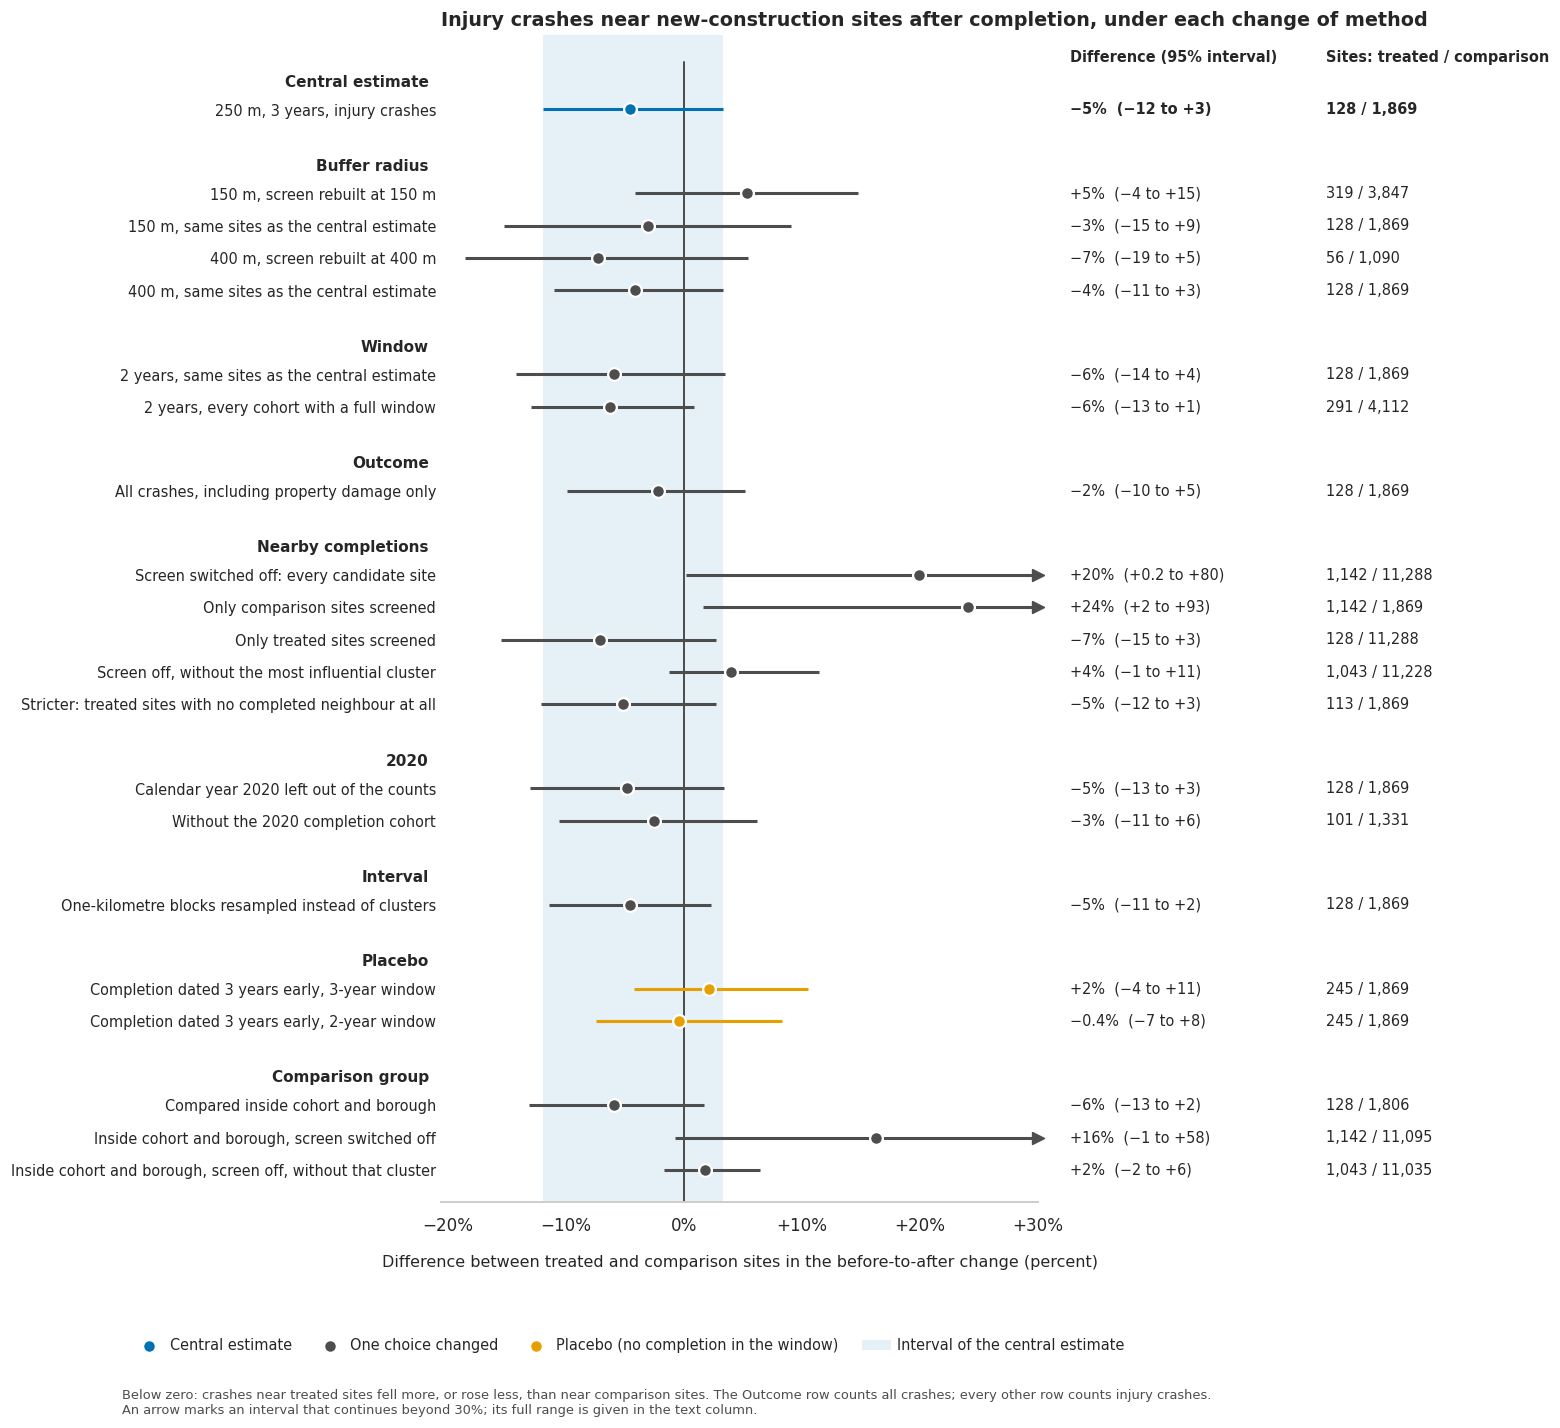

In [179]:
def forest_layout(table, row_step=1.0, heading_step=0.85, group_gap=0.75):
    """Vertical position of every row and of every group heading, top to bottom."""
    row_positions, headings, cursor = [], [], 0.0
    for check, block in table.groupby("check", sort=False):
        headings.append((cursor, check))
        cursor += heading_step
        row_positions.extend(cursor + row_step * np.arange(len(block)))
        cursor += row_step * len(block) + group_gap
    return np.asarray(row_positions), headings, cursor - group_gap


def plot_percent(value):
    """A percent value for the text column: whole numbers, one decimal for values that round to zero."""
    text = f"{value:+.1f}" if abs(value) < 0.5 else f"{round(value):+d}"
    return text.replace("-", "−")


def forest_plot(table):
    """Every specification as a point with its interval, grouped by check, on a percent scale."""
    row_positions, headings, bottom = forest_layout(table)
    table = table.assign(position=row_positions)
    central_row = table[table["kind"] == KIND_CENTRAL].iloc[0]

    # Plot range: the widest interval, but never beyond the axis limit on either side.
    padding = 2
    left = max(-FOREST_AXIS_LIMIT, np.nanmin(table["percent_low"]) - padding)
    right = min(FOREST_AXIS_LIMIT, np.nanmax(table["percent_high"]) + padding)
    axis_right = left + (right - left) / FOREST_PLOT_SHARE     # room for the two text columns
    value_column, sample_column = FOREST_PLOT_SHARE + 0.03, FOREST_PLOT_SHARE + 0.27

    fig, ax = plt.subplots(figsize=(12.5, 0.34 * bottom + 2.0))
    row_axis = ax.get_yaxis_transform()     # x in axes fractions, y in row positions
    # The interval of the central estimate as a band, so every other row can be read against it.
    band = ax.axvspan(central_row["percent_low"], central_row["percent_high"], color=PALETTE["treated"],
                      alpha=0.10, linewidth=0, label="Interval of the central estimate")
    ax.plot([0, 0], [-0.6, bottom], color=PALETTE["neutral"], linewidth=1.3)

    handles = []
    for kind, (label, color) in ROW_KINDS.items():
        rows = table[(table["kind"] == kind) & table["estimate"].notna()]
        low = rows["percent_low"].clip(lower=left)
        high = rows["percent_high"].clip(upper=right)
        ax.hlines(rows["position"], low, high, color=color, linewidth=2)
        handles.append(ax.scatter(rows["percent_change"].clip(left, right), rows["position"], s=70, color=color,
                                  edgecolor="white", linewidth=1.5, zorder=3, label=label))
        # An arrow head where an interval continues beyond the edge of the axis.
        cut_high = rows[rows["percent_high"] > right]
        ax.scatter(np.full(len(cut_high), right), cut_high["position"], marker=">", s=60, color=color, zorder=3)
        cut_low = rows[rows["percent_low"] < left]
        ax.scatter(np.full(len(cut_low), left), cut_low["position"], marker="<", s=60, color=color, zorder=3)

    for _, row in table.iterrows():
        if np.isnan(row["estimate"]):
            value_text = f"not reported (fewer than {MIN_GROUP_N} sites)"
        else:
            value_text = (f"{plot_percent(row['percent_change'])}%  ({plot_percent(row['percent_low'])} to "
                          f"{plot_percent(row['percent_high'])})")
        weight = "bold" if row["kind"] == KIND_CENTRAL else "normal"
        ax.text(value_column, row["position"], value_text, transform=row_axis, va="center", fontsize=9.5,
                fontweight=weight)
        ax.text(sample_column, row["position"], f"{row['n_treated']:,} / {row['n_comparison']:,}",
                transform=row_axis, va="center", fontsize=9.5, fontweight=weight)
    header_position = -0.75
    ax.text(value_column, header_position, f"Difference ({CI_LEVEL:.0%} interval)", transform=row_axis,
            va="center", fontsize=9.5, fontweight="bold")
    ax.text(sample_column, header_position, "Sites: treated / comparison", transform=row_axis, va="center",
            fontsize=9.5, fontweight="bold")

    ax.set_yticks(table["position"])
    ax.set_yticklabels(table["variant"], fontsize=9.5)
    ax.tick_params(axis="y", length=0)
    for heading_position, check in headings:
        ax.text(-0.012, heading_position, check, transform=row_axis, ha="right", va="center", fontsize=10,
                fontweight="bold")
    ax.set_ylim(bottom, header_position - 0.7)
    ax.set_xlim(left, axis_right)
    tick_step = 10
    ax.set_xticks(np.arange(math.ceil(left / tick_step) * tick_step, right + 1, tick_step))
    ax.xaxis.set_major_formatter(mpl.ticker.FuncFormatter(
        lambda value, _: "0%" if value == 0 else f"{value:+.0f}%".replace("-", "−")))
    ax.spines["bottom"].set_bounds(left, right)
    ax.spines["left"].set_visible(False)
    ax.grid(False)
    ax.legend(handles=[*handles, band], loc="upper left", bbox_to_anchor=(-0.3, -0.105), ncol=4, columnspacing=1.6,
              handletextpad=0.4)
    finish(ax, "Injury crashes near new-construction sites after completion, under each change of method",
           "Difference between treated and comparison sites in the before-to-after change (percent)", "")
    ax.xaxis.set_label_coords(FOREST_PLOT_SHARE / 2, -0.045)
    ax.annotate(f"Below zero: crashes near treated sites fell more, or rose less, than near comparison sites. The "
                f"Outcome row counts all crashes; every other row counts injury crashes.\nAn arrow marks an interval that continues "
                f"beyond {FOREST_AXIS_LIMIT}%; its full range is given in the text column.",
                xy=(-0.3, -0.16), xycoords="axes fraction", fontsize=8.5, color=PALETTE["neutral"], va="top")
    return fig, ax


forest_plot(robustness_table)
plt.show()

In [180]:
changed_rows = robustness_table[(robustness_table["kind"] == KIND_CHECK) & has_estimate]
screened_rows = changed_rows[changed_rows["keeps_screen"]]
unscreened_rows = changed_rows[~changed_rows["keeps_screen"]]
placebo_rows = robustness_table[(robustness_table["kind"] == KIND_PLACEBO) & has_estimate]
excluding = changed_rows[changed_rows["interval_excludes_zero"]]
positive = changed_rows[changed_rows["estimate"] > 0]
placebo_estimates = " and ".join(f"{value:+.1f}%" for value in placebo_rows["percent_change"])
say(f"Of the {len(changed_rows)} specifications that change one choice, "
    f"{len(changed_rows) - len(excluding)} have an interval that includes zero. Their point estimates run from "
    f"{changed_rows['percent_change'].min():+.1f}% to {changed_rows['percent_change'].max():+.1f}%, against "
    f"{central['percent_change']:+.1f}% for the central estimate, and {len(positive)} of them are above zero "
    f"({'; '.join(positive['variant'])}). The interval excludes zero in {len(excluding)} of them "
    f"({'; '.join(excluding['variant']) if len(excluding) else 'none'}). Across the {len(screened_rows)} "
    f"specifications that keep the screen on both groups, the intervals run from "
    f"{screened_rows['percent_low'].min():+.1f}% to {screened_rows['percent_high'].max():+.1f}%, so a change "
    f"beyond that range is not supported, while a fall or a rise inside it cannot be excluded; "
    f"{int(screened_rows['interval_excludes_zero'].sum())} of these intervals exclude zero. Of the "
    f"{len(unscreened_rows)} specifications that drop the screen for at least one group, "
    f"{int(unscreened_rows['interval_excludes_zero'].sum())} have an interval that excludes zero. The "
    f"{len(placebo_rows)} placebo estimates are {placebo_estimates}, and "
    f"{int(placebo_rows['interval_excludes_zero'].sum())} of their intervals exclude zero.")

Of the 18 specifications that change one choice, 16 have an interval that includes zero. Their point estimates run from -7.2% to +24.1%, against -4.6% for the central estimate, and 6 of them are above zero (150 m, screen rebuilt at 150 m; Screen switched off: every candidate site; Only comparison sites screened; Screen off, without the most influential cluster; Inside cohort and borough, screen switched off; Inside cohort and borough, screen off, without that cluster). The interval excludes zero in 2 of them (Screen switched off: every candidate site; Only comparison sites screened). Across the 12 specifications that keep the screen on both groups, the intervals run from -18.5% to +14.7%, so a change beyond that range is not supported, while a fall or a rise inside it cannot be excluded; 0 of these intervals exclude zero. Of the 6 specifications that drop the screen for at least one group, 2 have an interval that excludes zero. The 2 placebo estimates are +2.1% and -0.4%, and 0 of their intervals exclude zero.

### 9.12 What holds and what depends on a choice

One statement holds in every specification that keeps the screen: the change in injury crashes
around newly completed new-construction sites cannot be told apart from the change around
comparison sites over the same years. No interval in those rows excludes zero. The intervals
are not narrow, though. Their range is printed above, and a moderate fall or rise lies inside
it, so these rows rule out only changes larger than that. The statement does not depend on the
counting radius, on the length of the window, on how the year 2020 is treated, on the unit
that is resampled, on whether injury crashes or all crashes are counted, or on whether the
comparison is made inside boroughs. The placebo gives no sign of different trends before
completion, within the limits of its own interval. The three questions about shares give the
same reading at the smaller radius, apart from one factor group whose interval excludes zero
there when taken alone and which is not kept after adjustment (9.2).

The direction of the point estimate does depend on which sites enter the comparison. It is
slightly negative in the central specification and in most checks, and positive when the
screen is rebuilt at 150 m or switched off, while changes that keep the sites fixed leave the
estimate almost where it was. A reading such as "injury crashes fall a little after
completion" would therefore be a statement about the selected sites and is not made in this
notebook. The positive estimate without the screen is carried by one development of small
houses on streets that had almost no injury crashes before (9.5). Without that cluster the
estimate for all candidate sites is small and its interval includes zero, inside cohorts and
inside boroughs (9.9). The rows without the screen are therefore not read as a rise in the
dense parts of the programme. They are weaker evidence than the screened rows, because most of
their comparison streets have a completed building of their own.

The reporting break of 2020 is the one place where a choice changes a raw number by a wide
margin: counted as all crashes, the undifferenced fall at treated sites is far larger than
the fall in injury crashes. It disappears only because the comparison sites share it. Any result
in this notebook that compares periods without such a group has to use injury crashes.

The ZIP-level questions were checked separately in 9.10. On reported ZIP codes alone the
forecast loss of RQ1 is gone and the RQ9 correlation has an interval that includes zero. The
completion-year slope of RQ2 is negative in both versions and belongs to preserved units. The null results for
the cumulative stock in RQ2 and for deaths in RQ9 are the same in both versions.

The screened sample is small on the treated side and lies in the less dense parts of the
programme, so the central result describes those places. Where buildings stand close together
the only estimates are the ones without the screen. All of these are associations in
observational data: the comparison sites are similar to the treated ones in being part of the same
programme, but they were not assigned at random.

## 10. What we found

Section 8 answered the ten questions one at a time. The table below collects their headline
numbers from `RESULTS`, as each question stored them, and adds whether the interval includes
zero. The estimates come in different units, so every row names its own. RQ8 and RQ10 report
the largest of several gaps, so their interval is the wider one that allows for that choice,
and RQ9 carries the p-value adjusted for its two outcomes.

In [181]:
# Objects of Sections 4 to 9 that Sections 10 to 14 read.
assert_state("RESULTS", "rq9_result", "robustness_table", "CHECK_OUTCOME", "KIND_CENTRAL",
             "LARGEST_CLUSTERS_SHOWN", "city_year", "sites", "event_panel", "zip_year", "housing", "crashes")

# --- Constants used only in Sections 10 to 14 -------------------------------------------------
NO_DIFFERENCE = 0.0          # value every headline estimate is compared with
OVERVIEW_COLUMNS = 2         # panels per row in the overview chart of the ten results
COMPLETION_REL_YEAR = 0      # rel_year of the completion year: one row per site and cohort
RQ9_OUTCOME = "ped_cyc_share_pct"   # row of rq9_result behind the RQ9 headline
SURPLUS_FROM_YEAR = BREAK_YEAR + 1  # first year in which injured totals above their parts appear regularly (4.9)
STAGE_ORDER = ["raw", "cleaned", "integrated"]

CORRELATION_DIGITS = 3       # decimals shown for a correlation; the other estimates use two
DEFAULT_DIGITS = 2

# For each question: its owner, a short label for the chart, what its n counts and what a value
# to the right of zero means. These are labels only; every number and unit comes from RESULTS.
RESULT_LAYOUT = {
    "RQ1": ("M1", "Forecast error when housing is added", "ZIP codes",
            "right of zero = forecast less accurate with housing"),
    "RQ2": ("M1", "Injury crashes as the unit stock grows", "ZIP codes",
            "right of zero = more injury crashes with a larger stock"),
    "RQ3": ("M2", "After against before, new buildings", "new-construction sites",
            "right of zero = more injury crashes after completion"),
    "RQ4": ("M2", "Change by units completed nearby", "new-construction sites",
            "right of zero = larger rise where more units were completed"),
    "RQ5": ("M3", "New construction against preservation", "completed sites",
            "right of zero = change more positive at new construction"),
    "RQ6": ("M3", "Pedestrian and cyclist share", "completed sites",
            "right of zero = share rose more at completed sites"),
    "RQ7": ("M4", "Where new-construction sites stand before the project", "new-construction sites",
            "right of zero = more injury crashes than the typical street point"),
    "RQ8": ("M4", "Hour of day (largest band gap)", "completed sites",
            "right of zero = share rose more at completed sites"),
    "RQ9": ("M5", "Deep-affordable share and who is hurt", "ZIP codes",
            "right of zero = higher pedestrian and cyclist share where the stock is deeper"),
    "RQ10": ("M5", "Contributing factor (largest group gap)", "completed sites",
             "right of zero = share rose more at completed sites"),
}


def interval_excludes(low, high, reference=NO_DIFFERENCE):
    """True when the whole interval lies on one side of the reference value."""
    return bool(low > reference or high < reference)


def results_table(results, layout):
    """One row per research question: owner, question, estimate, interval, unit, n and reading.

    `kept` is True when the interval excludes zero and, where the question tested several things
    together, the adjusted p-value is below FALSE_DISCOVERY_RATE as well. A percentile bootstrap
    interval can leave the point estimate outside when the resampled values are skewed, so that
    case is flagged in `estimate_outside_interval` instead of stopping the notebook. The numeric
    columns stay numeric so the chart can use them; `formatted_results` makes the version shown.
    """
    assert set(results) == set(layout), "every research question must have stored exactly one result"
    rows = []
    for key, (owner, label, n_unit, direction) in layout.items():
        stored = results[key]
        excludes_zero = interval_excludes(stored["ci_low"], stored["ci_high"])
        adjusted_p = stored["adjusted_p"]
        rows.append({
            "rq": key, "owner": owner, "label": label, "question": stored["question"],
            "estimate": stored["estimate"], "low": stored["ci_low"], "high": stored["ci_high"],
            "level": stored["level"], "unit": stored["unit"], "n": stored["n"], "n_unit": n_unit,
            "direction": direction, "adjusted_p": float("nan") if adjusted_p is None else adjusted_p,
            "excludes_zero": excludes_zero,
            "kept": excludes_zero and (adjusted_p is None or adjusted_p < FALSE_DISCOVERY_RATE),
            "estimate_outside_interval": not stored["ci_low"] <= stored["estimate"] <= stored["ci_high"],
        })
    return pd.DataFrame(rows).set_index("rq")


def reading_text(row):
    """The reading of one headline in words."""
    if not row["excludes_zero"]:
        return "interval includes zero"
    if row["kept"]:
        return "interval excludes zero"
    margin = min(abs(row["low"]), abs(row["high"]))
    return (f"interval ends {margin:.3f} from zero; not kept after adjustment "
            f"(adjusted p {row['adjusted_p']:.2f})")


def formatted_results(table):
    """The results table as shown: signed numbers, the interval in one cell, the reading in words."""
    digits = [CORRELATION_DIGITS if "correlation" in unit else DEFAULT_DIGITS for unit in table["unit"]]
    shown = pd.DataFrame({
        "owner": table["owner"],
        "question": table["question"],
        "estimate": [f"{value:+.{places}f}" for value, places in zip(table["estimate"], digits)],
        "interval": [f"{low:+.{places}f} to {high:+.{places}f} ({level:.0%})"
                     for low, high, level, places in zip(table["low"], table["high"], table["level"], digits)],
        "unit of the estimate": table["unit"],
        "n": [f"{n:,} {n_unit}" for n, n_unit in zip(table["n"], table["n_unit"])],
        "reading": [reading_text(row) for _, row in table.iterrows()],
    })
    shown.index.name = None
    return shown


summary_table = results_table(RESULTS, RESULT_LAYOUT)
with pd.option_context("display.max_colwidth", None):
    display(formatted_results(summary_table))
outside = summary_table.index[summary_table["estimate_outside_interval"]].tolist()
if outside:
    say(f"Warning: the point estimate lies outside its percentile interval for {', '.join(outside)}, which "
        f"happens when the resampled values are skewed. Those intervals should be read with care.")

,owner,question,estimate,interval,unit of the estimate,n,reading
RQ1,M1,Does knowing a ZIP's affordable-housing completions improve an out-of-time forecast of its injury crashes?,+0.60,+0.17 to +1.10 (95%),MAE difference (injury crashes per ZIP per year),171 ZIP codes,interval excludes zero
RQ2,M1,"Within a ZIP over time, do injury crashes move as the cumulative stock of completed affordable units grows?",+0.07,-0.06 to +0.41 (95%),% change in injury crashes per 100 units,171 ZIP codes,interval includes zero
RQ3,M2,"Do injury crashes within 250 m of new-construction sites change after completion, relative to not-yet-completed sites?",-4.56,-11.90 to +3.33 (95%),% change relative to comparison sites,128 new-construction sites,interval includes zero
RQ4,M2,Does the before/after change in injury crashes at a new-construction site scale with the number of units?,-2.20,-5.78 to +1.09 (95%),% change per doubling of units,128 new-construction sites,interval includes zero
RQ5,M3,Is the before/after change in injury crashes different near New Construction than near Preservation (the placebo)?,-8.10,-19.58 to +4.86 (95%),% difference between the two after/before ratios,306 completed sites,interval includes zero
RQ6,M3,Does the pedestrian and cyclist share of injury crashes near sites change after completion?,+1.22,-1.08 to +3.39 (95%),"percentage points, completed minus comparison sites",306 completed sites,interval includes zero
RQ7,M4,"Before the project starts, are new-construction sites on streets with more injury crashes than typical street locations of the borough?",+19.90,+16.56 to +22.99 (95%),percentile points above the typical street point of the borough,"2,789 new-construction sites",interval excludes zero
RQ8,M4,Does the hour-of-day mix of injury crashes near sites shift after completion?,+1.41,-2.05 to +4.23 (99%),"percentage points; largest of 4 gaps, interval widened for 4 tests",306 completed sites,interval includes zero
RQ9,M5,"Across ZIP codes, is the deep-affordable share associated with the pedestrian and cyclist share of harm?",-0.215,-0.392 to -0.000 (95%),rank correlation within borough,123 ZIP codes,interval ends 0.000 from zero; not kept after adjustment (adjusted p 0.10)
RQ10,M5,"Which contributing-factor groups are over- or under-represented near completed housing, after against before?",-0.83,-2.76 to +0.67 (99%),"percentage points; largest of 9 gaps, interval widened for 9 tests",306 completed sites,interval includes zero


The chart shows the same ten rows. A percentage, a correlation and a number of crashes cannot
share one scale, so every panel has its own horizontal axis, labelled with its unit and with
what a value to the right of zero means. The widths of the intervals can therefore not be
compared between panels. The vertical line is "no difference" in all of them. An interval that
crosses the line means the data cannot tell that estimate from zero.

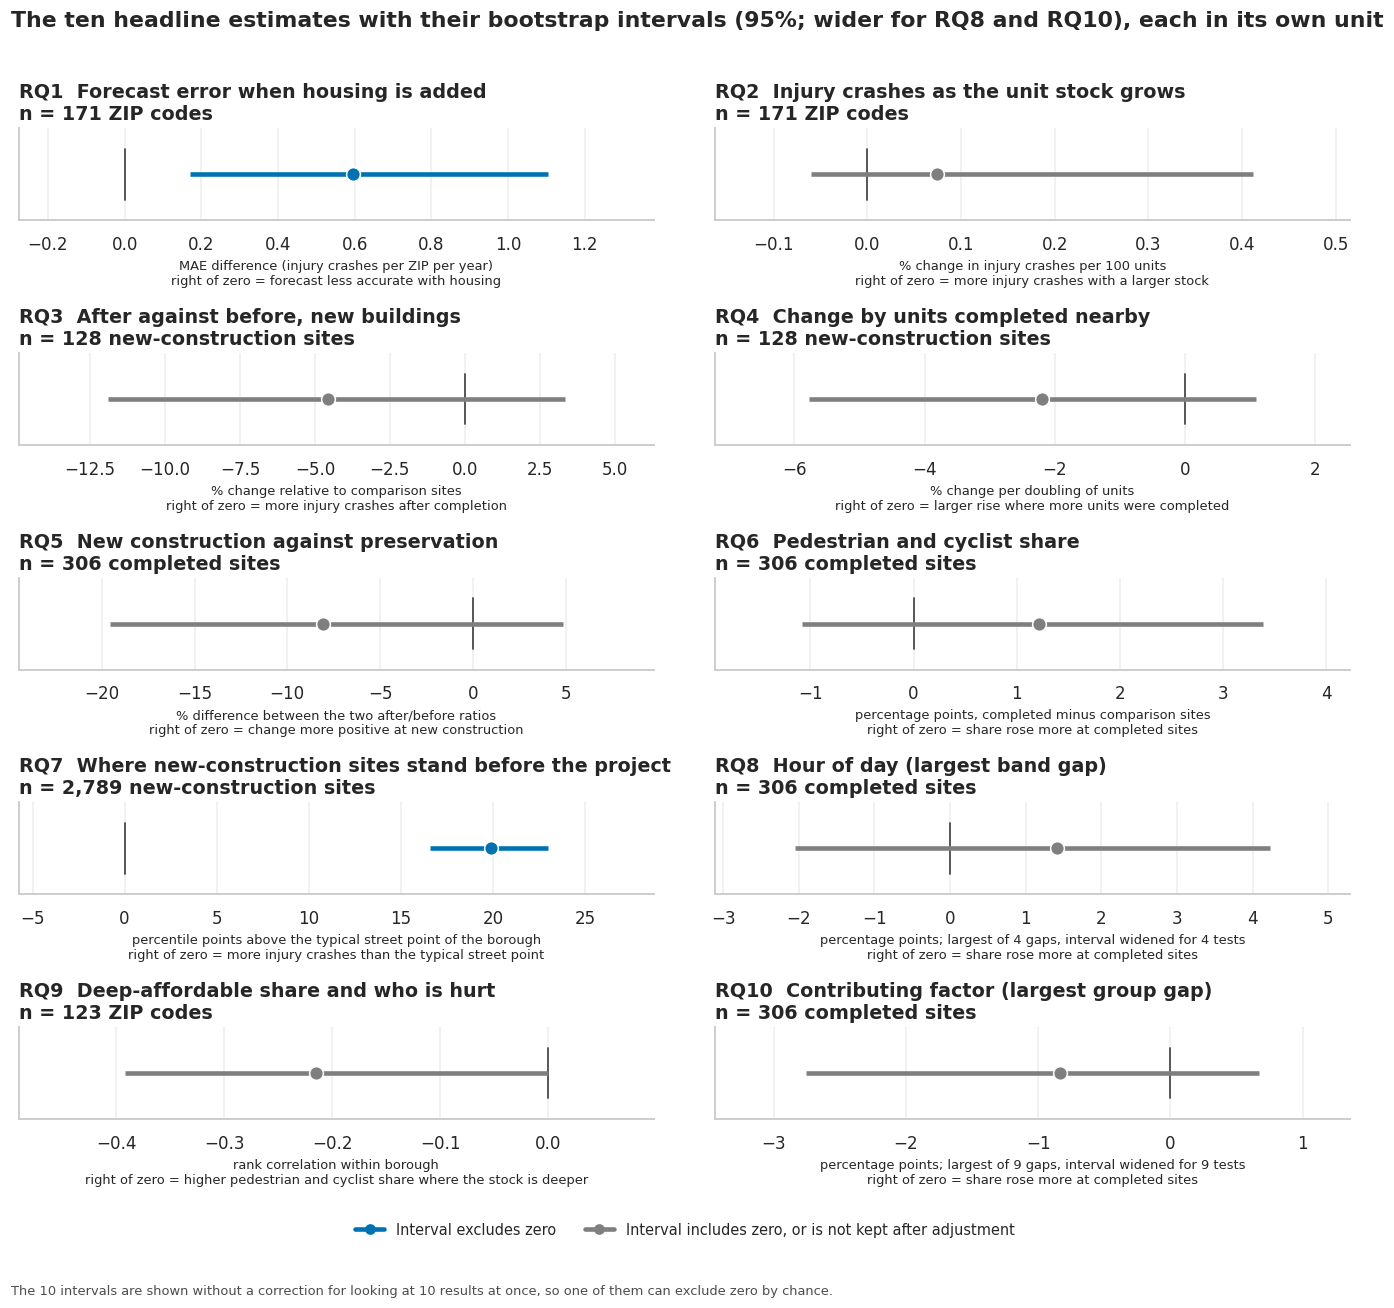

In [182]:
def plot_results_overview(table):
    """Small multiples: one estimate with its interval per research question, each on its own scale."""
    n_rows = math.ceil(len(table) / OVERVIEW_COLUMNS)
    fig, axes = plt.subplots(n_rows, OVERVIEW_COLUMNS, figsize=(12.5, 2.3 * n_rows))
    colors = {True: PALETTE["treated"], False: PALETTE["control"]}
    for ax, (key, row) in zip(axes.ravel(), table.iterrows()):
        color = colors[row["kept"]]
        # The zero line is a short segment inside the panel, so it cannot stick out above the axes.
        ax.plot([NO_DIFFERENCE, NO_DIFFERENCE], [-0.55, 0.55], color=PALETTE["neutral"], linewidth=1.2)
        ax.hlines(0, row["low"], row["high"], color=color, linewidth=3)
        ax.plot(row["estimate"], 0, "o", color=color, markersize=9, markeredgecolor="white")
        # Pad the axis so that zero and both interval ends are always inside the panel.
        reach = max(abs(row["low"]), abs(row["high"]))
        ax.set_xlim(min(row["low"], NO_DIFFERENCE) - 0.25 * reach, max(row["high"], NO_DIFFERENCE) + 0.25 * reach)
        ax.set_ylim(-1, 1)
        ax.set_yticks([])
        ax.grid(axis="y", visible=False)
        finish(ax, f"{key}  {row['label']}\nn = {row['n']:,} {row['n_unit']}",
               f"{row['unit']}\n{row['direction']}", "")
        ax.title.set_fontsize(10)
        ax.xaxis.label.set_fontsize(8.5)
    handles = [mpl.lines.Line2D([], [], color=colors[flag], marker="o", linewidth=3, label=label)
               for flag, label in [(True, "Interval excludes zero"),
                                   (False, "Interval includes zero, or is not kept after adjustment")]]
    fig.legend(handles=handles, loc="lower center", ncol=2, bbox_to_anchor=(0.5, 0.0))
    fig.suptitle(f"The ten headline estimates with their bootstrap intervals ({CI_LEVEL:.0%}; wider for RQ8 and "
                 f"RQ10), each in its own unit", fontweight="bold", x=0.01, ha="left")
    fig.text(0.01, -0.035, f"The {len(table)} intervals are shown without a correction for looking at "
                           f"{len(table)} results at once, so one of them can exclude zero by chance.",
             fontsize=8.5, color=PALETTE["neutral"])
    fig.tight_layout(rect=(0, 0.035, 1, 0.97), w_pad=3)
    plt.show()


plot_results_overview(summary_table)

In [183]:
away_from_zero = summary_table.index[summary_table["excludes_zero"]].tolist()
not_kept = summary_table.index[summary_table["excludes_zero"] & ~summary_table["kept"]].tolist()
rq9_adjusted_p = float(rq9_result.loc[RQ9_OUTCOME, "p_adjusted"])
say(f"Of the {len(summary_table)} headline intervals, {len(away_from_zero)} exclude zero "
    f"({', '.join(away_from_zero) if away_from_zero else 'none'}) and "
    f"{len(summary_table) - len(away_from_zero)} include it. Of those that exclude zero, {len(not_kept)} "
    f"({', '.join(not_kept) if not_kept else 'none'}) are not kept after the adjustment for the tests made "
    f"together with them. For RQ9 the p-value adjusted for its two outcomes is {rq9_adjusted_p:.2f}, against a "
    f"threshold of {FALSE_DISCOVERY_RATE}, and the end of its interval nearest to zero is "
    f"{summary_table.loc['RQ9', ['low', 'high']].abs().min():.3f} away from it.")
say(RESULTS["RQ7"]["sentence"])
say(RESULTS["RQ3"]["sentence"])

Of the 10 headline intervals, 3 exclude zero (RQ1, RQ7, RQ9) and 7 include it. Of those that exclude zero, 1 (RQ9) are not kept after the adjustment for the tests made together with them. For RQ9 the p-value adjusted for its two outcomes is 0.10, against a threshold of 0.05, and the end of its interval nearest to zero is 0.000 away from it.

The mean borough percentile of new-construction sites, before their project started, minus 50 is +19.90 percentile points (95% interval +16.56 to +22.99, n = 2,789 new-construction sites in 336 one-kilometre blocks). The interval lies above zero, which fits sites standing where there were already more injury crashes than at the typical street point of the borough.

The after-against-before change in injury crashes within 250 m of new buildings, relative to comparison sites, is -4.6 percent (95% interval -11.9 to +3.3, n = 128 new-construction sites). The interval includes zero.

The intervals that exclude zero are different kinds of result. RQ7 is far from zero and is the
largest result in the notebook; what it does and does not show is taken up in 10.1. RQ1 is on
the unhelpful side: the forecast is a little less accurate with housing information than
without it. Its interval is conditional on the fitted models, and the loss is absent when only
crashes with a reported ZIP code are counted (9.10), so we read it as "housing did not improve
the forecast" and not as a finding about housing. RQ9 ends a hair from zero, and its p-value
is above the threshold once its two outcomes are adjusted for together, so it is drawn in grey
and counted as a hint. All the other headline intervals include zero.

Inside the questions, some side results also have intervals that exclude zero. Two of them
need a comment: the completion-year slope of RQ2 and the gap in crash reports without a
contributing factor in RQ10. Both are found for preservation projects, which bring no new
residents, and 10.1 comes back to them.

### 10.1 The answer to the main question

We started from a worry that comes up whenever an affordable building is proposed: more
residents, more traffic, more people hurt on the street. For the buildings we could isolate,
the crash records do not show it. Around those new buildings, injury crashes fell after
completion by about as much as they fell around sites of the same programme that were still
unfinished, and the difference between the two has an interval that includes zero (RQ3). No
relation with the number of units completed can be detected (RQ4). New construction, which
brings residents, cannot be told apart from preservation, which brings none (RQ5). Around
completed sites of either kind, the pedestrian and cyclist share, the hour of the day and the
mix of recorded contributing factors show no detectable shift (RQ6, RQ8, RQ10). More than half
of those sites are preservation projects. With the treated group limited to new construction
the three gaps stay small and their intervals include zero. At the scale of a ZIP code, a
growing stock of affordable units goes with no detectable movement in injury crashes (RQ2).
Section 9 changed the radius, the window, the outcome, the handling of 2020 and the strata of
the comparison, and the reading stayed the same in every version that kept the screen on both
groups.

The two side results named above both belong to preservation. One of the five timing slopes of RQ2, the one for the completion year, is negative in every version we
ran. It appears for preserved units and is absent for new ones. In RQ10 the share of crash
reports that name no contributing factor fell around completed sites relative to comparison
sites, and that gap is found around preservation sites and is absent around new construction.
A preservation completion brings no new residents, which is why RQ5 uses it as a placebo, so
neither result says anything about what new housing does to a street. We do not know what
produces them. The second one is also a caveat for RQ10: its factor shares are taken among
reports with a recorded factor, so a change in how completely reports are filled in can hide
or imitate a shift in the mix.

The interval of RQ3 is wide enough to hold a moderate fall as well as a small rise, so we
cannot say that the streets stay as they were. Around the isolated sites the data give no
support to the claim that the streets get worse; the upper end of the interval is printed
above. For the dense clusters, where most buildings stand, the comparison is weaker, because
the comparison streets often have a completed building of their own, which can hide part of a
difference. The estimate without the screen is positive only because of one development of
small houses on streets that had almost no injury crashes before. Without it the difference
is small and its interval includes zero (9.5).

The records do show something about where the buildings are. New-construction sites whose
project started after the baseline years stood, during those years, on streets with more
injury crashes than most street points of their borough, and they still rank above the middle
inside their own ZIP code (RQ7). The benchmark is a grid of street points and not other
housing, and apartment buildings of any kind stand on dense blocks, so this shows where the
buildings are. It does not show that the programme picks more dangerous streets than other
housing would. The one comparison between two kinds of housing site that the tables allow
shows that new-construction sites stand in parts of a borough with more injury crashes than
preservation sites do. Ranked inside their own ZIP codes, the two kinds cannot be told apart.
The people who move in arrive on a street that already had this crash record.

### 10.2 What surprised us

The cell below computes the numbers behind this subsection, so the text can stay free of them.

In [184]:
def surprise_facts(city, checks, site_frame, panel, crash_frame):
    """Numbers behind Section 10.2, each taken from a table built in Sections 4 to 9."""
    last_year = city.loc[city["year"] == YEAR_END].iloc[0]
    central_row = checks.loc[checks["kind"] == KIND_CENTRAL].iloc[0]
    all_crash_row = checks.loc[checks["check"] == CHECK_OUTCOME].iloc[0]
    cluster_sizes = site_frame["cluster_id"].value_counts()
    # One row per (site, cohort): the completion-year row of every treated candidate.
    treated = panel[(panel["group"] == "treated") & (panel["rel_year"] == COMPLETION_REL_YEAR)]
    surplus = crash_frame[crash_frame["other_injured"] > 0]
    return {
        "crash_index": float(last_year["crash_index"]),
        "injury_index": float(last_year["injury_crash_index"]),
        "all_crash_change": log_points_to_percent(all_crash_row["treated_change"]),
        "injury_change": log_points_to_percent(central_row["treated_change"]),
        "all_crash_difference": float(all_crash_row["percent_change"]),
        "sites": len(site_frame),
        "share_in_largest": pct(cluster_sizes.head(LARGEST_CLUSTERS_SHOWN).sum(), len(site_frame)),
        "median_neighbours": float(site_frame["n_sites_within_buffer"].median()),
        "treated_candidates": len(treated),
        "treated_clean": int((~treated["contaminated"]).sum()),
        "surplus_crashes": len(surplus),
        "surplus_share_late": pct((surplus["year"] >= SURPLUS_FROM_YEAR).sum(), len(surplus)),
    }


facts = surprise_facts(city_year, robustness_table, sites, event_panel, crashes)
assert 0 <= facts["treated_clean"] <= facts["treated_candidates"]
say(f"With {INDEX_BASE_YEAR} set to 100, all reported crashes stand at {facts['crash_index']:.0f} in {YEAR_END} "
    f"and injury crashes at {facts['injury_index']:.0f}. Counted as all crashes, the streets within {BUFFER_M} m "
    f"of the new buildings of RQ3 change by {facts['all_crash_change']:+.0f}% from the {EVENT_WINDOW} years before "
    f"completion to the {EVENT_WINDOW} years after; counted as injury crashes they change by "
    f"{facts['injury_change']:+.0f}%. Against comparison sites the all-crash difference is "
    f"{facts['all_crash_difference']:+.1f}%.")
say(f"The {LARGEST_CLUSTERS_SHOWN} largest clusters hold {facts['share_in_largest']:.0f}% of the {facts['sites']:,} "
    f"located sites, and the median site has {facts['median_neighbours']:.0f} other sites within {BUFFER_M} m. "
    f"Of {facts['treated_candidates']:,} completed sites in the cohorts with a full window, "
    f"{facts['treated_clean']:,} ({pct(facts['treated_clean'], facts['treated_candidates']):.0f}%) had no other "
    f"completion nearby in a different year of their window.")
say(f"{facts['surplus_crashes']:,} crashes report more injured persons than pedestrians, cyclists and motorists "
    f"together, and {facts['surplus_share_late']:.0f}% of them are dated {SURPLUS_FROM_YEAR} or later.")
say(RESULTS["RQ1"]["sentence"])

With 2019 set to 100, all reported crashes stand at 40 in 2025 and injury crashes at 82. Counted as all crashes, the streets within 250 m of the new buildings of RQ3 change by -47% from the 3 years before completion to the 3 years after; counted as injury crashes they change by -14%. Against comparison sites the all-crash difference is -2.2%.

The 3 largest clusters hold 59% of the 7,593 located sites, and the median site has 12 other sites within 250 m. Of 2,086 completed sites in the cohorts with a full window, 306 (15%) had no other completion nearby in a different year of their window.

10,178 crashes report more injured persons than pedestrians, cyclists and motorists together, and 96% of them are dated 2021 or later.

The change in out-of-time forecast error from adding affordable-housing completions and stock is +0.60 injury crashes per ZIP per year (95% interval +0.17 to +1.10, n = 171 ZIP codes). The interval lies above zero, which fits a less accurate forecast.

The biggest surprise came before any research question. Counted as all crashes, the streets
around a new building seem to lose a large part of their crashes after completion. The same
fall appears around unfinished sites and in the city as a whole, and it comes from reports of
crashes without injuries, which dropped in 2020 and never came back. With the total count and
no comparison sites we would have reported a large safety gain near new housing, and it would
have been a product of record keeping.

The second surprise was how tightly the programme is packed. We expected most buildings to
have a few blocks to themselves. Most of them have other financed buildings within the
buffer, the chains of neighbours run through whole districts, and only a small part of the
completed sites had no other completion nearby during their window. The before and after
comparison rests on far fewer buildings than the housing table has rows, and it describes the
less dense edges of the programme.

We also expected housing information to help a crash forecast at least a little. It did not.
In this split the forecast was slightly less accurate with it (RQ1), and a model that knew
only the ZIP's own injury crashes could not be told from repeating last year's count.

Two smaller things were unexpected. Inside a borough, ZIP codes with a deeper affordable mix
lean towards a lower pedestrian and cyclist share of injury crashes, where we had expected a
higher one. This is a weak hint that is not kept after the adjustment for the two outcomes of
RQ9; its adjusted p-value is printed under the overview chart. And from the year after the
reporting break the persons-injured total stopped matching pedestrians plus cyclists plus
motorists. Section 4.9 shows that an e-scooter or e-bike is the first vehicle in a much larger
share of these crashes than of crashes in general, which fits riders of those devices being
counted as injured without belonging to the three published categories, although the table
does not say so.

### 10.3 What the ten answers add up to

Affordable housing stands on streets with many injury crashes, and that is true before the
building exists (RQ7). After completion we could not detect a change on any of the measures we
tried at the sites we could isolate, and the intervals allow a moderate fall or a small rise
(RQ2 to RQ6, RQ8, RQ10). A map that overlays housing and crashes shows the first of these and
can be misread as showing a change.

The crash record of a block is known years before a financed building opens on it, so street
changes for the future tenants can be planned from that record. The results for the years
after completion are too imprecise to say whether the building itself will change it.

## 11. What the data cannot tell us

Every result in this notebook is an association. The reasons are specific to these two tables,
and the cell below puts a size on the ones that can be measured.

In [185]:
def limit_facts(housing_frame, crash_frame, results, checks):
    """Sizes of the gaps that Section 11 discusses, from the cleaned and integrated tables."""
    confidential = housing_frame["is_confidential"]
    panel_crashes = crash_frame[crash_frame["in_zip_panel"]]
    first_year = crash_frame[crash_frame["year"] == YEAR_START]
    return {
        "confidential_rows": int(confidential.sum()),
        "confidential_row_share": pct(confidential.sum(), len(housing_frame)),
        "confidential_unit_share": pct(housing_frame.loc[confidential, "total_units"].sum(),
                                       housing_frame["total_units"].sum()),
        "same_day_share": pct(housing_frame["same_day_completion"].sum(), housing_frame["is_completed"].sum()),
        "unlocated_share": pct((~crash_frame["is_located"]).sum(), len(crash_frame)),
        "unlocated_share_first_year": pct((~first_year["is_located"]).sum(), len(first_year)),
        "outside_panel_share": pct((~crash_frame["in_zip_panel"]).sum(), len(crash_frame)),
        "imputed_zip_share": pct(panel_crashes["zip_imputed"].sum(), len(panel_crashes)),
        "no_factor_share": pct((crash_frame["factor_group"] == UNRECORDED_FACTOR).sum(), len(crash_frame)),
        "headline_intervals": len(results),
        "robustness_intervals": len(checks),
    }


limits = limit_facts(housing, crashes, RESULTS, robustness_table)
say(f"Housing: {limits['confidential_rows']:,} rows ({limits['confidential_row_share']:.1f}%) are confidential and "
    f"cannot be located; they hold {limits['confidential_unit_share']:.2f}% of the units. "
    f"{limits['same_day_share']:.0f}% of completed rows carry a completion date equal to their start date.")
say(f"Crashes: {limits['unlocated_share']:.1f}% have no usable coordinates ({limits['unlocated_share_first_year']:.1f}% "
    f"in {YEAR_START}) and cannot be counted near any building. {limits['outside_panel_share']:.1f}% are outside the "
    f"ZIP by year panel, and {limits['imputed_zip_share']:.1f}% of the crashes inside it have a ZIP code recovered "
    f"from coordinates. {limits['no_factor_share']:.1f}% name no contributing factor.")
say(f"Tests: Section 8 reports {limits['headline_intervals']} headline intervals at the {CI_LEVEL:.0%} level, next to "
    f"the borough, hour, factor and timing estimates inside the questions, and Section 9 adds "
    f"{limits['robustness_intervals']} specifications of one comparison.")

Housing: 1,949 rows (20.4%) are confidential and cannot be located; they hold 0.63% of the units. 36% of completed rows carry a completion date equal to their start date.

Crashes: 8.8% have no usable coordinates (16.4% in 2016) and cannot be counted near any building. 8.1% are outside the ZIP by year panel, and 28.3% of the crashes inside it have a ZIP code recovered from coordinates. 24.5% name no contributing factor.

Tests: Section 8 reports 10 headline intervals at the 95% level, next to the borough, hour, factor and timing estimates inside the questions, and Section 9 adds 21 specifications of one comparison.

Sites are not chosen at random. RQ7 shows that they stand on streets with more injury crashes
than the average street point, so a comparison of streets with and without affordable housing
would mostly measure where apartment buildings are. We compared completed sites with
unfinished sites of the same programme, which share that pattern, but the two groups still
differ. They are spread differently over the boroughs (9.9 repeats the comparison inside
boroughs), and both had to pass a screen that only isolated sites survive. Section 9 shows
that the direction of the RQ3 estimate changes with which sites are admitted, and that the
positive estimate for all candidate sites rests on one development (9.5).

Neighbourhoods change for other reasons. A street that gets a new building may get a bike
lane, a rezoning, a school or a rebuilt junction in the same years, and neither table records
any of that. For a new building the years before completion are also years of construction,
with fences and closed pavements, so "before" is not an undisturbed street. Many completion
dates are administrative, as the share of same-day completions above shows.

Reporting changed in 2020. We use injury crashes because their reporting was far less
affected, but the same year also changed traffic itself for months, and it falls inside every three-year
window we could build. No cohort lets us look at a completion without the pandemic in it.

The crash table holds police-reported collisions only. A cyclist who falls without a car
involved, or a minor collision settled between two drivers, is not in it. Nothing says how
many people or vehicles used a street, so a count of injury crashes is not a risk per trip,
and a busy street can have many crashes and still be safe for each person on it. The
pedestrian and cyclist columns leave out riders of e-scooters and e-bikes.

Location has gaps on both sides. Crashes without usable coordinates cannot be near anything,
and their share was highest in the first study year, which is a "before" year for the
earliest cohort. A recovered ZIP code is the most common code of a small grid cell, which is
sometimes wrong at a boundary, and the forecast loss of RQ1 disappears when the recovered
codes are left out (9.10). The confidential housing rows have no address at all.
They are mostly single homes, so the spatial results describe the part of the programme with
a published address, which is mostly apartment buildings.

ZIP-level results do not describe individual streets. RQ1, RQ2 and RQ9 compare areas where
tens of thousands of people live. A correlation across such areas says nothing about the
tenants of the financed buildings or about the corner in front of one of them, and a building
is a small change for a whole ZIP code.

How completely a report is filled in is not constant. A large share of the reports name no
contributing factor (the share is printed above), and RQ10 found that this share fell around
completed preservation sites while it hardly moved around comparison sites or around new
construction. The factor shares of RQ10 are computed among reports that name a factor, so a
difference in recording can hide or imitate a shift in the mix. The gap also shows that
reporting did not move alike everywhere, and every share computed from the reports depends on
that.

Several tests were run. With this many intervals, one or two can exclude zero by chance. We
adjusted for multiple tests inside each question but not across the notebook, which is why
the narrow RQ9 result, the completion-year dip in RQ2, the single hours in RQ8 and the gap in
unrecorded factors in RQ10 are reported and not presented as findings. The dip in RQ2 and the
gap in RQ10 have a second reason. Both are found for preservation, the placebo of RQ5, and
are absent for new construction.

Affordable housing is a subset of all construction. Market-rate buildings without city
financing are in neither table, so a comparison street may have received a private tower
during its window without our knowing. For the same reason the results are about this
programme and should not be read as results about new housing in general, and RQ7 cannot
compare the programme's sites with the sites of other apartment buildings.

## 12. Who can use this and what they could do differently

The Department of Transportation, including its Vision Zero road-safety programme, can use
RQ7 as a planning list. The housing table lists financed buildings before they are completed,
and the new-construction addresses among them lean towards streets with more injury crashes
than is typical for the borough. Street redesign could be scheduled along that pipeline, so
that it is in place when tenants arrive. RQ7 counts crashes and does not divide them by
traffic or footfall, so it identifies streets where many people are hurt and not streets where
each trip is more dangerous. Housing completions did not improve a ZIP-level forecast (RQ1),
so a ZIP code's own crash history remains the guide for allocating money across
neighbourhoods. Any before and after evaluation of a street project that spans 2020 should
also count injury crashes and use comparison streets, because the all-crash count fell
steeply for reporting reasons alone (9.4).

The Department of Housing Preservation and Development and the developers it finances can
take two things from this. Around the sites we could isolate, the completion of an affordable
building is not associated with a detectable change in nearby injury crashes (RQ3 to RQ5),
which is relevant when a project is opposed on traffic-safety grounds. The interval leaves
room for a moderate change in either direction, and the sites we could isolate are the less
dense part of the programme. The second point is RQ7 again: the street outside the future
front door has a crash record at the time of site selection, and it could be looked at then,
together with the transport department. The table itself could also be more useful. A date on
which tenants could actually move in, separate from the financing date, would make every
before and after comparison sharper.

Community boards review these projects one at a time. When the question of street safety
comes up, RQ2 and RQ3 say that neither the ZIP code nor the blocks around isolated buildings
showed a detectable rise in injury crashes after past completions, and RQ7 says the street
probably had many injury crashes already. A board could ask for the street improvement on the
strength of the existing record and not make it depend on the building. Our ZIP-level results
say nothing about one particular corner, and a board knows its corners better than a ten-year
average does. The before and after result comes from buildings with no other completion
within the buffer. Inside dense clusters, where many boards review projects, the comparison
is weaker, because the comparison streets have completed buildings too. There the estimate is
also small with an interval that includes zero once one development on streets with almost no
earlier injury crashes is set aside (9.5).

Residents and tenants can read RQ6, RQ8 and RQ10 as a description of the risk outside the
door. Around completed sites of either kind we could not detect a change in who is hurt, at
what time of day or with which recorded cause, and the intervals are several points wide, so
a moderate shift in either direction would not have been seen. The share of crashes with no
factor named fell near completed preservation buildings, which concerns how reports are filled
in. The records cover police-reported crashes only and leave e-scooter and
e-bike riders out of the pedestrian and cyclist share, so they understate harm to people
outside cars.

## 13. Contributions

The table is the team's split of the work. Each member owns two research questions with their
charts and a share of the cleaning, integration and website work. Section numbers refer to this
notebook.

| Member | Name | Research questions and charts | Data cleaning | Integration | Website components | Other work |
|---|---|---|---|---|---|---|
| M1 | Ahmed Atef | RQ1 forecast comparison (dot plot of forecast error with intervals); RQ2 within-ZIP slopes (coefficient plot with leads and lags) | Housing: blank unit counts, duplicates on the true key, geographic identifiers, dates, unit consistency, size outliers (4.1 to 4.6) | ZIP by year panel (5.2) | Explore tab: dropdown filters and the Generate report button | Setup and data loading (Sections 1 and 2), housing exploration (3.1), README setup and run steps |
| M2 | Nour Mostafa Aly | RQ3 event study (lines with interval bands); RQ4 building size (scatter with fitted slope) | Crashes: key, duplicates, dates, time of day, borough and ZIP code (4.7, 4.8) | Distance join with the ball tree and its brute-force check, choice of the 250 m buffer (5.3) | Event-study cards and the bootstrap callback | Crash exploration (3.2), bootstrap and difference-in-differences functions (Section 7) |
| M3 | Yahia Mohamed | RQ5 new construction against preservation (interval plot); RQ6 pedestrian and cyclist share by borough (interval plot) | Crashes: coordinates, casualty totals against their parts, extreme injury counts, contributing-factor groups (4.8 to 4.11) | Sites, clusters and the screen for nearby completions (5.4) | Search box and the query parser | Robustness checks (Section 9), data dictionary |
| M4 | Moaz Ahmed | RQ7 site selection (map and percentile distribution); RQ8 hour of day (heat map) | ZIP code recovery from coordinates and its holdout validation (6.1) | Tagging crashes with their nearest site (5.5), conservation and uniqueness checks (6.4) | Map and heat-map cards, page layout, accessibility | Deployment configuration, architecture notes |
| M5 | Yassin Fady | RQ9 deep-affordable share across ZIP codes (scatter by borough); RQ10 contributing factors (interval plot with adjusted tests) | Post-integration cleaning: borough from two sources, redundant columns, data types (6.2, 6.3) | Cumulative unit stock and the citywide index (6.2, 6.5), final table schema | Story tab and the data and method tab | Findings, limits, impact and reproducibility (Sections 10 to 14), deployment on the hosting platform |

Each member reviewed the code and text of their own two questions in Section 8 and can explain
them. Names and student IDs are in the team table at the top.

## 14. Reproducibility

The notebook needs nothing but itself. Put it in any folder and run all cells. If the two data
files, `housing_hg8x-zxpr.csv` and `crashes_h9gi-nx95.csv.gz`, are not in that folder, Section
2 downloads them from NYC Open Data and saves them there, which takes several minutes for
the crash table. Later runs read the saved files and finish in a few minutes without a
network connection. To refresh the data, delete the two files and run again. The numbers in
the text are printed by code, so they follow the data, but the written interpretations were
checked against the copy stamped below and should be read again after a refresh.

It needs Python 3.12 or newer, which the first code cell checks, with pandas 2.0 or newer,
matplotlib 3.7 or newer, numpy, scipy, scikit-learn, seaborn, requests and pyarrow. The
matplotlib minimum comes from the RQ7 map, which reads the handles of a legend under the name
they have had since that version. Every random step uses the seed from Section 1, so a second run on the same files
gives the same numbers. The cell below records the environment, the size of the tables at
each stage and how recent the data are.

The code of the website described in Section 13 is in the project repository:
https://github.com/AhmedAtefYoussef/Data-Engineering-Visualization-Project

In [186]:
def environment_table():
    """Python and library versions of the run that produced the stored outputs."""
    versions = {
        "Python": platform.python_version(), "pandas": pd.__version__, "numpy": np.__version__,
        "scipy": scipy.__version__, "scikit-learn": sklearn.__version__, "matplotlib": mpl.__version__,
        "seaborn": sns.__version__, "requests": requests.__version__, "pyarrow": pyarrow.__version__,
    }
    return pd.DataFrame({"version": versions})


def raw_rows_from_log(log, dataset):
    """Rows of a table before its first cleaning rule, read from the cleaning log.

    The raw crash frame is released after Section 4 to save memory, so its length is taken from
    the audit trail instead of from the frame.
    """
    first_rule = next(entry for entry in log if entry["dataset"] == dataset)
    return first_rule["rows_before"]


def stage_table(log):
    """Row counts of every table at the raw, cleaned and integrated stage."""
    rows = [
        ("raw", "housing, as loaded", len(raw_housing)),
        ("raw", "crashes, as loaded", raw_rows_from_log(log, "crashes")),
        ("cleaned", "housing: one row per project and building", len(housing)),
        ("cleaned", "crashes: one row per collision", len(crashes)),
        ("integrated", "zip_year: ZIP code by year", len(zip_year)),
        ("integrated", "sites: located buildings", len(sites)),
        ("integrated", "site_year: site by year", len(site_year)),
        ("integrated", "event_panel: site by cohort by relative year", len(event_panel)),
        ("integrated", "crashes tagged with ZIP code and nearest site", len(crashes)),
    ]
    table = pd.DataFrame(rows, columns=["stage", "table", "rows"])
    table["stage"] = pd.Categorical(table["stage"], categories=STAGE_ORDER, ordered=True)
    return table.set_index(["stage", "table"])


def file_stamp(path):
    """Date on which a local data file was last written, which is the day it was downloaded."""
    return pd.Timestamp(path.stat().st_mtime, unit="s").strftime("%Y-%m-%d")


stages = stage_table(CLEANING_LOG)
assert raw_rows_from_log(CLEANING_LOG, "housing") == len(raw_housing), "the log and the raw housing frame disagree"
assert stages.loc[("raw", "crashes, as loaded"), "rows"] == len(crashes), "cleaning is expected to keep every crash"
assert crashes["collision_id"].is_unique and not zip_year.duplicated(["zip", "year"]).any()

display(environment_table())
display(stages)
say(f"Seed: {SEED}. Bootstrap resamples per interval: {N_BOOT:,}. Study window: {YEAR_START} to {YEAR_END}.")
say(f"Data as of: the latest crash in the copy is dated {crashes['crash_date'].max():%Y-%m-%d} and the latest "
    f"housing completion {housing['completion_date'].max():%Y-%m-%d}. The housing file was saved on "
    f"{file_stamp(HOUSING_FILE)} and the crash file on {file_stamp(CRASH_FILE)}.")

,version
Python,3.14.3
pandas,2.3.3
numpy,2.4.4
scipy,1.17.1
scikit-learn,1.8.0
matplotlib,3.10.9
seaborn,0.13.2
requests,2.34.2
pyarrow,23.0.1


rows
stage      table                                                 
raw        housing, as loaded                                9551
           crashes, as loaded                             1504722
cleaned    housing: one row per project and building         9551
           crashes: one row per collision                 1504722
integrated zip_year: ZIP code by year                        1710
           sites: located buildings                          7593
           site_year: site by year                          75930
           event_panel: site by cohort by relative year     93618
           crashes tagged with ZIP code and nearest site  1504722

Seed: 42. Bootstrap resamples per interval: 1,000. Study window: 2016 to 2025.

Data as of: the latest crash in the copy is dated 2025-12-31 and the latest housing completion 2026-08-21. The housing file was saved on 2026-10-10 and the crash file on 2026-10-10.